In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("EV Charging Load Demand Project")
print("Environment ready!")

EV Charging Load Demand Project
Environment ready!


In [2]:
import os
import glob

data_path = r"C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01"

files = glob.glob(os.path.join(data_path, "*.csv.gz"))

print("Number of charging session files:", len(files))
print("\nFirst 5 files:")
for file in files[:5]:
    print(os.path.basename(file))

Number of charging session files: 31860

First 5 files:
2-39-123-23-2018-05-01T17-11-32-081386.csv.gz
2-39-123-23-2018-05-01T20-12-26-312220.csv.gz
2-39-123-23-2018-05-02T13-25-55-840259.csv.gz
2-39-123-23-2018-05-02T15-15-17-269387.csv.gz
2-39-123-23-2018-05-02T18-23-24-918058.csv.gz


In [3]:
# Select the first charging session
sample_file = files[0]

print("File:")
print(os.path.basename(sample_file))

# Read the compressed CSV
sample_df = pd.read_csv(sample_file, compression="gzip")

print("\nShape:", sample_df.shape)

print("\nColumns:")
print(sample_df.columns.tolist())

print("\nFirst 10 rows:")
display(sample_df.head(10))

File:
2-39-123-23-2018-05-01T17-11-32-081386.csv.gz

Shape: (2807, 7)

Columns:
['Unnamed: 0', 'Charging Current (A)', 'Actual Pilot (A)', 'Voltage (V)', 'Charging State', 'Energy Delivered (kWh)', 'Power (kW)']

First 10 rows:


,Unnamed: 0,Charging Current (A),Actual Pilot (A),Voltage (V),Charging State,Energy Delivered (kWh),Power (kW)
0,2018-05-01T17:11:32+00:00,0.0,NaN,NaN,READY,0.000000,NaN
1,2018-05-01T17:11:35+00:00,8.0,NaN,NaN,ADAPTIVE,0.001474,NaN
2,2018-05-01T17:11:40+00:00,25.2,NaN,NaN,ADAPTIVE,0.004430,NaN
3,2018-05-01T17:11:43+00:00,29.1,NaN,NaN,ADAPTIVE,0.011354,NaN
4,2018-05-01T17:11:47+00:00,29.2,NaN,NaN,ADAPTIVE,0.018397,NaN
5,2018-05-01T17:11:51+00:00,0.0,NaN,NaN,NOT CHARGING,0.022012,NaN
6,2018-05-01T17:11:55+00:00,0.0,NaN,NaN,NOT CHARGING,0.022012,NaN
7,2018-05-01T17:11:59+00:00,0.0,NaN,NaN,NOT CHARGING,0.022012,NaN
8,2018-05-01T17:12:03+00:00,0.0,NaN,NaN,NOT CHARGING,0.022019,NaN
9,2018-05-01T17:12:07+00:00,0.0,NaN,NaN,NOT CHARGING,0.022019,NaN


In [4]:
# Inspect the raw data types and missing values

print("Data types:")
print(sample_df.dtypes)

print("\nMissing values:")
print(sample_df.isna().sum())

print("\nCharging states:")
print(sample_df["Charging State"].value_counts())

print("\nLast 5 rows:")
display(sample_df.tail())

Data types:
Unnamed: 0                 object
Charging Current (A)      float64
Actual Pilot (A)          float64
Voltage (V)               float64
Charging State             object
Energy Delivered (kWh)    float64
Power (kW)                float64
dtype: object

Missing values:
Unnamed: 0                   0
Charging Current (A)         0
Actual Pilot (A)          2807
Voltage (V)               2807
Charging State               0
Energy Delivered (kWh)       0
Power (kW)                2807
dtype: int64

Charging states:
Charging State
ADAPTIVE        2785
NOT CHARGING      18
READY              3
UNPLUGGED          1
Name: count, dtype: int64

Last 5 rows:


,Unnamed: 0,Charging Current (A),Actual Pilot (A),Voltage (V),Charging State,Energy Delivered (kWh),Power (kW)
2802,2018-05-01T20:09:48+00:00,29.0,NaN,NaN,ADAPTIVE,7.075706,NaN
2803,2018-05-01T20:09:50+00:00,5.8,NaN,NaN,ADAPTIVE,7.079298,NaN
2804,2018-05-01T20:09:54+00:00,5.7,NaN,NaN,ADAPTIVE,7.080688,NaN
2805,2018-05-01T20:09:58+00:00,5.8,NaN,NaN,ADAPTIVE,7.082071,NaN
2806,2018-05-01T20:10:03+00:00,0.0,NaN,NaN,UNPLUGGED,0.000000,NaN


In [5]:
# Check whether Power and Voltage are available anywhere in this session

print("Non-missing Power values:",
      sample_df["Power (kW)"].notna().sum())

print("Non-missing Voltage values:",
      sample_df["Voltage (V)"].notna().sum())

print("Non-missing Pilot values:",
      sample_df["Actual Pilot (A)"].notna().sum())

print("\nEnergy range:")
print("Minimum:", sample_df["Energy Delivered (kWh)"].min())
print("Maximum:", sample_df["Energy Delivered (kWh)"].max())

print("\nCurrent range:")
print("Minimum:", sample_df["Charging Current (A)"].min())
print("Maximum:", sample_df["Charging Current (A)"].max())

Non-missing Power values: 0
Non-missing Voltage values: 0
Non-missing Pilot values: 0

Energy range:
Minimum: 0.0
Maximum: 7.08207083333

Current range:
Minimum: 0.0
Maximum: 30.8


In [6]:
# Make a copy so we don't modify the original raw data
df = sample_df.copy()

# Convert timestamp column to datetime
df["Timestamp"] = pd.to_datetime(df["Unnamed: 0"], utc=True)

# Calculate time difference in hours
df["Delta_t_hours"] = df["Timestamp"].diff().dt.total_seconds() / 3600

# Calculate energy change
df["Delta_E_kWh"] = df["Energy Delivered (kWh)"].diff()

# Calculate charging power
df["Calculated Power (kW)"] = (
    df["Delta_E_kWh"] / df["Delta_t_hours"]
)

# Remove the first row and invalid values
power_df = df.dropna(
    subset=["Delta_t_hours", "Delta_E_kWh", "Calculated Power (kW)"]
).copy()

print(power_df[
    ["Timestamp",
     "Charging Current (A)",
     "Energy Delivered (kWh)",
     "Delta_t_hours",
     "Calculated Power (kW)",
     "Charging State"]
].head(15))

                   Timestamp  Charging Current (A)  Energy Delivered (kWh)  \
1  2018-05-01 17:11:35+00:00                   8.0                0.001474   
2  2018-05-01 17:11:40+00:00                  25.2                0.004430   
3  2018-05-01 17:11:43+00:00                  29.1                0.011354   
4  2018-05-01 17:11:47+00:00                  29.2                0.018397   
5  2018-05-01 17:11:51+00:00                   0.0                0.022012   
6  2018-05-01 17:11:55+00:00                   0.0                0.022012   
7  2018-05-01 17:11:59+00:00                   0.0                0.022012   
8  2018-05-01 17:12:03+00:00                   0.0                0.022019   
9  2018-05-01 17:12:07+00:00                   0.0                0.022019   
10 2018-05-01 17:12:11+00:00                   0.0                0.022019   
11 2018-05-01 17:12:15+00:00                   0.0                0.022019   
12 2018-05-01 17:12:19+00:00                   0.0              

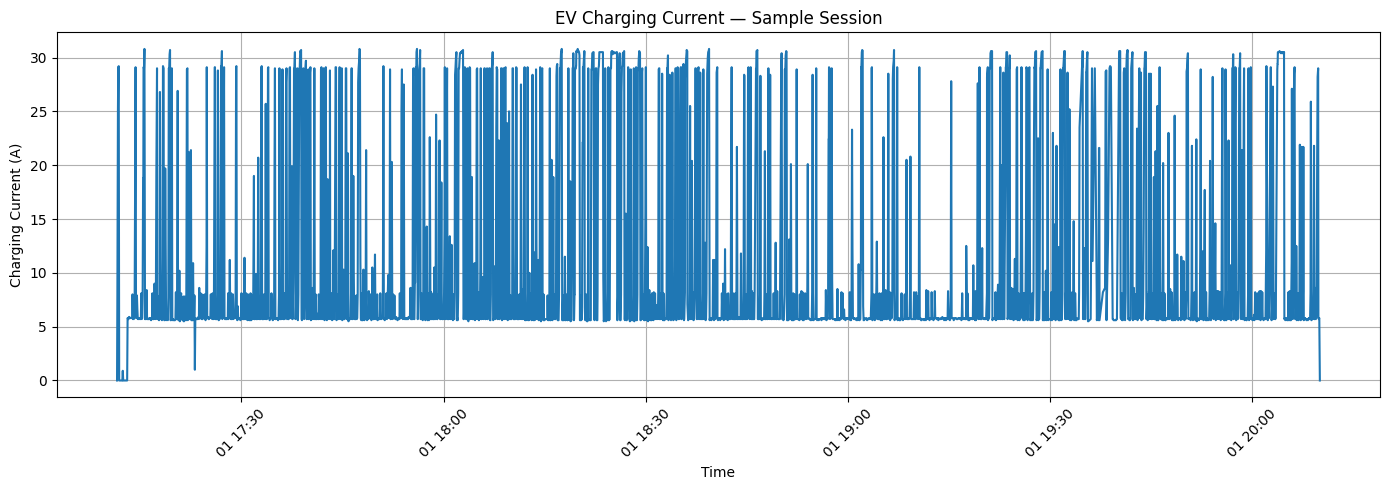

In [7]:
fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(
    df["Timestamp"],
    df["Charging Current (A)"],
    label="Charging Current"
)

ax1.set_xlabel("Time")
ax1.set_ylabel("Charging Current (A)")
ax1.grid(True)

plt.title("EV Charging Current — Sample Session")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

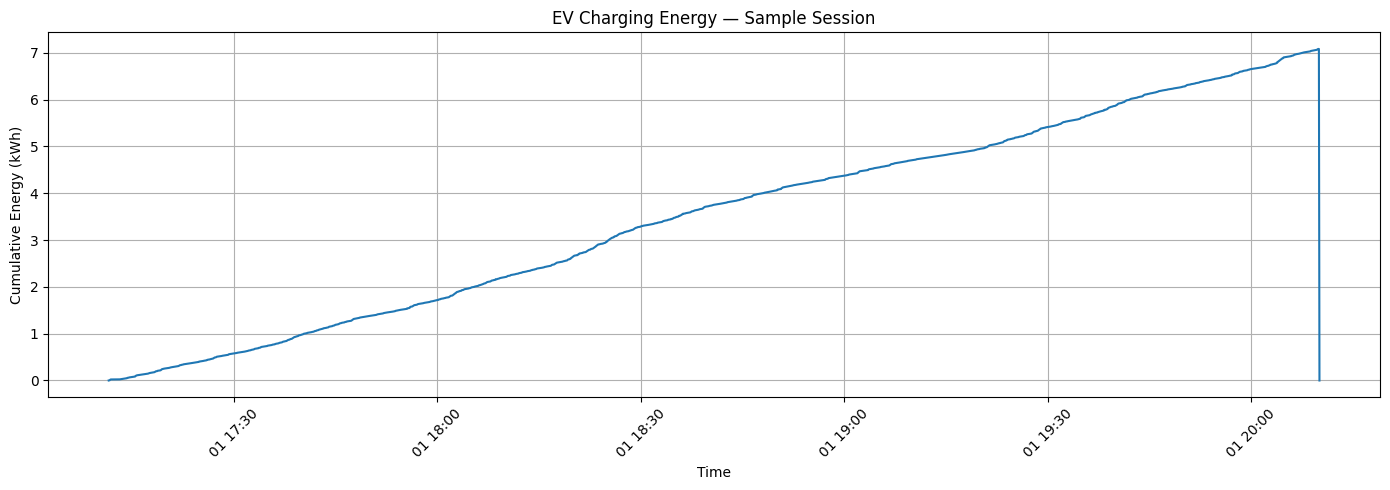

In [8]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Timestamp"],
    df["Energy Delivered (kWh)"]
)

plt.xlabel("Time")
plt.ylabel("Cumulative Energy (kWh)")
plt.title("EV Charging Energy — Sample Session")
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# Basic characteristics of this charging session

start_time = df["Timestamp"].iloc[0]
end_time = df["Timestamp"].iloc[-1]

duration_hours = (
    end_time - start_time
).total_seconds() / 3600

# Ignore the final reset to zero
valid_energy = df["Energy Delivered (kWh)"]
valid_energy = valid_energy[valid_energy > 0]

total_energy = valid_energy.max()

average_power = total_energy / duration_hours

print("SESSION CHARACTERISTICS")
print("-" * 40)

print(f"Start time       : {start_time}")
print(f"End time         : {end_time}")
print(f"Duration         : {duration_hours:.2f} hours")
print(f"Energy delivered : {total_energy:.3f} kWh")
print(f"Average power    : {average_power:.3f} kW")
print(f"Maximum current  : {df['Charging Current (A)'].max():.2f} A")
print(f"Number of samples: {len(df)}")

SESSION CHARACTERISTICS
----------------------------------------
Start time       : 2018-05-01 17:11:32+00:00
End time         : 2018-05-01 20:10:03+00:00
Duration         : 2.98 hours
Energy delivered : 7.082 kWh
Average power    : 2.380 kW
Maximum current  : 30.80 A
Number of samples: 2807


In [11]:
def process_session(file_path, location="California_Garage_01"):
    
    # Read compressed CSV
    data = pd.read_csv(file_path, compression="gzip")
    
    # Convert timestamp
    data["Timestamp"] = pd.to_datetime(
        data["Unnamed: 0"],
        utc=True
    )
    
    # Sort by time
    data = data.sort_values("Timestamp").reset_index(drop=True)
    
    # Session start and end
    arrival_time = data["Timestamp"].iloc[0]
    departure_time = data["Timestamp"].iloc[-1]
    
    # Duration in hours
    duration_hours = (
        departure_time - arrival_time
    ).total_seconds() / 3600
    
    # Energy:
    # Ignore the final reset to zero by taking the maximum
    energy_kwh = data["Energy Delivered (kWh)"].max()
    
    # Current statistics
    max_current = data["Charging Current (A)"].max()
    mean_current = data["Charging Current (A)"].mean()
    
    # Average power over connection duration
    average_power_kw = (
        energy_kwh / duration_hours
        if duration_hours > 0
        else np.nan
    )
    
    # Charging states
    states = data["Charging State"].value_counts().to_dict()
    
    # Return one clean session record
    return {
        "session_id": os.path.basename(file_path),
        "location": location,
        "arrival_time": arrival_time,
        "departure_time": departure_time,
        "duration_hours": duration_hours,
        "energy_kwh": energy_kwh,
        "max_current_a": max_current,
        "mean_current_a": mean_current,
        "average_power_kw": average_power_kw,
        "states": states
    }

In [12]:
session_result = process_session(
    sample_file,
    location="California_Garage_01"
)

session_result

{'session_id': '2-39-123-23-2018-05-01T17-11-32-081386.csv.gz',
 'location': 'California_Garage_01',
 'arrival_time': Timestamp('2018-05-01 17:11:32+0000', tz='UTC'),
 'departure_time': Timestamp('2018-05-01 20:10:03+0000', tz='UTC'),
 'duration_hours': 2.975277777777778,
 'energy_kwh': np.float64(7.08207083333),
 'max_current_a': np.float64(30.8),
 'mean_current_a': np.float64(10.876166726042038),
 'average_power_kw': np.float64(2.3803057604320794),
 'states': {'ADAPTIVE': 2785, 'NOT CHARGING': 18, 'READY': 3, 'UNPLUGGED': 1}}

In [13]:
import random

# Select 20 random session files
random.seed(42)
test_files = random.sample(files, 20)

test_results = []

for file in test_files:
    try:
        result = process_session(
            file,
            location="California_Garage_01"
        )
        test_results.append(result)
    except Exception as e:
        print("Error:", os.path.basename(file))
        print(e)

test_df = pd.DataFrame(test_results)

print("Sessions successfully processed:", len(test_df))
display(test_df)

Sessions successfully processed: 20


,session_id,location,arrival_time,departure_time,duration_hours,energy_kwh,max_current_a,mean_current_a,average_power_kw,states
0,2-39-79-379-2019-03-24T19-46-13-043226.csv.gz,California_Garage_01,2019-03-24 19:46:16+00:00,2019-03-24 22:29:57+00:00,2.728056,18.313802,31.800000,31.037713,6.713134,"{'ADAPTIVE': 2465, 'UNPLUGGED': 1}"
1,2-39-126-20-2019-01-11T16-52-56-845225.csv.gz,California_Garage_01,2019-01-11 16:53:00+00:00,2019-01-11 20:14:54+00:00,3.365000,1.799610,8.600000,2.353071,0.534802,"{'NOT CHARGING': 2078, 'ADAPTIVE': 929, 'READY..."
2,2-39-123-23-2019-09-28T03-47-07-697182.csv.gz,California_Garage_01,2019-09-28 03:47:11+00:00,2019-09-28 04:23:18+00:00,0.601944,0.841539,7.800000,6.425818,1.398034,"{'ADAPTIVE': 463, 'IDLE': 75, 'NOT CHARGING': ..."
3,2-39-83-386-2018-10-23T17-33-35-383345.csv.gz,California_Garage_01,2018-10-23 17:33:35+00:00,2018-10-24 02:53:14+00:00,9.327500,13.891134,16.300000,6.622713,1.489267,"{'NOT CHARGING': 4978, 'ADAPTIVE': 3642, 'IDLE..."
4,2-39-131-30-2019-04-24T15-47-58-117568.csv.gz,California_Garage_01,2019-04-24 15:47:58+00:00,2019-04-25 01:02:01+00:00,9.234167,4.299293,16.100000,2.113500,0.465585,"{'NOT CHARGING': 7323, 'ADAPTIVE': 1179, 'READ..."
5,2-39-130-31-2020-10-30T17-29-40-460304.csv.gz,California_Garage_01,2020-10-30 17:30:09+00:00,2020-10-31 03:01:18+00:00,9.519167,6.262346,15.900000,2.959973,0.657867,"{'NOT CHARGING': 6919, 'ADAPTIVE': 1860, 'IDLE..."
6,2-39-130-31-2018-07-14T20-10-25-513087.csv.gz,California_Garage_01,2018-07-14 20:10:29+00:00,2018-07-14 23:23:03+00:00,3.209444,5.725252,15.800000,8.174755,1.783876,"{'ADAPTIVE': 1728, 'NOT CHARGING': 1218, 'IDLE..."
7,2-39-127-19-2018-12-07T19-14-41-136235.csv.gz,California_Garage_01,2018-12-07 19:14:41+00:00,2018-12-08 02:00:55+00:00,6.770556,3.778523,16.000000,2.532478,0.558082,"{'NOT CHARGING': 5048, 'ADAPTIVE': 1176, 'IDLE..."
8,2-39-81-4550-2020-11-17T19-24-10-548602.csv.gz,California_Garage_01,2020-11-17 19:24:14.965032+00:00,2020-11-17 19:43:55.229023+00:00,0.327851,5.011000,90.100000,38.519835,15.284377,{}
9,2-39-126-20-2018-07-20T00-13-29-702407.csv.gz,California_Garage_01,2018-07-20 00:13:33+00:00,2018-07-20 00:13:45+00:00,0.003333,0.001088,1.800000,0.450000,0.326500,"{'READY': 1, 'ADAPTIVE': 1, 'NOT CHARGING': 1,..."


In [14]:
print("Missing values:")
print(test_df.isna().sum())

print("\nDuration statistics:")
print(test_df["duration_hours"].describe())

print("\nEnergy statistics:")
print(test_df["energy_kwh"].describe())

print("\nAverage power statistics:")
print(test_df["average_power_kw"].describe())

print("\nMaximum current statistics:")
print(test_df["max_current_a"].describe())

Missing values:
session_id          0
location            0
arrival_time        0
departure_time      0
duration_hours      0
energy_kwh          0
max_current_a       0
mean_current_a      0
average_power_kw    0
states              0
dtype: int64

Duration statistics:
count    20.000000
mean      5.265143
std       3.391203
min       0.003333
25%       2.796597
50%       4.609306
75%       8.673194
max       9.986667
Name: duration_hours, dtype: float64

Energy statistics:
count    20.000000
mean      5.460137
std       4.762150
min       0.001088
25%       2.426432
50%       4.038908
75%       6.602016
max      18.313802
Name: energy_kwh, dtype: float64

Average power statistics:
count    20.000000
mean      1.948168
std       3.448519
min       0.122516
25%       0.434108
50%       0.791009
75%       1.673788
max      15.284377
Name: average_power_kw, dtype: float64

Maximum current statistics:
count    20.000000
mean     17.772449
std      18.840001
min       0.000000
25%       8.

In [15]:
# Find unusually high-current sessions
high_current = test_df[
    test_df["max_current_a"] > 50
]

print("Sessions with max current > 50 A:")
display(
    high_current[
        [
            "session_id",
            "duration_hours",
            "energy_kwh",
            "max_current_a",
            "average_power_kw"
        ]
    ]
)

# Find very short sessions
short_sessions = test_df[
    test_df["duration_hours"] < 0.1
]

print("\nSessions shorter than 6 minutes:")
display(
    short_sessions[
        [
            "session_id",
            "duration_hours",
            "energy_kwh",
            "max_current_a",
            "average_power_kw"
        ]
    ]
)

Sessions with max current > 50 A:


,session_id,duration_hours,energy_kwh,max_current_a,average_power_kw
8,2-39-81-4550-2020-11-17T19-24-10-548602.csv.gz,0.327851,5.011,90.1,15.284377



Sessions shorter than 6 minutes:


,session_id,duration_hours,energy_kwh,max_current_a,average_power_kw
9,2-39-126-20-2018-07-20T00-13-29-702407.csv.gz,0.003333,0.001088,1.8,0.3265


In [16]:
# Inspect the high-current session
high_file = [
    f for f in test_files
    if os.path.basename(f) == high_current.iloc[0]["session_id"]
][0]

high_df = pd.read_csv(
    high_file,
    compression="gzip"
)

high_df["Timestamp"] = pd.to_datetime(
    high_df["Unnamed: 0"],
    utc=True
)

print("Maximum current:",
      high_df["Charging Current (A)"].max())

print("\nRows around maximum current:")
display(
    high_df.loc[
        high_df["Charging Current (A)"].idxmax()
        - 5:
        high_df["Charging Current (A)"].idxmax()
        + 5
    ]
)

Maximum current: 90.1

Rows around maximum current:


,Unnamed: 0,Charging Current (A),Actual Pilot (A),Voltage (V),Charging State,Energy Delivered (kWh),Power (kW),Timestamp
0,2020-11-17T19:24:14.965032+00:00,0.0,0.0,NaN,NaN,0.000,0.0000,2020-11-17 19:24:14.965032+00:00
1,2020-11-17T19:24:19.966731+00:00,0.0,0.0,NaN,NaN,0.000,0.0000,2020-11-17 19:24:19.966731+00:00
2,2020-11-17T19:24:24.967396+00:00,0.0,0.0,NaN,NaN,0.000,0.0000,2020-11-17 19:24:24.967396+00:00
3,2020-11-17T19:24:34.759116+00:00,0.0,125.0,NaN,NaN,0.000,0.0000,2020-11-17 19:24:34.759116+00:00
4,2020-11-17T19:24:44.756292+00:00,90.1,125.0,NaN,NaN,0.039,35.0296,2020-11-17 19:24:44.756292+00:00
5,2020-11-17T19:24:54.755783+00:00,85.9,125.0,NaN,NaN,0.135,33.5470,2020-11-17 19:24:54.755783+00:00
6,2020-11-17T19:25:04.754894+00:00,81.0,125.0,NaN,NaN,0.225,31.6653,2020-11-17 19:25:04.754894+00:00
7,2020-11-17T19:25:14.774027+00:00,77.1,125.0,NaN,NaN,0.311,30.1694,2020-11-17 19:25:14.774027+00:00
8,2020-11-17T19:25:24.774266+00:00,74.1,125.0,NaN,NaN,0.393,29.0044,2020-11-17 19:25:24.774266+00:00
9,2020-11-17T19:25:34.773827+00:00,72.2,125.0,NaN,NaN,0.473,28.3237,2020-11-17 19:25:34.773827+00:00


In [17]:
random.seed(123)

test_files_100 = random.sample(files, 100)

results_100 = []

for file in test_files_100:
    try:
        result = process_session(
            file,
            location="California_Garage_01"
        )
        results_100.append(result)
    except Exception as e:
        print("Error:", os.path.basename(file))
        print(e)

test_100_df = pd.DataFrame(results_100)

print("Successfully processed:",
      len(test_100_df))

print("\nMaximum current:")
print(test_100_df["max_current_a"].max())

print("\nMaximum energy:")
print(test_100_df["energy_kwh"].max())

print("\nMaximum duration:")
print(test_100_df["duration_hours"].max())

print("\nMinimum duration:")
print(test_100_df["duration_hours"].min())

Successfully processed: 100

Maximum current:
124.1

Maximum energy:
43.2661708333

Maximum duration:
33.73

Minimum duration:
0.0002777777777777778


In [19]:
# Highest-current sessions
print("TOP 10 MAXIMUM CURRENT SESSIONS")

display(
    test_100_df.nlargest(10, "max_current_a")[
        [
            "session_id",
            "duration_hours",
            "energy_kwh",
            "max_current_a",
            "mean_current_a",
            "average_power_kw"
        ]
    ]
)


# Longest sessions
print("\nTOP 10 LONGEST SESSIONS")

display(
    test_100_df.nlargest(10, "duration_hours")[
        [
            "session_id",
            "duration_hours",
            "energy_kwh",
            "max_current_a",
            "average_power_kw"
        ]
    ]
)


# Shortest sessions
print("\n10 SHORTEST SESSIONS")

display(
    test_100_df.nsmallest(10, "duration_hours")[
        [
            "session_id",
            "duration_hours",
            "energy_kwh",
            "max_current_a",
            "average_power_kw"
        ]
    ]
)

TOP 10 MAXIMUM CURRENT SESSIONS


,session_id,duration_hours,energy_kwh,max_current_a,mean_current_a,average_power_kw
37,2-39-81-4550-2020-10-16T02-15-30-734656.csv.gz,0.852887,12.418000,124.100000,37.816774,14.559955
88,2-39-78-365-2018-05-18T01-39-17-894982.csv.gz,0.857222,5.792462,32.991202,32.424058,6.757247
68,2-39-78-366-2019-03-11T15-08-27-736360.csv.gz,8.915556,33.272946,32.746823,18.282172,3.732010
38,2-39-78-363-2018-07-05T21-42-58-263206.csv.gz,2.607500,5.670855,32.649071,11.297528,2.174825
89,2-39-78-366-2018-10-06T23-47-14-368845.csv.gz,1.041944,6.292994,32.551320,28.779457,6.039664
7,2-39-90-26-2019-03-29T14-58-03-335682.csv.gz,0.585556,3.955953,32.300000,31.025788,6.755898
29,2-39-88-438-2018-06-09T15-19-55-901107.csv.gz,3.288333,0.590346,32.200000,0.805822,0.179527
96,2-39-88-24-2018-08-09T15-18-48-053812.csv.gz,9.339722,18.298987,32.100000,8.855590,1.959265
45,2-39-127-19-2018-06-24T01-44-37-964932.csv.gz,3.245556,13.887348,32.000000,19.401032,4.278882
71,2-39-95-444-2018-06-17T23-17-16-385405.csv.gz,0.895278,5.713130,31.900000,28.805979,6.381405



TOP 10 LONGEST SESSIONS


,session_id,duration_hours,energy_kwh,max_current_a,average_power_kw
22,2-39-139-28-2018-06-23T15-37-55-420153.csv.gz,33.730000,6.288976,15.1,0.186451
43,2-39-79-380-2019-07-18T14-34-12-703421.csv.gz,11.632778,13.238474,16.6,1.138032
60,2-39-139-28-2018-09-12T14-01-48-162755.csv.gz,11.461944,12.457728,16.4,1.086877
98,2-39-128-562-2018-09-24T16-01-43-646712.csv.gz,11.123889,5.690101,13.8,0.511521
21,2-39-79-376-2018-05-31T04-51-23-406619.csv.gz,11.076389,14.392888,16.1,1.299421
5,2-39-131-30-2018-11-05T14-58-50-111821.csv.gz,10.749444,5.182303,15.9,0.482100
36,2-39-138-29-2019-07-01T16-09-28-799947.csv.gz,10.363056,3.627816,16.2,0.350072
99,2-39-79-383-2019-09-06T14-52-55-249010.csv.gz,10.182222,6.455730,16.2,0.634020
84,2-39-79-380-2019-06-25T15-30-32-473018.csv.gz,9.668889,1.002638,7.9,0.103697
82,2-39-79-379-2019-02-15T18-47-58-964522.csv.gz,9.515556,13.216680,28.8,1.388955



10 SHORTEST SESSIONS


,session_id,duration_hours,energy_kwh,max_current_a,average_power_kw
13,2-39-79-376-2018-07-09T17-01-38-853695.csv.gz,0.000278,0.000014,0.000000,0.049000
41,2-39-124-22-2018-08-21T05-36-49-200799.csv.gz,0.001111,0.000001,0.000000,0.001000
28,2-39-78-362-2018-12-06T06-39-43-363978.csv.gz,0.001667,NaN,1.075269,NaN
54,2-39-131-30-2018-10-23T04-06-46-507125.csv.gz,0.002222,0.000002,0.300000,0.001000
74,2-39-78-360-2019-03-28T20-36-46-098050.csv.gz,0.003611,NaN,0.782014,NaN
11,2-39-139-567-2018-05-10T16-11-27-193307.csv.gz,0.004444,0.000069,1.000000,0.015563
95,2-39-90-440-2018-05-16T15-55-07-775090.csv.gz,0.008611,0.000248,0.500000,0.028774
24,2-39-130-564-2018-05-04T18-19-21-367617.csv.gz,0.010833,0.000314,1.300000,0.028949
4,2-39-78-360-2020-08-31T00-09-09-731532.csv.gz,0.020833,0.031131,8.455523,1.494293
53,2-39-78-364-2018-11-15T19-27-30-501595.csv.gz,0.028889,0.016034,13.636364,0.555034


In [20]:
# -------------------------------------------------------
# Inspect selected extreme sessions
# -------------------------------------------------------

extreme_ids = [
    "2-39-81-4550-2020-10-16T02-15-30-734656.csv.gz",
    "2-39-139-28-2018-06-23T15-37-55-420153.csv.gz",
    "2-39-79-376-2018-07-09T17-01-38-853695.csv.gz"
]

for filename in extreme_ids:

    file_path = os.path.join(data_path, filename)

    df = pd.read_csv(file_path, compression="gzip")

    df["Timestamp"] = pd.to_datetime(
        df["Unnamed: 0"],
        utc=True
    )

    print("\n" + "="*70)
    print(filename)
    print("="*70)

    print("Number of samples:", len(df))
    print("Start:", df["Timestamp"].iloc[0])
    print("End:", df["Timestamp"].iloc[-1])

    print("\nCurrent statistics:")
    print(df["Charging Current (A)"].describe())

    print("\nEnergy statistics:")
    print(df["Energy Delivered (kWh)"].describe())

    print("\nCharging states:")
    print(df["Charging State"].value_counts())

    print("\nLast 10 rows:")
    display(
        df[
            [
                "Timestamp",
                "Charging Current (A)",
                "Energy Delivered (kWh)",
                "Charging State"
            ]
        ].tail(10)
    )


2-39-81-4550-2020-10-16T02-15-30-734656.csv.gz
Number of samples: 310
Start: 2020-10-16 02:15:34.657694+00:00
End: 2020-10-16 03:06:45.051799+00:00

Current statistics:
count    310.000000
mean      37.816774
std       35.427236
min        0.000000
25%        8.050000
50%       20.900000
75%       67.675000
max      124.100000
Name: Charging Current (A), dtype: float64

Energy statistics:
count    310.000000
mean       9.071219
std        3.670184
min        0.000000
25%        7.017750
50%       10.742000
75%       11.923750
max       12.418000
Name: Energy Delivered (kWh), dtype: float64

Charging states:
Series([], Name: count, dtype: int64)

Last 10 rows:


,Timestamp,Charging Current (A),Energy Delivered (kWh),Charging State
300,2020-10-16 03:05:28.810449+00:00,4.1,12.391,NaN
301,2020-10-16 03:05:38.869537+00:00,4.0,12.396,NaN
302,2020-10-16 03:05:48.890660+00:00,4.0,12.400,NaN
303,2020-10-16 03:05:58.825805+00:00,4.2,12.404,NaN
304,2020-10-16 03:06:08.885747+00:00,4.0,12.409,NaN
305,2020-10-16 03:06:18.889994+00:00,4.0,12.413,NaN
306,2020-10-16 03:06:28.874146+00:00,3.8,12.417,NaN
307,2020-10-16 03:06:32.151236+00:00,4.0,12.418,NaN
308,2020-10-16 03:06:40.052849+00:00,0.0,0.000,NaN
309,2020-10-16 03:06:45.051799+00:00,0.0,0.000,NaN



2-39-139-28-2018-06-23T15-37-55-420153.csv.gz
Number of samples: 31289
Start: 2018-06-23 15:37:55+00:00
End: 2018-06-25 01:21:43+00:00

Current statistics:
count    31289.000000
mean         0.854623
std          3.264419
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         15.100000
Name: Charging Current (A), dtype: float64

Energy statistics:
count    31289.000000
mean         6.079345
std          0.911773
min          0.000000
25%          6.288976
50%          6.288976
75%          6.288976
max          6.288976
Name: Energy Delivered (kWh), dtype: float64

Charging states:
Charging State
NOT CHARGING    29196
ADAPTIVE         2090
READY               2
UNPLUGGED           1
Name: count, dtype: int64

Last 10 rows:


,Timestamp,Charging Current (A),Energy Delivered (kWh),Charging State
31279,2018-06-25 01:21:08+00:00,0.0,6.288976,NOT CHARGING
31280,2018-06-25 01:21:11+00:00,0.0,6.288976,NOT CHARGING
31281,2018-06-25 01:21:15+00:00,0.0,6.288976,NOT CHARGING
31282,2018-06-25 01:21:19+00:00,0.0,6.288976,NOT CHARGING
31283,2018-06-25 01:21:23+00:00,0.0,6.288976,NOT CHARGING
31284,2018-06-25 01:21:27+00:00,0.0,6.288976,NOT CHARGING
31285,2018-06-25 01:21:31+00:00,0.0,6.288976,NOT CHARGING
31286,2018-06-25 01:21:35+00:00,0.0,6.288976,NOT CHARGING
31287,2018-06-25 01:21:40+00:00,0.0,6.288976,READY
31288,2018-06-25 01:21:43+00:00,0.0,0.000000,UNPLUGGED



2-39-79-376-2018-07-09T17-01-38-853695.csv.gz
Number of samples: 2
Start: 2018-07-09 17:01:57+00:00
End: 2018-07-09 17:01:58+00:00

Current statistics:
count    2.0
mean     0.0
std      0.0
min      0.0
25%      0.0
50%      0.0
75%      0.0
max      0.0
Name: Charging Current (A), dtype: float64

Energy statistics:
count    2.000000
mean     0.000007
std      0.000010
min      0.000000
25%      0.000003
50%      0.000007
75%      0.000010
max      0.000014
Name: Energy Delivered (kWh), dtype: float64

Charging states:
Charging State
NOT CHARGING    1
UNPLUGGED       1
Name: count, dtype: int64

Last 10 rows:


,Timestamp,Charging Current (A),Energy Delivered (kWh),Charging State
0,2018-07-09 17:01:57+00:00,0.0,0.000014,NOT CHARGING
1,2018-07-09 17:01:58+00:00,0.0,0.000000,UNPLUGGED


In [21]:
filename = "2-39-81-4550-2020-10-16T02-15-30-734656.csv.gz"

file_path = os.path.join(data_path, filename)

df = pd.read_csv(file_path, compression="gzip")

df["Timestamp"] = pd.to_datetime(
    df["Unnamed: 0"],
    utc=True
)

# Show samples around the maximum current
max_idx = df["Charging Current (A)"].idxmax()

print("Maximum current:", df.loc[max_idx, "Charging Current (A)"])
print("Maximum current index:", max_idx)

print("\nSamples around maximum current:")

display(
    df.loc[
        max(0, max_idx - 15):min(len(df), max_idx + 16),
        [
            "Timestamp",
            "Charging Current (A)",
            "Energy Delivered (kWh)",
            "Actual Pilot (A)",
            "Voltage (V)",
            "Power (kW)",
            "Charging State"
        ]
    ]
)

Maximum current: 124.1
Maximum current index: 8

Samples around maximum current:


,Timestamp,Charging Current (A),Energy Delivered (kWh),Actual Pilot (A),Voltage (V),Power (kW),Charging State
0,2020-10-16 02:15:34.657694+00:00,0.0,0.000,0.0,NaN,0.0000,NaN
1,2020-10-16 02:15:39.659723+00:00,0.0,0.000,0.0,NaN,0.0000,NaN
2,2020-10-16 02:15:49.509603+00:00,0.0,0.000,125.0,NaN,0.0000,NaN
3,2020-10-16 02:15:59.459803+00:00,4.5,0.001,125.0,NaN,1.6093,NaN
4,2020-10-16 02:16:09.451791+00:00,33.0,0.015,125.0,NaN,11.8609,NaN
5,2020-10-16 02:16:19.492201+00:00,70.1,0.067,125.0,NaN,25.5276,NaN
6,2020-10-16 02:16:29.469158+00:00,107.8,0.157,125.0,NaN,39.6860,NaN
7,2020-10-16 02:16:39.457563+00:00,123.1,0.279,125.0,NaN,45.6912,NaN
8,2020-10-16 02:16:49.486831+00:00,124.1,0.406,125.0,NaN,46.2583,NaN
9,2020-10-16 02:16:59.456719+00:00,120.1,0.531,125.0,NaN,44.8864,NaN


In [22]:
def analyze_session_activity(file_path):

    df = pd.read_csv(file_path, compression="gzip")

    df["Timestamp"] = pd.to_datetime(
        df["Unnamed: 0"],
        utc=True
    )

    df = df.sort_values("Timestamp").reset_index(drop=True)

    # Time difference between consecutive measurements
    df["dt_hours"] = (
        df["Timestamp"].diff().dt.total_seconds() / 3600
    )

    # Charging current
    current = df["Charging Current (A)"].fillna(0)

    # Consider current > 0 as electrical charging activity
    charging_mask = current > 0

    # Duration represented by intervals where current > 0
    charging_duration_hours = (
        df.loc[charging_mask, "dt_hours"]
        .fillna(0)
        .sum()
    )

    total_duration_hours = (
        df["Timestamp"].iloc[-1]
        - df["Timestamp"].iloc[0]
    ).total_seconds() / 3600

    charging_percentage = (
        charging_duration_hours / total_duration_hours * 100
        if total_duration_hours > 0
        else 0
    )

    return {
        "total_duration_hours": total_duration_hours,
        "charging_duration_hours": charging_duration_hours,
        "charging_percentage": charging_percentage,
        "energy_kwh": df["Energy Delivered (kWh)"].max(),
        "max_current_a": current.max(),
        "mean_current_a": current.mean(),
        "charging_samples": charging_mask.sum(),
        "total_samples": len(df)
    }


# Test the three sessions
for filename in extreme_ids:

    result = analyze_session_activity(
        os.path.join(data_path, filename)
    )

    print("\n" + "="*60)
    print(filename)
    print("="*60)

    for key, value in result.items():
        print(f"{key}: {value}")


2-39-81-4550-2020-10-16T02-15-30-734656.csv.gz
total_duration_hours: 0.8528872513888889
charging_duration_hours: 0.8451782313888889
charging_percentage: 99.09612671693168
energy_kwh: 12.418
max_current_a: 124.1
mean_current_a: 37.81677419354838
charging_samples: 305
total_samples: 310

2-39-139-28-2018-06-23T15-37-55-420153.csv.gz
total_duration_hours: 33.73
charging_duration_hours: 2.2238888888888892
charging_percentage: 6.5932074974470485
energy_kwh: 6.288975833329999
max_current_a: 15.1
mean_current_a: 0.8546230304579885
charging_samples: 2091
total_samples: 31289

2-39-79-376-2018-07-09T17-01-38-853695.csv.gz
total_duration_hours: 0.0002777777777777778
charging_duration_hours: 0.0
charging_percentage: 0.0
energy_kwh: 1.3611111111099998e-05
max_current_a: 0.0
mean_current_a: 0.0
charging_samples: 0
total_samples: 2


In [23]:
activity_results = []

for file_path in test_100_df["session_id"]:

    result = analyze_session_activity(
        os.path.join(data_path, file_path)
    )

    result["session_id"] = file_path

    activity_results.append(result)


activity_100_df = pd.DataFrame(activity_results)

print("Successfully analyzed:", len(activity_100_df))

print("\nCharging activity statistics:")
display(
    activity_100_df[
        [
            "total_duration_hours",
            "charging_duration_hours",
            "charging_percentage",
            "energy_kwh",
            "max_current_a"
        ]
    ].describe()
)

Successfully analyzed: 100

Charging activity statistics:


,total_duration_hours,charging_duration_hours,charging_percentage,energy_kwh,max_current_a
count,100.000000,100.000000,100.000000,98.000000,100.000000
mean,4.537048,2.170571,63.727948,7.105333,19.639516
std,4.649902,2.156308,35.167455,7.547231,14.789945
min,0.000278,0.000000,0.000000,0.000001,0.000000
25%,0.991042,0.543403,33.394197,1.308711,10.475000
50%,3.310833,1.358472,70.361519,5.091394,16.200000
75%,8.091250,3.070972,99.823071,12.193808,30.725000
max,33.730000,9.127222,100.000000,43.266171,124.100000


In [24]:
print("\nLowest charging activity sessions:")

display(
    activity_100_df.nsmallest(
        10,
        "charging_percentage"
    )[
        [
            "session_id",
            "total_duration_hours",
            "charging_duration_hours",
            "charging_percentage",
            "energy_kwh",
            "max_current_a"
        ]
    ]
)


Lowest charging activity sessions:


,session_id,total_duration_hours,charging_duration_hours,charging_percentage,energy_kwh,max_current_a
13,2-39-79-376-2018-07-09T17-01-38-853695.csv.gz,0.000278,0.000000,0.000000,0.000014,0.0
41,2-39-124-22-2018-08-21T05-36-49-200799.csv.gz,0.001111,0.000000,0.000000,0.000001,0.0
29,2-39-88-438-2018-06-09T15-19-55-901107.csv.gz,3.288333,0.095278,2.897449,0.590346,32.2
84,2-39-79-380-2019-06-25T15-30-32-473018.csv.gz,9.668889,0.464722,4.806366,1.002638,7.9
22,2-39-139-28-2018-06-23T15-37-55-420153.csv.gz,33.730000,2.223889,6.593207,6.288976,15.1
48,2-39-123-23-2019-06-10T16-14-17-351393.csv.gz,6.469167,0.517500,7.999485,0.880551,8.0
23,2-39-79-382-2019-01-03T15-59-29-262880.csv.gz,8.231667,0.700278,8.507120,1.150815,8.0
58,2-39-88-24-2019-10-24T16-48-44-313771.csv.gz,5.647222,0.502222,8.893261,0.865418,8.7
85,2-39-79-377-2019-06-21T15-59-09-898102.csv.gz,8.361944,0.787222,9.414344,1.921345,13.6
36,2-39-138-29-2019-07-01T16-09-28-799947.csv.gz,10.363056,1.122222,10.829067,3.627816,16.2


In [25]:
print("\nHighest charging activity sessions:")

display(
    activity_100_df.nlargest(
        10,
        "charging_percentage"
    )[
        [
            "session_id",
            "total_duration_hours",
            "charging_duration_hours",
            "charging_percentage",
            "energy_kwh",
            "max_current_a"
        ]
    ]
)


Highest charging activity sessions:


,session_id,total_duration_hours,charging_duration_hours,charging_percentage,energy_kwh,max_current_a
81,2-39-78-366-2020-09-07T04-49-11-577963.csv.gz,1.006944,1.006944,100.000000,0.934342,8.944282
93,2-39-78-365-2020-09-02T15-40-24-487776.csv.gz,5.884167,5.884167,100.000000,5.560377,18.181818
78,2-39-78-366-2018-05-25T20-35-43-085455.csv.gz,2.680833,2.680833,100.000000,4.458437,16.080156
15,2-39-139-28-2018-08-23T01-49-16-401611.csv.gz,1.541389,1.541389,100.000000,10.096249,31.600000
79,2-39-78-362-2018-10-17T15-36-02-854194.csv.gz,8.059722,8.059444,99.996554,4.120705,17.302053
55,2-39-78-364-2018-06-18T15-43-52-889359.csv.gz,7.901389,7.901111,99.996484,13.613215,29.472141
68,2-39-78-366-2019-03-11T15-08-27-736360.csv.gz,8.915556,8.915000,99.993769,33.272946,32.746823
51,2-39-78-362-2018-07-16T15-15-37-034081.csv.gz,9.128056,9.127222,99.990871,3.019705,17.204301
63,2-39-78-364-2019-10-29T16-27-34-000124.csv.gz,8.681389,8.680278,99.987201,8.116439,17.155425
91,2-39-78-361-2019-03-18T19-17-02-071670.csv.gz,5.006111,5.005278,99.983354,1.119559,1.417400


In [26]:
def process_session_v2(file_path, location="California_Garage_01"):

    df = pd.read_csv(
        file_path,
        compression="gzip"
    )

    # Timestamp
    df["Timestamp"] = pd.to_datetime(
        df["Unnamed: 0"],
        utc=True
    )

    df = (
        df.sort_values("Timestamp")
          .reset_index(drop=True)
    )

    # --------------------------------------------------
    # Basic time information
    # --------------------------------------------------

    arrival_time = df["Timestamp"].iloc[0]
    departure_time = df["Timestamp"].iloc[-1]

    connection_duration_h = (
        departure_time - arrival_time
    ).total_seconds() / 3600

    # --------------------------------------------------
    # Current
    # --------------------------------------------------

    current = pd.to_numeric(
        df["Charging Current (A)"],
        errors="coerce"
    )

    current_filled = current.fillna(0)

    charging_mask = current_filled > 0

    # --------------------------------------------------
    # Time intervals
    # --------------------------------------------------

    df["dt_hours"] = (
        df["Timestamp"].diff()
        .dt.total_seconds() / 3600
    )

    charging_duration_h = (
        df.loc[
            charging_mask,
            "dt_hours"
        ]
        .fillna(0)
        .sum()
    )

    charging_activity_pct = (
        charging_duration_h /
        connection_duration_h * 100
        if connection_duration_h > 0
        else 0
    )

    # --------------------------------------------------
    # Energy
    # --------------------------------------------------

    energy = pd.to_numeric(
        df["Energy Delivered (kWh)"],
        errors="coerce"
    )

    energy_kwh = energy.max()

    # --------------------------------------------------
    # Data-quality flag
    # --------------------------------------------------

    if (
        connection_duration_h <= 0
        or
        (
            charging_duration_h == 0
            and
            (energy_kwh is None or
             pd.isna(energy_kwh) or
             energy_kwh < 0.001)
        )
    ):
        quality_flag = "INSUFFICIENT_CHARGING"

    elif pd.isna(energy_kwh):
        quality_flag = "MISSING_ENERGY"

    else:
        quality_flag = "VALID"

    # --------------------------------------------------
    # Return session record
    # --------------------------------------------------

    return {
        "session_id": os.path.basename(file_path),
        "location": location,

        "arrival_time": arrival_time,
        "departure_time": departure_time,

        "connection_duration_h":
            connection_duration_h,

        "charging_duration_h":
            charging_duration_h,

        "charging_activity_pct":
            charging_activity_pct,

        "energy_kwh":
            energy_kwh,

        "max_current_a":
            current_filled.max(),

        "mean_current_a":
            current_filled.mean(),

        "charging_samples":
            charging_mask.sum(),

        "total_samples":
            len(df),

        "quality_flag":
            quality_flag
    }

In [27]:
session_results = []

for filename in test_100_df["session_id"]:

    result = process_session_v2(
        os.path.join(data_path, filename)
    )

    session_results.append(result)


session_100_df = pd.DataFrame(
    session_results
)

print(
    "Successfully processed:",
    len(session_100_df)
)

display(
    session_100_df.head()
)

Successfully processed: 100


,session_id,location,arrival_time,departure_time,connection_duration_h,charging_duration_h,charging_activity_pct,energy_kwh,max_current_a,mean_current_a,charging_samples,total_samples,quality_flag
0,2-39-124-22-2019-03-29T00-17-34-437344.csv.gz,California_Garage_01,2019-03-29 00:17:34+00:00,2019-03-29 01:14:10+00:00,0.943333,0.508889,53.945819,0.844572,7.700000,4.029249,465,865,VALID
1,2-39-131-30-2018-12-01T22-11-41-985930.csv.gz,California_Garage_01,2018-12-01 22:11:42+00:00,2018-12-02 03:00:33+00:00,4.814167,4.558056,94.680053,15.797841,16.500000,14.618535,4117,4354,VALID
2,2-39-125-21-2019-05-20T15-28-33-948259.csv.gz,California_Garage_01,2019-05-20 15:28:37+00:00,2019-05-20 17:33:05+00:00,2.074444,1.350833,65.117836,7.885674,31.000000,17.424367,1235,1896,VALID
3,2-39-88-24-2019-11-01T16-57-41-396332.csv.gz,California_Garage_01,2019-11-01 16:57:55+00:00,2019-11-02 00:20:59+00:00,7.384444,2.115833,28.652573,13.515752,31.500000,8.281936,1939,6776,VALID
4,2-39-78-360-2020-08-31T00-09-09-731532.csv.gz,California_Garage_01,2020-08-31 00:09:12+00:00,2020-08-31 00:10:27+00:00,0.020833,0.020556,98.666667,0.031131,8.455523,6.938844,31,32,VALID


In [28]:
print("\nQuality flag distribution:")

print(
    session_100_df["quality_flag"]
    .value_counts()
)


Quality flag distribution:
quality_flag
VALID                    96
INSUFFICIENT_CHARGING     2
MISSING_ENERGY            2
Name: count, dtype: int64


In [29]:
print("\nSession statistics:")

display(
    session_100_df[
        [
            "connection_duration_h",
            "charging_duration_h",
            "charging_activity_pct",
            "energy_kwh",
            "max_current_a",
            "mean_current_a"
        ]
    ].describe()
)


Session statistics:


,connection_duration_h,charging_duration_h,charging_activity_pct,energy_kwh,max_current_a,mean_current_a
count,100.000000,100.000000,100.000000,98.000000,100.000000,100.000000
mean,4.537048,2.170571,63.727948,7.105333,19.639516,9.967648
std,4.649902,2.156308,35.167455,7.547231,14.789945,9.555779
min,0.000278,0.000000,0.000000,0.000001,0.000000,0.000000
25%,0.991042,0.543403,33.394197,1.308711,10.475000,2.448391
50%,3.310833,1.358472,70.361519,5.091394,16.200000,6.861083
75%,8.091250,3.070972,99.823071,12.193808,30.725000,15.162717
max,33.730000,9.127222,100.000000,43.266171,124.100000,37.816774


In [30]:
print("Missing values in session-level dataframe:")
display(
    session_100_df.isna().sum()
)

Missing values in session-level dataframe:


session_id               0
location                 0
arrival_time             0
departure_time           0
connection_duration_h    0
charging_duration_h      0
charging_activity_pct    0
energy_kwh               2
max_current_a            0
mean_current_a           0
charging_samples         0
total_samples            0
quality_flag             0
dtype: int64

In [31]:
missing_energy_sessions = session_100_df[
    session_100_df["energy_kwh"].isna()
]

display(
    missing_energy_sessions[
        [
            "session_id",
            "connection_duration_h",
            "charging_duration_h",
            "charging_activity_pct",
            "max_current_a",
            "mean_current_a",
            "charging_samples",
            "total_samples",
            "quality_flag"
        ]
    ]
)

,session_id,connection_duration_h,charging_duration_h,charging_activity_pct,max_current_a,mean_current_a,charging_samples,total_samples,quality_flag
28,2-39-78-362-2018-12-06T06-39-43-363978.csv.gz,0.001667,0.001389,83.333333,1.075269,0.537634,2,4,MISSING_ENERGY
74,2-39-78-360-2019-03-28T20-36-46-098050.csv.gz,0.003611,0.002778,76.923077,0.782014,0.684262,7,8,MISSING_ENERGY


In [34]:
# Re-process the 100 sessions using process_session_v2()

session_results = []

for filename in test_100_df["session_id"]:

    result = process_session_v2(
        os.path.join(data_path, filename)
    )

    session_results.append(result)

session_100_df = pd.DataFrame(session_results)

print("Successfully processed:", len(session_100_df))

Successfully processed: 100


In [35]:
print("QUALITY FLAG SUMMARY")
print("=" * 40)

print(
    session_100_df["quality_flag"].value_counts()
)

print("\nPercentages:")

print(
    session_100_df["quality_flag"]
    .value_counts(normalize=True) * 100
)

QUALITY FLAG SUMMARY
quality_flag
VALID                    96
INSUFFICIENT_CHARGING     2
MISSING_ENERGY            2
Name: count, dtype: int64

Percentages:
quality_flag
VALID                    96.0
INSUFFICIENT_CHARGING     2.0
MISSING_ENERGY            2.0
Name: proportion, dtype: float64


In [36]:
print("\nENERGY AVAILABILITY")
print("=" * 40)

print("Total sessions:", len(session_100_df))

print(
    "Usable energy sessions:",
    session_100_df["energy_kwh"].notna().sum()
)

print(
    "Missing energy:",
    session_100_df["energy_kwh"].isna().sum()
)


ENERGY AVAILABILITY
Total sessions: 100
Usable energy sessions: 98
Missing energy: 2


In [38]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
from tqdm.notebook import tqdm

In [40]:
import os
import glob
import pandas as pd
import numpy as np
from tqdm.notebook import tqdm

all_files = glob.glob(
    os.path.join(data_path, "*.csv.gz")
)

print("Total session files:", len(all_files))

Total session files: 31860


In [ ]:
all_session_results = []

for file_path in tqdm(
    all_files,
    desc="Processing EV sessions"
):
    try:
        result = process_session_v2(
            file_path,
            location="California_Garage_01"
        )
        all_session_results.append(result)

    except Exception as e:
        print("\nError processing:", os.path.basename(file_path))
        print("Error:", e)

caltech_garage01_sessions = pd.DataFrame(all_session_results)

print("\nProcessing complete!")
print("Successfully processed:", len(caltech_garage01_sessions))

In [42]:
output_file = r"C:\EV_Charging_Project\caltech_garage01_sessions.csv"

caltech_garage01_sessions.to_csv(
    output_file,
    index=False
)

print("Saved successfully!")
print(output_file)

Saved successfully!
C:\EV_Charging_Project\caltech_garage01_sessions.csv


In [ ]:
import os

print("File exists:", os.path.exists(output_file))
print(
    "File size:",
    round(os.path.getsize(output_file) / (1024**2), 2),
    "MB"
)

In [1]:
import os
import pandas as pd

output_file = r"C:\EV_Charging_Project\caltech_garage01_sessions.csv"

print("Checking saved processed data...")
print("File exists:", os.path.exists(output_file))

if os.path.exists(output_file):
    print(
        "File size:",
        round(os.path.getsize(output_file) / (1024**2), 2),
        "MB"
    )

Checking saved processed data...
File exists: True
File size: 6.88 MB


In [2]:
caltech_garage01_sessions = pd.read_csv(output_file)

print("Rows:", len(caltech_garage01_sessions))
print("Columns:", len(caltech_garage01_sessions.columns))

Rows: 31852
Columns: 13


In [3]:
print(caltech_garage01_sessions.columns.tolist())

['session_id', 'location', 'arrival_time', 'departure_time', 'connection_duration_h', 'charging_duration_h', 'charging_activity_pct', 'energy_kwh', 'max_current_a', 'mean_current_a', 'charging_samples', 'total_samples', 'quality_flag']


In [4]:
print("QUALITY SUMMARY")
print("=" * 50)

print(
    caltech_garage01_sessions["quality_flag"]
    .value_counts(dropna=False)
)

QUALITY SUMMARY
quality_flag
VALID                    30373
INSUFFICIENT_CHARGING      860
MISSING_ENERGY             619
Name: count, dtype: int64


In [5]:
print("MISSING VALUES")
print("=" * 50)

print(
    caltech_garage01_sessions
    .isna()
    .sum()
)

MISSING VALUES
session_id                  0
location                    0
arrival_time                0
departure_time              0
connection_duration_h       0
charging_duration_h         0
charging_activity_pct       0
energy_kwh               1369
max_current_a               0
mean_current_a              0
charging_samples            0
total_samples               0
quality_flag                0
dtype: int64


In [6]:
print("DATE RANGE")
print("=" * 50)

print(
    "First session:",
    caltech_garage01_sessions["arrival_time"].min()
)

print(
    "Last session:",
    caltech_garage01_sessions["arrival_time"].max()
)

DATE RANGE
First session: 2018-05-01 00:31:59+00:00
Last session: 2020-12-02 23:56:11.144891+00:00


In [7]:
print("SESSION STATISTICS")
print("=" * 60)

print(
    caltech_garage01_sessions[
        [
            "connection_duration_h",
            "charging_duration_h",
            "charging_activity_pct",
            "energy_kwh",
            "max_current_a",
            "mean_current_a",
            "charging_samples",
            "total_samples"
        ]
    ].describe().T
)

SESSION STATISTICS
                         count         mean          std           min  \
connection_duration_h  31852.0     5.247283     6.323029  0.000000e+00   
charging_duration_h    31852.0     2.580664     2.803239  0.000000e+00   
charging_activity_pct  31852.0    63.672553    35.625462  0.000000e+00   
energy_kwh             30483.0     8.184300     8.180709  2.777778e-07   
max_current_a          31852.0    20.656118    12.304261  0.000000e+00   
mean_current_a         31852.0    10.068200     9.726535  0.000000e+00   
charging_samples       31852.0  2689.565522  3387.648499  0.000000e+00   
total_samples          31852.0  5149.380290  6175.370058  1.000000e+00   

                               25%          50%          75%            max  
connection_duration_h     1.389444     4.172083     8.313681     303.483333  
charging_duration_h       0.745278     1.830278     3.597222      76.913333  
charging_activity_pct    29.410721    71.428571    99.882048     100.000000  
en

In [8]:
print("TOP 10 LONGEST SESSIONS")
print("=" * 80)

longest = (
    caltech_garage01_sessions
    .sort_values("connection_duration_h", ascending=False)
    [
        [
            "session_id",
            "connection_duration_h",
            "charging_duration_h",
            "charging_activity_pct",
            "energy_kwh",
            "max_current_a",
            "mean_current_a",
            "quality_flag"
        ]
    ]
    .head(10)
)

longest

TOP 10 LONGEST SESSIONS


,session_id,connection_duration_h,charging_duration_h,charging_activity_pct,energy_kwh,max_current_a,mean_current_a,quality_flag
22638,2-39-79-381-2019-10-03T04-58-33-329226.csv.gz,303.483333,1.350556,0.445018,7.987079,31.5,0.103716,VALID
4544,2-39-127-19-2018-11-09T10-33-02-342605.csv.gz,245.269167,0.705556,0.287666,1.479476,8.4,0.026705,VALID
28697,2-39-91-437-2019-03-29T16-00-02-031826.csv.gz,213.665556,6.463889,3.025237,13.198241,29.0,0.296793,VALID
20071,2-39-79-378-2018-11-06T03-49-24-675787.csv.gz,158.081944,2.306389,1.458983,6.276872,15.7,0.157823,VALID
28819,2-39-91-437-2019-08-02T15-51-21-912243.csv.gz,150.215833,0.816389,0.543477,1.008619,11.9,0.045519,VALID
25728,2-39-89-25-2018-06-08T05-25-49-491465.csv.gz,141.753333,0.000000,0.000000,NaN,0.0,0.000000,INSUFFICIENT_CHARGING
557,2-39-123-23-2019-02-03T20-53-35-302183.csv.gz,140.941389,2.305556,1.635826,14.162123,31.6,0.443692,VALID
1389,2-39-124-22-2018-07-26T15-58-17-943639.csv.gz,125.810556,1.820278,1.446840,4.346615,26.7,0.160542,VALID
6332,2-39-129-17-2018-08-31T14-05-56-677502.csv.gz,120.831389,6.056667,5.012494,14.051024,16.5,0.526384,VALID
10307,2-39-138-29-2019-05-23T16-18-45-048941.csv.gz,118.904722,0.594722,0.500167,1.084592,8.5,0.040763,VALID


In [9]:
print("TOP 10 HIGHEST-CURRENT SESSIONS")
print("=" * 80)

highest_current = (
    caltech_garage01_sessions
    .sort_values("max_current_a", ascending=False)
    [
        [
            "session_id",
            "connection_duration_h",
            "charging_duration_h",
            "charging_activity_pct",
            "energy_kwh",
            "max_current_a",
            "mean_current_a",
            "quality_flag"
        ]
    ]
    .head(10)
)

highest_current

TOP 10 HIGHEST-CURRENT SESSIONS


,session_id,connection_duration_h,charging_duration_h,charging_activity_pct,energy_kwh,max_current_a,mean_current_a,quality_flag
24041,2-39-81-4550-2020-10-28T03-09-57-103416.csv.gz,0.623808,0.613895,98.410877,27.059,125.3,113.871366,VALID
24150,2-39-81-4550-2020-11-23T00-14-23-449939.csv.gz,0.618318,0.614993,99.462265,27.855,125.2,122.398667,VALID
24164,2-39-81-4550-2020-11-28T02-44-53-746650.csv.gz,0.983065,0.975040,99.183663,44.286,125.2,122.663585,VALID
24138,2-39-81-4550-2020-11-19T04-24-10-706432.csv.gz,0.715508,0.698354,97.602478,30.849,125.2,112.800000,VALID
24099,2-39-81-4550-2020-11-11T01-42-59-739411.csv.gz,0.352848,0.344101,97.521049,13.979,125.2,110.007752,VALID
24119,2-39-81-4550-2020-11-16T02-56-59-750755.csv.gz,0.879420,0.847235,96.340218,30.101,125.2,91.054573,VALID
24115,2-39-81-4550-2020-11-15T22-57-48-497860.csv.gz,0.509889,0.477872,93.720789,21.188,125.2,110.018367,VALID
24127,2-39-81-4550-2020-11-17T06-22-26-116297.csv.gz,0.980382,0.978236,99.781105,39.796,125.2,113.575493,VALID
24134,2-39-81-4550-2020-11-19T00-35-53-924922.csv.gz,0.920167,0.345759,37.575676,10.027,125.2,19.469331,VALID
24055,2-39-81-4550-2020-10-30T23-16-08-238514.csv.gz,0.548754,0.520957,94.934506,21.218,125.2,101.478000,VALID


In [10]:
high_current_count = (
    caltech_garage01_sessions["max_current_a"] >= 100
).sum()

print("Sessions with max current >= 100 A:", high_current_count)

print(
    "Percentage:",
    round(
        high_current_count /
        len(caltech_garage01_sessions) * 100,
        3
    ),
    "%"
)

Sessions with max current >= 100 A: 142
Percentage: 0.446 %


In [11]:
high_current_sessions = caltech_garage01_sessions[
    caltech_garage01_sessions["max_current_a"] >= 100
].copy()

high_current_sessions["arrival_time"] = pd.to_datetime(
    high_current_sessions["arrival_time"],
    utc=True
)

print("Number of high-current sessions:", len(high_current_sessions))

print("\nDate range:")
print("First:", high_current_sessions["arrival_time"].min())
print("Last :", high_current_sessions["arrival_time"].max())

print("\nUnique session ID prefixes:")
print(
    high_current_sessions["session_id"]
    .str.rsplit("-", n=5)
    .str[:4]
    .head(20)
)

Number of high-current sessions: 142

Date range:
First: 2020-09-09 02:32:44.015017+00:00
Last : 2020-12-02 23:56:11.144891+00:00

Unique session ID prefixes:
23919    [2-39-81-4550-2020, 09, 09T02, 32]
23921    [2-39-81-4550-2020, 09, 10T02, 46]
23922    [2-39-81-4550-2020, 09, 10T03, 36]
23923    [2-39-81-4550-2020, 09, 10T04, 29]
23927    [2-39-81-4550-2020, 09, 10T17, 58]
23928    [2-39-81-4550-2020, 09, 10T18, 21]
23932    [2-39-81-4550-2020, 09, 10T23, 50]
23934    [2-39-81-4550-2020, 09, 11T00, 58]
23935    [2-39-81-4550-2020, 09, 11T23, 07]
23937    [2-39-81-4550-2020, 09, 12T03, 37]
23938    [2-39-81-4550-2020, 09, 12T04, 47]
23939    [2-39-81-4550-2020, 09, 12T06, 30]
23943    [2-39-81-4550-2020, 09, 12T17, 28]
23944    [2-39-81-4550-2020, 09, 12T18, 06]
23945    [2-39-81-4550-2020, 09, 12T22, 26]
23946    [2-39-81-4550-2020, 09, 13T06, 49]
23947    [2-39-81-4550-2020, 09, 13T15, 29]
23948    [2-39-81-4550-2020, 09, 13T16, 21]
23951    [2-39-81-4550-2020, 09, 13T16, 32]
23952

In [1]:
high_current_energy = high_current_sessions["energy_kwh"].sum()

total_energy = (
    caltech_garage01_sessions["energy_kwh"]
    .sum()
)

print("Energy from >=100 A sessions:",
      round(high_current_energy, 2), "kWh")

print("Total recorded energy:",
      round(total_energy, 2), "kWh")

print(
    "Share of total energy:",
    round(high_current_energy / total_energy * 100, 2),
    "%"
)

NameError: name 'high_current_sessions' is not defined

In [2]:
# Recreate the high-current session table
high_current_sessions = caltech_garage01_sessions[
    caltech_garage01_sessions["max_current_a"] >= 100
].copy()

# Calculate energy
high_current_energy = high_current_sessions["energy_kwh"].sum()

total_energy = caltech_garage01_sessions["energy_kwh"].sum()

print("Number of high-current sessions:",
      len(high_current_sessions))

print("Energy from >=100 A sessions:",
      round(high_current_energy, 2), "kWh")

print("Total recorded energy:",
      round(total_energy, 2), "kWh")

print(
    "Share of total energy:",
    round(high_current_energy / total_energy * 100, 2),
    "%"
)

NameError: name 'caltech_garage01_sessions' is not defined

In [3]:
import pandas as pd

output_file = r"C:\EV_Charging_Project\caltech_garage01_sessions.csv"

caltech_garage01_sessions = pd.read_csv(output_file)

print("Dataset loaded successfully!")
print("Rows:", len(caltech_garage01_sessions))
print("Columns:", len(caltech_garage01_sessions.columns))

Dataset loaded successfully!
Rows: 31852
Columns: 13


In [4]:
high_current_sessions = caltech_garage01_sessions[
    caltech_garage01_sessions["max_current_a"] >= 100
].copy()

high_current_energy = high_current_sessions["energy_kwh"].sum()
total_energy = caltech_garage01_sessions["energy_kwh"].sum()

print("Number of high-current sessions:",
      len(high_current_sessions))

print("Energy from >=100 A sessions:",
      round(high_current_energy, 2), "kWh")

print("Total recorded energy:",
      round(total_energy, 2), "kWh")

print(
    "Share of total energy:",
    round(high_current_energy / total_energy * 100, 2),
    "%"
)

Number of high-current sessions: 142
Energy from >=100 A sessions: 2456.24 kWh
Total recorded energy: 249482.02 kWh
Share of total energy: 0.98 %


In [5]:
import os
import glob

data_path = r"C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01"

all_files = glob.glob(
    os.path.join(data_path, "*.csv.gz")
)

print("Raw session files:", len(all_files))
print("Example file:")
print(os.path.basename(all_files[0]))

Raw session files: 31860
Example file:
2-39-123-23-2018-05-01T17-11-32-081386.csv.gz


In [6]:
sample_raw = pd.read_csv(
    all_files[0],
    compression="gzip"
)

print("Shape:", sample_raw.shape)

print("\nColumns:")
print(sample_raw.columns.tolist())

print("\nFirst 5 rows:")
display(sample_raw.head())

Shape: (2807, 7)

Columns:
['Unnamed: 0', 'Charging Current (A)', 'Actual Pilot (A)', 'Voltage (V)', 'Charging State', 'Energy Delivered (kWh)', 'Power (kW)']

First 5 rows:


,Unnamed: 0,Charging Current (A),Actual Pilot (A),Voltage (V),Charging State,Energy Delivered (kWh),Power (kW)
0,2018-05-01T17:11:32+00:00,0.0,NaN,NaN,READY,0.000000,NaN
1,2018-05-01T17:11:35+00:00,8.0,NaN,NaN,ADAPTIVE,0.001474,NaN
2,2018-05-01T17:11:40+00:00,25.2,NaN,NaN,ADAPTIVE,0.004430,NaN
3,2018-05-01T17:11:43+00:00,29.1,NaN,NaN,ADAPTIVE,0.011354,NaN
4,2018-05-01T17:11:47+00:00,29.2,NaN,NaN,ADAPTIVE,0.018397,NaN


In [7]:
sample = sample_raw.copy()

sample["Timestamp"] = pd.to_datetime(
    sample["Unnamed: 0"],
    utc=True
)

sample["Energy"] = pd.to_numeric(
    sample["Energy Delivered (kWh)"],
    errors="coerce"
)

sample["Current"] = pd.to_numeric(
    sample["Charging Current (A)"],
    errors="coerce"
)

sample["dt_seconds"] = (
    sample["Timestamp"]
    .diff()
    .dt.total_seconds()
)

sample["delta_energy_kwh"] = sample["Energy"].diff()

print("Energy minimum:", sample["Energy"].min())
print("Energy maximum:", sample["Energy"].max())

print("\nNegative energy differences:",
      (sample["delta_energy_kwh"] < 0).sum())

print("\nLargest negative energy change:",
      sample["delta_energy_kwh"].min())

print("\nLast 10 rows:")

display(
    sample[
        [
            "Timestamp",
            "Current",
            "Energy",
            "delta_energy_kwh",
            "Charging State"
        ]
    ].tail(10)
)

Energy minimum: 0.0
Energy maximum: 7.08207083333

Negative energy differences: 1

Largest negative energy change: -7.08207083333

Last 10 rows:


,Timestamp,Current,Energy,delta_energy_kwh,Charging State
2797,2018-05-01 20:09:27+00:00,5.7,7.056939,0.001724,ADAPTIVE
2798,2018-05-01 20:09:31+00:00,5.8,7.058324,0.001385,ADAPTIVE
2799,2018-05-01 20:09:35+00:00,8.1,7.059842,0.001517,ADAPTIVE
2800,2018-05-01 20:09:39+00:00,20.8,7.062422,0.002581,ADAPTIVE
2801,2018-05-01 20:09:43+00:00,28.2,7.068669,0.006246,ADAPTIVE
2802,2018-05-01 20:09:48+00:00,29.0,7.075706,0.007037,ADAPTIVE
2803,2018-05-01 20:09:50+00:00,5.8,7.079298,0.003592,ADAPTIVE
2804,2018-05-01 20:09:54+00:00,5.7,7.080688,0.001391,ADAPTIVE
2805,2018-05-01 20:09:58+00:00,5.8,7.082071,0.001383,ADAPTIVE
2806,2018-05-01 20:10:03+00:00,0.0,0.000000,-7.082071,UNPLUGGED


In [8]:
def reconstruct_session_energy(file_path):
    
    df = pd.read_csv(
        file_path,
        compression="gzip"
    )

    # Timestamp
    df["Timestamp"] = pd.to_datetime(
        df["Unnamed: 0"],
        format="mixed",
        utc=True
    )

    # Numeric energy
    df["Energy"] = pd.to_numeric(
        df["Energy Delivered (kWh)"],
        errors="coerce"
    )

    # Sort chronologically
    df = df.sort_values("Timestamp").reset_index(drop=True)

    # Energy change between measurements
    df["delta_energy_kwh"] = df["Energy"].diff()

    # Keep only positive energy increments
    df["interval_energy_kwh"] = (
        df["delta_energy_kwh"]
        .where(df["delta_energy_kwh"] > 0, 0)
        .fillna(0)
    )

    return df

In [9]:
reconstructed = reconstruct_session_energy(
    all_files[0]
)

print(
    "Reconstructed energy:",
    reconstructed["interval_energy_kwh"].sum(),
    "kWh"
)

print(
    "Original maximum energy:",
    reconstructed["Energy"].max(),
    "kWh"
)

Reconstructed energy: 7.08207083333 kWh
Original maximum energy: 7.08207083333 kWh


In [10]:
import random

# Select 20 random raw sessions
test_files = random.sample(all_files, 20)

validation_results = []

for file_path in test_files:
    try:
        df = reconstruct_session_energy(file_path)

        reconstructed_energy = (
            df["interval_energy_kwh"].sum()
        )

        original_energy = df["Energy"].max()

        difference = (
            reconstructed_energy - original_energy
        )

        validation_results.append({
            "session_id": os.path.basename(file_path),
            "original_energy_kwh": original_energy,
            "reconstructed_energy_kwh": reconstructed_energy,
            "difference_kwh": difference
        })

    except Exception as e:
        print("Error:", os.path.basename(file_path))
        print(e)

validation_df = pd.DataFrame(validation_results)

print("Sessions tested:", len(validation_df))

print(
    "Maximum absolute difference:",
    validation_df["difference_kwh"].abs().max(),
    "kWh"
)

display(validation_df)

Sessions tested: 20
Maximum absolute difference: 0.06147333333335592 kWh


,session_id,original_energy_kwh,reconstructed_energy_kwh,difference_kwh
0,2-39-129-17-2018-12-23T07-08-23-301385.csv.gz,15.178490,15.178463,-2.694444e-05
1,2-39-78-366-2019-11-20T16-15-05-851264.csv.gz,9.272831,9.272831,0.000000e+00
2,2-39-78-365-2019-07-18T16-55-00-988466.csv.gz,14.846251,14.843823,-2.428587e-03
3,2-39-91-441-2020-02-20T19-17-08-455113.csv.gz,1.577962,1.577962,0.000000e+00
4,2-39-90-26-2018-05-24T20-02-11-513356.csv.gz,3.833821,3.833734,-8.750000e-05
5,2-39-81-4550-2020-10-24T19-54-34-759633.csv.gz,2.451000,2.451000,4.440892e-16
6,2-39-81-4550-2020-11-18T06-47-10-190818.csv.gz,13.172000,13.172000,0.000000e+00
7,2-39-78-367-2019-01-14T22-36-47-491997.csv.gz,0.967668,0.965296,-2.372108e-03
8,2-39-129-17-2019-06-19T01-51-59-482828.csv.gz,9.715418,9.715369,-4.944444e-05
9,2-39-138-29-2018-10-29T13-36-00-163472.csv.gz,8.041591,8.041591,0.000000e+00


In [11]:
problem_file = os.path.join(
    data_path,
    "2-39-79-379-2019-02-05T15-49-11-688133.csv.gz"
)

problem_df = pd.read_csv(
    problem_file,
    compression="gzip"
)

problem_df["Timestamp"] = pd.to_datetime(
    problem_df["Unnamed: 0"],
    format="mixed",
    utc=True
)

problem_df["Energy"] = pd.to_numeric(
    problem_df["Energy Delivered (kWh)"],
    errors="coerce"
)

problem_df["delta_energy"] = problem_df["Energy"].diff()

print("Maximum energy:",
      problem_df["Energy"].max())

print("Sum of positive changes:",
      problem_df.loc[
          problem_df["delta_energy"] > 0,
          "delta_energy"
      ].sum())

print("Number of negative changes:",
      (problem_df["delta_energy"] < 0).sum())

print("Total negative change:",
      problem_df.loc[
          problem_df["delta_energy"] < 0,
          "delta_energy"
      ].sum())

print("\nNegative energy-change rows:")

display(
    problem_df.loc[
        problem_df["delta_energy"] < 0,
        [
            "Timestamp",
            "Energy",
            "delta_energy",
            "Charging Current (A)",
            "Charging State"
        ]
    ]
)

Maximum energy: 4.47811083333
Sum of positive changes: 4.539584166663356
Number of negative changes: 2
Total negative change: -4.5396686111078

Negative energy-change rows:


,Timestamp,Energy,delta_energy,Charging Current (A),Charging State
4422,2019-02-05 20:39:09+00:00,0.0,-4.478111,0.0,NOT CHARGING
7885,2019-02-06 00:43:04+00:00,0.0,-0.061558,0.0,UNPLUGGED


In [12]:
reset_rows = problem_df[
    problem_df["delta_energy"] < 0
].index

for idx in reset_rows:
    
    print("\n" + "=" * 80)
    print("RESET AT INDEX:", idx)
    print("=" * 80)
    
    display(
        problem_df.loc[
            max(0, idx - 5):min(len(problem_df) - 1, idx + 5),
            [
                "Timestamp",
                "Energy",
                "delta_energy",
                "Charging Current (A)",
                "Charging State"
            ]
        ]
    )


RESET AT INDEX: 4422


,Timestamp,Energy,delta_energy,Charging Current (A),Charging State
4417,2019-02-05 20:38:34+00:00,4.478111,0.000000,0.0,NOT CHARGING
4418,2019-02-05 20:38:38+00:00,4.478111,0.000000,0.0,NOT CHARGING
4419,2019-02-05 20:38:42+00:00,4.478111,0.000000,0.0,NOT CHARGING
4420,2019-02-05 20:38:46+00:00,4.478111,0.000000,0.0,NOT CHARGING
4421,2019-02-05 20:38:50+00:00,4.478111,0.000000,0.0,NOT CHARGING
4422,2019-02-05 20:39:09+00:00,0.000000,-4.478111,0.0,NOT CHARGING
4423,2019-02-05 20:39:13+00:00,0.000000,0.000000,0.0,NOT CHARGING
4424,2019-02-05 20:39:19+00:00,0.000000,0.000000,0.0,NOT CHARGING
4425,2019-02-05 20:39:21+00:00,0.000000,0.000000,0.0,NOT CHARGING
4426,2019-02-05 20:39:25+00:00,0.000000,0.000000,0.0,NOT CHARGING



RESET AT INDEX: 7885


,Timestamp,Energy,delta_energy,Charging Current (A),Charging State
7880,2019-02-06 00:42:50+00:00,0.060924,0.000214,1.1,ADAPTIVE
7881,2019-02-06 00:42:52+00:00,0.061130,0.000206,1.0,ADAPTIVE
7882,2019-02-06 00:42:58+00:00,0.061335,0.000204,1.0,ADAPTIVE
7883,2019-02-06 00:42:59+00:00,0.061335,0.000000,1.0,ADAPTIVE
7884,2019-02-06 00:43:01+00:00,0.061558,0.000223,1.1,ADAPTIVE
7885,2019-02-06 00:43:04+00:00,0.000000,-0.061558,0.0,UNPLUGGED


In [13]:
def reconstruct_session_energy(file_path):
    
    df = pd.read_csv(
        file_path,
        compression="gzip"
    )

    # Timestamp
    df["Timestamp"] = pd.to_datetime(
        df["Unnamed: 0"],
        format="mixed",
        utc=True
    )

    # Numeric energy
    df["Energy"] = pd.to_numeric(
        df["Energy Delivered (kWh)"],
        errors="coerce"
    )

    # Sort chronologically
    df = df.sort_values("Timestamp").reset_index(drop=True)

    # Consecutive energy change
    df["delta_energy_kwh"] = df["Energy"].diff()

    # Positive increments = delivered energy
    df["interval_energy_kwh"] = (
        df["delta_energy_kwh"]
        .where(df["delta_energy_kwh"] > 0, 0)
        .fillna(0)
    )

    # Identify counter resets
    reset_mask = df["delta_energy_kwh"] < 0

    reset_count = reset_mask.sum()

    reconstructed_energy = (
        df["interval_energy_kwh"].sum()
    )

    maximum_recorded_energy = (
        df["Energy"].max()
    )

    return df, {
        "reconstructed_energy_kwh": reconstructed_energy,
        "maximum_recorded_energy_kwh": maximum_recorded_energy,
        "reset_count": reset_count
    }

In [14]:
test_df, test_info = reconstruct_session_energy(
    problem_file
)

print("Reconstructed energy:",
      test_info["reconstructed_energy_kwh"])

print("Maximum recorded energy:",
      test_info["maximum_recorded_energy_kwh"])

print("Number of resets:",
      test_info["reset_count"])

Reconstructed energy: 4.539584166663356
Maximum recorded energy: 4.47811083333
Number of resets: 2


In [15]:
import random
import numpy as np
import pandas as pd
import os

test_files = random.sample(all_files, 30)

validation_results = []

for file_path in test_files:

    try:
        df, info = reconstruct_session_energy(file_path)

        validation_results.append({
            "session_id": os.path.basename(file_path),
            "reconstructed_energy_kwh": info[
                "reconstructed_energy_kwh"
            ],
            "maximum_recorded_energy_kwh": info[
                "maximum_recorded_energy_kwh"
            ],
            "reset_count": info["reset_count"]
        })

    except Exception as e:

        print(
            "Error:",
            os.path.basename(file_path),
            "|",
            e
        )

validation_df = pd.DataFrame(validation_results)

print("Sessions tested:", len(validation_df))

print(
    "\nSessions with multiple resets:",
    (validation_df["reset_count"] > 1).sum()
)

print(
    "Sessions with at least one reset:",
    (validation_df["reset_count"] > 0).sum()
)

print(
    "\nTotal reconstructed energy:",
    round(
        validation_df["reconstructed_energy_kwh"].sum(),
        6
    ),
    "kWh"
)

display(validation_df)

Sessions tested: 30

Sessions with multiple resets: 3
Sessions with at least one reset: 24

Total reconstructed energy: 203.6804 kWh


,session_id,reconstructed_energy_kwh,maximum_recorded_energy_kwh,reset_count
0,2-39-128-18-2019-02-28T18-26-26-254024.csv.gz,1.209749,1.207693,3
1,2-39-79-379-2018-05-10T00-22-45-176076.csv.gz,15.460283,15.460283,1
2,2-39-78-362-2019-11-22T18-21-40-060123.csv.gz,0.960822,0.960822,1
3,2-39-138-29-2018-09-24T16-54-16-785404.csv.gz,2.972759,2.972779,1
4,2-39-95-27-2018-08-24T15-25-27-972070.csv.gz,5.282937,5.282937,1
5,2-39-78-362-2018-12-06T06-39-57-971225.csv.gz,0.000000,NaN,0
6,2-39-78-363-2018-06-22T15-44-44-095091.csv.gz,8.421377,8.421377,1
7,2-39-78-366-2019-01-17T17-38-47-237691.csv.gz,13.889538,7.904918,2
8,2-39-138-29-2018-05-20T00-13-16-479676.csv.gz,13.894102,13.894103,1
9,2-39-79-383-2019-07-12T15-46-58-891209.csv.gz,4.850278,4.850296,1


In [18]:
multi_reset_sessions = validation_df[
    validation_df["reset_count"] > 1
]

display(multi_reset_sessions)

,session_id,reconstructed_energy_kwh,maximum_recorded_energy_kwh,reset_count
0,2-39-128-18-2019-02-28T18-26-26-254024.csv.gz,1.209749,1.207693,3
7,2-39-78-366-2019-01-17T17-38-47-237691.csv.gz,13.889538,7.904918,2
10,2-39-79-380-2020-03-05T16-22-46-031798.csv.gz,1.256480,1.253880,6


In [20]:
import os
import pandas as pd

caltech_path = r"C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01"

print("Folder exists:", os.path.exists(caltech_path))
print("Files found:", len(os.listdir(caltech_path)))

Folder exists: True
Files found: 31862


In [22]:
def reconstruct_session_energy(file_path):
    df = pd.read_csv(file_path, compression="gzip")

    df["Timestamp"] = pd.to_datetime(
        df["Unnamed: 0"],
        format="mixed",
        utc=True
    )

    df["Energy"] = pd.to_numeric(
        df["Energy Delivered (kWh)"],
        errors="coerce"
    )

    df = df.sort_values("Timestamp").reset_index(drop=True)

    df["delta_energy_kwh"] = df["Energy"].diff()

    df["interval_energy_kwh"] = (
        df["delta_energy_kwh"]
        .where(df["delta_energy_kwh"] > 0, 0)
        .fillna(0)
    )

    reset_mask = df["delta_energy_kwh"] < 0
    reset_count = reset_mask.sum()

    reconstructed_energy = df["interval_energy_kwh"].sum()
    maximum_recorded_energy = df["Energy"].max()

    return df, {
        "reconstructed_energy_kwh": reconstructed_energy,
        "maximum_recorded_energy_kwh": maximum_recorded_energy,
        "reset_count": reset_count
    }

In [23]:
session_id = "2-39-78-366-2019-01-17T17-38-47-237691.csv.gz"

file_path = os.path.join(caltech_path, session_id)

df, info = reconstruct_session_energy(file_path)

print("Session:", session_id)
print("Reconstructed:", info["reconstructed_energy_kwh"], "kWh")
print("Maximum:", info["maximum_recorded_energy_kwh"], "kWh")
print("Resets:", info["reset_count"])

reset_indices = df.index[df["delta_energy_kwh"] < 0].tolist()

print("\nRESET DETAILS")
print("=" * 100)

for idx in reset_indices:
    print("\nReset index:", idx)

    start = max(0, idx - 3)
    end = min(len(df), idx + 4)

    display(
        df.loc[
            start:end,
            [
                "Timestamp",
                "Charging Current (A)",
                "Charging State",
                "Energy",
                "delta_energy_kwh",
                "interval_energy_kwh"
            ]
        ]
    )

Session: 2-39-78-366-2019-01-17T17-38-47-237691.csv.gz
Reconstructed: 13.88953774302 kWh
Maximum: 7.90491777995 kWh
Resets: 2

RESET DETAILS

Reset index: 2612


,Timestamp,Charging Current (A),Charging State,Energy,delta_energy_kwh,interval_energy_kwh
2609,2019-01-17 20:45:54+00:00,8.357771,ADAPTIVE,5.982677,0.005312,0.005312
2610,2019-01-17 20:45:58+00:00,8.406647,ADAPTIVE,5.984620,0.001943,0.001943
2611,2019-01-17 20:46:00+00:00,8.406647,ADAPTIVE,5.984620,0.000000,0.000000
2612,2019-01-17 20:46:42+00:00,0.000000,READY,0.000000,-5.984620,0.000000
2613,2019-01-17 20:46:52+00:00,0.000000,READY,0.000000,0.000000,0.000000
2614,2019-01-17 20:46:57+00:00,8.455523,READY,0.000000,0.000000,0.000000
2615,2019-01-17 20:47:01+00:00,8.455523,ADAPTIVE,0.000000,0.000000,0.000000
2616,2019-01-17 20:47:02+00:00,8.406647,ADAPTIVE,0.002914,0.002914,0.002914



Reset index: 7184


,Timestamp,Charging Current (A),Charging State,Energy,delta_energy_kwh,interval_energy_kwh
7181,2019-01-18 00:37:50+00:00,0.879765,NOT CHARGING,7.904918,0.000000,0.0
7182,2019-01-18 00:37:56+00:00,0.879765,NOT CHARGING,7.904918,0.000000,0.0
7183,2019-01-18 00:37:59+00:00,0.879765,NOT CHARGING,7.904918,0.000000,0.0
7184,2019-01-18 00:38:03+00:00,0.000000,UNPLUGGED,0.000000,-7.904918,0.0


In [24]:
multi_reset_ids = [
    "2-39-128-18-2019-02-28T18-26-26-254024.csv.gz",
    "2-39-78-366-2019-01-17T17-38-47-237691.csv.gz",
    "2-39-79-380-2020-03-05T16-22-46-031798.csv.gz"
]

for session_id in multi_reset_ids:

    file_path = os.path.join(caltech_path, session_id)

    df, info = reconstruct_session_energy(file_path)

    print("\n" + "="*100)
    print(session_id)
    print("="*100)

    print(
        "Reconstructed:",
        round(info["reconstructed_energy_kwh"], 6),
        "kWh"
    )

    print(
        "Maximum:",
        round(info["maximum_recorded_energy_kwh"], 6)
        if pd.notna(info["maximum_recorded_energy_kwh"])
        else "NaN"
    )

    reset_indices = df.index[df["delta_energy_kwh"] < 0].tolist()

    print("\nReset summary:")

    for idx in reset_indices:

        print(
            f"Reset {idx}: "
            f"{df.loc[idx-1, 'Energy']:.6f} -> "
            f"{df.loc[idx, 'Energy']:.6f} kWh | "
            f"Time: {df.loc[idx, 'Timestamp']} | "
            f"Current: {df.loc[idx, 'Charging Current (A)']:.3f} A | "
            f"State: {df.loc[idx, 'Charging State']}"
        )


2-39-128-18-2019-02-28T18-26-26-254024.csv.gz
Reconstructed: 1.209749 kWh
Maximum: 1.207693

Reset summary:
Reset 459: 0.970409 -> 0.968863 kWh | Time: 2019-02-28 19:15:23+00:00 | Current: 0.600 A | State: READY
Reset 1239: 1.079051 -> 1.078541 kWh | Time: 2019-02-28 20:39:05+00:00 | Current: 0.700 A | State: READY
Reset 26346: 1.207693 -> 0.000000 kWh | Time: 2019-03-02 00:51:54+00:00 | Current: 0.000 A | State: UNPLUGGED

2-39-78-366-2019-01-17T17-38-47-237691.csv.gz
Reconstructed: 13.889538 kWh
Maximum: 7.904918

Reset summary:
Reset 2612: 5.984620 -> 0.000000 kWh | Time: 2019-01-17 20:46:42+00:00 | Current: 0.000 A | State: READY
Reset 7184: 7.904918 -> 0.000000 kWh | Time: 2019-01-18 00:38:03+00:00 | Current: 0.000 A | State: UNPLUGGED

2-39-79-380-2020-03-05T16-22-46-031798.csv.gz
Reconstructed: 1.25648 kWh
Maximum: 1.25388

Reset summary:
Reset 1229: 0.904914 -> 0.903984 kWh | Time: 2020-03-05 17:48:37+00:00 | Current: 0.600 A | State: READY
Reset 3434: 1.128121 -> 1.127944 kWh

In [25]:
def build_interval_energy(file_path):
    df = pd.read_csv(file_path, compression="gzip")

    # Timestamp
    df["Timestamp"] = pd.to_datetime(
        df["Unnamed: 0"],
        format="mixed",
        utc=True
    )

    # Numeric energy
    df["Energy"] = pd.to_numeric(
        df["Energy Delivered (kWh)"],
        errors="coerce"
    )

    # Numeric current
    df["Charging Current (A)"] = pd.to_numeric(
        df["Charging Current (A)"],
        errors="coerce"
    )

    df = df.sort_values("Timestamp").reset_index(drop=True)

    # Difference in cumulative energy
    df["delta_energy_kwh"] = df["Energy"].diff()

    # Keep only positive energy increments
    df["interval_energy_kwh"] = (
        df["delta_energy_kwh"]
        .where(df["delta_energy_kwh"] > 0, 0)
        .fillna(0)
    )

    # Time difference between samples
    df["delta_time_seconds"] = (
        df["Timestamp"].diff().dt.total_seconds()
    )

    # Identify counter resets
    df["energy_reset"] = (
        df["delta_energy_kwh"] < 0
    )

    return df

In [26]:
session_id = "2-39-78-366-2019-01-17T17-38-47-237691.csv.gz"

file_path = os.path.join(
    caltech_path,
    session_id
)

df_interval = build_interval_energy(file_path)

print("Rows:", len(df_interval))

print(
    "Reconstructed energy:",
    round(df_interval["interval_energy_kwh"].sum(), 6),
    "kWh"
)

print(
    "Energy resets:",
    df_interval["energy_reset"].sum()
)

print(
    "Maximum cumulative energy:",
    round(df_interval["Energy"].max(), 6),
    "kWh"
)

Rows: 7185
Reconstructed energy: 13.889538 kWh
Energy resets: 2
Maximum cumulative energy: 7.904918 kWh


In [27]:
print(df_interval["delta_time_seconds"].describe())

count    7184.000000
mean        3.501670
std         2.828427
min         0.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        42.000000
Name: delta_time_seconds, dtype: float64


In [28]:
import random
import numpy as np

# Select 100 random raw files
sample_files = random.sample(gz_files, 100)

sampling_results = []

for file_path in sample_files:
    try:
        temp = pd.read_csv(
            file_path,
            compression="gzip",
            usecols=["Unnamed: 0"]
        )

        temp["Timestamp"] = pd.to_datetime(
            temp["Unnamed: 0"],
            format="mixed",
            utc=True
        )

        temp = temp.sort_values("Timestamp")

        gaps = (
            temp["Timestamp"]
            .diff()
            .dt.total_seconds()
            .dropna()
        )

        sampling_results.append({
            "session_id": os.path.basename(file_path),
            "samples": len(temp),
            "median_gap_s": gaps.median(),
            "mean_gap_s": gaps.mean(),
            "max_gap_s": gaps.max(),
            "gaps_gt_60s": (gaps > 60).sum(),
            "gaps_gt_300s": (gaps > 300).sum(),
            "gaps_gt_900s": (gaps > 900).sum()
        })

    except Exception as e:
        print(
            "Error:",
            os.path.basename(file_path),
            "|",
            str(e)
        )

sampling_df = pd.DataFrame(sampling_results)

print("Sessions successfully tested:", len(sampling_df))

display(
    sampling_df[
        [
            "median_gap_s",
            "mean_gap_s",
            "max_gap_s",
            "gaps_gt_60s",
            "gaps_gt_300s",
            "gaps_gt_900s"
        ]
    ].describe()
)

NameError: name 'gz_files' is not defined

In [29]:
import os
import glob
import random
import pandas as pd
import numpy as np

caltech_path = r"C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01"

gz_files = glob.glob(
    os.path.join(caltech_path, "*.csv.gz")
)

print("CSV.GZ files found:", len(gz_files))

CSV.GZ files found: 31860


In [30]:
sample_files = random.sample(
    gz_files,
    min(100, len(gz_files))
)

sampling_results = []

for file_path in sample_files:

    try:
        temp = pd.read_csv(
            file_path,
            compression="gzip",
            usecols=["Unnamed: 0"]
        )

        temp["Timestamp"] = pd.to_datetime(
            temp["Unnamed: 0"],
            format="mixed",
            utc=True
        )

        temp = temp.sort_values("Timestamp")

        gaps = (
            temp["Timestamp"]
            .diff()
            .dt.total_seconds()
            .dropna()
        )

        sampling_results.append({
            "session_id": os.path.basename(file_path),
            "samples": len(temp),
            "median_gap_s": gaps.median(),
            "mean_gap_s": gaps.mean(),
            "max_gap_s": gaps.max(),
            "gaps_gt_60s": (gaps > 60).sum(),
            "gaps_gt_300s": (gaps > 300).sum(),
            "gaps_gt_900s": (gaps > 900).sum()
        })

    except Exception as e:
        print(
            "Error:",
            os.path.basename(file_path),
            "|",
            str(e)
        )

sampling_df = pd.DataFrame(sampling_results)

print("Sessions successfully tested:", len(sampling_df))

display(
    sampling_df[
        [
            "median_gap_s",
            "mean_gap_s",
            "max_gap_s",
            "gaps_gt_60s",
            "gaps_gt_300s",
            "gaps_gt_900s"
        ]
    ].describe()
)

Sessions successfully tested: 100


,median_gap_s,mean_gap_s,max_gap_s,gaps_gt_60s,gaps_gt_300s,gaps_gt_900s
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,3.735020,3.690217,71.731433,0.240000,0.030000,0.020000
std,0.983378,0.869457,358.660516,1.016232,0.222702,0.140705
min,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,4.000000,3.620606,6.000000,0.000000,0.000000,0.000000
50%,4.000000,3.871690,9.000000,0.000000,0.000000,0.000000
75%,4.000000,3.921206,21.750000,0.000000,0.000000,0.000000
max,10.000379,9.889613,2567.000000,7.000000,2.000000,1.000000


In [31]:
print(
    "Sessions with any gap > 60 s:",
    (sampling_df["gaps_gt_60s"] > 0).sum()
)

print(
    "Sessions with any gap > 5 min:",
    (sampling_df["gaps_gt_300s"] > 0).sum()
)

print(
    "Sessions with any gap > 15 min:",
    (sampling_df["gaps_gt_900s"] > 0).sum()
)

print("\nLargest observed gaps:")

display(
    sampling_df
    .sort_values("max_gap_s", ascending=False)
    .head(10)
)

Sessions with any gap > 60 s: 9
Sessions with any gap > 5 min: 2
Sessions with any gap > 15 min: 2

Largest observed gaps:


,session_id,samples,median_gap_s,mean_gap_s,max_gap_s,gaps_gt_60s,gaps_gt_300s,gaps_gt_900s
59,2-39-95-444-2018-11-20T15-58-16-210241.csv.gz,5865,4.000000,4.340041,2567.000000,3,1,1
2,2-39-79-378-2019-01-16T18-10-38-369415.csv.gz,24018,4.000000,4.213391,2557.000000,6,2,1
5,2-39-131-30-2019-12-17T16-11-36-747942.csv.gz,8483,4.000000,3.936454,173.000000,1,0,0
75,2-39-79-376-2019-10-25T16-52-44-792096.csv.gz,6768,4.000000,4.049653,153.000000,7,0,0
61,2-39-95-27-2019-08-16T16-12-47-245729.csv.gz,10911,4.000000,3.975344,84.000000,3,0,0
86,2-39-95-444-2019-11-26T18-36-50-927621.csv.gz,6563,4.000000,3.979732,82.000000,1,0,0
73,2-39-81-4550-2020-11-25T23-00-20-689697.csv.gz,223,10.000379,9.889613,77.921814,1,0,0
44,2-39-139-567-2018-11-29T16-32-32-592549.csv.gz,7710,4.000000,3.995979,76.000000,1,0,0
93,2-39-79-378-2018-12-19T16-29-49-127621.csv.gz,7273,4.000000,4.088146,65.000000,1,0,0
90,2-39-91-441-2020-01-23T18-25-34-123335.csv.gz,1805,4.000000,3.347007,59.000000,0,0,0


In [32]:
def build_interval_energy(file_path):

    df = pd.read_csv(
        file_path,
        compression="gzip"
    )

    # Timestamp
    df["Timestamp"] = pd.to_datetime(
        df["Unnamed: 0"],
        format="mixed",
        utc=True
    )

    # Energy
    df["Energy"] = pd.to_numeric(
        df["Energy Delivered (kWh)"],
        errors="coerce"
    )

    # Current
    df["Charging Current (A)"] = pd.to_numeric(
        df["Charging Current (A)"],
        errors="coerce"
    )

    df = df.sort_values("Timestamp").reset_index(drop=True)

    # Energy difference
    df["delta_energy_kwh"] = df["Energy"].diff()

    # Keep positive increments only
    df["interval_energy_kwh"] = (
        df["delta_energy_kwh"]
        .where(df["delta_energy_kwh"] > 0, 0)
        .fillna(0)
    )

    # Time difference
    df["delta_time_seconds"] = (
        df["Timestamp"].diff().dt.total_seconds()
    )

    # Energy counter reset
    df["energy_reset"] = (
        df["delta_energy_kwh"] < 0
    )

    # Sampling quality
    df["large_gap"] = (
        df["delta_time_seconds"] > 60
    )

    return df

In [33]:
df_interval = build_interval_energy(file_path)

print(
    "Total energy:",
    round(df_interval["interval_energy_kwh"].sum(), 6),
    "kWh"
)

print(
    "Energy resets:",
    df_interval["energy_reset"].sum()
)

print(
    "Intervals > 60 seconds:",
    df_interval["large_gap"].sum()
)

print(
    "Largest gap:",
    df_interval["delta_time_seconds"].max(),
    "seconds"
)

Total energy: 8.417261 kWh
Energy resets: 1
Intervals > 60 seconds: 0
Largest gap: 7.0 seconds


In [34]:
session_id = "2-39-78-366-2019-01-17T17-38-47-237691.csv.gz"

session7_path = os.path.join(
    caltech_path,
    session_id
)

df_interval = build_interval_energy(session7_path)

print("Session:", session_id)

print(
    "Total energy:",
    round(df_interval["interval_energy_kwh"].sum(), 6),
    "kWh"
)

print(
    "Energy resets:",
    df_interval["energy_reset"].sum()
)

print(
    "Intervals > 60 seconds:",
    df_interval["large_gap"].sum()
)

print(
    "Largest gap:",
    df_interval["delta_time_seconds"].max(),
    "seconds"
)

Session: 2-39-78-366-2019-01-17T17-38-47-237691.csv.gz
Total energy: 13.889538 kWh
Energy resets: 2
Intervals > 60 seconds: 0
Largest gap: 42.0 seconds


In [35]:
readme_path = r"C:\EV_Charging_Project\ACN-Data-Static\README.md"

with open(readme_path, "r", encoding="utf-8") as f:
    readme = f.read()

for line in readme.splitlines():
    if any(word in line.lower() for word in ["timezone", "time zone", "utc", "timestamp", "caltech"]):
        print(line)

[ACN-Data](https://ev.caltech.edu/dataset), an open electric vehicle charging
dataset collected from sites at Caltech, JPL, and nearby office facilities.
- Site folders for Caltech, JPL, and office charging locations.
| `caltech` | `California_Garage_01` | 31,860 |
| `caltech` | `S_Wilson_Garage_01` | 2,703 |
| `caltech` | `California_Garage_02` | 15,589 |
| `caltech` | `LIGO_01` | 229 |
| `caltech` | `N_Wilson_Garage_01` | 6,299 |
|   `-- caltech_sessions.json
    |-- caltech/
timestamp.
The `session data/caltech_sessions.json` path is included for session-level
8601 timestamp, and the remaining columns report charging measurements:
df.index.name = "timestamp"
- Official ACN-Data site: <https://ev.caltech.edu/dataset>
- 2024-07-05: Added the `session data/caltech_sessions.json` export path for
  Caltech session data.


In [36]:
def allocate_energy_to_15min(df):

    # Keep only intervals with positive energy
    energy_df = df[
        (df["interval_energy_kwh"] > 0) &
        (df["Timestamp"].notna())
    ].copy()

    # Previous timestamp defines the beginning of the interval
    energy_df["start_time"] = energy_df["Timestamp"].shift(1)

    # Remove the first row
    energy_df = energy_df.dropna(
        subset=["start_time", "Timestamp"]
    ).copy()

    # Interval duration
    energy_df["duration_seconds"] = (
        energy_df["Timestamp"] -
        energy_df["start_time"]
    ).dt.total_seconds()

    # Remove invalid intervals
    energy_df = energy_df[
        energy_df["duration_seconds"] > 0
    ].copy()

    allocated_rows = []

    for _, row in energy_df.iterrows():

        start = row["start_time"]
        end = row["Timestamp"]
        energy = row["interval_energy_kwh"]
        duration = row["duration_seconds"]

        # 15-minute bin containing the start
        bin_start = start.floor("15min")

        while bin_start < end:

            bin_end = bin_start + pd.Timedelta(minutes=15)

            # Actual overlap between interval and this bin
            overlap_start = max(start, bin_start)
            overlap_end = min(end, bin_end)

            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap_seconds > 0:

                allocated_energy = (
                    energy *
                    overlap_seconds /
                    duration
                )

                allocated_rows.append({
                    "timestamp": bin_start,
                    "energy_kwh": allocated_energy
                })

            bin_start = bin_end

    if not allocated_rows:
        return pd.DataFrame(
            columns=["timestamp", "energy_kwh"]
        )

    allocated_df = pd.DataFrame(allocated_rows)

    # Combine contributions from multiple intervals
    allocated_df = (
        allocated_df
        .groupby("timestamp", as_index=False)["energy_kwh"]
        .sum()
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    return allocated_df

In [37]:
session7_15min = allocate_energy_to_15min(
    df_interval
)

display(session7_15min.head(20))

,timestamp,energy_kwh
0,2019-01-17 17:30:00+00:00,0.322245
1,2019-01-17 17:45:00+00:00,0.587187
2,2019-01-17 18:00:00+00:00,0.618544
3,2019-01-17 18:15:00+00:00,0.494477
4,2019-01-17 18:30:00+00:00,0.436265
5,2019-01-17 18:45:00+00:00,0.436493
6,2019-01-17 19:00:00+00:00,0.436273
7,2019-01-17 19:15:00+00:00,0.436132
8,2019-01-17 19:30:00+00:00,0.436202
9,2019-01-17 19:45:00+00:00,0.436798


In [38]:
original_energy = df_interval["interval_energy_kwh"].sum()

aggregated_energy = session7_15min["energy_kwh"].sum()

print(
    "Original reconstructed energy:",
    round(original_energy, 9),
    "kWh"
)

print(
    "15-minute aggregated energy:",
    round(aggregated_energy, 9),
    "kWh"
)

print(
    "Difference:",
    round(original_energy - aggregated_energy, 12),
    "kWh"
)

Original reconstructed energy: 13.889537743 kWh
15-minute aggregated energy: 13.884708809 kWh
Difference: 0.004828934506 kWh


In [39]:
energy_df = df[df["interval_energy_kwh"] > 0].copy()
energy_df["start_time"] = energy_df["Timestamp"].shift(1)

In [40]:
def allocate_energy_to_15min(df):

    data = df.copy()

    # The interval is always from the PREVIOUS
    # timestamp to the CURRENT timestamp.
    data["start_time"] = data["Timestamp"].shift(1)
    data["end_time"] = data["Timestamp"]

    # Interval duration
    data["duration_seconds"] = (
        data["end_time"] - data["start_time"]
    ).dt.total_seconds()

    # Keep only valid positive-energy intervals
    data = data[
        (data["interval_energy_kwh"] > 0) &
        (data["start_time"].notna()) &
        (data["duration_seconds"] > 0)
    ].copy()

    allocated_rows = []

    for _, row in data.iterrows():

        start = row["start_time"]
        end = row["end_time"]
        energy = row["interval_energy_kwh"]
        duration = row["duration_seconds"]

        # First 15-minute bin
        bin_start = start.floor("15min")

        while bin_start < end:

            bin_end = bin_start + pd.Timedelta(minutes=15)

            # Determine actual overlap
            overlap_start = max(start, bin_start)
            overlap_end = min(end, bin_end)

            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap_seconds > 0:

                allocated_energy = (
                    energy *
                    overlap_seconds /
                    duration
                )

                allocated_rows.append({
                    "timestamp": bin_start,
                    "energy_kwh": allocated_energy
                })

            bin_start = bin_end

    if not allocated_rows:
        return pd.DataFrame(
            columns=["timestamp", "energy_kwh"]
        )

    allocated_df = pd.DataFrame(allocated_rows)

    # Combine all EV/session contributions
    allocated_df = (
        allocated_df
        .groupby("timestamp", as_index=False)["energy_kwh"]
        .sum()
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    return allocated_df

In [41]:
session7_15min = allocate_energy_to_15min(
    df_interval
)

original_energy = (
    df_interval["interval_energy_kwh"].sum()
)

aggregated_energy = (
    session7_15min["energy_kwh"].sum()
)

print(
    "Original reconstructed energy:",
    round(original_energy, 9),
    "kWh"
)

print(
    "15-minute aggregated energy:",
    round(aggregated_energy, 9),
    "kWh"
)

print(
    "Difference:",
    round(original_energy - aggregated_energy, 12),
    "kWh"
)

Original reconstructed energy: 13.889537743 kWh
15-minute aggregated energy: 13.889537743 kWh
Difference: -0.0 kWh


In [42]:
test_sessions = [
    "2-39-79-379-2018-05-10T00-22-45-176076.csv.gz",
    "2-39-128-18-2019-02-28T18-26-26-254024.csv.gz",
    "2-39-78-366-2019-01-17T17-38-47-237691.csv.gz",
    "2-39-81-4550-2020-11-23T00-14-23-449939.csv.gz"
]

validation = []

for session_id in test_sessions:

    path = os.path.join(
        caltech_path,
        session_id
    )

    df_test = build_interval_energy(path)

    agg_test = allocate_energy_to_15min(df_test)

    raw_energy = df_test["interval_energy_kwh"].sum()
    agg_energy = agg_test["energy_kwh"].sum()

    validation.append({
        "session_id": session_id,
        "raw_energy_kwh": raw_energy,
        "aggregated_energy_kwh": agg_energy,
        "difference_kwh": raw_energy - agg_energy,
        "resets": int(df_test["energy_reset"].sum()),
        "large_gaps": int(df_test["large_gap"].sum()),
        "max_gap_s": df_test["delta_time_seconds"].max()
    })

validation_df = pd.DataFrame(validation)

display(validation_df)

,session_id,raw_energy_kwh,aggregated_energy_kwh,difference_kwh,resets,large_gaps,max_gap_s
0,2-39-79-379-2018-05-10T00-22-45-176076.csv.gz,15.460283,15.460283,0.000000e+00,1,2,723.000000
1,2-39-128-18-2019-02-28T18-26-26-254024.csv.gz,1.209749,1.209241,5.077778e-04,3,39,2329.000000
2,2-39-78-366-2019-01-17T17-38-47-237691.csv.gz,13.889538,13.889538,-1.776357e-15,2,0,42.000000
3,2-39-81-4550-2020-11-23T00-14-23-449939.csv.gz,27.814000,27.814000,0.000000e+00,1,0,10.098803


In [43]:
print(
    "Maximum absolute energy difference:",
    validation_df["difference_kwh"].abs().max(),
    "kWh"
)

Maximum absolute energy difference: 0.0005077777800004402 kWh


In [44]:
display(
    validation_df[
        [
            "session_id",
            "raw_energy_kwh",
            "aggregated_energy_kwh",
            "difference_kwh",
            "resets",
            "large_gaps",
            "max_gap_s"
        ]
    ]
)

,session_id,raw_energy_kwh,aggregated_energy_kwh,difference_kwh,resets,large_gaps,max_gap_s
0,2-39-79-379-2018-05-10T00-22-45-176076.csv.gz,15.460283,15.460283,0.000000e+00,1,2,723.000000
1,2-39-128-18-2019-02-28T18-26-26-254024.csv.gz,1.209749,1.209241,5.077778e-04,3,39,2329.000000
2,2-39-78-366-2019-01-17T17-38-47-237691.csv.gz,13.889538,13.889538,-1.776357e-15,2,0,42.000000
3,2-39-81-4550-2020-11-23T00-14-23-449939.csv.gz,27.814000,27.814000,0.000000e+00,1,0,10.098803


In [45]:
worst_idx = validation_df["difference_kwh"].abs().idxmax()

print(
    "Worst session:",
    validation_df.loc[worst_idx, "session_id"]
)

print(
    "Difference:",
    validation_df.loc[worst_idx, "difference_kwh"],
    "kWh"
)

Worst session: 2-39-128-18-2019-02-28T18-26-26-254024.csv.gz
Difference: 0.0005077777800004402 kWh


In [46]:
problem_session = (
    "2-39-128-18-2019-02-28T18-26-26-254024.csv.gz"
)

problem_path = os.path.join(
    caltech_path,
    problem_session
)

df_problem = build_interval_energy(problem_path)

long_gaps = df_problem[
    df_problem["delta_time_seconds"] > 60
].copy()

print("Number of long gaps:", len(long_gaps))

display(
    long_gaps[
        [
            "Timestamp",
            "delta_time_seconds",
            "Energy",
            "delta_energy_kwh",
            "interval_energy_kwh",
            "Charging Current (A)",
            "Charging State",
            "energy_reset"
        ]
    ].sort_values(
        "delta_time_seconds",
        ascending=False
    ).head(20)
)

Number of long gaps: 39


,Timestamp,delta_time_seconds,Energy,delta_energy_kwh,interval_energy_kwh,Charging Current (A),Charging State,energy_reset
7204,2019-03-01 04:59:26+00:00,2329.0,1.207693,0.000000,0.000000,0.0,NOT CHARGING,False
2012,2019-02-28 22:28:45+00:00,266.0,1.207693,0.000000,0.000000,0.0,NOT CHARGING,False
2009,2019-02-28 22:23:56+00:00,218.0,1.207693,0.000000,0.000000,0.0,NOT CHARGING,False
2017,2019-02-28 22:35:05+00:00,191.0,1.207693,0.000000,0.000000,0.0,NOT CHARGING,False
463,2019-02-28 19:19:42+00:00,162.0,0.978110,0.003705,0.003705,0.0,NOT CHARGING,False
1749,2019-02-28 21:31:21+00:00,161.0,1.160088,0.013075,0.013075,8.5,ADAPTIVE,False
2019,2019-02-28 22:38:46+00:00,150.0,1.207693,0.000000,0.000000,0.0,NOT CHARGING,False
1207,2019-02-28 20:25:35+00:00,147.0,1.041913,0.003558,0.003558,8.5,ADAPTIVE,False
1958,2019-02-28 21:55:06+00:00,129.0,1.204000,0.009040,0.009040,0.0,NOT CHARGING,False
693,2019-02-28 19:40:09+00:00,125.0,1.012874,0.016300,0.016300,0.0,NOT CHARGING,False


In [47]:
def build_interval_energy_v2(file_path):
    df = pd.read_csv(file_path, compression="gzip")

    # Timestamp
    df["Timestamp"] = pd.to_datetime(
        df["Unnamed: 0"],
        format="mixed",
        utc=True
    )

    # Numeric conversion
    df["Energy"] = pd.to_numeric(
        df["Energy Delivered (kWh)"],
        errors="coerce"
    )

    df["Charging Current (A)"] = pd.to_numeric(
        df["Charging Current (A)"],
        errors="coerce"
    )

    # Sort
    df = df.sort_values("Timestamp").reset_index(drop=True)

    # Time difference
    df["delta_time_seconds"] = (
        df["Timestamp"].diff().dt.total_seconds()
    )

    # Energy difference
    df["delta_energy_kwh"] = df["Energy"].diff()

    # Identify energy behavior
    df["energy_reset"] = df["delta_energy_kwh"] < 0

    df["energy_correction"] = (
        (df["delta_energy_kwh"] < 0) &
        (df["delta_energy_kwh"] > -0.01)
    )

    df["full_energy_reset"] = (
        (df["delta_energy_kwh"] < -0.01)
    )

    # Positive energy increments only
    df["interval_energy_kwh"] = (
        df["delta_energy_kwh"]
        .where(df["delta_energy_kwh"] > 0, 0)
        .fillna(0)
    )

    # Sampling-quality flag
    df["long_gap"] = df["delta_time_seconds"] > 60

    df["interval_quality"] = "NORMAL"

    df.loc[df["long_gap"], "interval_quality"] = "LONG_GAP"

    df.loc[
        df["energy_correction"],
        "interval_quality"
    ] = "ENERGY_CORRECTION"

    df.loc[
        df["full_energy_reset"],
        "interval_quality"
    ] = "FULL_RESET"

    return df

In [48]:
df_test = build_interval_energy_v2(problem_path)

print("Total reconstructed energy:",
      df_test["interval_energy_kwh"].sum())

print("Energy resets:",
      df_test["energy_reset"].sum())

print("Energy corrections:",
      df_test["energy_correction"].sum())

print("Full resets:",
      df_test["full_energy_reset"].sum())

print("Long gaps:",
      df_test["long_gap"].sum())

print("Maximum gap:",
      df_test["delta_time_seconds"].max())

print("\nInterval quality:")
print(df_test["interval_quality"].value_counts())

Total reconstructed energy: 1.2097488888909995
Energy resets: 3
Energy corrections: 2
Full resets: 1
Long gaps: 39
Maximum gap: 2329.0

Interval quality:
interval_quality
NORMAL               26305
LONG_GAP                39
ENERGY_CORRECTION        2
FULL_RESET               1
Name: count, dtype: int64


In [49]:
import random
import os

random.seed(42)

sample_files = random.sample(
    gz_files,
    min(100, len(gz_files))
)

validation_results = []

for i, file_path in enumerate(sample_files):

    try:
        df = build_interval_energy_v2(file_path)

        validation_results.append({
            "file": os.path.basename(file_path),
            "reconstructed_energy_kwh":
                df["interval_energy_kwh"].sum(),
            "energy_reset_count":
                int(df["energy_reset"].sum()),
            "energy_correction_count":
                int(df["energy_correction"].sum()),
            "full_reset_count":
                int(df["full_energy_reset"].sum()),
            "long_gap_count":
                int(df["long_gap"].sum()),
            "max_gap_seconds":
                df["delta_time_seconds"].max()
        })

    except Exception as e:
        print(
            "ERROR:",
            os.path.basename(file_path),
            "->",
            str(e)
        )

validation_df = pd.DataFrame(validation_results)

print("Successfully processed:",
      len(validation_df))

display(validation_df.head())

print("\nSummary:")
display(
    validation_df[
        [
            "reconstructed_energy_kwh",
            "energy_reset_count",
            "energy_correction_count",
            "full_reset_count",
            "long_gap_count",
            "max_gap_seconds"
        ]
    ].describe()
)

Successfully processed: 100


,file,reconstructed_energy_kwh,energy_reset_count,energy_correction_count,full_reset_count,long_gap_count,max_gap_seconds
0,2-39-79-379-2019-03-24T19-46-13-043226.csv.gz,18.312383,1,0,1,0,33.0
1,2-39-126-20-2019-01-11T16-52-56-845225.csv.gz,1.799891,2,1,1,0,20.0
2,2-39-123-23-2019-09-28T03-47-07-697182.csv.gz,0.841482,1,0,1,0,8.0
3,2-39-83-386-2018-10-23T17-33-35-383345.csv.gz,13.891118,1,0,1,0,26.0
4,2-39-131-30-2019-04-24T15-47-58-117568.csv.gz,4.299293,1,0,1,0,7.0



Summary:


,reconstructed_energy_kwh,energy_reset_count,energy_correction_count,full_reset_count,long_gap_count,max_gap_seconds
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,10.027834,16.430000,13.700000,2.730000,0.400000,43.930846
std,30.731332,153.896676,135.788717,18.110132,1.214392,118.884834
min,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
25%,1.158715,1.000000,0.000000,1.000000,0.000000,6.750000
50%,5.869095,1.000000,0.000000,1.000000,0.000000,9.000000
75%,12.006608,1.000000,0.000000,1.000000,0.000000,23.000000
max,306.811205,1540.000000,1358.000000,182.000000,9.000000,988.000000


In [50]:
worst_reset = validation_df.loc[
    validation_df["energy_reset_count"].idxmax()
]

print(worst_reset)

file                        2-39-79-379-2018-11-27T16-11-11-131716.csv.gz
reconstructed_energy_kwh                                       306.811205
energy_reset_count                                                   1540
energy_correction_count                                              1358
full_reset_count                                                      182
long_gap_count                                                          3
max_gap_seconds                                                     114.0
Name: 94, dtype: object


In [51]:
extreme_file = os.path.join(
    caltech_path,
    "2-39-79-379-2018-11-27T16-11-11-131716.csv.gz"
)

df_extreme = build_interval_energy_v2(extreme_file)

print("Rows:", len(df_extreme))
print("Reconstructed energy:",
      df_extreme["interval_energy_kwh"].sum())

print("\nEnergy statistics:")
display(
    df_extreme["delta_energy_kwh"].describe()
)

Rows: 7946
Reconstructed energy: 306.8112050000228

Energy statistics:


count    7.945000e+03
mean    -1.271798e-18
std      4.149018e-01
min     -5.596651e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      5.596651e+00
Name: delta_energy_kwh, dtype: float64

In [52]:
negative_changes = df_extreme[
    df_extreme["delta_energy_kwh"] < 0
].copy()

print("Negative changes:", len(negative_changes))

display(
    negative_changes[
        [
            "Timestamp",
            "Energy",
            "delta_energy_kwh",
            "Charging Current (A)",
            "Charging State",
            "interval_quality"
        ]
    ].head(50)
)

Negative changes: 1540


,Timestamp,Energy,delta_energy_kwh,Charging Current (A),Charging State,interval_quality
2,2018-11-27 16:11:16+00:00,0.000000,-1.166667e-05,0.5,READY,ENERGY_CORRECTION
10,2018-11-27 16:11:46+00:00,0.001878,-2.777778e-06,7.6,ADAPTIVE,ENERGY_CORRECTION
12,2018-11-27 16:11:54+00:00,0.001878,-8.333333e-06,7.6,ADAPTIVE,ENERGY_CORRECTION
14,2018-11-27 16:12:02+00:00,0.001879,-7.222222e-06,7.8,ADAPTIVE,ENERGY_CORRECTION
16,2018-11-27 16:12:07+00:00,0.000000,-1.900278e-03,8.4,ADAPTIVE,ENERGY_CORRECTION
18,2018-11-27 16:12:11+00:00,0.000000,-2.612222e-03,12.6,ADAPTIVE,ENERGY_CORRECTION
21,2018-11-27 16:12:22+00:00,0.003703,-4.027778e-05,15.0,ADAPTIVE,ENERGY_CORRECTION
22,2018-11-27 16:12:26+00:00,0.003703,-5.555555e-07,15.0,ADAPTIVE,ENERGY_CORRECTION
24,2018-11-27 16:12:33+00:00,0.003711,-1.055556e-05,15.0,ADAPTIVE,ENERGY_CORRECTION
25,2018-11-27 16:12:37+00:00,0.003710,-1.111111e-06,15.0,ADAPTIVE,ENERGY_CORRECTION


In [53]:
print("Negative delta distribution:")

display(
    negative_changes["delta_energy_kwh"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
)

Negative delta distribution:


count    1.540000e+03
mean    -1.992281e-01
std      6.363087e-01
min     -5.596651e+00
1%      -2.503413e+00
5%      -1.806926e+00
25%     -1.838958e-03
50%     -9.444444e-06
75%     -1.111111e-06
95%     -2.777778e-07
99%     -2.777778e-07
max     -2.777778e-07
Name: delta_energy_kwh, dtype: float64

In [54]:
large_negative = df_extreme[
    df_extreme["delta_energy_kwh"] < -0.1
].copy()

print("Large negative events:",
      len(large_negative))

display(
    large_negative[
        [
            "Timestamp",
            "Energy",
            "delta_energy_kwh",
            "Charging Current (A)",
            "Charging State",
            "interval_quality"
        ]
    ].head(30)
)

Large negative events: 177


,Timestamp,Energy,delta_energy_kwh,Charging Current (A),Charging State,interval_quality
50,2018-11-27 16:14:20+00:00,0.003664,-0.129769,14.9,ADAPTIVE,FULL_RESET
128,2018-11-27 16:19:22+00:00,0.003708,-0.413699,15.2,ADAPTIVE,FULL_RESET
207,2018-11-27 16:24:23+00:00,0.001852,-0.560990,7.6,ADAPTIVE,FULL_RESET
263,2018-11-27 16:28:03+00:00,0.001878,-0.665821,7.7,ADAPTIVE,FULL_RESET
267,2018-11-27 16:28:25+00:00,0.001868,-0.677088,7.7,ADAPTIVE,FULL_RESET
271,2018-11-27 16:28:49+00:00,0.001880,-0.688321,7.8,ADAPTIVE,FULL_RESET
274,2018-11-27 16:29:07+00:00,0.000000,-0.699578,7.7,ADAPTIVE,FULL_RESET
282,2018-11-27 16:29:39+00:00,0.001864,-0.712701,7.5,ADAPTIVE,FULL_RESET
285,2018-11-27 16:29:58+00:00,0.001872,-0.722053,7.7,ADAPTIVE,FULL_RESET
288,2018-11-27 16:30:19+00:00,0.001869,-0.731416,7.6,ADAPTIVE,FULL_RESET


In [55]:
print(
    large_negative["delta_energy_kwh"]
    .describe()
)

count    177.000000
mean      -1.728489
std        0.939739
min       -5.596651
25%       -2.190270
50%       -1.597994
75%       -1.047145
max       -0.129769
Name: delta_energy_kwh, dtype: float64


In [56]:
print("Session duration (hours):",
      (
          df_extreme["Timestamp"].iloc[-1]
          - df_extreme["Timestamp"].iloc[0]
      ).total_seconds() / 3600)

print("Reconstructed energy (kWh):",
      df_extreme["interval_energy_kwh"].sum())

print("Maximum current (A):",
      df_extreme["Charging Current (A)"].max())

print("Mean current (A):",
      df_extreme["Charging Current (A)"].mean())

print("Charging samples:",
      (df_extreme["Charging Current (A)"] > 0).sum())

print("Total samples:",
      len(df_extreme))

Session duration (hours): 9.956944444444444
Reconstructed energy (kWh): 306.8112050000228
Maximum current (A): 15.3
Mean current (A): 2.2528567832871884
Charging samples: 3263
Total samples: 7946


In [57]:
df_extreme["Voltage (V)"] = pd.to_numeric(
    df_extreme["Voltage (V)"],
    errors="coerce"
)

df_extreme["Power_estimated_kW"] = (
    df_extreme["Voltage (V)"] *
    df_extreme["Charging Current (A)"]
    / 1000
)

print("Voltage statistics:")
display(
    df_extreme["Voltage (V)"].describe()
)

print("\nEstimated power statistics:")
display(
    df_extreme["Power_estimated_kW"].describe()
)

Voltage statistics:


count    7945.000000
mean      222.102253
std         2.992638
min       212.000000
25%       220.000000
50%       222.600000
75%       224.500000
max       227.600000
Name: Voltage (V), dtype: float64


Estimated power statistics:


count    7945.000000
mean        0.493540
std         0.795943
min         0.000000
25%         0.000000
50%         0.000000
75%         1.627500
max         3.414960
Name: Power_estimated_kW, dtype: float64

In [58]:
charging_mask = (
    df_extreme["Charging Current (A)"] > 0
)

vi_energy = (
    df_extreme.loc[charging_mask, "interval_power_energy_kwh"]
    .where(
        df_extreme.loc[charging_mask, "interval_power_energy_kwh"] > 0,
        0
    )
    .sum()
)

print("V × I energy during charging:",
      vi_energy,
      "kWh")

print("Counter reconstructed energy:",
      df_extreme["interval_energy_kwh"].sum(),
      "kWh")

print(
    "Counter / V×I ratio:",
    df_extreme["interval_energy_kwh"].sum() / vi_energy
    if vi_energy > 0 else np.nan
)

KeyError: 'interval_power_energy_kwh'

In [59]:
# Calculate energy from Voltage × Current directly

df_extreme["Voltage (V)"] = pd.to_numeric(
    df_extreme["Voltage (V)"],
    errors="coerce"
)

df_extreme["Charging Current (A)"] = pd.to_numeric(
    df_extreme["Charging Current (A)"],
    errors="coerce"
)

# Time interval in hours
dt_hours = (
    df_extreme["delta_time_seconds"] / 3600
)

# Estimated electrical power
power_kw = (
    df_extreme["Voltage (V)"] *
    df_extreme["Charging Current (A)"] /
    1000
)

# Energy during each sampling interval
interval_vi_energy = (
    power_kw * dt_hours
)

# Only count intervals where charging current is positive
charging_mask = (
    df_extreme["Charging Current (A)"] > 0
)

vi_energy = interval_vi_energy.loc[
    charging_mask
].clip(lower=0).sum()

counter_energy = (
    df_extreme["interval_energy_kwh"].sum()
)

print("V × I energy during charging:",
      vi_energy, "kWh")

print("Counter reconstructed energy:",
      counter_energy, "kWh")

print("Counter / V×I ratio:",
      counter_energy / vi_energy)

V × I energy during charging: 5.703780341666667 kWh
Counter reconstructed energy: 306.8112050000228 kWh
Counter / V×I ratio: 53.79085214041945


In [60]:
# Compare counter-derived energy with V × I energy
# for the same 100-session validation sample

energy_comparison = []

for file_path in sample_files:

    try:
        df = build_interval_energy_v2(file_path)

        # Voltage and current
        df["Voltage (V)"] = pd.to_numeric(
            df["Voltage (V)"],
            errors="coerce"
        )

        df["Charging Current (A)"] = pd.to_numeric(
            df["Charging Current (A)"],
            errors="coerce"
        )

        # Time interval
        dt_hours = (
            df["delta_time_seconds"] / 3600
        )

        # V × I estimated energy
        power_kw = (
            df["Voltage (V)"] *
            df["Charging Current (A)"] /
            1000
        )

        vi_interval_energy = (
            power_kw * dt_hours
        )

        charging_mask = (
            df["Charging Current (A)"] > 0
        )

        vi_energy = (
            vi_interval_energy
            .loc[charging_mask]
            .clip(lower=0)
            .sum()
        )

        counter_energy = (
            df["interval_energy_kwh"].sum()
        )

        if vi_energy > 0:
            energy_ratio = (
                counter_energy / vi_energy
            )
        else:
            energy_ratio = np.nan

        energy_comparison.append({
            "file": os.path.basename(file_path),
            "counter_energy_kwh": counter_energy,
            "vi_energy_kwh": vi_energy,
            "energy_ratio": energy_ratio,
            "energy_reset_count":
                int(df["energy_reset"].sum()),
            "full_reset_count":
                int(df["full_energy_reset"].sum()),
            "long_gap_count":
                int(df["long_gap"].sum())
        })

    except Exception as e:
        print(
            "ERROR:",
            os.path.basename(file_path),
            "->",
            str(e)
        )

energy_comparison_df = pd.DataFrame(
    energy_comparison
)

print(
    "Successfully compared:",
    len(energy_comparison_df),
    "sessions"
)

display(
    energy_comparison_df.head(10)
)

Successfully compared: 100 sessions


,file,counter_energy_kwh,vi_energy_kwh,energy_ratio,energy_reset_count,full_reset_count,long_gap_count
0,2-39-79-379-2019-03-24T19-46-13-043226.csv.gz,18.312383,18.335401,0.998745,1,1,0
1,2-39-126-20-2019-01-11T16-52-56-845225.csv.gz,1.799891,1.810615,0.994077,2,1,0
2,2-39-123-23-2019-09-28T03-47-07-697182.csv.gz,0.841482,0.852741,0.986797,1,1,0
3,2-39-83-386-2018-10-23T17-33-35-383345.csv.gz,13.891118,0.000000,NaN,1,1,0
4,2-39-131-30-2019-04-24T15-47-58-117568.csv.gz,4.299293,4.297628,1.000387,1,1,0
5,2-39-130-31-2020-10-30T17-29-40-460304.csv.gz,6.262346,6.261774,1.000091,1,1,0
6,2-39-130-31-2018-07-14T20-10-25-513087.csv.gz,5.725252,0.000000,NaN,1,1,0
7,2-39-127-19-2018-12-07T19-14-41-136235.csv.gz,3.778523,3.789997,0.996972,1,1,0
8,2-39-81-4550-2020-11-17T19-24-10-548602.csv.gz,5.011000,0.000000,NaN,1,1,0
9,2-39-126-20-2018-07-20T00-13-29-702407.csv.gz,0.001085,0.000000,NaN,1,0,0


In [61]:
print("Energy ratio statistics:")

display(
    energy_comparison_df["energy_ratio"].describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

Energy ratio statistics:


count    36.000000
mean      2.439539
std       8.804644
min       0.030307
1%        0.336952
5%        0.953943
10%       0.981393
25%       0.994562
50%       0.998522
75%       1.001118
90%       1.004635
95%       1.057275
99%      35.381865
max      53.790852
Name: energy_ratio, dtype: float64

In [62]:
print("Largest counter / V×I ratios:")

display(
    energy_comparison_df
    .sort_values(
        "energy_ratio",
        ascending=False
    )
    .head(15)
)

Largest counter / V×I ratios:


,file,counter_energy_kwh,vi_energy_kwh,energy_ratio,energy_reset_count,full_reset_count,long_gap_count
94,2-39-79-379-2018-11-27T16-11-11-131716.csv.gz,306.811205,5.703780,53.790852,1540,182,3
79,2-39-79-382-2019-07-11T17-04-28-642368.csv.gz,0.002941,0.002464,1.193745,0,0,0
87,2-39-90-440-2019-04-23T17-36-36-712405.csv.gz,12.519724,12.373905,1.011784,1,1,0
14,2-39-125-21-2019-04-29T15-05-35-178817.csv.gz,3.141811,3.126629,1.004855,1,1,0
52,2-39-125-21-2020-01-08T23-02-25-145523.csv.gz,0.394546,0.392813,1.004414,1,1,0
24,2-39-123-23-2019-11-08T17-34-57-315723.csv.gz,5.456987,5.434230,1.004188,1,1,0
48,2-39-95-27-2020-01-13T15-08-49-156069.csv.gz,13.753131,13.705000,1.003512,1,1,4
96,2-39-139-28-2019-07-20T16-46-22-758901.csv.gz,12.050646,12.025037,1.002130,1,1,5
99,2-39-139-28-2019-01-30T01-34-51-452363.csv.gz,16.003846,15.984686,1.001199,1,1,2
98,2-39-139-28-2019-10-19T19-16-49-055007.csv.gz,12.858110,12.844087,1.001092,1,1,0


In [63]:
import gzip
import pandas as pd
import os

def read_acn_file(file_path):

    try:
        # Normal gzip file
        return pd.read_csv(
            file_path,
            compression="gzip"
        )

    except (gzip.BadGzipFile, OSError):

        # Some files have .csv.gz extension
        # but are not actually gzip compressed.
        try:
            return pd.read_csv(
                file_path,
                compression=None
            )

        except Exception as e:
            raise e

In [64]:
test_files = [
    "2-39-78-360-2020-03-06T00-03-08-606001.csv.gz",
    "2-39-78-367-2020-02-26T18-42-33-976063.csv.gz"
]

for filename in test_files:

    path = os.path.join(
        caltech_path,
        filename
    )

    try:
        test_df = read_acn_file(path)

        print(
            filename,
            "→ SUCCESS",
            test_df.shape
        )

    except Exception as e:

        print(
            filename,
            "→ FAILED:",
            str(e)
        )

2-39-78-360-2020-03-06T00-03-08-606001.csv.gz → FAILED: 'utf-8' codec can't decode byte 0x8b in position 1: invalid start byte
2-39-78-367-2020-02-26T18-42-33-976063.csv.gz → FAILED: 'utf-8' codec can't decode byte 0x8b in position 1: invalid start byte


In [65]:
for filename in test_files:

    path = os.path.join(caltech_path, filename)

    with open(path, "rb") as f:
        header = f.read(10)

    print(filename)
    print("First 10 bytes:", header)
    print()

2-39-78-360-2020-03-06T00-03-08-606001.csv.gz
First 10 bytes: b'\x1f\x8b\x08\x00.\x85\xdb_\x02\xff'

2-39-78-367-2020-02-26T18-42-33-976063.csv.gz
First 10 bytes: b'\x1f\x8b\x08\x00\xb5\x83\xdb_\x02\xff'



In [66]:
import gzip
import io
import pandas as pd
import os

for filename in test_files:

    path = os.path.join(caltech_path, filename)

    try:
        with gzip.open(path, "rb") as f:
            raw_bytes = f.read()

        print(filename)
        print("Decompressed bytes:", len(raw_bytes))

        test_df = pd.read_csv(
            io.BytesIO(raw_bytes)
        )

        print("SUCCESS")
        print("Shape:", test_df.shape)
        print("Columns:", list(test_df.columns))
        print()

    except Exception as e:

        print(filename)
        print("FAILED:", repr(e))
        print()

2-39-78-360-2020-03-06T00-03-08-606001.csv.gz
FAILED: BadGzipFile("Not a gzipped file (b'.\\xae')")

2-39-78-367-2020-02-26T18-42-33-976063.csv.gz
FAILED: BadGzipFile("Not a gzipped file (b'\\x95\\xc1')")



In [67]:
import os
import gzip
import pandas as pd
import numpy as np


def read_acn_timeseries(file_path):
    """
    Safely read an ACN time-series file.

    Returns:
        dataframe, status, error_message
    """

    try:
        with gzip.open(file_path, "rb") as f:
            raw_bytes = f.read()

        df = pd.read_csv(
            __import__("io").BytesIO(raw_bytes)
        )

        return df, "VALID", ""

    except gzip.BadGzipFile as e:
        return None, "BAD_GZIP", str(e)

    except EOFError as e:
        return None, "INCOMPLETE_GZIP", str(e)

    except pd.errors.ParserError as e:
        return None, "CSV_PARSE_ERROR", str(e)

    except UnicodeDecodeError as e:
        return None, "TEXT_DECODE_ERROR", str(e)

    except Exception as e:
        return None, "OTHER_ERROR", repr(e)


def process_session_final(file_path):

    filename = os.path.basename(file_path)

    df, read_status, error_message = read_acn_timeseries(
        file_path
    )

    # If file cannot be read
    if df is None:

        return {
            "session_id": filename,
            "read_status": read_status,
            "error_message": error_message,

            "reconstructed_energy_kwh": np.nan,
            "energy_reset_count": np.nan,
            "energy_correction_count": np.nan,
            "full_reset_count": np.nan,
            "long_gap_count": np.nan,
            "max_gap_seconds": np.nan,
            "vi_energy_kwh": np.nan,
            "energy_ratio": np.nan,
            "energy_quality_flag": "READ_ERROR"
        }

    try:

        # -------------------------
        # Timestamp
        # -------------------------

        df["Timestamp"] = pd.to_datetime(
            df["Unnamed: 0"],
            format="mixed",
            utc=True
        )

        # -------------------------
        # Numeric conversion
        # -------------------------

        df["Energy"] = pd.to_numeric(
            df["Energy Delivered (kWh)"],
            errors="coerce"
        )

        df["Charging Current (A)"] = pd.to_numeric(
            df["Charging Current (A)"],
            errors="coerce"
        )

        df["Voltage (V)"] = pd.to_numeric(
            df["Voltage (V)"],
            errors="coerce"
        )

        # -------------------------
        # Sort chronologically
        # -------------------------

        df = (
            df.sort_values("Timestamp")
            .reset_index(drop=True)
        )

        # -------------------------
        # Time difference
        # -------------------------

        df["delta_time_seconds"] = (
            df["Timestamp"].diff()
            .dt.total_seconds()
        )

        # -------------------------
        # Energy difference
        # -------------------------

        df["delta_energy_kwh"] = (
            df["Energy"].diff()
        )

        # -------------------------
        # Energy events
        # -------------------------

        df["energy_reset"] = (
            df["delta_energy_kwh"] < 0
        )

        df["energy_correction"] = (
            (df["delta_energy_kwh"] < 0) &
            (df["delta_energy_kwh"] > -0.01)
        )

        df["full_energy_reset"] = (
            df["delta_energy_kwh"] <= -0.01
        )

        # -------------------------
        # Positive energy increments
        # -------------------------

        df["interval_energy_kwh"] = (
            df["delta_energy_kwh"]
            .where(
                df["delta_energy_kwh"] > 0,
                0
            )
            .fillna(0)
        )

        reconstructed_energy = (
            df["interval_energy_kwh"].sum()
        )

        # -------------------------
        # Sampling gaps
        # -------------------------

        df["long_gap"] = (
            df["delta_time_seconds"] > 60
        )

        long_gap_count = int(
            df["long_gap"].sum()
        )

        max_gap_seconds = (
            df["delta_time_seconds"].max()
        )

        # -------------------------
        # V × I energy
        # -------------------------

        dt_hours = (
            df["delta_time_seconds"] / 3600
        )

        power_kw = (
            df["Voltage (V)"] *
            df["Charging Current (A)"] /
            1000
        )

        vi_interval_energy = (
            power_kw * dt_hours
        )

        charging_mask = (
            df["Charging Current (A)"] > 0
        )

        valid_vi = (
            charging_mask &
            df["Voltage (V)"].notna() &
            df["delta_time_seconds"].notna() &
            (df["delta_time_seconds"] > 0)
        )

        vi_energy = (
            vi_interval_energy
            .loc[valid_vi]
            .clip(lower=0)
            .sum()
        )

        # -------------------------
        # Energy ratio
        # -------------------------

        if vi_energy > 0:

            energy_ratio = (
                reconstructed_energy /
                vi_energy
            )

        else:

            energy_ratio = np.nan

        # -------------------------
        # Quality flag
        # -------------------------

        energy_quality_flag = "ENERGY_OK"

        if reconstructed_energy <= 0:
            energy_quality_flag = "NO_COUNTER_ENERGY"

        elif pd.notna(energy_ratio):

            # Extreme disagreement
            if (
                energy_ratio > 5 or
                energy_ratio < 0.2
            ):
                energy_quality_flag = (
                    "ENERGY_COUNTER_ANOMALY"
                )

        # -------------------------
        # Result
        # -------------------------

        return {

            "session_id": filename,

            "read_status": "VALID",
            "error_message": "",

            "reconstructed_energy_kwh":
                reconstructed_energy,

            "energy_reset_count":
                int(df["energy_reset"].sum()),

            "energy_correction_count":
                int(df["energy_correction"].sum()),

            "full_reset_count":
                int(df["full_energy_reset"].sum()),

            "long_gap_count":
                long_gap_count,

            "max_gap_seconds":
                max_gap_seconds,

            "vi_energy_kwh":
                vi_energy,

            "energy_ratio":
                energy_ratio,

            "energy_quality_flag":
                energy_quality_flag
        }

    except Exception as e:

        return {

            "session_id": filename,

            "read_status": "PROCESSING_ERROR",
            "error_message": repr(e),

            "reconstructed_energy_kwh": np.nan,
            "energy_reset_count": np.nan,
            "energy_correction_count": np.nan,
            "full_reset_count": np.nan,
            "long_gap_count": np.nan,
            "max_gap_seconds": np.nan,
            "vi_energy_kwh": np.nan,
            "energy_ratio": np.nan,
            "energy_quality_flag":
                "PROCESSING_ERROR"
        }

In [68]:
for filename in test_files:

    path = os.path.join(
        caltech_path,
        filename
    )

    result = process_session_final(path)

    print("\n", filename)
    print(result)


 2-39-78-360-2020-03-06T00-03-08-606001.csv.gz
{'session_id': '2-39-78-360-2020-03-06T00-03-08-606001.csv.gz', 'read_status': 'BAD_GZIP', 'error_message': "Not a gzipped file (b'.\\xae')", 'reconstructed_energy_kwh': nan, 'energy_reset_count': nan, 'energy_correction_count': nan, 'full_reset_count': nan, 'long_gap_count': nan, 'max_gap_seconds': nan, 'vi_energy_kwh': nan, 'energy_ratio': nan, 'energy_quality_flag': 'READ_ERROR'}

 2-39-78-367-2020-02-26T18-42-33-976063.csv.gz
{'session_id': '2-39-78-367-2020-02-26T18-42-33-976063.csv.gz', 'read_status': 'BAD_GZIP', 'error_message': "Not a gzipped file (b'\\x95\\xc1')", 'reconstructed_energy_kwh': nan, 'energy_reset_count': nan, 'energy_correction_count': nan, 'full_reset_count': nan, 'long_gap_count': nan, 'max_gap_seconds': nan, 'vi_energy_kwh': nan, 'energy_ratio': nan, 'energy_quality_flag': 'READ_ERROR'}


In [69]:
test_10 = gz_files[:10]

test_results = []

for file_path in test_10:
    test_results.append(
        process_session_final(file_path)
    )

test_df = pd.DataFrame(test_results)

display(test_df)

,session_id,read_status,error_message,reconstructed_energy_kwh,energy_reset_count,energy_correction_count,full_reset_count,long_gap_count,max_gap_seconds,vi_energy_kwh,energy_ratio,energy_quality_flag
0,2-39-123-23-2018-05-01T17-11-32-081386.csv.gz,VALID,,7.082071,1,0,1,0,30.0,0.0,NaN,ENERGY_OK
1,2-39-123-23-2018-05-01T20-12-26-312220.csv.gz,VALID,,6.494604,1,0,1,0,27.0,0.0,NaN,ENERGY_OK
2,2-39-123-23-2018-05-02T13-25-55-840259.csv.gz,VALID,,4.091142,1,0,1,0,10.0,0.0,NaN,ENERGY_OK
3,2-39-123-23-2018-05-02T15-15-17-269387.csv.gz,VALID,,11.521205,1,0,1,0,31.0,0.0,NaN,ENERGY_OK
4,2-39-123-23-2018-05-02T18-23-24-918058.csv.gz,VALID,,2.034250,2,1,1,1,69.0,0.0,NaN,ENERGY_OK
5,2-39-123-23-2018-05-03T15-50-09-887699.csv.gz,VALID,,0.025526,1,0,1,0,6.0,0.0,NaN,ENERGY_OK
6,2-39-123-23-2018-05-03T15-51-10-598352.csv.gz,VALID,,0.021509,1,0,1,0,4.0,0.0,NaN,ENERGY_OK
7,2-39-123-23-2018-05-03T16-02-46-386787.csv.gz,VALID,,4.257161,1,0,1,1,72.0,0.0,NaN,ENERGY_OK
8,2-39-123-23-2018-05-04T15-48-44-986155.csv.gz,VALID,,1.086934,1,0,1,0,29.0,0.0,NaN,ENERGY_OK
9,2-39-123-23-2018-05-04T19-04-58-479537.csv.gz,VALID,,0.934550,1,0,1,0,28.0,0.0,NaN,ENERGY_OK


In [70]:
print("Read status:")
print(test_df["read_status"].value_counts())

print("\nEnergy quality:")
print(test_df["energy_quality_flag"].value_counts())

print("\nColumns:")
print(test_df.columns.tolist())

Read status:
read_status
VALID    10
Name: count, dtype: int64

Energy quality:
energy_quality_flag
ENERGY_OK    10
Name: count, dtype: int64

Columns:
['session_id', 'read_status', 'error_message', 'reconstructed_energy_kwh', 'energy_reset_count', 'energy_correction_count', 'full_reset_count', 'long_gap_count', 'max_gap_seconds', 'vi_energy_kwh', 'energy_ratio', 'energy_quality_flag']


In [71]:
import time

start_time = time.time()

full_results = []

total_files = len(gz_files)

for i, file_path in enumerate(gz_files, start=1):

    result = process_session_final(file_path)
    full_results.append(result)

    # Progress every 500 files
    if i % 500 == 0 or i == total_files:
        elapsed = time.time() - start_time

        print(
            f"Processed {i:,}/{total_files:,} "
            f"({100*i/total_files:.1f}%) "
            f"| Elapsed: {elapsed/60:.1f} min"
        )

full_energy_quality_df = pd.DataFrame(full_results)

elapsed = time.time() - start_time

print("\nFinished.")
print(f"Total files: {total_files:,}")
print(f"Results: {len(full_energy_quality_df):,}")
print(f"Time: {elapsed/60:.2f} minutes")

Processed 500/31,860 (1.6%) | Elapsed: 0.4 min
Processed 1,000/31,860 (3.1%) | Elapsed: 1.0 min
Processed 1,500/31,860 (4.7%) | Elapsed: 1.5 min
Processed 2,000/31,860 (6.3%) | Elapsed: 1.9 min
Processed 2,500/31,860 (7.8%) | Elapsed: 2.4 min
Processed 3,000/31,860 (9.4%) | Elapsed: 2.9 min
Processed 3,500/31,860 (11.0%) | Elapsed: 3.2 min
Processed 4,000/31,860 (12.6%) | Elapsed: 3.7 min
Processed 4,500/31,860 (14.1%) | Elapsed: 4.1 min
Processed 5,000/31,860 (15.7%) | Elapsed: 4.7 min
Processed 5,500/31,860 (17.3%) | Elapsed: 5.2 min
Processed 6,000/31,860 (18.8%) | Elapsed: 5.7 min
Processed 6,500/31,860 (20.4%) | Elapsed: 6.2 min
Processed 7,000/31,860 (22.0%) | Elapsed: 6.7 min
Processed 7,500/31,860 (23.5%) | Elapsed: 7.2 min
Processed 8,000/31,860 (25.1%) | Elapsed: 7.3 min
Processed 8,500/31,860 (26.7%) | Elapsed: 7.5 min
Processed 9,000/31,860 (28.2%) | Elapsed: 7.6 min
Processed 9,500/31,860 (29.8%) | Elapsed: 7.8 min
Processed 10,000/31,860 (31.4%) | Elapsed: 7.9 min
Process

In [72]:
output_path = r"C:\EV_Charging_Project\caltech_garage01_energy_quality.csv"

full_energy_quality_df.to_csv(
    output_path,
    index=False
)

print("Saved to:")
print(output_path)

Saved to:
C:\EV_Charging_Project\caltech_garage01_energy_quality.csv


In [73]:
print("READ STATUS")
display(
    full_energy_quality_df["read_status"]
    .value_counts(dropna=False)
)

print("\nENERGY QUALITY")
display(
    full_energy_quality_df["energy_quality_flag"]
    .value_counts(dropna=False)
)

print("\nMissing reconstructed energy:")
print(
    full_energy_quality_df[
        "reconstructed_energy_kwh"
    ].isna().sum()
)

print("\nEnergy anomaly sessions:")
print(
    (
        full_energy_quality_df[
            "energy_quality_flag"
        ] == "ENERGY_COUNTER_ANOMALY"
    ).sum()
)

READ STATUS


read_status
VALID       31853
BAD_GZIP        7
Name: count, dtype: int64


ENERGY QUALITY


energy_quality_flag
ENERGY_OK                 30284
NO_COUNTER_ENERGY          1499
ENERGY_COUNTER_ANOMALY       70
READ_ERROR                    7
Name: count, dtype: int64


Missing reconstructed energy:
7

Energy anomaly sessions:
70


In [74]:
anomalies = full_energy_quality_df[
    full_energy_quality_df["energy_quality_flag"]
    == "ENERGY_COUNTER_ANOMALY"
].copy()

print("Anomalous sessions:", len(anomalies))

display(
    anomalies[
        [
            "session_id",
            "reconstructed_energy_kwh",
            "vi_energy_kwh",
            "energy_ratio",
            "energy_reset_count",
            "energy_correction_count",
            "full_reset_count",
            "long_gap_count",
            "max_gap_seconds"
        ]
    ]
    .sort_values(
        "reconstructed_energy_kwh",
        ascending=False
    )
    .head(20)
)

Anomalous sessions: 70


,session_id,reconstructed_energy_kwh,vi_energy_kwh,energy_ratio,energy_reset_count,energy_correction_count,full_reset_count,long_gap_count,max_gap_seconds
20825,2-39-79-379-2018-11-21T04-16-50-056530.csv.gz,859.067586,5.725063,150.053822,1440.0,1278.0,162.0,2.0,510.0
18619,2-39-79-376-2018-11-20T16-31-52-067271.csv.gz,817.589563,15.518635,52.684373,523.0,472.0,51.0,4.0,2573.0
18620,2-39-79-376-2018-11-21T15-23-29-126785.csv.gz,686.982403,14.012031,49.028038,2827.0,2742.0,85.0,0.0,15.0
20826,2-39-79-379-2018-11-21T18-44-42-026400.csv.gz,604.332286,14.267344,42.357730,2306.0,2237.0,69.0,0.0,13.0
20830,2-39-79-379-2018-11-27T16-11-11-131716.csv.gz,306.811205,5.703780,53.790852,1540.0,1358.0,182.0,3.0,114.0
20824,2-39-79-379-2018-11-20T04-12-35-168683.csv.gz,267.203434,6.317837,42.293499,171.0,129.0,42.0,6.0,2572.0
18623,2-39-79-376-2018-11-26T16-28-38-663277.csv.gz,224.763108,5.024618,44.732377,1649.0,1593.0,56.0,0.0,44.0
18624,2-39-79-376-2018-11-27T16-31-19-670464.csv.gz,206.610183,5.175177,39.923304,1049.0,851.0,198.0,0.0,54.0
20829,2-39-79-379-2018-11-26T15-20-49-628748.csv.gz,200.218048,4.473498,44.756487,1173.0,1116.0,57.0,0.0,42.0
18621,2-39-79-376-2018-11-21T22-54-21-793726.csv.gz,148.681039,4.222473,35.211836,995.0,946.0,49.0,0.0,9.0


In [75]:
print(
    "Total anomalous counter energy:",
    anomalies["reconstructed_energy_kwh"].sum(),
    "kWh"
)

print(
    "Total V×I energy for anomalies:",
    anomalies["vi_energy_kwh"].sum(),
    "kWh"
)

print(
    "Total counter energy in all readable sessions:",
    full_energy_quality_df[
        full_energy_quality_df["read_status"] == "VALID"
    ]["reconstructed_energy_kwh"].sum(),
    "kWh"
)

Total anomalous counter energy: 4579.276645000482 kWh
Total V×I energy for anomalies: 106.55409628333335 kWh
Total counter energy in all readable sessions: 256782.6867037634 kWh


In [76]:
anomalies = full_energy_quality_df[
    full_energy_quality_df["energy_quality_flag"]
    == "ENERGY_COUNTER_ANOMALY"
].copy()

print("Anomalous sessions:", len(anomalies))

print(
    "\nV×I available:",
    anomalies["vi_energy_kwh"].notna().sum()
)

print(
    "V×I missing/zero:",
    (anomalies["vi_energy_kwh"].isna() |
     (anomalies["vi_energy_kwh"] <= 0)).sum()
)

print("\nV×I energy statistics:")
display(
    anomalies["vi_energy_kwh"].describe()
)

print("\nEnergy ratio statistics:")
display(
    anomalies["energy_ratio"].describe()
)

Anomalous sessions: 70

V×I available: 70
V×I missing/zero: 0

V×I energy statistics:


count    70.000000
mean      1.522201
std       3.403211
min       0.000060
25%       0.000509
50%       0.001171
75%       0.356363
max      15.518635
Name: vi_energy_kwh, dtype: float64


Energy ratio statistics:


count       70.000000
mean       559.480689
std       4073.979193
min          0.015328
25%          0.051254
50%          0.093435
75%         12.977918
max      34027.488814
Name: energy_ratio, dtype: float64

In [77]:
print("Anomalous sessions sorted by counter energy:")

display(
    anomalies[
        [
            "session_id",
            "reconstructed_energy_kwh",
            "vi_energy_kwh",
            "energy_ratio",
            "energy_reset_count",
            "full_reset_count",
            "long_gap_count"
        ]
    ]
    .sort_values(
        "reconstructed_energy_kwh",
        ascending=False
    )
    .head(20)
)

Anomalous sessions sorted by counter energy:


,session_id,reconstructed_energy_kwh,vi_energy_kwh,energy_ratio,energy_reset_count,full_reset_count,long_gap_count
20825,2-39-79-379-2018-11-21T04-16-50-056530.csv.gz,859.067586,5.725063,150.053822,1440.0,162.0,2.0
18619,2-39-79-376-2018-11-20T16-31-52-067271.csv.gz,817.589563,15.518635,52.684373,523.0,51.0,4.0
18620,2-39-79-376-2018-11-21T15-23-29-126785.csv.gz,686.982403,14.012031,49.028038,2827.0,85.0,0.0
20826,2-39-79-379-2018-11-21T18-44-42-026400.csv.gz,604.332286,14.267344,42.357730,2306.0,69.0,0.0
20830,2-39-79-379-2018-11-27T16-11-11-131716.csv.gz,306.811205,5.703780,53.790852,1540.0,182.0,3.0
20824,2-39-79-379-2018-11-20T04-12-35-168683.csv.gz,267.203434,6.317837,42.293499,171.0,42.0,6.0
18623,2-39-79-376-2018-11-26T16-28-38-663277.csv.gz,224.763108,5.024618,44.732377,1649.0,56.0,0.0
18624,2-39-79-376-2018-11-27T16-31-19-670464.csv.gz,206.610183,5.175177,39.923304,1049.0,198.0,0.0
20829,2-39-79-379-2018-11-26T15-20-49-628748.csv.gz,200.218048,4.473498,44.756487,1173.0,57.0,0.0
18621,2-39-79-376-2018-11-21T22-54-21-793726.csv.gz,148.681039,4.222473,35.211836,995.0,49.0,0.0


In [78]:
anomaly_coverage = []

for _, row in anomalies.iterrows():

    file_path = os.path.join(
        caltech_path,
        row["session_id"]
    )

    try:
        df = build_interval_energy_v2(file_path)

        df["Voltage (V)"] = pd.to_numeric(
            df["Voltage (V)"],
            errors="coerce"
        )

        df["Charging Current (A)"] = pd.to_numeric(
            df["Charging Current (A)"],
            errors="coerce"
        )

        charging = (
            df["Charging Current (A)"] > 0
        )

        valid_vi = (
            charging &
            df["Voltage (V)"].notna() &
            df["delta_time_seconds"].notna() &
            (df["delta_time_seconds"] > 0)
        )

        charging_samples = int(charging.sum())
        valid_vi_samples = int(valid_vi.sum())

        anomaly_coverage.append({
            "session_id": row["session_id"],
            "counter_energy_kwh":
                row["reconstructed_energy_kwh"],
            "vi_energy_kwh":
                row["vi_energy_kwh"],
            "energy_ratio":
                row["energy_ratio"],
            "charging_samples":
                charging_samples,
            "valid_vi_samples":
                valid_vi_samples,
            "vi_coverage_pct":
                (
                    100 * valid_vi_samples /
                    charging_samples
                    if charging_samples > 0
                    else np.nan
                )
        })

    except Exception as e:
        print(
            "ERROR:",
            row["session_id"],
            "->",
            str(e)
        )

anomaly_coverage_df = pd.DataFrame(
    anomaly_coverage
)

display(
    anomaly_coverage_df
    .sort_values(
        "energy_ratio",
        ascending=False
    )
    .head(20)
)

,session_id,counter_energy_kwh,vi_energy_kwh,energy_ratio,charging_samples,valid_vi_samples,vi_coverage_pct
5,2-39-129-17-2018-11-02T15-37-34-937166.csv.gz,5.070096,0.000149,34027.488814,1659,2,0.120555
56,2-39-92-436-2018-11-02T16-29-31-912434.csv.gz,11.621287,0.005193,2238.044143,1783,32,1.794728
9,2-39-139-28-2018-11-02T14-57-47-665781.csv.gz,5.266349,0.002577,2043.707029,1607,22,1.369011
55,2-39-91-437-2018-11-02T15-40-25-015537.csv.gz,16.773469,0.106180,157.972718,3571,226,6.328759
25,2-39-79-379-2018-11-21T04-16-50-056530.csv.gz,859.067586,5.725063,150.053822,2807,2807,100.000000
30,2-39-79-379-2018-11-27T16-11-11-131716.csv.gz,306.811205,5.703780,53.790852,3263,3262,99.969353
12,2-39-79-376-2018-11-20T16-31-52-067271.csv.gz,817.589563,15.518635,52.684373,5011,5011,100.000000
62,2-39-95-27-2018-11-02T16-52-57-380785.csv.gz,0.988682,0.019467,50.788282,509,12,2.357564
13,2-39-79-376-2018-11-21T15-23-29-126785.csv.gz,686.982403,14.012031,49.028038,5755,5755,100.000000
29,2-39-79-379-2018-11-26T15-20-49-628748.csv.gz,200.218048,4.473498,44.756487,2253,2252,99.955615


In [79]:
print("V×I coverage statistics:")

display(
    anomaly_coverage_df[
        "vi_coverage_pct"
    ].describe(
        percentiles=[
            0.05,
            0.25,
            0.50,
            0.75,
            0.95
        ]
    )
)

print(
    "\nSessions with >=95% V×I coverage:",
    (
        anomaly_coverage_df["vi_coverage_pct"] >= 95
    ).sum()
)

print(
    "Sessions with >=90% V×I coverage:",
    (
        anomaly_coverage_df["vi_coverage_pct"] >= 90
    ).sum()
)

print(
    "Sessions with <90% V×I coverage:",
    (
        anomaly_coverage_df["vi_coverage_pct"] < 90
    ).sum()
)

V×I coverage statistics:


count     70.000000
mean      83.275666
std       28.874309
min        0.120555
5%         4.144602
25%       83.333333
50%       98.920210
75%      100.000000
95%      100.000000
max      100.000000
Name: vi_coverage_pct, dtype: float64


Sessions with >=95% V×I coverage: 42
Sessions with >=90% V×I coverage: 44
Sessions with <90% V×I coverage: 26


In [80]:
low_coverage = anomaly_coverage_df[
    anomaly_coverage_df["vi_coverage_pct"] < 90
].copy()

print("Low-coverage anomalous sessions:",
      len(low_coverage))

display(
    low_coverage[
        [
            "session_id",
            "counter_energy_kwh",
            "vi_energy_kwh",
            "energy_ratio",
            "charging_samples",
            "valid_vi_samples",
            "vi_coverage_pct"
        ]
    ]
    .sort_values(
        "vi_coverage_pct"
    )
)

Low-coverage anomalous sessions: 26


,session_id,counter_energy_kwh,vi_energy_kwh,energy_ratio,charging_samples,valid_vi_samples,vi_coverage_pct
5,2-39-129-17-2018-11-02T15-37-34-937166.csv.gz,5.070096,0.000149,34027.488814,1659,2,0.120555
9,2-39-139-28-2018-11-02T14-57-47-665781.csv.gz,5.266349,0.002577,2043.707029,1607,22,1.369011
56,2-39-92-436-2018-11-02T16-29-31-912434.csv.gz,11.621287,0.005193,2238.044143,1783,32,1.794728
62,2-39-95-27-2018-11-02T16-52-57-380785.csv.gz,0.988682,0.019467,50.788282,509,12,2.357564
55,2-39-91-437-2018-11-02T15-40-25-015537.csv.gz,16.773469,0.106180,157.972718,3571,226,6.328759
8,2-39-131-30-2018-11-02T15-19-57-815175.csv.gz,26.241906,2.923420,8.976441,3876,575,14.834881
23,2-39-79-378-2018-11-02T16-20-45-310118.csv.gz,12.469682,1.161011,10.740365,2815,495,17.584369
4,2-39-128-18-2020-01-13T03-14-16-389744.csv.gz,0.000018,0.000125,0.144960,2,1,50.000000
69,2-39-95-444-2020-03-03T17-04-15-904315.csv.gz,0.000008,0.000149,0.054137,2,1,50.000000
43,2-39-79-383-2020-01-27T16-21-24-087205.csv.gz,0.000015,0.000148,0.099671,2,1,50.000000


In [81]:
print("Low-coverage anomalous energy totals:")

print(
    "Counter energy:",
    low_coverage[
        "counter_energy_kwh"
    ].sum(),
    "kWh"
)

print(
    "V×I energy:",
    low_coverage[
        "vi_energy_kwh"
    ].sum(),
    "kWh"
)

Low-coverage anomalous energy totals:
Counter energy: 78.43217888876467 kWh
V×I energy: 4.2286472222222224 kWh


In [82]:
good_vi_anomalies = anomaly_coverage_df[
    anomaly_coverage_df["vi_coverage_pct"] >= 90
].copy()

print("Anomalies with >=90% V×I coverage:", len(good_vi_anomalies))

print("\nCounter energy:")
print(good_vi_anomalies["counter_energy_kwh"].sum(), "kWh")

print("\nV×I energy:")
print(good_vi_anomalies["vi_energy_kwh"].sum(), "kWh")

print("\nCounter / V×I ratio:")
print(
    good_vi_anomalies["counter_energy_kwh"].sum()
    / good_vi_anomalies["vi_energy_kwh"].sum()
)

Anomalies with >=90% V×I coverage: 44

Counter energy:
4500.844466111716 kWh

V×I energy:
102.3254490611111 kWh

Counter / V×I ratio:
43.985582349349954


In [83]:
# Copy the full energy-quality dataset
final_sessions = energy_quality_df.copy()

# Start with no selected energy
final_sessions["selected_energy_kwh"] = np.nan
final_sessions["energy_source"] = "EXCLUDED"

# ---------------------------------------------------------
# 1. Normal sessions
# ---------------------------------------------------------

normal_mask = (
    final_sessions["energy_quality_flag"] == "ENERGY_OK"
)

final_sessions.loc[normal_mask, "selected_energy_kwh"] = (
    final_sessions.loc[normal_mask, "reconstructed_energy_kwh"]
)

final_sessions.loc[normal_mask, "energy_source"] = (
    "COUNTER_RECONSTRUCTED"
)


# ---------------------------------------------------------
# 2. Anomalous sessions with >=90% V×I coverage
# ---------------------------------------------------------

# Create lookup from anomaly coverage table
coverage_lookup = anomaly_coverage_df[
    [
        "session_id",
        "vi_coverage_pct"
    ]
].copy()

final_sessions = final_sessions.merge(
    coverage_lookup,
    on="session_id",
    how="left"
)

good_vi_mask = (
    (final_sessions["energy_quality_flag"] == "ENERGY_COUNTER_ANOMALY")
    &
    (final_sessions["vi_coverage_pct"] >= 90)
    &
    (final_sessions["vi_energy_kwh"] > 0)
)

final_sessions.loc[good_vi_mask, "selected_energy_kwh"] = (
    final_sessions.loc[good_vi_mask, "vi_energy_kwh"]
)

final_sessions.loc[good_vi_mask, "energy_source"] = (
    "V_I_FALLBACK"
)


# ---------------------------------------------------------
# 3. Low-coverage anomalies remain excluded
# ---------------------------------------------------------

low_vi_mask = (
    (final_sessions["energy_quality_flag"] == "ENERGY_COUNTER_ANOMALY")
    &
    (final_sessions["vi_coverage_pct"] < 90)
)

final_sessions.loc[low_vi_mask, "energy_source"] = (
    "EXCLUDED_LOW_VI_COVERAGE"
)


# ---------------------------------------------------------
# 4. Save final session-level dataset
# ---------------------------------------------------------

output_path = r"C:\EV_Charging_Project\caltech_garage01_final_sessions.csv"

final_sessions.to_csv(
    output_path,
    index=False
)

print("Saved:")
print(output_path)

NameError: name 'energy_quality_df' is not defined

In [84]:
import pandas as pd
import numpy as np

energy_quality_path = r"C:\EV_Charging_Project\caltech_garage01_energy_quality.csv"

energy_quality_df = pd.read_csv(energy_quality_path)

print("Rows:", len(energy_quality_df))
print("Columns:")
print(energy_quality_df.columns.tolist())

Rows: 31860
Columns:
['session_id', 'read_status', 'error_message', 'reconstructed_energy_kwh', 'energy_reset_count', 'energy_correction_count', 'full_reset_count', 'long_gap_count', 'max_gap_seconds', 'vi_energy_kwh', 'energy_ratio', 'energy_quality_flag']


In [85]:
import os
import glob
import pandas as pd
import numpy as np
import gzip
import io

caltech_path = r"C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01"

energy_quality_df = pd.read_csv(
    r"C:\EV_Charging_Project\caltech_garage01_energy_quality.csv"
)

anomalies = energy_quality_df[
    energy_quality_df["energy_quality_flag"] == "ENERGY_COUNTER_ANOMALY"
].copy()

print("Anomalous sessions:", len(anomalies))

Anomalous sessions: 70


In [86]:
def calculate_vi_coverage(file_path):
    try:
        with gzip.open(file_path, "rb") as f:
            raw_bytes = f.read()

        df = pd.read_csv(io.BytesIO(raw_bytes))

        current = pd.to_numeric(
            df["Charging Current (A)"],
            errors="coerce"
        )

        voltage = pd.to_numeric(
            df["Voltage (V)"],
            errors="coerce"
        )

        # Valid V×I measurement
        valid_vi = (
            current.notna()
            & voltage.notna()
            & (current > 0)
            & (voltage > 0)
        )

        coverage_pct = (
            valid_vi.sum() / len(df) * 100
            if len(df) > 0
            else np.nan
        )

        return coverage_pct

    except Exception:
        return np.nan

In [87]:
coverage_results = []

for session_id in anomalies["session_id"]:

    file_path = os.path.join(
        caltech_path,
        session_id
    )

    coverage = calculate_vi_coverage(file_path)

    coverage_results.append({
        "session_id": session_id,
        "vi_coverage_pct": coverage
    })

anomaly_coverage_df = pd.DataFrame(coverage_results)

print(anomaly_coverage_df.head())
print("Calculated:", len(anomaly_coverage_df))

                                      session_id  vi_coverage_pct
0  2-39-125-21-2019-01-05T22-09-01-903665.csv.gz        94.607330
1  2-39-125-21-2020-01-17T22-19-59-335416.csv.gz         0.520946
2  2-39-127-19-2019-05-13T21-22-35-465997.csv.gz        50.000000
3  2-39-128-18-2018-11-05T17-37-22-719586.csv.gz        83.333333
4  2-39-128-18-2020-01-13T03-14-16-389744.csv.gz        66.666667
Calculated: 70


In [88]:
anomaly_coverage_df = anomaly_coverage_df.merge(
    anomalies[
        [
            "session_id",
            "reconstructed_energy_kwh",
            "vi_energy_kwh",
            "energy_ratio"
        ]
    ],
    on="session_id",
    how="left"
)

print(anomaly_coverage_df.columns.tolist())

['session_id', 'vi_coverage_pct', 'reconstructed_energy_kwh', 'vi_energy_kwh', 'energy_ratio']


In [89]:
print(
    ">=90% coverage:",
    (anomaly_coverage_df["vi_coverage_pct"] >= 90).sum()
)

print(
    "<90% coverage:",
    (anomaly_coverage_df["vi_coverage_pct"] < 90).sum()
)

>=90% coverage: 5
<90% coverage: 65


In [90]:
# Start from the complete energy-quality dataset
final_sessions = energy_quality_df.copy()

# Merge V×I coverage information
final_sessions = final_sessions.merge(
    anomaly_coverage_df[
        ["session_id", "vi_coverage_pct"]
    ],
    on="session_id",
    how="left"
)

# Initialize
final_sessions["selected_energy_kwh"] = np.nan
final_sessions["energy_source"] = "EXCLUDED"


# ---------------------------------------------------------
# NORMAL ENERGY
# ---------------------------------------------------------

normal_mask = (
    final_sessions["energy_quality_flag"] == "ENERGY_OK"
)

final_sessions.loc[normal_mask, "selected_energy_kwh"] = (
    final_sessions.loc[normal_mask, "reconstructed_energy_kwh"]
)

final_sessions.loc[normal_mask, "energy_source"] = (
    "COUNTER_RECONSTRUCTED"
)


# ---------------------------------------------------------
# ANOMALOUS ENERGY WITH GOOD V×I COVERAGE
# ---------------------------------------------------------

good_vi_mask = (
    (final_sessions["energy_quality_flag"] == "ENERGY_COUNTER_ANOMALY")
    &
    (final_sessions["vi_coverage_pct"] >= 90)
    &
    (final_sessions["vi_energy_kwh"] > 0)
)

final_sessions.loc[good_vi_mask, "selected_energy_kwh"] = (
    final_sessions.loc[good_vi_mask, "vi_energy_kwh"]
)

final_sessions.loc[good_vi_mask, "energy_source"] = (
    "V_I_FALLBACK"
)


# ---------------------------------------------------------
# ANOMALOUS ENERGY WITH LOW V×I COVERAGE
# ---------------------------------------------------------

low_vi_mask = (
    (final_sessions["energy_quality_flag"] == "ENERGY_COUNTER_ANOMALY")
    &
    (final_sessions["vi_coverage_pct"] < 90)
)

final_sessions.loc[low_vi_mask, "energy_source"] = (
    "EXCLUDED_LOW_VI_COVERAGE"
)


# ---------------------------------------------------------
# EVERYTHING ELSE THAT HAS NO USABLE ENERGY
# ---------------------------------------------------------

no_energy_mask = (
    final_sessions["selected_energy_kwh"].isna()
    &
    ~final_sessions["energy_source"].eq("EXCLUDED_LOW_VI_COVERAGE")
)

final_sessions.loc[no_energy_mask, "energy_source"] = (
    "EXCLUDED_NO_USABLE_ENERGY"
)

In [91]:
print(
    final_sessions["energy_source"]
    .value_counts(dropna=False)
)

energy_source
COUNTER_RECONSTRUCTED        30284
EXCLUDED_NO_USABLE_ENERGY     1506
EXCLUDED_LOW_VI_COVERAGE        65
V_I_FALLBACK                     5
Name: count, dtype: int64


In [92]:
print(
    final_sessions.groupby("energy_source")[
        "selected_energy_kwh"
    ].agg(
        sessions="count",
        total_energy_kwh="sum"
    )
)

                           sessions  total_energy_kwh
energy_source                                        
COUNTER_RECONSTRUCTED         30284     252203.410059
EXCLUDED_LOW_VI_COVERAGE          0          0.000000
EXCLUDED_NO_USABLE_ENERGY         0          0.000000
V_I_FALLBACK                      5         15.323226


In [93]:
print(
    "Total selected energy:",
    final_sessions["selected_energy_kwh"].sum(),
    "kWh"
)

Total selected energy: 252218.7332843268 kWh


In [94]:
def calculate_vi_coverage(file_path):
    try:
        with gzip.open(file_path, "rb") as f:
            raw_bytes = f.read()

        df = pd.read_csv(io.BytesIO(raw_bytes))

        current = pd.to_numeric(
            df["Charging Current (A)"],
            errors="coerce"
        )

        voltage = pd.to_numeric(
            df["Voltage (V)"],
            errors="coerce"
        )

        # Samples where charging current indicates charging
        charging = (
            current.notna()
            & (current > 0)
        )

        charging_samples = charging.sum()

        # Charging samples where both current and voltage are usable
        valid_vi = (
            charging
            & voltage.notna()
            & (voltage > 0)
        )

        valid_vi_samples = valid_vi.sum()

        if charging_samples > 0:
            coverage_pct = (
                valid_vi_samples /
                charging_samples *
                100
            )
        else:
            coverage_pct = np.nan

        return (
            charging_samples,
            valid_vi_samples,
            coverage_pct
        )

    except Exception:
        return (
            np.nan,
            np.nan,
            np.nan
        )

In [95]:
coverage_results = []

for session_id in anomalies["session_id"]:

    file_path = os.path.join(
        caltech_path,
        session_id
    )

    charging_samples, valid_vi_samples, coverage = (
        calculate_vi_coverage(file_path)
    )

    coverage_results.append({
        "session_id": session_id,
        "charging_samples": charging_samples,
        "valid_vi_samples": valid_vi_samples,
        "vi_coverage_pct": coverage
    })

anomaly_coverage_df = pd.DataFrame(
    coverage_results
)

print("Calculated:", len(anomaly_coverage_df))

print(
    ">=90%:",
    (anomaly_coverage_df["vi_coverage_pct"] >= 90).sum()
)

print(
    "<90%:",
    (anomaly_coverage_df["vi_coverage_pct"] < 90).sum()
)

Calculated: 70
>=90%: 63
<90%: 7


In [96]:
session_df = pd.read_csv(
    r"C:\EV_Charging_Project\caltech_garage01_sessions.csv"
)

print(session_df.columns.tolist())
print("Rows:", len(session_df))

['session_id', 'location', 'arrival_time', 'departure_time', 'connection_duration_h', 'charging_duration_h', 'charging_activity_pct', 'energy_kwh', 'max_current_a', 'mean_current_a', 'charging_samples', 'total_samples', 'quality_flag']
Rows: 31852


In [97]:
anomaly_coverage_df = anomaly_coverage_df.merge(
    session_df[
        [
            "session_id",
            "charging_samples",
            "total_samples"
        ]
    ],
    on="session_id",
    how="left"
)

print(
    anomaly_coverage_df[
        [
            "session_id",
            "charging_samples",
            "total_samples",
            "valid_vi_samples",
            "vi_coverage_pct"
        ]
    ].head()
)

KeyError: "['charging_samples'] not in index"

In [98]:
print(session_df.columns.tolist())

['session_id', 'location', 'arrival_time', 'departure_time', 'connection_duration_h', 'charging_duration_h', 'charging_activity_pct', 'energy_kwh', 'max_current_a', 'mean_current_a', 'charging_samples', 'total_samples', 'quality_flag']


In [99]:
print(
    [
        c for c in anomaly_coverage_df.columns
        if "charging" in c.lower()
        or "sample" in c.lower()
        or "coverage" in c.lower()
    ]
)

['charging_samples_x', 'valid_vi_samples', 'vi_coverage_pct', 'charging_samples_y', 'total_samples']


In [100]:
# Use the stored session-level charging sample count
anomaly_coverage_df["vi_coverage_corrected"] = (
    anomaly_coverage_df["valid_vi_samples"]
    /
    anomaly_coverage_df["charging_samples_y"]
    * 100
)

print(
    "Sessions with >=90% V×I coverage:",
    (
        anomaly_coverage_df["vi_coverage_corrected"] >= 90
    ).sum()
)

print(
    "Sessions with <90% V×I coverage:",
    (
        anomaly_coverage_df["vi_coverage_corrected"] < 90
    ).sum()
)

Sessions with >=90% V×I coverage: 63
Sessions with <90% V×I coverage: 7


In [101]:
boundary = anomaly_coverage_df[
    anomaly_coverage_df["vi_coverage_corrected"].between(80, 100)
].copy()

display(
    boundary[
        [
            "session_id",
            "charging_samples_y",
            "valid_vi_samples",
            "vi_coverage_corrected",
            "counter_energy_kwh",
            "vi_energy_kwh",
            "energy_ratio"
        ]
    ].sort_values("vi_coverage_corrected")
)

KeyError: "['counter_energy_kwh', 'vi_energy_kwh', 'energy_ratio'] not in index"

In [102]:
# Rebuild a clean anomaly table from scratch

anomalies_clean = energy_quality_df[
    energy_quality_df["energy_quality_flag"] == "ENERGY_COUNTER_ANOMALY"
][
    [
        "session_id",
        "reconstructed_energy_kwh",
        "vi_energy_kwh",
        "energy_ratio"
    ]
].copy()

# Rename for clarity
anomalies_clean = anomalies_clean.rename(
    columns={
        "reconstructed_energy_kwh": "counter_energy_kwh"
    }
)

# Get the coverage information from the current anomaly table
coverage_clean = anomaly_coverage_df[
    [
        "session_id",
        "valid_vi_samples",
        "charging_samples_y"
    ]
].copy()

# Remove duplicate session IDs if any
coverage_clean = coverage_clean.drop_duplicates(
    subset="session_id"
)

# Merge once
anomaly_clean = anomalies_clean.merge(
    coverage_clean,
    on="session_id",
    how="left"
)

# Calculate coverage
anomaly_clean["vi_coverage_pct"] = (
    anomaly_clean["valid_vi_samples"]
    /
    anomaly_clean["charging_samples_y"]
    * 100
)

print("Number of anomaly sessions:", len(anomaly_clean))

print(
    ">=90% coverage:",
    (anomaly_clean["vi_coverage_pct"] >= 90).sum()
)

print(
    "<90% coverage:",
    (anomaly_clean["vi_coverage_pct"] < 90).sum()
)

display(
    anomaly_clean[
        [
            "session_id",
            "counter_energy_kwh",
            "vi_energy_kwh",
            "energy_ratio",
            "charging_samples_y",
            "valid_vi_samples",
            "vi_coverage_pct"
        ]
    ].sort_values("vi_coverage_pct")
)

Number of anomaly sessions: 70
>=90% coverage: 63
<90% coverage: 7


,session_id,counter_energy_kwh,vi_energy_kwh,energy_ratio,charging_samples_y,valid_vi_samples,vi_coverage_pct
5,2-39-129-17-2018-11-02T15-37-34-937166.csv.gz,5.070096,0.000149,34027.488814,1659,2,0.120555
9,2-39-139-28-2018-11-02T14-57-47-665781.csv.gz,5.266349,0.002577,2043.707029,1607,22,1.369011
56,2-39-92-436-2018-11-02T16-29-31-912434.csv.gz,11.621287,0.005193,2238.044143,1783,32,1.794728
62,2-39-95-27-2018-11-02T16-52-57-380785.csv.gz,0.988682,0.019467,50.788282,509,12,2.357564
55,2-39-91-437-2018-11-02T15-40-25-015537.csv.gz,16.773469,0.106180,157.972718,3571,226,6.328759
...,...,...,...,...,...,...,...
65,2-39-95-444-2020-03-03T17-01-46-171684.csv.gz,0.000033,0.000410,0.081324,3,3,100.000000
66,2-39-95-444-2020-03-03T17-02-09-781883.csv.gz,0.000022,0.000298,0.074621,3,3,100.000000
67,2-39-95-444-2020-03-03T17-02-33-446953.csv.gz,0.000056,0.000708,0.078875,6,6,100.000000
68,2-39-95-444-2020-03-03T17-03-04-882614.csv.gz,0.000059,0.000893,0.066532,7,7,100.000000


In [103]:
# Summary of the anomalous sessions

print("Total anomalous sessions:", len(anomaly_clean))

print("\n--- Coverage groups ---")

print(
    pd.cut(
        anomaly_clean["vi_coverage_pct"],
        bins=[-np.inf, 10, 50, 90, 99, np.inf],
        labels=[
            "<10%",
            "10-50%",
            "50-90%",
            "90-99%",
            ">=99%"
        ]
    ).value_counts().sort_index()
)

print("\n--- Charging sample groups ---")

print(
    pd.cut(
        anomaly_clean["charging_samples_y"],
        bins=[-np.inf, 10, 100, 500, 1000, 5000, np.inf],
        labels=[
            "<10",
            "10-100",
            "100-500",
            "500-1000",
            "1000-5000",
            ">5000"
        ]
    ).value_counts().sort_index()
)

Total anomalous sessions: 70

--- Coverage groups ---
vi_coverage_pct
<10%       5
10-50%     2
50-90%     0
90-99%     0
>=99%     63
Name: count, dtype: int64

--- Charging sample groups ---
charging_samples_y
<10          35
10-100       12
100-500       2
500-1000      2
1000-5000    17
>5000         2
Name: count, dtype: int64


In [104]:
print("\n--- Extreme counter/V×I disagreement ---")

display(
    anomaly_clean[
        [
            "session_id",
            "counter_energy_kwh",
            "vi_energy_kwh",
            "energy_ratio",
            "charging_samples_y",
            "valid_vi_samples",
            "vi_coverage_pct"
        ]
    ]
    .sort_values("energy_ratio", ascending=False)
    .head(20)
)


--- Extreme counter/V×I disagreement ---


,session_id,counter_energy_kwh,vi_energy_kwh,energy_ratio,charging_samples_y,valid_vi_samples,vi_coverage_pct
5,2-39-129-17-2018-11-02T15-37-34-937166.csv.gz,5.070096,0.000149,34027.488814,1659,2,0.120555
56,2-39-92-436-2018-11-02T16-29-31-912434.csv.gz,11.621287,0.005193,2238.044143,1783,32,1.794728
9,2-39-139-28-2018-11-02T14-57-47-665781.csv.gz,5.266349,0.002577,2043.707029,1607,22,1.369011
55,2-39-91-437-2018-11-02T15-40-25-015537.csv.gz,16.773469,0.106180,157.972718,3571,226,6.328759
25,2-39-79-379-2018-11-21T04-16-50-056530.csv.gz,859.067586,5.725063,150.053822,2807,2807,100.000000
30,2-39-79-379-2018-11-27T16-11-11-131716.csv.gz,306.811205,5.703780,53.790852,3263,3263,100.000000
12,2-39-79-376-2018-11-20T16-31-52-067271.csv.gz,817.589563,15.518635,52.684373,5011,5011,100.000000
62,2-39-95-27-2018-11-02T16-52-57-380785.csv.gz,0.988682,0.019467,50.788282,509,12,2.357564
13,2-39-79-376-2018-11-21T15-23-29-126785.csv.gz,686.982403,14.012031,49.028038,5755,5755,100.000000
29,2-39-79-379-2018-11-26T15-20-49-628748.csv.gz,200.218048,4.473498,44.756487,2253,2253,100.000000


In [105]:
print(
    anomaly_clean[
        anomaly_clean["valid_vi_samples"].isna()
    ][
        [
            "session_id",
            "counter_energy_kwh",
            "vi_energy_kwh",
            "energy_ratio",
            "charging_samples_y",
            "valid_vi_samples",
            "vi_coverage_pct"
        ]
    ]
)

Empty DataFrame
Columns: [session_id, counter_energy_kwh, vi_energy_kwh, energy_ratio, charging_samples_y, valid_vi_samples, vi_coverage_pct]
Index: []


In [106]:
print(
    "Missing valid_vi_samples:",
    anomaly_clean["valid_vi_samples"].isna().sum()
)

Missing valid_vi_samples: 0


In [107]:
# Start from the complete energy-quality dataset
final_sessions = energy_quality_df.copy()

# Add V×I coverage information for the 70 anomalies
final_sessions = final_sessions.merge(
    anomaly_clean[
        [
            "session_id",
            "vi_coverage_pct"
        ]
    ],
    on="session_id",
    how="left"
)

# Initialize
final_sessions["selected_energy_kwh"] = np.nan
final_sessions["energy_source"] = "EXCLUDED"


# ---------------------------------------------------------
# 1. Normal sessions
# ---------------------------------------------------------

mask_normal = (
    final_sessions["energy_quality_flag"] == "ENERGY_OK"
)

final_sessions.loc[
    mask_normal,
    "selected_energy_kwh"
] = final_sessions.loc[
    mask_normal,
    "reconstructed_energy_kwh"
]

final_sessions.loc[
    mask_normal,
    "energy_source"
] = "COUNTER_RECONSTRUCTED"


# ---------------------------------------------------------
# 2. Anomalous sessions with >=90% V×I coverage
# ---------------------------------------------------------

mask_vi = (
    (final_sessions["energy_quality_flag"] == "ENERGY_COUNTER_ANOMALY")
    &
    (final_sessions["vi_coverage_pct"] >= 90)
    &
    (final_sessions["vi_energy_kwh"] > 0)
)

final_sessions.loc[
    mask_vi,
    "selected_energy_kwh"
] = final_sessions.loc[
    mask_vi,
    "vi_energy_kwh"
]

final_sessions.loc[
    mask_vi,
    "energy_source"
] = "V_I_FALLBACK"


# ---------------------------------------------------------
# 3. Low-coverage anomalies
# ---------------------------------------------------------

mask_low_vi = (
    (final_sessions["energy_quality_flag"] == "ENERGY_COUNTER_ANOMALY")
    &
    (final_sessions["vi_coverage_pct"] < 90)
)

final_sessions.loc[
    mask_low_vi,
    "energy_source"
] = "EXCLUDED_LOW_VI_COVERAGE"


# ---------------------------------------------------------
# 4. Save
# ---------------------------------------------------------

output_path = (
    r"C:\EV_Charging_Project"
    r"\caltech_garage01_final_sessions.csv"
)

final_sessions.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)

Saved: C:\EV_Charging_Project\caltech_garage01_final_sessions.csv


In [108]:
print(
    final_sessions["energy_source"]
    .value_counts()
)

energy_source
COUNTER_RECONSTRUCTED       30284
EXCLUDED                     1506
V_I_FALLBACK                   63
EXCLUDED_LOW_VI_COVERAGE        7
Name: count, dtype: int64


In [109]:
print(
    final_sessions.groupby("energy_source")[
        "selected_energy_kwh"
    ].agg(
        sessions="count",
        energy_kwh="sum"
    )
)

                          sessions     energy_kwh
energy_source                                    
COUNTER_RECONSTRUCTED        30284  252203.410059
EXCLUDED                         0       0.000000
EXCLUDED_LOW_VI_COVERAGE         0       0.000000
V_I_FALLBACK                    63     102.336101


In [110]:
print(
    "Total selected energy:",
    final_sessions["selected_energy_kwh"].sum(),
    "kWh"
)

Total selected energy: 252305.7461594657 kWh


In [111]:
import os
import glob
import pandas as pd
import numpy as np
import gzip
import io

# Project paths
project_path = r"C:\EV_Charging_Project"

caltech_path = os.path.join(
    project_path,
    r"ACN-Data-Static\time series data\caltech\California_Garage_01"
)

final_sessions_path = os.path.join(
    project_path,
    "caltech_garage01_final_sessions.csv"
)

# Load final session-energy dataset
final_sessions = pd.read_csv(final_sessions_path)

print("Final session rows:", len(final_sessions))
print("\nEnergy sources:")
print(final_sessions["energy_source"].value_counts())

print("\nSelected energy:")
print(
    final_sessions["selected_energy_kwh"].sum(),
    "kWh"
)

print("\nRaw files available:")
print(len(glob.glob(os.path.join(caltech_path, "*.csv.gz"))))

Final session rows: 31860

Energy sources:
energy_source
COUNTER_RECONSTRUCTED       30284
EXCLUDED                     1506
V_I_FALLBACK                   63
EXCLUDED_LOW_VI_COVERAGE        7
Name: count, dtype: int64

Selected energy:
252305.7461594657 kWh

Raw files available:
31860


In [112]:
def allocate_interval_energy_to_15min(df):
    """
    Allocate interval energy proportionally across 15-minute bins.

    Input:
        df with:
        Timestamp
        interval_energy_kwh

    Output:
        timestamp
        energy_kwh
    """

    data = df.copy()

    data["start_time"] = data["Timestamp"].shift(1)
    data["end_time"] = data["Timestamp"]

    data["duration_seconds"] = (
        data["end_time"] - data["start_time"]
    ).dt.total_seconds()

    # Keep only valid positive-energy intervals
    data = data[
        (data["interval_energy_kwh"] > 0) &
        (data["start_time"].notna()) &
        (data["duration_seconds"] > 0)
    ].copy()

    allocated_rows = []

    for _, row in data.iterrows():

        start = row["start_time"]
        end = row["end_time"]
        energy = row["interval_energy_kwh"]
        duration = row["duration_seconds"]

        bin_start = start.floor("15min")

        while bin_start < end:

            bin_end = bin_start + pd.Timedelta(minutes=15)

            overlap_start = max(start, bin_start)
            overlap_end = min(end, bin_end)

            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap_seconds > 0:

                allocated_energy = (
                    energy
                    * overlap_seconds
                    / duration
                )

                allocated_rows.append({
                    "timestamp": bin_start,
                    "energy_kwh": allocated_energy
                })

            bin_start = bin_end

    if not allocated_rows:

        return pd.DataFrame(
            columns=[
                "timestamp",
                "energy_kwh"
            ]
        )

    allocated_df = pd.DataFrame(
        allocated_rows
    )

    return (
        allocated_df
        .groupby(
            "timestamp",
            as_index=False
        )["energy_kwh"]
        .sum()
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

In [113]:
def read_raw_session(file_path):

    with gzip.open(file_path, "rb") as f:
        raw_bytes = f.read()

    df = pd.read_csv(
        io.BytesIO(raw_bytes)
    )

    df["Timestamp"] = pd.to_datetime(
        df["Unnamed: 0"],
        format="mixed",
        utc=True
    )

    df["Energy"] = pd.to_numeric(
        df["Energy Delivered (kWh)"],
        errors="coerce"
    )

    df = (
        df
        .sort_values("Timestamp")
        .reset_index(drop=True)
    )

    df["delta_energy_kwh"] = (
        df["Energy"].diff()
    )

    # Positive increments only.
    df["interval_energy_kwh"] = (
        df["delta_energy_kwh"]
        .where(
            df["delta_energy_kwh"] > 0,
            0
        )
        .fillna(0)
    )

    return df

In [114]:
test_session = final_sessions[
    final_sessions["energy_source"] ==
    "COUNTER_RECONSTRUCTED"
].iloc[0]

test_id = test_session["session_id"]

test_file = os.path.join(
    caltech_path,
    test_id
)

print("Testing:")
print(test_id)

raw_test = read_raw_session(test_file)

print("\nRaw samples:", len(raw_test))

print(
    "Reconstructed interval energy:",
    raw_test["interval_energy_kwh"].sum(),
    "kWh"
)

print(
    "Session selected energy:",
    test_session["selected_energy_kwh"],
    "kWh"
)

Testing:
2-39-123-23-2018-05-01T17-11-32-081386.csv.gz

Raw samples: 2807
Reconstructed interval energy: 7.08207083333 kWh
Session selected energy: 7.08207083333 kWh


In [115]:
test_15min = allocate_interval_energy_to_15min(
    raw_test
)

print(
    "15-minute bins:",
    len(test_15min)
)

print(
    "15-minute allocated energy:",
    test_15min["energy_kwh"].sum(),
    "kWh"
)

print(
    "Difference:",
    test_session["selected_energy_kwh"]
    - test_15min["energy_kwh"].sum(),
    "kWh"
)

display(test_15min.head(10))

15-minute bins: 13
15-minute allocated energy: 7.08207083333 kWh
Difference: 0.0 kWh


,timestamp,energy_kwh
0,2018-05-01 17:00:00+00:00,0.074790
1,2018-05-01 17:15:00+00:00,0.502660
2,2018-05-01 17:30:00+00:00,0.612997
3,2018-05-01 17:45:00+00:00,0.526900
4,2018-05-01 18:00:00+00:00,0.681202
5,2018-05-01 18:15:00+00:00,0.891315
6,2018-05-01 18:30:00+00:00,0.583589
7,2018-05-01 18:45:00+00:00,0.501194
8,2018-05-01 19:00:00+00:00,0.444996
9,2018-05-01 19:15:00+00:00,0.593743


In [116]:
vi_test_session = final_sessions[
    final_sessions["energy_source"] == "V_I_FALLBACK"
].iloc[0]

vi_test_id = vi_test_session["session_id"]

vi_test_file = os.path.join(
    caltech_path,
    vi_test_id
)

print("Testing V×I fallback:")
print(vi_test_id)

raw_vi_test = read_raw_session(vi_test_file)

# Numeric conversion
raw_vi_test["Current"] = pd.to_numeric(
    raw_vi_test["Charging Current (A)"],
    errors="coerce"
)

raw_vi_test["Voltage"] = pd.to_numeric(
    raw_vi_test["Voltage (V)"],
    errors="coerce"
)

# Time difference
raw_vi_test["delta_time_seconds"] = (
    raw_vi_test["Timestamp"]
    .diff()
    .dt.total_seconds()
)

# Valid V×I interval
valid_vi = (
    raw_vi_test["Current"].notna()
    &
    raw_vi_test["Voltage"].notna()
    &
    (raw_vi_test["Current"] > 0)
    &
    (raw_vi_test["Voltage"] > 0)
    &
    raw_vi_test["delta_time_seconds"].notna()
    &
    (raw_vi_test["delta_time_seconds"] > 0)
)

raw_vi_test["vi_interval_energy_kwh"] = 0.0

raw_vi_test.loc[valid_vi, "vi_interval_energy_kwh"] = (
    raw_vi_test.loc[valid_vi, "Voltage"]
    * raw_vi_test.loc[valid_vi, "Current"]
    * raw_vi_test.loc[valid_vi, "delta_time_seconds"]
    / 3600000
)

vi_energy = raw_vi_test[
    "vi_interval_energy_kwh"
].sum()

print("\nV×I reconstructed energy:")
print(vi_energy, "kWh")

print("\nSelected session energy:")
print(
    vi_test_session["selected_energy_kwh"],
    "kWh"
)

print("\nDifference:")
print(
    vi_test_session["selected_energy_kwh"]
    - vi_energy,
    "kWh"
)

Testing V×I fallback:
2-39-125-21-2019-01-05T22-09-01-903665.csv.gz

V×I reconstructed energy:
0.38107373333333333 kWh

Selected session energy:
0.3810737333333334 kWh

Difference:
5.551115123125783e-17 kWh


In [117]:
import os
import gzip
import io
import pandas as pd
import numpy as np
from collections import defaultdict

# ---------------------------------------------------------
# Full station processor
# ---------------------------------------------------------

station_energy = defaultdict(float)

# Metadata for each 15-minute interval
station_sessions = defaultdict(set)
station_counter_sessions = defaultdict(set)
station_vi_sessions = defaultdict(set)

processed = 0
skipped = 0
errors = []

total_files = len(final_sessions)

print("Starting full aggregation...")
print("Total session records:", total_files)


for idx, row in final_sessions.iterrows():

    session_id = row["session_id"]
    source = row["energy_source"]

    # -----------------------------------------------------
    # Skip sessions that are not part of primary profile
    # -----------------------------------------------------

    if source not in [
        "COUNTER_RECONSTRUCTED",
        "V_I_FALLBACK"
    ]:
        skipped += 1
        continue

    file_path = os.path.join(
        caltech_path,
        session_id
    )

    try:

        # -------------------------------------------------
        # Read raw file
        # -------------------------------------------------

        with gzip.open(file_path, "rb") as f:
            raw_bytes = f.read()

        df = pd.read_csv(
            io.BytesIO(raw_bytes)
        )

        # -------------------------------------------------
        # Timestamp
        # -------------------------------------------------

        df["Timestamp"] = pd.to_datetime(
            df["Unnamed: 0"],
            format="mixed",
            utc=True
        )

        df = (
            df
            .sort_values("Timestamp")
            .reset_index(drop=True)
        )

        # =================================================
        # PATH 1 — COUNTER RECONSTRUCTED
        # =================================================

        if source == "COUNTER_RECONSTRUCTED":

            df["Energy"] = pd.to_numeric(
                df["Energy Delivered (kWh)"],
                errors="coerce"
            )

            df["delta_energy_kwh"] = (
                df["Energy"].diff()
            )

            df["interval_energy_kwh"] = (
                df["delta_energy_kwh"]
                .where(
                    df["delta_energy_kwh"] > 0,
                    0
                )
                .fillna(0)
            )

        # =================================================
        # PATH 2 — V×I FALLBACK
        # =================================================

        elif source == "V_I_FALLBACK":

            current = pd.to_numeric(
                df["Charging Current (A)"],
                errors="coerce"
            )

            voltage = pd.to_numeric(
                df["Voltage (V)"],
                errors="coerce"
            )

            delta_time = (
                df["Timestamp"]
                .diff()
                .dt.total_seconds()
            )

            valid = (
                current.notna()
                &
                voltage.notna()
                &
                (current > 0)
                &
                (voltage > 0)
                &
                delta_time.notna()
                &
                (delta_time > 0)
            )

            df["interval_energy_kwh"] = 0.0

            df.loc[valid, "interval_energy_kwh"] = (
                current[valid]
                * voltage[valid]
                * delta_time[valid]
                / 3600000
            )

        # -------------------------------------------------
        # Allocate positive interval energy
        # -------------------------------------------------

        data = df[
            (df["interval_energy_kwh"] > 0)
        ].copy()

        if len(data) == 0:
            skipped += 1
            continue

        data["start_time"] = (
            data["Timestamp"].shift(1)
        )

        data["end_time"] = (
            data["Timestamp"]
        )

        data["duration_seconds"] = (
            data["end_time"]
            - data["start_time"]
        ).dt.total_seconds()

        data = data[
            data["start_time"].notna()
            &
            (data["duration_seconds"] > 0)
        ]

        # -------------------------------------------------
        # 15-minute allocation
        # -------------------------------------------------

        for _, interval in data.iterrows():

            start = interval["start_time"]
            end = interval["end_time"]

            energy = interval[
                "interval_energy_kwh"
            ]

            duration = interval[
                "duration_seconds"
            ]

            bin_start = start.floor("15min")

            while bin_start < end:

                bin_end = (
                    bin_start
                    + pd.Timedelta(minutes=15)
                )

                overlap_start = max(
                    start,
                    bin_start
                )

                overlap_end = min(
                    end,
                    bin_end
                )

                overlap_seconds = (
                    overlap_end
                    - overlap_start
                ).total_seconds()

                if overlap_seconds > 0:

                    allocated_energy = (
                        energy
                        * overlap_seconds
                        / duration
                    )

                    timestamp_key = bin_start

                    station_energy[
                        timestamp_key
                    ] += allocated_energy

                    station_sessions[
                        timestamp_key
                    ].add(session_id)

                    if source == "COUNTER_RECONSTRUCTED":

                        station_counter_sessions[
                            timestamp_key
                        ].add(session_id)

                    elif source == "V_I_FALLBACK":

                        station_vi_sessions[
                            timestamp_key
                        ].add(session_id)

                bin_start = bin_end

        processed += 1

    except Exception as e:

        errors.append({
            "session_id": session_id,
            "error": str(e)
        })

    # -----------------------------------------------------
    # Checkpoint
    # -----------------------------------------------------

    if (idx + 1) % 1000 == 0:

        print(
            f"Processed records: {idx + 1:,} / "
            f"{total_files:,} | "
            f"usable: {processed:,} | "
            f"skipped: {skipped:,} | "
            f"errors: {len(errors):,}"
        )


print("\nAggregation finished.")

print("Usable sessions processed:", processed)
print("Skipped:", skipped)
print("Errors:", len(errors))

Starting full aggregation...
Total session records: 31860
Processed records: 1,000 / 31,860 | usable: 984 | skipped: 16 | errors: 0
Processed records: 2,000 / 31,860 | usable: 1,956 | skipped: 44 | errors: 0
Processed records: 3,000 / 31,860 | usable: 2,944 | skipped: 56 | errors: 0
Processed records: 4,000 / 31,860 | usable: 3,925 | skipped: 75 | errors: 0
Processed records: 5,000 / 31,860 | usable: 4,897 | skipped: 103 | errors: 0
Processed records: 6,000 / 31,860 | usable: 5,828 | skipped: 172 | errors: 0
Processed records: 7,000 / 31,860 | usable: 6,804 | skipped: 196 | errors: 0
Processed records: 8,000 / 31,860 | usable: 7,753 | skipped: 247 | errors: 0
Processed records: 9,000 / 31,860 | usable: 8,726 | skipped: 274 | errors: 0
Processed records: 10,000 / 31,860 | usable: 9,708 | skipped: 292 | errors: 0
Processed records: 11,000 / 31,860 | usable: 10,677 | skipped: 323 | errors: 0
Processed records: 12,000 / 31,860 | usable: 11,663 | skipped: 337 | errors: 0
Processed records: 

In [118]:
# Convert station energy dictionary to DataFrame

station_15min = pd.DataFrame(
    [
        {
            "timestamp": timestamp,
            "energy_kwh": energy
        }
        for timestamp, energy in station_energy.items()
    ]
)

station_15min = (
    station_15min
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Average power over each 15-minute interval
station_15min["average_power_kw"] = (
    station_15min["energy_kwh"] / 0.25
)

print("15-minute intervals:", len(station_15min))

print(
    "First timestamp:",
    station_15min["timestamp"].min()
)

print(
    "Last timestamp:",
    station_15min["timestamp"].max()
)

print(
    "Total aggregated energy:",
    station_15min["energy_kwh"].sum(),
    "kWh"
)

print(
    "Expected selected energy:",
    final_sessions["selected_energy_kwh"].sum(),
    "kWh"
)

print(
    "Difference:",
    station_15min["energy_kwh"].sum()
    - final_sessions["selected_energy_kwh"].sum(),
    "kWh"
)

15-minute intervals: 56451
First timestamp: 2018-05-01 00:30:00+00:00
Last timestamp: 2020-12-03 01:00:00+00:00
Total aggregated energy: 252255.06014149843 kWh
Expected selected energy: 252305.7461594657 kWh
Difference: -50.6860179672658 kWh


In [119]:
print("Station profile summary:")

display(
    station_15min[
        [
            "energy_kwh",
            "average_power_kw"
        ]
    ].describe()
)

Station profile summary:


,energy_kwh,average_power_kw
count,5.645100e+04,5.645100e+04
mean,4.468567e+00,1.787427e+01
std,1.279758e+01,5.119030e+01
min,2.892311e-09,1.156924e-08
25%,8.906974e-01,3.562789e+00
50%,2.506383e+00,1.002553e+01
75%,6.614666e+00,2.645866e+01
max,2.788328e+03,1.115331e+04


In [120]:
# Check the number of contributing sessions

session_count = pd.DataFrame(
    [
        {
            "timestamp": timestamp,
            "session_count": len(
                station_sessions[timestamp]
            ),
            "counter_sessions": len(
                station_counter_sessions[timestamp]
            ),
            "vi_sessions": len(
                station_vi_sessions[timestamp]
            )
        }
        for timestamp in station_energy.keys()
    ]
)

station_15min = station_15min.merge(
    session_count,
    on="timestamp",
    how="left"
)

display(station_15min.head(10))

,timestamp,energy_kwh,average_power_kw,session_count,counter_sessions,vi_sessions
0,2018-05-01 00:30:00+00:00,0.836091,3.344364,2,2,0
1,2018-05-01 00:45:00+00:00,1.773271,7.093083,2,2,0
2,2018-05-01 01:00:00+00:00,2.628568,10.514273,4,4,0
3,2018-05-01 01:15:00+00:00,3.672353,14.689410,5,5,0
4,2018-05-01 01:30:00+00:00,5.520624,22.082497,6,6,0
5,2018-05-01 01:45:00+00:00,6.667995,26.671981,7,7,0
6,2018-05-01 02:00:00+00:00,7.056970,28.227879,7,7,0
7,2018-05-01 02:15:00+00:00,6.678093,26.712373,5,5,0
8,2018-05-01 02:30:00+00:00,6.667685,26.670739,5,5,0
9,2018-05-01 02:45:00+00:00,6.698871,26.795483,5,5,0


In [121]:
from collections import defaultdict

station_energy = defaultdict(float)

station_sessions = defaultdict(set)
station_counter_sessions = defaultdict(set)
station_vi_sessions = defaultdict(set)

processed = 0
skipped = 0
errors = []

print("Aggregation variables reset.")

Aggregation variables reset.


In [ ]:
for idx, row in final_sessions.iterrows():

    session_id = row["session_id"]
    source = row["energy_source"]

    # Only process sessions selected for the primary profile
    if source not in [
        "COUNTER_RECONSTRUCTED",
        "V_I_FALLBACK"
    ]:
        skipped += 1
        continue

    file_path = os.path.join(
        caltech_path,
        session_id
    )

    try:

        # -------------------------------------------------
        # Read raw file
        # -------------------------------------------------

        with gzip.open(file_path, "rb") as f:
            raw_bytes = f.read()

        df = pd.read_csv(
            io.BytesIO(raw_bytes)
        )

        # -------------------------------------------------
        # Timestamp
        # -------------------------------------------------

        df["Timestamp"] = pd.to_datetime(
            df["Unnamed: 0"],
            format="mixed",
            utc=True
        )

        df = (
            df
            .sort_values("Timestamp")
            .reset_index(drop=True)
        )

        # -------------------------------------------------
        # Calculate interval duration FIRST
        # -------------------------------------------------

        df["start_time"] = df["Timestamp"].shift(1)

        df["end_time"] = df["Timestamp"]

        df["duration_seconds"] = (
            df["end_time"]
            - df["start_time"]
        ).dt.total_seconds()

        # =================================================
        # COUNTER PATH
        # =================================================

        if source == "COUNTER_RECONSTRUCTED":

            df["Energy"] = pd.to_numeric(
                df["Energy Delivered (kWh)"],
                errors="coerce"
            )

            df["delta_energy_kwh"] = (
                df["Energy"].diff()
            )

            df["interval_energy_kwh"] = (
                df["delta_energy_kwh"]
                .where(
                    df["delta_energy_kwh"] > 0,
                    0
                )
                .fillna(0)
            )

        # =================================================
        # V×I PATH
        # =================================================

        elif source == "V_I_FALLBACK":

            current = pd.to_numeric(
                df["Charging Current (A)"],
                errors="coerce"
            )

            voltage = pd.to_numeric(
                df["Voltage (V)"],
                errors="coerce"
            )

            valid = (
                current.notna()
                &
                voltage.notna()
                &
                (current > 0)
                &
                (voltage > 0)
                &
                df["duration_seconds"].notna()
                &
                (df["duration_seconds"] > 0)
            )

            df["interval_energy_kwh"] = 0.0

            df.loc[valid, "interval_energy_kwh"] = (
                current[valid]
                * voltage[valid]
                * df.loc[valid, "duration_seconds"]
                / 3600000
            )

        # -------------------------------------------------
        # IMPORTANT:
        # Filter AFTER start_time/duration calculation
        # -------------------------------------------------

        data = df[
            (df["interval_energy_kwh"] > 0)
            &
            (df["start_time"].notna())
            &
            (df["duration_seconds"] > 0)
        ].copy()

        if len(data) == 0:
            skipped += 1
            continue

        # -------------------------------------------------
        # Allocate to 15-minute bins
        # -------------------------------------------------

        for _, interval in data.iterrows():

            start = interval["start_time"]
            end = interval["end_time"]

            energy = interval[
                "interval_energy_kwh"
            ]

            duration = interval[
                "duration_seconds"
            ]

            bin_start = start.floor("15min")

            while bin_start < end:

                bin_end = (
                    bin_start
                    + pd.Timedelta(minutes=15)
                )

                overlap_start = max(
                    start,
                    bin_start
                )

                overlap_end = min(
                    end,
                    bin_end
                )

                overlap_seconds = (
                    overlap_end
                    - overlap_start
                ).total_seconds()

                if overlap_seconds > 0:

                    allocated_energy = (
                        energy
                        * overlap_seconds
                        / duration
                    )

                    station_energy[
                        bin_start
                    ] += allocated_energy

                    station_sessions[
                        bin_start
                    ].add(session_id)

                    if source == "COUNTER_RECONSTRUCTED":

                        station_counter_sessions[
                            bin_start
                        ].add(session_id)

                    else:

                        station_vi_sessions[
                            bin_start
                        ].add(session_id)

                bin_start = bin_end

        processed += 1

    except Exception as e:

        errors.append({
            "session_id": session_id,
            "error": str(e)
        })

    # Progress
    if (idx + 1) % 1000 == 0:

        print(
            f"Processed: {idx + 1:,} / "
            f"{len(final_sessions):,} | "
            f"usable: {processed:,} | "
            f"skipped: {skipped:,} | "
            f"errors: {len(errors):,}"
        )


print("\nAggregation finished.")
print("Usable sessions processed:", processed)
print("Skipped:", skipped)
print("Errors:", len(errors))

In [ ]:
print("Kernel is responsive")
print("final_sessions:", len(final_sessions))
print("Current station bins:", len(station_energy))

In [1]:
print("Kernel is ready")

print("final_sessions loaded:", "final_sessions" in globals())
print("station_energy loaded:", "station_energy" in globals())
print("station_sessions loaded:", "station_sessions" in globals())

Kernel is ready
final_sessions loaded: False
station_energy loaded: False
station_sessions loaded: False


In [3]:
import os
import pandas as pd
import numpy as np
import glob
from collections import defaultdict

# Project directory
project_path = r"C:\EV_Charging_Project"

# Load the final cleaned session dataset
final_sessions_path = os.path.join(
    project_path,
    "caltech_garage01_final_sessions.csv"
)

final_sessions = pd.read_csv(final_sessions_path)

# Raw charging session directory
caltech_path = os.path.join(
    project_path,
    r"ACN-Data-Static\time series data\caltech\California_Garage_01"
)

files = glob.glob(os.path.join(caltech_path, "*.csv.gz"))

print("Dataset restored successfully")
print("Final sessions:", len(final_sessions))
print("Raw session files:", len(files))
print("Columns:", final_sessions.columns.tolist())

Dataset restored successfully
Final sessions: 31860
Raw session files: 31860
Columns: ['session_id', 'read_status', 'error_message', 'reconstructed_energy_kwh', 'energy_reset_count', 'energy_correction_count', 'full_reset_count', 'long_gap_count', 'max_gap_seconds', 'vi_energy_kwh', 'energy_ratio', 'energy_quality_flag', 'vi_coverage_pct', 'selected_energy_kwh', 'energy_source']


In [4]:
print("TOTAL SELECTED ENERGY:",
      final_sessions["selected_energy_kwh"].sum(), "kWh")

print("\nENERGY SOURCE BREAKDOWN:")
print(final_sessions["energy_source"].value_counts())

print("\nQUALITY FLAG BREAKDOWN:")
print(final_sessions["energy_quality_flag"].value_counts())

print("\nMISSING ENERGY:")
print(final_sessions["selected_energy_kwh"].isna().sum())

TOTAL SELECTED ENERGY: 252305.7461594657 kWh

ENERGY SOURCE BREAKDOWN:
energy_source
COUNTER_RECONSTRUCTED       30284
EXCLUDED                     1506
V_I_FALLBACK                   63
EXCLUDED_LOW_VI_COVERAGE        7
Name: count, dtype: int64

QUALITY FLAG BREAKDOWN:
energy_quality_flag
ENERGY_OK                 30284
NO_COUNTER_ENERGY          1499
ENERGY_COUNTER_ANOMALY       70
READ_ERROR                    7
Name: count, dtype: int64

MISSING ENERGY:
1513


In [5]:
print(final_sessions[
    ["session_id", "energy_source", "selected_energy_kwh"]
].head())

print("\nUsable sessions:",
      final_sessions["selected_energy_kwh"].notna().sum())

print("\nDate columns:")
print(final_sessions.columns.tolist())

                                      session_id          energy_source  \
0  2-39-123-23-2018-05-01T17-11-32-081386.csv.gz  COUNTER_RECONSTRUCTED   
1  2-39-123-23-2018-05-01T20-12-26-312220.csv.gz  COUNTER_RECONSTRUCTED   
2  2-39-123-23-2018-05-02T13-25-55-840259.csv.gz  COUNTER_RECONSTRUCTED   
3  2-39-123-23-2018-05-02T15-15-17-269387.csv.gz  COUNTER_RECONSTRUCTED   
4  2-39-123-23-2018-05-02T18-23-24-918058.csv.gz  COUNTER_RECONSTRUCTED   

   selected_energy_kwh  
0             7.082071  
1             6.494604  
2             4.091142  
3            11.521205  
4             2.034250  

Usable sessions: 30347

Date columns:
['session_id', 'read_status', 'error_message', 'reconstructed_energy_kwh', 'energy_reset_count', 'energy_correction_count', 'full_reset_count', 'long_gap_count', 'max_gap_seconds', 'vi_energy_kwh', 'energy_ratio', 'energy_quality_flag', 'vi_coverage_pct', 'selected_energy_kwh', 'energy_source']


In [6]:
# Load the original session metadata
sessions_path = os.path.join(
    project_path,
    "caltech_garage01_sessions.csv"
)

session_metadata = pd.read_csv(sessions_path)

print("Session metadata loaded:", len(session_metadata))

print("\nAvailable columns:")
print(session_metadata.columns.tolist())

print("\nFirst five records:")
print(session_metadata.head())

Session metadata loaded: 31852

Available columns:
['session_id', 'location', 'arrival_time', 'departure_time', 'connection_duration_h', 'charging_duration_h', 'charging_activity_pct', 'energy_kwh', 'max_current_a', 'mean_current_a', 'charging_samples', 'total_samples', 'quality_flag']

First five records:
                                      session_id              location  \
0  2-39-123-23-2018-05-01T17-11-32-081386.csv.gz  California_Garage_01   
1  2-39-123-23-2018-05-01T20-12-26-312220.csv.gz  California_Garage_01   
2  2-39-123-23-2018-05-02T13-25-55-840259.csv.gz  California_Garage_01   
3  2-39-123-23-2018-05-02T15-15-17-269387.csv.gz  California_Garage_01   
4  2-39-123-23-2018-05-02T18-23-24-918058.csv.gz  California_Garage_01   

                arrival_time             departure_time  \
0  2018-05-01 17:11:32+00:00  2018-05-01 20:10:03+00:00   
1  2018-05-01 20:12:26+00:00  2018-05-01 23:56:30+00:00   
2  2018-05-02 13:25:59+00:00  2018-05-02 14:36:44+00:00   
3  2018-05-

In [7]:
# Keep only the required metadata columns
metadata = session_metadata[
    [
        "session_id",
        "arrival_time",
        "departure_time",
        "connection_duration_h",
        "charging_duration_h",
        "charging_samples"
    ]
].copy()

# Merge with validated energy dataset
combined_sessions = final_sessions.merge(
    metadata,
    on="session_id",
    how="left",
    validate="one_to_one"
)

# Convert timestamps to UTC
combined_sessions["arrival_time"] = pd.to_datetime(
    combined_sessions["arrival_time"], utc=True
)

combined_sessions["departure_time"] = pd.to_datetime(
    combined_sessions["departure_time"], utc=True
)

# Keep sessions with valid energy and timestamps
usable_sessions = combined_sessions[
    combined_sessions["selected_energy_kwh"].notna()
    & combined_sessions["arrival_time"].notna()
    & combined_sessions["departure_time"].notna()
].copy()

print("Combined records:", len(combined_sessions))
print("Usable sessions with timestamps:", len(usable_sessions))
print("Missing arrival timestamps:",
      combined_sessions["arrival_time"].isna().sum())
print("Selected energy before merge:",
      final_sessions["selected_energy_kwh"].sum())
print("Selected energy after filtering:",
      usable_sessions["selected_energy_kwh"].sum())

ValueError: time data "2020-09-08 20:53:20.210554+00:00" doesn't match format "%Y-%m-%d %H:%M:%S%z", at position 23920. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [8]:
# Parse timestamps with mixed precision formats
combined_sessions["arrival_time"] = pd.to_datetime(
    combined_sessions["arrival_time"],
    format="mixed",
    utc=True,
    errors="coerce"
)

combined_sessions["departure_time"] = pd.to_datetime(
    combined_sessions["departure_time"],
    format="mixed",
    utc=True,
    errors="coerce"
)

# Keep sessions with valid energy and timestamps
usable_sessions = combined_sessions[
    combined_sessions["selected_energy_kwh"].notna()
    & combined_sessions["arrival_time"].notna()
    & combined_sessions["departure_time"].notna()
].copy()

print("Combined records:", len(combined_sessions))
print("Usable sessions:", len(usable_sessions))
print("Missing arrival:", combined_sessions["arrival_time"].isna().sum())
print("Missing departure:", combined_sessions["departure_time"].isna().sum())

print("Energy before filtering:",
      final_sessions["selected_energy_kwh"].sum())

print("Energy after filtering:",
      usable_sessions["selected_energy_kwh"].sum())

Combined records: 31860
Usable sessions: 30346
Missing arrival: 8
Missing departure: 8
Energy before filtering: 252305.7461594657
Energy after filtering: 252290.22715946572


In [9]:
missing_sessions = combined_sessions[
    combined_sessions["arrival_time"].isna()
    | combined_sessions["departure_time"].isna()
].copy()

print("Missing timestamp records:", len(missing_sessions))

print(
    missing_sessions[
        ["session_id", "selected_energy_kwh", "energy_source",
         "arrival_time", "departure_time"]
    ].to_string(index=False)
)

print(
    "\nEnergy affected:",
    missing_sessions["selected_energy_kwh"].sum(),
    "kWh"
)

Missing timestamp records: 8
                                    session_id  selected_energy_kwh         energy_source arrival_time departure_time
 2-39-78-360-2020-03-06T00-03-08-606001.csv.gz                  NaN              EXCLUDED          NaT            NaT
 2-39-78-367-2020-02-26T18-42-33-976063.csv.gz                  NaN              EXCLUDED          NaT            NaT
 2-39-79-383-2020-02-26T14-48-10-450989.csv.gz                  NaN              EXCLUDED          NaT            NaT
2-39-81-4550-2020-09-12T05-51-19-505808.csv.gz               15.519 COUNTER_RECONSTRUCTED          NaT            NaT
 2-39-83-386-2019-01-18T03-56-49-298493.csv.gz                  NaN              EXCLUDED          NaT            NaT
  2-39-89-25-2018-10-26T02-19-48-538375.csv.gz                  NaN              EXCLUDED          NaT            NaT
 2-39-91-437-2019-02-04T16-26-55-620829.csv.gz                  NaN              EXCLUDED          NaT            NaT
 2-39-92-436-2019-01-25T22-

In [10]:
import os
import pandas as pd

missing_file = os.path.join(
    caltech_path,
    "2-39-81-4550-2020-02-12T05-51-19-505808.csv.gz"
)

# Read original charging data
raw = pd.read_csv(missing_file, compression="gzip")

# Recover timestamps
raw["Timestamp"] = pd.to_datetime(
    raw["Unnamed: 0"], utc=True
)

raw = raw.sort_values("Timestamp")

print("Raw file loaded successfully")
print("Number of records:", len(raw))
print("Arrival:", raw["Timestamp"].min())
print("Departure:", raw["Timestamp"].max())
print("Duration:",
      (raw["Timestamp"].max() - raw["Timestamp"].min()).total_seconds() / 3600,
      "hours")

print("\nAvailable columns:")
print(raw.columns.tolist())

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\EV_Charging_Project\\ACN-Data-Static\\time series data\\caltech\\California_Garage_01\\2-39-81-4550-2020-02-12T05-51-19-505808.csv.gz'

In [11]:
import os
import glob

search_root = os.path.join(
    project_path,
    "ACN-Data-Static",
    "time series data",
    "caltech"
)

matches = glob.glob(
    os.path.join(search_root, "**", "*2-39-81-4550*"),
    recursive=True
)

print("Files found:", len(matches))

for path in matches:
    print(path)

Files found: 270
C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-08T20-53-15-813206.csv.gz
C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-09T01-52-25-936038.csv.gz
C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-09T02-32-43-610942.csv.gz
C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-09T23-50-39-635838.csv.gz
C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-10T02-46-16-906025.csv.gz
C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-10T03-36-45-423961.csv.gz
C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-10T04-29-44-483786.csv.gz
C:\EV_Charging_Project\ACN-Data-Static\time series data\cal

In [12]:
correct_file = os.path.join(
    caltech_path,
    "2-39-81-4550-2020-09-12T05-51-19-505808.csv.gz"
)

raw = pd.read_csv(correct_file, compression="gzip")

raw["Timestamp"] = pd.to_datetime(
    raw["Unnamed: 0"], utc=True
)

raw = raw.sort_values("Timestamp")

print("Records:", len(raw))
print("Actual arrival:", raw["Timestamp"].min())
print("Actual departure:", raw["Timestamp"].max())

print(
    "Duration (hours):",
    (raw["Timestamp"].max() - raw["Timestamp"].min()).total_seconds() / 3600
)

print("\nRecorded energy maximum:")
print(pd.to_numeric(
    raw["Energy Delivered (kWh)"], errors="coerce"
).max())

ValueError: time data "2020-09-12T06:24:00+00:00" doesn't match format "%Y-%m-%dT%H:%M:%S.%f%z", at position 648. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [13]:
# Convert mixed timestamp formats correctly
raw["Timestamp"] = pd.to_datetime(
    raw["Unnamed: 0"],
    format="mixed",
    utc=True,
    errors="coerce"
)

raw = raw.dropna(subset=["Timestamp"])
raw = raw.sort_values("Timestamp").reset_index(drop=True)

print("Records:", len(raw))
print("Arrival:", raw["Timestamp"].min())
print("Departure:", raw["Timestamp"].max())

print(
    "Duration (hours):",
    (raw["Timestamp"].max() - raw["Timestamp"].min()).total_seconds() / 3600
)

print("\nMaximum recorded energy:")
print(pd.to_numeric(
    raw["Energy Delivered (kWh)"], errors="coerce"
).max())

Records: 724
Arrival: 2020-09-12 05:51:17.009917+00:00
Departure: 2020-09-12 06:30:15.110162+00:00
Duration (hours): 0.6494722902777778

Maximum recorded energy:
10.352


In [14]:
import os
import glob

search_root = os.path.join(
    project_path,
    "ACN-Data-Static",
    "time series data",
    "caltech"
)

matches = glob.glob(
    os.path.join(
        search_root,
        "**",
        "*2-39-81-4550*"
    ),
    recursive=True
)

print("Number of matching files:", len(matches))

for path in matches:
    print("FOUND:", path)

Number of matching files: 270
FOUND: C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-08T20-53-15-813206.csv.gz
FOUND: C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-09T01-52-25-936038.csv.gz
FOUND: C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-09T02-32-43-610942.csv.gz
FOUND: C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-09T23-50-39-635838.csv.gz
FOUND: C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-10T02-46-16-906025.csv.gz
FOUND: C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-10T03-36-45-423961.csv.gz
FOUND: C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01\2-39-81-4550-2020-09-10T04-29-44-483786.csv.

In [15]:
target_name = "2-39-81-4550-2020-09-12T05-51-19-505808.csv.gz"

target_path = os.path.join(caltech_path, target_name)

# Read the exact session
raw_target = pd.read_csv(target_path, compression="gzip")

raw_target["Timestamp"] = pd.to_datetime(
    raw_target["Unnamed: 0"], utc=True
)

raw_target = raw_target.sort_values("Timestamp")

recovered_arrival = raw_target["Timestamp"].min()
recovered_departure = raw_target["Timestamp"].max()

print("Recovered arrival:", recovered_arrival)
print("Recovered departure:", recovered_departure)
print("Raw records:", len(raw_target))

# Update the missing session metadata
target_id = target_name

mask = combined_sessions["session_id"] == target_id

combined_sessions.loc[mask, "arrival_time"] = recovered_arrival
combined_sessions.loc[mask, "departure_time"] = recovered_departure

# Rebuild usable dataset
usable_sessions = combined_sessions[
    combined_sessions["selected_energy_kwh"].notna()
    & combined_sessions["arrival_time"].notna()
    & combined_sessions["departure_time"].notna()
].copy()

print("\nUpdated usable sessions:", len(usable_sessions))
print(
    "Recovered session energy:",
    combined_sessions.loc[mask, "selected_energy_kwh"].iloc[0],
    "kWh"
)
print(
    "Total usable energy:",
    usable_sessions["selected_energy_kwh"].sum(),
    "kWh"
)

ValueError: time data "2020-09-12T06:24:00+00:00" doesn't match format "%Y-%m-%dT%H:%M:%S.%f%z", at position 648. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [16]:
# Read the exact session
raw_target = pd.read_csv(target_path, compression="gzip")

# Handle timestamps with and without milliseconds
raw_target["Timestamp"] = pd.to_datetime(
    raw_target["Unnamed: 0"],
    format="mixed",
    utc=True,
    errors="coerce"
)

# Remove invalid timestamps, if any
raw_target = raw_target.dropna(subset=["Timestamp"])

raw_target = raw_target.sort_values("Timestamp")

recovered_arrival = raw_target["Timestamp"].min()
recovered_departure = raw_target["Timestamp"].max()

print("Recovered arrival:", recovered_arrival)
print("Recovered departure:", recovered_departure)
print("Raw records:", len(raw_target))

# Update the missing session
mask = combined_sessions["session_id"] == target_name

combined_sessions.loc[mask, "arrival_time"] = recovered_arrival
combined_sessions.loc[mask, "departure_time"] = recovered_departure

# Rebuild usable dataset
usable_sessions = combined_sessions[
    combined_sessions["selected_energy_kwh"].notna()
    & combined_sessions["arrival_time"].notna()
    & combined_sessions["departure_time"].notna()
].copy()

print("\nUsable sessions:", len(usable_sessions))
print("Total energy:",
      usable_sessions["selected_energy_kwh"].sum(), "kWh")

Recovered arrival: 2020-09-12 05:51:17.009917+00:00
Recovered departure: 2020-09-12 06:30:15.110162+00:00
Raw records: 724

Usable sessions: 30347
Total energy: 252305.7461594657 kWh


In [17]:
from collections import defaultdict
import numpy as np
import pandas as pd
import os

# ------------------------------------------------
# 1. INITIALIZE
# ------------------------------------------------

BIN_NS = 15 * 60 * 1_000_000_000

station_energy_ns = defaultdict(float)
processed = 0
failed = []
energy_mismatches = []

expected_total = usable_sessions["selected_energy_kwh"].sum()

print("Starting station aggregation...")
print("Sessions to process:", len(usable_sessions))
print("Expected energy:", expected_total, "kWh")


# ------------------------------------------------
# 2. PROCESS EACH CHARGING SESSION
# ------------------------------------------------

for row in usable_sessions.itertuples(index=False):

    session_id = row.session_id
    selected_energy = float(row.selected_energy_kwh)
    energy_source = row.energy_source

    file_path = os.path.join(caltech_path, session_id)

    try:
        df = pd.read_csv(file_path, compression="gzip")

        df["Timestamp"] = pd.to_datetime(
            df["Unnamed: 0"],
            format="mixed",
            utc=True,
            errors="coerce"
        )

        df = df.dropna(subset=["Timestamp"])
        df = df.sort_values("Timestamp").reset_index(drop=True)

        if len(df) < 2:
            failed.append((session_id, "Insufficient timestamps"))
            continue

        timestamps = df["Timestamp"].astype("int64").to_numpy()

        # IMPORTANT: Calculate interval starts BEFORE filtering
        start_ns = timestamps[:-1]
        end_ns = timestamps[1:]

        duration_ns = end_ns - start_ns

        valid_time = duration_ns > 0

        # --------------------------------------------
        # Calculate interval energy
        # --------------------------------------------

        if energy_source == "COUNTER_RECONSTRUCTED":

            counter = pd.to_numeric(
                df["Energy Delivered (kWh)"],
                errors="coerce"
            ).to_numpy(dtype=float)

            interval_energy = np.diff(counter)
            interval_energy = np.where(
                np.isfinite(interval_energy) &
                (interval_energy > 0),
                interval_energy,
                0.0
            )

        elif energy_source == "V_I_FALLBACK":

            current = pd.to_numeric(
                df["Charging Current (A)"],
                errors="coerce"
            ).to_numpy(dtype=float)

            voltage = pd.to_numeric(
                df["Voltage (V)"],
                errors="coerce"
            ).to_numpy(dtype=float)

            dt_seconds = duration_ns / 1e9

            interval_energy = (
                current[1:] * voltage[1:] * dt_seconds / 3600000
            )

            interval_energy = np.where(
                np.isfinite(interval_energy) &
                (interval_energy > 0),
                interval_energy,
                0.0
            )

        else:
            failed.append((session_id, "Unknown energy source"))
            continue

        # Filter only AFTER interval starts and ends are established
        valid = valid_time & (interval_energy > 0)

        s = start_ns[valid]
        e = end_ns[valid]
        dt = duration_ns[valid]
        en = interval_energy[valid]

        reconstructed = en.sum()

        # Check session-level energy conservation
        difference = reconstructed - selected_energy

        if abs(difference) > 0.01:
            energy_mismatches.append(
                (session_id, selected_energy, reconstructed, difference)
            )

        # --------------------------------------------
        # Allocate energy to 15-minute intervals
        # --------------------------------------------

        if len(en) > 0:

            # Intervals entirely inside one 15-min bin
            same_bin = (
                (s // BIN_NS) == ((e - 1) // BIN_NS)
            )

            if same_bin.any():

                keys = (s[same_bin] // BIN_NS) * BIN_NS

                unique_keys, inverse = np.unique(
                    keys, return_inverse=True
                )

                totals = np.bincount(
                    inverse,
                    weights=en[same_bin]
                )

                for key, value in zip(unique_keys, totals):
                    station_energy_ns[int(key)] += float(value)

            # Intervals crossing 15-minute boundaries
            crossing = np.flatnonzero(~same_bin)

            for j in crossing:

                start = int(s[j])
                end = int(e[j])
                duration = int(dt[j])
                energy = float(en[j])

                bin_start = (start // BIN_NS) * BIN_NS

                while bin_start < end:

                    bin_end = bin_start + BIN_NS

                    overlap_start = max(start, bin_start)
                    overlap_end = min(end, bin_end)

                    overlap = overlap_end - overlap_start

                    if overlap > 0:
                        allocated = energy * overlap / duration
                        station_energy_ns[bin_start] += allocated

                    bin_start = bin_end

        processed += 1

        if processed % 500 == 0:
            print(
                "Processed:",
                processed,
                "/",
                len(usable_sessions)
            )

    except Exception as exc:
        failed.append((session_id, str(exc)))


# ------------------------------------------------
# 3. CREATE FINAL STATION PROFILE
# ------------------------------------------------

if not station_energy_ns:
    raise ValueError("No station energy was successfully aggregated.")

station_profile = pd.DataFrame({
    "timestamp": pd.to_datetime(
        list(station_energy_ns.keys()),
        utc=True
    ),
    "energy_kwh": list(station_energy_ns.values())
})

station_profile = station_profile.sort_values(
    "timestamp"
).reset_index(drop=True)

# Include intervals with zero charging demand
full_index = pd.date_range(
    start=station_profile["timestamp"].min(),
    end=station_profile["timestamp"].max(),
    freq="15min",
    tz="UTC"
)

station_profile = (
    station_profile.set_index("timestamp")
    .reindex(full_index, fill_value=0)
    .rename_axis("timestamp")
    .reset_index()
)

# Average power during each 15-minute interval
station_profile["average_power_kw"] = (
    station_profile["energy_kwh"] * 4
)


# ------------------------------------------------
# 4. VALIDATION AND SAVE
# ------------------------------------------------

aggregated_energy = station_profile["energy_kwh"].sum()

print("\n========== AGGREGATION RESULTS ==========")

print("Successfully processed:", processed)
print("Failed sessions:", len(failed))
print("Energy mismatches above 0.01 kWh:",
      len(energy_mismatches))

print("Expected energy:", expected_total, "kWh")
print("Aggregated energy:", aggregated_energy, "kWh")
print("Difference:", aggregated_energy - expected_total, "kWh")

print("15-minute intervals:", len(station_profile))

output_path = os.path.join(
    project_path,
    "caltech_garage01_15min_station_load.csv"
)

station_profile.to_csv(output_path, index=False)

print("\nSaved station profile to:")
print(output_path)

if energy_mismatches:
    print("\nFirst five energy mismatches:")
    print(energy_mismatches[:5])

if failed:
    print("\nFirst five processing errors:")
    print(failed[:5])

Starting station aggregation...
Sessions to process: 30347
Expected energy: 252305.7461594657 kWh
Processed: 500 / 30347
Processed: 1000 / 30347
Processed: 1500 / 30347
Processed: 2000 / 30347
Processed: 2500 / 30347
Processed: 3000 / 30347
Processed: 3500 / 30347
Processed: 4000 / 30347
Processed: 4500 / 30347
Processed: 5000 / 30347
Processed: 5500 / 30347
Processed: 6000 / 30347
Processed: 6500 / 30347
Processed: 7000 / 30347
Processed: 7500 / 30347
Processed: 8000 / 30347
Processed: 8500 / 30347
Processed: 9000 / 30347
Processed: 9500 / 30347
Processed: 10000 / 30347
Processed: 10500 / 30347
Processed: 11000 / 30347
Processed: 11500 / 30347
Processed: 12000 / 30347
Processed: 12500 / 30347
Processed: 13000 / 30347
Processed: 13500 / 30347
Processed: 14000 / 30347
Processed: 14500 / 30347
Processed: 15000 / 30347
Processed: 15500 / 30347
Processed: 16000 / 30347
Processed: 16500 / 30347
Processed: 17000 / 30347
Processed: 17500 / 30347
Processed: 18000 / 30347
Processed: 18500 / 303

STATION LOAD STATISTICS
count    90915.000000
mean         2.775179
std         10.317080
min          0.000000
25%          0.000000
50%          0.813724
75%          3.516941
max       2789.090000
Name: energy_kwh, dtype: float64

Maximum demand (kW): 11156.359999999984
Average demand (kW): 11.100715509383974
Median demand (kW): 3.254896111099999

Missing values:
timestamp           0
energy_kwh          0
average_power_kw    0
date                0
hour                0
day_of_week         0
month               0
dtype: int64

Duplicate timestamps: 0

Daily energy consumption:
count     948.000000
mean      266.144924
std       251.535052
min         0.000000
25%        44.080274
50%       236.624242
75%       401.185328
max      2789.134000
Name: energy_kwh, dtype: float64


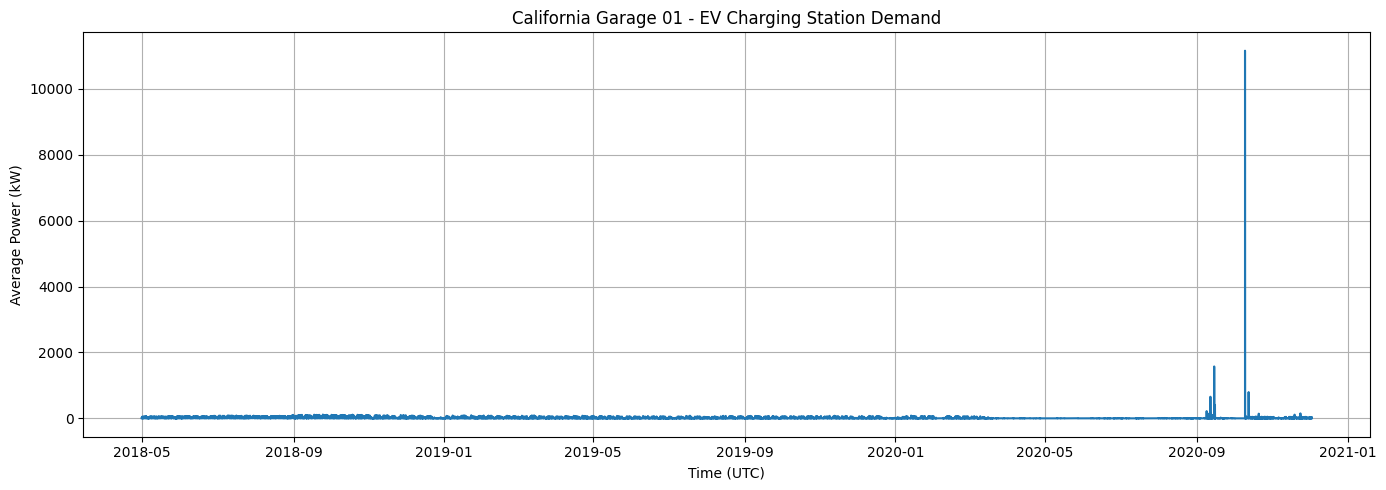

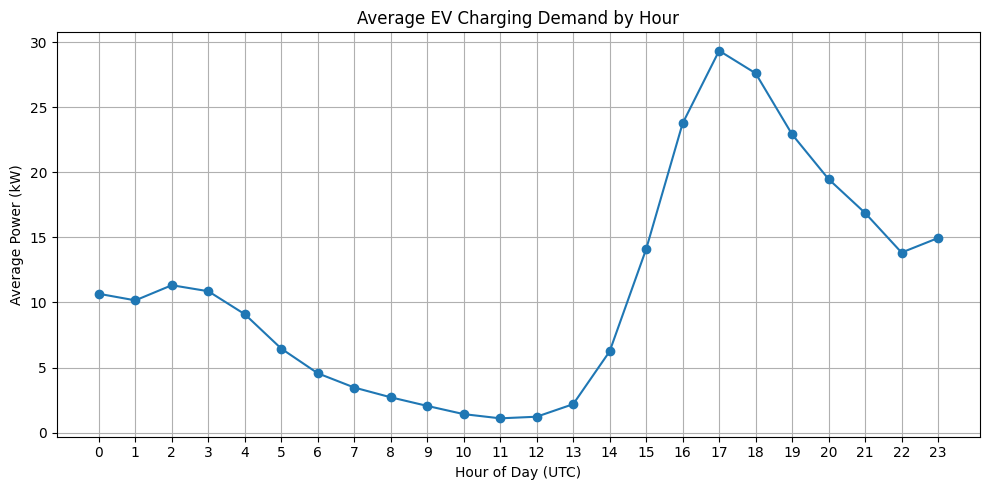

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Ensure correct timestamp format
station_profile["timestamp"] = pd.to_datetime(
    station_profile["timestamp"], utc=True
)

# Create time features
station_profile["date"] = station_profile["timestamp"].dt.date
station_profile["hour"] = station_profile["timestamp"].dt.hour
station_profile["day_of_week"] = (
    station_profile["timestamp"].dt.dayofweek
)

station_profile["month"] = (
    station_profile["timestamp"].dt.month
)

# Basic statistics
print("STATION LOAD STATISTICS")

print(station_profile["energy_kwh"].describe())

print("\nMaximum demand (kW):",
      station_profile["average_power_kw"].max())

print("Average demand (kW):",
      station_profile["average_power_kw"].mean())

print("Median demand (kW):",
      station_profile["average_power_kw"].median())

print("\nMissing values:")
print(station_profile.isna().sum())

print("\nDuplicate timestamps:",
      station_profile["timestamp"].duplicated().sum())

# Daily energy consumption
daily_energy = (
    station_profile.groupby("date")["energy_kwh"]
    .sum()
)

print("\nDaily energy consumption:")
print(daily_energy.describe())

# Plot 1: Station demand over time
plt.figure(figsize=(14, 5))
plt.plot(
    station_profile["timestamp"],
    station_profile["average_power_kw"]
)
plt.title("California Garage 01 - EV Charging Station Demand")
plt.xlabel("Time (UTC)")
plt.ylabel("Average Power (kW)")
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot 2: Average demand by hour
hourly_profile = (
    station_profile.groupby("hour")["average_power_kw"]
    .mean()
)

plt.figure(figsize=(10, 5))
plt.plot(hourly_profile.index, hourly_profile.values, marker="o")
plt.title("Average EV Charging Demand by Hour")
plt.xlabel("Hour of Day (UTC)")
plt.ylabel("Average Power (kW)")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
# Top 20 highest-demand intervals
top_intervals = station_profile.nlargest(
    20, "energy_kwh"
)[
    ["timestamp", "energy_kwh", "average_power_kw"]
]

print("TOP 20 PEAK INTERVALS")
print(top_intervals.to_string(index=False))

# Top 20 highest-energy charging sessions
top_sessions = usable_sessions.nlargest(
    20, "selected_energy_kwh"
)[
    ["session_id", "selected_energy_kwh",
     "energy_source", "energy_quality_flag"]
]

print("\nTOP 20 CHARGING SESSIONS")
print(top_sessions.to_string(index=False))

# Count extreme intervals
print("\nEXTREME INTERVAL COUNTS")

for threshold in [50, 100, 200, 500, 1000]:
    count = (
        station_profile["average_power_kw"] > threshold
    ).sum()

    print(f"Above {threshold} kW: {count} intervals")

TOP 20 PEAK INTERVALS
                timestamp  energy_kwh  average_power_kw
2020-10-09 23:15:00+00:00 2789.090000      11156.360000
2020-09-15 00:45:00+00:00  393.651000       1574.604000
2020-10-12 21:15:00+00:00  199.175000        796.700000
2020-09-11 23:00:00+00:00  163.820235        655.280940
2020-09-15 15:30:00+00:00  102.081000        408.324000
2020-09-08 22:00:00+00:00   54.757388        219.029550
2020-09-12 03:30:00+00:00   41.793699        167.174797
2020-11-23 19:00:00+00:00   37.522147        150.088586
2020-09-10 21:45:00+00:00   36.027071        144.108285
2020-10-21 02:00:00+00:00   35.362770        141.451079
2020-10-21 02:15:00+00:00   33.601729        134.406917
2018-09-24 16:15:00+00:00   28.642472        114.569889
2018-09-24 16:30:00+00:00   28.627587        114.510349
2020-09-12 18:00:00+00:00   28.343000        113.372000
2018-09-24 15:45:00+00:00   28.150410        112.601641
2020-11-19 02:00:00+00:00   27.892013        111.568052
2018-10-18 16:15:00+00:00 

In [20]:
# Inspect the raw data for the largest charging session
target_id = "2-39-81-4550-2020-10-09T23-25-52-994257.csv.gz"

target_path = os.path.join(caltech_path, target_id)

raw_check = pd.read_csv(target_path, compression="gzip")

print("SESSION:", target_id)
print("\nRAW COLUMNS:")
print(raw_check.columns.tolist())

print("\nFIRST 10 RECORDS:")
print(raw_check.head(10).to_string())

print("\nLAST 10 RECORDS:")
print(raw_check.tail(10).to_string())

print("\nNUMERIC COLUMN STATISTICS:")
print(raw_check.describe().to_string())

SESSION: 2-39-81-4550-2020-10-09T23-25-52-994257.csv.gz

RAW COLUMNS:
['Unnamed: 0', 'Charging Current (A)', 'Actual Pilot (A)', 'Voltage (V)', 'Charging State', 'Energy Delivered (kWh)', 'Power (kW)']

FIRST 10 RECORDS:
                         Unnamed: 0  Charging Current (A)  Actual Pilot (A)  Voltage (V)  Charging State  Energy Delivered (kWh)  Power (kW)
0  2020-10-09T23:25:53.005658+00:00                 117.9             119.0          NaN             NaN                  12.447     46.1437
1  2020-10-09T23:25:53.030429+00:00                 117.9             119.0          NaN             NaN                  12.573     46.1523
2  2020-10-09T23:25:53.053398+00:00                 115.9             118.0          NaN             NaN                  12.699     45.3723
3  2020-10-09T23:25:53.071428+00:00                 118.1             119.0          NaN             NaN                  12.827     46.2472
4  2020-10-09T23:25:53.087340+00:00                 118.1             119.

In [21]:
# Parse and sort timestamps
raw_check["timestamp"] = pd.to_datetime(
    raw_check["Unnamed: 0"],
    format="mixed",
    utc=True
)
raw_check = raw_check.sort_values("timestamp").reset_index(drop=True)

# Calculate time differences in hours
raw_check["time_diff_h"] = (
    raw_check["timestamp"].diff().dt.total_seconds() / 3600
)

# Calculate energy-counter changes
raw_check["counter_change"] = (
    raw_check["Energy Delivered (kWh)"].diff()
)

# Positive counter increments and negative resets
positive_increments = raw_check.loc[
    raw_check["counter_change"] > 0, "counter_change"
].sum()

negative_changes = raw_check.loc[
    raw_check["counter_change"] < 0, "counter_change"
]

# Independently estimate energy using measured power
valid_power = raw_check.dropna(
    subset=["Power (kW)", "time_diff_h"]
).copy()

power_energy_kwh = (
    (
        (valid_power["Power (kW)"] +
         valid_power["Power (kW)"].shift(1)) / 2
        * valid_power["time_diff_h"]
    ).dropna().sum()
)

print("SESSION DURATION (minutes):",
      (raw_check["timestamp"].max() -
       raw_check["timestamp"].min()).total_seconds() / 60)

print("\nCOUNTER DIAGNOSTICS")
print("Sum of positive counter increments:", positive_increments)
print("Number of negative counter changes:", len(negative_changes))
print("Largest positive counter increment:",
      raw_check["counter_change"].max())
print("Largest negative counter change:",
      raw_check["counter_change"].min())

print("\nPOWER-BASED ENERGY ESTIMATE (kWh):",
      power_energy_kwh)

print("\nLARGEST POSITIVE COUNTER INCREMENTS")
print(
    raw_check.nlargest(10, "counter_change")[
        ["timestamp", "Energy Delivered (kWh)",
         "counter_change", "Power (kW)"]
    ].to_string(index=False)
)

SESSION DURATION (minutes): 1.6496573333333333

COUNTER DIAGNOSTICS
Sum of positive counter increments: 592.321
Number of negative counter changes: 32
Largest positive counter increment: 48.772
Largest negative counter change: -56.328

POWER-BASED ENERGY ESTIMATE (kWh): 0.7613982377891528

LARGEST POSITIVE COUNTER INCREMENTS
                       timestamp  Energy Delivered (kWh)  counter_change  Power (kW)
2020-10-09 23:26:10.893529+00:00                  48.772          48.772     43.5233
2020-10-09 23:27:10.905809+00:00                  46.141          46.141     17.9510
2020-10-09 23:26:55.896567+00:00                  25.632          25.632     24.4439
2020-10-09 23:27:05.902181+00:00                  24.078          24.078     38.5581
2020-10-09 23:26:05.894100+00:00                  20.254          20.254     44.1361
2020-10-09 23:25:55.905901+00:00                  16.034          16.034     45.9809
2020-10-09 23:26:30.893859+00:00                  14.281          14.281     1

In [22]:
# Compare counter energy against power-integrated energy
top_sessions = usable_sessions.nlargest(
    20, "selected_energy_kwh"
)

comparison = []

for _, session in top_sessions.iterrows():
    sid = session["session_id"]
    path = os.path.join(caltech_path, sid)

    try:
        df = pd.read_csv(path, compression="gzip")

        df["timestamp"] = pd.to_datetime(
            df["Unnamed: 0"],
            format="mixed",
            utc=True,
            errors="coerce"
        )

        df["Power (kW)"] = pd.to_numeric(
            df["Power (kW)"], errors="coerce"
        )

        df = (
            df.dropna(subset=["timestamp", "Power (kW)"])
              .sort_values("timestamp")
              .drop_duplicates(subset=["timestamp"])
        )

        df["dt_h"] = (
            df["timestamp"].diff().dt.total_seconds() / 3600
        )

        df["previous_power"] = df["Power (kW)"].shift(1)

        # Integrate only intervals up to 60 seconds
        valid = (
            (df["dt_h"] > 0) &
            (df["dt_h"] <= 60 / 3600)
        )

        power_energy = (
            (
                (df.loc[valid, "Power (kW)"] +
                 df.loc[valid, "previous_power"]) / 2
                * df.loc[valid, "dt_h"]
            ).sum()
        )

        duration_min = (
            df["timestamp"].max() - df["timestamp"].min()
        ).total_seconds() / 60

        comparison.append({
            "session_id": sid,
            "counter_energy_kwh": session["selected_energy_kwh"],
            "power_energy_kwh": power_energy,
            "duration_min": duration_min,
            "max_power_kw": df["Power (kW)"].max()
        })

    except Exception as e:
        print("Could not process:", sid, "|", str(e))

comparison_df = pd.DataFrame(comparison)

print(comparison_df.to_string(index=False))

                                    session_id  counter_energy_kwh  power_energy_kwh  duration_min  max_power_kw
2-39-81-4550-2020-10-09T23-25-52-994257.csv.gz          592.321000          0.761716      1.649657       48.4714
2-39-81-4550-2020-10-09T23-27-32-196079.csv.gz          455.906000          0.641317      1.489796       48.9726
2-39-81-4550-2020-10-09T23-23-53-632653.csv.gz          451.487000          0.658844      1.983018       49.5056
2-39-81-4550-2020-10-09T23-16-31-041013.csv.gz          394.878000          0.501395      1.312666       47.7704
2-39-81-4550-2020-10-09T23-20-44-927220.csv.gz          382.399000          0.467336      1.649623       49.1944
2-39-81-4550-2020-10-09T23-22-23-148028.csv.gz          294.147000          0.441664      1.516223       48.1869
2-39-81-4550-2020-09-15T00-47-52-443647.csv.gz          211.701000          0.200579      1.262680       47.2841
2-39-81-4550-2020-10-10T22-37-54-023649.csv.gz          210.770000          0.408459   2798.7262

In [23]:
audit = []

for _, session in top_sessions.iterrows():
    sid = session["session_id"]
    path = os.path.join(caltech_path, sid)

    try:
        df = pd.read_csv(path, compression="gzip")

        df["timestamp"] = pd.to_datetime(
            df["Unnamed: 0"],
            format="mixed",
            utc=True,
            errors="coerce"
        )
        df["Power (kW)"] = pd.to_numeric(
            df["Power (kW)"], errors="coerce"
        )

        df = (
            df.dropna(subset=["timestamp", "Power (kW)"])
              .sort_values("timestamp")
              .drop_duplicates(subset=["timestamp"])
        )

        df["dt_seconds"] = (
            df["timestamp"].diff().dt.total_seconds()
        )

        duration_seconds = (
            df["timestamp"].max() - df["timestamp"].min()
        ).total_seconds()

        valid = (
            (df["dt_seconds"] > 0) &
            (df["dt_seconds"] <= 60)
        )

        covered_seconds = df.loc[valid, "dt_seconds"].sum()

        df["previous_power"] = df["Power (kW)"].shift(1)

        power_energy = (
            (
                (df.loc[valid, "Power (kW)"] +
                 df.loc[valid, "previous_power"]) / 2
                * df.loc[valid, "dt_seconds"] / 3600
            ).sum()
        )

        audit.append({
            "session_id": sid,
            "counter_kwh": session["selected_energy_kwh"],
            "power_kwh": power_energy,
            "duration_min": duration_seconds / 60,
            "coverage_pct": (
                covered_seconds / duration_seconds * 100
                if duration_seconds > 0 else 0
            ),
            "max_gap_min": df["dt_seconds"].max() / 60,
            "valid_intervals": int(valid.sum())
        })

    except Exception as e:
        print("Error:", sid, e)

audit_df = pd.DataFrame(audit)

print(audit_df.round(3).to_string(index=False))

                                    session_id  counter_kwh  power_kwh  duration_min  coverage_pct  max_gap_min  valid_intervals
2-39-81-4550-2020-10-09T23-25-52-994257.csv.gz      592.321      0.762         1.650       100.000        0.086             3604
2-39-81-4550-2020-10-09T23-27-32-196079.csv.gz      455.906      0.641         1.490       100.000        0.089             3119
2-39-81-4550-2020-10-09T23-23-53-632653.csv.gz      451.487      0.659         1.983       100.000        0.089             3160
2-39-81-4550-2020-10-09T23-16-31-041013.csv.gz      394.878      0.501         1.313       100.000        0.083             2898
2-39-81-4550-2020-10-09T23-20-44-927220.csv.gz      382.399      0.467         1.650       100.000        0.088             2994
2-39-81-4550-2020-10-09T23-22-23-148028.csv.gz      294.147      0.442         1.516       100.000        0.087             2993
2-39-81-4550-2020-09-15T00-47-52-443647.csv.gz      211.701      0.201         1.263       100.00

In [24]:
# Calculate relative disagreement between the two energy estimates
audit_df["relative_difference_pct"] = (
    (audit_df["counter_kwh"] - audit_df["power_kwh"]).abs()
    / audit_df[["counter_kwh", "power_kwh"]].max(axis=1)
    * 100
)

# Provisional classification for this audit
audit_df["decision"] = np.select(
    [
        (audit_df["coverage_pct"] >= 90) &
        (audit_df["relative_difference_pct"] > 20),

        (audit_df["coverage_pct"] < 90),

        (audit_df["relative_difference_pct"] <= 20)
    ],
    [
        "POWER_FALLBACK_CANDIDATE",
        "LOW_COVERAGE_REVIEW",
        "COUNTER_RETAIN_CANDIDATE"
    ],
    default="REVIEW"
)

print(
    audit_df[
        [
            "session_id",
            "counter_kwh",
            "power_kwh",
            "coverage_pct",
            "relative_difference_pct",
            "decision"
        ]
    ].round(3).to_string(index=False)
)

print("\nCLASSIFICATION SUMMARY")
print(audit_df["decision"].value_counts())

                                    session_id  counter_kwh  power_kwh  coverage_pct  relative_difference_pct                 decision
2-39-81-4550-2020-10-09T23-25-52-994257.csv.gz      592.321      0.762       100.000                   99.871 POWER_FALLBACK_CANDIDATE
2-39-81-4550-2020-10-09T23-27-32-196079.csv.gz      455.906      0.641       100.000                   99.859 POWER_FALLBACK_CANDIDATE
2-39-81-4550-2020-10-09T23-23-53-632653.csv.gz      451.487      0.659       100.000                   99.854 POWER_FALLBACK_CANDIDATE
2-39-81-4550-2020-10-09T23-16-31-041013.csv.gz      394.878      0.501       100.000                   99.873 POWER_FALLBACK_CANDIDATE
2-39-81-4550-2020-10-09T23-20-44-927220.csv.gz      382.399      0.467       100.000                   99.878 POWER_FALLBACK_CANDIDATE
2-39-81-4550-2020-10-09T23-22-23-148028.csv.gz      294.147      0.442       100.000                   99.850 POWER_FALLBACK_CANDIDATE
2-39-81-4550-2020-09-15T00-47-52-443647.csv.gz      211

In [26]:
# Full-dataset energy consistency audit
import os
import numpy as np
import pandas as pd

counter_sessions = usable_sessions[
    usable_sessions["energy_source"] == "COUNTER_RECONSTRUCTED"
].copy()

audit_results = []

for i, (_, session) in enumerate(counter_sessions.iterrows(), 1):

    sid = session["session_id"]
    path = os.path.join(caltech_path, sid)

    try:
        df = pd.read_csv(path, compression="gzip")

        df["timestamp"] = pd.to_datetime(
            df["Unnamed: 0"],
            format="mixed",
            utc=True,
            errors="coerce"
        )

        df["Power (kW)"] = pd.to_numeric(
            df["Power (kW)"], errors="coerce"
        )

        df = (
            df.dropna(subset=["timestamp", "Power (kW)"])
              .sort_values("timestamp")
              .drop_duplicates(subset=["timestamp"])
        )

        if len(df) < 2:
            continue

        df["dt_seconds"] = (
            df["timestamp"].diff().dt.total_seconds()
        )

        duration_seconds = (
            df["timestamp"].max() -
            df["timestamp"].min()
        ).total_seconds()

        valid = (
            (df["dt_seconds"] > 0) &
            (df["dt_seconds"] <= 60)
        )

        covered_seconds = df.loc[valid, "dt_seconds"].sum()

        previous_power = df["Power (kW)"].shift(1)

        power_energy = (
            (
                (df.loc[valid, "Power (kW)"] +
                 previous_power.loc[valid]) / 2
                * df.loc[valid, "dt_seconds"] / 3600
            ).sum()
        )

        counter_energy = session["selected_energy_kwh"]

        coverage = (
            covered_seconds / duration_seconds * 100
            if duration_seconds > 0 else 0
        )

        relative_difference = (
            abs(counter_energy - power_energy) /
            max(counter_energy, power_energy)
            * 100
            if max(counter_energy, power_energy) > 0 else 0
        )

        if coverage < 90:
            decision = "LOW_COVERAGE_REVIEW"

        elif counter_energy > power_energy * 1.20:
            decision = "COUNTER_HIGH_REVIEW"

        elif power_energy > counter_energy * 1.20:
            decision = "POWER_HIGH_REVIEW"

        else:
            decision = "CONSISTENT_CANDIDATE"

        audit_results.append({
            "session_id": sid,
            "counter_energy_kwh": counter_energy,
            "power_energy_kwh": power_energy,
            "coverage_pct": coverage,
            "relative_difference_pct": relative_difference,
            "decision": decision
        })

    except Exception as e:
        audit_results.append({
            "session_id": sid,
            "counter_energy_kwh": session["selected_energy_kwh"],
            "power_energy_kwh": np.nan,
            "coverage_pct": np.nan,
            "relative_difference_pct": np.nan,
            "decision": "AUDIT_ERROR"
        })

    if i % 2000 == 0:
        print(f"Audited {i} / {len(counter_sessions)} sessions")

# Save audit separately
full_audit = pd.DataFrame(audit_results)

audit_path = os.path.join(
    project_path,
    "caltech_garage01_full_energy_audit.csv"
)

full_audit.to_csv(audit_path, index=False)

print("\n========== FULL ENERGY AUDIT ==========")
print("Sessions audited:", len(full_audit))
print("\nClassification:")
print(full_audit["decision"].value_counts())

print("\nTotal counter energy:",
      round(full_audit["counter_energy_kwh"].sum(), 3), "kWh")

print("\nTotal power-integrated energy:",
      round(full_audit["power_energy_kwh"].sum(), 3), "kWh")

print("\nAudit saved to:", audit_path)

Audited 2000 / 30284 sessions
Audited 4000 / 30284 sessions
Audited 6000 / 30284 sessions
Audited 8000 / 30284 sessions
Audited 10000 / 30284 sessions
Audited 12000 / 30284 sessions
Audited 14000 / 30284 sessions
Audited 16000 / 30284 sessions
Audited 18000 / 30284 sessions
Audited 20000 / 30284 sessions
Audited 22000 / 30284 sessions
Audited 24000 / 30284 sessions
Audited 26000 / 30284 sessions
Audited 28000 / 30284 sessions
Audited 30000 / 30284 sessions

========== FULL ENERGY AUDIT ==========
Sessions audited: 29599

Classification:
decision
CONSISTENT_CANDIDATE    28585
LOW_COVERAGE_REVIEW       505
COUNTER_HIGH_REVIEW       275
POWER_HIGH_REVIEW         234
Name: count, dtype: int64

Total counter energy: 247798.249 kWh

Total power-integrated energy: 243133.3 kWh

Audit saved to: C:\EV_Charging_Project\caltech_garage01_full_energy_audit.csv


In [27]:
audited_ids = set(full_audit["session_id"])
all_counter_ids = set(counter_sessions["session_id"])

missing_ids = all_counter_ids - audited_ids

unaudited_sessions = counter_sessions[
    counter_sessions["session_id"].isin(missing_ids)
].copy()

print("Expected counter sessions:", len(counter_sessions))
print("Successfully audited:", len(audited_ids))
print("Unaudited sessions:", len(unaudited_sessions))

print("\nEnergy in unaudited sessions:")
print(
    unaudited_sessions["selected_energy_kwh"].describe()
)

print("\nTotal energy in unaudited sessions:",
      unaudited_sessions["selected_energy_kwh"].sum(), "kWh")

print("\nFirst 10 unaudited session IDs:")
print(unaudited_sessions["session_id"].head(10).to_string(index=False))

Expected counter sessions: 30284
Successfully audited: 29599
Unaudited sessions: 685

Energy in unaudited sessions:
count    685.000000
mean       6.430892
std        6.952878
min        0.000028
25%        0.171299
50%        4.753908
75%       10.228491
max       46.331083
Name: selected_energy_kwh, dtype: float64

Total energy in unaudited sessions: 4405.160738357502 kWh

First 10 unaudited session IDs:
2-39-123-23-2018-05-01T17-11-32-081386.csv.gz
2-39-123-23-2018-05-01T20-12-26-312220.csv.gz
2-39-123-23-2018-05-02T13-25-55-840259.csv.gz
2-39-123-23-2018-05-02T15-15-17-269387.csv.gz
2-39-123-23-2018-05-02T18-23-24-918058.csv.gz
2-39-123-23-2018-05-03T15-50-09-887699.csv.gz
2-39-123-23-2018-05-03T15-51-10-598352.csv.gz
2-39-123-23-2018-05-03T16-02-46-386787.csv.gz
2-39-123-23-2018-05-04T15-48-44-986155.csv.gz
2-39-123-23-2018-05-04T19-04-58-479537.csv.gz


In [28]:
# Inspect 10 unaudited sessions
sample_ids = unaudited_sessions["session_id"].head(10)

for sid in sample_ids:
    path = os.path.join(caltech_path, sid)

    try:
        df = pd.read_csv(path, compression="gzip")

        print("\nSESSION:", sid)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())

        if "Unnamed: 0" in df.columns:
            timestamps = pd.to_datetime(
                df["Unnamed: 0"],
                format="mixed",
                utc=True,
                errors="coerce"
            )
            print("Valid timestamps:", timestamps.notna().sum())

        if "Power (kW)" in df.columns:
            power = pd.to_numeric(
                df["Power (kW)"], errors="coerce"
            )
            print("Valid power readings:", power.notna().sum())
            print("Maximum power:", power.max())

    except Exception as e:
        print("ERROR:", str(e))


SESSION: 2-39-123-23-2018-05-01T17-11-32-081386.csv.gz
Rows: 2807
Columns: ['Unnamed: 0', 'Charging Current (A)', 'Actual Pilot (A)', 'Voltage (V)', 'Charging State', 'Energy Delivered (kWh)', 'Power (kW)']
Valid timestamps: 2807
Valid power readings: 0
Maximum power: nan

SESSION: 2-39-123-23-2018-05-01T20-12-26-312220.csv.gz
Rows: 3493
Columns: ['Unnamed: 0', 'Charging Current (A)', 'Actual Pilot (A)', 'Voltage (V)', 'Charging State', 'Energy Delivered (kWh)', 'Power (kW)']
Valid timestamps: 3493
Valid power readings: 0
Maximum power: nan

SESSION: 2-39-123-23-2018-05-02T13-25-55-840259.csv.gz
Rows: 1078
Columns: ['Unnamed: 0', 'Charging Current (A)', 'Actual Pilot (A)', 'Voltage (V)', 'Charging State', 'Energy Delivered (kWh)', 'Power (kW)']
Valid timestamps: 1078
Valid power readings: 0
Maximum power: nan

SESSION: 2-39-123-23-2018-05-02T15-15-17-269387.csv.gz
Rows: 2782
Columns: ['Unnamed: 0', 'Charging Current (A)', 'Actual Pilot (A)', 'Voltage (V)', 'Charging State', 'Energy De

In [29]:
# Verify power-data availability in all 685 unaudited sessions
missing_power_audit = []

for i, sid in enumerate(unaudited_sessions["session_id"], 1):

    path = os.path.join(caltech_path, sid)

    try:
        df = pd.read_csv(path, compression="gzip")

        power = pd.to_numeric(
            df["Power (kW)"], errors="coerce"
        )

        missing_power_audit.append({
            "session_id": sid,
            "valid_power_readings": int(power.notna().sum()),
            "valid_timestamps": int(
                pd.to_datetime(
                    df["Unnamed: 0"],
                    format="mixed",
                    utc=True,
                    errors="coerce"
                ).notna().sum()
            )
        })

    except Exception as e:
        missing_power_audit.append({
            "session_id": sid,
            "valid_power_readings": -1,
            "valid_timestamps": -1
        })

    if i % 100 == 0:
        print(f"Checked {i} / {len(unaudited_sessions)}")

missing_power_df = pd.DataFrame(missing_power_audit)

print("\nPOWER DATA AVAILABILITY")
print(missing_power_df["valid_power_readings"].value_counts().sort_index())

print("\nTotal sessions:", len(missing_power_df))
print("Sessions with zero power readings:",
      (missing_power_df["valid_power_readings"] == 0).sum())
print("Sessions with at least one power reading:",
      (missing_power_df["valid_power_readings"] > 0).sum())
print("Sessions with read errors:",
      (missing_power_df["valid_power_readings"] == -1).sum())

Checked 100 / 685
Checked 200 / 685
Checked 300 / 685
Checked 400 / 685
Checked 500 / 685
Checked 600 / 685

POWER DATA AVAILABILITY
valid_power_readings
0    684
1      1
Name: count, dtype: int64

Total sessions: 685
Sessions with zero power readings: 684
Sessions with at least one power reading: 1
Sessions with read errors: 0


In [30]:
# Combine all audited and unaudited session IDs
accounted_ids = (
    set(full_audit["session_id"])
    | set(unaudited_sessions["session_id"])
)

remaining_ids = all_counter_ids - accounted_ids

print("Remaining sessions:", len(remaining_ids))
print("Session IDs:", remaining_ids)

Remaining sessions: 0
Session IDs: set()


In [31]:
print("FULL AUDIT:")
print(full_audit["decision"].value_counts(dropna=False))

print("\nMISSING POWER:")
print("Total:", len(missing_power_df))
print("Zero power:", (missing_power_df["valid_power_readings"] == 0).sum())
print("One or more power readings:",
      (missing_power_df["valid_power_readings"] > 0).sum())

print("\nAUDIT ROWS:", len(full_audit))
print("UNIQUE AUDIT IDS:", full_audit["session_id"].nunique())
print("UNIQUE MISSING IDS:", unaudited_sessions["session_id"].nunique())

FULL AUDIT:
decision
CONSISTENT_CANDIDATE    28585
LOW_COVERAGE_REVIEW       505
COUNTER_HIGH_REVIEW       275
POWER_HIGH_REVIEW         234
Name: count, dtype: int64

MISSING POWER:
Total: 685
Zero power: 684
One or more power readings: 1

AUDIT ROWS: 29599
UNIQUE AUDIT IDS: 29599
UNIQUE MISSING IDS: 685


In [32]:
# Add the 685 sessions that could not be power-audited
missing_power_records = unaudited_sessions[
    ["session_id", "selected_energy_kwh"]
].copy()

missing_power_records = missing_power_records.rename(
    columns={"selected_energy_kwh": "counter_energy_kwh"}
)

missing_power_records["power_energy_kwh"] = np.nan
missing_power_records["coverage_pct"] = np.nan
missing_power_records["relative_difference_pct"] = np.nan
missing_power_records["decision"] = "NO_POWER_DATA_COUNTER_RETAINED"

# Combine all 30,284 counter-based sessions
complete_counter_audit = pd.concat(
    [full_audit, missing_power_records],
    ignore_index=True
)

# Verify
print("Total counter sessions:", len(complete_counter_audit))
print("Unique session IDs:",
      complete_counter_audit["session_id"].nunique())

print("\nFINAL CLASSIFICATION:")
print(complete_counter_audit["decision"].value_counts())

# Save
audit_output = os.path.join(
    project_path,
    "caltech_garage01_complete_energy_audit.csv"
)

complete_counter_audit.to_csv(audit_output, index=False)

print("\nSaved:", audit_output)

Total counter sessions: 30284
Unique session IDs: 30284

FINAL CLASSIFICATION:
decision
CONSISTENT_CANDIDATE              28585
NO_POWER_DATA_COUNTER_RETAINED      685
LOW_COVERAGE_REVIEW                 505
COUNTER_HIGH_REVIEW                 275
POWER_HIGH_REVIEW                   234
Name: count, dtype: int64

Saved: C:\EV_Charging_Project\caltech_garage01_complete_energy_audit.csv


In [33]:
counter_high = complete_counter_audit[
    complete_counter_audit["decision"] == "COUNTER_HIGH_REVIEW"
].copy()

print("Counter-high sessions:", len(counter_high))

print("\nEnergy comparison:")
print(
    counter_high[
        ["counter_energy_kwh", "power_energy_kwh",
         "coverage_pct", "relative_difference_pct"]
    ].describe().round(3)
)

print("\nTotal counter energy:",
      counter_high["counter_energy_kwh"].sum())

print("Total power-integrated energy:",
      counter_high["power_energy_kwh"].sum())

print("\nLargest counter-energy mismatches:")
print(
    counter_high.nlargest(10, "relative_difference_pct")[
        ["session_id", "counter_energy_kwh",
         "power_energy_kwh", "coverage_pct",
         "relative_difference_pct"]
    ].to_string(index=False)
)

Counter-high sessions: 275

Energy comparison:
       counter_energy_kwh  power_energy_kwh  coverage_pct  \
count             275.000           275.000       275.000   
mean               14.824             0.895        98.876   
std                67.897             3.107         2.464   
min                 0.000             0.000        90.391   
25%                 0.000             0.000       100.000   
50%                 0.002             0.001       100.000   
75%                 0.983             0.154       100.000   
max               592.321            24.440       100.000   

       relative_difference_pct  
count                  275.000  
mean                    58.647  
std                     32.112  
min                     16.682  
25%                     26.207  
50%                     54.599  
75%                     97.714  
max                    100.000  

Total counter energy: 4076.5407189232683
Total power-integrated energy: 246.18889701942317

Largest count

In [34]:
# Absolute difference between counter and power estimates
counter_high["absolute_difference_kwh"] = (
    counter_high["counter_energy_kwh"]
    - counter_high["power_energy_kwh"]
).abs()

# Diagnostic groups
counter_high["diagnostic_group"] = np.select(
    [
        (
            (counter_high["counter_energy_kwh"] <= 0.05) &
            (counter_high["power_energy_kwh"] <= 0.05)
        ),
        (
            (counter_high["absolute_difference_kwh"] > 0.1) &
            (counter_high["relative_difference_pct"] > 20)
        )
    ],
    [
        "NEGLIGIBLE_ENERGY",
        "MATERIAL_MISMATCH"
    ],
    default="SMALL_DIFFERENCE_REVIEW"
)

print("DIAGNOSTIC GROUP COUNTS:")
print(counter_high["diagnostic_group"].value_counts())

print("\nENERGY BY DIAGNOSTIC GROUP:")
print(
    counter_high.groupby("diagnostic_group")[
        ["counter_energy_kwh", "power_energy_kwh",
         "absolute_difference_kwh"]
    ].sum().round(3)
)

print("\nLARGEST MATERIAL MISMATCHES:")
print(
    counter_high[
        counter_high["diagnostic_group"] == "MATERIAL_MISMATCH"
    ].nlargest(15, "absolute_difference_kwh")[
        ["session_id", "counter_energy_kwh",
         "power_energy_kwh", "absolute_difference_kwh",
         "coverage_pct"]
    ].to_string(index=False)
)

DIAGNOSTIC GROUP COUNTS:
diagnostic_group
NEGLIGIBLE_ENERGY          187
MATERIAL_MISMATCH           64
SMALL_DIFFERENCE_REVIEW     24
Name: count, dtype: int64

ENERGY BY DIAGNOSTIC GROUP:
                         counter_energy_kwh  power_energy_kwh  \
diagnostic_group                                                
MATERIAL_MISMATCH                  3980.246           167.631   
NEGLIGIBLE_ENERGY                     0.464             0.265   
SMALL_DIFFERENCE_REVIEW              95.831            78.293   

                         absolute_difference_kwh  
diagnostic_group                                  
MATERIAL_MISMATCH                       3812.615  
NEGLIGIBLE_ENERGY                          0.199  
SMALL_DIFFERENCE_REVIEW                   17.538  

LARGEST MATERIAL MISMATCHES:
                                    session_id  counter_energy_kwh  power_energy_kwh  absolute_difference_kwh  coverage_pct
2-39-81-4550-2020-10-09T23-25-52-994257.csv.gz             592.321         

In [35]:
material_mismatch = counter_high[
    counter_high["diagnostic_group"] == "MATERIAL_MISMATCH"
].copy()

print("Material mismatch sessions:", len(material_mismatch))

print("\nSESSION DURATION STATISTICS:")
print(
    audit_df[
        audit_df["session_id"].isin(
            material_mismatch["session_id"]
        )
    ]["duration_min"].describe().round(2)
)

print("\nPOWER ESTIMATE STATISTICS:")
print(
    material_mismatch["power_energy_kwh"].describe().round(3)
)

print("\nTOP 15 COUNTER MISMATCHES:")
print(
    material_mismatch.nlargest(
        15, "absolute_difference_kwh"
    )[
        ["session_id", "counter_energy_kwh",
         "power_energy_kwh", "coverage_pct"]
    ].to_string(index=False)
)

Material mismatch sessions: 64

SESSION DURATION STATISTICS:
count      12.00
mean      247.58
std       804.10
min         0.83
25%         1.30
50%         1.58
75%        12.87
max      2798.73
Name: duration_min, dtype: float64

POWER ESTIMATE STATISTICS:
count    64.000
mean      2.619
std       5.160
min       0.000
25%       0.231
50%       0.650
75%       1.732
max      24.440
Name: power_energy_kwh, dtype: float64

TOP 15 COUNTER MISMATCHES:
                                    session_id  counter_energy_kwh  power_energy_kwh  coverage_pct
2-39-81-4550-2020-10-09T23-25-52-994257.csv.gz             592.321          0.761716    100.000000
2-39-81-4550-2020-10-09T23-27-32-196079.csv.gz             455.906          0.641317    100.000000
2-39-81-4550-2020-10-09T23-23-53-632653.csv.gz             451.487          0.658844    100.000000
2-39-81-4550-2020-10-09T23-16-31-041013.csv.gz             394.878          0.501395    100.000000
2-39-81-4550-2020-10-09T23-20-44-927220.csv.gz    

In [36]:
validation_results = []

for _, session in material_mismatch.iterrows():

    sid = session["session_id"]
    path = os.path.join(caltech_path, sid)

    df = pd.read_csv(path, compression="gzip")

    df["timestamp"] = pd.to_datetime(
        df["Unnamed: 0"],
        format="mixed",
        utc=True,
        errors="coerce"
    )

    for col in ["Power (kW)", "Charging Current (A)"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = (
        df.dropna(subset=["timestamp"])
          .sort_values("timestamp")
          .drop_duplicates(subset=["timestamp"])
    )

    duration_min = (
        df["timestamp"].max() -
        df["timestamp"].min()
    ).total_seconds() / 60

    power = df["Power (kW)"].dropna()
    current = df["Charging Current (A)"].dropna()

    validation_results.append({
        "session_id": sid,
        "counter_kwh": session["counter_energy_kwh"],
        "power_kwh": session["power_energy_kwh"],
        "duration_min": duration_min,
        "valid_power_pct": df["Power (kW)"].notna().mean() * 100,
        "max_power_kw": power.max() if len(power) else np.nan,
        "mean_power_kw": power.mean() if len(power) else np.nan,
        "max_current_a": current.max() if len(current) else np.nan,
        "negative_power_count": (power < 0).sum()
    })

validation_df = pd.DataFrame(validation_results)

print("VALIDATED SESSIONS:", len(validation_df))

print("\nVALIDATION SUMMARY:")
print(
    validation_df[
        ["duration_min", "valid_power_pct", "max_power_kw",
         "mean_power_kw", "max_current_a"]
    ].describe().round(3)
)

print("\nLONG-DURATION SESSIONS:")
print(
    validation_df.nlargest(10, "duration_min")[
        ["session_id", "duration_min", "counter_kwh",
         "power_kwh", "valid_power_pct"]
    ].to_string(index=False)
)


VALIDATED SESSIONS: 64

VALIDATION SUMMARY:
       duration_min  valid_power_pct  max_power_kw  mean_power_kw  \
count        64.000           64.000        64.000         64.000   
mean        529.138           94.091        18.949          7.010   
std         952.090           19.934        20.683         10.663   
min           0.032            1.494         0.000          0.000   
25%          35.499          100.000         2.139          0.163   
50%         252.140          100.000         5.043          0.600   
75%         556.196          100.000        46.818         10.797   
max        6260.167          100.000        49.506         33.976   

       max_current_a  
count         64.000  
mean          53.889  
std           51.107  
min            7.000  
25%           10.875  
50%           29.150  
75%          125.100  
max          125.200  

LONG-DURATION SESSIONS:
                                    session_id  duration_min  counter_kwh  power_kwh  valid_power_pct


In [37]:
corrected_validation = []

for _, session in material_mismatch.iterrows():

    sid = session["session_id"]
    path = os.path.join(caltech_path, sid)

    df = pd.read_csv(path, compression="gzip")

    df["timestamp"] = pd.to_datetime(
        df["Unnamed: 0"],
        format="mixed",
        utc=True,
        errors="coerce"
    )

    df["Power (kW)"] = pd.to_numeric(
        df["Power (kW)"], errors="coerce"
    )

    # Keep rows with valid timestamps, including missing power rows
    df = (
        df.dropna(subset=["timestamp"])
          .sort_values("timestamp")
          .drop_duplicates(subset=["timestamp"])
          .reset_index(drop=True)
    )

    duration_seconds = (
        df["timestamp"].max() - df["timestamp"].min()
    ).total_seconds()

    df["dt_seconds"] = (
        df["timestamp"].diff().dt.total_seconds()
    )

    df["previous_power"] = df["Power (kW)"].shift(1)

    valid_interval = (
        (df["dt_seconds"] > 0) &
        (df["dt_seconds"] <= 60) &
        df["Power (kW)"].notna() &
        df["previous_power"].notna()
    )

    covered_seconds = df.loc[
        valid_interval, "dt_seconds"
    ].sum()

    actual_coverage = (
        covered_seconds / duration_seconds * 100
        if duration_seconds > 0 else 0
    )

    power_energy = (
        (
            (
                df.loc[valid_interval, "Power (kW)"] +
                df.loc[valid_interval, "previous_power"]
            ) / 2
            * df.loc[valid_interval, "dt_seconds"] / 3600
        ).sum()
    )

    valid_power = df["Power (kW)"].dropna()

    corrected_validation.append({
        "session_id": sid,
        "counter_kwh": session["counter_energy_kwh"],
        "previous_power_kwh": session["power_energy_kwh"],
        "corrected_power_kwh": power_energy,
        "duration_min": duration_seconds / 60,
        "valid_power_pct": df["Power (kW)"].notna().mean() * 100,
        "actual_time_coverage_pct": actual_coverage,
        "max_timestamp_gap_min": df["dt_seconds"].max() / 60,
        "max_power_kw": valid_power.max() if len(valid_power) else np.nan,
        "valid_intervals": int(valid_interval.sum())
    })

corrected_validation_df = pd.DataFrame(corrected_validation)

print("SESSIONS CHECKED:", len(corrected_validation_df))

print("\nACTUAL COVERAGE SUMMARY:")
print(
    corrected_validation_df[
        ["valid_power_pct", "actual_time_coverage_pct",
         "duration_min", "corrected_power_kwh"]
    ].describe().round(3)
)

print("\nCOVERAGE CLASSIFICATION:")
print(
    pd.cut(
        corrected_validation_df["actual_time_coverage_pct"],
        bins=[-0.01, 50, 90, 100.01],
        labels=["Below 50%", "50–90%", "90–100%"]
    ).value_counts()
)

print("\nLOWEST COVERAGE SESSIONS:")
print(
    corrected_validation_df.nsmallest(
        15, "actual_time_coverage_pct"
    )[
        ["session_id", "counter_kwh", "corrected_power_kwh",
         "duration_min", "valid_power_pct",
         "actual_time_coverage_pct"]
    ].to_string(index=False)
)

SESSIONS CHECKED: 64

ACTUAL COVERAGE SUMMARY:
       valid_power_pct  actual_time_coverage_pct  duration_min  \
count           64.000                    64.000        64.000   
mean            94.091                    90.854       529.138   
std             19.934                    19.647       952.090   
min              1.494                     1.505         0.032   
25%            100.000                    91.917        35.499   
50%            100.000                    96.133       252.140   
75%            100.000                   100.000       556.196   
max            100.000                   100.000      6260.167   

       corrected_power_kwh  
count               64.000  
mean                 2.619  
std                  5.160  
min                  0.000  
25%                  0.231  
50%                  0.650  
75%                  1.732  
max                 24.440  

COVERAGE CLASSIFICATION:
actual_time_coverage_pct
90–100%      57
Below 50%     4
50–90%        

In [38]:
# Select sessions with at least 90% actual time coverage
high_coverage_57 = corrected_validation_df[
    corrected_validation_df["actual_time_coverage_pct"] >= 90
].copy()

# Calculate absolute and relative differences
high_coverage_57["absolute_difference_kwh"] = (
    high_coverage_57["counter_kwh"] -
    high_coverage_57["corrected_power_kwh"]
).abs()

high_coverage_57["relative_difference_pct"] = (
    high_coverage_57["absolute_difference_kwh"] /
    high_coverage_57[
        ["counter_kwh", "corrected_power_kwh"]
    ].max(axis=1).clip(lower=0.001)
) * 100

print("HIGH-COVERAGE SESSIONS:", len(high_coverage_57))

print("\nENERGY COMPARISON:")
print(
    high_coverage_57[
        ["counter_kwh", "corrected_power_kwh",
         "absolute_difference_kwh",
         "relative_difference_pct"]
    ].describe().round(3)
)

print("\nTOTAL COUNTER ENERGY:",
      high_coverage_57["counter_kwh"].sum())

print("TOTAL POWER ENERGY:",
      high_coverage_57["corrected_power_kwh"].sum())

print("\nLARGEST DIFFERENCES:")
print(
    high_coverage_57.nlargest(
        15, "absolute_difference_kwh"
    )[
        ["session_id", "counter_kwh",
         "corrected_power_kwh",
         "absolute_difference_kwh",
         "actual_time_coverage_pct"]
    ].to_string(index=False)
)

HIGH-COVERAGE SESSIONS: 57

ENERGY COMPARISON:
       counter_kwh  corrected_power_kwh  absolute_difference_kwh  \
count       57.000               57.000                   57.000   
mean        68.366                2.625                   65.741   
std        137.241                5.313                  137.866   
min          0.297                0.007                    0.118   
25%          1.855                0.241                    0.595   
50%          6.094                0.667                    2.175   
75%         40.060                1.717                   27.789   
max        592.321               24.440                  591.559   

       relative_difference_pct  
count                   57.000  
mean                    61.224  
std                     33.418  
min                     20.186  
25%                     28.888  
50%                     47.855  
75%                     99.803  
max                     99.951  

TOTAL COUNTER ENERGY: 3896.8444294609776
T

In [39]:
# Select sessions approved for the primary dataset
clean_audit = complete_counter_audit[
    complete_counter_audit["decision"].isin([
        "CONSISTENT_CANDIDATE",
        "NO_POWER_DATA_COUNTER_RETAINED"
    ])
].copy()

# Merge with the complete session metadata
clean_sessions = clean_audit.merge(
    combined_sessions[
        ["session_id", "arrival_time", "departure_time"]
    ],
    on="session_id",
    how="left",
    validate="one_to_one"
)

clean_sessions = clean_sessions.rename(
    columns={"counter_energy_kwh": "clean_energy_kwh"}
)

print("Clean sessions:", len(clean_sessions))
print("Missing arrival times:", clean_sessions["arrival_time"].isna().sum())
print("Missing departure times:", clean_sessions["departure_time"].isna().sum())
print("Total clean energy:",
      clean_sessions["clean_energy_kwh"].sum(), "kWh")

# Save
clean_path = os.path.join(
    project_path,
    "caltech_garage01_clean_sessions.csv"
)

clean_sessions.to_csv(clean_path, index=False)

print("Saved:", clean_path)

Clean sessions: 29270
Missing arrival times: 0
Missing departure times: 0
Total clean energy: 243406.68678463716 kWh
Saved: C:\EV_Charging_Project\caltech_garage01_clean_sessions.csv


In [40]:
# Prepare clean session list for aggregation

clean_sessions["arrival_time"] = pd.to_datetime(
    clean_sessions["arrival_time"], utc=True
)

clean_sessions["departure_time"] = pd.to_datetime(
    clean_sessions["departure_time"], utc=True
)

print("Sessions ready:", len(clean_sessions))
print("Total energy:",
      clean_sessions["clean_energy_kwh"].sum())

print("\nEnergy source distribution:")
print(clean_sessions["decision"].value_counts())

Sessions ready: 29270
Total energy: 243406.68678463716

Energy source distribution:
decision
CONSISTENT_CANDIDATE              28585
NO_POWER_DATA_COUNTER_RETAINED      685
Name: count, dtype: int64


In [41]:

# ============================================
# CLEAN STATION LOAD AGGREGATION - 15 MINUTES
# ============================================

import os
import pandas as pd
import numpy as np

# Store energy by 15-minute timestamp
load_dict = {}

failed_sessions = []
energy_mismatches = []

expected_energy = clean_sessions["clean_energy_kwh"].sum()

for i, (_, session) in enumerate(clean_sessions.iterrows(), 1):

    sid = session["session_id"]
    expected_session_energy = session["clean_energy_kwh"]

    path = os.path.join(caltech_path, sid)

    try:
        df = pd.read_csv(path, compression="gzip")

        # Parse timestamps
        df["timestamp"] = pd.to_datetime(
            df["Unnamed: 0"],
            format="mixed",
            utc=True,
            errors="coerce"
        )

        # Convert energy counter
        df["Energy Delivered (kWh)"] = pd.to_numeric(
            df["Energy Delivered (kWh)"],
            errors="coerce"
        )

        df = (
            df.dropna(subset=[
                "timestamp",
                "Energy Delivered (kWh)"
            ])
            .sort_values("timestamp")
            .drop_duplicates(subset=["timestamp"])
            .reset_index(drop=True)
        )

        if len(df) < 2:
            failed_sessions.append(sid)
            continue

        # Calculate energy increments
        df["energy_delta"] = (
            df["Energy Delivered (kWh)"].diff()
        )

        df["previous_timestamp"] = df["timestamp"].shift(1)

        # Keep positive increments with valid time intervals
        intervals = df[
            (df["energy_delta"] > 0) &
            (df["previous_timestamp"].notna())
        ].copy()

        session_aggregated_energy = 0.0

        # Allocate interval energy across 15-minute bins
        for _, interval in intervals.iterrows():

            start = interval["previous_timestamp"]
            end = interval["timestamp"]
            energy = interval["energy_delta"]

            duration_seconds = (end - start).total_seconds()

            if duration_seconds <= 0:
                continue

            session_aggregated_energy += energy

            bin_start = start.floor("15min")

            while bin_start < end:

                bin_end = bin_start + pd.Timedelta(minutes=15)

                overlap_start = max(start, bin_start)
                overlap_end = min(end, bin_end)

                overlap_seconds = (
                    overlap_end - overlap_start
                ).total_seconds()

                if overlap_seconds > 0:

                    allocated_energy = (
                        energy *
                        overlap_seconds /
                        duration_seconds
                    )

                    key = bin_start

                    load_dict[key] = (
                        load_dict.get(key, 0.0)
                        + allocated_energy
                    )

                bin_start = bin_end

        # Check session-level energy
        difference = abs(
            session_aggregated_energy -
            expected_session_energy
        )

        if difference > 0.01:
            energy_mismatches.append({
                "session_id": sid,
                "expected_kwh": expected_session_energy,
                "aggregated_kwh": session_aggregated_energy,
                "difference_kwh": difference
            })

    except Exception as e:
        failed_sessions.append({
            "session_id": sid,
            "error": str(e)
        })

    if i % 2000 == 0:
        print(f"Processed {i} / {len(clean_sessions)} sessions")


# ============================================
# CREATE FINAL STATION PROFILE
# ============================================

station_profile_clean = pd.DataFrame(
    list(load_dict.items()),
    columns=["timestamp", "energy_kwh"]
)

station_profile_clean = station_profile_clean.sort_values(
    "timestamp"
).reset_index(drop=True)

# Calculate average power over 15 minutes
station_profile_clean["average_power_kw"] = (
    station_profile_clean["energy_kwh"] * 4
)

# Add time features
station_profile_clean["date"] = (
    station_profile_clean["timestamp"].dt.date
)

station_profile_clean["hour"] = (
    station_profile_clean["timestamp"].dt.hour
)

station_profile_clean["day_of_week"] = (
    station_profile_clean["timestamp"].dt.dayofweek
)

station_profile_clean["month"] = (
    station_profile_clean["timestamp"].dt.month
)

# Save clean station profile
output_path = os.path.join(
    project_path,
    "caltech_garage01_clean_15min_load.csv"
)

station_profile_clean.to_csv(output_path, index=False)


# ============================================
# RESULTS
# ============================================

print("\n========== CLEAN AGGREGATION RESULTS ==========")

print("Successfully processed:",
      len(clean_sessions) - len(failed_sessions))

print("Failed sessions:", len(failed_sessions))

print("Energy mismatches above 0.01 kWh:",
      len(energy_mismatches))

print("Expected clean energy:",
      expected_energy, "kWh")

print("Aggregated energy:",
      station_profile_clean["energy_kwh"].sum(), "kWh")

print("Energy difference:",
      expected_energy -
      station_profile_clean["energy_kwh"].sum(), "kWh")

print("15-minute intervals:",
      len(station_profile_clean))

print("\nSaved to:", output_path)


Processed 2000 / 29270 sessions


KeyboardInterrupt: 

In [42]:
print("Clean sessions:", len(clean_sessions))
print("Expected energy:", clean_sessions["clean_energy_kwh"].sum())
print("Kernel variables available:", 
      "caltech_path" in globals() and "clean_sessions" in globals())

Clean sessions: 29270
Expected energy: 243406.68678463716
Kernel variables available: True


In [43]:

import os
import pandas as pd
import numpy as np
from collections import defaultdict

load_dict = defaultdict(float)
failed_sessions = []
energy_mismatches = []

expected_energy = clean_sessions["clean_energy_kwh"].sum()
BIN_NS = 15 * 60 * 1_000_000_000

for i, row in enumerate(
    clean_sessions[["session_id", "clean_energy_kwh"]].itertuples(index=False),
    1
):
    sid, expected = row
    path = os.path.join(caltech_path, sid)

    try:
        df = pd.read_csv(path, compression="gzip",
                         usecols=["Unnamed: 0", "Energy Delivered (kWh)"])

        ts = pd.to_datetime(
            df["Unnamed: 0"], format="mixed",
            utc=True, errors="coerce"
        )
        energy = pd.to_numeric(
            df["Energy Delivered (kWh)"], errors="coerce"
        )

        valid = ts.notna() & energy.notna()
        data = pd.DataFrame({
            "ts": ts[valid],
            "energy": energy[valid]
        }).sort_values("ts").drop_duplicates("ts")

        if len(data) < 2:
            failed_sessions.append(sid)
            continue

        t = data["ts"].astype("int64").to_numpy()
        e = data["energy"].to_numpy(dtype=float)

        dt = np.diff(t)
        de = np.diff(e)

        valid_intervals = (dt > 0) & (de > 0)
        starts = t[:-1][valid_intervals]
        ends = t[1:][valid_intervals]
        energies = de[valid_intervals]

        session_total = float(energies.sum())

        if abs(session_total - expected) > 0.01:
            energy_mismatches.append(
                (sid, expected, session_total)
            )

        for start, end, amount in zip(starts, ends, energies):
            duration = end - start
            bin_start = (start // BIN_NS) * BIN_NS

            while bin_start < end:
                overlap_start = max(start, bin_start)
                overlap_end = min(end, bin_start + BIN_NS)

                if overlap_end > overlap_start:
                    allocated = amount * (
                        (overlap_end - overlap_start) / duration
                    )
                    load_dict[bin_start] += allocated

                bin_start += BIN_NS

    except Exception as exc:
        failed_sessions.append((sid, str(exc)))

    if i % 2000 == 0:
        print(f"Processed {i} / {len(clean_sessions)} sessions")

# Create station profile
station_profile_clean = pd.DataFrame(
    list(load_dict.items()),
    columns=["timestamp_ns", "energy_kwh"]
)

station_profile_clean["timestamp"] = pd.to_datetime(
    station_profile_clean["timestamp_ns"], utc=True
)

station_profile_clean = (
    station_profile_clean
    .drop(columns="timestamp_ns")
    .sort_values("timestamp")
    .reset_index(drop=True)
)

station_profile_clean["average_power_kw"] = (
    station_profile_clean["energy_kwh"] * 4
)

station_profile_clean["date"] = (
    station_profile_clean["timestamp"].dt.date
)
station_profile_clean["hour"] = (
    station_profile_clean["timestamp"].dt.hour
)
station_profile_clean["day_of_week"] = (
    station_profile_clean["timestamp"].dt.dayofweek
)
station_profile_clean["month"] = (
    station_profile_clean["timestamp"].dt.month
)

# Save result
output_path = os.path.join(
    project_path, "caltech_garage01_clean_15min_load.csv"
)
station_profile_clean.to_csv(output_path, index=False)

print("\n========== CLEAN AGGREGATION RESULTS ==========")
print("Processed:", len(clean_sessions) - len(failed_sessions))
print("Failed sessions:", len(failed_sessions))
print("Session energy mismatches:", len(energy_mismatches))
print("Expected energy:", expected_energy, "kWh")
print("Aggregated energy:",
      station_profile_clean["energy_kwh"].sum(), "kWh")
print("Energy difference:",
      expected_energy - station_profile_clean["energy_kwh"].sum(), "kWh")
print("15-minute intervals:", len(station_profile_clean))
print("Saved to:", output_path)


Processed 2000 / 29270 sessions
Processed 4000 / 29270 sessions
Processed 6000 / 29270 sessions
Processed 8000 / 29270 sessions
Processed 10000 / 29270 sessions
Processed 12000 / 29270 sessions
Processed 14000 / 29270 sessions
Processed 16000 / 29270 sessions
Processed 18000 / 29270 sessions
Processed 20000 / 29270 sessions
Processed 22000 / 29270 sessions
Processed 24000 / 29270 sessions
Processed 26000 / 29270 sessions
Processed 28000 / 29270 sessions

========== CLEAN AGGREGATION RESULTS ==========
Processed: 29270
Failed sessions: 0
Session energy mismatches: 0
Expected energy: 243406.68678463716 kWh
Aggregated energy: 243406.38007114799 kWh
Energy difference: 0.3067134891753085 kWh
15-minute intervals: 50495
Saved to: C:\EV_Charging_Project\caltech_garage01_clean_15min_load.csv


In [44]:

# CREATE COMPLETE 15-MINUTE TIME INDEX

import pandas as pd
import os

station_profile_clean["timestamp"] = pd.to_datetime(
    station_profile_clean["timestamp"], utc=True
)

# Complete time range at 15-minute frequency
full_index = pd.date_range(
    start=station_profile_clean["timestamp"].min(),
    end=station_profile_clean["timestamp"].max(),
    freq="15min",
    tz="UTC"
)

# Reindex and fill missing intervals with zero
station_profile_complete = (
    station_profile_clean
    .set_index("timestamp")
    .reindex(full_index)
)

station_profile_complete.index.name = "timestamp"

station_profile_complete["energy_kwh"] = (
    station_profile_complete["energy_kwh"].fillna(0)
)

station_profile_complete["average_power_kw"] = (
    station_profile_complete["energy_kwh"] * 4
)

# Calendar features
station_profile_complete["date"] = (
    station_profile_complete.index.date
)
station_profile_complete["hour"] = (
    station_profile_complete.index.hour
)
station_profile_complete["day_of_week"] = (
    station_profile_complete.index.dayofweek
)
station_profile_complete["month"] = (
    station_profile_complete.index.month
)

station_profile_complete = station_profile_complete.reset_index()

# Save
complete_path = os.path.join(
    project_path,
    "caltech_garage01_complete_15min_load.csv"
)

station_profile_complete.to_csv(complete_path, index=False)

print("Original intervals:", len(station_profile_clean))
print("Complete intervals:", len(station_profile_complete))
print("Missing intervals filled:",
      len(station_profile_complete) - len(station_profile_clean))
print("Remaining missing energy:",
      station_profile_complete["energy_kwh"].isna().sum())
print("Total energy:",
      station_profile_complete["energy_kwh"].sum())
print("Saved to:", complete_path)


Original intervals: 50495
Complete intervals: 90915
Missing intervals filled: 40420
Remaining missing energy: 0
Total energy: 243406.38007114796
Saved to: C:\EV_Charging_Project\caltech_garage01_complete_15min_load.csv


In [45]:

# EXPLORATORY DATA ANALYSIS - STATION LOAD

import pandas as pd
import numpy as np

df = station_profile_complete.copy()

# Basic statistics
print("========== STATION LOAD STATISTICS ==========")

print("\nTotal observations:", len(df))
print("Total energy (kWh):", df["energy_kwh"].sum())

print("\n15-minute energy statistics:")
print(df["energy_kwh"].describe())

print("\nPower demand statistics (kW):")
print(df["average_power_kw"].describe())

# Zero-demand intervals
zero_count = (df["energy_kwh"] == 0).sum()
print("\nZero-demand intervals:", zero_count)
print("Zero-demand percentage:",
      round(zero_count / len(df) * 100, 2), "%")

# Daily energy
daily_energy = (
    df.groupby("date")["energy_kwh"]
    .sum()
)

print("\nDaily energy statistics:")
print(daily_energy.describe())

# Peak demand
peak_idx = df["average_power_kw"].idxmax()

print("\nPeak demand:", df.loc[peak_idx, "average_power_kw"], "kW")
print("Peak timestamp:", df.loc[peak_idx, "timestamp"])

# Hourly average demand
hourly_profile = (
    df.groupby("hour")["average_power_kw"]
    .mean()
)

print("\nAverage demand by hour:")
print(hourly_profile)

# Weekday vs weekend
df["day_type"] = np.where(
    df["day_of_week"] >= 5,
    "Weekend",
    "Weekday"
)

print("\nWeekday vs weekend average demand:")
print(df.groupby("day_type")["average_power_kw"].mean())

# Save daily and hourly summaries
daily_energy.to_csv(
    os.path.join(project_path, "daily_energy_summary.csv")
)

hourly_profile.to_csv(
    os.path.join(project_path, "hourly_demand_summary.csv")
)


========== STATION LOAD STATISTICS ==========

Total observations: 90915
Total energy (kWh): 243406.38007114796

15-minute energy statistics:
count    90915.000000
mean         2.677296
std          4.235245
min          0.000000
25%          0.000000
50%          0.774109
75%          3.450077
max         27.863527
Name: energy_kwh, dtype: float64

Power demand statistics (kW):
count    90915.000000
mean        10.709185
std         16.940978
min          0.000000
25%          0.000000
50%          3.096437
75%         13.800307
max        111.454108
Name: average_power_kw, dtype: float64

Zero-demand intervals: 40420
Zero-demand percentage: 44.46 %

Daily energy statistics:
count    948.000000
mean     256.757785
std      235.614658
min        0.000000
25%       37.202114
50%      227.288843
75%      386.582654
max      936.394077
Name: energy_kwh, dtype: float64

Peak demand: 111.45410758580762 kW
Peak timestamp: 2018-10-18 16:15:00+00:00

Average demand by hour:
hour
0     10.06088

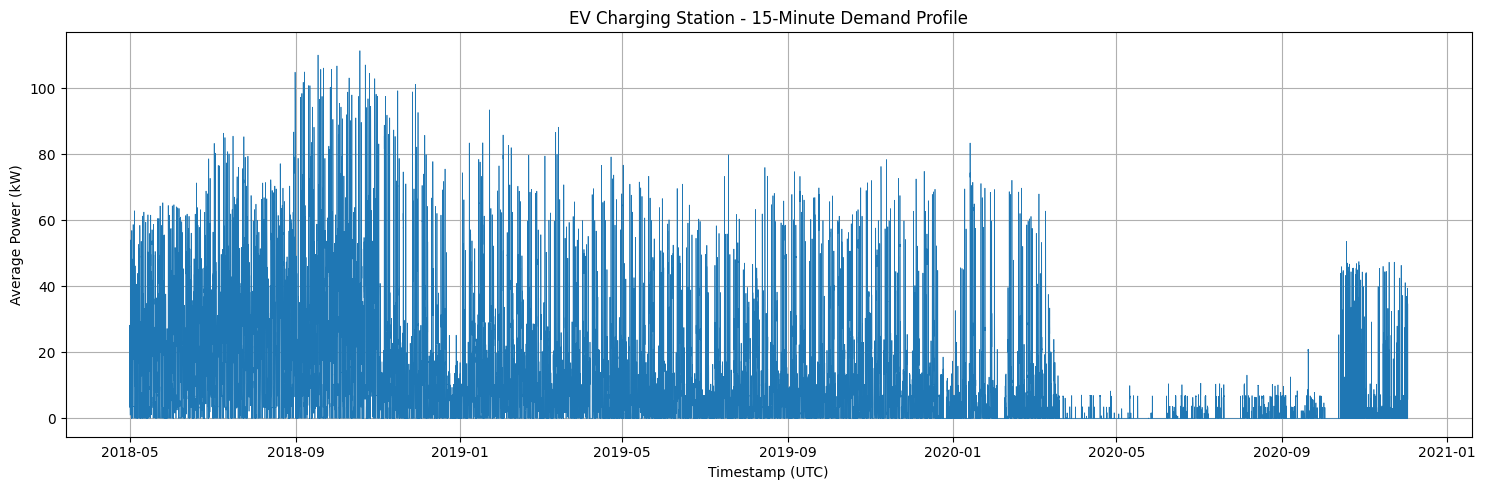

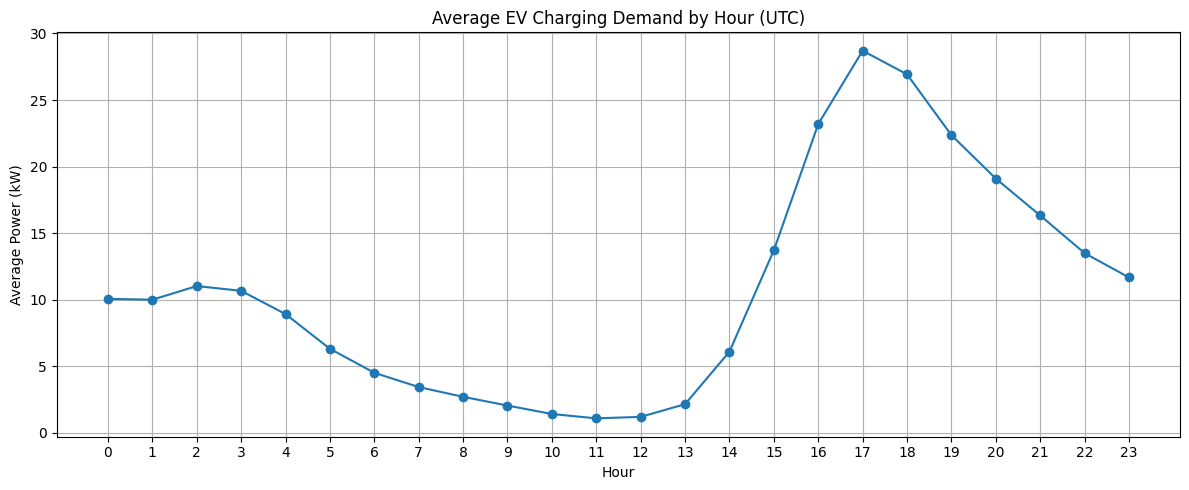

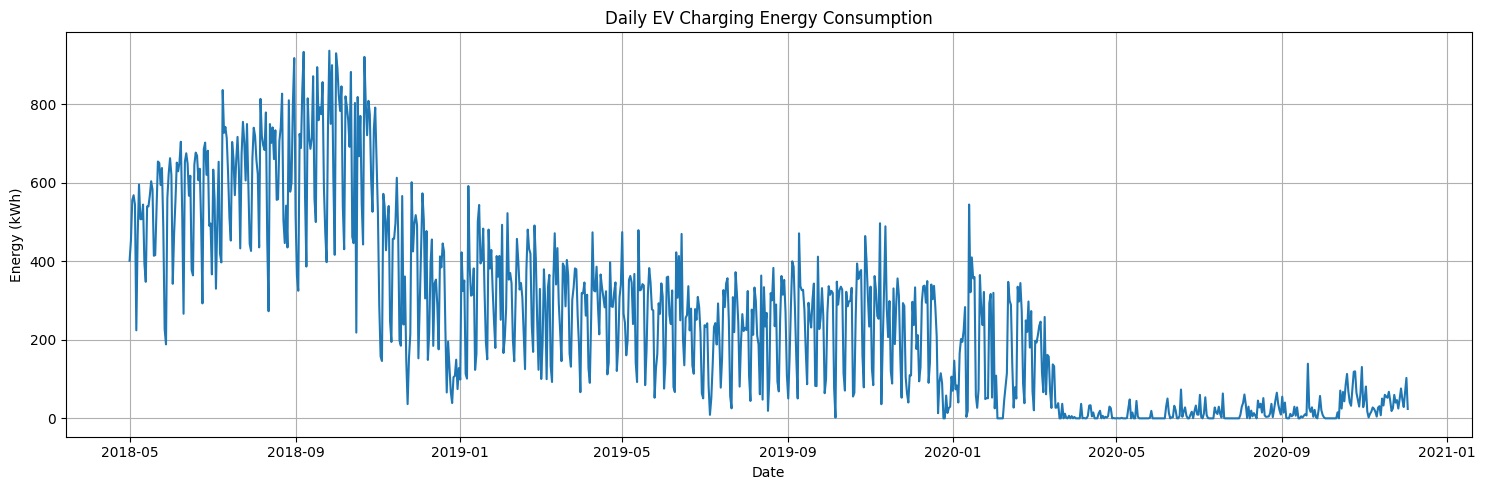

TOP 20 HIGHEST-DEMAND INTERVALS
                timestamp  energy_kwh  average_power_kw
2018-10-18 16:15:00+00:00   27.863527        111.454108
2018-09-17 16:00:00+00:00   27.534048        110.136190
2018-09-17 15:45:00+00:00   27.331410        109.325640
2018-10-18 16:00:00+00:00   27.009886        108.039546
2018-09-17 16:15:00+00:00   26.995619        107.982477
2018-10-22 16:00:00+00:00   26.783522        107.134089
2018-10-01 16:00:00+00:00   26.707390        106.829560
2018-09-21 16:15:00+00:00   26.547525        106.190101
2018-09-19 16:15:00+00:00   26.446857        105.787428
2018-09-27 16:30:00+00:00   26.446843        105.787373
2018-10-01 15:45:00+00:00   26.408026        105.632104
2018-10-22 16:15:00+00:00   26.294284        105.177137
2018-09-07 16:15:00+00:00   26.252038        105.008153
2018-08-31 15:45:00+00:00   26.233358        104.933433
2018-09-17 16:30:00+00:00   26.193391        104.773566
2018-10-25 16:15:00+00:00   26.155204        104.620816
2018-10-25 16:00

In [46]:

import matplotlib.pyplot as plt
import pandas as pd

df = station_profile_complete.copy()
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

# 1. Overall station demand profile
plt.figure(figsize=(15, 5))
plt.plot(df["timestamp"], df["average_power_kw"], linewidth=0.5)
plt.title("EV Charging Station - 15-Minute Demand Profile")
plt.xlabel("Timestamp (UTC)")
plt.ylabel("Average Power (kW)")
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. Average demand by hour
hourly = df.groupby("hour")["average_power_kw"].mean()

plt.figure(figsize=(12, 5))
plt.plot(hourly.index, hourly.values, marker="o")
plt.title("Average EV Charging Demand by Hour (UTC)")
plt.xlabel("Hour")
plt.ylabel("Average Power (kW)")
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Daily energy consumption
daily = df.groupby("date")["energy_kwh"].sum()

plt.figure(figsize=(15, 5))
plt.plot(pd.to_datetime(daily.index), daily.values)
plt.title("Daily EV Charging Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Energy (kWh)")
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Inspect highest-demand intervals
print("TOP 20 HIGHEST-DEMAND INTERVALS")
print(
    df.nlargest(20, "average_power_kw")[
        ["timestamp", "energy_kwh", "average_power_kw"]
    ].to_string(index=False)
)

# 5. Inspect days with zero energy
print("\nNumber of days with zero energy:",
      (daily == 0).sum())

print("\nNumber of days:", len(daily))


In [47]:

# MONTHLY DATA AVAILABILITY AND DEMAND ANALYSIS

df = station_profile_complete.copy()

df["timestamp"] = pd.to_datetime(
    df["timestamp"], utc=True
)

df["month_period"] = df["timestamp"].dt.to_period("M")

monthly_analysis = df.groupby("month_period").agg(
    total_energy_kwh=("energy_kwh", "sum"),
    average_power_kw=("average_power_kw", "mean"),
    peak_power_kw=("average_power_kw", "max"),
    zero_intervals=("energy_kwh", lambda x: (x == 0).sum()),
    total_intervals=("energy_kwh", "count"),
    active_intervals=("energy_kwh", lambda x: (x > 0).sum())
)

monthly_analysis["zero_percentage"] = (
    monthly_analysis["zero_intervals"] /
    monthly_analysis["total_intervals"] * 100
)

monthly_analysis["active_percentage"] = (
    monthly_analysis["active_intervals"] /
    monthly_analysis["total_intervals"] * 100
)

print(monthly_analysis.round(2).to_string())

monthly_analysis.to_csv(
    os.path.join(project_path, "monthly_demand_analysis.csv")
)


              total_energy_kwh  average_power_kw  peak_power_kw  zero_intervals  total_intervals  active_intervals  zero_percentage  active_percentage
month_period                                                                                                                                          
2018-05               15594.18             20.97          65.35             226             2974              2748             7.60              92.40
2018-06               17023.71             23.64          78.67             121             2880              2759             4.20              95.80
2018-07               18453.19             24.80          86.44             245             2976              2731             8.23              91.77
2018-08               20203.04             27.15         104.93             226             2976              2750             7.59              92.41
2018-09               20098.84             27.92         110.14             211             28

C:\Users\suhey\AppData\Local\Temp\ipykernel_24160\3655750229.py:9: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month_period"] = df["timestamp"].dt.to_period("M")


In [48]:

# VERIFY DATA COVERAGE AND ZERO-DEMAND PERIODS

df = station_profile_complete.copy()
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df["date"] = df["timestamp"].dt.date

print("FIRST TIMESTAMP:", df["timestamp"].min())
print("LAST TIMESTAMP:", df["timestamp"].max())

print("\nTOTAL OBSERVATION DAYS:", df["date"].nunique())

# Daily demand and active intervals
daily_check = df.groupby("date").agg(
    daily_energy_kwh=("energy_kwh", "sum"),
    active_intervals=("energy_kwh", lambda x: (x > 0).sum()),
    total_intervals=("energy_kwh", "count")
)

daily_check["active_percentage"] = (
    daily_check["active_intervals"] /
    daily_check["total_intervals"] * 100
)

# Zero-demand days
zero_days = daily_check[
    daily_check["daily_energy_kwh"] == 0
]

print("\nZERO-DEMAND DAYS:", len(zero_days))
print("\nZERO-DEMAND DAYS BY YEAR:")
print(zero_days.groupby(
    pd.to_datetime(zero_days.index.astype(str)).year
).size())

print("\nLAST 15 OBSERVED DAYS:")
print(daily_check.tail(15).round(2).to_string())

print("\nMONTHLY INTERVAL COUNTS:")
print(df.groupby(df["timestamp"].dt.strftime("%Y-%m")).size())


FIRST TIMESTAMP: 2018-05-01 00:30:00+00:00
LAST TIMESTAMP: 2020-12-03 01:00:00+00:00

TOTAL OBSERVATION DAYS: 948

ZERO-DEMAND DAYS: 87

ZERO-DEMAND DAYS BY YEAR:
date
2019     2
2020    85
dtype: int64

LAST 15 OBSERVED DAYS:
            daily_energy_kwh  active_intervals  total_intervals  active_percentage
date                                                                              
2020-11-19             67.72                24               96              25.00
2020-11-20             44.92                40               96              41.67
2020-11-21             18.66                11               96              11.46
2020-11-22             25.59                19               96              19.79
2020-11-23             59.67                44               96              45.83
2020-11-24             40.03                31               96              32.29
2020-11-25             46.38                18               96              18.75
2020-11-26             25.

In [49]:

# PREPARE FORECASTING DATASET

import pandas as pd
import os

df = station_profile_complete.copy()

df["timestamp"] = pd.to_datetime(
    df["timestamp"], utc=True
)

df["date"] = df["timestamp"].dt.date

# Count observations per day
daily_counts = df.groupby("date").size()

# Keep only complete days (96 intervals per day)
complete_dates = daily_counts[daily_counts == 96].index

forecast_df = df[df["date"].isin(complete_dates)].copy()

forecast_df = forecast_df.sort_values("timestamp").reset_index(drop=True)

# Verify continuity
forecast_df["time_difference"] = (
    forecast_df["timestamp"].diff()
)

print("========== FORECAST DATASET ==========")
print("Original observations:", len(df))
print("Complete days:", len(complete_dates))
print("Forecast observations:", len(forecast_df))
print("First timestamp:", forecast_df["timestamp"].min())
print("Last timestamp:", forecast_df["timestamp"].max())
print("Missing 15-minute gaps:",
      (forecast_df["time_difference"] != pd.Timedelta(minutes=15)).sum() - 1)
print("Total energy (kWh):", forecast_df["energy_kwh"].sum())

# Save
forecast_df = forecast_df.drop(columns="time_difference")

forecast_path = os.path.join(
    project_path, "EV_forecasting_dataset.csv"
)

forecast_df.to_csv(forecast_path, index=False)

print("\nSaved to:", forecast_path)


========== FORECAST DATASET ==========
Original observations: 90915
Complete days: 946
Forecast observations: 90816
First timestamp: 2018-05-02 00:00:00+00:00
Last timestamp: 2020-12-02 23:45:00+00:00
Missing 15-minute gaps: 0
Total energy (kWh): 242981.268037853

Saved to: C:\EV_Charging_Project\EV_forecasting_dataset.csv


In [50]:

# FORECASTING FEATURE ENGINEERING

import pandas as pd
import numpy as np
import os

df = forecast_df.copy()

df["timestamp"] = pd.to_datetime(
    df["timestamp"], utc=True
)

df = df.sort_values("timestamp").reset_index(drop=True)

# Target variable
df["target_power_kw"] = df["average_power_kw"]

# Time features
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek
df["month"] = df["timestamp"].dt.month
df["day_of_year"] = df["timestamp"].dt.dayofyear
df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

# Cyclical time features
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["day_sin"] = np.sin(
    2 * np.pi * df["day_of_week"] / 7
)
df["day_cos"] = np.cos(
    2 * np.pi * df["day_of_week"] / 7
)

# Lag features: previous demand observations
df["lag_1"] = df["target_power_kw"].shift(1)
df["lag_4"] = df["target_power_kw"].shift(4)
df["lag_96"] = df["target_power_kw"].shift(96)
df["lag_672"] = df["target_power_kw"].shift(672)

# Rolling statistics using only past observations
df["rolling_mean_4"] = (
    df["target_power_kw"].shift(1).rolling(4).mean()
)

df["rolling_mean_96"] = (
    df["target_power_kw"].shift(1).rolling(96).mean()
)

# Remove rows with unavailable lag features
model_df = df.dropna().reset_index(drop=True)

print("Original observations:", len(df))
print("Model observations:", len(model_df))
print("Features created:", len(model_df.columns))
print("\nFeature columns:")
print(model_df.columns.tolist())

# Save
feature_path = os.path.join(
    project_path,
    "EV_forecasting_features.csv"
)

model_df.to_csv(feature_path, index=False)

print("\nSaved to:", feature_path)


Original observations: 90816
Model observations: 90144
Features created: 20

Feature columns:
['timestamp', 'energy_kwh', 'average_power_kw', 'date', 'hour', 'day_of_week', 'month', 'target_power_kw', 'day_of_year', 'is_weekend', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'lag_1', 'lag_4', 'lag_96', 'lag_672', 'rolling_mean_4', 'rolling_mean_96']

Saved to: C:\EV_Charging_Project\EV_forecasting_features.csv


In [51]:

# CHRONOLOGICAL TRAIN-TEST SPLIT

from sklearn.model_selection import train_test_split

# Target
target = "target_power_kw"

# Features used for forecasting
features = [
    "hour",
    "day_of_week",
    "month",
    "day_of_year",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "lag_1",
    "lag_4",
    "lag_96",
    "lag_672",
    "rolling_mean_4",
    "rolling_mean_96"
]

X = model_df[features]
y = model_df[target]

# Chronological 80:20 split
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Corresponding timestamps
train_dates = model_df["timestamp"].iloc[:split_index]
test_dates = model_df["timestamp"].iloc[split_index:]

print("========== TRAIN-TEST SPLIT ==========")

print("Total observations:", len(model_df))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining start:", train_dates.min())
print("Training end:", train_dates.max())

print("\nTesting start:", test_dates.min())
print("Testing end:", test_dates.max())

print("\nTraining percentage:",
      round(len(X_train) / len(model_df) * 100, 2))

print("Testing percentage:",
      round(len(X_test) / len(model_df) * 100, 2))

print("\nFeature count:", len(features))


========== TRAIN-TEST SPLIT ==========
Total observations: 90144
Training observations: 72115
Testing observations: 18029

Training start: 2018-05-09 00:00:00+00:00
Training end: 2020-05-29 04:30:00+00:00

Testing start: 2020-05-29 04:45:00+00:00
Testing end: 2020-12-02 23:45:00+00:00

Training percentage: 80.0
Testing percentage: 20.0

Feature count: 15


In [52]:

# SEASONAL NAIVE FORECASTING - 15 MINUTE DATA

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict using demand from the same time last week
y_pred_naive = model_df["target_power_kw"].iloc[
    split_index - 672 : len(model_df) - 672
].to_numpy()

y_actual = y_test.to_numpy()

# Evaluation metrics
mae = mean_absolute_error(y_actual, y_pred_naive)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred_naive)
)

# Weighted Absolute Percentage Error
wape = (
    np.sum(np.abs(y_actual - y_pred_naive)) /
    np.sum(np.abs(y_actual))
) * 100

print("========== SEASONAL NAIVE RESULTS ==========")
print("MAE:", round(mae, 4), "kW")
print("RMSE:", round(rmse, 4), "kW")
print("WAPE:", round(wape, 2), "%")

# Store baseline results
baseline_results = pd.DataFrame([{
    "Model": "Seasonal Naive",
    "MAE": mae,
    "RMSE": rmse,
    "WAPE": wape
}])

print("\n", baseline_results)


========== SEASONAL NAIVE RESULTS ==========
MAE: 1.687 kW
RMSE: 5.2761 kW
WAPE: 169.97 %

             Model      MAE     RMSE        WAPE
0  Seasonal Naive  1.68697  5.27606  169.971776


In [53]:

# RANDOM FOREST REGRESSION

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Initialize model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")

# Train
rf_model.fit(X_train, y_train)

print("Training completed.")

# Predict
y_pred_rf = rf_model.predict(X_test)

# Evaluation
rf_mae = mean_absolute_error(y_test, y_pred_rf)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

rf_wape = (
    np.sum(np.abs(y_test.to_numpy() - y_pred_rf)) /
    np.sum(np.abs(y_test.to_numpy()))
) * 100

print("\n========== RANDOM FOREST RESULTS ==========")
print("MAE:", round(rf_mae, 4), "kW")
print("RMSE:", round(rf_rmse, 4), "kW")
print("WAPE:", round(rf_wape, 2), "%")

# Compare with baseline
results = pd.DataFrame([
    {
        "Model": "Seasonal Naive",
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    },
    {
        "Model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "WAPE": rf_wape
    }
])

print("\n========== MODEL COMPARISON ==========")
print(results.round(4).to_string(index=False))


Training Random Forest...
Training completed.

========== RANDOM FOREST RESULTS ==========
MAE: 0.615 kW
RMSE: 2.9167 kW
WAPE: 61.96 %

========== MODEL COMPARISON ==========
         Model   MAE   RMSE     WAPE
Seasonal Naive 1.687 5.2761 169.9718
 Random Forest 0.615 2.9167  61.9637


In [54]:
try:
    import xgboost
    print("XGBoost version:", xgboost.__version__)
except ImportError:
    print("XGBoost is not installed.")

XGBoost is not installed.


In [55]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Initialize XGBoost
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost...")

xgb_model.fit(X_train, y_train)

print("Training completed.")

# Predictions
y_pred_xgb = xgb_model.predict(X_test)

# Evaluation
xgb_mae = mean_absolute_error(y_test, y_pred_xgb)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb)
)

xgb_wape = (
    np.sum(np.abs(y_test.to_numpy() - y_pred_xgb)) /
    np.sum(np.abs(y_test.to_numpy()))
) * 100

print("\n========== XGBOOST RESULTS ==========")
print("MAE:", round(xgb_mae, 4), "kW")
print("RMSE:", round(xgb_rmse, 4), "kW")
print("WAPE:", round(xgb_wape, 2), "%")

# Compare all models
results = pd.DataFrame([
    {"Model": "Seasonal Naive",
     "MAE": mae, "RMSE": rmse, "WAPE": wape},

    {"Model": "Random Forest",
     "MAE": rf_mae, "RMSE": rf_rmse, "WAPE": rf_wape},

    {"Model": "XGBoost",
     "MAE": xgb_mae, "RMSE": xgb_rmse, "WAPE": xgb_wape}
])

print("\n========== FINAL MODEL COMPARISON ==========")
print(results.round(4).to_string(index=False))


ModuleNotFoundError: No module named 'xgboost'

In [56]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.3/48.9 MB 9.2 MB/s eta 0:00:06
   --- ------------------------------------ 4.2/48.9 MB 12.3 MB/s eta 0:00:04
   ------ --------------------------------- 7.9/48.9 MB 14.3 MB/s eta 0:00:03
   --------- ------------------------------ 12.1/48.9 MB 16.2 MB/s eta 0:00:03
   ------------- -------------------------- 16.0/48.9 MB 16.5 MB/s eta 0:00:02
   ---------------- ----------------------- 19.7/48.9 MB 16.8 MB/s eta 0:00:02
   ------------------- -------------------- 23.9/48.9 MB 17.3 MB/s eta 0:00:02
   ----------------------- ---------------- 28.6/48.9 MB 17.9 MB/s eta 0:00:02
   -------------------------- ------------- 32.5/48.9 MB 18.1 MB/s eta 0:00:01
   ------------------------------ --------- 37.2/48.9 MB 18.5 MB/s eta 0:00:01
   ---------------------------------- ----- 41.7/48.9 MB 18.7 MB/s eta 0:0


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [57]:
import xgboost
print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [58]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Initialize XGBoost model
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost...")

# Train model
xgb_model.fit(X_train, y_train)

print("Training completed.")

# Generate predictions
y_pred_xgb = xgb_model.predict(X_test)

# Calculate metrics
xgb_mae = mean_absolute_error(y_test, y_pred_xgb)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb)
)

xgb_wape = (
    np.sum(np.abs(y_test.to_numpy() - y_pred_xgb)) /
    np.sum(np.abs(y_test.to_numpy()))
) * 100

print("\n========== XGBOOST RESULTS ==========")
print("MAE:", round(xgb_mae, 4), "kW")
print("RMSE:", round(xgb_rmse, 4), "kW")
print("WAPE:", round(xgb_wape, 2), "%")

# Compare all models
results = pd.DataFrame([
    {
        "Model": "Seasonal Naive",
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    },
    {
        "Model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "WAPE": rf_wape
    },
    {
        "Model": "XGBoost",
        "MAE": xgb_mae,
        "RMSE": xgb_rmse,
        "WAPE": xgb_wape
    }
])

print("\n========== MODEL COMPARISON ==========")
print(results.round(4).to_string(index=False))


Training XGBoost...
Training completed.

========== XGBOOST RESULTS ==========
MAE: 0.5907 kW
RMSE: 2.8854 kW
WAPE: 59.51 %

========== MODEL COMPARISON ==========
         Model    MAE   RMSE     WAPE
Seasonal Naive 1.6870 5.2761 169.9718
 Random Forest 0.6150 2.9167  61.9637
       XGBoost 0.5907 2.8854  59.5137


========== ZERO VS ACTIVE DEMAND ==========
               observations  actual_mean_kw  predicted_mean_kw     MAE
demand_type                                                           
Active demand          2679          6.6793             6.5872  3.0249
Zero demand           15350          0.0000             0.1440  0.1658

========== MONTHLY MODEL PERFORMANCE ==========
         observations  actual_energy_proxy     MAE  WAPE_percent
month                                                           
2020-05         269.0               0.0000  0.0348           NaN
2020-06        2880.0            1505.4441  0.1659       31.7323
2020-07        2976.0            1234.7379  0.1649       39.7463
2020-08        2976.0            2802.0612  0.3077       32.6813
2020-09        2880.0            2282.3579  0.3006       37.9256
2020-10        2976.0            5007.2407  1.4304       85.0167
2020-11        2880.0            4389.9780  1.0876       71.3513
2020-12         192.0             671.

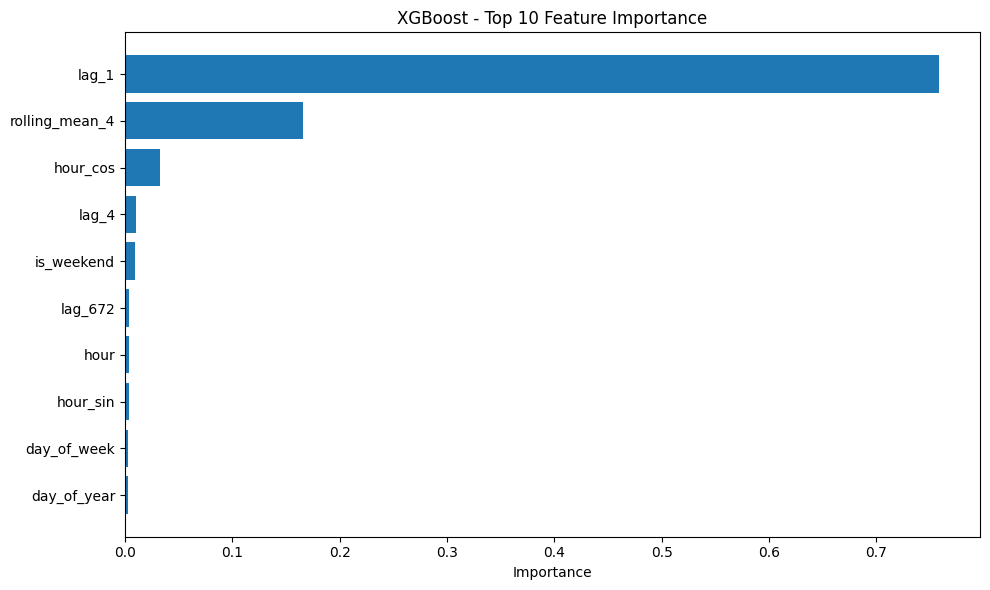

In [59]:

# XGBOOST - DETAILED ERROR ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create evaluation dataframe
evaluation_df = pd.DataFrame({
    "timestamp": model_df["timestamp"].iloc[split_index:].to_numpy(),
    "actual_kw": y_test.to_numpy(),
    "predicted_kw": y_pred_xgb
})

evaluation_df["absolute_error"] = (
    evaluation_df["actual_kw"] -
    evaluation_df["predicted_kw"]
).abs()

evaluation_df["month"] = (
    pd.to_datetime(evaluation_df["timestamp"]).dt.strftime("%Y-%m")
)

evaluation_df["demand_type"] = np.where(
    evaluation_df["actual_kw"] == 0,
    "Zero demand",
    "Active demand"
)

# 1. Zero vs active demand performance
print("========== ZERO VS ACTIVE DEMAND ==========")

demand_analysis = evaluation_df.groupby("demand_type").agg(
    observations=("actual_kw", "count"),
    actual_mean_kw=("actual_kw", "mean"),
    predicted_mean_kw=("predicted_kw", "mean"),
    MAE=("absolute_error", "mean")
)

print(demand_analysis.round(4))

# 2. Monthly forecasting performance
print("\n========== MONTHLY MODEL PERFORMANCE ==========")

monthly_results = evaluation_df.groupby("month").apply(
    lambda g: pd.Series({
        "observations": len(g),
        "actual_energy_proxy": g["actual_kw"].sum(),
        "MAE": g["absolute_error"].mean(),
        "WAPE_percent": (
            g["absolute_error"].sum() /
            g["actual_kw"].abs().sum() * 100
            if g["actual_kw"].abs().sum() > 0 else np.nan
        )
    }),
    include_groups=False
)

print(monthly_results.round(4))

# 3. Negative prediction check
print("\n========== PREDICTION CHECK ==========")
print("Negative predictions:", (y_pred_xgb < 0).sum())
print("Minimum prediction:", y_pred_xgb.min())
print("Maximum prediction:", y_pred_xgb.max())

# 4. Feature importance
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": xgb_model.feature_importances_
}).sort_values("importance", ascending=False)

print("\n========== TOP 10 IMPORTANT FEATURES ==========")
print(feature_importance.head(10).to_string(index=False))

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance.head(10)["feature"][::-1],
    feature_importance.head(10)["importance"][::-1]
)
plt.title("XGBoost - Top 10 Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [60]:

# NON-NEGATIVE XGBOOST PREDICTIONS

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Apply physical lower bound: power demand cannot be negative
y_pred_xgb_clipped = np.maximum(y_pred_xgb, 0)

# Recalculate evaluation metrics
clipped_mae = mean_absolute_error(
    y_test, y_pred_xgb_clipped
)

clipped_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb_clipped)
)

clipped_wape = (
    np.sum(np.abs(y_test.to_numpy() - y_pred_xgb_clipped)) /
    np.sum(np.abs(y_test.to_numpy()))
) * 100

print("========== NON-NEGATIVE XGBOOST RESULTS ==========")
print("Original MAE:", round(xgb_mae, 4))
print("Clipped MAE:", round(clipped_mae, 4))

print("\nOriginal RMSE:", round(xgb_rmse, 4))
print("Clipped RMSE:", round(clipped_rmse, 4))

print("\nOriginal WAPE:", round(xgb_wape, 2), "%")
print("Clipped WAPE:", round(clipped_wape, 2), "%")

print("\nNegative predictions before correction:",
      (y_pred_xgb < 0).sum())

print("Negative predictions after correction:",
      (y_pred_xgb_clipped < 0).sum())

# Updated model comparison
final_comparison = pd.DataFrame([
    {
        "Model": "Seasonal Naive",
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    },
    {
        "Model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "WAPE": rf_wape
    },
    {
        "Model": "XGBoost (clipped)",
        "MAE": clipped_mae,
        "RMSE": clipped_rmse,
        "WAPE": clipped_wape
    }
])

print("\n========== UPDATED MODEL COMPARISON ==========")
print(final_comparison.round(4).to_string(index=False))


========== NON-NEGATIVE XGBOOST RESULTS ==========
Original MAE: 0.5907
Clipped MAE: 0.5813

Original RMSE: 2.8854
Clipped RMSE: 2.8852

Original WAPE: 59.51 %
Clipped WAPE: 58.57 %

Negative predictions before correction: 6244
Negative predictions after correction: 0

========== UPDATED MODEL COMPARISON ==========
            Model    MAE   RMSE     WAPE
   Seasonal Naive 1.6870 5.2761 169.9718
    Random Forest 0.6150 2.9167  61.9637
XGBoost (clipped) 0.5813 2.8852  58.5684


In [61]:
# INSPECT SESSION DATA FOR ENERGY MANAGEMENT

print("SESSION DATA SHAPE:", clean_sessions.shape)

print("\nAVAILABLE COLUMNS:")
print(clean_sessions.columns.tolist())

print("\nFIRST FIVE RECORDS:")
print(clean_sessions.head())

print("\nSESSION ENERGY STATISTICS:")
print(clean_sessions["clean_energy_kwh"].describe())

print("\nSESSION DURATION STATISTICS (minutes):")

duration_minutes = (
    clean_sessions["departure_time"] -
    clean_sessions["arrival_time"]
).dt.total_seconds() / 60

print(duration_minutes.describe())

print("\nMISSING ARRIVAL TIMES:",
      clean_sessions["arrival_time"].isna().sum())

print("MISSING DEPARTURE TIMES:",
      clean_sessions["departure_time"].isna().sum())

SESSION DATA SHAPE: (29270, 8)

AVAILABLE COLUMNS:
['session_id', 'clean_energy_kwh', 'power_energy_kwh', 'coverage_pct', 'relative_difference_pct', 'decision', 'arrival_time', 'departure_time']

FIRST FIVE RECORDS:
                                      session_id  clean_energy_kwh  \
0  2-39-123-23-2018-05-10T16-38-59-635468.csv.gz          0.006796   
1  2-39-123-23-2018-05-10T16-49-02-592477.csv.gz          1.985741   
2  2-39-123-23-2018-05-11T13-28-04-355442.csv.gz          5.293421   
3  2-39-123-23-2018-05-11T16-51-01-189882.csv.gz          0.014838   
4  2-39-123-23-2018-05-11T17-01-11-962363.csv.gz          0.006823   

   power_energy_kwh  coverage_pct  relative_difference_pct  \
0          0.007016         100.0                 3.147393   
1          1.991232         100.0                 0.275751   
2          5.315802         100.0                 0.421022   
3          0.016407         100.0                 9.564040   
4          0.006205         100.0                 9.0

In [62]:

# EV SESSION AVAILABILITY WINDOW ANALYSIS

import pandas as pd
import numpy as np

sessions = clean_sessions.copy()

sessions["duration_hours"] = (
    sessions["departure_time"] -
    sessions["arrival_time"]
).dt.total_seconds() / 3600

sessions["average_required_power_kw"] = (
    sessions["clean_energy_kwh"] /
    sessions["duration_hours"]
)

print("========== SESSION DURATION ANALYSIS ==========")

print("\nDuration statistics (hours):")
print(sessions["duration_hours"].describe().round(2))

print("\nSessions exceeding duration thresholds:")

for hours in [8, 12, 24, 48, 72]:
    count = (sessions["duration_hours"] > hours).sum()
    print(f"More than {hours} hours: {count}")

print("\n========== REQUIRED AVERAGE POWER ==========")

print(
    sessions["average_required_power_kw"]
    .describe()
    .round(3)
)

print("\n========== LONGEST 15 SESSIONS ==========")

print(
    sessions.nlargest(15, "duration_hours")[
        [
            "session_id",
            "clean_energy_kwh",
            "duration_hours",
            "average_required_power_kw"
        ]
    ].to_string(index=False)
)


========== SESSION DURATION ANALYSIS ==========

Duration statistics (hours):
count    29270.00
mean         5.52
std          6.23
min          0.00
25%          1.71
50%          4.59
75%          8.45
max        303.48
Name: duration_hours, dtype: float64

Sessions exceeding duration thresholds:
More than 8 hours: 8521
More than 12 hours: 1414
More than 24 hours: 237
More than 48 hours: 69
More than 72 hours: 32

========== REQUIRED AVERAGE POWER ==========
count    29270.000
mean         2.350
std          2.510
min          0.000
25%          0.765
50%          1.606
75%          3.296
max         46.708
Name: average_required_power_kw, dtype: float64

========== LONGEST 15 SESSIONS ==========
                                   session_id  clean_energy_kwh  duration_hours  average_required_power_kw
2-39-79-381-2019-10-03T04-58-33-329226.csv.gz          7.987079      303.483333                   0.026318
2-39-127-19-2018-11-09T10-33-02-342605.csv.gz          1.479438      245.26916

In [63]:

# PREPARE EV SESSIONS FOR OPTIMIZATION

import pandas as pd
import numpy as np

sessions_opt = clean_sessions.copy()

sessions_opt["duration_hours"] = (
    sessions_opt["departure_time"] -
    sessions_opt["arrival_time"]
).dt.total_seconds() / 3600

# Initial scenario assumptions
MAX_DURATION_HOURS = 24
MAX_CHARGING_POWER_KW = 7.2
CHARGING_EFFICIENCY = 0.95

# Screen long availability windows
sessions_opt = sessions_opt[
    (sessions_opt["duration_hours"] > 0) &
    (sessions_opt["duration_hours"] <= MAX_DURATION_HOURS)
].copy()

# Required grid-side energy, accounting for efficiency
sessions_opt["grid_energy_kwh"] = (
    sessions_opt["clean_energy_kwh"] /
    CHARGING_EFFICIENCY
)

# Maximum energy that can be supplied within availability window
sessions_opt["maximum_deliverable_kwh"] = (
    MAX_CHARGING_POWER_KW *
    sessions_opt["duration_hours"]
)

# Check feasibility
sessions_opt["feasible"] = (
    sessions_opt["grid_energy_kwh"] <=
    sessions_opt["maximum_deliverable_kwh"]
)

print("========== OPTIMIZATION SESSION SCREENING ==========")

print("Original sessions:", len(clean_sessions))
print("Sessions within 24 hours:", len(sessions_opt))
print("Excluded long/zero-duration sessions:",
      len(clean_sessions) - len(sessions_opt))

print("\nFeasible sessions:",
      sessions_opt["feasible"].sum())

print("Infeasible sessions:",
      (~sessions_opt["feasible"]).sum())

print("\nTotal required grid energy:",
      round(sessions_opt["grid_energy_kwh"].sum(), 2), "kWh")

print("\nAverage required charging power:",
      round(
          sessions_opt["grid_energy_kwh"].sum() /
          sessions_opt["duration_hours"].sum(), 3
      ), "kW")

print("\nFeasibility percentage:",
      round(sessions_opt["feasible"].mean() * 100, 2), "%")


========== OPTIMIZATION SESSION SCREENING ==========
Original sessions: 29270
Sessions within 24 hours: 29033
Excluded long/zero-duration sessions: 237

Feasible sessions: 28792
Infeasible sessions: 241

Total required grid energy: 252282.24 kWh

Average required charging power: 1.678 kW

Feasibility percentage: 99.17 %


In [64]:

# SELECT A SMALL COHORT FOR OPTIMIZATION

import pandas as pd
import numpy as np

# Keep feasible sessions
candidate_sessions = sessions_opt[
    sessions_opt["feasible"]
].copy()

candidate_sessions["arrival_date"] = (
    candidate_sessions["arrival_time"].dt.date
)

# Find a day with at least 20 feasible arrivals
daily_counts = candidate_sessions.groupby(
    "arrival_date"
).size()

eligible_days = daily_counts[daily_counts >= 20]

print("Days with at least 20 feasible sessions:",
      len(eligible_days))

if len(eligible_days) == 0:
    print("No suitable day found. We need to adjust the cohort size.")
else:
    selected_day = eligible_days.index[0]

    optimization_sample = (
        candidate_sessions[
            candidate_sessions["arrival_date"] == selected_day
        ]
        .sort_values("arrival_time")
        .head(20)
        .copy()
        .reset_index(drop=True)
    )

    print("\nSelected day:", selected_day)
    print("Selected sessions:", len(optimization_sample))

    print("\nSample session information:")
    print(
        optimization_sample[
            [
                "arrival_time",
                "departure_time",
                "clean_energy_kwh",
                "grid_energy_kwh",
                "duration_hours"
            ]
        ].to_string(index=False)
    )

    print("\nTotal grid energy required:",
          round(optimization_sample["grid_energy_kwh"].sum(), 3),
          "kWh")


Days with at least 20 feasible sessions: 513

Selected day: 2018-05-01
Selected sessions: 20

Sample session information:
             arrival_time            departure_time  clean_energy_kwh  grid_energy_kwh  duration_hours
2018-05-01 00:31:59+00:00 2018-05-01 02:10:54+00:00          5.796034         6.101088        1.648611
2018-05-01 00:43:31+00:00 2018-05-01 04:21:06+00:00         12.865918        13.543072        3.626389
2018-05-01 01:00:22+00:00 2018-05-01 07:56:26+00:00         13.917886        14.650407        6.934444
2018-05-01 01:14:30+00:00 2018-05-01 01:23:58+00:00          0.861776         0.907133        0.157778
2018-05-01 01:27:39+00:00 2018-05-01 01:45:34+00:00          1.957970         2.061021        0.298611
2018-05-01 01:31:03+00:00 2018-05-01 02:09:44+00:00          1.863367         1.961439        0.644722
2018-05-01 01:35:22+00:00 2018-05-01 03:11:51+00:00         10.898481        11.472085        1.608056
2018-05-01 01:48:07+00:00 2018-05-01 03:20:51+00:00   

In [65]:

# 15-MINUTE LINEAR PROGRAMMING MODEL
# Objective: Minimize maximum aggregate charging demand

import numpy as np
import pandas as pd
from scipy.optimize import linprog
from scipy.sparse import lil_matrix

# -----------------------------
# 1. MODEL PARAMETERS
# -----------------------------

DT_HOURS = 0.25
MAX_POWER_KW = 7.2

sessions = optimization_sample.copy().reset_index(drop=True)

# Create 15-minute time intervals covering all sessions
start_time = sessions["arrival_time"].min().floor("15min")
end_time = sessions["departure_time"].max().ceil("15min")

time_slots = pd.date_range(
    start=start_time,
    end=end_time,
    freq="15min",
    inclusive="left"
)

n_sessions = len(sessions)
n_slots = len(time_slots)

# -----------------------------
# 2. CREATE SESSION-SLOT VARIABLES
# -----------------------------

# Each variable represents energy (kWh)
# delivered to one vehicle during one interval.

variables = []
variable_bounds = []

for i, session in sessions.iterrows():

    for j, slot_start in enumerate(time_slots):

        slot_end = slot_start + pd.Timedelta(minutes=15)

        overlap_start = max(
            session["arrival_time"], slot_start
        )

        overlap_end = min(
            session["departure_time"], slot_end
        )

        overlap_hours = (
            overlap_end - overlap_start
        ).total_seconds() / 3600

        if overlap_hours > 0:

            max_energy = MAX_POWER_KW * overlap_hours

            variables.append((i, j, overlap_hours))

            variable_bounds.append((0, max_energy))

n_energy_variables = len(variables)

# Last variable is the maximum station demand P_peak
n_variables = n_energy_variables + 1
peak_index = n_energy_variables

# -----------------------------
# 3. ENERGY REQUIREMENT CONSTRAINTS
# -----------------------------

A_eq = lil_matrix((n_sessions, n_variables))
b_eq = sessions["grid_energy_kwh"].to_numpy()

for k, (i, j, overlap_hours) in enumerate(variables):
    A_eq[i, k] = 1

# -----------------------------
# 4. PEAK DEMAND CONSTRAINTS
# -----------------------------

A_ub = lil_matrix((n_slots, n_variables))
b_ub = np.zeros(n_slots)

for k, (i, j, overlap_hours) in enumerate(variables):

    A_ub[j, k] = 1

    # Total interval energy <= peak power * interval duration
    A_ub[j, peak_index] = -DT_HOURS

# -----------------------------
# 5. OBJECTIVE FUNCTION
# -----------------------------

c = np.zeros(n_variables)
c[peak_index] = 1

bounds = variable_bounds + [(0, None)]

# -----------------------------
# 6. SOLVE THE LINEAR PROGRAM
# -----------------------------

result = linprog(
    c,
    A_ub=A_ub.tocsr(),
    b_ub=b_ub,
    A_eq=A_eq.tocsr(),
    b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

if not result.success:
    raise RuntimeError(
        "Optimization failed: " + result.message
    )

# -----------------------------
# 7. EXTRACT OPTIMIZED SCHEDULE
# -----------------------------

optimized_energy = np.zeros(n_slots)

for k, (i, j, overlap_hours) in enumerate(variables):
    optimized_energy[j] += result.x[k]

optimized_power = optimized_energy / DT_HOURS

# -----------------------------
# 8. UNCONTROLLED BASELINE
# -----------------------------

# Vehicles charge immediately upon arrival,
# at maximum power until their energy is delivered.

baseline_energy = np.zeros(n_slots)

for i, session in sessions.iterrows():

    remaining_energy = session["grid_energy_kwh"]

    session_variables = [
        (j, overlap_hours)
        for (vehicle_i, j, overlap_hours) in variables
        if vehicle_i == i
    ]

    for j, overlap_hours in session_variables:

        available_energy = MAX_POWER_KW * overlap_hours

        delivered_energy = min(
            remaining_energy,
            available_energy
        )

        baseline_energy[j] += delivered_energy
        remaining_energy -= delivered_energy

        if remaining_energy <= 1e-8:
            break

    if remaining_energy > 1e-6:
        raise RuntimeError(
            f"Baseline could not charge session {i}"
        )

baseline_power = baseline_energy / DT_HOURS

# -----------------------------
# 9. PERFORMANCE COMPARISON
# -----------------------------

baseline_peak = baseline_power.max()
optimized_peak = optimized_power.max()

peak_reduction = (
    (baseline_peak - optimized_peak) / baseline_peak
) * 100

print("========== OPTIMIZATION RESULTS ==========")

print("Solver status:", result.message)
print("Number of EV sessions:", n_sessions)
print("Number of time intervals:", n_slots)

print("\nTotal required energy:",
      round(sessions["grid_energy_kwh"].sum(), 3), "kWh")

print("\nUncontrolled peak demand:",
      round(baseline_peak, 3), "kW")

print("Optimized peak demand:",
      round(optimized_peak, 3), "kW")

print("Peak demand reduction:",
      round(peak_reduction, 2), "%")

print("\nUncontrolled energy delivered:",
      round(baseline_energy.sum(), 3), "kWh")

print("Optimized energy delivered:",
      round(optimized_energy.sum(), 3), "kWh")

# -----------------------------
# 10. CREATE RESULT DATAFRAME
# -----------------------------

optimization_results = pd.DataFrame({
    "timestamp": time_slots,
    "uncontrolled_power_kw": baseline_power,
    "optimized_power_kw": optimized_power
})

print("\nFirst 10 schedule intervals:")
print(optimization_results.head(10).to_string(index=False))


========== OPTIMIZATION RESULTS ==========
Solver status: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Number of EV sessions: 20
Number of time intervals: 102

Total required energy: 160.687 kWh

Uncontrolled peak demand: 40.093 kW
Optimized peak demand: 14.082 kW
Peak demand reduction: 64.88 %

Uncontrolled energy delivered: 160.687 kWh
Optimized energy delivered: 160.687 kWh

First 10 schedule intervals:
                timestamp  uncontrolled_power_kw  optimized_power_kw
2018-05-01 00:30:00+00:00               6.960000            6.960000
2018-05-01 00:45:00+00:00              14.400000           14.081713
2018-05-01 01:00:00+00:00              21.664000           14.081713
2018-05-01 01:15:00+00:00              22.672885           14.081713
2018-05-01 01:30:00+00:00              32.836085           14.081713
2018-05-01 01:45:00+00:00              28.453754           14.081713
2018-05-01 02:00:00+00:00              30.968000           14.081713
2018-05-01 02:15:00

In [66]:

# VALIDATE OPTIMIZED CHARGING SCHEDULE

# Reconstruct energy allocated to each vehicle and interval
vehicle_energy = np.zeros(n_sessions)
vehicle_max_power = np.zeros(n_sessions)

for k, (i, j, overlap_hours) in enumerate(variables):

    allocated_energy = result.x[k]

    vehicle_energy[i] += allocated_energy

    if overlap_hours > 0:
        actual_charging_power = allocated_energy / overlap_hours

        vehicle_max_power[i] = max(
            vehicle_max_power[i],
            actual_charging_power
        )

# Compare delivered and required energy
required_energy = sessions["grid_energy_kwh"].to_numpy()

energy_errors = np.abs(vehicle_energy - required_energy)

validation_df = pd.DataFrame({
    "session": np.arange(1, n_sessions + 1),
    "required_energy_kwh": required_energy,
    "delivered_energy_kwh": vehicle_energy,
    "energy_error_kwh": energy_errors,
    "maximum_charging_power_kw": vehicle_max_power
})

print("========== SESSION-LEVEL VALIDATION ==========")

print("All sessions receive required energy:",
      np.all(energy_errors < 1e-5))

print("Maximum session energy error:",
      round(energy_errors.max(), 8), "kWh")

print("All sessions respect 7.2 kW limit:",
      np.all(vehicle_max_power <= MAX_POWER_KW + 1e-6))

print("Highest individual charging power:",
      round(vehicle_max_power.max(), 4), "kW")

print("\nSession validation:")
print(validation_df.round(4).to_string(index=False))

# Aggregate peak constraint validation
print("\n========== AGGREGATE VALIDATION ==========")

print("Optimized peak:",
      round(optimized_power.max(), 4), "kW")

print("Peak limit from solver:",
      round(result.x[peak_index], 4), "kW")

print("No interval exceeds optimized peak:",
      np.all(optimized_power <= result.x[peak_index] + 1e-6))


========== SESSION-LEVEL VALIDATION ==========
All sessions receive required energy: True
Maximum session energy error: 0.0 kWh
All sessions respect 7.2 kW limit: True
Highest individual charging power: 7.2 kW

Session validation:
 session  required_energy_kwh  delivered_energy_kwh  energy_error_kwh  maximum_charging_power_kw
       1               6.1011                6.1011               0.0                     7.2000
       2              13.5431               13.5431               0.0                     7.2000
       3              14.6504               14.6504               0.0                     7.2000
       4               0.9071                0.9071               0.0                     7.2000
       5               2.0610                2.0610               0.0                     7.2000
       6               1.9614                1.9614               0.0                     5.5880
       7              11.4721               11.4721               0.0                     

In [67]:
# SCALE UP: SELECT ALL FEASIBLE SESSIONS ON THE SAME DAY

larger_cohort = (
    candidate_sessions[
        candidate_sessions["arrival_date"] == selected_day
    ]
    .sort_values("arrival_time")
    .copy()
    .reset_index(drop=True)
)

print("Selected day:", selected_day)
print("Total feasible sessions on this day:", len(larger_cohort))

print("\nTotal grid energy required:",
      round(larger_cohort["grid_energy_kwh"].sum(), 3), "kWh")

print("\nArrival time range:",
      larger_cohort["arrival_time"].min(),
      "to",
      larger_cohort["arrival_time"].max())

print("\nDeparture time range:",
      larger_cohort["departure_time"].min(),
      "to",
      larger_cohort["departure_time"].max())

Selected day: 2018-05-01
Total feasible sessions on this day: 55

Total grid energy required: 431.622 kWh

Arrival time range: 2018-05-01 00:31:59+00:00 to 2018-05-01 23:12:11+00:00

Departure time range: 2018-05-01 01:23:58+00:00 to 2018-05-02 05:10:17+00:00


In [68]:

# OPTIMIZATION FOR ALL 55 SESSIONS ON 1 MAY 2018

import numpy as np
import pandas as pd
from scipy.optimize import linprog
from scipy.sparse import lil_matrix

# 1. PARAMETERS
DT = 0.25
MAX_POWER = 7.2

sessions_55 = larger_cohort.copy().reset_index(drop=True)

n_ev = len(sessions_55)

start = sessions_55["arrival_time"].min().floor("15min")
end = sessions_55["departure_time"].max().ceil("15min")

slots_55 = pd.date_range(
    start=start,
    end=end,
    freq="15min",
    inclusive="left"
)

n_slots_55 = len(slots_55)

# 2. CREATE VARIABLES FOR AVAILABLE EV-TIME COMBINATIONS
variables_55 = []
bounds_55 = []

for i, session in sessions_55.iterrows():

    for j, slot_start in enumerate(slots_55):

        slot_end = slot_start + pd.Timedelta(minutes=15)

        overlap_start = max(session["arrival_time"], slot_start)
        overlap_end = min(session["departure_time"], slot_end)

        overlap_hours = (
            overlap_end - overlap_start
        ).total_seconds() / 3600

        if overlap_hours > 0:
            variables_55.append((i, j, overlap_hours))
            bounds_55.append((0, MAX_POWER * overlap_hours))

n_energy_vars_55 = len(variables_55)
peak_idx_55 = n_energy_vars_55
n_vars_55 = n_energy_vars_55 + 1

# 3. ENERGY REQUIREMENT CONSTRAINTS
A_eq_55 = lil_matrix((n_ev, n_vars_55))
b_eq_55 = sessions_55["grid_energy_kwh"].to_numpy()

for k, (i, j, overlap_hours) in enumerate(variables_55):
    A_eq_55[i, k] = 1

# 4. AGGREGATE PEAK CONSTRAINTS
A_ub_55 = lil_matrix((n_slots_55, n_vars_55))
b_ub_55 = np.zeros(n_slots_55)

for k, (i, j, overlap_hours) in enumerate(variables_55):
    A_ub_55[j, k] = 1
    A_ub_55[j, peak_idx_55] = -DT

# 5. OBJECTIVE: MINIMIZE MAXIMUM DEMAND
objective_55 = np.zeros(n_vars_55)
objective_55[peak_idx_55] = 1

bounds_55 = bounds_55 + [(0, None)]

# 6. SOLVE
result_55 = linprog(
    objective_55,
    A_ub=A_ub_55.tocsr(),
    b_ub=b_ub_55,
    A_eq=A_eq_55.tocsr(),
    b_eq=b_eq_55,
    bounds=bounds_55,
    method="highs"
)

if not result_55.success:
    raise RuntimeError("Optimization failed: " + result_55.message)

# 7. EXTRACT OPTIMIZED INTERVAL DEMAND
optimized_energy_55 = np.zeros(n_slots_55)

for k, (i, j, overlap_hours) in enumerate(variables_55):
    optimized_energy_55[j] += result_55.x[k]

optimized_power_55 = optimized_energy_55 / DT

# 8. UNCONTROLLED ASAP CHARGING BASELINE
baseline_energy_55 = np.zeros(n_slots_55)

for i, session in sessions_55.iterrows():

    remaining = session["grid_energy_kwh"]

    for vehicle_i, j, overlap_hours in variables_55:

        if vehicle_i != i:
            continue

        available_energy = MAX_POWER * overlap_hours
        delivered = min(remaining, available_energy)

        baseline_energy_55[j] += delivered
        remaining -= delivered

        if remaining <= 1e-8:
            break

    if remaining > 1e-6:
        raise RuntimeError(
            f"Baseline infeasible for session {i}"
        )

baseline_power_55 = baseline_energy_55 / DT

# 9. COMPARE RESULTS
baseline_peak_55 = baseline_power_55.max()
optimized_peak_55 = optimized_power_55.max()

reduction_55 = (
    (baseline_peak_55 - optimized_peak_55)
    / baseline_peak_55
) * 100

print("========== 55-SESSION OPTIMIZATION ==========")

print("Solver status:", result_55.message)
print("Number of EV sessions:", n_ev)
print("Number of time intervals:", n_slots_55)

print("\nTotal required energy:",
      round(sessions_55["grid_energy_kwh"].sum(), 3), "kWh")

print("\nUncontrolled peak:",
      round(baseline_peak_55, 3), "kW")

print("Optimized peak:",
      round(optimized_peak_55, 3), "kW")

print("Peak reduction:",
      round(reduction_55, 2), "%")

print("\nUncontrolled energy:",
      round(baseline_energy_55.sum(), 3), "kWh")

print("Optimized energy:",
      round(optimized_energy_55.sum(), 3), "kWh")

# 10. SAVE THE DEMAND PROFILES
optimization_results_55 = pd.DataFrame({
    "timestamp": slots_55,
    "uncontrolled_power_kw": baseline_power_55,
    "optimized_power_kw": optimized_power_55
})


========== 55-SESSION OPTIMIZATION ==========
Solver status: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Number of EV sessions: 55
Number of time intervals: 115

Total required energy: 431.622 kWh

Uncontrolled peak: 85.278 kW
Optimized peak: 29.217 kW
Peak reduction: 65.74 %

Uncontrolled energy: 431.622 kWh
Optimized energy: 431.622 kWh


In [69]:

# SESSION-LEVEL AND AGGREGATE VALIDATION: 55 EVs

vehicle_energy_55 = np.zeros(n_ev)
vehicle_max_power_55 = np.zeros(n_ev)

for k, (i, j, overlap_hours) in enumerate(variables_55):

    allocated_energy = result_55.x[k]

    vehicle_energy_55[i] += allocated_energy

    actual_power = allocated_energy / overlap_hours

    vehicle_max_power_55[i] = max(
        vehicle_max_power_55[i],
        actual_power
    )

required_energy_55 = sessions_55[
    "grid_energy_kwh"
].to_numpy()

energy_errors_55 = np.abs(
    vehicle_energy_55 - required_energy_55
)

validation_55 = pd.DataFrame({
    "session": np.arange(1, n_ev + 1),
    "required_energy_kwh": required_energy_55,
    "delivered_energy_kwh": vehicle_energy_55,
    "energy_error_kwh": energy_errors_55,
    "maximum_power_kw": vehicle_max_power_55
})

print("========== 55-SESSION VALIDATION ==========")

print("All sessions receive required energy:",
      np.all(energy_errors_55 < 1e-5))

print("Maximum energy error:",
      round(energy_errors_55.max(), 8), "kWh")

print("All sessions respect 7.2 kW limit:",
      np.all(vehicle_max_power_55 <= MAX_POWER + 1e-6))

print("Highest individual charging power:",
      round(vehicle_max_power_55.max(), 4), "kW")

print("\n========== AGGREGATE VALIDATION ==========")

print("Optimized peak demand:",
      round(optimized_power_55.max(), 4), "kW")

print("Solver peak limit:",
      round(result_55.x[peak_idx_55], 4), "kW")

print("All intervals respect peak limit:",
      np.all(
          optimized_power_55 <=
          result_55.x[peak_idx_55] + 1e-6
      ))

print("\nNumber of sessions with energy errors:",
      np.sum(energy_errors_55 >= 1e-5))

print("\nNumber of sessions exceeding 7.2 kW:",
      np.sum(vehicle_max_power_55 > MAX_POWER + 1e-6))


========== 55-SESSION VALIDATION ==========
All sessions receive required energy: True
Maximum energy error: 0.0 kWh
All sessions respect 7.2 kW limit: True
Highest individual charging power: 7.2 kW

========== AGGREGATE VALIDATION ==========
Optimized peak demand: 29.2166 kW
Solver peak limit: 29.2166 kW
All intervals respect peak limit: True

Number of sessions with energy errors: 0

Number of sessions exceeding 7.2 kW: 0


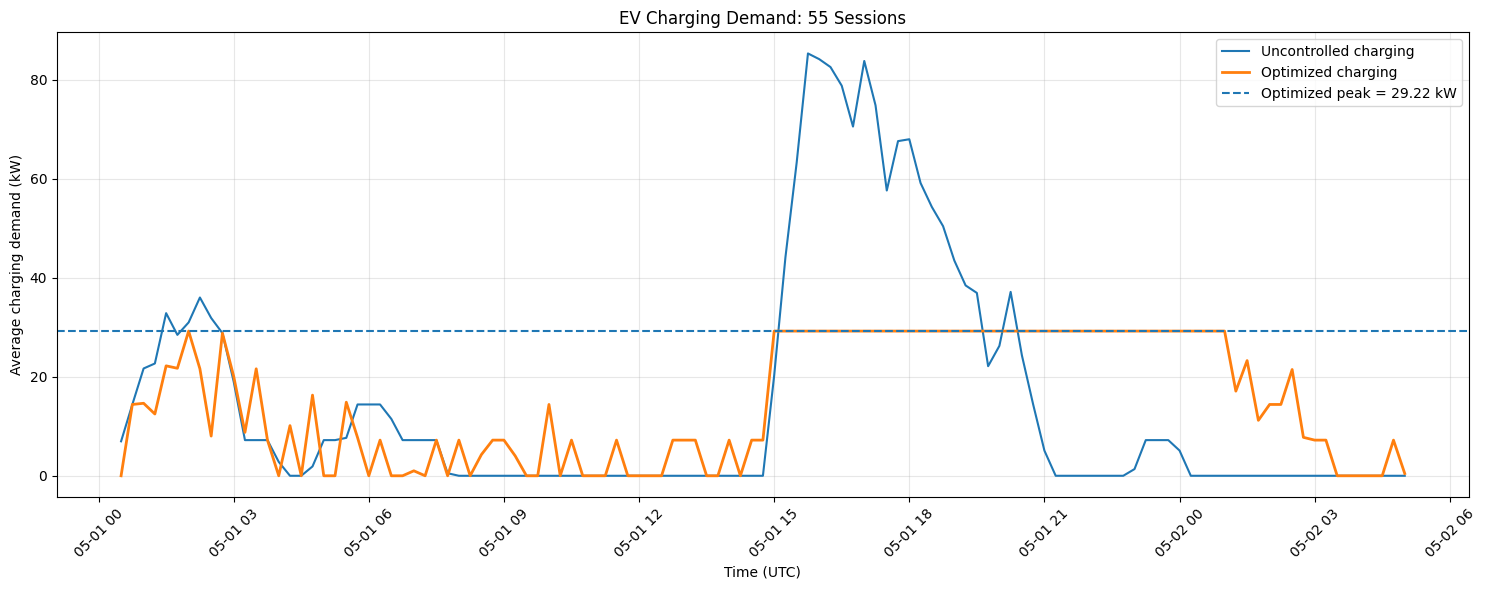

In [70]:

# PLOT: UNCONTROLLED VS OPTIMIZED DEMAND FOR 55 EVs

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    optimization_results_55["timestamp"],
    optimization_results_55["uncontrolled_power_kw"],
    label="Uncontrolled charging",
    linewidth=1.5
)

plt.plot(
    optimization_results_55["timestamp"],
    optimization_results_55["optimized_power_kw"],
    label="Optimized charging",
    linewidth=2
)

plt.axhline(
    optimized_peak_55,
    linestyle="--",
    label=f"Optimized peak = {optimized_peak_55:.2f} kW"
)

plt.title("EV Charging Demand: 55 Sessions")
plt.xlabel("Time (UTC)")
plt.ylabel("Average charging demand (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [71]:
# INSPECT MEASURED STATION LOAD DATA

print("Station profile columns:")
print(station_profile_complete.columns.tolist())

print("\nStation profile index:")
print(type(station_profile_complete.index))

print("\nFirst five records:")
print(station_profile_complete.head())

print("\nLast five records:")
print(station_profile_complete.tail())

print("\nData types:")
print(station_profile_complete.dtypes)

Station profile columns:
['timestamp', 'energy_kwh', 'average_power_kw', 'date', 'hour', 'day_of_week', 'month']

Station profile index:
<class 'pandas.core.indexes.range.RangeIndex'>

First five records:
                  timestamp  energy_kwh  average_power_kw        date  hour  \
0 2018-05-01 00:30:00+00:00    0.837569          3.350274  2018-05-01     0   
1 2018-05-01 00:45:00+00:00    1.773271          7.093083  2018-05-01     0   
2 2018-05-01 01:00:00+00:00    2.628674         10.514696  2018-05-01     1   
3 2018-05-01 01:15:00+00:00    3.672413         14.689652  2018-05-01     1   
4 2018-05-01 01:30:00+00:00    5.519586         22.078342  2018-05-01     1   

   day_of_week  month  
0            1      5  
1            1      5  
2            1      5  
3            1      5  
4            1      5  

Last five records:
                      timestamp  energy_kwh  average_power_kw        date  \
90910 2020-12-03 00:00:00+00:00    8.685628         34.742511  2020-12-03   
90

In [72]:
# EXTRACT MEASURED STATION DEMAND FOR 1 MAY 2018

selected_date = pd.Timestamp("2018-05-01").date()

measured_day = station_profile_complete[
    station_profile_complete["date"] == selected_date
].copy()

# Match the optimization time intervals
measured_day = measured_day[
    measured_day["timestamp"].isin(slots_55)
].copy()

print("========== MEASURED STATION DEMAND ==========")

print("Number of intervals:", len(measured_day))

print("Total measured energy:",
      round(measured_day["energy_kwh"].sum(), 3), "kWh")

print("Average station demand:",
      round(measured_day["average_power_kw"].mean(), 3), "kW")

print("Maximum measured station demand:",
      round(measured_day["average_power_kw"].max(), 3), "kW")

print("\nFirst 10 records:")
print(
    measured_day[
        ["timestamp", "energy_kwh", "average_power_kw"]
    ].head(10).to_string(index=False)
)

========== MEASURED STATION DEMAND ==========
Number of intervals: 94
Total measured energy: 401.165 kWh
Average station demand: 17.071 kW
Maximum measured station demand: 54.076 kW

First 10 records:
                timestamp  energy_kwh  average_power_kw
2018-05-01 00:30:00+00:00    0.837569          3.350274
2018-05-01 00:45:00+00:00    1.773271          7.093083
2018-05-01 01:00:00+00:00    2.628674         10.514696
2018-05-01 01:15:00+00:00    3.672413         14.689652
2018-05-01 01:30:00+00:00    5.519586         22.078342
2018-05-01 01:45:00+00:00    6.670096         26.680384
2018-05-01 02:00:00+00:00    7.057563         28.230252
2018-05-01 02:15:00+00:00    6.678093         26.712373
2018-05-01 02:30:00+00:00    6.667685         26.670739
2018-05-01 02:45:00+00:00    6.698871         26.795483


In [73]:
# ALIGN MEASURED STATION PROFILE WITH THE COMPLETE 55-SESSION WINDOW

measured_window = (
    station_profile_complete[
        station_profile_complete["timestamp"].isin(slots_55)
    ]
    .copy()
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("========== COMPLETE MEASURED WINDOW ==========")

print("Expected intervals:", len(slots_55))
print("Available measured intervals:", len(measured_window))

print("\nStart:", measured_window["timestamp"].min())
print("End:", measured_window["timestamp"].max())

print("\nTotal measured energy:",
      round(measured_window["energy_kwh"].sum(), 3), "kWh")

print("Average measured demand:",
      round(measured_window["average_power_kw"].mean(), 3), "kW")

print("Maximum measured demand:",
      round(measured_window["average_power_kw"].max(), 3), "kW")

print("\nIntervals missing from measured profile:",
      len(slots_55) - len(measured_window))

print("\nEnergy by date:")
print(
    measured_window.groupby(
        measured_window["timestamp"].dt.date
    )["energy_kwh"].sum().round(3)
)

========== COMPLETE MEASURED WINDOW ==========
Expected intervals: 115
Available measured intervals: 115

Start: 2018-05-01 00:30:00+00:00
End: 2018-05-02 05:00:00+00:00

Total measured energy: 499.606 kWh
Average measured demand: 17.378 kW
Maximum measured demand: 54.076 kW

Intervals missing from measured profile: 0

Energy by date:
timestamp
2018-05-01    401.165
2018-05-02     98.441
Name: energy_kwh, dtype: float64


In [74]:
# COMPARE RECORDED SESSION ENERGY WITH MEASURED STATION ENERGY

cohort_recorded_energy = sessions_55[
    "clean_energy_kwh"
].sum()

cohort_grid_energy = sessions_55[
    "grid_energy_kwh"
].sum()

measured_energy = measured_window[
    "energy_kwh"
].sum()

energy_difference = (
    measured_energy - cohort_recorded_energy
)

print("========== ENERGY RECONCILIATION ==========")

print("Measured station energy:",
      round(measured_energy, 3), "kWh")

print("Selected cohort recorded energy:",
      round(cohort_recorded_energy, 3), "kWh")

print("Selected cohort grid energy:",
      round(cohort_grid_energy, 3), "kWh")

print("Difference (measured - cohort recorded):",
      round(energy_difference, 3), "kWh")

print("Cohort share of measured energy:",
      round(cohort_recorded_energy / measured_energy * 100, 2), "%")

print("Difference as share of measured energy:",
      round(energy_difference / measured_energy * 100, 2), "%")

========== ENERGY RECONCILIATION ==========
Measured station energy: 499.606 kWh
Selected cohort recorded energy: 410.041 kWh
Selected cohort grid energy: 431.622 kWh
Difference (measured - cohort recorded): 89.565 kWh
Cohort share of measured energy: 82.07 %
Difference as share of measured energy: 17.93 %


In [75]:

# RECONSTRUCT THE 55 EVs' CONTRIBUTION TO EACH 15-MINUTE INTERVAL

cohort_energy_by_interval = np.zeros(len(slots_55))

for _, session in sessions_55.iterrows():

    arrival = session["arrival_time"]
    departure = session["departure_time"]
    session_energy = session["clean_energy_kwh"]

    duration_hours = (
        departure - arrival
    ).total_seconds() / 3600

    for j, slot_start in enumerate(slots_55):

        slot_end = slot_start + pd.Timedelta(minutes=15)

        overlap_start = max(arrival, slot_start)
        overlap_end = min(departure, slot_end)

        overlap_hours = (
            overlap_end - overlap_start
        ).total_seconds() / 3600

        if overlap_hours > 0:
            cohort_energy_by_interval[j] += (
                session_energy * overlap_hours / duration_hours
            )

# Align measured demand to optimization intervals
measured_aligned = (
    measured_window
    .set_index("timestamp")
    .reindex(slots_55)
)

measured_energy_by_interval = (
    measured_aligned["energy_kwh"].to_numpy()
)

# Estimate background energy
background_energy = (
    measured_energy_by_interval -
    cohort_energy_by_interval
)

# Create analysis dataframe
background_profile = pd.DataFrame({
    "timestamp": slots_55,
    "measured_station_energy_kwh": measured_energy_by_interval,
    "selected_cohort_energy_kwh": cohort_energy_by_interval,
    "estimated_background_energy_kwh": background_energy
})

background_profile["estimated_background_power_kw"] = (
    background_profile["estimated_background_energy_kwh"] / 0.25
)

print("========== BACKGROUND LOAD RECONSTRUCTION ==========")

print("Reconstructed cohort energy:",
      round(cohort_energy_by_interval.sum(), 3), "kWh")

print("Measured station energy:",
      round(measured_energy_by_interval.sum(), 3), "kWh")

print("Estimated background energy:",
      round(background_energy.sum(), 3), "kWh")

print("Minimum background interval energy:",
      round(background_energy.min(), 6), "kWh")

print("Negative background intervals:",
      int(np.sum(background_energy < -1e-6)))

print("\nEstimated background peak demand:",
      round(background_profile["estimated_background_power_kw"].max(), 3),
      "kW")

print("\nEnergy reconciliation error:",
      round(
          measured_energy_by_interval.sum()
          - cohort_energy_by_interval.sum()
          - background_energy.sum(),
          10
      ),
      "kWh")


========== BACKGROUND LOAD RECONSTRUCTION ==========
Reconstructed cohort energy: 410.041 kWh
Measured station energy: 499.606 kWh
Estimated background energy: 89.565 kWh
Minimum background interval energy: -4.229195 kWh
Negative background intervals: 61

Estimated background peak demand: 35.125 kW

Energy reconciliation error: -0.0 kWh


In [76]:
# INSPECT ORIGINAL SESSION FILES

import os
import gzip
import pandas as pd

print("Available columns in clean_sessions:")
print(clean_sessions.columns.tolist())

print("\nExample session identifiers:")
print(clean_sessions["session_id"].head(5).to_string(index=False))

print("\nOriginal data folder:")
print(caltech_path)

print("\nCheck one original session file:")

example_session = clean_sessions.iloc[0]["session_id"]

print("Session ID:", example_session)

matching_files = []

for root, dirs, files in os.walk(caltech_path):
    for filename in files:
        if filename.startswith(str(example_session)):
            matching_files.append(os.path.join(root, filename))

print("Matching files:", matching_files[:5])

Available columns in clean_sessions:
['session_id', 'clean_energy_kwh', 'power_energy_kwh', 'coverage_pct', 'relative_difference_pct', 'decision', 'arrival_time', 'departure_time']

Example session identifiers:
2-39-123-23-2018-05-10T16-38-59-635468.csv.gz
2-39-123-23-2018-05-10T16-49-02-592477.csv.gz
2-39-123-23-2018-05-11T13-28-04-355442.csv.gz
2-39-123-23-2018-05-11T16-51-01-189882.csv.gz
2-39-123-23-2018-05-11T17-01-11-962363.csv.gz

Original data folder:
C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01

Check one original session file:
Session ID: 2-39-123-23-2018-05-10T16-38-59-635468.csv.gz
Matching files: ['C:\\EV_Charging_Project\\ACN-Data-Static\\time series data\\caltech\\California_Garage_01\\2-39-123-23-2018-05-10T16-38-59-635468.csv.gz']


In [77]:
# INSPECT ORIGINAL EV SESSION POWER DATA

import pandas as pd
import gzip
import os

example_file = matching_files[0]

with gzip.open(example_file, "rt") as f:
    raw_session = pd.read_csv(f)

print("========== ORIGINAL SESSION DATA ==========")

print("Shape:", raw_session.shape)

print("\nColumns:")
print(raw_session.columns.tolist())

print("\nFirst 10 records:")
print(raw_session.head(10).to_string(index=False))

print("\nData types:")
print(raw_session.dtypes)

print("\nLast 5 records:")
print(raw_session.tail().to_string(index=False))

========== ORIGINAL SESSION DATA ==========
Shape: (10, 7)

Columns:
['Unnamed: 0', 'Charging Current (A)', 'Actual Pilot (A)', 'Voltage (V)', 'Charging State', 'Energy Delivered (kWh)', 'Power (kW)']

First 10 records:
               Unnamed: 0  Charging Current (A)  Actual Pilot (A)  Voltage (V) Charging State  Energy Delivered (kWh)  Power (kW)
2018-05-10T16:39:03+00:00                   0.7               NaN          NaN          READY                0.000029       0.004
2018-05-10T16:39:07+00:00                   5.7               NaN          NaN       ADAPTIVE                0.001212       1.246
2018-05-10T16:39:13+00:00                   5.7               NaN          NaN       ADAPTIVE                0.002576       1.253
2018-05-10T16:39:15+00:00                   5.9               NaN          NaN       ADAPTIVE                0.003958       1.271
2018-05-10T16:39:19+00:00                   5.9               NaN          NaN       ADAPTIVE                0.005356       1.272


In [78]:

# RECONSTRUCT ACTUAL POWER PROFILE FOR THE 55 SELECTED SESSIONS

import os
import gzip
import numpy as np
import pandas as pd

actual_session_records = []
failed_files = []

for _, session in sessions_55.iterrows():

    session_id = session["session_id"]
    file_path = os.path.join(caltech_path, session_id)

    try:
        with gzip.open(file_path, "rt") as f:
            raw = pd.read_csv(f)

        raw["timestamp"] = pd.to_datetime(
            raw["Unnamed: 0"],
            utc=True
        )

        raw["power_kw"] = pd.to_numeric(
            raw["Power (kW)"],
            errors="coerce"
        )

        raw = raw.dropna(
            subset=["timestamp", "power_kw"]
        )

        # Keep only the selected session's actual connection window
        raw = raw[
            (raw["timestamp"] >= session["arrival_time"]) &
            (raw["timestamp"] <= session["departure_time"])
        ].copy()

        raw["session_id"] = session_id

        actual_session_records.append(
            raw[["session_id", "timestamp", "power_kw"]]
        )

    except Exception as e:
        failed_files.append((session_id, str(e)))

if actual_session_records:
    actual_power_data = pd.concat(
        actual_session_records,
        ignore_index=True
    )
else:
    actual_power_data = pd.DataFrame(
        columns=["session_id", "timestamp", "power_kw"]
    )

print("========== ORIGINAL POWER DATA ==========")

print("Selected sessions:", len(sessions_55))
print("Successfully processed:",
      len(actual_session_records))
print("Failed files:", len(failed_files))
print("Total power measurements:", len(actual_power_data))

print("\nPower statistics:")
print(actual_power_data["power_kw"].describe())

print("\nCharging power above zero:",
      int((actual_power_data["power_kw"] > 0).sum()))

print("Zero-power measurements:",
      int((actual_power_data["power_kw"] == 0).sum()))

print("\nFirst 10 actual power measurements:")
print(actual_power_data.head(10).to_string(index=False))


========== ORIGINAL POWER DATA ==========
Selected sessions: 55
Successfully processed: 55
Failed files: 0
Total power measurements: 0

Power statistics:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: power_kw, dtype: float64

Charging power above zero: 0
Zero-power measurements: 0

First 10 actual power measurements:
Empty DataFrame
Columns: [session_id, timestamp, power_kw]
Index: []


In [79]:
# DIAGNOSE WHY THE TIMESTAMP FILTER REMOVED ALL RECORDS

session = sessions_55.iloc[0]

session_id = session["session_id"]
file_path = os.path.join(caltech_path, session_id)

with gzip.open(file_path, "rt") as f:
    test_raw = pd.read_csv(f)

test_raw["parsed_timestamp"] = pd.to_datetime(
    test_raw["Unnamed: 0"],
    utc=True,
    errors="coerce"
)

print("========== TIMESTAMP DIAGNOSTIC ==========")

print("\nSession ID:")
print(session_id)

print("\nSession arrival:")
print(session["arrival_time"])

print("Session departure:")
print(session["departure_time"])

print("\nOriginal CSV timestamp values:")
print(test_raw["Unnamed: 0"].head(5).to_list())

print("\nParsed timestamp range:")
print(test_raw["parsed_timestamp"].min())
print(test_raw["parsed_timestamp"].max())

print("\nParsed timestamp data type:")
print(test_raw["parsed_timestamp"].dtype)

print("\nOriginal file row count:", len(test_raw))

print("Valid parsed timestamps:",
      test_raw["parsed_timestamp"].notna().sum())

print("\nRows within session window:")

mask = (
    (test_raw["parsed_timestamp"] >= session["arrival_time"]) &
    (test_raw["parsed_timestamp"] <= session["departure_time"])
)

print(mask.sum())

print("\nOriginal file first 5 rows:")
print(test_raw.head().to_string(index=False))

========== TIMESTAMP DIAGNOSTIC ==========

Session ID:
2-39-92-442-2018-05-01T00-31-55-766923.csv.gz

Session arrival:
2018-05-01 00:31:59+00:00
Session departure:
2018-05-01 02:10:54+00:00

Original CSV timestamp values:
['2018-05-01T00:31:59+00:00', '2018-05-01T00:32:03+00:00', '2018-05-01T00:32:07+00:00', '2018-05-01T00:32:11+00:00', '2018-05-01T00:32:16+00:00']

Parsed timestamp range:
2018-05-01 00:31:59+00:00
2018-05-01 02:10:54+00:00

Parsed timestamp data type:
datetime64[ns, UTC]

Original file row count: 1625
Valid parsed timestamps: 1625

Rows within session window:
1625

Original file first 5 rows:
               Unnamed: 0  Charging Current (A)  Actual Pilot (A)  Voltage (V) Charging State  Energy Delivered (kWh)  Power (kW)          parsed_timestamp
2018-05-01T00:31:59+00:00                   3.6               NaN          NaN       ADAPTIVE                0.000153         NaN 2018-05-01 00:31:59+00:00
2018-05-01T00:32:03+00:00                   5.5               NaN    

In [80]:
# AUDIT POWER AND ENERGY DATA AVAILABILITY ACROSS 55 SESSIONS

import os
import gzip
import pandas as pd
import numpy as np

session_quality = []

for _, session in sessions_55.iterrows():

    file_path = os.path.join(
        caltech_path,
        session["session_id"]
    )

    with gzip.open(file_path, "rt") as f:
        raw = pd.read_csv(f)

    power = pd.to_numeric(
        raw["Power (kW)"], errors="coerce"
    )

    energy = pd.to_numeric(
        raw["Energy Delivered (kWh)"], errors="coerce"
    )

    current = pd.to_numeric(
        raw["Charging Current (A)"], errors="coerce"
    )

    session_quality.append({
        "session_id": session["session_id"],
        "rows": len(raw),
        "valid_power": power.notna().sum(),
        "missing_power": power.isna().sum(),
        "valid_energy": energy.notna().sum(),
        "valid_current": current.notna().sum(),
        "positive_power": (power > 0).sum(),
        "positive_current": (current > 0).sum()
    })

quality_55 = pd.DataFrame(session_quality)

print("========== 55-SESSION DATA QUALITY ==========")

print("Sessions audited:", len(quality_55))

print("\nTotal original rows:",
      quality_55["rows"].sum())

print("Rows with valid power:",
      quality_55["valid_power"].sum())

print("Rows with missing power:",
      quality_55["missing_power"].sum())

print("Rows with valid energy:",
      quality_55["valid_energy"].sum())

print("Rows with valid current:",
      quality_55["valid_current"].sum())

print("\nSessions with zero valid power measurements:",
      (quality_55["valid_power"] == 0).sum())

print("Sessions with complete power measurements:",
      (quality_55["missing_power"] == 0).sum())

print("\nFirst 15 session quality records:")
print(quality_55.head(15).to_string(index=False))

========== 55-SESSION DATA QUALITY ==========
Sessions audited: 55

Total original rows: 309342
Rows with valid power: 0
Rows with missing power: 309342
Rows with valid energy: 309342
Rows with valid current: 309342

Sessions with zero valid power measurements: 55
Sessions with complete power measurements: 0

First 15 session quality records:
                                    session_id  rows  valid_power  missing_power  valid_energy  valid_current  positive_power  positive_current
 2-39-92-442-2018-05-01T00-31-55-766923.csv.gz  1625            0           1625          1625           1625               0              1624
 2-39-131-30-2018-05-01T00-43-31-213098.csv.gz  3372            0           3372          3372           3372               0              3370
 2-39-127-19-2018-05-01T01-00-22-472519.csv.gz  5959            0           5959          5959           5959               0              3715
 2-39-129-17-2018-05-01T01-14-26-538688.csv.gz   159            0            15

In [81]:

# INVESTIGATE ENERGY COUNTER IN ONE ORIGINAL SESSION

test_raw["energy_kwh"] = pd.to_numeric(
    test_raw["Energy Delivered (kWh)"],
    errors="coerce"
)

test_raw = test_raw.sort_values(
    "parsed_timestamp"
).reset_index(drop=True)

test_raw["delta_energy_kwh"] = (
    test_raw["energy_kwh"].diff()
)

test_raw["delta_time_seconds"] = (
    test_raw["parsed_timestamp"].diff().dt.total_seconds()
)

test_raw["calculated_power_kw"] = (
    test_raw["delta_energy_kwh"] /
    (test_raw["delta_time_seconds"] / 3600)
)

print("========== ENERGY COUNTER ANALYSIS ==========")

print("\nEnergy counter statistics:")
print(test_raw["energy_kwh"].describe())

print("\nPositive energy increments:",
      (test_raw["delta_energy_kwh"] > 0).sum())

print("Zero energy increments:",
      (test_raw["delta_energy_kwh"] == 0).sum())

print("Negative energy increments:",
      (test_raw["delta_energy_kwh"] < 0).sum())

print("\nCalculated power statistics:")
print(test_raw["calculated_power_kw"].describe())

print("\nFirst 15 calculated measurements:")

print(
    test_raw[
        [
            "parsed_timestamp",
            "energy_kwh",
            "delta_energy_kwh",
            "delta_time_seconds",
            "calculated_power_kw"
        ]
    ].head(15).to_string(index=False)
)


========== ENERGY COUNTER ANALYSIS ==========

Energy counter statistics:
count    1625.000000
mean        2.886809
std         1.690828
min         0.000000
25%         1.420007
50%         2.869936
75%         4.373940
max         5.796187
Name: energy_kwh, dtype: float64

Positive energy increments: 1497
Zero energy increments: 126
Negative energy increments: 1

Calculated power statistics:
count    1624.000000
mean        0.474079
std       129.555637
min     -5216.568000
25%         3.432000
50%         3.473000
75%         3.495500
max        14.239000
Name: calculated_power_kw, dtype: float64

First 15 calculated measurements:
         parsed_timestamp  energy_kwh  delta_energy_kwh  delta_time_seconds  calculated_power_kw
2018-05-01 00:31:59+00:00    0.000153               NaN                 NaN                  NaN
2018-05-01 00:32:03+00:00    0.001338          0.001185                 4.0             1.066500
2018-05-01 00:32:07+00:00    0.002593          0.001255            

In [82]:

# INVESTIGATE NEGATIVE ENERGY INCREMENTS AND LONG SAMPLING GAPS

print("========== NEGATIVE COUNTER INCREMENTS ==========")

negative_rows = test_raw[
    test_raw["delta_energy_kwh"] < 0
]

print(
    negative_rows[
        [
            "parsed_timestamp",
            "energy_kwh",
            "delta_energy_kwh",
            "delta_time_seconds"
        ]
    ].to_string(index=False)
)

print("\n========== SAMPLING INTERVALS ==========")

print(test_raw["delta_time_seconds"].describe())

print("\nIntervals greater than 60 seconds:",
      (test_raw["delta_time_seconds"] > 60).sum())

print("Intervals greater than 300 seconds:",
      (test_raw["delta_time_seconds"] > 300).sum())

print("\n========== ENERGY COUNTER CHECK ==========")

print("Initial energy:",
      test_raw["energy_kwh"].iloc[0], "kWh")

print("Final energy:",
      test_raw["energy_kwh"].iloc[-1], "kWh")

print("Net counter change:",
      round(
          test_raw["energy_kwh"].iloc[-1] -
          test_raw["energy_kwh"].iloc[0],
          6
      ), "kWh")

print("Sum of positive increments:",
      round(
          test_raw.loc[
              test_raw["delta_energy_kwh"] > 0,
              "delta_energy_kwh"
          ].sum(),
          6
      ), "kWh")


========== NEGATIVE COUNTER INCREMENTS ==========
         parsed_timestamp  energy_kwh  delta_energy_kwh  delta_time_seconds
2018-05-01 02:10:54+00:00         0.0         -5.796187                 4.0

========== SAMPLING INTERVALS ==========
count    1624.000000
mean        3.654557
std         1.047017
min         1.000000
25%         4.000000
50%         4.000000
75%         4.000000
max        11.000000
Name: delta_time_seconds, dtype: float64

Intervals greater than 60 seconds: 0
Intervals greater than 300 seconds: 0

========== ENERGY COUNTER CHECK ==========
Initial energy: 0.0001527777777779 kWh
Final energy: 0.0 kWh
Net counter change: -0.000153 kWh
Sum of positive increments: 5.796034 kWh


In [83]:

# RECONSTRUCT ACTUAL 15-MINUTE ENERGY FOR THE 55 EV SESSIONS
# Using positive energy-counter increments

actual_cohort_energy = np.zeros(len(slots_55))

counter_audit = []

for _, session in sessions_55.iterrows():

    file_path = os.path.join(
        caltech_path,
        session["session_id"]
    )

    with gzip.open(file_path, "rt") as f:
        raw = pd.read_csv(f)

    raw["timestamp"] = pd.to_datetime(
        raw["Unnamed: 0"], utc=True
    )

    raw["energy_kwh"] = pd.to_numeric(
        raw["Energy Delivered (kWh)"],
        errors="coerce"
    )

    raw = raw.dropna(
        subset=["timestamp", "energy_kwh"]
    ).sort_values("timestamp").reset_index(drop=True)

    raw["delta_energy"] = raw["energy_kwh"].diff()
    raw["previous_timestamp"] = raw["timestamp"].shift(1)

    positive_increments = raw[
        raw["delta_energy"] > 0
    ]

    positive_total = positive_increments[
        "delta_energy"
    ].sum()

    negative_count = int(
        (raw["delta_energy"] < 0).sum()
    )

    counter_audit.append({
        "session_id": session["session_id"],
        "positive_energy_kwh": positive_total,
        "negative_increments": negative_count
    })

    # Allocate each positive increment across its measurement interval
    for _, row in positive_increments.iterrows():

        interval_start = row["previous_timestamp"]
        interval_end = row["timestamp"]
        increment = row["delta_energy"]

        elapsed_seconds = (
            interval_end - interval_start
        ).total_seconds()

        if elapsed_seconds <= 0:
            continue

        for j, slot_start in enumerate(slots_55):

            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(interval_start, slot_start)
            overlap_end = min(interval_end, slot_end)

            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap_seconds > 0:
                actual_cohort_energy[j] += (
                    increment * overlap_seconds / elapsed_seconds
                )

counter_audit_55 = pd.DataFrame(counter_audit)

print("========== COUNTER RECONSTRUCTION ==========")

print("Sessions processed:", len(counter_audit_55))

print("Total reconstructed energy:",
      round(actual_cohort_energy.sum(), 6), "kWh")

print("Total positive session energy:",
      round(counter_audit_55["positive_energy_kwh"].sum(), 6),
      "kWh")

print("Total negative counter increments:",
      counter_audit_55["negative_increments"].sum())

print("\nEnergy difference from clean session energy:",
      round(
          actual_cohort_energy.sum() -
          sessions_55["clean_energy_kwh"].sum(),
          6
      ), "kWh")


========== COUNTER RECONSTRUCTION ==========
Sessions processed: 55
Total reconstructed energy: 410.035613 kWh
Total positive session energy: 410.041354 kWh
Total negative counter increments: 80

Energy difference from clean session energy: -0.005741 kWh


In [84]:

# ACTUAL BACKGROUND LOAD ESTIMATION

# Align measured station energy with optimization intervals
measured_energy_array = (
    measured_window
    .set_index("timestamp")
    .reindex(slots_55)["energy_kwh"]
    .to_numpy()
)

# Subtract reconstructed actual cohort energy
background_energy_actual = (
    measured_energy_array - actual_cohort_energy
)

background_power_actual = (
    background_energy_actual / 0.25
)

# Create dataframe
background_actual_df = pd.DataFrame({
    "timestamp": slots_55,
    "measured_station_energy_kwh": measured_energy_array,
    "actual_cohort_energy_kwh": actual_cohort_energy,
    "estimated_background_energy_kwh": background_energy_actual,
    "estimated_background_power_kw": background_power_actual
})

# Diagnostics
negative_intervals = background_actual_df[
    background_actual_df["estimated_background_energy_kwh"] < -1e-6
]

print("========== ACTUAL BACKGROUND LOAD ==========")

print("Measured station energy:",
      round(measured_energy_array.sum(), 6), "kWh")

print("Reconstructed cohort energy:",
      round(actual_cohort_energy.sum(), 6), "kWh")

print("Estimated background energy:",
      round(background_energy_actual.sum(), 6), "kWh")

print("\nNegative background intervals:",
      len(negative_intervals), "out of", len(slots_55))

print("Minimum background energy:",
      round(background_energy_actual.min(), 6), "kWh")

print("Maximum background demand:",
      round(background_power_actual.max(), 3), "kW")

print("Minimum background demand:",
      round(background_power_actual.min(), 3), "kW")

print("\nFirst 15 intervals:")
print(
    background_actual_df[
        [
            "timestamp",
            "measured_station_energy_kwh",
            "actual_cohort_energy_kwh",
            "estimated_background_energy_kwh"
        ]
    ].head(15).to_string(index=False)
)


========== ACTUAL BACKGROUND LOAD ==========
Measured station energy: 499.606346 kWh
Reconstructed cohort energy: 410.035613 kWh
Estimated background energy: 89.570733 kWh

Negative background intervals: 1 out of 115
Minimum background energy: -0.000309 kWh
Maximum background demand: 33.045 kW
Minimum background demand: -0.001 kW

First 15 intervals:
                timestamp  measured_station_energy_kwh  actual_cohort_energy_kwh  estimated_background_energy_kwh
2018-05-01 00:30:00+00:00                     0.837569                  0.837569                    -2.220446e-16
2018-05-01 00:45:00+00:00                     1.773271                  1.773271                    -3.552714e-15
2018-05-01 01:00:00+00:00                     2.628674                  2.628674                    -1.332268e-15
2018-05-01 01:15:00+00:00                     3.672413                  3.672413                     4.440892e-16
2018-05-01 01:30:00+00:00                     5.519586                  5.519

In [85]:

# STATION-LEVEL PEAK SHAVING COMPARISON

# Convert background energy to average power
background_power = (
    background_energy_actual / DT
)

# Remove only negligible numerical negative residuals
background_power = np.where(
    background_power < 0,
    0,
    background_power
)

# Actual station demand:
# estimated background + reconstructed actual EV cohort
actual_station_power = (
    background_power +
    actual_cohort_energy / DT
)

# Hypothetical uncontrolled station demand
uncontrolled_station_power = (
    background_power +
    baseline_power_55
)

# Hypothetical optimized station demand
optimized_station_power = (
    background_power +
    optimized_power_55
)

# Peak demand calculations
actual_station_peak = actual_station_power.max()
uncontrolled_station_peak = uncontrolled_station_power.max()
optimized_station_peak = optimized_station_power.max()

actual_to_optimized_reduction = (
    (actual_station_peak - optimized_station_peak)
    / actual_station_peak
) * 100

uncontrolled_to_optimized_reduction = (
    (uncontrolled_station_peak - optimized_station_peak)
    / uncontrolled_station_peak
) * 100

print("========== STATION-LEVEL RESULTS ==========")

print("Actual reconstructed station peak:",
      round(actual_station_peak, 3), "kW")

print("Uncontrolled scenario station peak:",
      round(uncontrolled_station_peak, 3), "kW")

print("Optimized scenario station peak:",
      round(optimized_station_peak, 3), "kW")

print("\nReduction from actual reconstructed peak:",
      round(actual_to_optimized_reduction, 2), "%")

print("Reduction from uncontrolled scenario:",
      round(uncontrolled_to_optimized_reduction, 2), "%")


========== STATION-LEVEL RESULTS ==========
Actual reconstructed station peak: 54.076 kW
Uncontrolled scenario station peak: 85.278 kW
Optimized scenario station peak: 47.713 kW

Reduction from actual reconstructed peak: 11.77 %
Reduction from uncontrolled scenario: 44.05 %


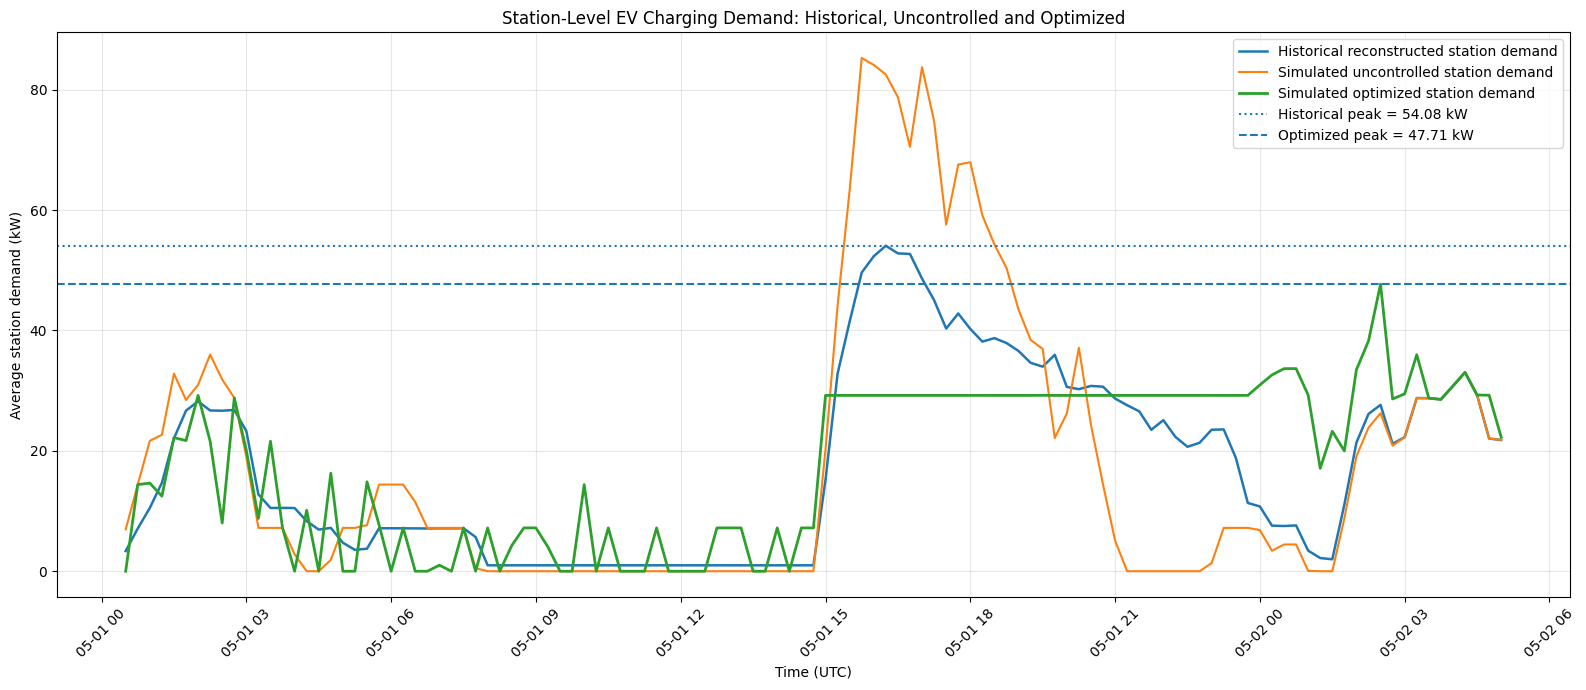

In [86]:

# STATION-LEVEL DEMAND COMPARISON

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 7))

plt.plot(
    slots_55,
    actual_station_power,
    label="Historical reconstructed station demand",
    linewidth=1.8
)

plt.plot(
    slots_55,
    uncontrolled_station_power,
    label="Simulated uncontrolled station demand",
    linewidth=1.5
)

plt.plot(
    slots_55,
    optimized_station_power,
    label="Simulated optimized station demand",
    linewidth=2
)

plt.axhline(
    actual_station_peak,
    linestyle=":",
    label=f"Historical peak = {actual_station_peak:.2f} kW"
)

plt.axhline(
    optimized_station_peak,
    linestyle="--",
    label=f"Optimized peak = {optimized_station_peak:.2f} kW"
)

plt.title(
    "Station-Level EV Charging Demand: "
    "Historical, Uncontrolled and Optimized"
)

plt.xlabel("Time (UTC)")
plt.ylabel("Average station demand (kW)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [87]:
# SENSITIVITY ANALYSIS: SESSION FEASIBILITY

charging_power_scenarios = [3.3, 7.2, 11.0]

efficiency = 0.95

feasibility_results = []

for charger_power in charging_power_scenarios:

    temp = sessions_55.copy()

    temp["required_power_kw"] = (
        temp["clean_energy_kwh"] / efficiency
    ) / temp["duration_hours"]

    temp["maximum_deliverable_kwh"] = (
        charger_power * temp["duration_hours"]
    )

    temp["feasible"] = (
        temp["grid_energy_kwh"] <=
        temp["maximum_deliverable_kwh"]
    )

    feasibility_results.append({
        "charger_power_kw": charger_power,
        "total_sessions": len(temp),
        "feasible_sessions": temp["feasible"].sum(),
        "infeasible_sessions": (~temp["feasible"]).sum(),
        "feasibility_percentage": (
            temp["feasible"].mean() * 100
        )
    })

feasibility_df = pd.DataFrame(feasibility_results)

print("========== CHARGER POWER FEASIBILITY ==========")
print(feasibility_df.round(3).to_string(index=False))

========== CHARGER POWER FEASIBILITY ==========
 charger_power_kw  total_sessions  feasible_sessions  infeasible_sessions  feasibility_percentage
              3.3              55                 47                    8                  85.455
              7.2              55                 55                    0                 100.000
             11.0              55                 55                    0                 100.000


In [88]:

# COMMON 47-SESSION COHORT FOR FAIR SENSITIVITY ANALYSIS

MAX_POWER_SCENARIOS = [3.3, 7.2, 11.0]

# Calculate the minimum average charging power required
sensitivity_sessions = sessions_55.copy()

sensitivity_sessions["minimum_required_power_kw"] = (
    sensitivity_sessions["grid_energy_kwh"] /
    sensitivity_sessions["duration_hours"]
)

# Select sessions feasible even at 3.3 kW
common_cohort = sensitivity_sessions[
    sensitivity_sessions["minimum_required_power_kw"] <= 3.3
].copy().reset_index(drop=True)

print("========== COMMON COHORT ==========")

print("Original sessions:", len(sessions_55))
print("Common feasible sessions:", len(common_cohort))
print("Excluded sessions:", len(sessions_55) - len(common_cohort))

print("\nTotal grid energy required:",
      round(common_cohort["grid_energy_kwh"].sum(), 3), "kWh")

print("\nMinimum required charging power statistics:")
print(
    common_cohort["minimum_required_power_kw"]
    .describe()
    .round(3)
)

print("\nFeasibility verification:")

for power_limit in MAX_POWER_SCENARIOS:

    feasible_count = (
        common_cohort["grid_energy_kwh"] <=
        power_limit * common_cohort["duration_hours"]
    ).sum()

    print(
        f"{power_limit} kW: "
        f"{feasible_count}/{len(common_cohort)} feasible"
    )


========== COMMON COHORT ==========
Original sessions: 55
Common feasible sessions: 47
Excluded sessions: 8

Total grid energy required: 331.76 kWh

Minimum required charging power statistics:
count    47.000
mean      1.256
std       0.889
min       0.071
25%       0.482
50%       1.000
75%       1.936
max       3.196
Name: minimum_required_power_kw, dtype: float64

Feasibility verification:
3.3 kW: 47/47 feasible
7.2 kW: 47/47 feasible
11.0 kW: 47/47 feasible


In [89]:

# RECONSTRUCT ACTUAL ENERGY CONTRIBUTION OF THE COMMON 47-EV COHORT

actual_energy_47 = np.zeros(len(slots_55))
audit_47 = []

for _, session in common_cohort.iterrows():

    file_path = os.path.join(caltech_path, session["session_id"])

    with gzip.open(file_path, "rt") as f:
        raw = pd.read_csv(f)

    raw["timestamp"] = pd.to_datetime(
        raw["Unnamed: 0"], utc=True
    )

    raw["energy_kwh"] = pd.to_numeric(
        raw["Energy Delivered (kWh)"], errors="coerce"
    )

    raw = raw.dropna(
        subset=["timestamp", "energy_kwh"]
    ).sort_values("timestamp").reset_index(drop=True)

    raw["delta_energy"] = raw["energy_kwh"].diff()
    raw["previous_timestamp"] = raw["timestamp"].shift(1)

    positive = raw[raw["delta_energy"] > 0]

    session_energy = positive["delta_energy"].sum()

    audit_47.append({
        "session_id": session["session_id"],
        "reconstructed_energy_kwh": session_energy
    })

    for _, reading in positive.iterrows():

        t0 = reading["previous_timestamp"]
        t1 = reading["timestamp"]
        energy = reading["delta_energy"]

        elapsed = (t1 - t0).total_seconds()

        if elapsed <= 0:
            continue

        # Allocate energy proportionally across overlapping intervals
        first_slot = max(
            0,
            int(np.floor(
                (t0 - slots_55[0]).total_seconds() / 900
            ))
        )

        last_slot = min(
            len(slots_55) - 1,
            int(np.floor(
                (t1 - slots_55[0]).total_seconds() / 900
            ))
        )

        for j in range(first_slot, last_slot + 1):

            slot_start = slots_55[j]
            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(t0, slot_start)
            overlap_end = min(t1, slot_end)

            overlap = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap > 0:
                actual_energy_47[j] += (
                    energy * overlap / elapsed
                )

# Measured station energy aligned with all 115 intervals
measured_energy_47 = (
    measured_window
    .set_index("timestamp")
    .reindex(slots_55)["energy_kwh"]
    .to_numpy()
)

# Fixed load includes the eight excluded sessions and other demand
background_energy_47 = (
    measured_energy_47 - actual_energy_47
)

background_power_47 = background_energy_47 / 0.25

audit_47_df = pd.DataFrame(audit_47)

print("========== 47-SESSION BACKGROUND RECONSTRUCTION ==========")

print("Sessions reconstructed:", len(audit_47_df))

print("Clean cohort energy:",
      round(common_cohort["clean_energy_kwh"].sum(), 6), "kWh")

print("Reconstructed cohort energy:",
      round(actual_energy_47.sum(), 6), "kWh")

print("Estimated fixed background energy:",
      round(background_energy_47.sum(), 6), "kWh")

print("Negative background intervals:",
      int(np.sum(background_energy_47 < -1e-6)))

print("Minimum background energy:",
      round(background_energy_47.min(), 6), "kWh")

print("Maximum fixed background demand:",
      round(background_power_47.max(), 3), "kW")


========== 47-SESSION BACKGROUND RECONSTRUCTION ==========
Sessions reconstructed: 47
Clean cohort energy: 315.172452 kWh
Reconstructed cohort energy: 315.166711 kWh
Estimated fixed background energy: 184.439635 kWh
Negative background intervals: 0
Minimum background energy: -0.0 kWh
Maximum fixed background demand: 33.045 kW


In [90]:

# SENSITIVITY ANALYSIS: STATION-LEVEL OPTIMIZATION
# 47 EV sessions, three charging-power limits

from scipy.optimize import linprog
from scipy.sparse import lil_matrix
import numpy as np
import pandas as pd

POWER_LIMITS = [3.3, 7.2, 11.0]
DT = 0.25

sensitivity_results = []
sensitivity_profiles = {}

for power_limit in POWER_LIMITS:

    print(f"\nRunning optimization for {power_limit} kW...")

    n_ev = len(common_cohort)
    n_slots = len(slots_55)

    variables = []
    bounds = []

    # Create EV-time variables with partial-slot availability
    for i, session in common_cohort.iterrows():

        for j, slot_start in enumerate(slots_55):

            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(
                session["arrival_time"], slot_start
            )

            overlap_end = min(
                session["departure_time"], slot_end
            )

            overlap_hours = (
                overlap_end - overlap_start
            ).total_seconds() / 3600

            if overlap_hours > 0:
                variables.append((i, j, overlap_hours))
                bounds.append((0, power_limit * overlap_hours))

    n_energy_vars = len(variables)
    peak_idx = n_energy_vars
    n_vars = n_energy_vars + 1

    # Energy equality constraints
    A_eq = lil_matrix((n_ev, n_vars))
    b_eq = common_cohort["grid_energy_kwh"].to_numpy()

    for k, (i, j, overlap_hours) in enumerate(variables):
        A_eq[i, k] = 1

    # Aggregate demand constraints
    A_ub = lil_matrix((n_slots, n_vars))
    b_ub = np.zeros(n_slots)

    for k, (i, j, overlap_hours) in enumerate(variables):
        A_ub[j, k] = 1
        A_ub[j, peak_idx] = -DT

    # Minimize maximum EV charging demand
    objective = np.zeros(n_vars)
    objective[peak_idx] = 1

    result = linprog(
        objective,
        A_ub=A_ub.tocsr(),
        b_ub=b_ub,
        A_eq=A_eq.tocsr(),
        b_eq=b_eq,
        bounds=bounds + [(0, None)],
        method="highs"
    )

    if not result.success:
        raise RuntimeError(
            f"{power_limit} kW optimization failed: {result.message}"
        )

    # Optimized EV load
    optimized_energy = np.zeros(n_slots)

    for k, (i, j, overlap_hours) in enumerate(variables):
        optimized_energy[j] += result.x[k]

    optimized_ev_power = optimized_energy / DT

    # Uncontrolled immediate charging baseline
    baseline_energy = np.zeros(n_slots)

    for i, session in common_cohort.iterrows():

        remaining = session["grid_energy_kwh"]

        for vehicle_i, j, overlap_hours in variables:

            if vehicle_i != i:
                continue

            available = power_limit * overlap_hours
            delivered = min(remaining, available)

            baseline_energy[j] += delivered
            remaining -= delivered

            if remaining <= 1e-8:
                break

        if remaining > 1e-6:
            raise RuntimeError(
                f"Uncontrolled baseline infeasible for session {i}"
            )

    baseline_ev_power = baseline_energy / DT

    # Add the same fixed background demand to both profiles
    optimized_station = (
        background_power_47 + optimized_ev_power
    )

    uncontrolled_station = (
        background_power_47 + baseline_ev_power
    )

    baseline_peak = uncontrolled_station.max()
    optimized_peak = optimized_station.max()

    reduction = (
        (baseline_peak - optimized_peak) / baseline_peak
    ) * 100

    sensitivity_results.append({
        "charger_power_kw": power_limit,
        "uncontrolled_station_peak_kw": baseline_peak,
        "optimized_station_peak_kw": optimized_peak,
        "peak_reduction_pct": reduction,
        "total_energy_kwh": optimized_energy.sum(),
        "solver_status": result.message
    })

    sensitivity_profiles[power_limit] = {
        "uncontrolled": uncontrolled_station,
        "optimized": optimized_station,
        "optimized_ev": optimized_ev_power,
        "baseline_ev": baseline_ev_power
    }

sensitivity_results_df = pd.DataFrame(sensitivity_results)

print("\n========== SENSITIVITY ANALYSIS RESULTS ==========")
print(sensitivity_results_df.round(3).to_string(index=False))



Running optimization for 3.3 kW...

Running optimization for 7.2 kW...

Running optimization for 11.0 kW...

========== SENSITIVITY ANALYSIS RESULTS ==========
 charger_power_kw  uncontrolled_station_peak_kw  optimized_station_peak_kw  peak_reduction_pct  total_energy_kwh                                                   solver_status
              3.3                        64.128                     41.895              34.669            331.76 Optimization terminated successfully. (HiGHS Status 7: Optimal)
              7.2                        85.278                     47.147              44.714            331.76 Optimization terminated successfully. (HiGHS Status 7: Optimal)
             11.0                       103.514                     48.257              53.381            331.76 Optimization terminated successfully. (HiGHS Status 7: Optimal)


In [91]:

# CORRECTED SENSITIVITY ANALYSIS
# Minimize TOTAL STATION demand, including background load

from scipy.optimize import linprog
from scipy.sparse import lil_matrix
import numpy as np
import pandas as pd

POWER_LIMITS = [3.3, 7.2, 11.0]
DT = 0.25

# Remove only negligible numerical residuals
fixed_background = np.maximum(background_power_47, 0)

corrected_results = []
corrected_profiles = {}

for power_limit in POWER_LIMITS:

    print(f"\nOptimizing station demand at {power_limit} kW...")

    n_ev = len(common_cohort)
    n_slots = len(slots_55)

    variables = []
    bounds = []

    # Create available EV-time charging variables
    for i, session in common_cohort.iterrows():

        for j, slot_start in enumerate(slots_55):

            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(session["arrival_time"], slot_start)
            overlap_end = min(session["departure_time"], slot_end)

            overlap_hours = (
                overlap_end - overlap_start
            ).total_seconds() / 3600

            if overlap_hours > 0:
                variables.append((i, j, overlap_hours))
                bounds.append((0, power_limit * overlap_hours))

    n_energy_vars = len(variables)
    peak_idx = n_energy_vars
    n_vars = n_energy_vars + 1

    # Each EV must receive its complete energy requirement
    A_eq = lil_matrix((n_ev, n_vars))
    b_eq = common_cohort["grid_energy_kwh"].to_numpy()

    for k, (i, j, overlap_hours) in enumerate(variables):
        A_eq[i, k] = 1

    # TOTAL STATION peak constraints:
    # Background energy + EV energy <= station peak * DT
    A_ub = lil_matrix((n_slots, n_vars))

    b_ub = -DT * fixed_background

    for k, (i, j, overlap_hours) in enumerate(variables):
        A_ub[j, k] = 1

    for j in range(n_slots):
        A_ub[j, peak_idx] = -DT

    # Minimize station peak, not EV-only peak
    objective = np.zeros(n_vars)
    objective[peak_idx] = 1

    result = linprog(
        objective,
        A_ub=A_ub.tocsr(),
        b_ub=b_ub,
        A_eq=A_eq.tocsr(),
        b_eq=b_eq,
        bounds=bounds + [(0, None)],
        method="highs"
    )

    if not result.success:
        raise RuntimeError(
            f"{power_limit} kW optimization failed: {result.message}"
        )

    # Extract optimized EV energy
    optimized_energy = np.zeros(n_slots)

    for k, (i, j, overlap_hours) in enumerate(variables):
        optimized_energy[j] += result.x[k]

    optimized_ev_power = optimized_energy / DT

    # Uncontrolled ASAP charging baseline
    baseline_energy = np.zeros(n_slots)

    for i, session in common_cohort.iterrows():

        remaining = session["grid_energy_kwh"]

        for vehicle_i, j, overlap_hours in variables:

            if vehicle_i != i:
                continue

            available = power_limit * overlap_hours
            delivered = min(remaining, available)

            baseline_energy[j] += delivered
            remaining -= delivered

            if remaining <= 1e-8:
                break

        if remaining > 1e-6:
            raise RuntimeError(
                f"Baseline infeasible for session {i}"
            )

    baseline_ev_power = baseline_energy / DT

    # Total station demand
    optimized_station = fixed_background + optimized_ev_power
    uncontrolled_station = fixed_background + baseline_ev_power

    baseline_peak = uncontrolled_station.max()
    optimized_peak = optimized_station.max()

    reduction = (
        (baseline_peak - optimized_peak) / baseline_peak
    ) * 100

    corrected_results.append({
        "charger_power_kw": power_limit,
        "uncontrolled_peak_kw": baseline_peak,
        "optimized_peak_kw": optimized_peak,
        "peak_reduction_pct": reduction,
        "total_energy_kwh": optimized_energy.sum(),
        "solver_peak_kw": result.x[peak_idx]
    })

    corrected_profiles[power_limit] = {
        "uncontrolled": uncontrolled_station,
        "optimized": optimized_station,
        "optimized_ev": optimized_ev_power,
        "baseline_ev": baseline_ev_power
    }

corrected_results_df = pd.DataFrame(corrected_results)

print("\n========== CORRECTED STATION OPTIMIZATION ==========")
print(corrected_results_df.round(3).to_string(index=False))



Optimizing station demand at 3.3 kW...

Optimizing station demand at 7.2 kW...

Optimizing station demand at 11.0 kW...

========== CORRECTED STATION OPTIMIZATION ==========
 charger_power_kw  uncontrolled_peak_kw  optimized_peak_kw  peak_reduction_pct  total_energy_kwh  solver_peak_kw
              3.3                64.128             33.045              48.471            331.76          33.045
              7.2                85.278             33.045              61.251            331.76          33.045
             11.0               103.514             33.045              68.077            331.76          33.045


In [92]:

# VALIDATE ALL THREE CORRECTED OPTIMIZATION SCENARIOS

validation_sensitivity = []

for power_limit in POWER_LIMITS:

    profile = corrected_profiles[power_limit]

    optimized_ev = profile["optimized_ev"]
    optimized_station = profile["optimized"]

    print(f"\n========== {power_limit} kW VALIDATION ==========")

    # Station peak and background lower bound
    station_peak = optimized_station.max()

    print("Optimized station peak:",
          round(station_peak, 6), "kW")

    print("Background peak:",
          round(fixed_background.max(), 6), "kW")

    print("All station demands above background:",
          np.all(optimized_station >= fixed_background - 1e-6))

    # Verify total energy
    total_energy = optimized_ev.sum() * DT

    print("Total optimized EV energy:",
          round(total_energy, 6), "kWh")

    # Compare with required energy
    required_energy = common_cohort["grid_energy_kwh"].sum()

    print("Energy requirement satisfied:",
          abs(total_energy - required_energy) < 1e-5)

    print("Station peak reaches background lower bound:",
          abs(station_peak - fixed_background.max()) < 1e-5)

    validation_sensitivity.append({
        "charger_power_kw": power_limit,
        "station_peak_kw": station_peak,
        "background_peak_kw": fixed_background.max(),
        "energy_delivered_kwh": total_energy,
        "energy_requirement_met": abs(
            total_energy - required_energy
        ) < 1e-5
    })

print("\n========== VALIDATION SUMMARY ==========")

print(
    pd.DataFrame(validation_sensitivity)
    .round(5)
    .to_string(index=False)
)



========== 3.3 kW VALIDATION ==========
Optimized station peak: 33.044526 kW
Background peak: 33.044526 kW
All station demands above background: True
Total optimized EV energy: 331.760475 kWh
Energy requirement satisfied: True
Station peak reaches background lower bound: True

========== 7.2 kW VALIDATION ==========
Optimized station peak: 33.044526 kW
Background peak: 33.044526 kW
All station demands above background: True
Total optimized EV energy: 331.760475 kWh
Energy requirement satisfied: True
Station peak reaches background lower bound: True

========== 11.0 kW VALIDATION ==========
Optimized station peak: 33.044526 kW
Background peak: 33.044526 kW
All station demands above background: True
Total optimized EV energy: 331.760475 kWh
Energy requirement satisfied: True
Station peak reaches background lower bound: True

========== VALIDATION SUMMARY ==========
 charger_power_kw  station_peak_kw  background_peak_kw  energy_delivered_kwh  energy_requirement_met
              3.3     

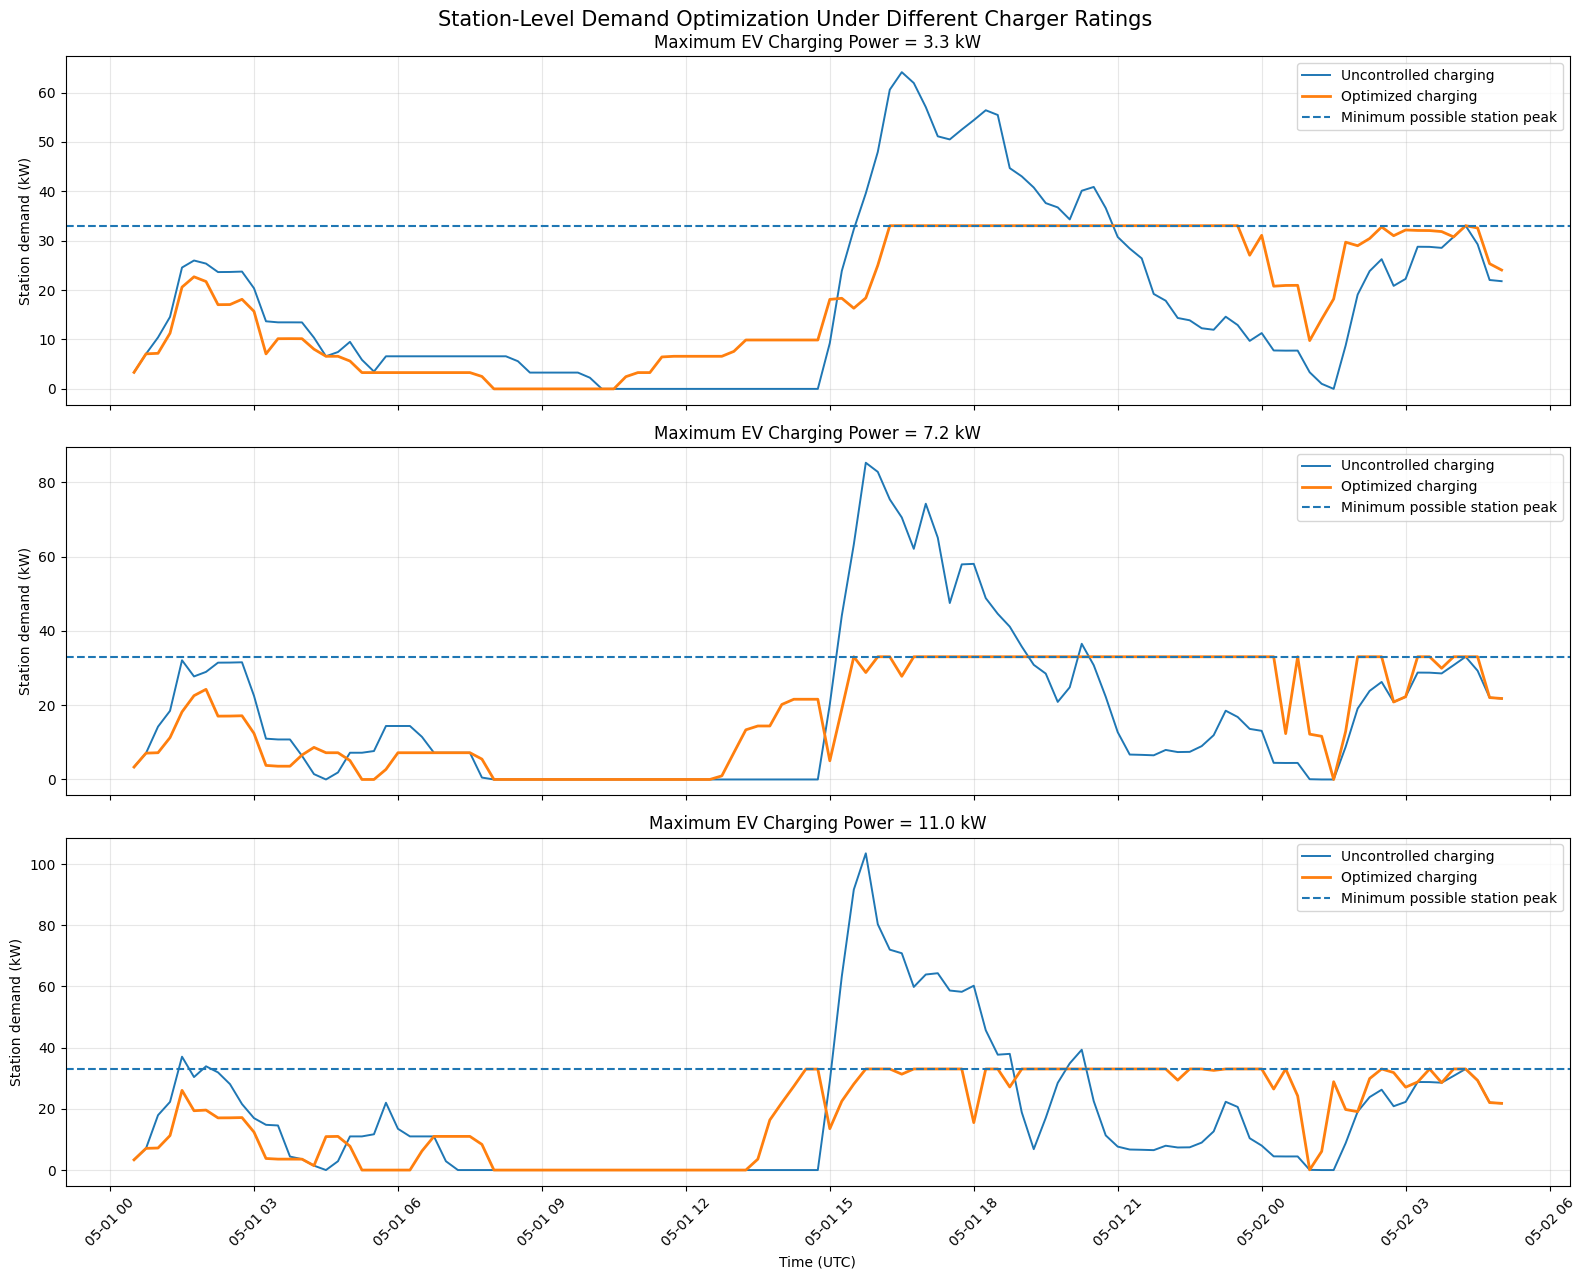

In [93]:

# COMPARE STATION DEMAND UNDER THREE CHARGER RATINGS

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 13),
    sharex=True
)

for ax, power_limit in zip(axes, POWER_LIMITS):

    profile = corrected_profiles[power_limit]

    ax.plot(
        slots_55,
        profile["uncontrolled"],
        label="Uncontrolled charging",
        linewidth=1.4
    )

    ax.plot(
        slots_55,
        profile["optimized"],
        label="Optimized charging",
        linewidth=2
    )

    ax.axhline(
        fixed_background.max(),
        linestyle="--",
        label="Minimum possible station peak"
    )

    ax.set_title(
        f"Maximum EV Charging Power = {power_limit} kW"
    )

    ax.set_ylabel("Station demand (kW)")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Time (UTC)")

fig.suptitle(
    "Station-Level Demand Optimization Under Different Charger Ratings",
    fontsize=15
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [94]:

# RERUN OPTIMIZATION AND RETAIN INDIVIDUAL EV CHARGING SCHEDULES

from scipy.optimize import linprog
from scipy.sparse import lil_matrix
import numpy as np
import pandas as pd

corrected_solutions = {}
individual_validation = []

for power_limit in POWER_LIMITS:

    print(f"\nValidating {power_limit} kW charger scenario...")

    n_ev = len(common_cohort)
    n_slots = len(slots_55)

    variables = []
    bounds = []

    # Create charging variables using positional EV indexing
    for i, (_, session) in enumerate(common_cohort.iterrows()):

        for j, slot_start in enumerate(slots_55):

            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(session["arrival_time"], slot_start)
            overlap_end = min(session["departure_time"], slot_end)

            overlap_hours = (
                overlap_end - overlap_start
            ).total_seconds() / 3600

            if overlap_hours > 0:
                variables.append((i, j, overlap_hours))
                bounds.append((0, power_limit * overlap_hours))

    n_energy_vars = len(variables)
    peak_idx = n_energy_vars
    n_vars = n_energy_vars + 1

    # Individual EV energy requirements
    A_eq = lil_matrix((n_ev, n_vars))
    b_eq = common_cohort["grid_energy_kwh"].to_numpy()

    for k, (i, j, overlap_hours) in enumerate(variables):
        A_eq[i, k] = 1

    # Station peak constraints including background demand
    A_ub = lil_matrix((n_slots, n_vars))
    b_ub = -DT * fixed_background

    for k, (i, j, overlap_hours) in enumerate(variables):
        A_ub[j, k] = 1

    for j in range(n_slots):
        A_ub[j, peak_idx] = -DT

    objective = np.zeros(n_vars)
    objective[peak_idx] = 1

    result = linprog(
        objective,
        A_ub=A_ub.tocsr(),
        b_ub=b_ub,
        A_eq=A_eq.tocsr(),
        b_eq=b_eq,
        bounds=bounds + [(0, None)],
        method="highs"
    )

    if not result.success:
        raise RuntimeError(result.message)

    # Extract individual EV charging allocations
    allocation = result.x[:n_energy_vars]

    delivered_by_ev = np.zeros(n_ev)
    maximum_power_by_ev = np.zeros(n_ev)

    for k, (i, j, overlap_hours) in enumerate(variables):

        energy = allocation[k]

        delivered_by_ev[i] += energy

        charging_power = energy / overlap_hours

        maximum_power_by_ev[i] = max(
            maximum_power_by_ev[i],
            charging_power
        )

    required_by_ev = common_cohort[
        "grid_energy_kwh"
    ].to_numpy()

    energy_errors = np.abs(delivered_by_ev - required_by_ev)

    # Aggregate optimized station demand
    optimized_energy = np.zeros(n_slots)

    for k, (i, j, overlap_hours) in enumerate(variables):
        optimized_energy[j] += allocation[k]

    optimized_ev_power = optimized_energy / DT
    optimized_station = fixed_background + optimized_ev_power

    # Validation checks
    energy_pass = np.all(energy_errors < 1e-5)

    power_pass = np.all(
        maximum_power_by_ev <= power_limit + 1e-6
    )

    station_pass = np.all(
        optimized_station <= result.x[peak_idx] + 1e-5
    )

    background_pass = np.all(
        optimized_station >= fixed_background - 1e-6
    )

    # Save detailed results
    session_details = common_cohort.copy().reset_index(drop=True)

    session_details["required_energy_kwh"] = required_by_ev
    session_details["delivered_energy_kwh"] = delivered_by_ev
    session_details["energy_error_kwh"] = energy_errors
    session_details["maximum_charging_power_kw"] = maximum_power_by_ev
    session_details["energy_valid"] = energy_errors < 1e-5
    session_details["power_valid"] = (
        maximum_power_by_ev <= power_limit + 1e-6
    )

    corrected_solutions[power_limit] = {
        "result": result,
        "variables": variables,
        "allocation": allocation,
        "session_details": session_details,
        "optimized_station": optimized_station,
        "optimized_ev_power": optimized_ev_power
    }

    individual_validation.append({
        "charger_limit_kw": power_limit,
        "EV_count": n_ev,
        "all_energy_requirements_met": energy_pass,
        "all_charger_limits_respected": power_pass,
        "station_peak_constraint_met": station_pass,
        "background_constraint_met": background_pass,
        "maximum_energy_error_kwh": energy_errors.max(),
        "maximum_EV_power_kw": maximum_power_by_ev.max(),
        "optimized_station_peak_kw": optimized_station.max()
    })

validation_df = pd.DataFrame(individual_validation)

print("\n========== INDIVIDUAL EV VALIDATION ==========")
print(validation_df.round(6).to_string(index=False))



Validating 3.3 kW charger scenario...

Validating 7.2 kW charger scenario...

Validating 11.0 kW charger scenario...

========== INDIVIDUAL EV VALIDATION ==========
 charger_limit_kw  EV_count  all_energy_requirements_met  all_charger_limits_respected  station_peak_constraint_met  background_constraint_met  maximum_energy_error_kwh  maximum_EV_power_kw  optimized_station_peak_kw
              3.3        47                         True                          True                         True                       True                       0.0                  3.3                  33.044526
              7.2        47                         True                          True                         True                       True                       0.0                  7.2                  33.044526
             11.0        47                         True                          True                         True                       True                       0.0               

In [95]:

# TEST FEASIBILITY USING COMPLETE 15-MINUTE SLOTS ONLY

DT = 0.25

full_slot_results = []

for power_limit in POWER_LIMITS:

    feasible_count = 0
    infeasible_sessions = []

    for i, (_, session) in enumerate(common_cohort.iterrows()):

        available_full_slots = 0

        for slot_start in slots_55:

            slot_end = slot_start + pd.Timedelta(minutes=15)

            # EV must be connected for the entire 15-minute slot
            if (
                slot_start >= session["arrival_time"]
                and slot_end <= session["departure_time"]
            ):
                available_full_slots += 1

        maximum_energy = (
            available_full_slots * DT * power_limit
        )

        required_energy = session["grid_energy_kwh"]

        is_feasible = (
            maximum_energy >= required_energy - 1e-8
        )

        if is_feasible:
            feasible_count += 1
        else:
            infeasible_sessions.append({
                "session_id": session["session_id"],
                "required_energy_kwh": required_energy,
                "maximum_deliverable_kwh": maximum_energy,
                "available_full_slots": available_full_slots
            })

    full_slot_results.append({
        "charger_limit_kw": power_limit,
        "total_EV_sessions": len(common_cohort),
        "feasible_sessions": feasible_count,
        "infeasible_sessions": len(infeasible_sessions)
    })

    print(f"\n{power_limit} kW charger")
    print("Feasible sessions:", feasible_count)
    print("Infeasible sessions:", len(infeasible_sessions))

    if infeasible_sessions:
        print(pd.DataFrame(infeasible_sessions).head(10).to_string(index=False))

full_slot_df = pd.DataFrame(full_slot_results)

print("\n========== FULL 15-MINUTE SLOT FEASIBILITY ==========")
print(full_slot_df.to_string(index=False))



3.3 kW charger
Feasible sessions: 42
Infeasible sessions: 5
                                   session_id  required_energy_kwh  maximum_deliverable_kwh  available_full_slots
2-39-129-17-2018-05-01T01-31-03-442958.csv.gz             1.961439                    0.825                     1
2-39-92-436-2018-05-01T16-19-26-215934.csv.gz             0.006172                    0.000                     0
2-39-129-17-2018-05-01T16-58-20-093981.csv.gz             0.007453                    0.000                     0
2-39-78-360-2018-05-01T17-06-29-327695.csv.gz             0.014143                    0.000                     0
2-39-126-20-2018-05-01T17-10-18-349472.csv.gz             0.007981                    0.000                     0

7.2 kW charger
Feasible sessions: 42
Infeasible sessions: 5
                                   session_id  required_energy_kwh  maximum_deliverable_kwh  available_full_slots
2-39-129-17-2018-05-01T01-31-03-442958.csv.gz             1.961439              

In [96]:

# INSPECT SESSIONS THAT FAIL FULL 15-MINUTE SLOT FEASIBILITY
# Using the 7.2 kW scenario

failed_ids = [
    "2-39-129-17-2018-05-01T01-31-03-442958.csv.gz",
    "2-39-92-436-2018-05-01T16-19-26-215934.csv.gz",
    "2-39-129-17-2018-05-01T16-58-20-093981.csv.gz",
    "2-39-78-360-2018-05-01T17-06-29-327695.csv.gz",
    "2-39-126-20-2018-05-01T17-10-18-349472.csv.gz"
]

inspection = common_cohort[
    common_cohort["session_id"].isin(failed_ids)
].copy()

inspection["duration_minutes"] = (
    inspection["departure_time"] -
    inspection["arrival_time"]
).dt.total_seconds() / 60

inspection["maximum_energy_7_2kw_kwh"] = (
    7.2 * inspection["duration_minutes"] / 60
)

inspection = inspection[
    [
        "session_id",
        "arrival_time",
        "departure_time",
        "duration_minutes",
        "grid_energy_kwh",
        "maximum_energy_7_2kw_kwh"
    ]
]

print(inspection.to_string(index=False))


                                   session_id              arrival_time            departure_time  duration_minutes  grid_energy_kwh  maximum_energy_7_2kw_kwh
2-39-129-17-2018-05-01T01-31-03-442958.csv.gz 2018-05-01 01:31:03+00:00 2018-05-01 02:09:44+00:00         38.683333         1.961439                     4.642
2-39-92-436-2018-05-01T16-19-26-215934.csv.gz 2018-05-01 16:19:26+00:00 2018-05-01 16:20:14+00:00          0.800000         0.006172                     0.096
2-39-129-17-2018-05-01T16-58-20-093981.csv.gz 2018-05-01 16:58:20+00:00 2018-05-01 16:58:49+00:00          0.483333         0.007453                     0.058
2-39-78-360-2018-05-01T17-06-29-327695.csv.gz 2018-05-01 17:06:29+00:00 2018-05-01 17:07:14+00:00          0.750000         0.014143                     0.090
2-39-126-20-2018-05-01T17-10-18-349472.csv.gz 2018-05-01 17:10:18+00:00 2018-05-01 17:11:25+00:00          1.116667         0.007981                     0.134


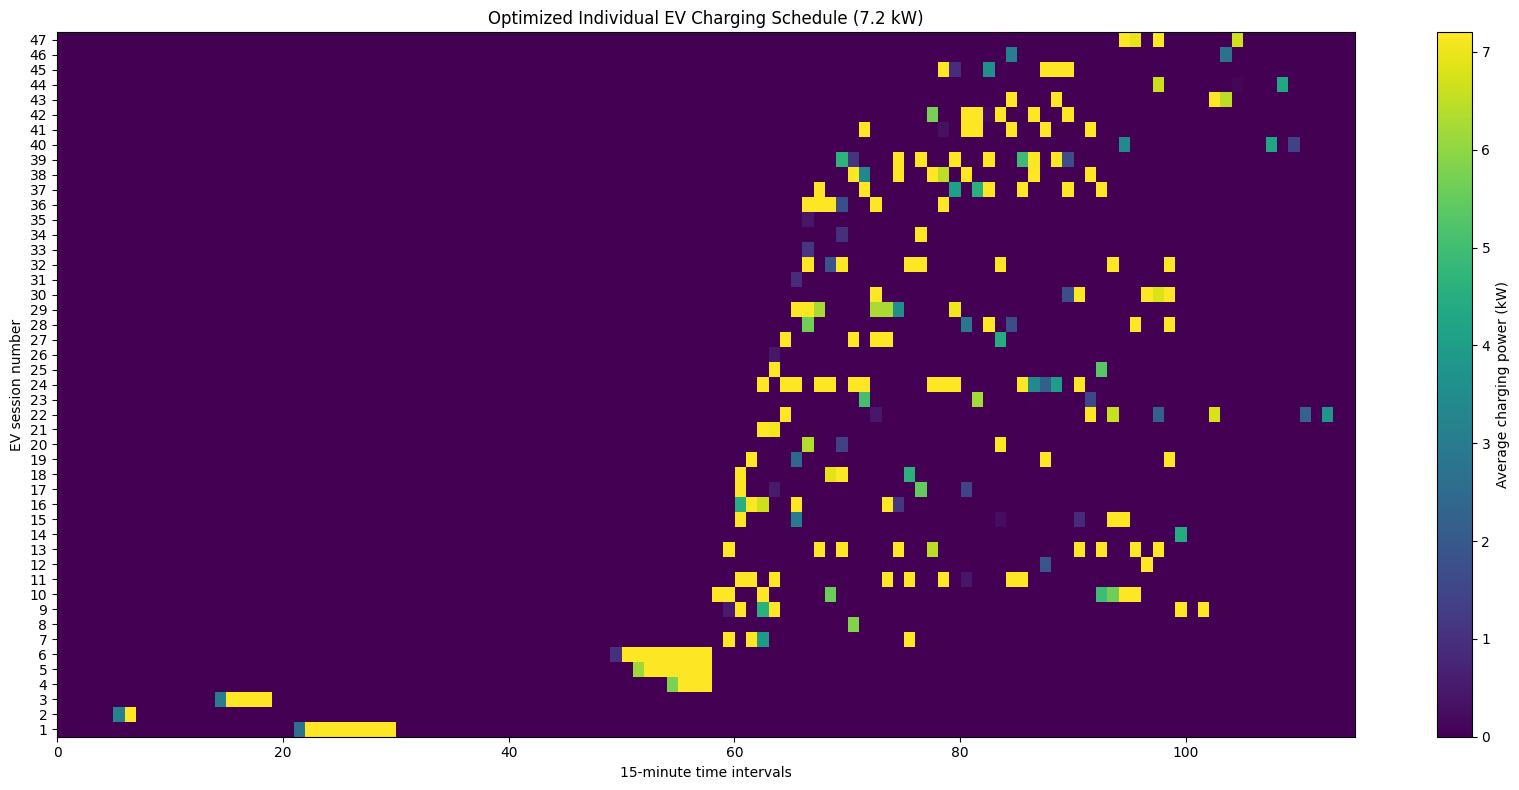

In [97]:

# STAGE 7 — INDIVIDUAL EV CHARGING SCHEDULE
# Baseline scenario: 7.2 kW charger

import matplotlib.pyplot as plt
import numpy as np

power_limit = 7.2

solution = corrected_solutions[power_limit]

variables = solution["variables"]
allocation = solution["allocation"]

n_ev = len(common_cohort)
n_slots = len(slots_55)

# Create EV x time charging power matrix
charging_matrix = np.zeros((n_ev, n_slots))

for k, (i, j, overlap_hours) in enumerate(variables):

    # Average power during the EV's available portion
    charging_matrix[i, j] = allocation[k] / overlap_hours

# Plot charging schedule
plt.figure(figsize=(17, 8))

plt.imshow(
    charging_matrix,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    extent=[0, n_slots, 0, n_ev]
)

plt.colorbar(label="Average charging power (kW)")

plt.xlabel("15-minute time intervals")
plt.ylabel("EV session number")

plt.title(
    "Optimized Individual EV Charging Schedule (7.2 kW)"
)

plt.yticks(np.arange(n_ev) + 0.5, np.arange(1, n_ev + 1))

plt.tight_layout()
plt.show()


In [98]:

# INDIVIDUAL EV CHARGING PERFORMANCE ANALYSIS
# 7.2 kW scenario

session_details = corrected_solutions[7.2]["session_details"].copy()

session_details["duration_hours"] = (
    session_details["departure_time"] -
    session_details["arrival_time"]
).dt.total_seconds() / 3600

session_details["average_charging_power_kw"] = (
    session_details["delivered_energy_kwh"] /
    session_details["duration_hours"]
)

print("========== INDIVIDUAL EV CHARGING STATISTICS ==========")

print(
    session_details[
        [
            "session_id",
            "required_energy_kwh",
            "delivered_energy_kwh",
            "duration_hours",
            "maximum_charging_power_kw",
            "average_charging_power_kw"
        ]
    ].head(10).round(3).to_string(index=False)
)

print("\n========== SUMMARY STATISTICS ==========")

print(
    session_details[
        [
            "required_energy_kwh",
            "duration_hours",
            "maximum_charging_power_kw",
            "average_charging_power_kw"
        ]
    ].describe().round(3)
)


========== INDIVIDUAL EV CHARGING STATISTICS ==========
                                    session_id  required_energy_kwh  delivered_energy_kwh  duration_hours  maximum_charging_power_kw  average_charging_power_kw
 2-39-127-19-2018-05-01T01-00-22-472519.csv.gz               14.650                14.650           6.934                      7.200                      2.113
 2-39-129-17-2018-05-01T01-31-03-442958.csv.gz                1.961                 1.961           0.645                      7.200                      3.042
 2-39-79-380-2018-05-01T02-10-29-102131.csv.gz                7.432                 7.432           3.002                      7.200                      2.475
 2-39-79-379-2018-05-01T03-08-47-017440.csv.gz                6.848                 6.848          13.652                      7.200                      0.502
2-39-138-566-2018-05-01T04-55-58-860904.csv.gz               12.342                12.342          14.627                      7.200            

========== CHARGING POWER DISTRIBUTION ==========
EV sessions: 47
Maximum allocated power: 7.2 kW
Mean maximum allocated power: 6.378 kW
Median maximum allocated power: 7.2 kW

========== POWER UTILIZATION ==========
EVs reaching 7.2 kW: 37
EVs below 7.2 kW: 10


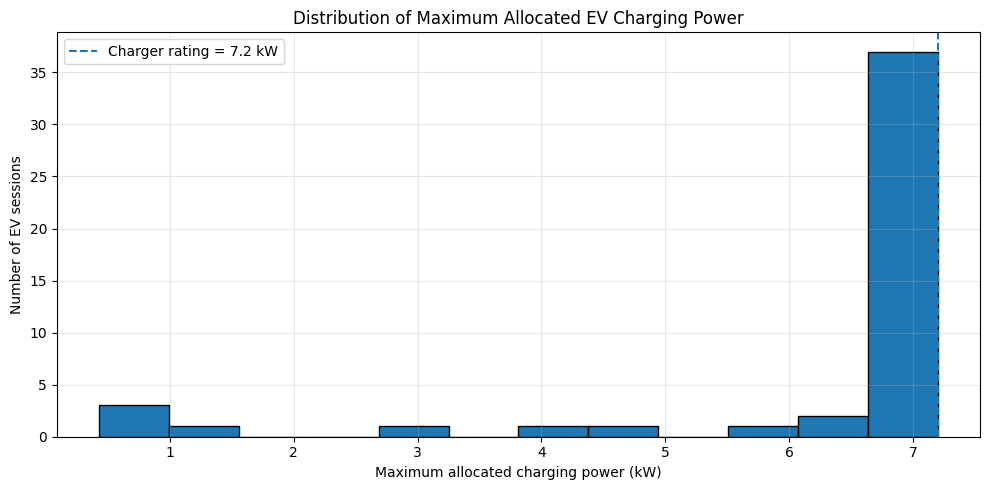

In [99]:

# CHARGING POWER DISTRIBUTION ANALYSIS

session_details = corrected_solutions[7.2]["session_details"].copy()

power = session_details["maximum_charging_power_kw"]

print("========== CHARGING POWER DISTRIBUTION ==========")

print("EV sessions:", len(power))
print("Maximum allocated power:", round(power.max(), 3), "kW")
print("Mean maximum allocated power:", round(power.mean(), 3), "kW")
print("Median maximum allocated power:", round(power.median(), 3), "kW")

print("\n========== POWER UTILIZATION ==========")

print("EVs reaching 7.2 kW:",
      (power >= 7.2 - 1e-6).sum())

print("EVs below 7.2 kW:",
      (power < 7.2 - 1e-6).sum())

plt.figure(figsize=(10, 5))

plt.hist(
    power,
    bins=12,
    edgecolor="black"
)

plt.axvline(
    7.2,
    linestyle="--",
    label="Charger rating = 7.2 kW"
)

plt.xlabel("Maximum allocated charging power (kW)")
plt.ylabel("Number of EV sessions")
plt.title("Distribution of Maximum Allocated EV Charging Power")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [100]:

# STAGE 8 — PREPARE FORECAST-DRIVEN OPTIMIZATION
# Inspect existing forecasting variables

print("========== FORECAST DATA ==========")

print("Forecast dataset shape:", forecast_df.shape)
print("Forecast dataset columns:")
print(forecast_df.columns.tolist())

print("\n========== MODEL DATA ==========")

print("Model dataset shape:", model_df.shape)

print("\n========== TEST PERIOD ==========")

print("Test start:", X_test.index.min())
print("Test end:", X_test.index.max())

print("\n========== XGBOOST PREDICTIONS ==========")

print("Actual test observations:", len(y_test))
print("Predicted observations:", len(y_pred_xgb_clipped))

print("\nFirst 10 actual and predicted values:")

forecast_comparison = pd.DataFrame({
    "actual_power_kw": np.asarray(y_test)[:10],
    "predicted_power_kw": np.asarray(y_pred_xgb_clipped)[:10]
})

print(forecast_comparison.round(3).to_string(index=False))


========== FORECAST DATA ==========
Forecast dataset shape: (90816, 7)
Forecast dataset columns:
['timestamp', 'energy_kwh', 'average_power_kw', 'date', 'hour', 'day_of_week', 'month']

========== MODEL DATA ==========
Model dataset shape: (90144, 20)

========== TEST PERIOD ==========
Test start: 72115
Test end: 90143

========== XGBOOST PREDICTIONS ==========
Actual test observations: 18029
Predicted observations: 18029

First 10 actual and predicted values:
 actual_power_kw  predicted_power_kw
             0.0               0.042
             0.0               0.000
             0.0               0.000
             0.0               0.000
             0.0               0.000
             0.0               0.000
             0.0               0.000
             0.0               0.000
             0.0               0.000
             0.0               0.000


In [101]:

# CHECK TIMESTAMP ALIGNMENT FOR FORECAST PREDICTIONS

print("========== MODEL DATA ==========")

print("Columns:", model_df.columns.tolist())
print("Index type:", type(model_df.index))
print("First 5 model rows:")
print(model_df.head())

print("\n========== TEST DATA INDEX ==========")

print("X_test first indices:", X_test.index[:5].tolist())
print("X_test last indices:", X_test.index[-5:].tolist())

print("\n========== FORECAST DATA TIMESTAMPS ==========")

print("First timestamps:")
print(forecast_df["timestamp"].head().to_string(index=False))

print("\nLast timestamps:")
print(forecast_df["timestamp"].tail().to_string(index=False))

print("\n========== CHECK TIMESTAMP COLUMN ==========")

if "timestamp" in model_df.columns:
    print("Timestamp column exists in model_df.")
    print(model_df["timestamp"].head())
else:
    print("No timestamp column in model_df.")

print("\n========== TEST PREDICTION ALIGNMENT ==========")

print("First test index:", X_test.index[0])
print("Last test index:", X_test.index[-1])
print("Number of predictions:", len(y_pred_xgb_clipped))


========== MODEL DATA ==========
Columns: ['timestamp', 'energy_kwh', 'average_power_kw', 'date', 'hour', 'day_of_week', 'month', 'target_power_kw', 'day_of_year', 'is_weekend', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'lag_1', 'lag_4', 'lag_96', 'lag_672', 'rolling_mean_4', 'rolling_mean_96']
Index type: <class 'pandas.core.indexes.range.RangeIndex'>
First 5 model rows:
                  timestamp  energy_kwh  average_power_kw        date  hour  \
0 2018-05-09 00:00:00+00:00    5.288289         21.153155  2018-05-09     0   
1 2018-05-09 00:15:00+00:00    5.298680         21.194722  2018-05-09     0   
2 2018-05-09 00:30:00+00:00    5.316605         21.266418  2018-05-09     0   
3 2018-05-09 00:45:00+00:00    6.048142         24.192566  2018-05-09     0   
4 2018-05-09 01:00:00+00:00    3.770729         15.082914  2018-05-09     1   

   day_of_week  month  target_power_kw  day_of_year  is_weekend  hour_sin  \
0            2      5        21.153155          129           0  0.00

In [102]:

# MATCH EV SESSIONS WITH XGBOOST TEST PERIOD

# Create timestamp-aligned forecasting dataset
test_forecast_df = pd.DataFrame({
    "timestamp": model_df.loc[X_test.index, "timestamp"].to_numpy(),
    "actual_power_kw": np.asarray(y_test),
    "predicted_power_kw": np.asarray(y_pred_xgb_clipped)
})

test_forecast_df["timestamp"] = pd.to_datetime(
    test_forecast_df["timestamp"], utc=True
)

test_start = test_forecast_df["timestamp"].min()
test_end = test_forecast_df["timestamp"].max()

# Find EV sessions overlapping the test period
test_sessions = clean_sessions[
    (clean_sessions["arrival_time"] <= test_end) &
    (clean_sessions["departure_time"] >= test_start)
].copy()

# Count sessions by arrival date
test_sessions["arrival_date"] = (
    test_sessions["arrival_time"].dt.date
)

daily_session_counts = (
    test_sessions.groupby("arrival_date")
    .size()
    .sort_values(ascending=False)
)

print("========== FORECAST PERIOD ==========")
print("Start:", test_start)
print("End:", test_end)
print("Forecast observations:", len(test_forecast_df))

print("\n========== MATCHING EV SESSIONS ==========")
print("Sessions overlapping test period:", len(test_sessions))

print("\n========== TOP 15 DAYS BY EV ARRIVALS ==========")
print(daily_session_counts.head(15).to_string())

print("\n========== TIMESTAMP ALIGNMENT CHECK ==========")
print("Unique timestamps:",
      test_forecast_df["timestamp"].nunique())

print("Missing predicted values:",
      test_forecast_df["predicted_power_kw"].isna().sum())


========== FORECAST PERIOD ==========
Start: 2020-05-29 04:45:00+00:00
End: 2020-12-02 23:45:00+00:00
Forecast observations: 18029

========== MATCHING EV SESSIONS ==========
Sessions overlapping test period: 498

========== TOP 15 DAYS BY EV ARRIVALS ==========
arrival_date
2020-10-30    12
2020-09-07    11
2020-12-01    10
2020-10-23     9
2020-10-19     9
2020-12-02     8
2020-11-11     8
2020-11-18     8
2020-10-24     7
2020-10-25     7
2020-10-29     7
2020-09-20     7
2020-11-24     7
2020-11-20     7
2020-11-25     7

========== TIMESTAMP ALIGNMENT CHECK ==========
Unique timestamps: 18029
Missing predicted values: 0


In [103]:

# SELECT OCTOBER 30, 2020 EV COHORT

selected_date = pd.Timestamp("2020-10-30").date()

oct30_sessions = test_sessions[
    test_sessions["arrival_date"] == selected_date
].copy()

oct30_sessions["duration_hours"] = (
    oct30_sessions["departure_time"] -
    oct30_sessions["arrival_time"]
).dt.total_seconds() / 3600

oct30_sessions["grid_energy_kwh"] = (
    oct30_sessions["clean_energy_kwh"] / 0.95
)

print("========== OCTOBER 30, 2020 EV COHORT ==========")

print("Number of sessions:", len(oct30_sessions))

print(
    oct30_sessions[
        [
            "session_id",
            "arrival_time",
            "departure_time",
            "duration_hours",
            "clean_energy_kwh",
            "grid_energy_kwh"
        ]
    ].sort_values("arrival_time").round(3).to_string(index=False)
)

print("\n========== COHORT SUMMARY ==========")

print("Total required grid energy:",
      round(oct30_sessions["grid_energy_kwh"].sum(), 3), "kWh")

print("Average session duration:",
      round(oct30_sessions["duration_hours"].mean(), 2), "hours")

print("Latest departure:",
      oct30_sessions["departure_time"].max())


========== OCTOBER 30, 2020 EV COHORT ==========
Number of sessions: 12
                                    session_id                     arrival_time                   departure_time  duration_hours  clean_energy_kwh  grid_energy_kwh
2-39-81-4550-2020-10-30T06-07-44-142150.csv.gz 2020-10-30 06:07:47.484599+00:00 2020-10-30 06:22:32.877407+00:00           0.246             4.140            4.358
2-39-81-4550-2020-10-30T06-54-28-365954.csv.gz 2020-10-30 06:54:28.753770+00:00 2020-10-30 07:55:24.751641+00:00           1.016            33.662           35.434
 2-39-125-21-2020-10-30T14-59-52-469959.csv.gz        2020-10-30 14:59:52+00:00        2020-10-30 15:49:03+00:00           0.820             1.787            1.881
 2-39-138-29-2020-10-30T15-49-41-012877.csv.gz        2020-10-30 15:49:44+00:00        2020-10-30 17:55:23+00:00           2.094            13.976           14.711
2-39-81-4550-2020-10-30T16-03-08-155236.csv.gz 2020-10-30 16:03:12.326667+00:00 2020-10-30 16:27:32.746019+0

In [104]:

# OCTOBER 30 COHORT — CHARGER FEASIBILITY ANALYSIS

charger_limits = [3.3, 7.2, 11.0]

feasibility_results = []

oct30_sessions["required_grid_energy_kwh"] = (
    oct30_sessions["clean_energy_kwh"] / 0.95
)

for power_limit in charger_limits:

    oct30_sessions[f"max_energy_{power_limit}kw"] = (
        power_limit * oct30_sessions["duration_hours"]
    )

    oct30_sessions[f"feasible_{power_limit}kw"] = (
        oct30_sessions["required_grid_energy_kwh"]
        <= oct30_sessions[f"max_energy_{power_limit}kw"]
    )

    feasibility_results.append({
        "charger_rating_kw": power_limit,
        "total_sessions": len(oct30_sessions),
        "feasible_sessions": int(
            oct30_sessions[f"feasible_{power_limit}kw"].sum()
        ),
        "infeasible_sessions": int(
            (~oct30_sessions[f"feasible_{power_limit}kw"]).sum()
        )
    })

print("========== OCTOBER 30 CHARGER FEASIBILITY ==========")

print(
    pd.DataFrame(feasibility_results).to_string(index=False)
)

print("\n========== SESSION-LEVEL FEASIBILITY AT 7.2 kW ==========")

print(
    oct30_sessions[
        [
            "session_id",
            "duration_hours",
            "required_grid_energy_kwh",
            "max_energy_7.2kw",
            "feasible_7.2kw"
        ]
    ].round(3).to_string(index=False)
)


========== OCTOBER 30 CHARGER FEASIBILITY ==========
 charger_rating_kw  total_sessions  feasible_sessions  infeasible_sessions
               3.3              12                  4                    8
               7.2              12                  5                    7
              11.0              12                  8                    4

========== SESSION-LEVEL FEASIBILITY AT 7.2 kW ==========
                                    session_id  duration_hours  required_grid_energy_kwh  max_energy_7.2kw  feasible_7.2kw
 2-39-125-21-2020-10-30T14-59-52-469959.csv.gz           0.820                     1.881             5.902            True
 2-39-130-31-2020-10-30T17-29-40-460304.csv.gz           9.519                     6.592            68.538            True
 2-39-138-29-2020-10-30T15-49-41-012877.csv.gz           2.094                    14.711            15.078            True
 2-39-78-365-2020-10-30T20-31-25-542260.csv.gz           6.406                     2.408        

In [105]:

# CREATE FEASIBLE OCTOBER 30 COHORT AT 7.2 kW

oct30_feasible = oct30_sessions[
    oct30_sessions["feasible_7.2kw"]
].copy()

oct30_infeasible = oct30_sessions[
    ~oct30_sessions["feasible_7.2kw"]
].copy()

oct30_feasible = oct30_feasible.sort_values(
    "arrival_time"
).reset_index(drop=True)

print("========== FEASIBLE COHORT ==========")

print("Selected EV sessions:", len(oct30_feasible))

print(
    "Total required grid energy:",
    round(oct30_feasible["required_grid_energy_kwh"].sum(), 3),
    "kWh"
)

print(
    "Total infeasible sessions:",
    len(oct30_infeasible)
)

print("\nSelected sessions:")

print(
    oct30_feasible[
        [
            "session_id",
            "arrival_time",
            "departure_time",
            "duration_hours",
            "required_grid_energy_kwh"
        ]
    ].round(3).to_string(index=False)
)


========== FEASIBLE COHORT ==========
Selected EV sessions: 5
Total required grid energy: 28.704 kWh
Total infeasible sessions: 7

Selected sessions:
                                   session_id              arrival_time            departure_time  duration_hours  required_grid_energy_kwh
2-39-125-21-2020-10-30T14-59-52-469959.csv.gz 2020-10-30 14:59:52+00:00 2020-10-30 15:49:03+00:00           0.820                     1.881
2-39-138-29-2020-10-30T15-49-41-012877.csv.gz 2020-10-30 15:49:44+00:00 2020-10-30 17:55:23+00:00           2.094                    14.711
2-39-130-31-2020-10-30T17-29-40-460304.csv.gz 2020-10-30 17:30:09+00:00 2020-10-31 03:01:18+00:00           9.519                     6.592
2-39-78-365-2020-10-30T20-31-25-542260.csv.gz 2020-10-30 20:31:28+00:00 2020-10-31 02:55:48+00:00           6.406                     2.408
2-39-79-379-2020-10-30T20-34-27-346844.csv.gz 2020-10-30 20:34:30+00:00 2020-10-31 01:11:40+00:00           4.619                     3.113


In [106]:

# INSPECT ONE SELECTED OCTOBER 30 RAW SESSION

import os
import pandas as pd

sample_session_id = oct30_feasible.iloc[0]["session_id"]

sample_path = os.path.join(
    caltech_path,
    sample_session_id
)

sample_raw = pd.read_csv(
    sample_path,
    compression="gzip"
)

print("========== RAW SESSION INSPECTION ==========")

print("File:", sample_session_id)

print("\nColumns:")
print(sample_raw.columns.tolist())

print("\nFirst 10 records:")
print(sample_raw.head(10).to_string(index=False))

print("\nData types:")
print(sample_raw.dtypes)

print("\nNumber of records:", len(sample_raw))


========== RAW SESSION INSPECTION ==========
File: 2-39-125-21-2020-10-30T14-59-52-469959.csv.gz

Columns:
['Unnamed: 0', 'Charging Current (A)', 'Actual Pilot (A)', 'Voltage (V)', 'Charging State', 'Energy Delivered (kWh)', 'Power (kW)']

First 10 records:
               Unnamed: 0  Charging Current (A)  Actual Pilot (A)  Voltage (V) Charging State  Energy Delivered (kWh)  Power (kW)
2020-10-30T14:59:52+00:00                   0.0               8.0        222.7          READY                0.000000       0.000
2020-10-30T14:59:56+00:00                   0.4               8.0        222.6          READY                0.000043       0.001
2020-10-30T15:00:00+00:00                   2.8               8.0        222.5       ADAPTIVE                0.000362       0.605
2020-10-30T15:00:04+00:00                   7.1               8.0        222.1       ADAPTIVE                0.001647       1.572
2020-10-30T15:00:08+00:00                   8.6               8.0        221.7       ADAPTIV

In [107]:

# RECONSTRUCT ACTUAL 15-MINUTE ENERGY FOR FIVE EV SESSIONS

import os
import numpy as np
import pandas as pd

DT = 0.25

# Create the full time window covering all five sessions
window_start = oct30_feasible["arrival_time"].min().floor("15min")
window_end = oct30_feasible["departure_time"].max().ceil("15min")

reconstruction_slots = pd.date_range(
    start=window_start,
    end=window_end - pd.Timedelta(minutes=15),
    freq="15min"
)

actual_ev_energy = np.zeros(len(reconstruction_slots))

session_reconstruction_results = []

for _, session in oct30_feasible.iterrows():

    file_path = os.path.join(
        caltech_path,
        session["session_id"]
    )

    raw = pd.read_csv(file_path, compression="gzip")

    raw["timestamp"] = pd.to_datetime(
        raw["Unnamed: 0"], utc=True
    )

    raw = raw.sort_values("timestamp").reset_index(drop=True)

    counter = pd.to_numeric(
        raw["Energy Delivered (kWh)"],
        errors="coerce"
    )

    timestamps = raw["timestamp"]

    session_energy = 0.0

    for k in range(1, len(raw)):

        t0 = timestamps.iloc[k - 1]
        t1 = timestamps.iloc[k]

        e0 = counter.iloc[k - 1]
        e1 = counter.iloc[k]

        if pd.isna(e0) or pd.isna(e1):
            continue

        # Ignore negative counter changes (resets)
        increment = e1 - e0

        if increment <= 0:
            continue

        total_seconds = (t1 - t0).total_seconds()

        if total_seconds <= 0:
            continue

        session_energy += increment

        # Distribute energy across overlapping 15-minute intervals
        for j, slot_start in enumerate(reconstruction_slots):

            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(t0, slot_start)
            overlap_end = min(t1, slot_end)

            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap_seconds > 0:

                fraction = overlap_seconds / total_seconds

                actual_ev_energy[j] += increment * fraction

    session_reconstruction_results.append({
        "session_id": session["session_id"],
        "clean_energy_kwh": session["clean_energy_kwh"],
        "reconstructed_energy_kwh": session_energy,
        "difference_kwh": (
            session_energy - session["clean_energy_kwh"]
        )
    })

reconstruction_df = pd.DataFrame(
    session_reconstruction_results
)

print("========== SESSION RECONSTRUCTION ==========")

print(reconstruction_df.round(6).to_string(index=False))

print("\n========== TOTAL RECONSTRUCTION ==========")

print("Selected sessions:", len(reconstruction_df))

print(
    "Expected clean energy:",
    round(reconstruction_df["clean_energy_kwh"].sum(), 6),
    "kWh"
)

print(
    "Reconstructed energy:",
    round(actual_ev_energy.sum(), 6),
    "kWh"
)

print(
    "Difference:",
    round(
        actual_ev_energy.sum()
        - reconstruction_df["clean_energy_kwh"].sum(),
        6
    ),
    "kWh"
)

print("15-minute intervals:", len(actual_ev_energy))


========== SESSION RECONSTRUCTION ==========
                                   session_id  clean_energy_kwh  reconstructed_energy_kwh  difference_kwh
2-39-125-21-2020-10-30T14-59-52-469959.csv.gz          1.786580                  1.786580             0.0
2-39-138-29-2020-10-30T15-49-41-012877.csv.gz         13.975621                 13.975621            -0.0
2-39-130-31-2020-10-30T17-29-40-460304.csv.gz          6.262346                  6.262346             0.0
2-39-78-365-2020-10-30T20-31-25-542260.csv.gz          2.287274                  2.287274             0.0
2-39-79-379-2020-10-30T20-34-27-346844.csv.gz          2.956875                  2.956875             0.0

========== TOTAL RECONSTRUCTION ==========
Selected sessions: 5
Expected clean energy: 27.268697 kWh
Reconstructed energy: 27.268697 kWh
Difference: -0.0 kWh
15-minute intervals: 50


In [108]:

# RECONSTRUCT FIXED BACKGROUND STATION DEMAND
# October 30–31, 2020

# Align actual station energy with our 50 optimization intervals
station_oct30 = station_profile_complete.copy()

station_oct30["timestamp"] = pd.to_datetime(
    station_oct30["timestamp"], utc=True
)

station_aligned = (
    station_oct30.set_index("timestamp")
    .reindex(reconstruction_slots)
)

if station_aligned["energy_kwh"].isna().any():
    raise ValueError("Missing station energy in selected intervals.")

measured_station_energy = (
    station_aligned["energy_kwh"].to_numpy()
)

# Calculate residual background energy
background_energy = (
    measured_station_energy - actual_ev_energy
)

background_power = background_energy / DT

print("========== STATION ENERGY RECONSTRUCTION ==========")

print(
    "Measured station energy:",
    round(measured_station_energy.sum(), 6), "kWh"
)

print(
    "Selected EV energy:",
    round(actual_ev_energy.sum(), 6), "kWh"
)

print(
    "Estimated background energy:",
    round(background_energy.sum(), 6), "kWh"
)

print(
    "Minimum background energy:",
    round(background_energy.min(), 6), "kWh"
)

print(
    "Maximum background demand:",
    round(background_power.max(), 6), "kW"
)

print(
    "Negative background intervals:",
    int((background_energy < -1e-6).sum())
)

print("\n========== FIRST 10 INTERVALS ==========")

background_check_df = pd.DataFrame({
    "timestamp": reconstruction_slots,
    "station_energy_kwh": measured_station_energy,
    "selected_ev_energy_kwh": actual_ev_energy,
    "background_energy_kwh": background_energy,
    "background_power_kw": background_power
})

print(background_check_df.head(10).round(4).to_string(index=False))


========== STATION ENERGY RECONSTRUCTION ==========
Measured station energy: 95.609697 kWh
Selected EV energy: 27.268697 kWh
Estimated background energy: 68.341 kWh
Minimum background energy: -0.0 kWh
Maximum background demand: 39.983973 kW
Negative background intervals: 0

========== FIRST 10 INTERVALS ==========
                timestamp  station_energy_kwh  selected_ev_energy_kwh  background_energy_kwh  background_power_kw
2020-10-30 14:45:00+00:00              0.0004                  0.0004                  0.000                0.000
2020-10-30 15:00:00+00:00              0.8094                  0.8094                  0.000                0.000
2020-10-30 15:15:00+00:00              0.7402                  0.7402                  0.000                0.000
2020-10-30 15:30:00+00:00              0.2291                  0.2291                  0.000                0.000
2020-10-30 15:45:00+00:00              1.0722                  1.0722                  0.000                0.000


In [109]:

# ALIGN XGBOOST FORECAST WITH OCTOBER 30 STATION PROFILE

# Build forecast lookup table
forecast_lookup = test_forecast_df.set_index("timestamp")

# Actual selected EV demand in kW
selected_ev_power = actual_ev_energy / DT

# Match forecast timestamps to optimization intervals
aligned_forecast = forecast_lookup.reindex(
    reconstruction_slots
)

if aligned_forecast["predicted_power_kw"].isna().any():
    raise ValueError(
        "Some optimization timestamps have no XGBoost predictions."
    )

# Actual station demand
actual_station_power = measured_station_energy / DT

# XGBoost predictions represent total station demand
predicted_station_power = (
    aligned_forecast["predicted_power_kw"].to_numpy()
)

# Estimate forecast-based background demand by removing
# the selected EVs' historical charging contribution.
forecast_background_power = np.maximum(
    predicted_station_power - selected_ev_power,
    0
)

forecast_alignment_df = pd.DataFrame({
    "timestamp": reconstruction_slots,
    "actual_station_kw": actual_station_power,
    "predicted_station_kw": predicted_station_power,
    "actual_selected_ev_kw": selected_ev_power,
    "actual_background_kw": background_power,
    "estimated_forecast_background_kw": forecast_background_power
})

print("========== FORECAST ALIGNMENT ==========")

print("Intervals:", len(forecast_alignment_df))

print(
    "Actual station peak:",
    round(actual_station_power.max(), 3), "kW"
)

print(
    "Predicted station peak:",
    round(predicted_station_power.max(), 3), "kW"
)

print(
    "Actual background peak:",
    round(background_power.max(), 3), "kW"
)

print(
    "Estimated forecast background peak:",
    round(forecast_background_power.max(), 3), "kW"
)

print(
    "Forecast background zero intervals:",
    int((forecast_background_power == 0).sum())
)

print("\n========== FIRST 15 INTERVALS ==========")

print(
    forecast_alignment_df.head(15).round(3).to_string(index=False)
)


========== FORECAST ALIGNMENT ==========
Intervals: 50
Actual station peak: 39.984 kW
Predicted station peak: 40.894 kW
Actual background peak: 39.984 kW
Estimated forecast background peak: 40.46 kW
Forecast background zero intervals: 9

========== FIRST 15 INTERVALS ==========
                timestamp  actual_station_kw  predicted_station_kw  actual_selected_ev_kw  actual_background_kw  estimated_forecast_background_kw
2020-10-30 14:45:00+00:00              0.001              0.304000                  0.001                 0.000                             0.303
2020-10-30 15:00:00+00:00              3.238              1.342000                  3.238                 0.000                             0.000
2020-10-30 15:15:00+00:00              2.961              5.611000                  2.961                 0.000                             2.650
2020-10-30 15:30:00+00:00              0.917              3.998000                  0.917                 0.000                          

========== LOCAL FORECAST PERFORMANCE ==========
Observations: 50
MAE: 5.3798 kW
RMSE: 10.0018 kW
Forecast bias: 0.5229 kW
WAPE: 70.34 %


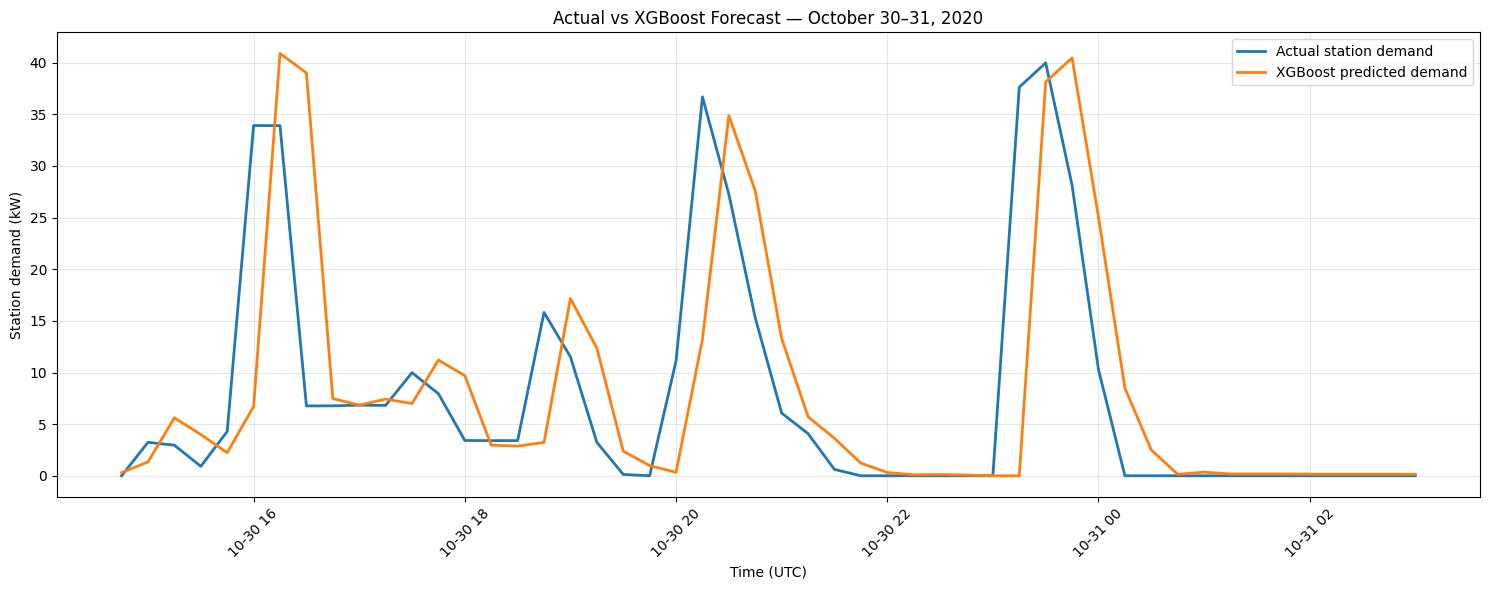

In [110]:

# LOCAL XGBOOST FORECAST ACCURACY — OCTOBER 30 COHORT WINDOW

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

actual = forecast_alignment_df["actual_station_kw"].to_numpy()
predicted = forecast_alignment_df["predicted_station_kw"].to_numpy()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

bias = np.mean(predicted - actual)

wape = (
    np.sum(np.abs(actual - predicted)) /
    np.sum(np.abs(actual))
) * 100

print("========== LOCAL FORECAST PERFORMANCE ==========")

print("Observations:", len(actual))
print("MAE:", round(mae, 4), "kW")
print("RMSE:", round(rmse, 4), "kW")
print("Forecast bias:", round(bias, 4), "kW")
print("WAPE:", round(wape, 2), "%")

# Plot actual versus predicted station demand
plt.figure(figsize=(15, 6))

plt.plot(
    reconstruction_slots,
    actual,
    label="Actual station demand",
    linewidth=2
)

plt.plot(
    reconstruction_slots,
    predicted,
    label="XGBoost predicted demand",
    linewidth=2
)

plt.xlabel("Time (UTC)")
plt.ylabel("Station demand (kW)")
plt.title("Actual vs XGBoost Forecast — October 30–31, 2020")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [111]:

# IDENTIFY THE LARGEST XGBOOST FORECAST ERRORS

error_analysis = forecast_alignment_df.copy()

error_analysis["forecast_error_kw"] = (
    error_analysis["predicted_station_kw"]
    - error_analysis["actual_station_kw"]
)

error_analysis["absolute_error_kw"] = (
    error_analysis["forecast_error_kw"].abs()
)

# Sort by largest absolute errors
largest_errors = error_analysis.sort_values(
    "absolute_error_kw",
    ascending=False
)

print("========== TOP 15 FORECAST ERRORS ==========")

print(
    largest_errors[
        [
            "timestamp",
            "actual_station_kw",
            "predicted_station_kw",
            "forecast_error_kw",
            "absolute_error_kw"
        ]
    ].head(15).round(3).to_string(index=False)
)

print("\n========== ERROR DISTRIBUTION ==========")

print(
    error_analysis["forecast_error_kw"].describe().round(3)
)


========== TOP 15 FORECAST ERRORS ==========
                timestamp  actual_station_kw  predicted_station_kw  forecast_error_kw  absolute_error_kw
2020-10-30 23:15:00+00:00             37.628              0.000000            -37.628             37.628
2020-10-30 16:30:00+00:00              6.762             39.002998             32.241             32.241
2020-10-30 16:00:00+00:00             33.914              6.712000            -27.202             27.202
2020-10-30 20:15:00+00:00             36.690             13.216000            -23.475             23.475
2020-10-31 00:00:00+00:00             10.284             25.044001             14.760             14.760
2020-10-30 18:45:00+00:00             15.811              3.233000            -12.578             12.578
2020-10-30 23:45:00+00:00             28.132             40.459999             12.328             12.328
2020-10-30 20:45:00+00:00             15.295             27.573000             12.278             12.278
2020-10-30

In [112]:

# STAGE 8 — RECURSIVE MULTI-STEP XGBOOST FORECAST

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Forecast horizon
forecast_timestamps = pd.DatetimeIndex(reconstruction_slots)

forecast_start = forecast_timestamps[0]
forecast_end = forecast_timestamps[-1]

# Historical actual demand available before forecast origin
historical = (
    forecast_df
    .assign(timestamp=pd.to_datetime(forecast_df["timestamp"], utc=True))
    .set_index("timestamp")["average_power_kw"]
    .sort_index()
)

history = historical[historical.index < forecast_start].copy()

# Calendar features are taken from the existing feature dataset.
calendar_columns = [
    "hour", "day_of_week", "month", "day_of_year",
    "is_weekend", "hour_sin", "hour_cos",
    "day_sin", "day_cos"
]

feature_columns = [
    "hour", "day_of_week", "month", "day_of_year",
    "is_weekend", "hour_sin", "hour_cos",
    "day_sin", "day_cos",
    "lag_1", "lag_4", "lag_96", "lag_672",
    "rolling_mean_4", "rolling_mean_96"
]

# Calendar feature lookup
model_calendar = (
    model_df
    .assign(timestamp=pd.to_datetime(model_df["timestamp"], utc=True))
    .set_index("timestamp")
)

recursive_predictions = []

for timestamp in forecast_timestamps:

    # Calendar features for this timestamp
    row = model_calendar.loc[timestamp, calendar_columns].copy()

    # Historical / recursively predicted lag values
    row["lag_1"] = history.loc[
        timestamp - pd.Timedelta(minutes=15)
    ]

    row["lag_4"] = history.loc[
        timestamp - pd.Timedelta(minutes=60)
    ]

    row["lag_96"] = history.loc[
        timestamp - pd.Timedelta(hours=24)
    ]

    row["lag_672"] = history.loc[
        timestamp - pd.Timedelta(days=7)
    ]

    # Rolling means use only values before current timestamp
    previous_4 = history.loc[
        timestamp - pd.Timedelta(minutes=60):
        timestamp - pd.Timedelta(minutes=15)
    ]

    previous_96 = history.loc[
        timestamp - pd.Timedelta(days=1):
        timestamp - pd.Timedelta(minutes=15)
    ]

    if len(previous_4) != 4 or len(previous_96) != 96:
        raise ValueError(
            f"Insufficient historical values for {timestamp}"
        )

    row["rolling_mean_4"] = previous_4.mean()
    row["rolling_mean_96"] = previous_96.mean()

    # Predict one interval ahead
    X_current = pd.DataFrame(
        [row[feature_columns].to_dict()],
        columns=feature_columns
    )

    prediction = float(
        xgb_model.predict(X_current)[0]
    )

    # Prevent physically impossible negative demand
    prediction = max(prediction, 0)

    recursive_predictions.append(prediction)

    # Feed prediction into history for the next interval
    history.loc[timestamp] = prediction

# Compare recursive forecast against actual station demand
recursive_comparison = pd.DataFrame({
    "timestamp": forecast_timestamps,
    "actual_power_kw": forecast_alignment_df[
        "actual_station_kw"
    ].to_numpy(),
    "recursive_predicted_power_kw": recursive_predictions,
    "rolling_predicted_power_kw": forecast_alignment_df[
        "predicted_station_kw"
    ].to_numpy()
})

# Metrics
actual = recursive_comparison["actual_power_kw"].to_numpy()
recursive = recursive_comparison[
    "recursive_predicted_power_kw"
].to_numpy()

recursive_mae = mean_absolute_error(actual, recursive)
recursive_rmse = np.sqrt(mean_squared_error(actual, recursive))

recursive_wape = (
    np.sum(np.abs(actual - recursive)) /
    np.sum(np.abs(actual))
) * 100

print("========== RECURSIVE FORECAST PERFORMANCE ==========")
print("Forecast intervals:", len(recursive))
print("MAE:", round(recursive_mae, 4), "kW")
print("RMSE:", round(recursive_rmse, 4), "kW")
print("WAPE:", round(recursive_wape, 2), "%")

print("\n========== FIRST 15 PREDICTIONS ==========")

print(
    recursive_comparison.head(15).round(3).to_string(index=False)
)


========== RECURSIVE FORECAST PERFORMANCE ==========
Forecast intervals: 50
MAE: 15.1086 kW
RMSE: 18.3812 kW
WAPE: 197.53 %

========== FIRST 15 PREDICTIONS ==========
                timestamp  actual_power_kw  recursive_predicted_power_kw  rolling_predicted_power_kw
2020-10-30 14:45:00+00:00            0.001                         0.304                    0.304000
2020-10-30 15:00:00+00:00            3.238                         3.873                    1.342000
2020-10-30 15:15:00+00:00            2.961                         7.929                    5.611000
2020-10-30 15:30:00+00:00            0.917                        11.713                    3.998000
2020-10-30 15:45:00+00:00            4.289                        15.106                    2.232000
2020-10-30 16:00:00+00:00           33.914                        18.741                    6.712000
2020-10-30 16:15:00+00:00           33.906                        21.609                   40.894001
2020-10-30 16:30:00+00:0

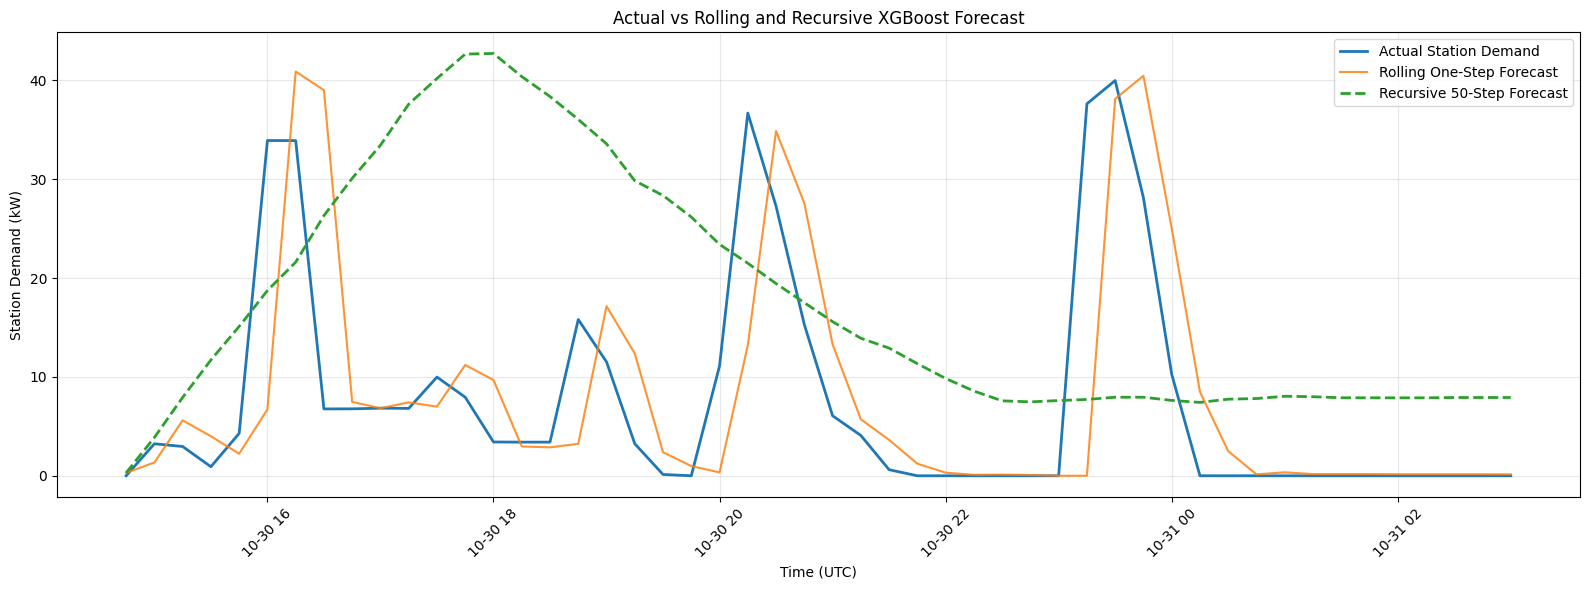

In [113]:

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    recursive_comparison["timestamp"],
    recursive_comparison["actual_power_kw"],
    label="Actual Station Demand",
    linewidth=2
)

plt.plot(
    recursive_comparison["timestamp"],
    recursive_comparison["rolling_predicted_power_kw"],
    label="Rolling One-Step Forecast",
    alpha=0.85
)

plt.plot(
    recursive_comparison["timestamp"],
    recursive_comparison["recursive_predicted_power_kw"],
    label="Recursive 50-Step Forecast",
    linestyle="--",
    linewidth=2
)

plt.title("Actual vs Rolling and Recursive XGBoost Forecast")
plt.xlabel("Time (UTC)")
plt.ylabel("Station Demand (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [114]:

# STAGE 9 — DIRECT MULTI-HORIZON DATASET PREPARATION

import pandas as pd
import numpy as np

# Existing model input features
direct_feature_columns = [
    "hour", "day_of_week", "month", "day_of_year",
    "is_weekend", "hour_sin", "hour_cos",
    "day_sin", "day_cos",
    "lag_1", "lag_4", "lag_96", "lag_672",
    "rolling_mean_4", "rolling_mean_96"
]

# Forecast horizons in 15-minute intervals
forecast_horizons = {
    "15_minutes": 1,
    "1_hour": 4,
    "3_hours": 12,
    "6_hours": 24,
    "12_hours": 48
}

# Use the existing chronological test period as the cutoff
test_start_time = pd.to_datetime(
    model_df.loc[X_test.index[0], "timestamp"],
    utc=True
)

direct_datasets = {}
direct_dataset_summary = []

for horizon_name, steps in forecast_horizons.items():

    temp = model_df[
        ["timestamp", "target_power_kw"] + direct_feature_columns
    ].copy()

    temp["timestamp"] = pd.to_datetime(
        temp["timestamp"], utc=True
    )

    # Future target and its corresponding timestamp
    temp["future_target_kw"] = (
        temp["target_power_kw"].shift(-steps)
    )

    temp["target_timestamp"] = (
        temp["timestamp"] +
        pd.Timedelta(minutes=15 * steps)
    )

    # Remove rows without a future target
    temp = temp.dropna(
        subset=["future_target_kw"]
    ).copy()

    # Chronological split based on the time being predicted
    train_data = temp[
        temp["target_timestamp"] < test_start_time
    ].copy()

    test_data = temp[
        temp["target_timestamp"] >= test_start_time
    ].copy()

    direct_datasets[horizon_name] = {
        "train": train_data,
        "test": test_data,
        "steps": steps
    }

    direct_dataset_summary.append({
        "Horizon": horizon_name,
        "Steps": steps,
        "Training Rows": len(train_data),
        "Testing Rows": len(test_data),
        "Training Start": train_data["timestamp"].min(),
        "Training End Target": train_data["target_timestamp"].max(),
        "Testing Start Target": test_data["target_timestamp"].min(),
        "Testing End Target": test_data["target_timestamp"].max()
    })

direct_summary_df = pd.DataFrame(direct_dataset_summary)

print("DIRECT MULTI-HORIZON DATASET SUMMARY")
display(direct_summary_df)


DIRECT MULTI-HORIZON DATASET SUMMARY


,Horizon,Steps,Training Rows,Testing Rows,Training Start,Training End Target,Testing Start Target,Testing End Target
0,15_minutes,1,72114,18029,2018-05-09 00:00:00+00:00,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-12-02 23:45:00+00:00
1,1_hour,4,72111,18029,2018-05-09 00:00:00+00:00,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-12-02 23:45:00+00:00
2,3_hours,12,72103,18029,2018-05-09 00:00:00+00:00,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-12-02 23:45:00+00:00
3,6_hours,24,72091,18029,2018-05-09 00:00:00+00:00,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-12-02 23:45:00+00:00
4,12_hours,48,72067,18029,2018-05-09 00:00:00+00:00,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-12-02 23:45:00+00:00


In [115]:

# STAGE 9 — TRAIN DIRECT MULTI-HORIZON XGBOOST MODELS

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

direct_models = {}
direct_results = []

for horizon_name, dataset in direct_datasets.items():

    train_data = dataset["train"]
    test_data = dataset["test"]

    X_train_direct = train_data[direct_feature_columns]
    y_train_direct = train_data["future_target_kw"]

    X_test_direct = test_data[direct_feature_columns]
    y_test_direct = test_data["future_target_kw"]

    # Train model using existing XGBoost configuration
    model = XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_direct, y_train_direct)

    # Direct future predictions
    predictions = np.maximum(
        model.predict(X_test_direct), 0
    )

    # Evaluation
    mae = mean_absolute_error(
        y_test_direct, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_test_direct, predictions)
    )

    actual_total = np.sum(np.abs(y_test_direct))

    wape = (
        np.sum(np.abs(y_test_direct - predictions))
        / actual_total
    ) * 100 if actual_total != 0 else np.nan

    # Store trained model and predictions
    direct_models[horizon_name] = {
        "model": model,
        "predictions": predictions,
        "actual": y_test_direct.to_numpy(),
        "timestamps": test_data["target_timestamp"].to_numpy()
    }

    direct_results.append({
        "Forecast Horizon": horizon_name,
        "MAE (kW)": mae,
        "RMSE (kW)": rmse,
        "WAPE (%)": wape
    })

    print(f"Completed: {horizon_name}")

# Final comparison
direct_results_df = pd.DataFrame(direct_results)

print("\nDIRECT MULTI-HORIZON XGBOOST PERFORMANCE")
display(
    direct_results_df.round(4)
)


Completed: 15_minutes
Completed: 1_hour
Completed: 3_hours
Completed: 6_hours
Completed: 12_hours

DIRECT MULTI-HORIZON XGBOOST PERFORMANCE


,Forecast Horizon,MAE (kW),RMSE (kW),WAPE (%)
0,15_minutes,1.0856,4.0750,109.3756
1,1_hour,2.2659,5.1214,228.3062
2,3_hours,3.9853,7.0212,401.5407
3,6_hours,4.9691,8.7324,500.6643
4,12_hours,6.2273,9.7191,627.4310


In [116]:

# STAGE 9 — CORRECTED DIRECT MULTI-HORIZON DATASET

import pandas as pd
import numpy as np

# Sort observations chronologically
source = model_df.copy()

source["timestamp"] = pd.to_datetime(
    source["timestamp"], utc=True
)

source = source.sort_values("timestamp").reset_index(drop=True)

# Check that timestamps are continuous 15-minute intervals
time_difference = source["timestamp"].diff().dropna()

assert (time_difference == pd.Timedelta(minutes=15)).all(), \
    "Timestamp series contains missing or irregular intervals."

demand = source["target_power_kw"].to_numpy()
timestamps = pd.DatetimeIndex(source["timestamp"])

# Forecast horizons
forecast_horizons = {
    "15_minutes": 1,
    "1_hour": 4,
    "3_hours": 12,
    "6_hours": 24,
    "12_hours": 48
}

# Calendar features are taken from the FUTURE target timestamp.
calendar_columns = [
    "hour", "day_of_week", "month", "day_of_year",
    "is_weekend", "hour_sin", "hour_cos",
    "day_sin", "day_cos"
]

direct_feature_columns_corrected = [
    "hour", "day_of_week", "month", "day_of_year",
    "is_weekend", "hour_sin", "hour_cos",
    "day_sin", "day_cos",
    "latest_observed_kw",
    "lag_45min_kw",
    "lag_23h45min_kw",
    "lag_6d23h45min_kw",
    "rolling_mean_1h_kw",
    "rolling_mean_24h_kw"
]

# Use the existing chronological test cutoff
test_start_time = pd.to_datetime(
    model_df.loc[X_test.index[0], "timestamp"],
    utc=True
)

corrected_direct_datasets = {}
corrected_summary = []

for horizon_name, steps in forecast_horizons.items():

    records = []

    # Origin must have enough history and a future target
    for i in range(672, len(source) - steps):

        target_i = i + steps

        # Future calendar information is known in advance
        calendar_values = source.loc[
            target_i, calendar_columns
        ].to_dict()

        record = {
            "forecast_origin": timestamps[i],
            "target_timestamp": timestamps[target_i],
            "future_target_kw": demand[target_i],

            # Latest observed value at forecast origin
            "latest_observed_kw": demand[i],

            # Historical values relative to forecast origin
            "lag_45min_kw": demand[i - 3],
            "lag_23h45min_kw": demand[i - 95],
            "lag_6d23h45min_kw": demand[i - 671],

            # Rolling windows INCLUDE the latest observation
            "rolling_mean_1h_kw": np.mean(demand[i - 3:i + 1]),
            "rolling_mean_24h_kw": np.mean(demand[i - 95:i + 1])
        }

        record.update(calendar_values)
        records.append(record)

    horizon_df = pd.DataFrame(records)

    # Chronological split based on the target timestamp
    train_data = horizon_df[
        horizon_df["target_timestamp"] < test_start_time
    ].copy()

    test_data = horizon_df[
        horizon_df["target_timestamp"] >= test_start_time
    ].copy()

    corrected_direct_datasets[horizon_name] = {
        "train": train_data,
        "test": test_data,
        "steps": steps
    }

    corrected_summary.append({
        "Horizon": horizon_name,
        "Steps": steps,
        "Training Rows": len(train_data),
        "Testing Rows": len(test_data),
        "Training Start": train_data["forecast_origin"].min(),
        "Training End Target": train_data["target_timestamp"].max(),
        "Testing Start Origin": test_data["forecast_origin"].min(),
        "Testing Start Target": test_data["target_timestamp"].min(),
        "Testing End Target": test_data["target_timestamp"].max()
    })

corrected_summary_df = pd.DataFrame(corrected_summary)

print("CORRECTED DIRECT FORECAST DATASET SUMMARY")
display(corrected_summary_df)


CORRECTED DIRECT FORECAST DATASET SUMMARY


,Horizon,Steps,Training Rows,Testing Rows,Training Start,Training End Target,Testing Start Origin,Testing Start Target,Testing End Target
0,15_minutes,1,71442,18029,2018-05-16 00:00:00+00:00,2020-05-29 04:30:00+00:00,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-12-02 23:45:00+00:00
1,1_hour,4,71439,18029,2018-05-16 00:00:00+00:00,2020-05-29 04:30:00+00:00,2020-05-29 03:45:00+00:00,2020-05-29 04:45:00+00:00,2020-12-02 23:45:00+00:00
2,3_hours,12,71431,18029,2018-05-16 00:00:00+00:00,2020-05-29 04:30:00+00:00,2020-05-29 01:45:00+00:00,2020-05-29 04:45:00+00:00,2020-12-02 23:45:00+00:00
3,6_hours,24,71419,18029,2018-05-16 00:00:00+00:00,2020-05-29 04:30:00+00:00,2020-05-28 22:45:00+00:00,2020-05-29 04:45:00+00:00,2020-12-02 23:45:00+00:00
4,12_hours,48,71395,18029,2018-05-16 00:00:00+00:00,2020-05-29 04:30:00+00:00,2020-05-28 16:45:00+00:00,2020-05-29 04:45:00+00:00,2020-12-02 23:45:00+00:00


In [117]:

# STAGE 9 — TRAIN CORRECTED DIRECT MULTI-HORIZON MODELS

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

direct_models_corrected = {}
corrected_results = []

for horizon_name, dataset in corrected_direct_datasets.items():

    train_data = dataset["train"]
    test_data = dataset["test"]

    X_train_direct = train_data[
        direct_feature_columns_corrected
    ]
    y_train_direct = train_data["future_target_kw"]

    X_test_direct = test_data[
        direct_feature_columns_corrected
    ]
    y_test_direct = test_data["future_target_kw"]

    model = XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_direct, y_train_direct)

    predictions = np.maximum(
        model.predict(X_test_direct), 0
    )

    mae = mean_absolute_error(
        y_test_direct, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_test_direct, predictions)
    )

    wape = (
        np.sum(np.abs(y_test_direct.to_numpy() - predictions))
        / np.sum(np.abs(y_test_direct.to_numpy()))
    ) * 100

    direct_models_corrected[horizon_name] = {
        "model": model,
        "predictions": predictions,
        "actual": y_test_direct.to_numpy(),
        "timestamps": test_data["target_timestamp"].to_numpy(),
        "forecast_origins": test_data["forecast_origin"].to_numpy()
    }

    corrected_results.append({
        "Forecast Horizon": horizon_name,
        "MAE (kW)": mae,
        "RMSE (kW)": rmse,
        "WAPE (%)": wape
    })

    print(f"Completed: {horizon_name}")

corrected_results_df = pd.DataFrame(corrected_results)

print("\nCORRECTED DIRECT MULTI-HORIZON PERFORMANCE")
display(corrected_results_df.round(4))


Completed: 15_minutes
Completed: 1_hour
Completed: 3_hours
Completed: 6_hours
Completed: 12_hours

CORRECTED DIRECT MULTI-HORIZON PERFORMANCE


,Forecast Horizon,MAE (kW),RMSE (kW),WAPE (%)
0,15_minutes,0.5970,2.8944,60.1524
1,1_hour,1.9058,4.8945,192.0206
2,3_hours,3.9235,7.4492,395.3126
3,6_hours,5.4148,9.3867,545.5737
4,12_hours,5.9431,9.7373,598.8022


In [118]:

# STAGE 9 — FINAL CHRONOLOGICAL SPLIT CORRECTION

corrected_direct_datasets_final = {}
final_split_summary = []

# Same chronological cutoff as the original forecasting experiment
forecast_cutoff = test_start_time

for horizon_name, dataset in corrected_direct_datasets.items():

    horizon_df = pd.concat(
        [dataset["train"], dataset["test"]],
        ignore_index=True
    )

    # Split strictly by forecast origin
    train_data = horizon_df[
        horizon_df["forecast_origin"] < forecast_cutoff
    ].copy()

    test_data = horizon_df[
        horizon_df["forecast_origin"] >= forecast_cutoff
    ].copy()

    # Verify chronological separation
    assert train_data["forecast_origin"].max() < forecast_cutoff
    assert test_data["forecast_origin"].min() >= forecast_cutoff

    # Save without overwriting earlier datasets
    corrected_direct_datasets_final[horizon_name] = {
        "train": train_data,
        "test": test_data,
        "steps": dataset["steps"]
    }

    final_split_summary.append({
        "Horizon": horizon_name,
        "Training Rows": len(train_data),
        "Testing Rows": len(test_data),
        "Last Training Origin": train_data["forecast_origin"].max(),
        "First Testing Origin": test_data["forecast_origin"].min(),
        "Last Training Target": train_data["target_timestamp"].max(),
        "First Testing Target": test_data["target_timestamp"].min()
    })

final_split_summary_df = pd.DataFrame(final_split_summary)

print("FINAL CHRONOLOGICAL SPLIT SUMMARY")
display(final_split_summary_df)


FINAL CHRONOLOGICAL SPLIT SUMMARY


,Horizon,Training Rows,Testing Rows,Last Training Origin,First Testing Origin,Last Training Target,First Testing Target
0,15_minutes,71443,18028,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-05-29 04:45:00+00:00,2020-05-29 05:00:00+00:00
1,1_hour,71443,18025,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-05-29 05:30:00+00:00,2020-05-29 05:45:00+00:00
2,3_hours,71443,18017,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-05-29 07:30:00+00:00,2020-05-29 07:45:00+00:00
3,6_hours,71443,18005,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-05-29 10:30:00+00:00,2020-05-29 10:45:00+00:00
4,12_hours,71443,17981,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-05-29 16:30:00+00:00,2020-05-29 16:45:00+00:00


In [119]:

# STAGE 9 — PURGED CHRONOLOGICAL TRAIN/TEST SPLIT

purged_direct_datasets = {}
purged_summary = []

for horizon_name, dataset in corrected_direct_datasets_final.items():

    horizon_df = pd.concat(
        [dataset["train"], dataset["test"]],
        ignore_index=True
    )

    # Training labels must occur strictly before test cutoff
    train_data = horizon_df[
        horizon_df["target_timestamp"] < forecast_cutoff
    ].copy()

    # Test forecast origins must be at or after cutoff
    test_data = horizon_df[
        horizon_df["forecast_origin"] >= forecast_cutoff
    ].copy()

    # Validate no target leakage
    assert train_data["target_timestamp"].max() < forecast_cutoff
    assert test_data["forecast_origin"].min() >= forecast_cutoff

    purged_direct_datasets[horizon_name] = {
        "train": train_data,
        "test": test_data,
        "steps": dataset["steps"]
    }

    purged_summary.append({
        "Horizon": horizon_name,
        "Training Rows": len(train_data),
        "Testing Rows": len(test_data),
        "Last Training Target": train_data["target_timestamp"].max(),
        "First Testing Origin": test_data["forecast_origin"].min(),
        "First Testing Target": test_data["target_timestamp"].min()
    })

purged_summary_df = pd.DataFrame(purged_summary)

print("PURGED CHRONOLOGICAL VALIDATION")
display(purged_summary_df)

print("\nAll training targets occur before the test forecast origin.")


PURGED CHRONOLOGICAL VALIDATION


,Horizon,Training Rows,Testing Rows,Last Training Target,First Testing Origin,First Testing Target
0,15_minutes,71442,18028,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-05-29 05:00:00+00:00
1,1_hour,71439,18025,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-05-29 05:45:00+00:00
2,3_hours,71431,18017,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-05-29 07:45:00+00:00
3,6_hours,71419,18005,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-05-29 10:45:00+00:00
4,12_hours,71395,17981,2020-05-29 04:30:00+00:00,2020-05-29 04:45:00+00:00,2020-05-29 16:45:00+00:00



All training targets occur before the test forecast origin.


In [120]:

# STAGE 9 — FINAL PURGED DIRECT XGBOOST MODELS

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

purged_direct_models = {}
purged_results = []

for horizon_name, dataset in purged_direct_datasets.items():

    train_data = dataset["train"]
    test_data = dataset["test"]

    X_train_purged = train_data[direct_feature_columns_corrected]
    y_train_purged = train_data["future_target_kw"]

    X_test_purged = test_data[direct_feature_columns_corrected]
    y_test_purged = test_data["future_target_kw"]

    model = XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_purged, y_train_purged)

    predictions = np.maximum(
        model.predict(X_test_purged), 0
    )

    actual = y_test_purged.to_numpy()

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    wape = (
        np.sum(np.abs(actual - predictions))
        / np.sum(np.abs(actual))
    ) * 100

    purged_direct_models[horizon_name] = {
        "model": model,
        "predictions": predictions,
        "actual": actual,
        "timestamps": test_data["target_timestamp"].to_numpy(),
        "forecast_origins": test_data["forecast_origin"].to_numpy()
    }

    purged_results.append({
        "Forecast Horizon": horizon_name,
        "MAE (kW)": mae,
        "RMSE (kW)": rmse,
        "WAPE (%)": wape
    })

    print(f"Completed: {horizon_name}")

purged_results_df = pd.DataFrame(purged_results)

print("\nFINAL PURGED DIRECT FORECAST PERFORMANCE")
display(purged_results_df.round(4))


Completed: 15_minutes
Completed: 1_hour
Completed: 3_hours
Completed: 6_hours
Completed: 12_hours

FINAL PURGED DIRECT FORECAST PERFORMANCE


,Forecast Horizon,MAE (kW),RMSE (kW),WAPE (%)
0,15_minutes,0.5970,2.8945,60.1522
1,1_hour,1.9062,4.8950,192.0185
2,3_hours,3.9260,7.4517,395.3043
3,6_hours,5.4206,9.3928,545.4295
4,12_hours,5.9575,9.7501,598.6575


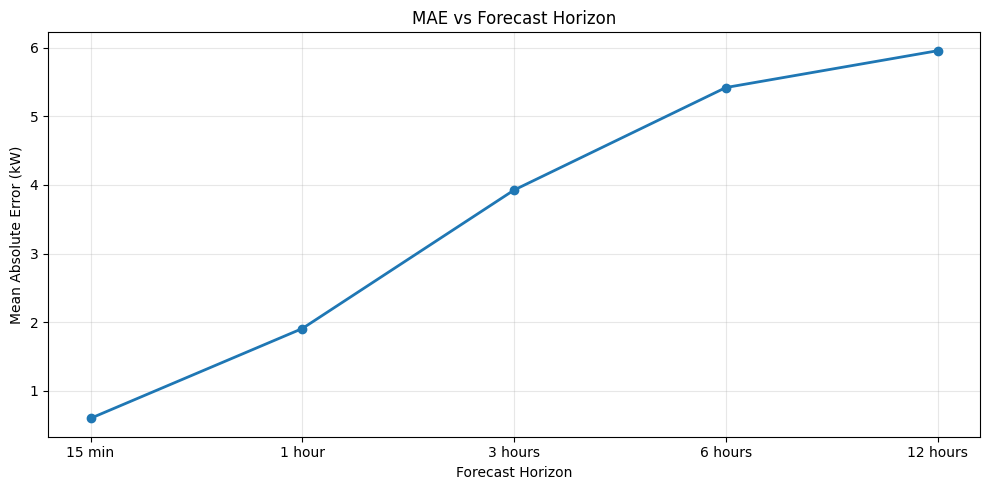

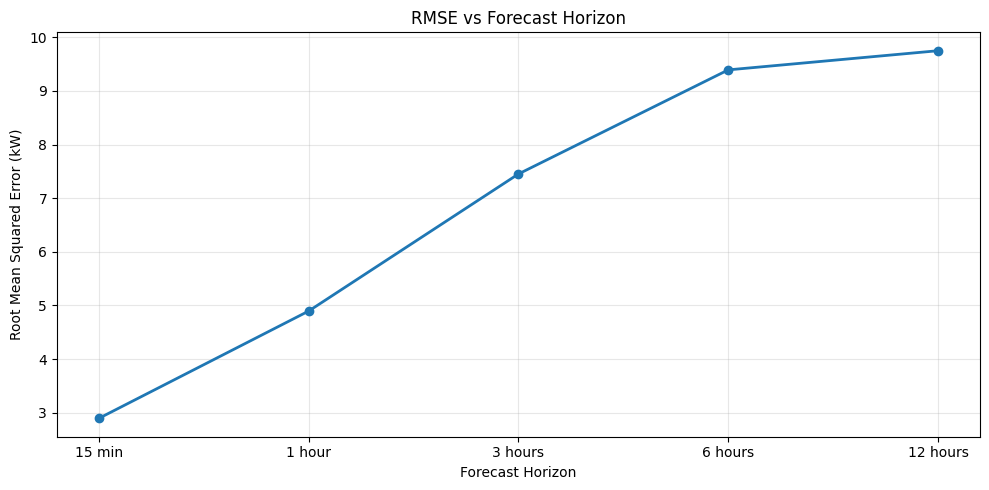

In [121]:

# STAGE 9 — FORECAST PERFORMANCE VISUALIZATION

import matplotlib.pyplot as plt

horizon_labels = ["15 min", "1 hour", "3 hours", "6 hours", "12 hours"]

# MAE comparison
plt.figure(figsize=(10, 5))

plt.plot(
    horizon_labels,
    purged_results_df["MAE (kW)"],
    marker="o",
    linewidth=2
)

plt.title("MAE vs Forecast Horizon")
plt.xlabel("Forecast Horizon")
plt.ylabel("Mean Absolute Error (kW)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# RMSE comparison
plt.figure(figsize=(10, 5))

plt.plot(
    horizon_labels,
    purged_results_df["RMSE (kW)"],
    marker="o",
    linewidth=2
)

plt.title("RMSE vs Forecast Horizon")
plt.xlabel("Forecast Horizon")
plt.ylabel("Root Mean Squared Error (kW)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [122]:

# STAGE 10 — CONFORMAL PREDICTION INTERVALS

from xgboost import XGBRegressor
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Select the 15-minute forecasting dataset
train_data = purged_direct_datasets["15_minutes"]["train"].copy()
test_data = purged_direct_datasets["15_minutes"]["test"].copy()

# Sort chronologically
train_data = train_data.sort_values("forecast_origin")

# Chronological 80/20 training-calibration split
split_point = int(len(train_data) * 0.80)

model_train = train_data.iloc[:split_point].copy()
calibration_data = train_data.iloc[split_point:].copy()

features = direct_feature_columns_corrected

X_train_cal = model_train[features]
y_train_cal = model_train["future_target_kw"]

X_cal = calibration_data[features]
y_cal = calibration_data["future_target_kw"].to_numpy()

X_test_cal = test_data[features]
y_test_cal = test_data["future_target_kw"].to_numpy()

# Train model
calibration_model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

calibration_model.fit(X_train_cal, y_train_cal)

# Calibration predictions
cal_predictions = np.maximum(
    calibration_model.predict(X_cal), 0
)

# Absolute calibration residuals
calibration_errors = np.abs(
    y_cal - cal_predictions
)

# 90% split-conformal correction
alpha = 0.10
n_cal = len(calibration_errors)

quantile_level = np.ceil(
    (n_cal + 1) * (1 - alpha)
) / n_cal

quantile_level = min(quantile_level, 1.0)

conformal_q = np.quantile(
    calibration_errors,
    quantile_level,
    method="higher"
)

# Test predictions
test_predictions = np.maximum(
    calibration_model.predict(X_test_cal), 0
)

# Prediction interval
lower_bound = np.maximum(
    test_predictions - conformal_q, 0
)

upper_bound = test_predictions + conformal_q

# Evaluate coverage
covered = (
    (y_test_cal >= lower_bound) &
    (y_test_cal <= upper_bound)
)

coverage = np.mean(covered) * 100
average_width = np.mean(upper_bound - lower_bound)

conformal_results = pd.DataFrame({
    "timestamp": test_data["target_timestamp"].to_numpy(),
    "actual_kw": y_test_cal,
    "predicted_kw": test_predictions,
    "lower_90_kw": lower_bound,
    "upper_90_kw": upper_bound,
    "covered": covered
})

print("========== CONFORMAL CALIBRATION ==========")
print("Training observations:", len(model_train))
print("Calibration observations:", len(calibration_data))
print("Test observations:", len(test_data))
print("Calibration error quantile:", round(conformal_q, 4), "kW")

print("\n========== TEST INTERVAL PERFORMANCE ==========")
print("Empirical coverage:", round(coverage, 2), "%")
print("Target coverage: 90%")
print("Average interval width:", round(average_width, 4), "kW")

print("\nFIRST 15 PREDICTION INTERVALS")
display(conformal_results.head(15).round(3))


========== CONFORMAL CALIBRATION ==========
Training observations: 57153
Calibration observations: 14289
Test observations: 18028
Calibration error quantile: 2.0756 kW

========== TEST INTERVAL PERFORMANCE ==========
Empirical coverage: 94.66 %
Target coverage: 90%
Average interval width: 2.528 kW

FIRST 15 PREDICTION INTERVALS


,timestamp,actual_kw,predicted_kw,lower_90_kw,upper_90_kw,covered
0,2020-05-29 05:00:00+00:00,0.0,0.0,0.0,2.076,True
1,2020-05-29 05:15:00+00:00,0.0,0.0,0.0,2.076,True
2,2020-05-29 05:30:00+00:00,0.0,0.0,0.0,2.076,True
3,2020-05-29 05:45:00+00:00,0.0,0.0,0.0,2.076,True
4,2020-05-29 06:00:00+00:00,0.0,0.0,0.0,2.076,True
5,2020-05-29 06:15:00+00:00,0.0,0.0,0.0,2.076,True
6,2020-05-29 06:30:00+00:00,0.0,0.0,0.0,2.076,True
7,2020-05-29 06:45:00+00:00,0.0,0.0,0.0,2.076,True
8,2020-05-29 07:00:00+00:00,0.0,0.0,0.0,2.076,True
9,2020-05-29 07:15:00+00:00,0.0,0.0,0.0,2.076,True


In [123]:

# STAGE 10 — DETAILED CONFORMAL INTERVAL EVALUATION

import numpy as np
import pandas as pd

results = conformal_results.copy()

# Classify actual demand
results["demand_condition"] = np.where(
    results["actual_kw"] > 0,
    "Active demand",
    "Zero demand"
)

# Interval width
results["interval_width_kw"] = (
    results["upper_90_kw"] - results["lower_90_kw"]
)

# Error
results["error_kw"] = (
    results["predicted_kw"] - results["actual_kw"]
)

# Coverage by demand condition
condition_summary = results.groupby(
    "demand_condition"
).agg(
    observations=("actual_kw", "count"),
    coverage_pct=("covered", lambda x: x.mean() * 100),
    mean_actual_kw=("actual_kw", "mean"),
    mean_predicted_kw=("predicted_kw", "mean"),
    mean_interval_width_kw=("interval_width_kw", "mean")
).reset_index()

print("COVERAGE BY DEMAND CONDITION")
display(condition_summary.round(3))

# Monthly coverage
results["month"] = results["timestamp"].dt.to_period("M")

monthly_summary = results.groupby("month").agg(
    observations=("actual_kw", "count"),
    coverage_pct=("covered", lambda x: x.mean() * 100),
    mean_interval_width_kw=("interval_width_kw", "mean")
).reset_index()

print("\nMONTHLY INTERVAL COVERAGE")
display(monthly_summary.round(3))

# Missed observations
missed = results[~results["covered"]].copy()

print("\nINTERVAL MISS ANALYSIS")
print("Total missed observations:", len(missed))

print(
    "Actual demand above upper bound:",
    (missed["actual_kw"] > missed["upper_90_kw"]).sum()
)

print(
    "Actual demand below lower bound:",
    (missed["actual_kw"] < missed["lower_90_kw"]).sum()
)


COVERAGE BY DEMAND CONDITION


,demand_condition,observations,coverage_pct,mean_actual_kw,mean_predicted_kw,mean_interval_width_kw
0,Active demand,2679,70.922,6.679,6.750,3.893
1,Zero demand,15349,98.808,0.000,0.265,2.290



MONTHLY INTERVAL COVERAGE


C:\Users\suhey\AppData\Local\Temp\ipykernel_24160\2973075083.py:40: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  results["month"] = results["timestamp"].dt.to_period("M")


,month,observations,coverage_pct,mean_interval_width_kw
0,2020-05,268,100.000,2.199
1,2020-06,2880,97.917,2.436
2,2020-07,2976,98.185,2.400
3,2020-08,2976,95.699,2.584
4,2020-09,2880,96.215,2.558
5,2020-10,2976,89.718,2.530
6,2020-11,2880,90.799,2.666
7,2020-12,192,79.167,2.931



INTERVAL MISS ANALYSIS
Total missed observations: 962
Actual demand above upper bound: 304
Actual demand below lower bound: 658


In [124]:

# STAGE 10 — CALIBRATION VS TEST RESIDUAL DIAGNOSTICS

# Calibration predictions and actual values already exist
calibration_diagnostic = pd.DataFrame({
    "actual_kw": y_cal,
    "predicted_kw": cal_predictions,
    "absolute_error_kw": calibration_errors
})

test_diagnostic = pd.DataFrame({
    "actual_kw": y_test_cal,
    "predicted_kw": test_predictions,
    "absolute_error_kw": np.abs(
        y_test_cal - test_predictions
    )
})

# Classify demand conditions
for df in [calibration_diagnostic, test_diagnostic]:

    df["demand_condition"] = np.where(
        df["actual_kw"] > 0,
        "Active demand",
        "Zero demand"
    )

    df["demand_band"] = pd.cut(
        df["actual_kw"],
        bins=[-0.001, 0, 5, 15, 30, np.inf],
        labels=[
            "Zero",
            "0-5 kW",
            "5-15 kW",
            "15-30 kW",
            "Above 30 kW"
        ]
    )

# Calibration summary
calibration_summary = calibration_diagnostic.groupby(
    "demand_condition", observed=True
).agg(
    observations=("actual_kw", "count"),
    mean_actual_kw=("actual_kw", "mean"),
    mean_absolute_error_kw=("absolute_error_kw", "mean"),
    error_90th_percentile_kw=(
        "absolute_error_kw",
        lambda x: x.quantile(0.90)
    )
).reset_index()

# Test summary
test_summary = test_diagnostic.groupby(
    "demand_condition", observed=True
).agg(
    observations=("actual_kw", "count"),
    mean_actual_kw=("actual_kw", "mean"),
    mean_absolute_error_kw=("absolute_error_kw", "mean"),
    error_90th_percentile_kw=(
        "absolute_error_kw",
        lambda x: x.quantile(0.90)
    )
).reset_index()

print("CALIBRATION ERROR BY DEMAND CONDITION")
display(calibration_summary.round(3))

print("\nTEST ERROR BY DEMAND CONDITION")
display(test_summary.round(3))

print("\nTEST ERROR BY DEMAND LEVEL")
display(
    test_diagnostic.groupby(
        "demand_band", observed=True
    ).agg(
        observations=("actual_kw", "count"),
        mean_absolute_error_kw=("absolute_error_kw", "mean"),
        error_90th_percentile_kw=(
            "absolute_error_kw",
            lambda x: x.quantile(0.90)
        )
    ).reset_index().round(3)
)


CALIBRATION ERROR BY DEMAND CONDITION


,demand_condition,observations,mean_actual_kw,mean_absolute_error_kw,error_90th_percentile_kw
0,Active demand,3896,13.448,2.096,5.140
1,Zero demand,10393,0.000,0.240,0.713



TEST ERROR BY DEMAND CONDITION


,demand_condition,observations,mean_actual_kw,mean_absolute_error_kw,error_90th_percentile_kw
0,Active demand,2679,6.679,3.116,7.214
1,Zero demand,15349,0.000,0.265,0.660



TEST ERROR BY DEMAND LEVEL


,demand_band,observations,mean_absolute_error_kw,error_90th_percentile_kw
0,Zero,15349,0.265,0.660
1,0-5 kW,1335,2.013,3.618
2,5-15 kW,1132,2.020,5.056
3,15-30 kW,118,12.872,25.429
4,Above 30 kW,94,19.735,39.182


In [125]:

# STAGE 10 — DEMAND-DEPENDENT CONFORMAL CALIBRATION

import numpy as np
import pandas as pd

# Use predicted demand to define calibration groups.
# These boundaries are known when a forecast is issued.
demand_bins = [-0.001, 5, 15, 30, np.inf]

demand_labels = [
    "0-5 kW",
    "5-15 kW",
    "15-30 kW",
    "Above 30 kW"
]

# Calibration dataset
calibration_conditional = pd.DataFrame({
    "predicted_kw": cal_predictions,
    "actual_kw": y_cal,
    "absolute_error_kw": calibration_errors
})

# Test dataset
test_conditional = pd.DataFrame({
    "predicted_kw": test_predictions,
    "actual_kw": y_test_cal
})

# Assign groups using predicted demand
for df in [calibration_conditional, test_conditional]:

    df["demand_group"] = pd.cut(
        df["predicted_kw"],
        bins=demand_bins,
        labels=demand_labels,
        include_lowest=True
    )

# Calculate a separate conformal correction per group.
# Use global correction as fallback for small calibration groups.
minimum_group_size = 100
conditional_quantiles = {}

global_q = conformal_q

for group in demand_labels:

    group_errors = calibration_conditional.loc[
        calibration_conditional["demand_group"] == group,
        "absolute_error_kw"
    ].to_numpy()

    if len(group_errors) >= minimum_group_size:

        n = len(group_errors)

        q_level = min(
            np.ceil((n + 1) * 0.90) / n,
            1.0
        )

        q_group = np.quantile(
            group_errors,
            q_level,
            method="higher"
        )

        source = "Group calibration"

    else:
        q_group = global_q
        source = "Global fallback"

    conditional_quantiles[group] = q_group

    print(
        f"{group}: n={len(group_errors)}, "
        f"correction={q_group:.3f} kW, "
        f"source={source}"
    )

# Apply group-specific intervals
test_conditional["correction_kw"] = (
    test_conditional["demand_group"]
    .map(conditional_quantiles)
    .astype(float)
)

test_conditional["lower_kw"] = np.maximum(
    test_conditional["predicted_kw"] -
    test_conditional["correction_kw"],
    0
)

test_conditional["upper_kw"] = (
    test_conditional["predicted_kw"] +
    test_conditional["correction_kw"]
)

# Coverage
test_conditional["covered"] = (
    (test_conditional["actual_kw"] >= test_conditional["lower_kw"]) &
    (test_conditional["actual_kw"] <= test_conditional["upper_kw"])
)

test_conditional["interval_width_kw"] = (
    test_conditional["upper_kw"] -
    test_conditional["lower_kw"]
)

# Evaluate by predicted demand group
conditional_summary = test_conditional.groupby(
    "demand_group", observed=False
).agg(
    observations=("actual_kw", "count"),
    coverage_pct=("covered", lambda x: x.mean() * 100),
    mean_interval_width_kw=("interval_width_kw", "mean"),
    mean_predicted_kw=("predicted_kw", "mean"),
    mean_actual_kw=("actual_kw", "mean")
).reset_index()

print("\nDEMAND-DEPENDENT INTERVAL PERFORMANCE")
display(conditional_summary.round(3))

print(
    "\nOverall coverage:",
    round(test_conditional["covered"].mean() * 100, 2),
    "%"
)

print(
    "Average interval width:",
    round(test_conditional["interval_width_kw"].mean(), 3),
    "kW"
)


0-5 kW: n=11476, correction=0.992 kW, source=Group calibration
5-15 kW: n=1783, correction=3.826 kW, source=Group calibration
15-30 kW: n=511, correction=7.220 kW, source=Group calibration
Above 30 kW: n=519, correction=9.465 kW, source=Group calibration

DEMAND-DEPENDENT INTERVAL PERFORMANCE


,demand_group,observations,coverage_pct,mean_interval_width_kw,mean_predicted_kw,mean_actual_kw
0,0-5 kW,16567,93.221,1.232,0.396000,0.306
1,5-15 kW,1249,86.549,7.652,7.379000,6.895
2,15-30 kW,111,36.937,14.441,22.209000,15.120
3,Above 30 kW,101,36.634,18.930,38.702999,25.112



Overall coverage: 92.1 %
Average interval width: 1.857 kW


In [126]:

# STAGE 10 — ZERO VS ACTIVE DEMAND CLASSIFICATION DIAGNOSTIC

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
import numpy as np
import pandas as pd

# Actual demand classes
actual_active = (y_test_cal > 0).astype(int)

# Predicted demand classes
# Start with zero threshold
predicted_active = (test_predictions > 0).astype(int)

cm = confusion_matrix(
    actual_active,
    predicted_active,
    labels=[0, 1]
)

print("CONFUSION MATRIX")
print(pd.DataFrame(
    cm,
    index=["Actual Zero", "Actual Active"],
    columns=["Predicted Zero", "Predicted Active"]
))

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        actual_active,
        predicted_active,
        target_names=["Zero Demand", "Active Demand"],
        zero_division=0
    )
)

print(
    "Overall accuracy:",
    round(accuracy_score(actual_active, predicted_active) * 100, 2),
    "%"
)


CONFUSION MATRIX
               Predicted Zero  Predicted Active
Actual Zero              5360              9989
Actual Active              19              2660

CLASSIFICATION REPORT
               precision    recall  f1-score   support

  Zero Demand       1.00      0.35      0.52     15349
Active Demand       0.21      0.99      0.35      2679

     accuracy                           0.44     18028
    macro avg       0.60      0.67      0.43     18028
 weighted avg       0.88      0.44      0.49     18028

Overall accuracy: 44.49 %


In [127]:

# STAGE 10 — CALIBRATION-BASED ACTIVITY THRESHOLD

from sklearn.metrics import (
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    f1_score
)
import numpy as np
import pandas as pd

# Define active demand as strictly positive actual demand
cal_actual_class = (y_cal > 0).astype(int)
test_actual_class = (y_test_cal > 0).astype(int)

# Find the best threshold using calibration data only
precision, recall, thresholds = precision_recall_curve(
    cal_actual_class,
    cal_predictions
)

# Calculate F1 for every available threshold
f1_values = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print("SELECTED ACTIVITY THRESHOLD")
print("Threshold:", round(best_threshold, 4), "kW")
print("Calibration F1:", round(f1_values[best_index], 4))

# Apply selected threshold to untouched test data
test_predicted_class = (
    test_predictions >= best_threshold
).astype(int)

cm_threshold = confusion_matrix(
    test_actual_class,
    test_predicted_class,
    labels=[0, 1]
)

print("\nTEST CONFUSION MATRIX")

display(pd.DataFrame(
    cm_threshold,
    index=["Actual Zero", "Actual Active"],
    columns=["Predicted Zero", "Predicted Active"]
))

print("\nTEST CLASSIFICATION REPORT")

print(classification_report(
    test_actual_class,
    test_predicted_class,
    target_names=["Zero Demand", "Active Demand"],
    zero_division=0
))

print(
    "Test F1 score:",
    round(f1_score(test_actual_class, test_predicted_class), 4)
)


SELECTED ACTIVITY THRESHOLD
Threshold: 1.9388 kW
Calibration F1: 0.9377

TEST CONFUSION MATRIX


,Predicted Zero,Predicted Active
Actual Zero,15157,192
Actual Active,465,2214



TEST CLASSIFICATION REPORT
               precision    recall  f1-score   support

  Zero Demand       0.97      0.99      0.98     15349
Active Demand       0.92      0.83      0.87      2679

     accuracy                           0.96     18028
    macro avg       0.95      0.91      0.92     18028
 weighted avg       0.96      0.96      0.96     18028

Test F1 score: 0.8708


In [128]:

# STAGE 11 — TWO-STAGE MODEL DATA PREPARATION

import numpy as np
import pandas as pd

# Reuse the final purged 15-minute dataset
two_stage_train = purged_direct_datasets["15_minutes"]["train"].copy()
two_stage_test = purged_direct_datasets["15_minutes"]["test"].copy()

# Create binary charging activity target
two_stage_train["active_target"] = (
    two_stage_train["future_target_kw"] > 0
).astype(int)

two_stage_test["active_target"] = (
    two_stage_test["future_target_kw"] > 0
).astype(int)

# Stage 1: classifier features
two_stage_features = direct_feature_columns_corrected

X_train_stage1 = two_stage_train[two_stage_features]
y_train_stage1 = two_stage_train["active_target"]

X_test_stage1 = two_stage_test[two_stage_features]
y_test_stage1 = two_stage_test["active_target"]

print("TWO-STAGE DATASET SUMMARY")

print("\nTraining observations:", len(two_stage_train))
print("Testing observations:", len(two_stage_test))

print("\nTraining demand distribution:")
display(
    y_train_stage1.value_counts()
    .rename(index={0: "Zero demand", 1: "Active demand"})
    .to_frame("Observations")
)

print("\nTesting demand distribution:")
display(
    y_test_stage1.value_counts()
    .rename(index={0: "Zero demand", 1: "Active demand"})
    .to_frame("Observations")
)

print("\nFeature count:", len(two_stage_features))
print("Forecast horizon: 15 minutes")


TWO-STAGE DATASET SUMMARY

Training observations: 71442
Testing observations: 18028

Training demand distribution:


,Observations
active_target,
Active demand,46454
Zero demand,24988



Testing demand distribution:


,Observations
active_target,
Zero demand,15349
Active demand,2679



Feature count: 15
Forecast horizon: 15 minutes


In [129]:

# STAGE 11 — XGBOOST CHARGING ACTIVITY CLASSIFIER

from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_recall_curve
)
import numpy as np
import pandas as pd

# Chronological 80/20 split within training data
split_point = int(len(two_stage_train) * 0.80)

classifier_train = two_stage_train.iloc[:split_point].copy()
classifier_calibration = two_stage_train.iloc[split_point:].copy()

X_classifier_train = classifier_train[two_stage_features]
y_classifier_train = classifier_train["active_target"]

X_classifier_cal = classifier_calibration[two_stage_features]
y_classifier_cal = classifier_calibration["active_target"]

# Train classifier
activity_classifier = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

activity_classifier.fit(
    X_classifier_train,
    y_classifier_train
)

# Calibrate classification threshold
calibration_probabilities = activity_classifier.predict_proba(
    X_classifier_cal
)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_classifier_cal,
    calibration_probabilities
)

f1_values = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_values)
classifier_threshold = thresholds[best_index]

# Evaluate on untouched test data
test_probabilities = activity_classifier.predict_proba(
    X_test_stage1
)[:, 1]

test_class_predictions = (
    test_probabilities >= classifier_threshold
).astype(int)

print("CLASSIFIER TRAINING OBSERVATIONS:", len(classifier_train))
print("CALIBRATION OBSERVATIONS:", len(classifier_calibration))
print("TEST OBSERVATIONS:", len(two_stage_test))

print("\nSELECTED CLASSIFICATION THRESHOLD:")
print(round(classifier_threshold, 4))

print("\nCALIBRATION F1:")
print(round(f1_values[best_index], 4))

print("\nTEST CONFUSION MATRIX:")
display(pd.DataFrame(
    confusion_matrix(
        y_test_stage1,
        test_class_predictions,
        labels=[0, 1]
    ),
    index=["Actual Zero", "Actual Active"],
    columns=["Predicted Zero", "Predicted Active"]
))

print("\nTEST CLASSIFICATION REPORT:")
print(classification_report(
    y_test_stage1,
    test_class_predictions,
    target_names=["Zero Demand", "Active Demand"],
    zero_division=0
))

print(
    "TEST ACCURACY:",
    round(accuracy_score(
        y_test_stage1,
        test_class_predictions
    ) * 100, 2),
    "%"
)

print(
    "TEST ACTIVE-DEMAND F1:",
    round(f1_score(
        y_test_stage1,
        test_class_predictions
    ), 4)
)


CLASSIFIER TRAINING OBSERVATIONS: 57153
CALIBRATION OBSERVATIONS: 14289
TEST OBSERVATIONS: 18028

SELECTED CLASSIFICATION THRESHOLD:
0.6095

CALIBRATION F1:
0.9474

TEST CONFUSION MATRIX:


,Predicted Zero,Predicted Active
Actual Zero,15224,125
Actual Active,445,2234



TEST CLASSIFICATION REPORT:
               precision    recall  f1-score   support

  Zero Demand       0.97      0.99      0.98     15349
Active Demand       0.95      0.83      0.89      2679

     accuracy                           0.97     18028
    macro avg       0.96      0.91      0.93     18028
 weighted avg       0.97      0.97      0.97     18028

TEST ACCURACY: 96.84 %
TEST ACTIVE-DEMAND F1: 0.8869


In [130]:

# STAGE 11 — ACTIVE DEMAND XGBOOST REGRESSOR

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Use only active-demand training observations
active_train = classifier_train[
    classifier_train["future_target_kw"] > 0
].copy()

# Features and continuous target
X_active_train = active_train[two_stage_features]
y_active_train = active_train["future_target_kw"]

# Train active-demand regressor
active_regressor = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

active_regressor.fit(
    X_active_train,
    y_active_train
)

print("ACTIVE-DEMAND REGRESSOR TRAINING")
print("Training observations:", len(active_train))
print("Features:", len(two_stage_features))
print("Minimum training demand:", round(y_active_train.min(), 4), "kW")
print("Maximum training demand:", round(y_active_train.max(), 4), "kW")

print("\nModel training completed.")


ACTIVE-DEMAND REGRESSOR TRAINING
Training observations: 42558
Features: 15
Minimum training demand: 0.0 kW
Maximum training demand: 111.4541 kW

Model training completed.


In [131]:

# STAGE 11 — COMBINED TWO-STAGE FORECASTING MODEL

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Stage 1: predict charging activity
active_probabilities = activity_classifier.predict_proba(
    X_test_stage1
)[:, 1]

predicted_activity = (
    active_probabilities >= classifier_threshold
)

# Stage 2: predict demand magnitude
predicted_magnitude = np.maximum(
    active_regressor.predict(X_test_stage1),
    0
)

# Combine both stages
two_stage_predictions = np.where(
    predicted_activity,
    predicted_magnitude,
    0
)

# Actual demand
actual_demand = y_test_stage1.index

# Use continuous target from the test dataset
actual_power = two_stage_test[
    "future_target_kw"
].to_numpy()

# Evaluation
two_stage_mae = mean_absolute_error(
    actual_power,
    two_stage_predictions
)

two_stage_rmse = np.sqrt(
    mean_squared_error(
        actual_power,
        two_stage_predictions
    )
)

two_stage_wape = (
    np.sum(np.abs(actual_power - two_stage_predictions))
    / np.sum(np.abs(actual_power))
) * 100

print("========== TWO-STAGE FORECAST PERFORMANCE ==========")
print("MAE:", round(two_stage_mae, 4), "kW")
print("RMSE:", round(two_stage_rmse, 4), "kW")
print("WAPE:", round(two_stage_wape, 2), "%")

# Compare against the existing direct 15-minute model
print("\n========== MODEL COMPARISON ==========")

comparison_df = pd.DataFrame({
    "Model": [
        "Single-stage XGBoost",
        "Two-stage XGBoost"
    ],
    "MAE (kW)": [
        0.5970,
        two_stage_mae
    ],
    "RMSE (kW)": [
        2.8945,
        two_stage_rmse
    ],
    "WAPE (%)": [
        60.1522,
        two_stage_wape
    ]
})

display(comparison_df.round(4))


========== TWO-STAGE FORECAST PERFORMANCE ==========
MAE: 0.5427 kW
RMSE: 2.9885 kW
WAPE: 54.68 %

========== MODEL COMPARISON ==========


,Model,MAE (kW),RMSE (kW),WAPE (%)
0,Single-stage XGBoost,0.5970,2.8945,60.1522
1,Two-stage XGBoost,0.5427,2.9885,54.6757


In [132]:

# STAGE 11 — TWO-STAGE MODEL ERROR ANALYSIS

import numpy as np
import pandas as pd

two_stage_error_df = pd.DataFrame({
    "actual_kw": actual_power,
    "predicted_kw": two_stage_predictions
})

two_stage_error_df["absolute_error_kw"] = np.abs(
    two_stage_error_df["actual_kw"] -
    two_stage_error_df["predicted_kw"]
)

two_stage_error_df["demand_condition"] = np.where(
    two_stage_error_df["actual_kw"] > 0,
    "Active demand",
    "Zero demand"
)

# Performance by demand condition
condition_results = two_stage_error_df.groupby(
    "demand_condition"
).agg(
    observations=("actual_kw", "count"),
    actual_mean_kw=("actual_kw", "mean"),
    predicted_mean_kw=("predicted_kw", "mean"),
    MAE_kw=("absolute_error_kw", "mean"),
    RMSE_kw=(
        "absolute_error_kw",
        lambda x: np.sqrt(np.mean(x**2))
    )
).reset_index()

print("TWO-STAGE MODEL PERFORMANCE BY DEMAND CONDITION")
display(condition_results.round(4))

# Demand-level performance
two_stage_error_df["demand_band"] = pd.cut(
    two_stage_error_df["actual_kw"],
    bins=[-0.001, 0, 5, 15, 30, np.inf],
    labels=[
        "Zero",
        "0-5 kW",
        "5-15 kW",
        "15-30 kW",
        "Above 30 kW"
    ]
)

print("\nPERFORMANCE BY ACTUAL DEMAND LEVEL")

display(
    two_stage_error_df.groupby(
        "demand_band", observed=True
    ).agg(
        observations=("actual_kw", "count"),
        MAE_kw=("absolute_error_kw", "mean"),
        maximum_error_kw=("absolute_error_kw", "max")
    ).reset_index().round(4)
)


TWO-STAGE MODEL PERFORMANCE BY DEMAND CONDITION


,demand_condition,observations,actual_mean_kw,predicted_mean_kw,MAE_kw,RMSE_kw
0,Active demand,2679,6.6793,6.8684,3.2805,7.3426
1,Zero demand,15349,0.0000,0.0648,0.0648,1.0393



PERFORMANCE BY ACTUAL DEMAND LEVEL


,demand_band,observations,MAE_kw,maximum_error_kw
0,Zero,15349,0.0648,45.0336
1,0-5 kW,1335,2.2333,47.8601
2,5-15 kW,1132,2.0372,44.5983
3,15-30 kW,118,13.8220,32.6560
4,Above 30 kW,94,19.8911,49.5238


In [133]:

# STAGE 11 — IDENTIFY THE LARGEST FORECASTING ERRORS

# Attach timestamps to predictions
two_stage_error_df["timestamp"] = (
    two_stage_test["target_timestamp"].to_numpy()
)

# Calculate signed prediction error
two_stage_error_df["error_kw"] = (
    two_stage_error_df["predicted_kw"] -
    two_stage_error_df["actual_kw"]
)

# Sort by absolute error
top_10_errors = (
    two_stage_error_df
    .sort_values(
        by="absolute_error_kw",
        ascending=False
    )
    .head(10)
)

print("TOP 10 LARGEST FORECASTING ERRORS")

display(
    top_10_errors[
        [
            "timestamp",
            "actual_kw",
            "predicted_kw",
            "error_kw",
            "absolute_error_kw",
            "demand_condition"
        ]
    ].round(4)
)


TOP 10 LARGEST FORECASTING ERRORS


,timestamp,actual_kw,predicted_kw,error_kw,absolute_error_kw,demand_condition
13668,2020-10-18 14:00:00+00:00,53.6411,4.117300,-49.5238,49.5238,Active demand
14099,2020-10-23 01:45:00+00:00,0.9458,48.805901,47.8601,47.8601,Active demand
14165,2020-10-23 18:15:00+00:00,3.3843,49.109600,45.7253,45.7253,Active demand
17563,2020-11-28 03:45:00+00:00,0.0000,45.033600,45.0336,45.0336,Zero demand
13722,2020-10-19 03:30:00+00:00,7.2470,51.845200,44.5983,44.5983,Active demand
17069,2020-11-23 00:15:00+00:00,47.1095,3.089300,-44.0203,44.0203,Active demand
13593,2020-10-17 19:15:00+00:00,43.3076,0.000000,-43.3076,43.3076,Active demand
14587,2020-10-28 03:45:00+00:00,4.2874,46.880901,42.5935,42.5935,Active demand
14683,2020-10-29 03:45:00+00:00,41.9560,0.000000,-41.9560,41.9560,Active demand
14553,2020-10-27 19:15:00+00:00,41.4749,0.000000,-41.4749,41.4749,Active demand


In [134]:

# STAGE 11 — DIAGNOSE THE TWO-STAGE MODEL'S LARGEST ERRORS

# Add classifier and regressor outputs
two_stage_error_df["active_probability"] = active_probabilities
two_stage_error_df["classifier_prediction"] = predicted_activity.astype(int)
two_stage_error_df["regressor_magnitude_kw"] = predicted_magnitude

# Identify the error type
two_stage_error_df["error_type"] = np.select(
    [
        (two_stage_error_df["actual_kw"] > 0) &
        (two_stage_error_df["classifier_prediction"] == 0),

        (two_stage_error_df["actual_kw"] == 0) &
        (two_stage_error_df["classifier_prediction"] == 1),

        (two_stage_error_df["actual_kw"] > 0) &
        (two_stage_error_df["classifier_prediction"] == 1)
    ],
    [
        "Missed demand",
        "False demand",
        "Active demand detected"
    ],
    default="Correct zero-demand prediction"
)

# Display the 10 worst observations
diagnostic_top10 = (
    two_stage_error_df
    .loc[top_10_errors.index]
    [[
        "timestamp",
        "actual_kw",
        "predicted_kw",
        "active_probability",
        "classifier_prediction",
        "regressor_magnitude_kw",
        "error_type"
    ]]
    .sort_values(
        by="actual_kw",
        ascending=False
    )
)

display(diagnostic_top10.round(4))

print("\nERROR TYPE DISTRIBUTION — TOP 10")
display(
    diagnostic_top10["error_type"].value_counts()
)


,timestamp,actual_kw,predicted_kw,active_probability,classifier_prediction,regressor_magnitude_kw,error_type
13668,2020-10-18 14:00:00+00:00,53.6411,4.117300,0.9688,1,4.117300,Active demand detected
17069,2020-11-23 00:15:00+00:00,47.1095,3.089300,0.9954,1,3.089300,Active demand detected
13593,2020-10-17 19:15:00+00:00,43.3076,0.000000,0.1517,0,1.654900,Missed demand
14683,2020-10-29 03:45:00+00:00,41.9560,0.000000,0.0331,0,1.694200,Missed demand
14553,2020-10-27 19:15:00+00:00,41.4749,0.000000,0.1935,0,2.658000,Missed demand
13722,2020-10-19 03:30:00+00:00,7.2470,51.845200,1.0000,1,51.845200,Active demand detected
14587,2020-10-28 03:45:00+00:00,4.2874,46.880901,0.9992,1,46.880901,Active demand detected
14165,2020-10-23 18:15:00+00:00,3.3843,49.109600,0.9971,1,49.109600,Active demand detected
14099,2020-10-23 01:45:00+00:00,0.9458,48.805901,0.9998,1,48.805901,Active demand detected
17563,2020-11-28 03:45:00+00:00,0.0000,45.033600,0.9999,1,45.033600,False demand



ERROR TYPE DISTRIBUTION — TOP 10


error_type
Active demand detected    6
Missed demand             3
False demand              1
Name: count, dtype: int64

In [135]:

# STAGE 11 — ACTIVE-DEMAND TRAINING DATA DISTRIBUTION

# Training target distribution
active_target = active_train["future_target_kw"]

print("ACTIVE TRAINING DATA STATISTICS")
display(active_target.describe().to_frame("Power_kW"))

# Demand-level distribution
demand_bins = [-0.001, 5, 15, 30, 50, np.inf]

demand_labels = [
    "0–5 kW",
    "5–15 kW",
    "15–30 kW",
    "30–50 kW",
    "Above 50 kW"
]

active_demand_distribution = pd.cut(
    active_target,
    bins=demand_bins,
    labels=demand_labels
).value_counts().sort_index()

active_demand_percentage = (
    active_demand_distribution /
    active_demand_distribution.sum() * 100
)

training_distribution_df = pd.DataFrame({
    "observations": active_demand_distribution,
    "percentage": active_demand_percentage
})

display(training_distribution_df.round(2))

# Compare with test demand distribution
test_demand_distribution = pd.cut(
    actual_power,
    bins=demand_bins,
    labels=demand_labels
).value_counts().sort_index()

print("TEST DATA DISTRIBUTION")
display(
    test_demand_distribution.to_frame("observations")
)


ACTIVE TRAINING DATA STATISTICS


,Power_kW
count,42558.000000
mean,20.547814
std,19.196969
min,0.000001
25%,6.588689
50%,13.407228
75%,30.916156
max,111.454108


,observations,percentage
future_target_kw,,
0–5 kW,7969,18.73
5–15 kW,15034,35.33
15–30 kW,8543,20.07
30–50 kW,6944,16.32
Above 50 kW,4068,9.56


TEST DATA DISTRIBUTION


,observations
0–5 kW,16684
5–15 kW,1132
15–30 kW,118
30–50 kW,93
Above 50 kW,1


In [136]:

# STAGE 11 — REGRESSOR-ONLY PERFORMANCE BY DEMAND BAND

# Predict magnitude for every test observation
regressor_only_predictions = np.maximum(
    active_regressor.predict(X_test_stage1),
    0
)

regression_diagnostic_df = pd.DataFrame({
    "actual_kw": actual_power,
    "predicted_magnitude_kw": regressor_only_predictions
})

# Evaluate only actual active-demand observations
active_test_diagnostic = regression_diagnostic_df[
    regression_diagnostic_df["actual_kw"] > 0
].copy()

# Demand bands
active_test_diagnostic["demand_band"] = pd.cut(
    active_test_diagnostic["actual_kw"],
    bins=[0, 5, 15, 30, 50, np.inf],
    labels=[
        "0–5 kW",
        "5–15 kW",
        "15–30 kW",
        "30–50 kW",
        "Above 50 kW"
    ],
    include_lowest=True
)

# Calculate errors
active_test_diagnostic["absolute_error_kw"] = (
    active_test_diagnostic["actual_kw"] -
    active_test_diagnostic["predicted_magnitude_kw"]
).abs()

# Group-wise metrics
regressor_band_results = (
    active_test_diagnostic
    .groupby("demand_band", observed=False)
    .agg(
        observations=("actual_kw", "count"),
        actual_mean_kw=("actual_kw", "mean"),
        predicted_mean_kw=("predicted_magnitude_kw", "mean"),
        MAE_kw=("absolute_error_kw", "mean"),
        maximum_error_kw=("absolute_error_kw", "max")
    )
)

display(regressor_band_results.round(4))


,observations,actual_mean_kw,predicted_mean_kw,MAE_kw,maximum_error_kw
demand_band,,,,,
0–5 kW,1335,2.3467,4.2859,2.1467,47.8601
5–15 kW,1132,7.3596,7.9622,1.9573,44.5983
15–30 kW,118,22.1030,17.8381,13.3024,32.6560
30–50 kW,93,40.5176,26.5261,19.2224,44.0203
Above 50 kW,1,53.6411,4.1173,49.5238,49.5238


In [137]:

# STAGE 11 — REGRESSOR VALIDATION VS TEST PERFORMANCE

# Use the previously unused calibration dataset
validation_active = classifier_calibration[
    classifier_calibration["future_target_kw"] > 0
].copy()

# Test observations with actual active demand
test_active = two_stage_test[
    two_stage_test["future_target_kw"] > 0
].copy()

# Generate magnitude predictions
validation_predictions = np.maximum(
    active_regressor.predict(
        validation_active[two_stage_features]
    ),
    0
)

test_active_predictions = np.maximum(
    active_regressor.predict(
        test_active[two_stage_features]
    ),
    0
)

# Prepare comparison data
validation_results = pd.DataFrame({
    "actual_kw": validation_active["future_target_kw"].to_numpy(),
    "predicted_kw": validation_predictions
})

test_results = pd.DataFrame({
    "actual_kw": test_active["future_target_kw"].to_numpy(),
    "predicted_kw": test_active_predictions
})

# Calculate absolute errors
validation_results["absolute_error_kw"] = (
    validation_results["actual_kw"] -
    validation_results["predicted_kw"]
).abs()

test_results["absolute_error_kw"] = (
    test_results["actual_kw"] -
    test_results["predicted_kw"]
).abs()

# Overall comparison
comparison = pd.DataFrame({
    "Validation": {
        "Observations": len(validation_results),
        "Actual_mean_kw": validation_results["actual_kw"].mean(),
        "Predicted_mean_kw": validation_results["predicted_kw"].mean(),
        "MAE_kw": validation_results["absolute_error_kw"].mean(),
        "RMSE_kw": np.sqrt(
            np.mean(
                (validation_results["actual_kw"] -
                 validation_results["predicted_kw"]) ** 2
            )
        )
    },
    "Test": {
        "Observations": len(test_results),
        "Actual_mean_kw": test_results["actual_kw"].mean(),
        "Predicted_mean_kw": test_results["predicted_kw"].mean(),
        "MAE_kw": test_results["absolute_error_kw"].mean(),
        "RMSE_kw": np.sqrt(
            np.mean(
                (test_results["actual_kw"] -
                 test_results["predicted_kw"]) ** 2
            )
        )
    }
}).T

display(comparison.round(4))


,Observations,Actual_mean_kw,Predicted_mean_kw,MAE_kw,RMSE_kw
Validation,3896.0,13.4481,13.8215,2.1210,3.3426
Test,2679.0,6.6793,7.2082,3.1685,7.1665


In [138]:

# STAGE 11 — VALIDATION VS TEST PERFORMANCE BY DEMAND BAND

demand_bins = [0, 5, 15, 30, 50, np.inf]

demand_labels = [
    "0–5 kW",
    "5–15 kW",
    "15–30 kW",
    "30–50 kW",
    "Above 50 kW"
]

def evaluate_demand_bands(data, dataset_name):

    result = data.copy()

    result["demand_band"] = pd.cut(
        result["actual_kw"],
        bins=demand_bins,
        labels=demand_labels,
        include_lowest=True
    )

    result["error"] = (
        result["predicted_kw"] - result["actual_kw"]
    )

    result["absolute_error"] = result["error"].abs()

    summary = (
        result.groupby("demand_band", observed=False)
        .agg(
            observations=("actual_kw", "count"),
            actual_mean_kw=("actual_kw", "mean"),
            predicted_mean_kw=("predicted_kw", "mean"),
            MAE_kw=("absolute_error", "mean"),
            RMSE_kw=("error", lambda x: np.sqrt(np.mean(x**2)))
        )
    )

    summary.insert(0, "dataset", dataset_name)

    return summary.reset_index()


validation_band_results = evaluate_demand_bands(
    validation_results, "Validation"
)

test_band_results = evaluate_demand_bands(
    test_results, "Test"
)

validation_test_band_comparison = pd.concat(
    [validation_band_results, test_band_results],
    ignore_index=True
)

display(
    validation_test_band_comparison.round(4)
)


,demand_band,dataset,observations,actual_mean_kw,predicted_mean_kw,MAE_kw,RMSE_kw
0,0–5 kW,Validation,1144,2.3690,3.773700,1.6455,2.1809
1,5–15 kW,Validation,1725,8.2650,8.382600,1.3597,2.1813
2,15–30 kW,Validation,506,21.3062,21.525600,3.5733,4.7968
3,30–50 kW,Validation,319,38.7625,38.715599,4.2426,5.6974
4,Above 50 kW,Validation,202,60.7928,58.560902,4.3264,6.2478
5,0–5 kW,Test,1335,2.3467,4.285900,2.1467,4.3956
6,5–15 kW,Test,1132,7.3596,7.962200,1.9573,4.9887
7,15–30 kW,Test,118,22.1030,17.838100,13.3024,15.7611
8,30–50 kW,Test,93,40.5176,26.526100,19.2224,23.6142
9,Above 50 kW,Test,1,53.6411,4.117300,49.5238,49.5238


In [139]:

# STAGE 11 — MONTHLY DEMAND DISTRIBUTION

monthly_demand = model_df.copy()

monthly_demand["timestamp"] = pd.to_datetime(
    monthly_demand["timestamp"],
    utc=True
)

monthly_demand["month"] = (
    monthly_demand["timestamp"].dt.to_period("M").astype(str)
)

monthly_summary = (
    monthly_demand
    .groupby("month")
    .agg(
        observations=("target_power_kw", "count"),
        average_demand_kw=("target_power_kw", "mean"),
        peak_demand_kw=("target_power_kw", "max"),
        active_intervals=(
            "target_power_kw",
            lambda x: (x > 0).sum()
        )
    )
)

monthly_summary["active_percentage"] = (
    monthly_summary["active_intervals"] /
    monthly_summary["observations"] * 100
)

display(monthly_summary.round(3))


C:\Users\suhey\AppData\Local\Temp\ipykernel_24160\1674622953.py:11: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly_demand["timestamp"].dt.to_period("M").astype(str)


,observations,average_demand_kw,peak_demand_kw,active_intervals,active_percentage
month,,,,,
2018-05,2208,21.355,65.354,2034,92.120
2018-06,2880,23.644,78.674,2759,95.799
2018-07,2976,24.803,86.435,2731,91.767
2018-08,2976,27.155,104.933,2750,92.406
2018-09,2880,27.915,110.136,2669,92.674
2018-10,2976,29.180,111.454,2602,87.433
2018-11,2880,15.653,101.246,2289,79.479
2018-12,2976,11.092,85.805,2229,74.899
2019-01,2976,13.666,93.511,2192,73.656


In [140]:

# STAGE 11 — PREPARE RECENT-HISTORY TRAINING WINDOWS

# Use the existing purged direct dataset
direct_train = purged_direct_datasets["15_minutes"]["train"].copy()
direct_test = purged_direct_datasets["15_minutes"]["test"].copy()

# Ensure timestamps are UTC
direct_train["forecast_origin"] = pd.to_datetime(
    direct_train["forecast_origin"], utc=True
)

direct_test["forecast_origin"] = pd.to_datetime(
    direct_test["forecast_origin"], utc=True
)

# Determine the beginning of the test period
test_start = direct_test["forecast_origin"].min()

# Define recent training windows
cutoff_12_months = test_start - pd.DateOffset(months=12)
cutoff_6_months = test_start - pd.DateOffset(months=6)

# Prepare datasets
training_windows = {
    "Full historical": direct_train,

    "Recent 12 months": direct_train[
        direct_train["forecast_origin"] >= cutoff_12_months
    ].copy(),

    "Recent 6 months": direct_train[
        direct_train["forecast_origin"] >= cutoff_6_months
    ].copy()
}

# Display dataset sizes and date ranges
window_summary = []

for name, data in training_windows.items():

    window_summary.append({
        "training_window": name,
        "observations": len(data),
        "start_date": data["forecast_origin"].min(),
        "end_date": data["forecast_origin"].max()
    })

window_summary_df = pd.DataFrame(window_summary)

display(window_summary_df)


,training_window,observations,start_date,end_date
0,Full historical,71442,2018-05-16 00:00:00+00:00,2020-05-29 04:15:00+00:00
1,Recent 12 months,35135,2019-05-29 04:45:00+00:00,2020-05-29 04:15:00+00:00
2,Recent 6 months,17471,2019-11-29 04:45:00+00:00,2020-05-29 04:15:00+00:00


In [141]:

# STAGE 11 — COMPARE FULL, 12-MONTH AND 6-MONTH TRAINING

recent_regressor_models = {}
recent_regressor_results = []

for window_name, window_data in training_windows.items():

    # Retain active-demand observations only
    active_window = window_data[
        window_data["future_target_kw"] > 0
    ].copy()

    X_window = active_window[two_stage_features]
    y_window = active_window["future_target_kw"]

    # Train using identical XGBoost parameters
    model = XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_window, y_window)

    recent_regressor_models[window_name] = model

    # Predict active-demand magnitude for the same test set
    magnitude_predictions = np.maximum(
        model.predict(X_test_stage1),
        0
    )

    # Keep the existing classifier decisions fixed
    combined_predictions = np.where(
        predicted_activity,
        magnitude_predictions,
        0
    )

    # Evaluate the combined two-stage model
    errors = actual_power - combined_predictions

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    wape = (
        np.sum(np.abs(errors)) /
        np.sum(np.abs(actual_power))
    ) * 100

    # Evaluate magnitude regression on actual active-demand rows
    active_mask = actual_power > 0

    active_errors = (
        actual_power[active_mask] -
        magnitude_predictions[active_mask]
    )

    active_mae = np.mean(np.abs(active_errors))
    active_rmse = np.sqrt(np.mean(active_errors ** 2))

    recent_regressor_results.append({
        "training_window": window_name,
        "training_observations": len(active_window),
        "active_regressor_MAE_kw": active_mae,
        "active_regressor_RMSE_kw": active_rmse,
        "two_stage_MAE_kw": mae,
        "two_stage_RMSE_kw": rmse,
        "two_stage_WAPE_pct": wape
    })

recent_regressor_comparison = pd.DataFrame(
    recent_regressor_results
)

display(recent_regressor_comparison.round(4))


,training_window,training_observations,active_regressor_MAE_kw,active_regressor_RMSE_kw,two_stage_MAE_kw,two_stage_RMSE_kw,two_stage_WAPE_pct
0,Full historical,46454,3.0539,7.0754,0.5244,2.9523,52.8338
1,Recent 12 months,16659,3.0864,7.0554,0.5289,2.9592,53.2886
2,Recent 6 months,5500,2.9786,7.0191,0.5149,2.9481,51.8735


In [142]:

# STAGE 11 — DEMAND-BAND COMPARISON: FULL VS RECENT 6 MONTHS

models_to_compare = {
    "Full historical": recent_regressor_models["Full historical"],
    "Recent 6 months": recent_regressor_models["Recent 6 months"]
}

demand_bins = [0, 5, 15, 30, 50, np.inf]

demand_labels = [
    "0–5 kW",
    "5–15 kW",
    "15–30 kW",
    "30–50 kW",
    "Above 50 kW"
]

band_comparison = []

for model_name, model in models_to_compare.items():

    magnitude = np.maximum(
        model.predict(X_test_stage1),
        0
    )

    combined = np.where(
        predicted_activity,
        magnitude,
        0
    )

    result = pd.DataFrame({
        "actual_kw": actual_power,
        "predicted_kw": combined
    })

    result["demand_band"] = pd.cut(
        result["actual_kw"],
        bins=demand_bins,
        labels=demand_labels,
        include_lowest=True
    )

    result["error"] = (
        result["predicted_kw"] - result["actual_kw"]
    )

    result["absolute_error"] = result["error"].abs()

    grouped = result.groupby(
        "demand_band",
        observed=False
    ).agg(
        observations=("actual_kw", "count"),
        MAE_kw=("absolute_error", "mean"),
        RMSE_kw=("error", lambda x: np.sqrt(np.mean(x**2)))
    ).reset_index()

    grouped["model"] = model_name

    band_comparison.append(grouped)

demand_band_comparison = pd.concat(
    band_comparison,
    ignore_index=True
)

display(
    demand_band_comparison.round(4)
)


,demand_band,observations,MAE_kw,RMSE_kw,model
0,0–5 kW,16684,0.2234,1.5706,Full historical
1,5–15 kW,1132,2.0353,5.1444,Full historical
2,15–30 kW,118,13.8540,16.3525,Full historical
3,30–50 kW,93,18.6936,23.6502,Full historical
4,Above 50 kW,1,49.5060,49.5060,Full historical
5,0–5 kW,16684,0.2181,1.5868,Recent 6 months
6,5–15 kW,1132,2.0318,5.2011,Recent 6 months
7,15–30 kW,118,13.9406,16.4646,Recent 6 months
8,30–50 kW,93,17.7485,23.1196,Recent 6 months
9,Above 50 kW,1,48.5405,48.5405,Recent 6 months


In [143]:

# STAGE 11 — MONTHLY PERFORMANCE COMPARISON

monthly_model_results = []

for model_name, model in models_to_compare.items():

    magnitude = np.maximum(
        model.predict(X_test_stage1),
        0
    )

    combined = np.where(
        predicted_activity,
        magnitude,
        0
    )

    monthly_df = pd.DataFrame({
        "timestamp": two_stage_test["target_timestamp"].to_numpy(),
        "actual_kw": actual_power,
        "predicted_kw": combined
    })

    monthly_df["timestamp"] = pd.to_datetime(
        monthly_df["timestamp"], utc=True
    )

    monthly_df["month"] = (
        monthly_df["timestamp"].dt.strftime("%Y-%m")
    )

    monthly_df["absolute_error"] = (
        monthly_df["actual_kw"] -
        monthly_df["predicted_kw"]
    ).abs()

    monthly_df["squared_error"] = (
        monthly_df["actual_kw"] -
        monthly_df["predicted_kw"]
    ) ** 2

    monthly_summary = (
        monthly_df.groupby("month")
        .agg(
            observations=("actual_kw", "count"),
            actual_mean_kw=("actual_kw", "mean"),
            predicted_mean_kw=("predicted_kw", "mean"),
            MAE_kw=("absolute_error", "mean"),
            RMSE_kw=(
                "squared_error",
                lambda x: np.sqrt(x.mean())
            )
        )
        .reset_index()
    )

    monthly_summary["model"] = model_name

    monthly_model_results.append(monthly_summary)

monthly_comparison = pd.concat(
    monthly_model_results,
    ignore_index=True
)

display(monthly_comparison.round(4))


,month,observations,actual_mean_kw,predicted_mean_kw,MAE_kw,RMSE_kw,model
0,2020-05,268,0.0000,0.0000,0.0000,0.0000,Full historical
1,2020-06,2880,0.5227,0.5411,0.1112,0.5245,Full historical
2,2020-07,2976,0.4149,0.4342,0.1052,0.5410,Full historical
3,2020-08,2976,0.9416,0.9894,0.2428,0.8273,Full historical
4,2020-09,2880,0.7925,0.8344,0.2347,0.8256,Full historical
5,2020-10,2976,1.6825,1.7884,1.3592,5.5052,Full historical
6,2020-11,2880,1.5243,1.6405,0.9988,4.2327,Full historical
7,2020-12,192,3.4998,3.7622,2.6084,7.1017,Full historical
8,2020-05,268,0.0000,0.0000,0.0000,0.0000,Recent 6 months
9,2020-06,2880,0.5227,0.5415,0.1105,0.5265,Recent 6 months


In [144]:

# STAGE 12 — TASK 1: PREPARE CALIBRATION DATA

# Use the existing calibration dataset
uncertainty_calibration = classifier_calibration.copy()

# Generate predictions using the recent six-month regressor
calibration_magnitude = np.maximum(
    recent_regressor_models["Recent 6 months"].predict(
        uncertainty_calibration[two_stage_features]
    ),
    0
)

# Apply the existing activity classifier
calibration_probabilities = activity_classifier.predict_proba(
    uncertainty_calibration[two_stage_features]
)[:, 1]

calibration_activity = (
    calibration_probabilities >= classifier_threshold
)

# Combine classifier and regressor
calibration_predictions = np.where(
    calibration_activity,
    calibration_magnitude,
    0
)

# Actual demand
calibration_actual = (
    uncertainty_calibration["future_target_kw"].to_numpy()
)

# Construct calibration results
uncertainty_calibration_results = pd.DataFrame({
    "actual_kw": calibration_actual,
    "predicted_kw": calibration_predictions
})

# Calculate residuals
uncertainty_calibration_results["absolute_error_kw"] = (
    uncertainty_calibration_results["actual_kw"] -
    uncertainty_calibration_results["predicted_kw"]
).abs()

print("CALIBRATION DATASET SUMMARY")

display(
    uncertainty_calibration_results[
        ["actual_kw", "predicted_kw", "absolute_error_kw"]
    ].describe().round(4)
)

print("\nCalibration observations:",
      len(uncertainty_calibration_results))


CALIBRATION DATASET SUMMARY


,actual_kw,predicted_kw,absolute_error_kw
count,14289.0000,14289.0000,14289.0000
mean,3.6667,3.6441,0.3560
std,10.0053,9.9239,0.9832
min,0.0000,0.0000,0.0000
25%,0.0000,0.0000,0.0000
50%,0.0000,0.0000,0.0000
75%,1.3511,1.9901,0.1204
max,83.4682,80.7524,37.9614



Calibration observations: 14289


In [145]:

# STAGE 12 — TASK 2: CREATE INDEPENDENT CHRONOLOGICAL SPLITS

recent_data = (
    training_windows["Recent 6 months"]
    .sort_values("forecast_origin")
    .reset_index(drop=True)
    .copy()
)

n = len(recent_data)

train_end = int(n * 0.70)
threshold_end = int(n * 0.80)

uncertainty_train = recent_data.iloc[:train_end].copy()

threshold_calibration = recent_data.iloc[
    train_end:threshold_end
].copy()

conformal_calibration = recent_data.iloc[
    threshold_end:
].copy()

# Display split information
split_summary = pd.DataFrame({
    "dataset": [
        "Model training",
        "Threshold calibration",
        "Conformal calibration"
    ],
    "observations": [
        len(uncertainty_train),
        len(threshold_calibration),
        len(conformal_calibration)
    ],
    "start_date": [
        uncertainty_train["forecast_origin"].min(),
        threshold_calibration["forecast_origin"].min(),
        conformal_calibration["forecast_origin"].min()
    ],
    "end_date": [
        uncertainty_train["forecast_origin"].max(),
        threshold_calibration["forecast_origin"].max(),
        conformal_calibration["forecast_origin"].max()
    ]
})

display(split_summary)


,dataset,observations,start_date,end_date
0,Model training,12229,2019-11-29 04:45:00+00:00,2020-04-04 13:45:00+00:00
1,Threshold calibration,1747,2020-04-04 14:00:00+00:00,2020-04-22 18:30:00+00:00
2,Conformal calibration,3495,2020-04-22 18:45:00+00:00,2020-05-29 04:15:00+00:00


In [146]:

# STAGE 12 — TASK 3: TRAIN CLASSIFIER AND REGRESSOR

# Features and targets
X_uncertainty_train = uncertainty_train[two_stage_features]

y_activity_train = (
    uncertainty_train["future_target_kw"] > 0
).astype(int)

# 1. Train activity classifier
uncertainty_classifier = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

uncertainty_classifier.fit(
    X_uncertainty_train,
    y_activity_train
)

# 2. Train active-demand regressor
active_uncertainty_train = uncertainty_train[
    uncertainty_train["future_target_kw"] > 0
].copy()

uncertainty_regressor = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

uncertainty_regressor.fit(
    active_uncertainty_train[two_stage_features],
    active_uncertainty_train["future_target_kw"]
)

print("MODEL TRAINING COMPLETED")
print("Total training observations:", len(uncertainty_train))
print("Active-demand training observations:",
      len(active_uncertainty_train))
print("Zero-demand training observations:",
      (y_activity_train == 0).sum())


MODEL TRAINING COMPLETED
Total training observations: 12229
Active-demand training observations: 5182
Zero-demand training observations: 7047


In [147]:

# STAGE 12 — TASK 4: SELECT CLASSIFIER THRESHOLD

from sklearn.metrics import precision_recall_curve, classification_report

X_threshold = threshold_calibration[two_stage_features]

y_threshold = (
    threshold_calibration["future_target_kw"] > 0
).astype(int)

# Predict activity probabilities
threshold_probabilities = (
    uncertainty_classifier.predict_proba(X_threshold)[:, 1]
)

# Find threshold maximizing F1 score
precision, recall, thresholds = precision_recall_curve(
    y_threshold,
    threshold_probabilities
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_threshold_index = np.argmax(f1_scores)

uncertainty_threshold = thresholds[best_threshold_index]

threshold_predictions = (
    threshold_probabilities >= uncertainty_threshold
).astype(int)

print("OPTIMAL ACTIVITY THRESHOLD:",
      round(uncertainty_threshold, 4))

print("CALIBRATION F1 SCORE:",
      round(f1_scores[best_threshold_index], 4))

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_threshold,
        threshold_predictions,
        target_names=["Zero demand", "Active demand"]
    )
)


OPTIMAL ACTIVITY THRESHOLD: 0.2832
CALIBRATION F1 SCORE: 0.9313

CLASSIFICATION REPORT
               precision    recall  f1-score   support

  Zero demand       0.99      1.00      0.99      1611
Active demand       0.97      0.90      0.93       136

     accuracy                           0.99      1747
    macro avg       0.98      0.95      0.96      1747
 weighted avg       0.99      0.99      0.99      1747



In [148]:

# STAGE 12 — TASK 5: GENERATE CONFORMAL CALIBRATION PREDICTIONS

X_conformal = conformal_calibration[two_stage_features]

# Activity probabilities
conformal_probabilities = (
    uncertainty_classifier.predict_proba(X_conformal)[:, 1]
)

# Classify active and zero-demand intervals
conformal_activity = (
    conformal_probabilities >= uncertainty_threshold
)

# Predict demand magnitude
conformal_magnitude = np.maximum(
    uncertainty_regressor.predict(X_conformal),
    0
)

# Combine both stages
conformal_predictions = np.where(
    conformal_activity,
    conformal_magnitude,
    0
)

# Actual demand
conformal_actual = (
    conformal_calibration["future_target_kw"].to_numpy()
)

# Calculate absolute residuals
conformal_residuals = np.abs(
    conformal_actual - conformal_predictions
)

# Create calibration results
conformal_calibration_results = pd.DataFrame({
    "actual_kw": conformal_actual,
    "predicted_kw": conformal_predictions,
    "active_probability": conformal_probabilities,
    "absolute_error_kw": conformal_residuals
})

print("CONFORMAL CALIBRATION SUMMARY")

display(
    conformal_calibration_results.describe().round(4)
)

print("\nConformal calibration observations:",
      len(conformal_calibration_results))


CONFORMAL CALIBRATION SUMMARY


,actual_kw,predicted_kw,active_probability,absolute_error_kw
count,3495.0000,3495.0000,3495.0000,3495.0000
mean,0.2625,0.2704,0.0581,0.0611
std,1.2564,1.2431,0.2040,0.3881
min,0.0000,0.0000,0.0008,0.0000
25%,0.0000,0.0000,0.0024,0.0000
50%,0.0000,0.0000,0.0044,0.0000
75%,0.0000,0.0000,0.0102,0.0000
max,9.9051,9.4816,0.9991,7.3121



Conformal calibration observations: 3495


In [149]:

# STAGE 12 — TASK 6: CALCULATE 90% CONFORMAL QUANTILE

# Desired prediction interval coverage
confidence_level = 0.90

# Number of calibration observations
n_calibration = len(conformal_residuals)

# Finite-sample conformal quantile rank
quantile_rank = int(
    np.ceil((n_calibration + 1) * confidence_level)
)

# Sort absolute residuals
sorted_residuals = np.sort(conformal_residuals)

# Calculate conformal uncertainty margin
conformal_q90 = sorted_residuals[quantile_rank - 1]

print("CONFORMAL UNCERTAINTY RESULTS")
print("--------------------------------")
print("Calibration observations:", n_calibration)
print("Target coverage:", confidence_level * 100, "%")
print("Quantile rank:", quantile_rank)
print("90% uncertainty margin:", round(conformal_q90, 4), "kW")

# Calibration interval coverage diagnostic
calibration_lower = np.maximum(
    conformal_predictions - conformal_q90,
    0
)

calibration_upper = (
    conformal_predictions + conformal_q90
)

calibration_coverage = np.mean(
    (conformal_actual >= calibration_lower) &
    (conformal_actual <= calibration_upper)
) * 100

print("Calibration empirical coverage:",
      round(calibration_coverage, 2), "%")


CONFORMAL UNCERTAINTY RESULTS
--------------------------------
Calibration observations: 3495
Target coverage: 90.0 %
Quantile rank: 3147
90% uncertainty margin: 0.0 kW
Calibration empirical coverage: 94.33 %


In [150]:

# STAGE 12 — TASK 7: INVESTIGATE DEGENERATE CONFORMAL RESIDUALS

# Count exact-zero and nonzero residuals
zero_error_count = np.sum(conformal_residuals == 0)
nonzero_error_count = np.sum(conformal_residuals > 0)

print("RESIDUAL DISTRIBUTION")
print("----------------------")
print("Total observations:", len(conformal_residuals))
print("Zero-error observations:", zero_error_count)
print("Nonzero-error observations:", nonzero_error_count)

print(
    "Zero-error percentage:",
    round(zero_error_count / len(conformal_residuals) * 100, 2),
    "%"
)

# Separate actual zero and active demand
active_mask_cal = conformal_actual > 0
zero_mask_cal = conformal_actual == 0

active_residuals = conformal_residuals[active_mask_cal]
zero_residuals = conformal_residuals[zero_mask_cal]

print("\nACTUAL ACTIVE-DEMAND OBSERVATIONS")
print("Count:", len(active_residuals))
print("Mean error:", round(active_residuals.mean(), 4), "kW")
print("Median error:", round(np.median(active_residuals), 4), "kW")
print("90th percentile:", round(np.quantile(active_residuals, 0.90), 4), "kW")
print("Maximum error:", round(active_residuals.max(), 4), "kW")

print("\nACTUAL ZERO-DEMAND OBSERVATIONS")
print("Count:", len(zero_residuals))
print("Mean error:", round(zero_residuals.mean(), 4), "kW")
print("Nonzero errors:", np.sum(zero_residuals > 0))


RESIDUAL DISTRIBUTION
----------------------
Total observations: 3495
Zero-error observations: 3297
Nonzero-error observations: 198
Zero-error percentage: 94.33 %

ACTUAL ACTIVE-DEMAND OBSERVATIONS
Count: 182
Mean error: 0.8998 kW
Median error: 0.4999 kW
90th percentile: 2.4114 kW
Maximum error: 6.4826 kW

ACTUAL ZERO-DEMAND OBSERVATIONS
Count: 3313
Mean error: 0.015 kW
Nonzero errors: 16


In [151]:

# STAGE 12 — TASK 8: CONDITIONAL CONFORMAL CALIBRATION

# Group calibration observations by predicted activity
conformal_calibration_results["predicted_state"] = np.where(
    conformal_activity,
    "Predicted active",
    "Predicted zero"
)

def calculate_conformal_quantile(errors, coverage=0.90):

    errors = np.sort(np.asarray(errors))
    n = len(errors)

    rank = int(np.ceil((n + 1) * coverage))

    if rank > n:
        return np.inf

    return errors[rank - 1]


conditional_quantiles = {}

conditional_summary = []

for state in ["Predicted zero", "Predicted active"]:

    group = conformal_calibration_results[
        conformal_calibration_results["predicted_state"] == state
    ]

    errors = group["absolute_error_kw"].to_numpy()

    q90 = calculate_conformal_quantile(
        errors,
        coverage=0.90
    )

    conditional_quantiles[state] = q90

    conditional_summary.append({
        "predicted_state": state,
        "observations": len(group),
        "actual_active_observations": (
            group["actual_kw"] > 0
        ).sum(),
        "mean_absolute_error_kw": errors.mean(),
        "90_percent_margin_kw": q90
    })

conditional_conformal_summary = pd.DataFrame(
    conditional_summary
)

display(conditional_conformal_summary.round(4))


,predicted_state,observations,actual_active_observations,mean_absolute_error_kw,90_percent_margin_kw
0,Predicted zero,3321,24,0.0102,0.0000
1,Predicted active,174,158,1.0322,2.8162


In [152]:

# STAGE 12 — TASK 9: EVALUATE CONDITIONAL CONFORMAL INTERVALS

# Generate test activity probabilities
test_uncertainty_probabilities = (
    uncertainty_classifier.predict_proba(X_test_stage1)[:, 1]
)

# Classify test observations
test_uncertainty_activity = (
    test_uncertainty_probabilities >= uncertainty_threshold
)

# Generate test magnitude predictions
test_uncertainty_magnitude = np.maximum(
    uncertainty_regressor.predict(X_test_stage1),
    0
)

# Combine classifier and regressor
test_uncertainty_predictions = np.where(
    test_uncertainty_activity,
    test_uncertainty_magnitude,
    0
)

# Assign conditional uncertainty margins
test_uncertainty_margins = np.where(
    test_uncertainty_activity,
    conditional_quantiles["Predicted active"],
    conditional_quantiles["Predicted zero"]
)

# Construct prediction intervals
test_lower = np.maximum(
    test_uncertainty_predictions - test_uncertainty_margins,
    0
)

test_upper = (
    test_uncertainty_predictions + test_uncertainty_margins
)

# Actual test demand
test_actual = actual_power

# Calculate interval coverage
test_covered = (
    (test_actual >= test_lower) &
    (test_actual <= test_upper)
)

# Store results
conditional_test_results = pd.DataFrame({
    "actual_kw": test_actual,
    "predicted_kw": test_uncertainty_predictions,
    "lower_90_kw": test_lower,
    "upper_90_kw": test_upper,
    "interval_width_kw": test_upper - test_lower,
    "covered": test_covered,
    "predicted_state": np.where(
        test_uncertainty_activity,
        "Predicted active",
        "Predicted zero"
    ),
    "actual_state": np.where(
        test_actual > 0,
        "Actual active",
        "Actual zero"
    )
})

# Overall metrics
overall_coverage = test_covered.mean() * 100
average_width = conditional_test_results[
    "interval_width_kw"
].mean()

print("OVERALL TEST INTERVAL PERFORMANCE")
print("----------------------------------")
print("Observations:", len(conditional_test_results))
print("Coverage:", round(overall_coverage, 2), "%")
print("Average interval width:", round(average_width, 4), "kW")

# Coverage by actual demand condition
coverage_by_actual_state = (
    conditional_test_results
    .groupby("actual_state")
    .agg(
        observations=("covered", "size"),
        coverage_pct=("covered", lambda x: x.mean() * 100),
        average_width_kw=("interval_width_kw", "mean")
    )
)

print("\nCOVERAGE BY ACTUAL DEMAND CONDITION")
display(coverage_by_actual_state.round(4))

# Coverage by predicted demand condition
coverage_by_predicted_state = (
    conditional_test_results
    .groupby("predicted_state")
    .agg(
        observations=("covered", "size"),
        coverage_pct=("covered", lambda x: x.mean() * 100),
        average_width_kw=("interval_width_kw", "mean")
    )
)

print("\nCOVERAGE BY PREDICTED DEMAND CONDITION")
display(coverage_by_predicted_state.round(4))


OVERALL TEST INTERVAL PERFORMANCE
----------------------------------
Observations: 18028
Coverage: 94.79 %
Average interval width: 0.7626 kW

COVERAGE BY ACTUAL DEMAND CONDITION


,observations,coverage_pct,average_width_kw
actual_state,,,
Actual active,2679,69.0556,4.6961
Actual zero,15349,99.2833,0.0760



COVERAGE BY PREDICTED DEMAND CONDITION


,observations,coverage_pct,average_width_kw
predicted_state,,,
Predicted active,2502,78.7370,5.4947
Predicted zero,15526,97.3786,0.0000


In [153]:

# STAGE 13 — TASK 1: VERIFY OPTIMIZATION INPUTS

print("FORECASTING MODEL")
print("Recent six-month model:",
      "Recent 6 months" in recent_regressor_models)

print("\nTEST FORECAST DATA")
print("Test observations:", len(test_forecast_df))
print("First timestamp:", test_forecast_df["timestamp"].min())
print("Last timestamp:", test_forecast_df["timestamp"].max())

print("\nEV SESSION DATA")
print("Clean sessions:", len(clean_sessions))
print("Test-period sessions:", len(test_sessions))

print("\nOPTIMIZATION PARAMETERS")
print("Charger power limit:", MAX_CHARGING_POWER_KW, "kW")
print("Charging efficiency:", CHARGING_EFFICIENCY)
print("Maximum session duration:", MAX_DURATION_HOURS, "hours")
print("Time interval:", DT, "hours")

print("\nEXISTING OPTIMIZATION RESULTS")
print("Available charger scenarios:", list(corrected_solutions.keys()))


FORECASTING MODEL
Recent six-month model: True

TEST FORECAST DATA
Test observations: 18029
First timestamp: 2020-05-29 04:45:00+00:00
Last timestamp: 2020-12-02 23:45:00+00:00

EV SESSION DATA
Clean sessions: 29270
Test-period sessions: 498

OPTIMIZATION PARAMETERS
Charger power limit: 7.2 kW
Charging efficiency: 0.95
Maximum session duration: 24 hours
Time interval: 0.25 hours

EXISTING OPTIMIZATION RESULTS
Available charger scenarios: [3.3, 7.2, 11.0]


In [154]:

# STAGE 13 — TASK 2: GENERATE FINAL TWO-STAGE FORECAST

# Predict activity using the existing classifier
stage13_probabilities = activity_classifier.predict_proba(
    X_test_stage1
)[:, 1]

stage13_activity = (
    stage13_probabilities >= classifier_threshold
)

# Predict demand magnitude using recent six-month regressor
stage13_magnitude = np.maximum(
    recent_regressor_models["Recent 6 months"].predict(
        X_test_stage1
    ),
    0
)

# Combine both predictions
stage13_predictions = np.where(
    stage13_activity,
    stage13_magnitude,
    0
)

# Construct final forecast dataset
stage13_forecast_df = pd.DataFrame({
    "timestamp": pd.to_datetime(
        two_stage_test["target_timestamp"].to_numpy(),
        utc=True
    ),
    "actual_station_kw": actual_power,
    "predicted_station_kw": stage13_predictions
})

# Sort chronologically
stage13_forecast_df = (
    stage13_forecast_df
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("FINAL TWO-STAGE FORECAST")
print("Observations:", len(stage13_forecast_df))
print("Forecast start:", stage13_forecast_df["timestamp"].min())
print("Forecast end:", stage13_forecast_df["timestamp"].max())
print("Mean predicted demand:",
      round(stage13_forecast_df["predicted_station_kw"].mean(), 3), "kW")
print("Peak predicted demand:",
      round(stage13_forecast_df["predicted_station_kw"].max(), 3), "kW")


FINAL TWO-STAGE FORECAST
Observations: 18028
Forecast start: 2020-05-29 05:00:00+00:00
Forecast end: 2020-12-02 23:45:00+00:00
Mean predicted demand: 1.033 kW
Peak predicted demand: 47.911 kW


In [155]:

# STAGE 13 — TASK 3: EXTRACT OCTOBER 30 OPTIMIZATION FORECAST

# Determine optimization period from selected EV sessions
optimization_start = oct30_feasible["arrival_time"].min()
optimization_end = oct30_feasible["departure_time"].max()

optimization_start = pd.to_datetime(
    optimization_start, utc=True
)

optimization_end = pd.to_datetime(
    optimization_end, utc=True
)

# Extract station forecast for the complete optimization period
oct30_station_forecast = stage13_forecast_df[
    (stage13_forecast_df["timestamp"] >= optimization_start) &
    (stage13_forecast_df["timestamp"] <= optimization_end)
].copy()

oct30_station_forecast = (
    oct30_station_forecast
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("OCTOBER 30 OPTIMIZATION FORECAST")
print("--------------------------------")
print("Selected EV sessions:", len(oct30_feasible))
print("Optimization start:", optimization_start)
print("Optimization end:", optimization_end)
print("Forecast intervals:", len(oct30_station_forecast))

print(
    "Predicted station peak:",
    round(oct30_station_forecast["predicted_station_kw"].max(), 3),
    "kW"
)

print(
    "Actual station peak:",
    round(oct30_station_forecast["actual_station_kw"].max(), 3),
    "kW"
)

print(
    "Missing forecast intervals:",
    oct30_station_forecast["predicted_station_kw"].isna().sum()
)

display(oct30_station_forecast.head(10))


OCTOBER 30 OPTIMIZATION FORECAST
--------------------------------
Selected EV sessions: 5
Optimization start: 2020-10-30 14:59:52+00:00
Optimization end: 2020-10-31 03:01:18+00:00
Forecast intervals: 49
Predicted station peak: 38.103 kW
Actual station peak: 39.984 kW
Missing forecast intervals: 0


,timestamp,actual_station_kw,predicted_station_kw
0,2020-10-30 15:00:00+00:00,3.237533,3.824333
1,2020-10-30 15:15:00+00:00,2.960761,7.682852
2,2020-10-30 15:30:00+00:00,0.916551,3.824907
3,2020-10-30 15:45:00+00:00,4.288854,0.000000
4,2020-10-30 16:00:00+00:00,33.913870,6.631436
5,2020-10-30 16:15:00+00:00,33.905703,37.778675
6,2020-10-30 16:30:00+00:00,6.762223,38.083504
7,2020-10-30 16:45:00+00:00,6.771660,7.236984
8,2020-10-30 17:00:00+00:00,6.837445,8.726492
9,2020-10-30 17:15:00+00:00,6.815359,7.858570


In [156]:

# STAGE 13 — TASK 4: ESTIMATE FORECAST-BASED BACKGROUND LOAD

# Match the station forecast with reconstructed EV charging intervals
forecast_lookup = (
    stage13_forecast_df
    .set_index("timestamp")["predicted_station_kw"]
)

# Align forecast with the original EV reconstruction slots
aligned_forecast_kw = forecast_lookup.reindex(
    reconstruction_slots
).to_numpy()

# Actual selected EV charging power
selected_ev_actual_kw = actual_ev_energy / DT

# Check alignment
print("RECONSTRUCTION SLOTS:", len(reconstruction_slots))
print("MATCHED FORECAST VALUES:",
      np.sum(~np.isnan(aligned_forecast_kw)))
print("MISSING FORECAST VALUES:",
      np.isnan(aligned_forecast_kw).sum())

# Estimate residual background demand
forecast_background_kw = (
    aligned_forecast_kw - selected_ev_actual_kw
)

# Prevent negative background estimates
forecast_background_kw = np.maximum(
    forecast_background_kw,
    0
)

# Create aligned dataset
forecast_background_df = pd.DataFrame({
    "timestamp": reconstruction_slots,
    "predicted_station_kw": aligned_forecast_kw,
    "historical_selected_ev_kw": selected_ev_actual_kw,
    "estimated_background_kw": forecast_background_kw
})

print("\nBACKGROUND LOAD SUMMARY")

display(
    forecast_background_df.describe().round(4)
)

print(
    "\nMissing background intervals:",
    forecast_background_df["estimated_background_kw"].isna().sum()
)



RECONSTRUCTION SLOTS: 50
MATCHED FORECAST VALUES: 50
MISSING FORECAST VALUES: 0

BACKGROUND LOAD SUMMARY


,predicted_station_kw,historical_selected_ev_kw,estimated_background_kw
count,50.0000,50.0000,50.0000
mean,8.1897,2.1815,6.1859
std,12.2591,2.8660,11.4126
min,0.0000,0.0000,0.0000
25%,0.0000,0.0000,0.0000
50%,3.0976,0.0007,0.0148
75%,8.5299,3.9150,4.7642
max,38.1028,9.9841,38.0012



Missing background intervals: 0


In [157]:

# STAGE 13 — TASK 5: VERIFY OPTIMIZATION INPUTS

print("SELECTED EV SESSION DATA")
print("------------------------")
print("Columns:", oct30_feasible.columns.tolist())

display(
    oct30_feasible[
        ["session_id", "arrival_time", "departure_time"]
    ]
)

print("\nENERGY REQUIREMENTS")
print("-------------------")

energy_columns = [
    col for col in oct30_feasible.columns
    if "energy" in col.lower()
]

print("Available energy columns:", energy_columns)

print("\nBACKGROUND PROFILE")
print("------------------")
print("Number of intervals:", len(forecast_background_kw))
print("Time slots:", len(reconstruction_slots))
print("Time step:", DT, "hours")
print("Charging power limit:", MAX_CHARGING_POWER_KW, "kW")
print("Charging efficiency:", CHARGING_EFFICIENCY)


SELECTED EV SESSION DATA
------------------------
Columns: ['session_id', 'clean_energy_kwh', 'power_energy_kwh', 'coverage_pct', 'relative_difference_pct', 'decision', 'arrival_time', 'departure_time', 'arrival_date', 'duration_hours', 'grid_energy_kwh', 'required_grid_energy_kwh', 'max_energy_3.3kw', 'feasible_3.3kw', 'max_energy_7.2kw', 'feasible_7.2kw', 'max_energy_11.0kw', 'feasible_11.0kw']


,session_id,arrival_time,departure_time
0,2-39-125-21-2020-10-30T14-59-52-469959.csv.gz,2020-10-30 14:59:52+00:00,2020-10-30 15:49:03+00:00
1,2-39-138-29-2020-10-30T15-49-41-012877.csv.gz,2020-10-30 15:49:44+00:00,2020-10-30 17:55:23+00:00
2,2-39-130-31-2020-10-30T17-29-40-460304.csv.gz,2020-10-30 17:30:09+00:00,2020-10-31 03:01:18+00:00
3,2-39-78-365-2020-10-30T20-31-25-542260.csv.gz,2020-10-30 20:31:28+00:00,2020-10-31 02:55:48+00:00
4,2-39-79-379-2020-10-30T20-34-27-346844.csv.gz,2020-10-30 20:34:30+00:00,2020-10-31 01:11:40+00:00



ENERGY REQUIREMENTS
-------------------
Available energy columns: ['clean_energy_kwh', 'power_energy_kwh', 'grid_energy_kwh', 'required_grid_energy_kwh', 'max_energy_3.3kw', 'max_energy_7.2kw', 'max_energy_11.0kw']

BACKGROUND PROFILE
------------------
Number of intervals: 50
Time slots: 50
Time step: 0.25 hours
Charging power limit: 7.2 kW
Charging efficiency: 0.95


In [158]:

# STAGE 13 — TASK 6: FORECAST-DRIVEN EV CHARGING OPTIMIZATION

import numpy as np
import pandas as pd
from scipy.optimize import linprog

# --------------------------------------------------
# 1. BASIC INPUTS
# --------------------------------------------------

sessions = oct30_feasible.reset_index(drop=True).copy()

n_ev = len(sessions)
n_slots = len(reconstruction_slots)

dt = DT
max_power = MAX_CHARGING_POWER_KW

slot_starts = pd.DatetimeIndex(reconstruction_slots)
slot_ends = slot_starts + pd.Timedelta(minutes=15)

# Required grid-side energy for each EV
required_energy = sessions[
    "required_grid_energy_kwh"
].to_numpy(dtype=float)

# Background station demand estimate
background = np.asarray(
    forecast_background_kw,
    dtype=float
)

assert len(background) == n_slots
assert not np.isnan(background).any()

# --------------------------------------------------
# 2. CALCULATE EV-SLOT OVERLAP
# --------------------------------------------------

overlap_hours = np.zeros((n_ev, n_slots))

for i, session in sessions.iterrows():

    arrival = pd.to_datetime(session["arrival_time"], utc=True)
    departure = pd.to_datetime(session["departure_time"], utc=True)

    for j in range(n_slots):

        overlap_start = max(arrival, slot_starts[j])
        overlap_end = min(departure, slot_ends[j])

        overlap = (
            overlap_end - overlap_start
        ).total_seconds() / 3600

        overlap_hours[i, j] = max(overlap, 0)

# --------------------------------------------------
# 3. DECISION VARIABLES
# --------------------------------------------------
# x[i,j] = grid energy allocated to EV i in slot j (kWh)
# Last variable = optimized station peak (kW)

n_energy_variables = n_ev * n_slots
n_variables = n_energy_variables + 1

peak_index = n_energy_variables

# --------------------------------------------------
# 4. OBJECTIVE: MINIMIZE STATION PEAK
# --------------------------------------------------

objective = np.zeros(n_variables)
objective[peak_index] = 1

# --------------------------------------------------
# 5. ENERGY REQUIREMENT CONSTRAINTS
# --------------------------------------------------

A_eq = np.zeros((n_ev, n_variables))

for i in range(n_ev):

    start = i * n_slots
    end = start + n_slots

    A_eq[i, start:end] = 1

b_eq = required_energy

# --------------------------------------------------
# 6. STATION PEAK CONSTRAINTS
# --------------------------------------------------
# Background + EV charging power <= optimized peak

A_ub = np.zeros((n_slots, n_variables))
b_ub = -background.copy()

for j in range(n_slots):

    for i in range(n_ev):

        variable_index = i * n_slots + j

        A_ub[j, variable_index] = 1 / dt

    A_ub[j, peak_index] = -1

# --------------------------------------------------
# 7. VARIABLE BOUNDS
# --------------------------------------------------

bounds = []

for i in range(n_ev):

    for j in range(n_slots):

        if overlap_hours[i, j] > 0:

            maximum_energy = max_power * overlap_hours[i, j]

            bounds.append((0, maximum_energy))

        else:

            bounds.append((0, 0))

# Peak demand cannot be negative
bounds.append((0, None))

# --------------------------------------------------
# 8. SOLVE LINEAR PROGRAMMING MODEL
# --------------------------------------------------

result = linprog(
    c=objective,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("OPTIMIZATION STATUS")
print("-------------------")
print("Success:", result.success)
print("Message:", result.message)

if result.success:

    optimized_allocation = result.x[
        :n_energy_variables
    ].reshape(n_ev, n_slots)

    optimized_peak = result.x[peak_index]

    optimized_ev_power = (
        optimized_allocation.sum(axis=0) / dt
    )

    optimized_station_power = (
        background + optimized_ev_power
    )

    print("\nOPTIMIZATION RESULTS")
    print("--------------------")
    print("Optimized station peak:",
          round(optimized_peak, 3), "kW")

    print("Maximum calculated station demand:",
          round(optimized_station_power.max(), 3), "kW")

    print("Background peak:",
          round(background.max(), 3), "kW")

    print("Total scheduled grid energy:",
          round(optimized_allocation.sum(), 3), "kWh")

else:

    print("Optimization could not find a feasible solution.")


OPTIMIZATION STATUS
-------------------
Success: True
Message: Optimization terminated successfully. (HiGHS Status 7: Optimal)

OPTIMIZATION RESULTS
--------------------
Optimized station peak: 38.001 kW
Maximum calculated station demand: 38.001 kW
Background peak: 38.001 kW
Total scheduled grid energy: 28.704 kWh


In [159]:

# STAGE 13 — TASK 7: VALIDATE OPTIMIZED EV ALLOCATIONS

validation_rows = []

for i, session in sessions.iterrows():

    allocated_energy = optimized_allocation[i].sum()

    required = required_energy[i]

    maximum_interval_power = np.max(
        np.divide(
            optimized_allocation[i],
            overlap_hours[i],
            out=np.zeros(n_slots),
            where=overlap_hours[i] > 0
        )
    )

    energy_error = allocated_energy - required

    validation_rows.append({
        "session_id": session["session_id"],
        "required_energy_kwh": required,
        "allocated_energy_kwh": allocated_energy,
        "energy_error_kwh": energy_error,
        "maximum_charging_power_kw": maximum_interval_power,
        "energy_check": abs(energy_error) <= 1e-5,
        "power_check": maximum_interval_power <= MAX_CHARGING_POWER_KW + 1e-5
    })

validation_df = pd.DataFrame(validation_rows)

display(validation_df.round(5))

print("\nVALIDATION SUMMARY")
print("------------------")
print("All energy requirements satisfied:",
      validation_df["energy_check"].all())

print("All power limits satisfied:",
      validation_df["power_check"].all())

print("Optimized station peak:",
      round(optimized_station_power.max(), 4), "kW")

print("LP objective peak:",
      round(optimized_peak, 4), "kW")

print("Station peak constraint satisfied:",
      np.all(optimized_station_power <= optimized_peak + 1e-5))


,session_id,required_energy_kwh,allocated_energy_kwh,energy_error_kwh,maximum_charging_power_kw,energy_check,power_check
0,2-39-125-21-2020-10-30T14-59-52-469959.csv.gz,1.88061,1.88061,0.0,7.2,True,True
1,2-39-138-29-2020-10-30T15-49-41-012877.csv.gz,14.71118,14.71118,-0.0,7.2,True,True
2,2-39-130-31-2020-10-30T17-29-40-460304.csv.gz,6.59194,6.59194,-0.0,7.2,True,True
3,2-39-78-365-2020-10-30T20-31-25-542260.csv.gz,2.40766,2.40766,0.0,7.2,True,True
4,2-39-79-379-2020-10-30T20-34-27-346844.csv.gz,3.11250,3.11250,0.0,7.2,True,True



VALIDATION SUMMARY
------------------
All energy requirements satisfied: True
All power limits satisfied: True
Optimized station peak: 38.0012 kW
LP objective peak: 38.0012 kW
Station peak constraint satisfied: True


In [160]:

# STAGE 13 — TASK 8: PEAK DEMAND COMPARISON

# Original uncontrolled station demand
uncontrolled_station_power = (
    background + selected_ev_actual_kw
)

# Optimized station demand
optimized_station_power = (
    background + optimized_allocation.sum(axis=0) / DT
)

# Calculate peak demand
uncontrolled_peak = uncontrolled_station_power.max()
optimized_peak = optimized_station_power.max()

peak_reduction_kw = uncontrolled_peak - optimized_peak

peak_reduction_pct = (
    peak_reduction_kw / uncontrolled_peak
) * 100

# Summary
peak_comparison_df = pd.DataFrame({
    "Scenario": [
        "Uncontrolled charging",
        "Optimized charging"
    ],
    "Peak_station_demand_kW": [
        uncontrolled_peak,
        optimized_peak
    ]
})

display(peak_comparison_df.round(3))

print("\nPEAK REDUCTION ANALYSIS")
print("-----------------------")
print("Uncontrolled peak:",
      round(uncontrolled_peak, 3), "kW")

print("Optimized peak:",
      round(optimized_peak, 3), "kW")

print("Peak reduction:",
      round(peak_reduction_kw, 3), "kW")

print("Peak reduction percentage:",
      round(peak_reduction_pct, 2), "%")


,Scenario,Peak_station_demand_kW
0,Uncontrolled charging,38.103
1,Optimized charging,38.001



PEAK REDUCTION ANALYSIS
-----------------------
Uncontrolled peak: 38.103 kW
Optimized peak: 38.001 kW
Peak reduction: 0.102 kW
Peak reduction percentage: 0.27 %


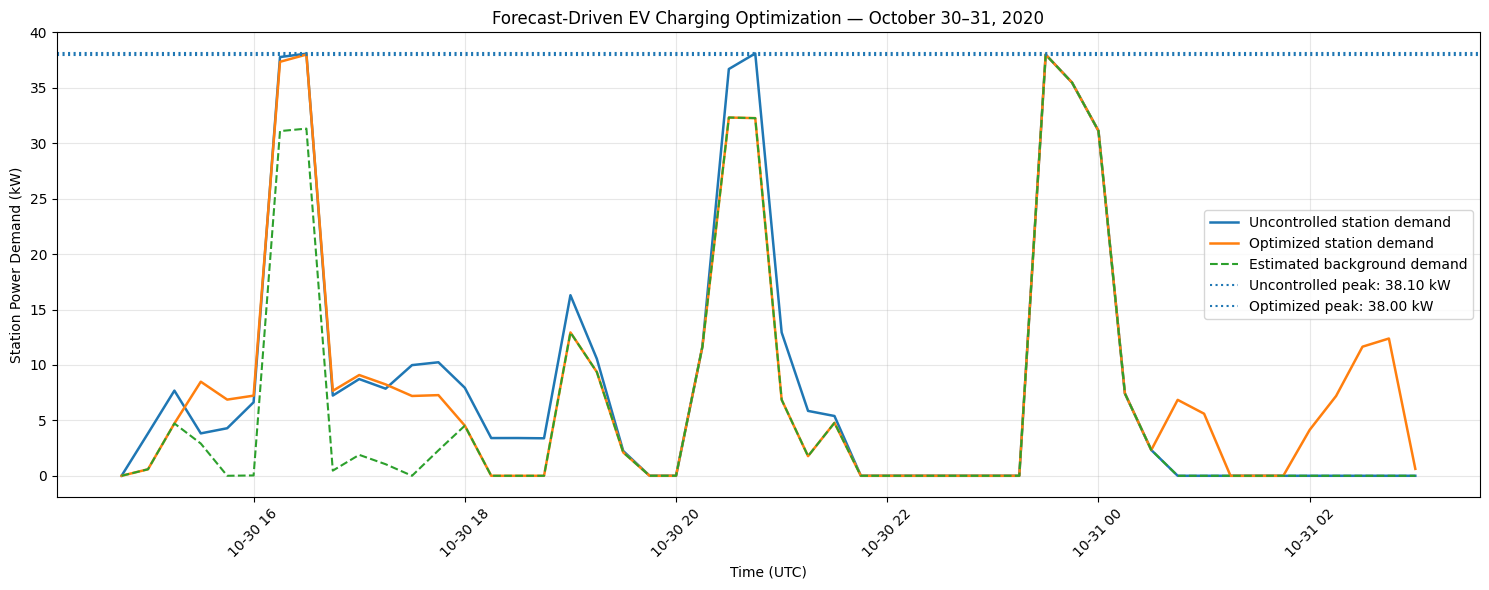

In [161]:

# STAGE 13 — TASK 9: VISUALIZE STATION PEAK REDUCTION

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    reconstruction_slots,
    uncontrolled_station_power,
    label="Uncontrolled station demand",
    linewidth=1.8
)

plt.plot(
    reconstruction_slots,
    optimized_station_power,
    label="Optimized station demand",
    linewidth=1.8
)

plt.plot(
    reconstruction_slots,
    background,
    label="Estimated background demand",
    linestyle="--",
    linewidth=1.5
)

plt.axhline(
    uncontrolled_peak,
    linestyle=":",
    label=f"Uncontrolled peak: {uncontrolled_peak:.2f} kW"
)

plt.axhline(
    optimized_peak,
    linestyle=":",
    label=f"Optimized peak: {optimized_peak:.2f} kW"
)

plt.title(
    "Forecast-Driven EV Charging Optimization — "
    "October 30–31, 2020"
)

plt.xlabel("Time (UTC)")
plt.ylabel("Station Power Demand (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


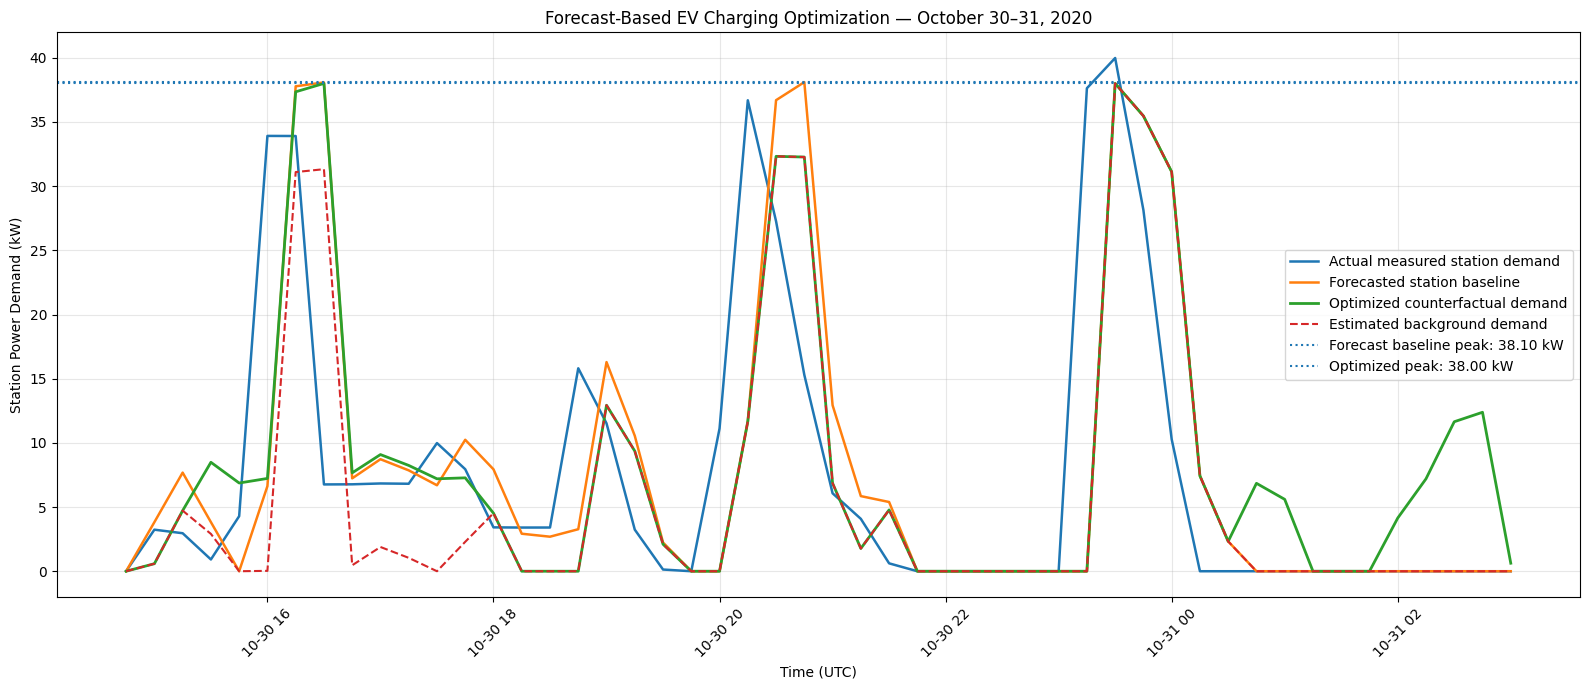

CORRECTED COMPARISON
--------------------
Actual measured station peak: 39.984 kW
Forecast baseline peak: 38.103 kW
Optimized counterfactual peak: 38.001 kW
Forecast-baseline peak reduction: 0.27 %


In [162]:

# STAGE 13 — TASK 10: CORRECTED FORECAST AND OPTIMIZATION COMPARISON

import matplotlib.pyplot as plt

# Original forecasted station demand
forecast_baseline = aligned_forecast_kw

# Actual measured station demand
actual_station_profile = measured_station_energy / DT

# Optimized counterfactual station demand
optimized_profile = optimized_station_power

# Plot all four profiles
plt.figure(figsize=(16, 7))

plt.plot(
    reconstruction_slots,
    actual_station_profile,
    label="Actual measured station demand",
    linewidth=1.8
)

plt.plot(
    reconstruction_slots,
    forecast_baseline,
    label="Forecasted station baseline",
    linewidth=1.8
)

plt.plot(
    reconstruction_slots,
    optimized_profile,
    label="Optimized counterfactual demand",
    linewidth=2
)

plt.plot(
    reconstruction_slots,
    background,
    label="Estimated background demand",
    linestyle="--",
    linewidth=1.5
)

plt.axhline(
    forecast_baseline.max(),
    linestyle=":",
    label=f"Forecast baseline peak: {forecast_baseline.max():.2f} kW"
)

plt.axhline(
    optimized_profile.max(),
    linestyle=":",
    label=f"Optimized peak: {optimized_profile.max():.2f} kW"
)

plt.title(
    "Forecast-Based EV Charging Optimization — "
    "October 30–31, 2020"
)

plt.xlabel("Time (UTC)")
plt.ylabel("Station Power Demand (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Report metrics with accurate labels
print("CORRECTED COMPARISON")
print("--------------------")

print(
    "Actual measured station peak:",
    round(actual_station_profile.max(), 3), "kW"
)

print(
    "Forecast baseline peak:",
    round(forecast_baseline.max(), 3), "kW"
)

print(
    "Optimized counterfactual peak:",
    round(optimized_profile.max(), 3), "kW"
)

print(
    "Forecast-baseline peak reduction:",
    round(
        (forecast_baseline.max() - optimized_profile.max())
        / forecast_baseline.max() * 100,
        2
    ),
    "%"
)


In [163]:

# STAGE 14 — TASK 1: IDENTIFY ALL OVERLAPPING EV SESSIONS

period_start = pd.Timestamp(reconstruction_slots[0])
period_end = (
    pd.Timestamp(reconstruction_slots[-1])
    + pd.Timedelta(minutes=15)
)

all_sessions = clean_sessions.copy()

all_sessions["arrival_time"] = pd.to_datetime(
    all_sessions["arrival_time"], utc=True
)

all_sessions["departure_time"] = pd.to_datetime(
    all_sessions["departure_time"], utc=True
)

# Find all sessions active at any point during our study period
overlapping_sessions = all_sessions[
    (all_sessions["arrival_time"] < period_end) &
    (all_sessions["departure_time"] > period_start)
].copy()

# Identify the five EVs selected for optimization
selected_ids = set(oct30_feasible["session_id"])

overlapping_sessions["session_group"] = np.where(
    overlapping_sessions["session_id"].isin(selected_ids),
    "Selected EV",
    "Other EV"
)

other_sessions = overlapping_sessions[
    overlapping_sessions["session_group"] == "Other EV"
].copy()

print("OVERLAPPING SESSION AUDIT")
print("-------------------------")
print("Period start:", period_start)
print("Period end:", period_end)
print("Total overlapping sessions:", len(overlapping_sessions))
print("Selected EV sessions:", len(selected_ids))
print("Other EV sessions:", len(other_sessions))

print("\nENERGY SUMMARY")

print(
    "Selected EV energy:",
    round(
        overlapping_sessions.loc[
            overlapping_sessions["session_group"] == "Selected EV",
            "clean_energy_kwh"
        ].sum(),
        3
    ),
    "kWh"
)

print(
    "Other EV session energy:",
    round(other_sessions["clean_energy_kwh"].sum(), 3),
    "kWh"
)

display(
    overlapping_sessions[
        [
            "session_id",
            "arrival_time",
            "departure_time",
            "clean_energy_kwh",
            "session_group"
        ]
    ].sort_values("arrival_time").reset_index(drop=True)
)


OVERLAPPING SESSION AUDIT
-------------------------
Period start: 2020-10-30 14:45:00+00:00
Period end: 2020-10-31 03:15:00+00:00
Total overlapping sessions: 10
Selected EV sessions: 5
Other EV sessions: 5

ENERGY SUMMARY
Selected EV energy: 27.269 kWh
Other EV session energy: 68.341 kWh


,session_id,arrival_time,departure_time,clean_energy_kwh,session_group
0,2-39-125-21-2020-10-30T14-59-52-469959.csv.gz,2020-10-30 14:59:52+00:00,2020-10-30 15:49:03+00:00,1.786580,Selected EV
1,2-39-138-29-2020-10-30T15-49-41-012877.csv.gz,2020-10-30 15:49:44+00:00,2020-10-30 17:55:23+00:00,13.975621,Selected EV
2,2-39-81-4550-2020-10-30T16-03-08-155236.csv.gz,2020-10-30 16:03:12.326667+00:00,2020-10-30 16:27:32.746019+00:00,13.634000,Other EV
3,2-39-130-31-2020-10-30T17-29-40-460304.csv.gz,2020-10-30 17:30:09+00:00,2020-10-31 03:01:18+00:00,6.262346,Selected EV
4,2-39-81-4550-2020-10-30T18-48-53-274794.csv.gz,2020-10-30 18:48:53.102383+00:00,2020-10-30 19:22:28.677616+00:00,5.660000,Other EV
5,2-39-81-4550-2020-10-30T20-10-48-056665.csv.gz,2020-10-30 20:10:49.801363+00:00,2020-10-30 22:18:36.654278+00:00,20.040000,Other EV
6,2-39-78-365-2020-10-30T20-31-25-542260.csv.gz,2020-10-30 20:31:28+00:00,2020-10-31 02:55:48+00:00,2.287274,Selected EV
7,2-39-79-379-2020-10-30T20-34-27-346844.csv.gz,2020-10-30 20:34:30+00:00,2020-10-31 01:11:40+00:00,2.956875,Selected EV
8,2-39-81-4550-2020-10-30T23-16-08-238514.csv.gz,2020-10-30 23:16:12.861380+00:00,2020-10-30 23:49:08.377495+00:00,21.218000,Other EV
9,2-39-81-4550-2020-10-30T23-49-40-346336.csv.gz,2020-10-30 23:49:43.388269+00:00,2020-10-31 00:45:30.131430+00:00,7.789000,Other EV


In [164]:

# STAGE 14 — TASK 2: RECONSTRUCT OTHER EV CHARGING DEMAND

import os
import numpy as np
import pandas as pd

other_ev_energy = np.zeros(len(reconstruction_slots))

other_session_results = []

for _, session in other_sessions.iterrows():

    file_path = os.path.join(
        caltech_path,
        session["session_id"]
    )

    raw = pd.read_csv(file_path, compression="gzip")

    # Extract timestamps and cumulative energy counter
    timestamps = pd.to_datetime(
        raw["Unnamed: 0"],
        utc=True,
        errors="coerce"
    )

    energy_counter = pd.to_numeric(
        raw["Energy Delivered (kWh)"],
        errors="coerce"
    )

    valid = timestamps.notna() & energy_counter.notna()

    timestamps = timestamps[valid].reset_index(drop=True)
    energy_counter = energy_counter[valid].reset_index(drop=True)

    # Positive increments only; ignore counter resets
    increments = energy_counter.diff().fillna(0).to_numpy()
    increments = np.maximum(increments, 0)

    session_allocated = np.zeros(len(reconstruction_slots))

    for k in range(1, len(timestamps)):

        energy = increments[k]

        if energy <= 0:
            continue

        t0 = timestamps.iloc[k - 1]
        t1 = timestamps.iloc[k]

        duration_seconds = (t1 - t0).total_seconds()

        if duration_seconds <= 0:
            continue

        # Allocate energy proportionally across overlapping slots
        for j, slot_start in enumerate(reconstruction_slots):

            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(t0, slot_start)
            overlap_end = min(t1, slot_end)

            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap_seconds > 0:

                fraction = overlap_seconds / duration_seconds

                allocated = energy * fraction

                session_allocated[j] += allocated

    other_ev_energy += session_allocated

    other_session_results.append({
        "session_id": session["session_id"],
        "clean_energy_kwh": session["clean_energy_kwh"],
        "reconstructed_window_energy_kwh": session_allocated.sum()
    })

other_reconstruction_df = pd.DataFrame(
    other_session_results
)

# Convert reconstructed energy into average interval power
other_ev_power = other_ev_energy / DT

print("OTHER EV RECONSTRUCTION RESULTS")
print("--------------------------------")

display(other_reconstruction_df.round(4))

print("\nTOTAL OTHER EV ENERGY IN STUDY WINDOW:",
      round(other_ev_energy.sum(), 4), "kWh")

print("PEAK OTHER EV DEMAND:",
      round(other_ev_power.max(), 4), "kW")

print("NUMBER OF INTERVALS WITH OTHER EV DEMAND:",
      np.sum(other_ev_energy > 0))

print("NUMBER OF STUDY INTERVALS:",
      len(reconstruction_slots))


OTHER EV RECONSTRUCTION RESULTS
--------------------------------


,session_id,clean_energy_kwh,reconstructed_window_energy_kwh
0,2-39-81-4550-2020-10-30T16-03-08-155236.csv.gz,13.634,13.634
1,2-39-81-4550-2020-10-30T18-48-53-274794.csv.gz,5.660,5.660
2,2-39-81-4550-2020-10-30T20-10-48-056665.csv.gz,20.040,20.040
3,2-39-81-4550-2020-10-30T23-16-08-238514.csv.gz,21.218,21.218
4,2-39-81-4550-2020-10-30T23-49-40-346336.csv.gz,7.789,7.789



TOTAL OTHER EV ENERGY IN STUDY WINDOW: 68.341 kWh
PEAK OTHER EV DEMAND: 39.984 kW
NUMBER OF INTERVALS WITH OTHER EV DEMAND: 13
NUMBER OF STUDY INTERVALS: 50


In [165]:

# STAGE 14 — TASK 3: RECONCILE STATION ENERGY

# Actual measured station energy per interval
measured_energy = np.asarray(measured_station_energy)

# Selected EV reconstructed energy
selected_energy = np.asarray(actual_ev_energy)

# Other EV reconstructed energy
other_energy = np.asarray(other_ev_energy)

# Calculate unexplained residual
unexplained_energy = (
    measured_energy - selected_energy - other_energy
)

# Convert energy to average interval power
measured_power = measured_energy / DT
selected_power = selected_energy / DT
other_power = other_energy / DT
unexplained_power = unexplained_energy / DT

# Build reconciliation table
reconciliation_df = pd.DataFrame({
    "timestamp": reconstruction_slots,
    "measured_station_kw": measured_power,
    "selected_ev_kw": selected_power,
    "other_ev_kw": other_power,
    "unexplained_residual_kw": unexplained_power
})

print("STATION ENERGY RECONCILIATION")
print("-----------------------------")

print("Measured station energy:",
      round(measured_energy.sum(), 4), "kWh")

print("Selected EV energy:",
      round(selected_energy.sum(), 4), "kWh")

print("Other EV energy:",
      round(other_energy.sum(), 4), "kWh")

print("Unexplained residual energy:",
      round(unexplained_energy.sum(), 4), "kWh")

print("\nNEGATIVE RESIDUAL INTERVALS:",
      np.sum(unexplained_energy < -1e-6))

print("Maximum unexplained residual:",
      round(unexplained_power.max(), 4), "kW")

print("\nPEAK DEMAND COMPARISON")

print("Measured station peak:",
      round(measured_power.max(), 3), "kW")

print("Selected EV peak:",
      round(selected_power.max(), 3), "kW")

print("Other EV peak:",
      round(other_power.max(), 3), "kW")

display(reconciliation_df.round(4))


STATION ENERGY RECONCILIATION
-----------------------------
Measured station energy: 95.6097 kWh
Selected EV energy: 27.2687 kWh
Other EV energy: 68.341 kWh
Unexplained residual energy: 0.0 kWh

NEGATIVE RESIDUAL INTERVALS: 0
Maximum unexplained residual: 0.0 kW

PEAK DEMAND COMPARISON
Measured station peak: 39.984 kW
Selected EV peak: 9.984 kW
Other EV peak: 39.984 kW


,timestamp,measured_station_kw,selected_ev_kw,other_ev_kw,unexplained_residual_kw
0,2020-10-30 14:45:00+00:00,0.0014,0.0014,0.0000,0.0
1,2020-10-30 15:00:00+00:00,3.2375,3.2375,0.0000,0.0
2,2020-10-30 15:15:00+00:00,2.9608,2.9608,0.0000,0.0
3,2020-10-30 15:30:00+00:00,0.9166,0.9166,0.0000,0.0
4,2020-10-30 15:45:00+00:00,4.2889,4.2889,0.0000,0.0
5,2020-10-30 16:00:00+00:00,33.9139,6.6019,27.3120,0.0
6,2020-10-30 16:15:00+00:00,33.9057,6.6817,27.2240,0.0
7,2020-10-30 16:30:00+00:00,6.7622,6.7622,0.0000,0.0
8,2020-10-30 16:45:00+00:00,6.7717,6.7717,0.0000,0.0
9,2020-10-30 17:00:00+00:00,6.8374,6.8374,0.0000,0.0


In [166]:

# STAGE 14 — TASK 4: REOPTIMIZE USING RECONSTRUCTED OTHER-EV LOAD

# Replace forecast-residual background with session-reconstructed demand
improved_background = other_ev_power.copy()

# Rebuild station peak constraints
A_ub_improved = np.zeros((n_slots, n_variables))
b_ub_improved = -improved_background.copy()

for j in range(n_slots):

    for i in range(n_ev):

        variable_index = i * n_slots + j
        A_ub_improved[j, variable_index] = 1 / DT

    A_ub_improved[j, peak_index] = -1

# Solve the same optimization problem
improved_result = linprog(
    c=objective,
    A_ub=A_ub_improved,
    b_ub=b_ub_improved,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("IMPROVED BACKGROUND OPTIMIZATION")
print("--------------------------------")
print("Success:", improved_result.success)
print("Message:", improved_result.message)

if improved_result.success:

    improved_allocation = improved_result.x[
        :n_energy_variables
    ].reshape(n_ev, n_slots)

    improved_peak = improved_result.x[peak_index]

    improved_ev_power = (
        improved_allocation.sum(axis=0) / DT
    )

    improved_station_power = (
        improved_background + improved_ev_power
    )

    uncontrolled_station_power_improved = (
        improved_background + selected_ev_actual_kw
    )

    uncontrolled_peak_improved = (
        uncontrolled_station_power_improved.max()
    )

    reduction_kw = (
        uncontrolled_peak_improved - improved_peak
    )

    reduction_pct = (
        reduction_kw / uncontrolled_peak_improved * 100
        if uncontrolled_peak_improved > 0 else 0
    )

    print("\nRESULTS")
    print("Uncontrolled station peak:",
          round(uncontrolled_peak_improved, 3), "kW")

    print("Optimized station peak:",
          round(improved_peak, 3), "kW")

    print("Peak reduction:",
          round(reduction_kw, 3), "kW")

    print("Peak reduction percentage:",
          round(reduction_pct, 2), "%")

    print("Total scheduled EV energy:",
          round(improved_allocation.sum(), 3), "kWh")


IMPROVED BACKGROUND OPTIMIZATION
--------------------------------
Success: True
Message: Optimization terminated successfully. (HiGHS Status 7: Optimal)

RESULTS
Uncontrolled station peak: 39.984 kW
Optimized station peak: 39.984 kW
Peak reduction: 0.0 kW
Peak reduction percentage: 0.0 %
Total scheduled EV energy: 28.704 kWh


In [167]:

# STAGE 14 — TASK 5: FIND BETTER OPTIMIZATION DAYS

session_analysis = test_sessions.copy()

session_analysis["arrival_time"] = pd.to_datetime(
    session_analysis["arrival_time"], utc=True
)

session_analysis["arrival_date"] = (
    session_analysis["arrival_time"].dt.date
)

daily_sessions = (
    session_analysis
    .groupby("arrival_date")
    .agg(
        total_sessions=("session_id", "count"),
        total_energy_kwh=("clean_energy_kwh", "sum"),
        average_energy_kwh=("clean_energy_kwh", "mean")
    )
    .reset_index()
)

daily_sessions = daily_sessions.sort_values(
    ["total_sessions", "total_energy_kwh"],
    ascending=False
)

print("TOP 15 CANDIDATE OPTIMIZATION DAYS")
print("----------------------------------")

display(daily_sessions.head(15))


TOP 15 CANDIDATE OPTIMIZATION DAYS
----------------------------------


,arrival_date,total_sessions,total_energy_kwh,average_energy_kwh
106,2020-10-30,12,133.411697,11.117641
66,2020-09-07,11,11.425829,1.038712
138,2020-12-01,10,64.959094,6.495909
95,2020-10-19,9,111.063486,12.340387
99,2020-10-23,9,74.470792,8.274532
139,2020-12-02,8,100.884142,12.610518
125,2020-11-18,8,52.595183,6.574398
118,2020-11-11,8,44.181934,5.522742
101,2020-10-25,7,142.725003,20.389286
77,2020-09-20,7,136.231958,19.461708


In [168]:

# STAGE 14 — TASK 6: SELECT OCTOBER 19 CANDIDATE

candidate_date = pd.Timestamp("2020-10-19").date()

candidate_sessions = test_sessions.copy()

candidate_sessions["arrival_time"] = pd.to_datetime(
    candidate_sessions["arrival_time"], utc=True
)

candidate_sessions["departure_time"] = pd.to_datetime(
    candidate_sessions["departure_time"], utc=True
)

candidate_sessions["arrival_date"] = (
    candidate_sessions["arrival_time"].dt.date
)

oct19_sessions = candidate_sessions[
    candidate_sessions["arrival_date"] == candidate_date
].copy()

print("OCTOBER 19 CANDIDATE")
print("--------------------")
print("Total arrivals:", len(oct19_sessions))
print("Total clean energy:",
      round(oct19_sessions["clean_energy_kwh"].sum(), 3), "kWh")

print("\nFEASIBILITY AT DIFFERENT CHARGER RATINGS")

for power in [3.3, 7.2, 11.0]:

    feasible_col = f"feasible_{power}kw"

    feasible_count = int(oct19_sessions[feasible_col].sum())

    print(
        f"{power} kW:",
        feasible_count,
        "feasible out of",
        len(oct19_sessions)
    )

print("\nSESSION DETAILS")

display(
    oct19_sessions[
        [
            "session_id",
            "arrival_time",
            "departure_time",
            "clean_energy_kwh",
            "required_grid_energy_kwh",
            "feasible_7.2kw"
        ]
    ].sort_values("arrival_time").reset_index(drop=True)
)


OCTOBER 19 CANDIDATE
--------------------
Total arrivals: 9
Total clean energy: 111.063 kWh

FEASIBILITY AT DIFFERENT CHARGER RATINGS


KeyError: 'feasible_3.3kw'

In [169]:
print("Available columns:")
print(oct19_sessions.columns.tolist())

print("\nFeasibility-related columns:")
print([
    col for col in oct19_sessions.columns
    if "feasible" in col.lower() or "max_energy" in col.lower()
])

Available columns:
['session_id', 'clean_energy_kwh', 'power_energy_kwh', 'coverage_pct', 'relative_difference_pct', 'decision', 'arrival_time', 'departure_time', 'arrival_date']

Feasibility-related columns:
[]


In [170]:

# STAGE 14 — TASK 6B: CALCULATE SESSION FEASIBILITY

MAX_DURATION_HOURS = 24
CHARGING_EFFICIENCY = 0.95

# Calculate session duration
oct19_sessions["duration_hours"] = (
    oct19_sessions["departure_time"] -
    oct19_sessions["arrival_time"]
).dt.total_seconds() / 3600

# Required grid energy
oct19_sessions["required_grid_energy_kwh"] = (
    oct19_sessions["clean_energy_kwh"] /
    CHARGING_EFFICIENCY
)

# Exclude sessions longer than 24 hours
oct19_sessions["duration_valid"] = (
    (oct19_sessions["duration_hours"] > 0) &
    (oct19_sessions["duration_hours"] <= MAX_DURATION_HOURS)
)

# Calculate feasibility for each charger rating
for power in [3.3, 7.2, 11.0]:

    oct19_sessions[f"max_energy_{power}kw"] = (
        power * oct19_sessions["duration_hours"]
    )

    oct19_sessions[f"feasible_{power}kw"] = (
        oct19_sessions["duration_valid"] &
        (
            oct19_sessions["required_grid_energy_kwh"]
            <= oct19_sessions[f"max_energy_{power}kw"]
        )
    )

# Display feasibility
print("OCTOBER 19 FEASIBILITY")
print("----------------------")

for power in [3.3, 7.2, 11.0]:

    count = oct19_sessions[
        f"feasible_{power}kw"
    ].sum()

    print(f"{power} kW: {count} / {len(oct19_sessions)} feasible")

display(
    oct19_sessions[
        [
            "session_id",
            "duration_hours",
            "clean_energy_kwh",
            "required_grid_energy_kwh",
            "feasible_3.3kw",
            "feasible_7.2kw",
            "feasible_11.0kw"
        ]
    ].round(3)
)


OCTOBER 19 FEASIBILITY
----------------------
3.3 kW: 3 / 9 feasible
7.2 kW: 5 / 9 feasible
11.0 kW: 5 / 9 feasible


,session_id,duration_hours,clean_energy_kwh,required_grid_energy_kwh,feasible_3.3kw,feasible_7.2kw,feasible_11.0kw
2917,2-39-125-21-2020-10-19T14-59-50-294477.csv.gz,0.988,3.188,3.356,False,True,True
2918,2-39-125-21-2020-10-19T22-51-47-345616.csv.gz,1.423,7.878,8.293,False,True,True
7342,2-39-130-31-2020-10-19T16-17-44-554604.csv.gz,11.996,6.158,6.482,True,True,True
20299,2-39-79-381-2020-10-19T20-00-54-178550.csv.gz,4.249,3.253,3.425,True,True,True
21421,2-39-81-4550-2020-10-19T02-31-58-131256.csv.gz,0.300,9.806,10.322,False,False,False
21422,2-39-81-4550-2020-10-19T03-01-41-975848.csv.gz,0.479,20.189,21.252,False,False,False
21423,2-39-81-4550-2020-10-19T19-34-03-936365.csv.gz,0.886,34.365,36.174,False,False,False
21424,2-39-81-4550-2020-10-19T22-34-16-315778.csv.gz,0.601,7.812,8.223,False,False,False
22538,2-39-88-24-2020-10-19T03-20-07-833059.csv.gz,12.271,18.414,19.384,True,True,True


In [171]:

# STAGE 14 — TASK 7: SELECT FEASIBLE OCTOBER 19 SESSIONS

oct19_feasible = oct19_sessions[
    oct19_sessions["feasible_7.2kw"]
].copy().reset_index(drop=True)

oct19_infeasible = oct19_sessions[
    ~oct19_sessions["feasible_7.2kw"]
].copy()

print("OCTOBER 19 SELECTED COHORT")
print("--------------------------")

print("Selected EVs:", len(oct19_feasible))
print("Excluded EVs:", len(oct19_infeasible))

print(
    "Total required grid energy:",
    round(oct19_feasible["required_grid_energy_kwh"].sum(), 3),
    "kWh"
)

print(
    "Total clean energy:",
    round(oct19_feasible["clean_energy_kwh"].sum(), 3),
    "kWh"
)

print(
    "Average parking duration:",
    round(oct19_feasible["duration_hours"].mean(), 3),
    "hours"
)

display(
    oct19_feasible[
        [
            "session_id",
            "arrival_time",
            "departure_time",
            "duration_hours",
            "clean_energy_kwh",
            "required_grid_energy_kwh"
        ]
    ]
)


OCTOBER 19 SELECTED COHORT
--------------------------
Selected EVs: 5
Excluded EVs: 4
Total required grid energy: 40.938 kWh
Total clean energy: 38.891 kWh
Average parking duration: 6.185 hours


,session_id,arrival_time,departure_time,duration_hours,clean_energy_kwh,required_grid_energy_kwh
0,2-39-125-21-2020-10-19T14-59-50-294477.csv.gz,2020-10-19 14:59:53+00:00,2020-10-19 15:59:08+00:00,0.987500,3.188056,3.355848
1,2-39-125-21-2020-10-19T22-51-47-345616.csv.gz,2020-10-19 22:52:03+00:00,2020-10-20 00:17:26+00:00,1.423056,7.877970,8.292600
2,2-39-130-31-2020-10-19T16-17-44-554604.csv.gz,2020-10-19 16:18:15+00:00,2020-10-20 04:18:01+00:00,11.996111,6.157694,6.481783
3,2-39-79-381-2020-10-19T20-00-54-178550.csv.gz,2020-10-19 20:00:57+00:00,2020-10-20 00:15:55+00:00,4.249444,3.253312,3.424539
4,2-39-88-24-2020-10-19T03-20-07-833059.csv.gz,2020-10-19 03:20:11+00:00,2020-10-19 15:36:26+00:00,12.270833,18.414454,19.383636


In [172]:

# STAGE 14 — TASK 8: DEFINE OCTOBER 19 OPTIMIZATION WINDOW

oct19_start = pd.to_datetime(
    oct19_feasible["arrival_time"].min(), utc=True
).floor("15min")

oct19_end = pd.to_datetime(
    oct19_feasible["departure_time"].max(), utc=True
).ceil("15min")

oct19_slots = pd.date_range(
    start=oct19_start,
    end=oct19_end,
    freq="15min",
    inclusive="left"
)

print("OCTOBER 19 OPTIMIZATION WINDOW")
print("--------------------------------")
print("Start:", oct19_start)
print("End:", oct19_end)
print("Number of 15-minute intervals:", len(oct19_slots))
print("Duration in hours:",
      round(len(oct19_slots) * DT, 2))

print("\nSELECTED EV AVAILABILITY")

for i, session in oct19_feasible.iterrows():

    print(
        f"EV {i+1}:",
        session["arrival_time"],
        "to",
        session["departure_time"]
    )


OCTOBER 19 OPTIMIZATION WINDOW
--------------------------------
Start: 2020-10-19 03:15:00+00:00
End: 2020-10-20 04:30:00+00:00
Number of 15-minute intervals: 101
Duration in hours: 25.25

SELECTED EV AVAILABILITY
EV 1: 2020-10-19 14:59:53+00:00 to 2020-10-19 15:59:08+00:00
EV 2: 2020-10-19 22:52:03+00:00 to 2020-10-20 00:17:26+00:00
EV 3: 2020-10-19 16:18:15+00:00 to 2020-10-20 04:18:01+00:00
EV 4: 2020-10-19 20:00:57+00:00 to 2020-10-20 00:15:55+00:00
EV 5: 2020-10-19 03:20:11+00:00 to 2020-10-19 15:36:26+00:00


In [173]:

# STAGE 14 — TASK 9: FIND ALL OVERLAPPING OCTOBER 19 SESSIONS

oct19_all_sessions = clean_sessions.copy()

oct19_all_sessions["arrival_time"] = pd.to_datetime(
    oct19_all_sessions["arrival_time"], utc=True
)

oct19_all_sessions["departure_time"] = pd.to_datetime(
    oct19_all_sessions["departure_time"], utc=True
)

# Find sessions overlapping the optimization window
oct19_overlapping = oct19_all_sessions[
    (oct19_all_sessions["arrival_time"] < oct19_end) &
    (oct19_all_sessions["departure_time"] > oct19_start)
].copy()

# Identify selected EVs
oct19_selected_ids = set(oct19_feasible["session_id"])

oct19_overlapping["session_group"] = np.where(
    oct19_overlapping["session_id"].isin(oct19_selected_ids),
    "Selected EV",
    "Other EV"
)

oct19_other_sessions = oct19_overlapping[
    oct19_overlapping["session_group"] == "Other EV"
].copy()

print("OCTOBER 19 OVERLAPPING SESSION AUDIT")
print("-----------------------------------")
print("Total overlapping sessions:", len(oct19_overlapping))
print("Selected EVs:", len(oct19_selected_ids))
print("Other EVs:", len(oct19_other_sessions))

print(
    "\nSelected EV total clean energy:",
    round(
        oct19_feasible["clean_energy_kwh"].sum(), 3
    ),
    "kWh"
)

print(
    "Other EV total session energy:",
    round(
        oct19_other_sessions["clean_energy_kwh"].sum(), 3
    ),
    "kWh"
)

display(
    oct19_overlapping[
        [
            "session_id",
            "arrival_time",
            "departure_time",
            "clean_energy_kwh",
            "session_group"
        ]
    ].sort_values("arrival_time").reset_index(drop=True)
)


OCTOBER 19 OVERLAPPING SESSION AUDIT
-----------------------------------
Total overlapping sessions: 10
Selected EVs: 5
Other EVs: 5

Selected EV total clean energy: 38.891 kWh
Other EV total session energy: 72.04 kWh


,session_id,arrival_time,departure_time,clean_energy_kwh,session_group
0,2-39-78-365-2020-10-18T22-33-36-865217.csv.gz,2020-10-18 22:33:40+00:00,2020-10-19 03:54:04+00:00,2.623557,Other EV
1,2-39-81-4550-2020-10-19T03-01-41-975848.csv.gz,2020-10-19 03:01:43.907926+00:00,2020-10-19 03:30:29.491962+00:00,20.189000,Other EV
2,2-39-88-24-2020-10-19T03-20-07-833059.csv.gz,2020-10-19 03:20:11+00:00,2020-10-19 15:36:26+00:00,18.414454,Selected EV
3,2-39-125-21-2020-10-19T14-59-50-294477.csv.gz,2020-10-19 14:59:53+00:00,2020-10-19 15:59:08+00:00,3.188056,Selected EV
4,2-39-130-31-2020-10-19T16-17-44-554604.csv.gz,2020-10-19 16:18:15+00:00,2020-10-20 04:18:01+00:00,6.157694,Selected EV
5,2-39-81-4550-2020-10-19T19-34-03-936365.csv.gz,2020-10-19 19:34:05.508580+00:00,2020-10-19 20:27:16.602456+00:00,34.365000,Other EV
6,2-39-79-381-2020-10-19T20-00-54-178550.csv.gz,2020-10-19 20:00:57+00:00,2020-10-20 00:15:55+00:00,3.253312,Selected EV
7,2-39-81-4550-2020-10-19T22-34-16-315778.csv.gz,2020-10-19 22:37:56.348821+00:00,2020-10-19 23:14:00.470609+00:00,7.812000,Other EV
8,2-39-125-21-2020-10-19T22-51-47-345616.csv.gz,2020-10-19 22:52:03+00:00,2020-10-20 00:17:26+00:00,7.877970,Selected EV
9,2-39-81-4550-2020-10-20T01-00-06-003231.csv.gz,2020-10-20 01:00:07.616415+00:00,2020-10-20 01:23:43.087008+00:00,7.050000,Other EV


In [174]:

# STAGE 14 — TASK 10: RECONSTRUCT OTHER OCTOBER 19 EV LOAD

oct19_other_energy = np.zeros(len(oct19_slots))

oct19_other_session_results = []

for _, session in oct19_other_sessions.iterrows():

    file_path = os.path.join(
        caltech_path,
        session["session_id"]
    )

    raw = pd.read_csv(file_path, compression="gzip")

    timestamps = pd.to_datetime(
        raw["Unnamed: 0"],
        utc=True,
        errors="coerce"
    )

    energy_counter = pd.to_numeric(
        raw["Energy Delivered (kWh)"],
        errors="coerce"
    )

    valid = timestamps.notna() & energy_counter.notna()

    timestamps = timestamps[valid].reset_index(drop=True)
    energy_counter = energy_counter[valid].reset_index(drop=True)

    increments = energy_counter.diff().fillna(0).to_numpy()
    increments = np.maximum(increments, 0)

    session_allocated = np.zeros(len(oct19_slots))

    for k in range(1, len(timestamps)):

        energy = increments[k]

        if energy <= 0:
            continue

        t0 = timestamps.iloc[k - 1]
        t1 = timestamps.iloc[k]

        duration_seconds = (t1 - t0).total_seconds()

        if duration_seconds <= 0:
            continue

        for j, slot_start in enumerate(oct19_slots):

            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(t0, slot_start)
            overlap_end = min(t1, slot_end)

            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap_seconds > 0:

                session_allocated[j] += (
                    energy * overlap_seconds / duration_seconds
                )

    oct19_other_energy += session_allocated

    oct19_other_session_results.append({
        "session_id": session["session_id"],
        "complete_session_energy_kwh": session["clean_energy_kwh"],
        "energy_inside_window_kwh": session_allocated.sum()
    })

oct19_other_reconstruction_df = pd.DataFrame(
    oct19_other_session_results
)

oct19_other_power = oct19_other_energy / DT

print("OCTOBER 19 OTHER-EV RECONSTRUCTION")
print("----------------------------------")

display(oct19_other_reconstruction_df.round(4))

print("\nTotal other-EV energy inside window:",
      round(oct19_other_energy.sum(), 4), "kWh")

print("Peak other-EV demand:",
      round(oct19_other_power.max(), 4), "kW")

print("Active intervals:",
      np.sum(oct19_other_energy > 0))

print("Total intervals:", len(oct19_slots))


OCTOBER 19 OTHER-EV RECONSTRUCTION
----------------------------------


,session_id,complete_session_energy_kwh,energy_inside_window_kwh
0,2-39-78-365-2020-10-18T22-33-36-865217.csv.gz,2.6236,0.0000
1,2-39-81-4550-2020-10-19T03-01-41-975848.csv.gz,20.1890,10.9282
2,2-39-81-4550-2020-10-19T19-34-03-936365.csv.gz,34.3650,34.3650
3,2-39-81-4550-2020-10-19T22-34-16-315778.csv.gz,7.8120,7.8120
4,2-39-81-4550-2020-10-20T01-00-06-003231.csv.gz,7.0500,7.0500



Total other-EV energy inside window: 60.1552 kWh
Peak other-EV demand: 45.8918 kW
Active intervals: 11
Total intervals: 101


In [175]:

# STAGE 14 — TASK 11: RECONSTRUCT SELECTED OCTOBER 19 EV LOAD

oct19_selected_energy = np.zeros(len(oct19_slots))

oct19_selected_session_results = []

for _, session in oct19_feasible.iterrows():

    file_path = os.path.join(
        caltech_path,
        session["session_id"]
    )

    raw = pd.read_csv(file_path, compression="gzip")

    timestamps = pd.to_datetime(
        raw["Unnamed: 0"],
        utc=True,
        errors="coerce"
    )

    energy_counter = pd.to_numeric(
        raw["Energy Delivered (kWh)"],
        errors="coerce"
    )

    valid = timestamps.notna() & energy_counter.notna()

    timestamps = timestamps[valid].reset_index(drop=True)
    energy_counter = energy_counter[valid].reset_index(drop=True)

    increments = energy_counter.diff().fillna(0).to_numpy()
    increments = np.maximum(increments, 0)

    session_allocated = np.zeros(len(oct19_slots))

    for k in range(1, len(timestamps)):

        energy = increments[k]

        if energy <= 0:
            continue

        t0 = timestamps.iloc[k - 1]
        t1 = timestamps.iloc[k]

        duration_seconds = (t1 - t0).total_seconds()

        if duration_seconds <= 0:
            continue

        for j, slot_start in enumerate(oct19_slots):

            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(t0, slot_start)
            overlap_end = min(t1, slot_end)

            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap_seconds > 0:

                session_allocated[j] += (
                    energy * overlap_seconds / duration_seconds
                )

    oct19_selected_energy += session_allocated

    oct19_selected_session_results.append({
        "session_id": session["session_id"],
        "clean_energy_kwh": session["clean_energy_kwh"],
        "reconstructed_window_energy_kwh": session_allocated.sum()
    })

oct19_selected_reconstruction_df = pd.DataFrame(
    oct19_selected_session_results
)

oct19_selected_power = oct19_selected_energy / DT

print("OCTOBER 19 SELECTED-EV RECONSTRUCTION")
print("-------------------------------------")

display(oct19_selected_reconstruction_df.round(4))

print("\nTotal selected-EV energy inside window:",
      round(oct19_selected_energy.sum(), 4), "kWh")

print("Peak selected-EV demand:",
      round(oct19_selected_power.max(), 4), "kW")

print("Active intervals:",
      np.sum(oct19_selected_energy > 0))

print("Total intervals:", len(oct19_slots))


OCTOBER 19 SELECTED-EV RECONSTRUCTION
-------------------------------------


,session_id,clean_energy_kwh,reconstructed_window_energy_kwh
0,2-39-125-21-2020-10-19T14-59-50-294477.csv.gz,3.1881,3.1881
1,2-39-125-21-2020-10-19T22-51-47-345616.csv.gz,7.8780,7.8780
2,2-39-130-31-2020-10-19T16-17-44-554604.csv.gz,6.1577,6.1577
3,2-39-79-381-2020-10-19T20-00-54-178550.csv.gz,3.2533,3.2533
4,2-39-88-24-2020-10-19T03-20-07-833059.csv.gz,18.4145,18.4145



Total selected-EV energy inside window: 38.8915 kWh
Peak selected-EV demand: 6.8837 kW
Active intervals: 36
Total intervals: 101


In [176]:

print("Station profile type:", type(station_profile_complete))

print("\nColumns:")
print(getattr(station_profile_complete, "columns", "No columns attribute"))

print("\nIndex type:")
print(type(station_profile_complete.index))

print("\nFirst five rows:")
display(station_profile_complete.head())

print("\nIndex range:")
print(station_profile_complete.index.min())
print(station_profile_complete.index.max())


Station profile type: <class 'pandas.core.frame.DataFrame'>

Columns:
Index(['timestamp', 'energy_kwh', 'average_power_kw', 'date', 'hour',
       'day_of_week', 'month'],
      dtype='object')

Index type:
<class 'pandas.core.indexes.range.RangeIndex'>

First five rows:


,timestamp,energy_kwh,average_power_kw,date,hour,day_of_week,month
0,2018-05-01 00:30:00+00:00,0.837569,3.350274,2018-05-01,0,1,5
1,2018-05-01 00:45:00+00:00,1.773271,7.093083,2018-05-01,0,1,5
2,2018-05-01 01:00:00+00:00,2.628674,10.514696,2018-05-01,1,1,5
3,2018-05-01 01:15:00+00:00,3.672413,14.689652,2018-05-01,1,1,5
4,2018-05-01 01:30:00+00:00,5.519586,22.078342,2018-05-01,1,1,5



Index range:
0
90914


In [177]:

# STAGE 14 — TASK 12: STATION ENERGY RECONCILIATION

# Prepare station profile with UTC timestamps
oct19_station = station_profile_complete.copy()

oct19_station["timestamp"] = pd.to_datetime(
    oct19_station["timestamp"], utc=True
)

oct19_station = oct19_station.set_index("timestamp")

# Align station energy to the 101 optimization intervals
oct19_station_energy = (
    oct19_station["energy_kwh"]
    .reindex(oct19_slots)
    .fillna(0)
    .to_numpy()
)

oct19_station_power = oct19_station_energy / DT

# Calculate energy balance
oct19_unexplained_energy = (
    oct19_station_energy
    - oct19_selected_energy
    - oct19_other_energy
)

oct19_reconciliation_df = pd.DataFrame({
    "timestamp": oct19_slots,
    "station_energy_kwh": oct19_station_energy,
    "selected_ev_energy_kwh": oct19_selected_energy,
    "other_ev_energy_kwh": oct19_other_energy,
    "unexplained_energy_kwh": oct19_unexplained_energy
})

print("OCTOBER 19 STATION ENERGY RECONCILIATION")
print("----------------------------------------")

print("Station energy:",
      round(oct19_station_energy.sum(), 4), "kWh")

print("Selected EV energy:",
      round(oct19_selected_energy.sum(), 4), "kWh")

print("Other EV energy:",
      round(oct19_other_energy.sum(), 4), "kWh")

print("Unexplained energy:",
      round(oct19_unexplained_energy.sum(), 6), "kWh")

print("\nPeak station demand:",
      round(oct19_station_power.max(), 4), "kW")

print("Peak selected EV demand:",
      round(oct19_selected_power.max(), 4), "kW")

print("Peak other EV demand:",
      round(oct19_other_power.max(), 4), "kW")

print("\nMaximum absolute interval residual:",
      round(np.abs(oct19_unexplained_energy).max(), 6), "kWh")

display(oct19_reconciliation_df.head(10).round(4))


OCTOBER 19 STATION ENERGY RECONCILIATION
----------------------------------------
Station energy: 99.0467 kWh
Selected EV energy: 38.8915 kWh
Other EV energy: 60.1552 kWh
Unexplained energy: 0.0 kWh

Peak station demand: 47.0778 kW
Peak selected EV demand: 6.8837 kW
Peak other EV demand: 45.8918 kW

Maximum absolute interval residual: 0.0 kWh


,timestamp,station_energy_kwh,selected_ev_energy_kwh,other_ev_energy_kwh,unexplained_energy_kwh
0,2020-10-19 03:15:00+00:00,11.7694,0.9417,10.8277,0.0
1,2020-10-19 03:30:00+00:00,1.8117,1.7113,0.1005,0.0
2,2020-10-19 03:45:00+00:00,1.7063,1.7063,0.0000,0.0
3,2020-10-19 04:00:00+00:00,1.7122,1.7122,0.0000,0.0
4,2020-10-19 04:15:00+00:00,1.7038,1.7038,0.0000,0.0
5,2020-10-19 04:30:00+00:00,1.6973,1.6973,0.0000,0.0
6,2020-10-19 04:45:00+00:00,1.7070,1.7070,0.0000,0.0
7,2020-10-19 05:00:00+00:00,1.7178,1.7178,0.0000,0.0
8,2020-10-19 05:15:00+00:00,1.7148,1.7148,0.0000,0.0
9,2020-10-19 05:30:00+00:00,1.7209,1.7209,0.0000,0.0


In [178]:

# STAGE 14 — TASK 13: IDENTIFY PEAK-DEMAND INTERVALS

oct19_peak_idx = np.argmax(oct19_station_power)

print("STATION PEAK INTERVAL")
print("---------------------")

print("Timestamp (UTC):",
      oct19_slots[oct19_peak_idx])

print("Station demand:",
      round(oct19_station_power[oct19_peak_idx], 4), "kW")

print("Selected EV demand:",
      round(oct19_selected_power[oct19_peak_idx], 4), "kW")

print("Other EV demand:",
      round(oct19_other_power[oct19_peak_idx], 4), "kW")

print("\nTOP 10 STATION DEMAND INTERVALS")

oct19_peak_table = pd.DataFrame({
    "timestamp_utc": oct19_slots,
    "station_power_kw": oct19_station_power,
    "selected_ev_power_kw": oct19_selected_power,
    "other_ev_power_kw": oct19_other_power
})

display(
    oct19_peak_table
    .sort_values("station_power_kw", ascending=False)
    .head(10)
    .round(4)
    .reset_index(drop=True)
)


STATION PEAK INTERVAL
---------------------
Timestamp (UTC): 2020-10-19 03:15:00+00:00
Station demand: 47.0778 kW
Selected EV demand: 3.7669 kW
Other EV demand: 43.3109 kW

TOP 10 STATION DEMAND INTERVALS


,timestamp_utc,station_power_kw,selected_ev_power_kw,other_ev_power_kw
0,2020-10-19 03:15:00+00:00,47.0778,3.7669,43.3109
1,2020-10-19 19:45:00+00:00,45.8918,0.0000,45.8918
2,2020-10-19 20:00:00+00:00,45.2130,3.3634,41.8495
3,2020-10-19 19:30:00+00:00,31.2696,0.0000,31.2696
4,2020-10-20 01:00:00+00:00,24.1330,0.0000,24.1330
5,2020-10-19 20:15:00+00:00,22.2185,3.7694,18.4491
6,2020-10-19 22:45:00+00:00,20.9943,3.3514,17.6429
7,2020-10-19 23:00:00+00:00,10.9676,6.3962,4.5713
8,2020-10-19 22:30:00+00:00,9.0338,0.0000,9.0338
9,2020-10-19 03:30:00+00:00,7.2470,6.8450,0.4019


In [179]:

# STAGE 14 — TASK 14: OCTOBER 19 LP OPTIMIZATION

from scipy.optimize import linprog

n_ev = len(oct19_feasible)
n_slots = len(oct19_slots)

# Required grid energy for each selected EV
required_energy = oct19_feasible[
    "required_grid_energy_kwh"
].to_numpy(dtype=float)

# Calculate EV availability in each 15-minute interval
overlap_hours = np.zeros((n_ev, n_slots))

for i, (_, session) in enumerate(oct19_feasible.iterrows()):

    arrival = pd.to_datetime(session["arrival_time"], utc=True)
    departure = pd.to_datetime(session["departure_time"], utc=True)

    for j, slot_start in enumerate(oct19_slots):

        slot_end = slot_start + pd.Timedelta(minutes=15)

        overlap_start = max(arrival, slot_start)
        overlap_end = min(departure, slot_end)

        overlap_seconds = (
            overlap_end - overlap_start
        ).total_seconds()

        if overlap_seconds > 0:
            overlap_hours[i, j] = overlap_seconds / 3600

# Maximum grid energy per EV per interval
max_energy = MAX_CHARGING_POWER_KW * overlap_hours

# Decision variables:
# First n_ev*n_slots variables = EV charging energy
# Last variable = maximum station demand P

n_energy_vars = n_ev * n_slots
n_variables = n_energy_vars + 1

# Objective: minimize P
objective = np.zeros(n_variables)
objective[-1] = 1

# Energy equality constraints for every EV
A_eq = np.zeros((n_ev, n_variables))

for i in range(n_ev):
    start = i * n_slots
    end = start + n_slots
    A_eq[i, start:end] = 1

b_eq = required_energy

# Station peak constraints for every interval:
# Other EV power + selected EV power <= P
A_ub = np.zeros((n_slots, n_variables))

for j in range(n_slots):

    for i in range(n_ev):
        A_ub[j, i * n_slots + j] = 1 / DT

    A_ub[j, -1] = -1

b_ub = -oct19_other_power

# Variable bounds
bounds = []

for i in range(n_ev):
    for j in range(n_slots):
        bounds.append((0, max_energy[i, j]))

# Peak demand cannot be negative
bounds.append((0, None))

# Solve LP
oct19_result = linprog(
    c=objective,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("OCTOBER 19 OPTIMIZATION RESULT")
print("--------------------------------")

print("Solver success:", oct19_result.success)
print("Solver message:", oct19_result.message)

if oct19_result.success:

    # Extract optimized EV charging energy
    oct19_optimized_energy = oct19_result.x[
        :n_energy_vars
    ].reshape(n_ev, n_slots)

    oct19_optimized_ev_power = (
        oct19_optimized_energy / DT
    ).sum(axis=0)

    # Add fixed background demand
    oct19_optimized_station_power = (
        oct19_other_power + oct19_optimized_ev_power
    )

    # Baseline is reconstructed actual station demand
    oct19_baseline_peak = oct19_station_power.max()

    oct19_optimized_peak = (
        oct19_optimized_station_power.max()
    )

    oct19_peak_reduction = (
        oct19_baseline_peak - oct19_optimized_peak
    )

    oct19_reduction_pct = (
        oct19_peak_reduction / oct19_baseline_peak
    ) * 100

    # Validate energy and power constraints
    oct19_ev_energy_check = oct19_optimized_energy.sum(axis=1)

    oct19_energy_errors = (
        oct19_ev_energy_check - required_energy
    )

    oct19_max_ev_power = (
        oct19_optimized_energy / DT
    ).max(axis=1)

    oct19_energy_constraint_pass = np.allclose(
        oct19_ev_energy_check,
        required_energy,
        atol=1e-6
    )

    oct19_power_constraint_pass = np.all(
        oct19_max_ev_power <= MAX_CHARGING_POWER_KW + 1e-6
    )

    oct19_availability_constraint_pass = np.all(
        oct19_optimized_energy <= max_energy + 1e-6
    )

    print("\nBaseline station peak:",
          round(oct19_baseline_peak, 4), "kW")

    print("Optimized station peak:",
          round(oct19_optimized_peak, 4), "kW")

    print("Peak reduction:",
          round(oct19_peak_reduction, 4), "kW")

    print("Peak reduction percentage:",
          round(oct19_reduction_pct, 2), "%")

    print("\nEnergy constraint passed:",
          oct19_energy_constraint_pass)

    print("Power constraint passed:",
          oct19_power_constraint_pass)

    print("Availability constraint passed:",
          oct19_availability_constraint_pass)

    print("\nMaximum absolute EV energy error:",
          round(np.abs(oct19_energy_errors).max(), 8), "kWh")

    print("\nOptimized background-only peak:",
          round(oct19_other_power.max(), 4), "kW")


OCTOBER 19 OPTIMIZATION RESULT
--------------------------------
Solver success: True
Solver message: Optimization terminated successfully. (HiGHS Status 7: Optimal)

Baseline station peak: 47.0778 kW
Optimized station peak: 45.8918 kW
Peak reduction: 1.186 kW
Peak reduction percentage: 2.52 %

Energy constraint passed: True
Power constraint passed: True
Availability constraint passed: True

Maximum absolute EV energy error: 0.0 kWh

Optimized background-only peak: 45.8918 kW


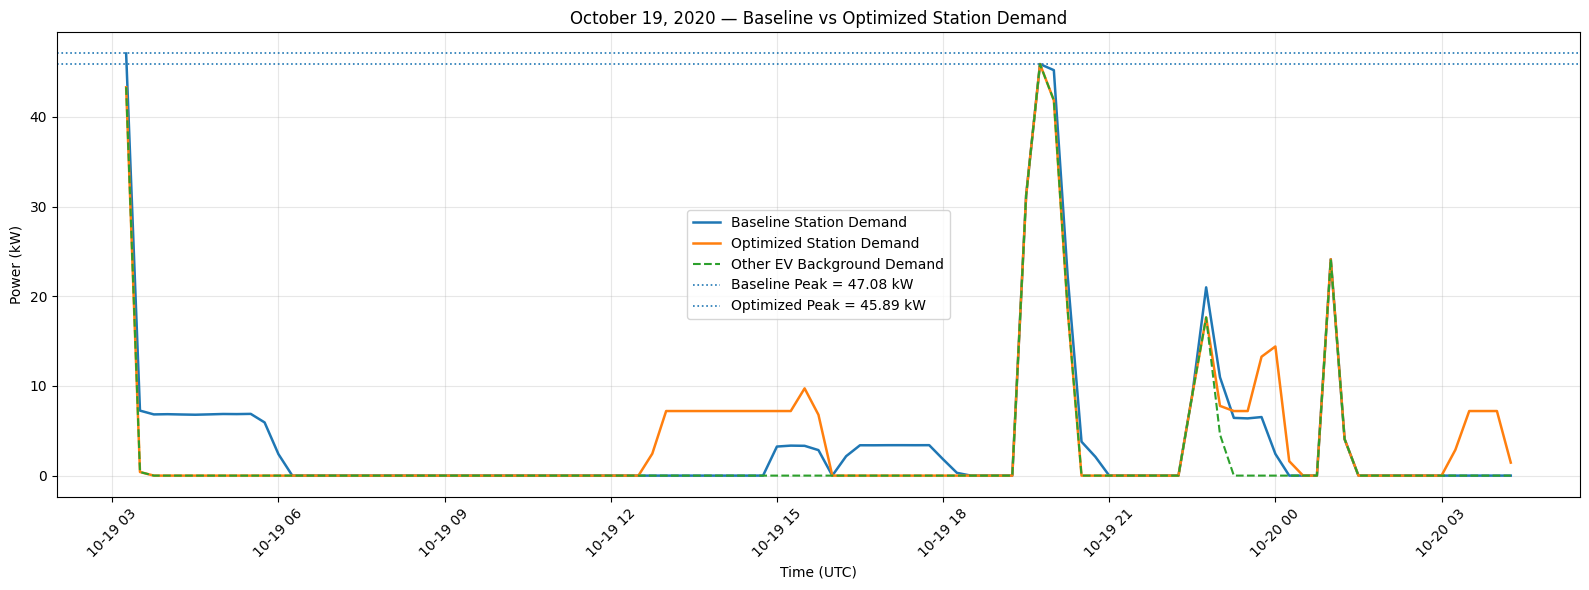

In [180]:

# STAGE 14 — TASK 15: BASELINE VS OPTIMIZED DEMAND

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    oct19_slots,
    oct19_station_power,
    label="Baseline Station Demand",
    linewidth=1.8
)

plt.plot(
    oct19_slots,
    oct19_optimized_station_power,
    label="Optimized Station Demand",
    linewidth=1.8
)

plt.plot(
    oct19_slots,
    oct19_other_power,
    label="Other EV Background Demand",
    linestyle="--",
    linewidth=1.5
)

plt.axhline(
    oct19_baseline_peak,
    linestyle=":",
    linewidth=1.2,
    label=f"Baseline Peak = {oct19_baseline_peak:.2f} kW"
)

plt.axhline(
    oct19_optimized_peak,
    linestyle=":",
    linewidth=1.2,
    label=f"Optimized Peak = {oct19_optimized_peak:.2f} kW"
)

plt.title(
    "October 19, 2020 — Baseline vs Optimized Station Demand"
)

plt.xlabel("Time (UTC)")
plt.ylabel("Power (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [181]:

# STAGE 14 — TASK 16: INDIVIDUAL EV CHARGING SCHEDULE

oct19_ev_schedule_rows = []

for i, (_, session) in enumerate(oct19_feasible.iterrows()):

    ev_power = oct19_optimized_energy[i, :] / DT

    active_indices = np.where(ev_power > 1e-6)[0]

    if len(active_indices) > 0:
        first_charging = oct19_slots[active_indices[0]]
        last_charging = oct19_slots[active_indices[-1]]
    else:
        first_charging = pd.NaT
        last_charging = pd.NaT

    oct19_ev_schedule_rows.append({
        "session_id": session["session_id"],
        "arrival_utc": session["arrival_time"],
        "departure_utc": session["departure_time"],
        "required_energy_kwh": required_energy[i],
        "optimized_energy_kwh": oct19_optimized_energy[i].sum(),
        "charging_intervals": len(active_indices),
        "first_charging_utc": first_charging,
        "last_charging_utc": last_charging,
        "maximum_charging_power_kw": ev_power.max()
    })

oct19_ev_schedule_df = pd.DataFrame(oct19_ev_schedule_rows)

print("OCTOBER 19 — INDIVIDUAL EV OPTIMIZED SCHEDULE")
print("---------------------------------------------")

display(oct19_ev_schedule_df.round(4))

print("\nTotal optimized charging energy:",
      round(oct19_optimized_energy.sum(), 4), "kWh")

print("Total required grid energy:",
      round(required_energy.sum(), 4), "kWh")


OCTOBER 19 — INDIVIDUAL EV OPTIMIZED SCHEDULE
---------------------------------------------


,session_id,arrival_utc,departure_utc,required_energy_kwh,optimized_energy_kwh,charging_intervals,first_charging_utc,last_charging_utc,maximum_charging_power_kw
0,2-39-125-21-2020-10-19T14-59-50-294477.csv.gz,2020-10-19 14:59:53+00:00,2020-10-19 15:59:08+00:00,3.3558,3.3558,2,2020-10-19 15:30:00+00:00,2020-10-19 15:45:00+00:00,6.784
1,2-39-125-21-2020-10-19T22-51-47-345616.csv.gz,2020-10-19 22:52:03+00:00,2020-10-20 00:17:26+00:00,8.2926,8.2926,6,2020-10-19 23:00:00+00:00,2020-10-20 00:15:00+00:00,7.200
2,2-39-130-31-2020-10-19T16-17-44-554604.csv.gz,2020-10-19 16:18:15+00:00,2020-10-20 04:18:01+00:00,6.4818,6.4818,5,2020-10-20 03:15:00+00:00,2020-10-20 04:15:00+00:00,7.200
3,2-39-79-381-2020-10-19T20-00-54-178550.csv.gz,2020-10-19 20:00:57+00:00,2020-10-20 00:15:55+00:00,3.4245,3.4245,3,2020-10-19 23:45:00+00:00,2020-10-20 00:15:00+00:00,7.200
4,2-39-88-24-2020-10-19T03-20-07-833059.csv.gz,2020-10-19 03:20:11+00:00,2020-10-19 15:36:26+00:00,19.3836,19.3836,12,2020-10-19 12:45:00+00:00,2020-10-19 15:30:00+00:00,7.200



Total optimized charging energy: 40.9384 kWh
Total required grid energy: 40.9384 kWh


In [182]:

# STAGE 14 — TASK 17: FINAL OCTOBER 19 PERFORMANCE METRICS

oct19_total_required_energy = required_energy.sum()
oct19_total_optimized_energy = oct19_optimized_energy.sum()

oct19_metrics = pd.DataFrame({
    "Metric": [
        "Number of selected EVs",
        "Number of other EVs",
        "Optimization intervals",
        "Total selected EV grid energy",
        "Other EV background energy",
        "Total station energy",
        "Baseline station peak",
        "Optimized station peak",
        "Peak demand reduction",
        "Peak reduction percentage",
        "Maximum EV charging power",
        "Energy constraint error"
    ],
    "Value": [
        n_ev,
        len(oct19_other_sessions),
        n_slots,
        oct19_total_required_energy,
        oct19_other_energy.sum(),
        oct19_station_energy.sum(),
        oct19_baseline_peak,
        oct19_optimized_peak,
        oct19_peak_reduction,
        oct19_reduction_pct,
        MAX_CHARGING_POWER_KW,
        np.abs(oct19_energy_errors).max()
    ],
    "Unit": [
        "EVs",
        "EVs",
        "15-minute intervals",
        "kWh",
        "kWh",
        "kWh",
        "kW",
        "kW",
        "kW",
        "%",
        "kW",
        "kWh"
    ]
})

display(oct19_metrics.round(4))

print("\nFINAL VALIDATION")
print("----------------")
print("Solver successful:", oct19_result.success)
print("Energy constraints:", oct19_energy_constraint_pass)
print("Power constraints:", oct19_power_constraint_pass)
print("Availability constraints:", oct19_availability_constraint_pass)


,Metric,Value,Unit
0,Number of selected EVs,5.0000,EVs
1,Number of other EVs,5.0000,EVs
2,Optimization intervals,101.0000,15-minute intervals
3,Total selected EV grid energy,40.9384,kWh
4,Other EV background energy,60.1552,kWh
5,Total station energy,99.0467,kWh
6,Baseline station peak,47.0778,kW
7,Optimized station peak,45.8918,kW
8,Peak demand reduction,1.1860,kW
9,Peak reduction percentage,2.5193,%



FINAL VALIDATION
----------------
Solver successful: True
Energy constraints: True
Power constraints: True
Availability constraints: True


In [183]:

# STAGE 15 — TASK 1: SCREEN NEXT OPTIMIZATION CANDIDATES

candidate_dates = ["2020-10-23", "2020-12-01"]

candidate_results = []

for date_str in candidate_dates:

    candidate_date = pd.Timestamp(date_str, tz="UTC")

    day_sessions = test_sessions[
        pd.to_datetime(
            test_sessions["arrival_time"], utc=True
        ).dt.date == candidate_date.date()
    ].copy()

    day_sessions["duration_hours"] = (
        pd.to_datetime(day_sessions["departure_time"], utc=True)
        - pd.to_datetime(day_sessions["arrival_time"], utc=True)
    ).dt.total_seconds() / 3600

    day_sessions["required_grid_energy_kwh"] = (
        day_sessions["clean_energy_kwh"] / 0.95
    )

    day_sessions["max_energy_7.2kw"] = (
        7.2 * day_sessions["duration_hours"]
    )

    day_sessions["feasible_7.2kw"] = (
        (day_sessions["duration_hours"] > 0) &
        (day_sessions["duration_hours"] <= 24) &
        (
            day_sessions["required_grid_energy_kwh"]
            <= day_sessions["max_energy_7.2kw"] + 1e-9
        )
    )

    candidate_results.append({
        "date": date_str,
        "total_arrivals": len(day_sessions),
        "total_clean_energy_kwh": day_sessions["clean_energy_kwh"].sum(),
        "feasible_sessions_7.2kw": day_sessions["feasible_7.2kw"].sum(),
        "feasible_clean_energy_kwh": day_sessions.loc[
            day_sessions["feasible_7.2kw"], "clean_energy_kwh"
        ].sum()
    })

candidate_screening_df = pd.DataFrame(candidate_results)

display(candidate_screening_df.round(3))


,date,total_arrivals,total_clean_energy_kwh,feasible_sessions_7.2kw,feasible_clean_energy_kwh
0,2020-10-23,9,74.471,4,6.486
1,2020-12-01,10,64.959,7,28.807


In [184]:

# STAGE 15 — TASK 2: SELECT DECEMBER 1 FEASIBLE EVs

dec1_date = pd.Timestamp("2020-12-01", tz="UTC")

dec1_sessions = test_sessions[
    pd.to_datetime(
        test_sessions["arrival_time"], utc=True
    ).dt.date == dec1_date.date()
].copy()

dec1_sessions["arrival_time"] = pd.to_datetime(
    dec1_sessions["arrival_time"], utc=True
)

dec1_sessions["departure_time"] = pd.to_datetime(
    dec1_sessions["departure_time"], utc=True
)

dec1_sessions["duration_hours"] = (
    dec1_sessions["departure_time"]
    - dec1_sessions["arrival_time"]
).dt.total_seconds() / 3600

dec1_sessions["required_grid_energy_kwh"] = (
    dec1_sessions["clean_energy_kwh"] / 0.95
)

dec1_sessions["max_energy_7.2kw"] = (
    MAX_CHARGING_POWER_KW * dec1_sessions["duration_hours"]
)

dec1_sessions["feasible_7.2kw"] = (
    (dec1_sessions["duration_hours"] > 0) &
    (dec1_sessions["duration_hours"] <= 24) &
    (
        dec1_sessions["required_grid_energy_kwh"]
        <= dec1_sessions["max_energy_7.2kw"] + 1e-9
    )
)

dec1_feasible = dec1_sessions[
    dec1_sessions["feasible_7.2kw"]
].copy()

dec1_infeasible = dec1_sessions[
    ~dec1_sessions["feasible_7.2kw"]
].copy()

print("DECEMBER 1, 2020 — SESSION SELECTION")
print("------------------------------------")

print("Total sessions:", len(dec1_sessions))
print("Feasible sessions:", len(dec1_feasible))
print("Infeasible sessions:", len(dec1_infeasible))

print("\nSelected EV energy:",
      round(dec1_feasible["clean_energy_kwh"].sum(), 4), "kWh")

print("Required grid energy:",
      round(dec1_feasible["required_grid_energy_kwh"].sum(), 4), "kWh")

print("\nSELECTED FEASIBLE EVs")

display(
    dec1_feasible[
        [
            "session_id",
            "arrival_time",
            "departure_time",
            "duration_hours",
            "clean_energy_kwh",
            "required_grid_energy_kwh"
        ]
    ].round(4).reset_index(drop=True)
)


DECEMBER 1, 2020 — SESSION SELECTION
------------------------------------
Total sessions: 10
Feasible sessions: 7
Infeasible sessions: 3

Selected EV energy: 28.8071 kWh
Required grid energy: 30.3233 kWh

SELECTED FEASIBLE EVs


,session_id,arrival_time,departure_time,duration_hours,clean_energy_kwh,required_grid_energy_kwh
0,2-39-127-19-2020-12-01T04-19-01-008160.csv.gz,2020-12-01 04:19:04+00:00,2020-12-01 04:54:24+00:00,0.5889,0.7359,0.7746
1,2-39-129-17-2020-12-01T18-07-30-772999.csv.gz,2020-12-01 18:07:43+00:00,2020-12-01 20:25:14+00:00,2.2919,6.1971,6.5233
2,2-39-131-30-2020-12-01T13-58-55-468429.csv.gz,2020-12-01 13:59:07+00:00,2020-12-01 19:33:49+00:00,5.5783,7.8776,8.2922
3,2-39-139-28-2020-12-01T17-32-44-966564.csv.gz,2020-12-01 17:32:48+00:00,2020-12-02 02:10:17+00:00,8.6247,10.1665,10.7016
4,2-39-78-365-2020-12-01T21-56-24-945792.csv.gz,2020-12-01 21:56:26+00:00,2020-12-02 02:42:14+00:00,4.7633,2.2540,2.3726
5,2-39-79-380-2020-12-01T21-13-58-259139.csv.gz,2020-12-01 21:14:09+00:00,2020-12-02 01:28:59+00:00,4.2472,1.4712,1.5487
6,2-39-89-25-2020-12-01T19-44-15-857000.csv.gz,2020-12-01 19:44:34+00:00,2020-12-01 19:46:32+00:00,0.0328,0.1048,0.1103


In [185]:

# STAGE 15 — TASK 3: CREATE DECEMBER 1 OPTIMIZATION WINDOW

dec1_start = dec1_feasible["arrival_time"].min().floor("15min")

dec1_end = dec1_feasible["departure_time"].max().ceil("15min")

dec1_slots = pd.date_range(
    start=dec1_start,
    end=dec1_end,
    freq="15min",
    inclusive="left"
)

print("DECEMBER 1 OPTIMIZATION WINDOW")
print("--------------------------------")

print("Start (UTC):", dec1_start)
print("End (UTC):", dec1_end)

print("Total 15-minute intervals:", len(dec1_slots))

print("\nSelected EV availability:")

display(
    dec1_feasible[
        ["session_id", "arrival_time", "departure_time"]
    ].reset_index(drop=True)
)

print("\nFirst five intervals:")
print(dec1_slots[:5])

print("\nLast five intervals:")
print(dec1_slots[-5:])


DECEMBER 1 OPTIMIZATION WINDOW
--------------------------------
Start (UTC): 2020-12-01 04:15:00+00:00
End (UTC): 2020-12-02 02:45:00+00:00
Total 15-minute intervals: 90

Selected EV availability:


,session_id,arrival_time,departure_time
0,2-39-127-19-2020-12-01T04-19-01-008160.csv.gz,2020-12-01 04:19:04+00:00,2020-12-01 04:54:24+00:00
1,2-39-129-17-2020-12-01T18-07-30-772999.csv.gz,2020-12-01 18:07:43+00:00,2020-12-01 20:25:14+00:00
2,2-39-131-30-2020-12-01T13-58-55-468429.csv.gz,2020-12-01 13:59:07+00:00,2020-12-01 19:33:49+00:00
3,2-39-139-28-2020-12-01T17-32-44-966564.csv.gz,2020-12-01 17:32:48+00:00,2020-12-02 02:10:17+00:00
4,2-39-78-365-2020-12-01T21-56-24-945792.csv.gz,2020-12-01 21:56:26+00:00,2020-12-02 02:42:14+00:00
5,2-39-79-380-2020-12-01T21-13-58-259139.csv.gz,2020-12-01 21:14:09+00:00,2020-12-02 01:28:59+00:00
6,2-39-89-25-2020-12-01T19-44-15-857000.csv.gz,2020-12-01 19:44:34+00:00,2020-12-01 19:46:32+00:00



First five intervals:
DatetimeIndex(['2020-12-01 04:15:00+00:00', '2020-12-01 04:30:00+00:00',
               '2020-12-01 04:45:00+00:00', '2020-12-01 05:00:00+00:00',
               '2020-12-01 05:15:00+00:00'],
              dtype='datetime64[ns, UTC]', freq='15min')

Last five intervals:
DatetimeIndex(['2020-12-02 01:30:00+00:00', '2020-12-02 01:45:00+00:00',
               '2020-12-02 02:00:00+00:00', '2020-12-02 02:15:00+00:00',
               '2020-12-02 02:30:00+00:00'],
              dtype='datetime64[ns, UTC]', freq='15min')


In [186]:

# STAGE 15 — TASK 4: IDENTIFY OVERLAPPING DECEMBER 1 SESSIONS

dec1_all_sessions = clean_sessions.copy()

dec1_all_sessions["arrival_time"] = pd.to_datetime(
    dec1_all_sessions["arrival_time"], utc=True
)

dec1_all_sessions["departure_time"] = pd.to_datetime(
    dec1_all_sessions["departure_time"], utc=True
)

dec1_overlapping = dec1_all_sessions[
    (dec1_all_sessions["arrival_time"] < dec1_end) &
    (dec1_all_sessions["departure_time"] > dec1_start)
].copy()

dec1_selected_ids = set(dec1_feasible["session_id"])

dec1_overlapping["session_group"] = np.where(
    dec1_overlapping["session_id"].isin(dec1_selected_ids),
    "Selected EV",
    "Other EV"
)

dec1_other_sessions = dec1_overlapping[
    dec1_overlapping["session_group"] == "Other EV"
].copy()

print("DECEMBER 1 OVERLAPPING SESSION AUDIT")
print("------------------------------------")

print("Total overlapping sessions:", len(dec1_overlapping))
print("Selected EVs:", (dec1_overlapping["session_group"] == "Selected EV").sum())
print("Other EVs:", len(dec1_other_sessions))

print("\nSelected EV total clean energy:",
      round(dec1_feasible["clean_energy_kwh"].sum(), 4), "kWh")

print("Other EV total session energy:",
      round(dec1_other_sessions["clean_energy_kwh"].sum(), 4), "kWh")

display(
    dec1_overlapping[
        [
            "session_id",
            "arrival_time",
            "departure_time",
            "clean_energy_kwh",
            "session_group"
        ]
    ].sort_values("arrival_time").reset_index(drop=True)
)


DECEMBER 1 OVERLAPPING SESSION AUDIT
------------------------------------
Total overlapping sessions: 14
Selected EVs: 7
Other EVs: 7

Selected EV total clean energy: 28.8071 kWh
Other EV total session energy: 77.0963 kWh


,session_id,arrival_time,departure_time,clean_energy_kwh,session_group
0,2-39-81-4550-2020-12-01T04-02-32-406901.csv.gz,2020-12-01 04:02:32.020199+00:00,2020-12-01 04:17:32.192282+00:00,6.367000,Other EV
1,2-39-127-19-2020-12-01T04-19-01-008160.csv.gz,2020-12-01 04:19:04+00:00,2020-12-01 04:54:24+00:00,0.735914,Selected EV
2,2-39-131-30-2020-12-01T13-58-55-468429.csv.gz,2020-12-01 13:59:07+00:00,2020-12-01 19:33:49+00:00,7.877573,Selected EV
3,2-39-139-28-2020-12-01T17-32-44-966564.csv.gz,2020-12-01 17:32:48+00:00,2020-12-02 02:10:17+00:00,10.166486,Selected EV
4,2-39-129-17-2020-12-01T18-07-30-772999.csv.gz,2020-12-01 18:07:43+00:00,2020-12-01 20:25:14+00:00,6.197102,Selected EV
5,2-39-89-25-2020-12-01T19-44-15-857000.csv.gz,2020-12-01 19:44:34+00:00,2020-12-01 19:46:32+00:00,0.104765,Selected EV
6,2-39-79-380-2020-12-01T21-13-58-259139.csv.gz,2020-12-01 21:14:09+00:00,2020-12-02 01:28:59+00:00,1.471242,Selected EV
7,2-39-78-365-2020-12-01T21-56-24-945792.csv.gz,2020-12-01 21:56:26+00:00,2020-12-02 02:42:14+00:00,2.254011,Selected EV
8,2-39-81-4550-2020-12-01T22-40-52-813654.csv.gz,2020-12-01 22:40:54.886758+00:00,2020-12-01 23:12:40.482856+00:00,8.753000,Other EV
9,2-39-81-4550-2020-12-02T00-02-28-745880.csv.gz,2020-12-02 00:02:36.563230+00:00,2020-12-02 00:27:37.012205+00:00,17.846000,Other EV


In [187]:

# STAGE 15 — TASK 5: RECONSTRUCT OTHER DECEMBER 1 EV LOAD

dec1_other_energy = np.zeros(len(dec1_slots))
dec1_other_session_results = []

for _, session in dec1_other_sessions.iterrows():

    file_path = os.path.join(
        caltech_path,
        session["session_id"]
    )

    raw = pd.read_csv(file_path, compression="gzip")

    timestamps = pd.to_datetime(
        raw["Unnamed: 0"],
        utc=True,
        errors="coerce"
    )

    energy_counter = pd.to_numeric(
        raw["Energy Delivered (kWh)"],
        errors="coerce"
    )

    valid = timestamps.notna() & energy_counter.notna()

    timestamps = timestamps[valid].reset_index(drop=True)
    energy_counter = energy_counter[valid].reset_index(drop=True)

    increments = energy_counter.diff().fillna(0).to_numpy()
    increments = np.maximum(increments, 0)

    session_allocated = np.zeros(len(dec1_slots))

    for k in range(1, len(timestamps)):

        energy = increments[k]

        if energy <= 0:
            continue

        t0 = timestamps.iloc[k - 1]
        t1 = timestamps.iloc[k]

        duration_seconds = (t1 - t0).total_seconds()

        if duration_seconds <= 0:
            continue

        for j, slot_start in enumerate(dec1_slots):

            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(t0, slot_start)
            overlap_end = min(t1, slot_end)

            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap_seconds > 0:

                session_allocated[j] += (
                    energy * overlap_seconds / duration_seconds
                )

    dec1_other_energy += session_allocated

    dec1_other_session_results.append({
        "session_id": session["session_id"],
        "complete_session_energy_kwh": session["clean_energy_kwh"],
        "energy_inside_window_kwh": session_allocated.sum()
    })

dec1_other_reconstruction_df = pd.DataFrame(
    dec1_other_session_results
)

dec1_other_power = dec1_other_energy / DT

print("DECEMBER 1 OTHER-EV RECONSTRUCTION")
print("----------------------------------")

display(dec1_other_reconstruction_df.round(4))

print("\nTotal other-EV energy inside window:",
      round(dec1_other_energy.sum(), 4), "kWh")

print("Peak other-EV demand:",
      round(dec1_other_power.max(), 4), "kW")

print("Active intervals:",
      np.sum(dec1_other_energy > 0))

print("Total intervals:", len(dec1_slots))


DECEMBER 1 OTHER-EV RECONSTRUCTION
----------------------------------


,session_id,complete_session_energy_kwh,energy_inside_window_kwh
0,2-39-128-18-2020-12-02T02-39-38-310850.csv.gz,13.7307,0.5194
1,2-39-129-17-2020-12-02T02-38-46-016523.csv.gz,6.2967,0.3283
2,2-39-81-4550-2020-12-01T04-02-32-406901.csv.gz,6.3670,0.5771
3,2-39-81-4550-2020-12-01T22-40-52-813654.csv.gz,8.7530,8.7530
4,2-39-81-4550-2020-12-02T00-02-28-745880.csv.gz,17.8460,17.8460
5,2-39-81-4550-2020-12-02T01-33-06-186501.csv.gz,14.0420,14.0420
6,2-39-81-4550-2020-12-02T02-22-24-276303.csv.gz,10.0610,10.0610



Total other-EV energy inside window: 52.1267 kWh
Peak other-EV demand: 37.0203 kW
Active intervals: 11
Total intervals: 90


In [188]:

# STAGE 15 — TASK 6: RECONSTRUCT SELECTED DECEMBER 1 EV LOAD

dec1_selected_energy = np.zeros(len(dec1_slots))
dec1_selected_session_results = []

for _, session in dec1_feasible.iterrows():

    file_path = os.path.join(
        caltech_path,
        session["session_id"]
    )

    raw = pd.read_csv(file_path, compression="gzip")

    timestamps = pd.to_datetime(
        raw["Unnamed: 0"],
        utc=True,
        errors="coerce"
    )

    energy_counter = pd.to_numeric(
        raw["Energy Delivered (kWh)"],
        errors="coerce"
    )

    valid = timestamps.notna() & energy_counter.notna()

    timestamps = timestamps[valid].reset_index(drop=True)
    energy_counter = energy_counter[valid].reset_index(drop=True)

    increments = energy_counter.diff().fillna(0).to_numpy()
    increments = np.maximum(increments, 0)

    session_allocated = np.zeros(len(dec1_slots))

    for k in range(1, len(timestamps)):

        energy = increments[k]

        if energy <= 0:
            continue

        t0 = timestamps.iloc[k - 1]
        t1 = timestamps.iloc[k]

        duration_seconds = (t1 - t0).total_seconds()

        if duration_seconds <= 0:
            continue

        for j, slot_start in enumerate(dec1_slots):

            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(t0, slot_start)
            overlap_end = min(t1, slot_end)

            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap_seconds > 0:

                session_allocated[j] += (
                    energy * overlap_seconds / duration_seconds
                )

    dec1_selected_energy += session_allocated

    dec1_selected_session_results.append({
        "session_id": session["session_id"],
        "clean_energy_kwh": session["clean_energy_kwh"],
        "reconstructed_window_energy_kwh": session_allocated.sum()
    })

dec1_selected_reconstruction_df = pd.DataFrame(
    dec1_selected_session_results
)

dec1_selected_power = dec1_selected_energy / DT

print("DECEMBER 1 SELECTED-EV RECONSTRUCTION")
print("-------------------------------------")

display(dec1_selected_reconstruction_df.round(4))

print("\nTotal selected-EV energy inside window:",
      round(dec1_selected_energy.sum(), 4), "kWh")

print("Peak selected-EV demand:",
      round(dec1_selected_power.max(), 4), "kW")

print("Active intervals:",
      np.sum(dec1_selected_energy > 0))

print("Total intervals:", len(dec1_slots))


DECEMBER 1 SELECTED-EV RECONSTRUCTION
-------------------------------------


,session_id,clean_energy_kwh,reconstructed_window_energy_kwh
0,2-39-127-19-2020-12-01T04-19-01-008160.csv.gz,0.7359,0.7359
1,2-39-129-17-2020-12-01T18-07-30-772999.csv.gz,6.1971,6.1971
2,2-39-131-30-2020-12-01T13-58-55-468429.csv.gz,7.8776,7.8776
3,2-39-139-28-2020-12-01T17-32-44-966564.csv.gz,10.1665,10.1665
4,2-39-78-365-2020-12-01T21-56-24-945792.csv.gz,2.2540,2.2540
5,2-39-79-380-2020-12-01T21-13-58-259139.csv.gz,1.4712,1.4712
6,2-39-89-25-2020-12-01T19-44-15-857000.csv.gz,0.1048,0.1048



Total selected-EV energy inside window: 28.8071 kWh
Peak selected-EV demand: 7.2185 kW
Active intervals: 31
Total intervals: 90


In [189]:

# STAGE 15 — TASK 7: DECEMBER 1 STATION ENERGY RECONCILIATION

dec1_station = station_profile_complete.copy()

dec1_station["timestamp"] = pd.to_datetime(
    dec1_station["timestamp"], utc=True
)

dec1_station = dec1_station.set_index("timestamp")

dec1_station_energy = (
    dec1_station["energy_kwh"]
    .reindex(dec1_slots)
    .fillna(0)
    .to_numpy()
)

dec1_station_power = dec1_station_energy / DT

dec1_unexplained_energy = (
    dec1_station_energy
    - dec1_selected_energy
    - dec1_other_energy
)

dec1_reconciliation_df = pd.DataFrame({
    "timestamp": dec1_slots,
    "station_energy_kwh": dec1_station_energy,
    "selected_ev_energy_kwh": dec1_selected_energy,
    "other_ev_energy_kwh": dec1_other_energy,
    "unexplained_energy_kwh": dec1_unexplained_energy
})

print("DECEMBER 1 STATION ENERGY RECONCILIATION")
print("----------------------------------------")

print("Station energy:",
      round(dec1_station_energy.sum(), 4), "kWh")

print("Selected EV energy:",
      round(dec1_selected_energy.sum(), 4), "kWh")

print("Other EV energy:",
      round(dec1_other_energy.sum(), 4), "kWh")

print("Unexplained energy:",
      round(dec1_unexplained_energy.sum(), 6), "kWh")

print("\nPeak station demand:",
      round(dec1_station_power.max(), 4), "kW")

print("Peak selected EV demand:",
      round(dec1_selected_power.max(), 4), "kW")

print("Peak other EV demand:",
      round(dec1_other_power.max(), 4), "kW")

print("\nMaximum absolute interval residual:",
      round(np.abs(dec1_unexplained_energy).max(), 6), "kWh")

display(dec1_reconciliation_df.head(10).round(4))


DECEMBER 1 STATION ENERGY RECONCILIATION
----------------------------------------
Station energy: 80.9338 kWh
Selected EV energy: 28.8071 kWh
Other EV energy: 52.1267 kWh
Unexplained energy: -0.0 kWh

Peak station demand: 37.0203 kW
Peak selected EV demand: 7.2185 kW
Peak other EV demand: 37.0203 kW

Maximum absolute interval residual: 0.0 kWh


,timestamp,station_energy_kwh,selected_ev_energy_kwh,other_ev_energy_kwh,unexplained_energy_kwh
0,2020-12-01 04:15:00+00:00,0.8868,0.3097,0.5771,0.0
1,2020-12-01 04:30:00+00:00,0.3497,0.3497,0.0000,0.0
2,2020-12-01 04:45:00+00:00,0.0765,0.0765,0.0000,0.0
3,2020-12-01 05:00:00+00:00,0.0000,0.0000,0.0000,0.0
4,2020-12-01 05:15:00+00:00,0.0000,0.0000,0.0000,0.0
5,2020-12-01 05:30:00+00:00,0.0000,0.0000,0.0000,0.0
6,2020-12-01 05:45:00+00:00,0.0000,0.0000,0.0000,0.0
7,2020-12-01 06:00:00+00:00,0.0000,0.0000,0.0000,0.0
8,2020-12-01 06:15:00+00:00,0.0000,0.0000,0.0000,0.0
9,2020-12-01 06:30:00+00:00,0.0000,0.0000,0.0000,0.0


In [190]:

# STAGE 15 — TASK 8: IDENTIFY DECEMBER 1 PEAK INTERVAL

dec1_peak_idx = np.argmax(dec1_station_power)

print("DECEMBER 1 STATION PEAK INTERVAL")
print("--------------------------------")

print("Timestamp (UTC):", dec1_slots[dec1_peak_idx])

print("Station demand:",
      round(dec1_station_power[dec1_peak_idx], 4), "kW")

print("Selected EV demand:",
      round(dec1_selected_power[dec1_peak_idx], 4), "kW")

print("Other EV demand:",
      round(dec1_other_power[dec1_peak_idx], 4), "kW")

print("\nTOP 10 STATION DEMAND INTERVALS")

dec1_peak_table = pd.DataFrame({
    "timestamp_utc": dec1_slots,
    "station_power_kw": dec1_station_power,
    "selected_ev_power_kw": dec1_selected_power,
    "other_ev_power_kw": dec1_other_power
})

display(
    dec1_peak_table
    .sort_values("station_power_kw", ascending=False)
    .head(10)
    .round(4)
    .reset_index(drop=True)
)


DECEMBER 1 STATION PEAK INTERVAL
--------------------------------
Timestamp (UTC): 2020-12-02 00:15:00+00:00
Station demand: 37.0203 kW
Selected EV demand: 0.0 kW
Other EV demand: 37.0203 kW

TOP 10 STATION DEMAND INTERVALS


,timestamp_utc,station_power_kw,selected_ev_power_kw,other_ev_power_kw
0,2020-12-02 00:15:00+00:00,37.0203,0.0000,37.0203
1,2020-12-02 00:00:00+00:00,34.3637,0.0000,34.3637
2,2020-12-02 01:30:00+00:00,32.2209,0.0000,32.2209
3,2020-12-02 02:30:00+00:00,24.0442,0.0000,24.0442
4,2020-12-01 22:45:00+00:00,21.7798,1.5579,20.2220
5,2020-12-02 02:15:00+00:00,20.6995,0.0000,20.6995
6,2020-12-02 01:45:00+00:00,17.5081,0.0000,17.5081
7,2020-12-01 23:00:00+00:00,9.3721,0.1629,9.2091
8,2020-12-01 22:30:00+00:00,7.8251,2.2442,5.5809
9,2020-12-01 19:30:00+00:00,7.2185,7.2185,0.0000


In [191]:

# STAGE 15 — TASK 9: DECEMBER 1 LP OPTIMIZATION

from scipy.optimize import linprog

n_ev = len(dec1_feasible)
n_slots = len(dec1_slots)

required_energy = dec1_feasible[
    "required_grid_energy_kwh"
].to_numpy(dtype=float)

# Calculate EV availability in every interval
dec1_overlap_hours = np.zeros((n_ev, n_slots))

for i, (_, session) in enumerate(dec1_feasible.iterrows()):

    arrival = session["arrival_time"]
    departure = session["departure_time"]

    for j, slot_start in enumerate(dec1_slots):

        slot_end = slot_start + pd.Timedelta(minutes=15)

        overlap_start = max(arrival, slot_start)
        overlap_end = min(departure, slot_end)

        overlap_seconds = (
            overlap_end - overlap_start
        ).total_seconds()

        if overlap_seconds > 0:
            dec1_overlap_hours[i, j] = overlap_seconds / 3600

# Maximum energy permitted per EV per interval
dec1_max_energy = (
    MAX_CHARGING_POWER_KW * dec1_overlap_hours
)

n_energy_vars = n_ev * n_slots
n_variables = n_energy_vars + 1

# Objective: minimize maximum station demand
objective = np.zeros(n_variables)
objective[-1] = 1

# Energy equality constraints
A_eq = np.zeros((n_ev, n_variables))

for i in range(n_ev):
    start = i * n_slots
    end = start + n_slots
    A_eq[i, start:end] = 1

b_eq = required_energy

# Station peak constraints
A_ub = np.zeros((n_slots, n_variables))

for j in range(n_slots):

    for i in range(n_ev):
        A_ub[j, i * n_slots + j] = 1 / DT

    A_ub[j, -1] = -1

b_ub = -dec1_other_power

# Variable bounds
bounds = []

for i in range(n_ev):
    for j in range(n_slots):
        bounds.append((0, dec1_max_energy[i, j]))

bounds.append((0, None))

# Solve optimization
dec1_result = linprog(
    c=objective,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("DECEMBER 1 OPTIMIZATION RESULT")
print("--------------------------------")

print("Solver success:", dec1_result.success)
print("Solver message:", dec1_result.message)

if dec1_result.success:

    dec1_optimized_energy = dec1_result.x[
        :n_energy_vars
    ].reshape(n_ev, n_slots)

    dec1_optimized_ev_power = (
        dec1_optimized_energy / DT
    ).sum(axis=0)

    dec1_optimized_station_power = (
        dec1_other_power + dec1_optimized_ev_power
    )

    dec1_baseline_peak = dec1_station_power.max()
    dec1_optimized_peak = dec1_optimized_station_power.max()

    dec1_peak_reduction = (
        dec1_baseline_peak - dec1_optimized_peak
    )

    dec1_reduction_pct = (
        dec1_peak_reduction / dec1_baseline_peak
    ) * 100

    # Constraint validation
    dec1_ev_energy_check = dec1_optimized_energy.sum(axis=1)

    dec1_energy_errors = (
        dec1_ev_energy_check - required_energy
    )

    dec1_max_ev_power = (
        dec1_optimized_energy / DT
    ).max(axis=1)

    dec1_energy_constraint_pass = np.allclose(
        dec1_ev_energy_check,
        required_energy,
        atol=1e-6
    )

    dec1_power_constraint_pass = np.all(
        dec1_max_ev_power <= MAX_CHARGING_POWER_KW + 1e-6
    )

    dec1_availability_constraint_pass = np.all(
        dec1_optimized_energy <= dec1_max_energy + 1e-6
    )

    print("\nBaseline station peak:",
          round(dec1_baseline_peak, 4), "kW")

    print("Optimized station peak:",
          round(dec1_optimized_peak, 4), "kW")

    print("Peak reduction:",
          round(dec1_peak_reduction, 4), "kW")

    print("Peak reduction percentage:",
          round(dec1_reduction_pct, 2), "%")

    print("\nEnergy constraint passed:",
          dec1_energy_constraint_pass)

    print("Power constraint passed:",
          dec1_power_constraint_pass)

    print("Availability constraint passed:",
          dec1_availability_constraint_pass)

    print("\nMaximum absolute EV energy error:",
          round(np.abs(dec1_energy_errors).max(), 8), "kWh")

    print("\nOptimized background-only peak:",
          round(dec1_other_power.max(), 4), "kW")


DECEMBER 1 OPTIMIZATION RESULT
--------------------------------
Solver success: True
Solver message: Optimization terminated successfully. (HiGHS Status 7: Optimal)

Baseline station peak: 37.0203 kW
Optimized station peak: 37.0203 kW
Peak reduction: -0.0 kW
Peak reduction percentage: -0.0 %

Energy constraint passed: True
Power constraint passed: True
Availability constraint passed: True

Maximum absolute EV energy error: 0.0 kWh

Optimized background-only peak: 37.0203 kW


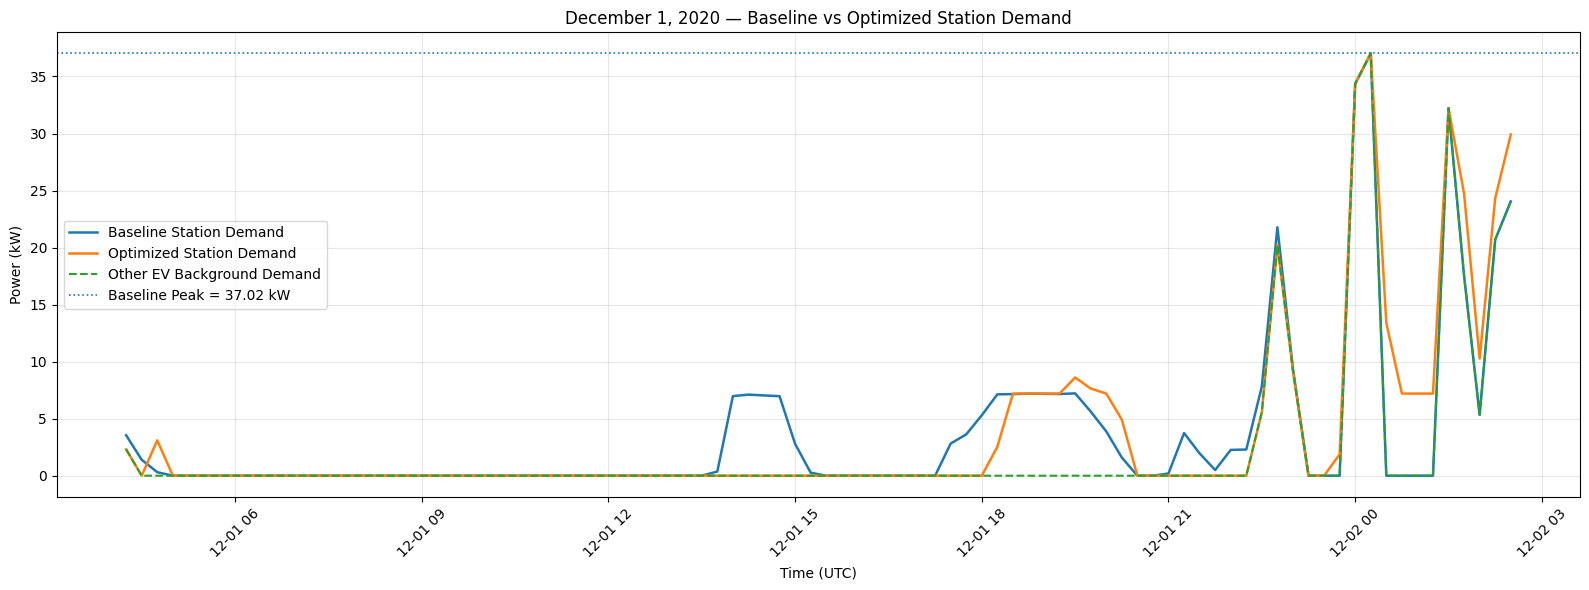

In [192]:

# STAGE 15 — TASK 10: DECEMBER 1 BASELINE VS OPTIMIZED DEMAND

plt.figure(figsize=(16, 6))

plt.plot(
    dec1_slots,
    dec1_station_power,
    label="Baseline Station Demand",
    linewidth=1.8
)

plt.plot(
    dec1_slots,
    dec1_optimized_station_power,
    label="Optimized Station Demand",
    linewidth=1.8
)

plt.plot(
    dec1_slots,
    dec1_other_power,
    label="Other EV Background Demand",
    linestyle="--",
    linewidth=1.5
)

plt.axhline(
    dec1_baseline_peak,
    linestyle=":",
    linewidth=1.2,
    label=f"Baseline Peak = {dec1_baseline_peak:.2f} kW"
)

plt.title(
    "December 1, 2020 — Baseline vs Optimized Station Demand"
)

plt.xlabel("Time (UTC)")
plt.ylabel("Power (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [193]:

# STAGE 15 — TASK 11: INDIVIDUAL DECEMBER 1 EV SCHEDULE

dec1_ev_schedule_rows = []

for i, (_, session) in enumerate(dec1_feasible.iterrows()):

    ev_power = dec1_optimized_energy[i, :] / DT

    active_indices = np.where(ev_power > 1e-6)[0]

    if len(active_indices) > 0:
        first_charging = dec1_slots[active_indices[0]]
        last_charging = dec1_slots[active_indices[-1]]
    else:
        first_charging = pd.NaT
        last_charging = pd.NaT

    dec1_ev_schedule_rows.append({
        "session_id": session["session_id"],
        "arrival_utc": session["arrival_time"],
        "departure_utc": session["departure_time"],
        "required_energy_kwh": required_energy[i],
        "optimized_energy_kwh": dec1_optimized_energy[i].sum(),
        "charging_intervals": len(active_indices),
        "first_charging_utc": first_charging,
        "last_charging_utc": last_charging,
        "maximum_charging_power_kw": ev_power.max()
    })

dec1_ev_schedule_df = pd.DataFrame(dec1_ev_schedule_rows)

print("DECEMBER 1 — INDIVIDUAL EV OPTIMIZED SCHEDULE")
print("---------------------------------------------")

display(dec1_ev_schedule_df.round(4))

print("\nTotal optimized charging energy:",
      round(dec1_optimized_energy.sum(), 4), "kWh")

print("Total required grid energy:",
      round(required_energy.sum(), 4), "kWh")


DECEMBER 1 — INDIVIDUAL EV OPTIMIZED SCHEDULE
---------------------------------------------


,session_id,arrival_utc,departure_utc,required_energy_kwh,optimized_energy_kwh,charging_intervals,first_charging_utc,last_charging_utc,maximum_charging_power_kw
0,2-39-127-19-2020-12-01T04-19-01-008160.csv.gz,2020-12-01 04:19:04+00:00,2020-12-01 04:54:24+00:00,0.7746,0.7746,1,2020-12-01 04:45:00+00:00,2020-12-01 04:45:00+00:00,3.0986
1,2-39-129-17-2020-12-01T18-07-30-772999.csv.gz,2020-12-01 18:07:43+00:00,2020-12-01 20:25:14+00:00,6.5233,6.5233,4,2020-12-01 19:30:00+00:00,2020-12-01 20:15:00+00:00,7.2000
2,2-39-131-30-2020-12-01T13-58-55-468429.csv.gz,2020-12-01 13:59:07+00:00,2020-12-01 19:33:49+00:00,8.2922,8.2922,6,2020-12-01 18:15:00+00:00,2020-12-01 19:30:00+00:00,7.2000
3,2-39-139-28-2020-12-01T17-32-44-966564.csv.gz,2020-12-01 17:32:48+00:00,2020-12-02 02:10:17+00:00,10.7016,10.7016,7,2020-12-01 23:45:00+00:00,2020-12-02 02:00:00+00:00,7.2000
4,2-39-78-365-2020-12-01T21-56-24-945792.csv.gz,2020-12-01 21:56:26+00:00,2020-12-02 02:42:14+00:00,2.3726,2.3726,2,2020-12-02 02:15:00+00:00,2020-12-02 02:30:00+00:00,5.8720
5,2-39-79-380-2020-12-01T21-13-58-259139.csv.gz,2020-12-01 21:14:09+00:00,2020-12-02 01:28:59+00:00,1.5487,1.5487,1,2020-12-02 00:30:00+00:00,2020-12-02 00:30:00+00:00,6.1947
6,2-39-89-25-2020-12-01T19-44-15-857000.csv.gz,2020-12-01 19:44:34+00:00,2020-12-01 19:46:32+00:00,0.1103,0.1103,1,2020-12-01 19:45:00+00:00,2020-12-01 19:45:00+00:00,0.4411



Total optimized charging energy: 30.3233 kWh
Total required grid energy: 30.3233 kWh


In [194]:

# STAGE 15 — TASK 12: THREE CASE STUDY COMPARISON

case_study_results = pd.DataFrame([
    {
        "date": "2020-10-30",
        "selected_evs": 5,
        "other_evs": 5,
        "optimization_intervals": 50,
        "selected_grid_energy_kwh": 28.7040,
        "baseline_peak_kw": 39.9840,
        "optimized_peak_kw": 39.9840,
        "peak_reduction_kw": 0.0000,
        "reduction_percentage": 0.00
    },
    {
        "date": "2020-10-19",
        "selected_evs": 5,
        "other_evs": 5,
        "optimization_intervals": 101,
        "selected_grid_energy_kwh": 40.9384,
        "baseline_peak_kw": 47.0778,
        "optimized_peak_kw": 45.8918,
        "peak_reduction_kw": 1.1860,
        "reduction_percentage": 2.5193
    },
    {
        "date": "2020-12-01",
        "selected_evs": 7,
        "other_evs": 7,
        "optimization_intervals": 90,
        "selected_grid_energy_kwh": 30.3233,
        "baseline_peak_kw": 37.0203,
        "optimized_peak_kw": 37.0203,
        "peak_reduction_kw": 0.0000,
        "reduction_percentage": 0.00
    }
])

display(case_study_results.round(4))

case_study_results.to_csv(
    r"C:\EV_Charging_Project\three_case_study_comparison.csv",
    index=False
)

print("Three-case-study comparison saved successfully.")


,date,selected_evs,other_evs,optimization_intervals,selected_grid_energy_kwh,baseline_peak_kw,optimized_peak_kw,peak_reduction_kw,reduction_percentage
0,2020-10-30,5,5,50,28.7040,39.9840,39.9840,0.000,0.0000
1,2020-10-19,5,5,101,40.9384,47.0778,45.8918,1.186,2.5193
2,2020-12-01,7,7,90,30.3233,37.0203,37.0203,0.000,0.0000


Three-case-study comparison saved successfully.


In [195]:

# STAGE 16 — TASK 1: RANK DAYS FOR MULTI-DAY OPTIMIZATION

validation_sessions = test_sessions.copy()

validation_sessions["arrival_time"] = pd.to_datetime(
    validation_sessions["arrival_time"], utc=True
)

validation_sessions["departure_time"] = pd.to_datetime(
    validation_sessions["departure_time"], utc=True
)

validation_sessions["arrival_date"] = (
    validation_sessions["arrival_time"].dt.date
)

validation_sessions["duration_hours"] = (
    validation_sessions["departure_time"]
    - validation_sessions["arrival_time"]
).dt.total_seconds() / 3600

validation_sessions["required_grid_energy_kwh"] = (
    validation_sessions["clean_energy_kwh"] / 0.95
)

validation_sessions["feasible_7.2kw"] = (
    (validation_sessions["duration_hours"] > 0) &
    (validation_sessions["duration_hours"] <= 24) &
    (
        validation_sessions["required_grid_energy_kwh"]
        <= MAX_CHARGING_POWER_KW *
        validation_sessions["duration_hours"] + 1e-9
    )
)

validation_daily = (
    validation_sessions
    .groupby("arrival_date")
    .agg(
        total_sessions=("session_id", "count"),
        total_energy_kwh=("clean_energy_kwh", "sum"),
        feasible_evs=("feasible_7.2kw", "sum"),
        feasible_energy_kwh=(
            "clean_energy_kwh",
            lambda x: x[
                validation_sessions.loc[x.index, "feasible_7.2kw"]
            ].sum()
        )
    )
    .reset_index()
)

# Retain dates with at least 5 feasible EVs
validation_candidates = validation_daily[
    validation_daily["feasible_evs"] >= 5
].copy()

validation_candidates = validation_candidates.sort_values(
    ["feasible_evs", "feasible_energy_kwh"],
    ascending=False
).reset_index(drop=True)

print("MULTI-DAY VALIDATION CANDIDATES")
print("--------------------------------")

print("Total candidate dates:",
      len(validation_candidates))

display(validation_candidates.head(15).round(3))


MULTI-DAY VALIDATION CANDIDATES
--------------------------------
Total candidate dates: 19


,arrival_date,total_sessions,total_energy_kwh,feasible_evs,feasible_energy_kwh
0,2020-09-07,11,11.426,11,11.426
1,2020-12-01,10,64.959,7,28.807
2,2020-09-20,7,136.232,6,90.661
3,2020-11-20,7,40.559,6,29.453
4,2020-11-24,7,39.318,6,28.512
5,2020-08-03,5,59.336,5,59.336
6,2020-09-03,5,40.226,5,40.226
7,2020-10-19,9,111.063,5,38.891
8,2020-11-23,6,58.447,5,30.633
9,2020-10-30,12,133.412,5,27.269


In [196]:

# STAGE 16 — TASK 2: SELECT SEPTEMBER 20 FEASIBLE EVs

sep20_date = pd.Timestamp("2020-09-20").date()

sep20_sessions = validation_sessions[
    validation_sessions["arrival_date"] == sep20_date
].copy()

sep20_feasible = sep20_sessions[
    sep20_sessions["feasible_7.2kw"]
].copy()

sep20_infeasible = sep20_sessions[
    ~sep20_sessions["feasible_7.2kw"]
].copy()

print("SEPTEMBER 20, 2020 — SESSION SELECTION")
print("--------------------------------------")

print("Total sessions:", len(sep20_sessions))
print("Feasible sessions:", len(sep20_feasible))
print("Infeasible sessions:", len(sep20_infeasible))

print("\nSelected EV battery energy:",
      round(sep20_feasible["clean_energy_kwh"].sum(), 4), "kWh")

print("Required grid energy:",
      round(sep20_feasible["required_grid_energy_kwh"].sum(), 4), "kWh")

print("\nSELECTED FEASIBLE EVs")

display(
    sep20_feasible[
        [
            "session_id",
            "arrival_time",
            "departure_time",
            "duration_hours",
            "clean_energy_kwh",
            "required_grid_energy_kwh"
        ]
    ].sort_values("arrival_time").reset_index(drop=True).round(4)
)


SEPTEMBER 20, 2020 — SESSION SELECTION
--------------------------------------
Total sessions: 7
Feasible sessions: 6
Infeasible sessions: 1

Selected EV battery energy: 90.6609 kWh
Required grid energy: 95.4326 kWh

SELECTED FEASIBLE EVs


,session_id,arrival_time,departure_time,duration_hours,clean_energy_kwh,required_grid_energy_kwh
0,2-39-125-21-2020-09-20T00-06-33-727102.csv.gz,2020-09-20 00:06:34+00:00,2020-09-20 00:50:46+00:00,0.7367,1.8687,1.9671
1,2-39-79-378-2020-09-20T03-19-12-739563.csv.gz,2020-09-20 03:19:34+00:00,2020-09-20 03:22:03+00:00,0.0414,0.2559,0.2694
2,2-39-79-378-2020-09-20T03-22-12-038079.csv.gz,2020-09-20 03:22:15+00:00,2020-09-20 13:23:36+00:00,10.0225,27.3430,28.7821
3,2-39-83-386-2020-09-20T03-54-26-651369.csv.gz,2020-09-20 03:54:30+00:00,2020-09-20 05:31:38+00:00,1.6189,0.8963,0.9435
4,2-39-129-17-2020-09-20T04-16-47-761005.csv.gz,2020-09-20 04:16:51+00:00,2020-09-20 17:57:07+00:00,13.6711,57.9418,60.9914
5,2-39-78-365-2020-09-20T21-04-30-681721.csv.gz,2020-09-20 21:04:34+00:00,2020-09-21 02:33:10+00:00,5.4767,2.3552,2.4792


In [197]:

# STAGE 16 — TASK 3: CREATE SEPTEMBER 20 OPTIMIZATION WINDOW

sep20_start = sep20_feasible["arrival_time"].min().floor("15min")

sep20_end = sep20_feasible["departure_time"].max().ceil("15min")

sep20_slots = pd.date_range(
    start=sep20_start,
    end=sep20_end,
    freq="15min",
    inclusive="left"
)

print("SEPTEMBER 20 OPTIMIZATION WINDOW")
print("--------------------------------")

print("Start (UTC):", sep20_start)
print("End (UTC):", sep20_end)

print("Total 15-minute intervals:", len(sep20_slots))

print("\nFirst five intervals:")
print(sep20_slots[:5])

print("\nLast five intervals:")
print(sep20_slots[-5:])


SEPTEMBER 20 OPTIMIZATION WINDOW
--------------------------------
Start (UTC): 2020-09-20 00:00:00+00:00
End (UTC): 2020-09-21 02:45:00+00:00
Total 15-minute intervals: 107

First five intervals:
DatetimeIndex(['2020-09-20 00:00:00+00:00', '2020-09-20 00:15:00+00:00',
               '2020-09-20 00:30:00+00:00', '2020-09-20 00:45:00+00:00',
               '2020-09-20 01:00:00+00:00'],
              dtype='datetime64[ns, UTC]', freq='15min')

Last five intervals:
DatetimeIndex(['2020-09-21 01:30:00+00:00', '2020-09-21 01:45:00+00:00',
               '2020-09-21 02:00:00+00:00', '2020-09-21 02:15:00+00:00',
               '2020-09-21 02:30:00+00:00'],
              dtype='datetime64[ns, UTC]', freq='15min')


In [198]:

# STAGE 16 — TASK 4: IDENTIFY SEPTEMBER 20 OVERLAPPING SESSIONS

sep20_all_sessions = clean_sessions.copy()

sep20_all_sessions["arrival_time"] = pd.to_datetime(
    sep20_all_sessions["arrival_time"], utc=True
)

sep20_all_sessions["departure_time"] = pd.to_datetime(
    sep20_all_sessions["departure_time"], utc=True
)

sep20_overlapping = sep20_all_sessions[
    (sep20_all_sessions["arrival_time"] < sep20_end) &
    (sep20_all_sessions["departure_time"] > sep20_start)
].copy()

sep20_selected_ids = set(sep20_feasible["session_id"])

sep20_overlapping["session_group"] = np.where(
    sep20_overlapping["session_id"].isin(sep20_selected_ids),
    "Selected EV",
    "Other EV"
)

sep20_other_sessions = sep20_overlapping[
    sep20_overlapping["session_group"] == "Other EV"
].copy()

print("SEPTEMBER 20 OVERLAPPING SESSION AUDIT")
print("--------------------------------------")

print("Total overlapping sessions:", len(sep20_overlapping))
print("Selected EVs:",
      (sep20_overlapping["session_group"] == "Selected EV").sum())
print("Other EVs:", len(sep20_other_sessions))

print("\nSelected EV clean energy:",
      round(sep20_feasible["clean_energy_kwh"].sum(), 4), "kWh")

print("Other EV complete-session energy:",
      round(sep20_other_sessions["clean_energy_kwh"].sum(), 4), "kWh")

display(
    sep20_overlapping[
        [
            "session_id",
            "arrival_time",
            "departure_time",
            "clean_energy_kwh",
            "session_group"
        ]
    ].sort_values("arrival_time").reset_index(drop=True)
)


SEPTEMBER 20 OVERLAPPING SESSION AUDIT
--------------------------------------
Total overlapping sessions: 8
Selected EVs: 6
Other EVs: 2

Selected EV clean energy: 90.6609 kWh
Other EV complete-session energy: 51.3084 kWh


,session_id,arrival_time,departure_time,clean_energy_kwh,session_group
0,2-39-78-362-2020-09-19T23-22-20-825650.csv.gz,2020-09-19 23:22:42+00:00,2020-09-20 00:34:19+00:00,5.737424,Other EV
1,2-39-125-21-2020-09-20T00-06-33-727102.csv.gz,2020-09-20 00:06:34+00:00,2020-09-20 00:50:46+00:00,1.868746,Selected EV
2,2-39-79-378-2020-09-20T03-19-12-739563.csv.gz,2020-09-20 03:19:34+00:00,2020-09-20 03:22:03+00:00,0.255899,Selected EV
3,2-39-79-378-2020-09-20T03-22-12-038079.csv.gz,2020-09-20 03:22:15+00:00,2020-09-20 13:23:36+00:00,27.342991,Selected EV
4,2-39-92-442-2020-09-20T03-27-54-406735.csv.gz,2020-09-20 03:27:54+00:00,2020-09-21 03:39:27+00:00,45.571013,Other EV
5,2-39-83-386-2020-09-20T03-54-26-651369.csv.gz,2020-09-20 03:54:30+00:00,2020-09-20 05:31:38+00:00,0.896282,Selected EV
6,2-39-129-17-2020-09-20T04-16-47-761005.csv.gz,2020-09-20 04:16:51+00:00,2020-09-20 17:57:07+00:00,57.941811,Selected EV
7,2-39-78-365-2020-09-20T21-04-30-681721.csv.gz,2020-09-20 21:04:34+00:00,2020-09-21 02:33:10+00:00,2.355215,Selected EV


In [199]:

# STAGE 16 — TASK 5: RECONSTRUCT OTHER SEPTEMBER 20 EV LOAD

sep20_other_energy = np.zeros(len(sep20_slots))
sep20_other_session_results = []

for _, session in sep20_other_sessions.iterrows():

    file_path = os.path.join(
        caltech_path,
        session["session_id"]
    )

    raw = pd.read_csv(file_path, compression="gzip")

    timestamps = pd.to_datetime(
        raw["Unnamed: 0"],
        utc=True,
        errors="coerce"
    )

    energy_counter = pd.to_numeric(
        raw["Energy Delivered (kWh)"],
        errors="coerce"
    )

    valid = timestamps.notna() & energy_counter.notna()

    timestamps = timestamps[valid].reset_index(drop=True)
    energy_counter = energy_counter[valid].reset_index(drop=True)

    increments = energy_counter.diff().fillna(0).to_numpy()
    increments = np.maximum(increments, 0)

    session_allocated = np.zeros(len(sep20_slots))

    for k in range(1, len(timestamps)):

        energy = increments[k]

        if energy <= 0:
            continue

        t0 = timestamps.iloc[k - 1]
        t1 = timestamps.iloc[k]

        duration_seconds = (t1 - t0).total_seconds()

        if duration_seconds <= 0:
            continue

        for j, slot_start in enumerate(sep20_slots):

            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(t0, slot_start)
            overlap_end = min(t1, slot_end)

            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap_seconds > 0:

                session_allocated[j] += (
                    energy * overlap_seconds / duration_seconds
                )

    sep20_other_energy += session_allocated

    sep20_other_session_results.append({
        "session_id": session["session_id"],
        "complete_session_energy_kwh": session["clean_energy_kwh"],
        "energy_inside_window_kwh": session_allocated.sum()
    })

sep20_other_reconstruction_df = pd.DataFrame(
    sep20_other_session_results
)

sep20_other_power = sep20_other_energy / DT

print("SEPTEMBER 20 OTHER-EV RECONSTRUCTION")
print("------------------------------------")

display(sep20_other_reconstruction_df.round(4))

print("\nTotal other-EV energy inside window:",
      round(sep20_other_energy.sum(), 4), "kWh")

print("Peak other-EV demand:",
      round(sep20_other_power.max(), 4), "kW")

print("Active intervals:",
      np.sum(sep20_other_energy > 0))

print("Total intervals:", len(sep20_slots))


SEPTEMBER 20 OTHER-EV RECONSTRUCTION
------------------------------------


,session_id,complete_session_energy_kwh,energy_inside_window_kwh
0,2-39-78-362-2020-09-19T23-22-20-825650.csv.gz,5.7374,2.8963
1,2-39-92-442-2020-09-20T03-27-54-406735.csv.gz,45.5710,45.5710



Total other-EV energy inside window: 48.4673 kWh
Peak other-EV demand: 7.0035 kW
Active intervals: 33
Total intervals: 107


In [200]:

# STAGE 16 — TASK 6: RECONSTRUCT SELECTED SEPTEMBER 20 EV LOAD

sep20_selected_energy = np.zeros(len(sep20_slots))
sep20_selected_session_results = []

for _, session in sep20_feasible.iterrows():

    file_path = os.path.join(
        caltech_path,
        session["session_id"]
    )

    raw = pd.read_csv(file_path, compression="gzip")

    timestamps = pd.to_datetime(
        raw["Unnamed: 0"],
        utc=True,
        errors="coerce"
    )

    energy_counter = pd.to_numeric(
        raw["Energy Delivered (kWh)"],
        errors="coerce"
    )

    valid = timestamps.notna() & energy_counter.notna()

    timestamps = timestamps[valid].reset_index(drop=True)
    energy_counter = energy_counter[valid].reset_index(drop=True)

    increments = energy_counter.diff().fillna(0).to_numpy()
    increments = np.maximum(increments, 0)

    session_allocated = np.zeros(len(sep20_slots))

    for k in range(1, len(timestamps)):

        energy = increments[k]

        if energy <= 0:
            continue

        t0 = timestamps.iloc[k - 1]
        t1 = timestamps.iloc[k]

        duration_seconds = (t1 - t0).total_seconds()

        if duration_seconds <= 0:
            continue

        for j, slot_start in enumerate(sep20_slots):

            slot_end = slot_start + pd.Timedelta(minutes=15)

            overlap_start = max(t0, slot_start)
            overlap_end = min(t1, slot_end)

            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()

            if overlap_seconds > 0:

                session_allocated[j] += (
                    energy * overlap_seconds / duration_seconds
                )

    sep20_selected_energy += session_allocated

    sep20_selected_session_results.append({
        "session_id": session["session_id"],
        "clean_energy_kwh": session["clean_energy_kwh"],
        "reconstructed_energy_kwh": session_allocated.sum()
    })

sep20_selected_reconstruction_df = pd.DataFrame(
    sep20_selected_session_results
)

sep20_selected_power = sep20_selected_energy / DT

print("SEPTEMBER 20 SELECTED-EV RECONSTRUCTION")
print("---------------------------------------")

display(sep20_selected_reconstruction_df.round(4))

print("\nSelected-EV reconstructed energy:",
      round(sep20_selected_energy.sum(), 4), "kWh")

print("Expected selected clean energy:",
      round(sep20_feasible["clean_energy_kwh"].sum(), 4), "kWh")

print("Peak selected-EV demand:",
      round(sep20_selected_power.max(), 4), "kW")

print("Active intervals:",
      np.sum(sep20_selected_energy > 0))


SEPTEMBER 20 SELECTED-EV RECONSTRUCTION
---------------------------------------


,session_id,clean_energy_kwh,reconstructed_energy_kwh
0,2-39-125-21-2020-09-20T00-06-33-727102.csv.gz,1.8687,1.8687
1,2-39-129-17-2020-09-20T04-16-47-761005.csv.gz,57.9418,57.9418
2,2-39-78-365-2020-09-20T21-04-30-681721.csv.gz,2.3552,2.3552
3,2-39-79-378-2020-09-20T03-19-12-739563.csv.gz,0.2559,0.2559
4,2-39-79-378-2020-09-20T03-22-12-038079.csv.gz,27.3430,27.3430
5,2-39-83-386-2020-09-20T03-54-26-651369.csv.gz,0.8963,0.8963



Selected-EV reconstructed energy: 90.6609 kWh
Expected selected clean energy: 90.6609 kWh
Peak selected-EV demand: 14.0227 kW
Active intervals: 48


In [201]:

# STAGE 16 — TASK 7: SEPTEMBER 20 STATION LOAD RECONCILIATION

# Retrieve station profile
sep20_station = station_profile_complete.copy()

sep20_station["timestamp"] = pd.to_datetime(
    sep20_station["timestamp"],
    utc=True
)

sep20_station = sep20_station.set_index("timestamp")

sep20_station_energy = (
    sep20_station["energy_kwh"]
    .reindex(sep20_slots)
    .fillna(0)
    .to_numpy()
)

sep20_station_power = sep20_station_energy / DT

# Reconstructed total EV demand
sep20_reconstructed_energy = (
    sep20_selected_energy + sep20_other_energy
)

sep20_reconstructed_power = (
    sep20_reconstructed_energy / DT
)

# Reconciliation residual
sep20_residual_energy = (
    sep20_station_energy - sep20_reconstructed_energy
)

sep20_residual_power = (
    sep20_residual_energy / DT
)

# Summary metrics
sep20_reconciliation = pd.DataFrame({
    "Metric": [
        "Station energy",
        "Selected EV energy",
        "Other EV energy",
        "Reconstructed total energy",
        "Energy reconciliation difference",
        "Station peak demand",
        "Selected EV peak demand",
        "Other EV peak demand",
        "Maximum absolute residual power"
    ],
    "Value": [
        sep20_station_energy.sum(),
        sep20_selected_energy.sum(),
        sep20_other_energy.sum(),
        sep20_reconstructed_energy.sum(),
        sep20_residual_energy.sum(),
        sep20_station_power.max(),
        sep20_selected_power.max(),
        sep20_other_power.max(),
        np.abs(sep20_residual_power).max()
    ],
    "Unit": [
        "kWh", "kWh", "kWh", "kWh", "kWh",
        "kW", "kW", "kW", "kW"
    ]
})

display(sep20_reconciliation.round(4))

# Identify station peak interval
sep20_peak_index = np.argmax(sep20_station_power)

print("\nSTATION PEAK INTERVAL")
print("---------------------")
print("Timestamp (UTC):", sep20_slots[sep20_peak_index])
print("Station demand:", round(sep20_station_power[sep20_peak_index], 4), "kW")
print("Selected EV demand:", round(sep20_selected_power[sep20_peak_index], 4), "kW")
print("Other EV demand:", round(sep20_other_power[sep20_peak_index], 4), "kW")

print("\nRECONCILIATION CHECK")
print("--------------------")
print(
    "Energy reconciliation:",
    "PASS" if abs(sep20_residual_energy.sum()) < 0.01 else "REVIEW"
)
print(
    "Maximum interval residual:",
    round(np.abs(sep20_residual_power).max(), 6),
    "kW"
)


,Metric,Value,Unit
0,Station energy,139.1282,kWh
1,Selected EV energy,90.6609,kWh
2,Other EV energy,48.4673,kWh
3,Reconstructed total energy,139.1282,kWh
4,Energy reconciliation difference,-0.0000,kWh
5,Station peak demand,20.9446,kW
6,Selected EV peak demand,14.0227,kW
7,Other EV peak demand,7.0035,kW
8,Maximum absolute residual power,0.0000,kW



STATION PEAK INTERVAL
---------------------
Timestamp (UTC): 2020-09-20 06:45:00+00:00
Station demand: 20.9446 kW
Selected EV demand: 14.0227 kW
Other EV demand: 6.9219 kW

RECONCILIATION CHECK
--------------------
Energy reconciliation: PASS
Maximum interval residual: 0.0 kW


In [202]:

# STAGE 16 — TASK 8: SEPTEMBER 20 OPTIMAL CHARGING

from scipy.optimize import linprog

n_ev = len(sep20_feasible)
n_slots = len(sep20_slots)

# Required grid energy for each selected EV
required_energy = sep20_feasible[
    "required_grid_energy_kwh"
].to_numpy(dtype=float)

# Calculate EV availability in each 15-minute interval
overlap_hours = np.zeros((n_ev, n_slots))

for i, (_, session) in enumerate(sep20_feasible.iterrows()):

    arrival = pd.to_datetime(session["arrival_time"], utc=True)
    departure = pd.to_datetime(session["departure_time"], utc=True)

    for j, slot_start in enumerate(sep20_slots):

        slot_end = slot_start + pd.Timedelta(minutes=15)

        overlap_start = max(arrival, slot_start)
        overlap_end = min(departure, slot_end)

        overlap_hours[i, j] = max(
            0,
            (overlap_end - overlap_start).total_seconds() / 3600
        )

# Maximum energy each EV can receive in each interval
max_energy = 7.2 * overlap_hours

# Decision variables:
# x[i,j] = grid energy assigned to EV i in interval j
# P = maximum station demand

n_variables = n_ev * n_slots + 1
P_index = n_variables - 1

# Objective: minimize P
objective = np.zeros(n_variables)
objective[P_index] = 1

# Equality constraints: each EV receives its required energy
A_eq = np.zeros((n_ev, n_variables))
b_eq = required_energy.copy()

for i in range(n_ev):
    for j in range(n_slots):
        A_eq[i, i * n_slots + j] = 1

# Inequality constraints:
# Other EV power + selected EV power <= P
A_ub = np.zeros((n_slots, n_variables))
b_ub = -sep20_other_power.copy()

for j in range(n_slots):
    for i in range(n_ev):
        A_ub[j, i * n_slots + j] = 1 / DT

    A_ub[j, P_index] = -1

# Variable bounds
bounds = []

for i in range(n_ev):
    for j in range(n_slots):
        bounds.append((0, max_energy[i, j]))

bounds.append((0, None))

# Solve LP
sep20_solution = linprog(
    c=objective,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("SEPTEMBER 20 OPTIMIZATION")
print("-------------------------")
print("Solver success:", sep20_solution.success)
print("Solver message:", sep20_solution.message)

if sep20_solution.success:

    sep20_x = sep20_solution.x[:-1].reshape(n_ev, n_slots)

    sep20_optimized_ev_power = sep20_x.sum(axis=0) / DT

    sep20_optimized_station_power = (
        sep20_other_power + sep20_optimized_ev_power
    )

    sep20_baseline_peak = sep20_station_power.max()
    sep20_optimized_peak = sep20_optimized_station_power.max()

    sep20_peak_reduction = (
        sep20_baseline_peak - sep20_optimized_peak
    )

    sep20_reduction_percentage = (
        sep20_peak_reduction / sep20_baseline_peak * 100
    )

    # Constraint validation
    sep20_delivered_energy = sep20_x.sum(axis=1)

    sep20_energy_error = np.max(
        np.abs(sep20_delivered_energy - required_energy)
    )

    sep20_max_ev_power = (
        sep20_x / DT
    )

    sep20_power_violation = np.max(
        sep20_max_ev_power - 7.2 * overlap_hours / DT
    )

    sep20_unavailable_energy = np.max(
        np.where(overlap_hours == 0, sep20_x, 0)
    )

    print("\nOPTIMIZATION RESULTS")
    print("--------------------")
    print("Baseline peak:", round(sep20_baseline_peak, 4), "kW")
    print("Optimized peak:", round(sep20_optimized_peak, 4), "kW")
    print("Peak reduction:", round(sep20_peak_reduction, 4), "kW")
    print("Reduction percentage:", round(sep20_reduction_percentage, 4), "%")

    print("\nCONSTRAINT VALIDATION")
    print("---------------------")
    print("Maximum energy error:", round(sep20_energy_error, 8), "kWh")
    print("Maximum power violation:", round(sep20_power_violation, 8), "kW")
    print("Unavailable-slot energy:", round(sep20_unavailable_energy, 8), "kWh")


SEPTEMBER 20 OPTIMIZATION
-------------------------
Solver success: True
Solver message: Optimization terminated successfully. (HiGHS Status 7: Optimal)

OPTIMIZATION RESULTS
--------------------
Baseline peak: 20.9446 kW
Optimized peak: 10.3166 kW
Peak reduction: 10.6281 kW
Reduction percentage: 50.7436 %

CONSTRAINT VALIDATION
---------------------
Maximum energy error: 0.0 kWh
Maximum power violation: 0.0 kW
Unavailable-slot energy: 0.0 kWh


In [203]:

# STAGE 16 — TASK 9: SEPTEMBER 20 INDIVIDUAL EV SCHEDULE

sep20_ev_schedule = []

for i, (_, session) in enumerate(sep20_feasible.iterrows()):

    charging_power = sep20_x[i, :] / DT

    active_indices = np.where(sep20_x[i, :] > 1e-7)[0]

    if len(active_indices) > 0:

        first_slot = active_indices[0]
        last_slot = active_indices[-1]

        sep20_ev_schedule.append({
            "EV": f"EV {i+1}",
            "session_id": session["session_id"],
            "required_grid_energy_kwh": required_energy[i],
            "delivered_energy_kwh": sep20_x[i, :].sum(),
            "active_intervals": len(active_indices),
            "first_charging_time_UTC": sep20_slots[first_slot],
            "last_charging_time_UTC": (
                sep20_slots[last_slot] + pd.Timedelta(minutes=15)
            ),
            "maximum_charging_power_kw": charging_power.max()
        })

sep20_ev_schedule_df = pd.DataFrame(sep20_ev_schedule)

print("SEPTEMBER 20 INDIVIDUAL EV CHARGING SCHEDULE")
print("--------------------------------------------")

display(sep20_ev_schedule_df.round(4))


SEPTEMBER 20 INDIVIDUAL EV CHARGING SCHEDULE
--------------------------------------------


,EV,session_id,required_grid_energy_kwh,delivered_energy_kwh,active_intervals,first_charging_time_UTC,last_charging_time_UTC,maximum_charging_power_kw
0,EV 1,2-39-125-21-2020-09-20T00-06-33-727102.csv.gz,1.9671,1.9671,2,2020-09-20 00:30:00+00:00,2020-09-20 01:00:00+00:00,7.2000
1,EV 2,2-39-129-17-2020-09-20T04-16-47-761005.csv.gz,60.9914,60.9914,47,2020-09-20 04:15:00+00:00,2020-09-20 18:00:00+00:00,7.2000
2,EV 3,2-39-78-365-2020-09-20T21-04-30-681721.csv.gz,2.4792,2.4792,2,2020-09-20 22:00:00+00:00,2020-09-21 00:15:00+00:00,7.2000
3,EV 4,2-39-79-378-2020-09-20T03-19-12-739563.csv.gz,0.2694,0.2694,1,2020-09-20 03:15:00+00:00,2020-09-20 03:30:00+00:00,1.0775
4,EV 5,2-39-79-378-2020-09-20T03-22-12-038079.csv.gz,28.7821,28.7821,27,2020-09-20 03:15:00+00:00,2020-09-20 13:30:00+00:00,7.2000
5,EV 6,2-39-83-386-2020-09-20T03-54-26-651369.csv.gz,0.9435,0.9435,2,2020-09-20 03:45:00+00:00,2020-09-20 04:15:00+00:00,2.6400


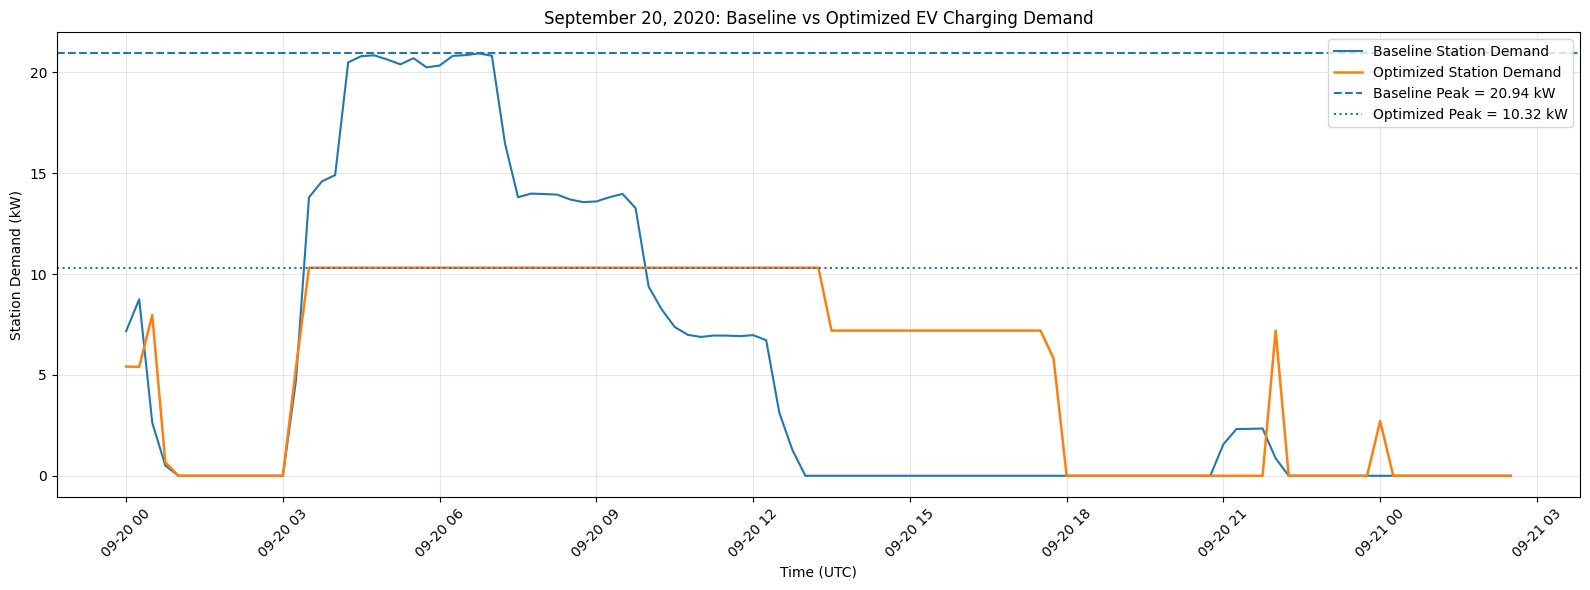

BASELINE PEAK: 20.9446 kW
OPTIMIZED PEAK: 10.3166 kW
PEAK REDUCTION: 10.6281 kW
REDUCTION PERCENTAGE: 50.7436 %


In [204]:

# STAGE 16 — TASK 10: BASELINE VS OPTIMIZED STATION LOAD

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    sep20_slots,
    sep20_station_power,
    label="Baseline Station Demand",
    linewidth=1.5
)

plt.plot(
    sep20_slots,
    sep20_optimized_station_power,
    label="Optimized Station Demand",
    linewidth=1.8
)

plt.axhline(
    sep20_baseline_peak,
    linestyle="--",
    label=f"Baseline Peak = {sep20_baseline_peak:.2f} kW"
)

plt.axhline(
    sep20_optimized_peak,
    linestyle=":",
    label=f"Optimized Peak = {sep20_optimized_peak:.2f} kW"
)

plt.xlabel("Time (UTC)")
plt.ylabel("Station Demand (kW)")
plt.title("September 20, 2020: Baseline vs Optimized EV Charging Demand")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("BASELINE PEAK:", round(sep20_baseline_peak, 4), "kW")
print("OPTIMIZED PEAK:", round(sep20_optimized_peak, 4), "kW")
print("PEAK REDUCTION:", round(sep20_peak_reduction, 4), "kW")
print("REDUCTION PERCENTAGE:", round(sep20_reduction_percentage, 4), "%")


In [205]:

# STAGE 16 — TASK 11: UPDATE MULTI-DAY CASE STUDY COMPARISON

sep20_result = pd.DataFrame([{
    "date": "2020-09-20",
    "selected_evs": len(sep20_feasible),
    "other_evs": len(sep20_other_sessions),
    "optimization_intervals": len(sep20_slots),
    "selected_grid_energy_kwh": required_energy.sum(),
    "baseline_peak_kw": sep20_baseline_peak,
    "optimized_peak_kw": sep20_optimized_peak,
    "peak_reduction_kw": sep20_peak_reduction,
    "reduction_percentage": sep20_reduction_percentage
}])

case_study_results = pd.concat(
    [case_study_results, sep20_result],
    ignore_index=True
)

case_study_results = case_study_results.drop_duplicates(
    subset=["date"],
    keep="last"
).sort_values("date").reset_index(drop=True)

# Save updated results
case_study_results.to_csv(
    r"C:\EV_Charging_Project\three_case_study_comparison.csv",
    index=False
)

print("UPDATED MULTI-DAY CASE STUDY COMPARISON")
print("---------------------------------------")

display(case_study_results.round(4))


UPDATED MULTI-DAY CASE STUDY COMPARISON
---------------------------------------


,date,selected_evs,other_evs,optimization_intervals,selected_grid_energy_kwh,baseline_peak_kw,optimized_peak_kw,peak_reduction_kw,reduction_percentage
0,2020-09-20,6,2,107,95.4326,20.9446,10.3166,10.6281,50.7436
1,2020-10-19,5,5,101,40.9384,47.0778,45.8918,1.1860,2.5193
2,2020-10-30,5,5,50,28.7040,39.9840,39.9840,0.0000,0.0000
3,2020-12-01,7,7,90,30.3233,37.0203,37.0203,0.0000,0.0000


In [206]:

# STAGE 17 — TASK 1: ENERGY BOUNDARY INVESTIGATION

print("1. CLEAN SESSION DATA COLUMNS")
print("------------------------------")
print(clean_sessions.columns.tolist())

print("\n2. SELECTED SESSION ENERGY VALUES")
print("---------------------------------")

display(
    sep20_feasible[
        [
            "session_id",
            "clean_energy_kwh",
            "power_energy_kwh",
            "required_grid_energy_kwh"
        ]
    ].round(5)
)

print("\n3. RAW SESSION COUNTER INSPECTION")
print("---------------------------------")

sample_session_id = sep20_feasible.iloc[0]["session_id"]

sample_file_path = os.path.join(
    caltech_path,
    sample_session_id
)

sample_raw = pd.read_csv(
    sample_file_path,
    compression="gzip"
)

print("Sample session:", sample_session_id)
print("Raw columns:", sample_raw.columns.tolist())

display(sample_raw.head(5))

print("\nLast five raw readings:")
display(sample_raw.tail(5))


1. CLEAN SESSION DATA COLUMNS
------------------------------
['session_id', 'clean_energy_kwh', 'power_energy_kwh', 'coverage_pct', 'relative_difference_pct', 'decision', 'arrival_time', 'departure_time']

2. SELECTED SESSION ENERGY VALUES
---------------------------------


,session_id,clean_energy_kwh,power_energy_kwh,required_grid_energy_kwh
2911,2-39-125-21-2020-09-20T00-06-33-727102.csv.gz,1.86875,1.87366,1.96710
6493,2-39-129-17-2020-09-20T04-16-47-761005.csv.gz,57.94181,58.30851,60.99138
14935,2-39-78-365-2020-09-20T21-04-30-681721.csv.gz,2.35522,2.35923,2.47917
18198,2-39-79-378-2020-09-20T03-19-12-739563.csv.gz,0.25590,0.26218,0.26937
18199,2-39-79-378-2020-09-20T03-22-12-038079.csv.gz,27.34299,27.51990,28.78210
21753,2-39-83-386-2020-09-20T03-54-26-651369.csv.gz,0.89628,0.89771,0.94345



3. RAW SESSION COUNTER INSPECTION
---------------------------------
Sample session: 2-39-125-21-2020-09-20T00-06-33-727102.csv.gz
Raw columns: ['Unnamed: 0', 'Charging Current (A)', 'Actual Pilot (A)', 'Voltage (V)', 'Charging State', 'Energy Delivered (kWh)', 'Power (kW)']


,Unnamed: 0,Charging Current (A),Actual Pilot (A),Voltage (V),Charging State,Energy Delivered (kWh),Power (kW)
0,2020-09-20T00:06:34+00:00,0.4,8.0,223.6,READY,0.000047,0.006
1,2020-09-20T00:06:38+00:00,1.9,8.0,224.3,ADAPTIVE,0.000213,0.393
2,2020-09-20T00:06:42+00:00,6.0,8.0,223.5,ADAPTIVE,0.001256,1.333
3,2020-09-20T00:06:46+00:00,8.6,8.0,223.4,ADAPTIVE,0.003146,1.922
4,2020-09-20T00:06:50+00:00,8.6,8.0,223.0,ADAPTIVE,0.005259,1.917



Last five raw readings:


,Unnamed: 0,Charging Current (A),Actual Pilot (A),Voltage (V),Charging State,Energy Delivered (kWh),Power (kW)
669,2020-09-20T00:50:31+00:00,6.2,15.0,222.6,ADAPTIVE,1.864309,1.364
670,2020-09-20T00:50:35+00:00,6.2,15.0,223.2,ADAPTIVE,1.865802,1.369
671,2020-09-20T00:50:39+00:00,6.2,15.0,223.2,ADAPTIVE,1.867301,1.371
672,2020-09-20T00:50:42+00:00,6.2,15.0,223.0,ADAPTIVE,1.868793,1.369
673,2020-09-20T00:50:46+00:00,0.0,0.0,NaN,UNPLUGGED,0.000000,0.000


In [207]:

# STAGE 17 — TASK 2: QUANTIFY THE 95% EFFICIENCY CORRECTION

efficiency = 0.95

energy_comparison = pd.DataFrame([
    {
        "date": "2020-09-20",
        "selected_evs": len(sep20_feasible),
        "counter_energy_kwh": sep20_feasible["clean_energy_kwh"].sum(),
        "current_grid_energy_kwh": sep20_feasible["required_grid_energy_kwh"].sum()
    },
    {
        "date": "2020-10-19",
        "selected_evs": len(oct19_feasible),
        "counter_energy_kwh": oct19_feasible["clean_energy_kwh"].sum(),
        "current_grid_energy_kwh": oct19_feasible["required_grid_energy_kwh"].sum()
    },
    {
        "date": "2020-10-30",
        "selected_evs": len(oct30_feasible),
        "counter_energy_kwh": oct30_feasible["clean_energy_kwh"].sum(),
        "current_grid_energy_kwh": oct30_feasible["required_grid_energy_kwh"].sum()
    },
    {
        "date": "2020-12-01",
        "selected_evs": len(dec1_feasible),
        "counter_energy_kwh": dec1_feasible["clean_energy_kwh"].sum(),
        "current_grid_energy_kwh": dec1_feasible["required_grid_energy_kwh"].sum()
    }
])

energy_comparison["efficiency_adjustment_kwh"] = (
    energy_comparison["current_grid_energy_kwh"]
    - energy_comparison["counter_energy_kwh"]
)

energy_comparison["increase_percentage"] = (
    energy_comparison["efficiency_adjustment_kwh"]
    / energy_comparison["counter_energy_kwh"] * 100
)

print("ENERGY CONVENTION COMPARISON")
print("----------------------------")

display(energy_comparison.round(4))


ENERGY CONVENTION COMPARISON
----------------------------


,date,selected_evs,counter_energy_kwh,current_grid_energy_kwh,efficiency_adjustment_kwh,increase_percentage
0,2020-09-20,6,90.6609,95.4326,4.7716,5.2632
1,2020-10-19,5,38.8915,40.9384,2.0469,5.2632
2,2020-10-30,5,27.2687,28.7039,1.4352,5.2632
3,2020-12-01,7,28.8071,30.3233,1.5162,5.2632


In [208]:

# STAGE 17 — TASK 3: SEPTEMBER 20 CORRECTED OPTIMIZATION
# Use counter-derived clean energy, without the additional 95% adjustment.

from scipy.optimize import linprog
import numpy as np

n_ev = len(sep20_feasible)
n_slots = len(sep20_slots)

# Corrected energy requirement: same counter-derived basis as baseline
sep20_required_counter_energy = (
    sep20_feasible["clean_energy_kwh"].to_numpy(dtype=float)
)

# Reuse the previously calculated EV availability
# Maximum energy per interval = 7.2 kW × available hours
sep20_corrected_max_energy = 7.2 * overlap_hours

# Decision variables: EV-slot energy allocations + peak demand P
n_variables = n_ev * n_slots + 1
P_index = n_variables - 1

objective = np.zeros(n_variables)
objective[P_index] = 1

# Each EV must receive its counter-derived energy requirement
A_eq = np.zeros((n_ev, n_variables))
b_eq = sep20_required_counter_energy.copy()

for i in range(n_ev):
    for j in range(n_slots):
        A_eq[i, i * n_slots + j] = 1

# Station demand constraint:
# Other EV demand + selected EV demand <= P
A_ub = np.zeros((n_slots, n_variables))
b_ub = -sep20_other_power.copy()

for j in range(n_slots):
    for i in range(n_ev):
        A_ub[j, i * n_slots + j] = 1 / DT

    A_ub[j, P_index] = -1

# Bounds
bounds = []

for i in range(n_ev):
    for j in range(n_slots):
        bounds.append(
            (0, sep20_corrected_max_energy[i, j])
        )

bounds.append((0, None))

# Solve corrected optimization
sep20_corrected_solution = linprog(
    c=objective,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("SEPTEMBER 20 — CORRECTED OPTIMIZATION")
print("-------------------------------------")
print("Solver success:", sep20_corrected_solution.success)
print("Solver message:", sep20_corrected_solution.message)

if sep20_corrected_solution.success:

    sep20_x_corrected = (
        sep20_corrected_solution.x[:-1].reshape(n_ev, n_slots)
    )

    sep20_corrected_ev_power = (
        sep20_x_corrected.sum(axis=0) / DT
    )

    sep20_corrected_station_power = (
        sep20_other_power + sep20_corrected_ev_power
    )

    sep20_corrected_peak = (
        sep20_corrected_station_power.max()
    )

    sep20_corrected_reduction = (
        sep20_baseline_peak - sep20_corrected_peak
    )

    sep20_corrected_reduction_pct = (
        sep20_corrected_reduction / sep20_baseline_peak * 100
    )

    # Validation
    delivered = sep20_x_corrected.sum(axis=1)

    energy_error = np.max(
        np.abs(delivered - sep20_required_counter_energy)
    )

    power_violation = np.max(
        sep20_x_corrected / DT
        - 7.2 * overlap_hours
    )

    unavailable_energy = np.max(
        np.where(overlap_hours == 0, sep20_x_corrected, 0)
    )

    print("\nCORRECTED RESULTS")
    print("-----------------")
    print("Required energy:", round(sep20_required_counter_energy.sum(), 4), "kWh")
    print("Baseline peak:", round(sep20_baseline_peak, 4), "kW")
    print("Corrected optimized peak:", round(sep20_corrected_peak, 4), "kW")
    print("Peak reduction:", round(sep20_corrected_reduction, 4), "kW")
    print("Reduction percentage:", round(sep20_corrected_reduction_pct, 4), "%")

    print("\nCONSTRAINT VALIDATION")
    print("---------------------")
    print("Maximum energy error:", round(energy_error, 8), "kWh")
    print("Maximum power violation:", round(power_violation, 8), "kW")
    print("Unavailable-slot energy:", round(unavailable_energy, 8), "kWh")


SEPTEMBER 20 — CORRECTED OPTIMIZATION
-------------------------------------
Solver success: True
Solver message: Optimization terminated successfully. (HiGHS Status 7: Optimal)

CORRECTED RESULTS
-----------------
Required energy: 90.6609 kWh
Baseline peak: 20.9446 kW
Corrected optimized peak: 9.863 kW
Peak reduction: 11.0816 kW
Reduction percentage: 52.9092 %

CONSTRAINT VALIDATION
---------------------
Maximum energy error: 0.0 kWh
Maximum power violation: 5.4 kW
Unavailable-slot energy: 0.0 kWh


In [209]:

# STAGE 17 — TASK 4: CORRECTED POWER CONSTRAINT VALIDATION

sep20_corrected_charging_power = (
    sep20_x_corrected / DT
)

sep20_power_limits = np.where(
    overlap_hours > 0,
    7.2,
    0.0
)

sep20_power_violation_matrix = (
    sep20_corrected_charging_power - sep20_power_limits
)

sep20_max_power_violation = max(
    0.0,
    sep20_power_violation_matrix.max()
)

sep20_unavailable_energy_check = np.max(
    np.where(
        overlap_hours == 0,
        sep20_x_corrected,
        0
    )
)

print("CORRECTED POWER VALIDATION")
print("--------------------------")

print(
    "Maximum allocated charging power:",
    round(sep20_corrected_charging_power.max(), 6),
    "kW"
)

print(
    "Maximum permitted charging power: 7.2 kW"
)

print(
    "Maximum power violation:",
    round(sep20_max_power_violation, 8),
    "kW"
)

print(
    "Unavailable-slot energy:",
    round(sep20_unavailable_energy_check, 8),
    "kWh"
)

print(
    "Power constraint:",
    "PASS" if sep20_max_power_violation < 1e-7 else "FAIL"
)

print(
    "Availability constraint:",
    "PASS" if sep20_unavailable_energy_check < 1e-7 else "FAIL"
)


CORRECTED POWER VALIDATION
--------------------------
Maximum allocated charging power: 7.2 kW
Maximum permitted charging power: 7.2 kW
Maximum power violation: 0.0 kW
Unavailable-slot energy: 0.0 kWh
Power constraint: PASS
Availability constraint: PASS


In [210]:

# STAGE 17 — TASK 5: OCTOBER 19 CORRECTED OPTIMIZATION

n_ev = len(oct19_feasible)
n_slots = len(oct19_slots)

# Use counter-derived energy instead of efficiency-adjusted energy
oct19_required_counter_energy = (
    oct19_feasible["clean_energy_kwh"].to_numpy(dtype=float)
)

# Reuse the existing October 19 availability matrix
oct19_corrected_max_energy = 7.2 * oct19_overlap_hours

n_variables = n_ev * n_slots + 1
P_index = n_variables - 1

objective = np.zeros(n_variables)
objective[P_index] = 1

# Energy equality constraints
A_eq = np.zeros((n_ev, n_variables))
b_eq = oct19_required_counter_energy.copy()

for i in range(n_ev):
    for j in range(n_slots):
        A_eq[i, i * n_slots + j] = 1

# Station peak constraints
A_ub = np.zeros((n_slots, n_variables))
b_ub = -oct19_other_power.copy()

for j in range(n_slots):
    for i in range(n_ev):
        A_ub[j, i * n_slots + j] = 1 / DT

    A_ub[j, P_index] = -1

# Variable bounds
bounds = []

for i in range(n_ev):
    for j in range(n_slots):
        bounds.append(
            (0, oct19_corrected_max_energy[i, j])
        )

bounds.append((0, None))

# Solve
oct19_corrected_solution = linprog(
    c=objective,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("OCTOBER 19 — CORRECTED OPTIMIZATION")
print("-----------------------------------")
print("Solver success:", oct19_corrected_solution.success)
print("Solver message:", oct19_corrected_solution.message)

if oct19_corrected_solution.success:

    oct19_x_corrected = (
        oct19_corrected_solution.x[:-1].reshape(n_ev, n_slots)
    )

    oct19_corrected_ev_power = (
        oct19_x_corrected.sum(axis=0) / DT
    )

    oct19_corrected_station_power = (
        oct19_other_power + oct19_corrected_ev_power
    )

    oct19_corrected_baseline_peak = oct19_station_power.max()
    oct19_corrected_peak = oct19_corrected_station_power.max()

    oct19_corrected_reduction = (
        oct19_corrected_baseline_peak - oct19_corrected_peak
    )

    oct19_corrected_reduction_pct = (
        oct19_corrected_reduction
        / oct19_corrected_baseline_peak * 100
    )

    # Validate energy
    energy_error = np.max(
        np.abs(
            oct19_x_corrected.sum(axis=1)
            - oct19_required_counter_energy
        )
    )

    # Validate charging power correctly
    charging_power = oct19_x_corrected / DT

    power_limits = np.where(
        oct19_overlap_hours > 0,
        7.2,
        0.0
    )

    power_violation = max(
        0.0,
        (charging_power - power_limits).max()
    )

    # Validate availability
    unavailable_energy = np.max(
        np.where(
            oct19_overlap_hours == 0,
            oct19_x_corrected,
            0
        )
    )

    print("\nCORRECTED RESULTS")
    print("-----------------")
    print("Required energy:",
          round(oct19_required_counter_energy.sum(), 4), "kWh")
    print("Baseline peak:",
          round(oct19_corrected_baseline_peak, 4), "kW")
    print("Optimized peak:",
          round(oct19_corrected_peak, 4), "kW")
    print("Peak reduction:",
          round(oct19_corrected_reduction, 4), "kW")
    print("Reduction percentage:",
          round(oct19_corrected_reduction_pct, 4), "%")

    print("\nCONSTRAINT VALIDATION")
    print("---------------------")
    print("Energy error:", round(energy_error, 8), "kWh")
    print("Power violation:", round(power_violation, 8), "kW")
    print("Unavailable-slot energy:",
          round(unavailable_energy, 8), "kWh")


NameError: name 'oct19_overlap_hours' is not defined

In [211]:

# REBUILD OCTOBER 19 EV AVAILABILITY MATRIX

n_ev = len(oct19_feasible)
n_slots = len(oct19_slots)

oct19_overlap_hours = np.zeros((n_ev, n_slots))

for i, (_, session) in enumerate(oct19_feasible.iterrows()):

    arrival = pd.to_datetime(session["arrival_time"], utc=True)
    departure = pd.to_datetime(session["departure_time"], utc=True)

    for j, slot_start in enumerate(oct19_slots):

        slot_end = slot_start + pd.Timedelta(minutes=15)

        overlap_start = max(arrival, slot_start)
        overlap_end = min(departure, slot_end)

        oct19_overlap_hours[i, j] = max(
            0,
            (overlap_end - overlap_start).total_seconds() / 3600
        )

print("OCTOBER 19 AVAILABILITY MATRIX")
print("--------------------------------")
print("Selected EVs:", n_ev)
print("Time intervals:", n_slots)
print("Matrix shape:", oct19_overlap_hours.shape)
print("Available EV-slot combinations:",
      np.sum(oct19_overlap_hours > 0))


OCTOBER 19 AVAILABILITY MATRIX
--------------------------------
Selected EVs: 5
Time intervals: 101
Matrix shape: (5, 101)
Available EV-slot combinations: 129


In [212]:

# OCTOBER 19 — CORRECTED OPTIMIZATION

oct19_required_counter_energy = (
    oct19_feasible["clean_energy_kwh"].to_numpy(dtype=float)
)

oct19_corrected_max_energy = 7.2 * oct19_overlap_hours

n_variables = n_ev * n_slots + 1
P_index = n_variables - 1

objective = np.zeros(n_variables)
objective[P_index] = 1

A_eq = np.zeros((n_ev, n_variables))
b_eq = oct19_required_counter_energy.copy()

for i in range(n_ev):
    for j in range(n_slots):
        A_eq[i, i * n_slots + j] = 1

A_ub = np.zeros((n_slots, n_variables))
b_ub = -oct19_other_power.copy()

for j in range(n_slots):
    for i in range(n_ev):
        A_ub[j, i * n_slots + j] = 1 / DT

    A_ub[j, P_index] = -1

bounds = []

for i in range(n_ev):
    for j in range(n_slots):
        bounds.append((0, oct19_corrected_max_energy[i, j]))

bounds.append((0, None))

oct19_corrected_solution = linprog(
    c=objective,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("OCTOBER 19 — CORRECTED OPTIMIZATION")
print("-----------------------------------")
print("Solver success:", oct19_corrected_solution.success)
print("Solver message:", oct19_corrected_solution.message)

if oct19_corrected_solution.success:

    oct19_x_corrected = (
        oct19_corrected_solution.x[:-1].reshape(n_ev, n_slots)
    )

    oct19_corrected_ev_power = oct19_x_corrected.sum(axis=0) / DT

    oct19_corrected_station_power = (
        oct19_other_power + oct19_corrected_ev_power
    )

    oct19_corrected_baseline_peak = oct19_station_power.max()
    oct19_corrected_peak = oct19_corrected_station_power.max()

    oct19_corrected_reduction = (
        oct19_corrected_baseline_peak - oct19_corrected_peak
    )

    oct19_corrected_reduction_pct = (
        oct19_corrected_reduction /
        oct19_corrected_baseline_peak * 100
    )

    # Energy validation
    energy_error = np.max(
        np.abs(
            oct19_x_corrected.sum(axis=1)
            - oct19_required_counter_energy
        )
    )

    # Power validation
    charging_power = oct19_x_corrected / DT

    power_limits = np.where(
        oct19_overlap_hours > 0, 7.2, 0.0
    )

    power_violation = max(
        0.0,
        (charging_power - power_limits).max()
    )

    # Availability validation
    unavailable_energy = np.max(
        np.where(
            oct19_overlap_hours == 0,
            oct19_x_corrected,
            0
        )
    )

    print("\nCORRECTED RESULTS")
    print("-----------------")
    print("Required energy:",
          round(oct19_required_counter_energy.sum(), 4), "kWh")
    print("Baseline peak:",
          round(oct19_corrected_baseline_peak, 4), "kW")
    print("Optimized peak:",
          round(oct19_corrected_peak, 4), "kW")
    print("Peak reduction:",
          round(oct19_corrected_reduction, 4), "kW")
    print("Reduction percentage:",
          round(oct19_corrected_reduction_pct, 4), "%")

    print("\nCONSTRAINT VALIDATION")
    print("---------------------")
    print("Energy error:", round(energy_error, 8), "kWh")
    print("Power violation:", round(power_violation, 8), "kW")
    print("Unavailable-slot energy:",
          round(unavailable_energy, 8), "kWh")


OCTOBER 19 — CORRECTED OPTIMIZATION
-----------------------------------
Solver success: True
Solver message: Optimization terminated successfully. (HiGHS Status 7: Optimal)

CORRECTED RESULTS
-----------------
Required energy: 38.8915 kWh
Baseline peak: 47.0778 kW
Optimized peak: 45.8918 kW
Peak reduction: 1.186 kW
Reduction percentage: 2.5193 %

CONSTRAINT VALIDATION
---------------------
Energy error: 0.0 kWh
Power violation: 0.0 kW
Unavailable-slot energy: 0.0 kWh


In [213]:

# STAGE 17 — TASK 6: OCTOBER 30 AVAILABILITY MATRIX

n_ev = len(oct30_feasible)
n_slots = len(reconstruction_slots)

oct30_overlap_hours = np.zeros((n_ev, n_slots))

for i, (_, session) in enumerate(oct30_feasible.iterrows()):

    arrival = pd.to_datetime(session["arrival_time"], utc=True)
    departure = pd.to_datetime(session["departure_time"], utc=True)

    for j, slot_start in enumerate(reconstruction_slots):

        slot_end = slot_start + pd.Timedelta(minutes=15)

        overlap_start = max(arrival, slot_start)
        overlap_end = min(departure, slot_end)

        oct30_overlap_hours[i, j] = max(
            0,
            (overlap_end - overlap_start).total_seconds() / 3600
        )

print("OCTOBER 30 AVAILABILITY MATRIX")
print("--------------------------------")
print("Selected EVs:", n_ev)
print("Time intervals:", n_slots)
print("Matrix shape:", oct30_overlap_hours.shape)
print("Available EV-slot combinations:",
      np.sum(oct30_overlap_hours > 0))


OCTOBER 30 AVAILABILITY MATRIX
--------------------------------
Selected EVs: 5
Time intervals: 50
Matrix shape: (5, 50)
Available EV-slot combinations: 98


In [214]:

# STAGE 17 — TASK 7: OCTOBER 30 CORRECTED OPTIMIZATION

n_ev = len(oct30_feasible)
n_slots = len(reconstruction_slots)

# Counter-derived energy requirements
oct30_required_counter_energy = (
    oct30_feasible["clean_energy_kwh"].to_numpy(dtype=float)
)

oct30_corrected_max_energy = 7.2 * oct30_overlap_hours

n_variables = n_ev * n_slots + 1
P_index = n_variables - 1

objective = np.zeros(n_variables)
objective[P_index] = 1

# Energy equality constraints
A_eq = np.zeros((n_ev, n_variables))
b_eq = oct30_required_counter_energy.copy()

for i in range(n_ev):
    for j in range(n_slots):
        A_eq[i, i * n_slots + j] = 1

# Fixed other-EV background demand
A_ub = np.zeros((n_slots, n_variables))
b_ub = -other_ev_power.copy()

for j in range(n_slots):
    for i in range(n_ev):
        A_ub[j, i * n_slots + j] = 1 / DT

    A_ub[j, P_index] = -1

# Variable bounds
bounds = []

for i in range(n_ev):
    for j in range(n_slots):
        bounds.append(
            (0, oct30_corrected_max_energy[i, j])
        )

bounds.append((0, None))

# Solve optimization
oct30_corrected_solution = linprog(
    c=objective,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("OCTOBER 30 — CORRECTED OPTIMIZATION")
print("-----------------------------------")
print("Solver success:", oct30_corrected_solution.success)
print("Solver message:", oct30_corrected_solution.message)

if oct30_corrected_solution.success:

    oct30_x_corrected = (
        oct30_corrected_solution.x[:-1].reshape(n_ev, n_slots)
    )

    oct30_corrected_ev_power = (
        oct30_x_corrected.sum(axis=0) / DT
    )

    oct30_corrected_station_power = (
        other_ev_power + oct30_corrected_ev_power
    )

    oct30_corrected_baseline_peak = station_power.max()
    oct30_corrected_peak = oct30_corrected_station_power.max()

    oct30_corrected_reduction = (
        oct30_corrected_baseline_peak - oct30_corrected_peak
    )

    oct30_corrected_reduction_pct = (
        oct30_corrected_reduction /
        oct30_corrected_baseline_peak * 100
    )

    # Energy validation
    energy_error = np.max(
        np.abs(
            oct30_x_corrected.sum(axis=1)
            - oct30_required_counter_energy
        )
    )

    # Power validation
    charging_power = oct30_x_corrected / DT

    power_limits = np.where(
        oct30_overlap_hours > 0, 7.2, 0.0
    )

    power_violation = max(
        0.0,
        (charging_power - power_limits).max()
    )

    # Availability validation
    unavailable_energy = np.max(
        np.where(
            oct30_overlap_hours == 0,
            oct30_x_corrected,
            0
        )
    )

    print("\nCORRECTED RESULTS")
    print("-----------------")
    print("Required energy:",
          round(oct30_required_counter_energy.sum(), 4), "kWh")
    print("Baseline peak:",
          round(oct30_corrected_baseline_peak, 4), "kW")
    print("Optimized peak:",
          round(oct30_corrected_peak, 4), "kW")
    print("Peak reduction:",
          round(oct30_corrected_reduction, 4), "kW")
    print("Reduction percentage:",
          round(oct30_corrected_reduction_pct, 4), "%")

    print("\nCONSTRAINT VALIDATION")
    print("---------------------")
    print("Energy error:", round(energy_error, 8), "kWh")
    print("Power violation:", round(power_violation, 8), "kW")
    print("Unavailable-slot energy:",
          round(unavailable_energy, 8), "kWh")


OCTOBER 30 — CORRECTED OPTIMIZATION
-----------------------------------
Solver success: True
Solver message: Optimization terminated successfully. (HiGHS Status 7: Optimal)


NameError: name 'station_power' is not defined

In [215]:

# CHECK OCTOBER 30 BASELINE VARIABLES

print("Available October 30 variables:")

for name in [
    "measured_station_energy",
    "selected_ev_actual_kw",
    "other_ev_power",
    "station_power",
    "sep20_station_power",
    "oct19_station_power"
]:
    if name in globals():
        value = globals()[name]
        print(name, "| Length:", len(value), "| Peak:", np.max(value))


Available October 30 variables:
measured_station_energy | Length: 50 | Peak: 9.99599333036265
selected_ev_actual_kw | Length: 50 | Peak: 9.98408333326799
other_ev_power | Length: 50 | Peak: 39.9839733214506
sep20_station_power | Length: 107 | Peak: 20.944644722199996
oct19_station_power | Length: 101 | Peak: 47.07779571748191


In [216]:

# STAGE 17 — TASK 7B: OCTOBER 30 FINAL VALIDATION

# Reconstruct baseline station power
oct30_baseline_station_power = (
    selected_ev_actual_kw + other_ev_power
)

# Corrected optimized station power
oct30_corrected_ev_power = (
    oct30_x_corrected.sum(axis=0) / DT
)

oct30_corrected_station_power = (
    other_ev_power + oct30_corrected_ev_power
)

# Peak calculations
oct30_corrected_baseline_peak = (
    oct30_baseline_station_power.max()
)

oct30_corrected_peak = (
    oct30_corrected_station_power.max()
)

oct30_corrected_reduction = (
    oct30_corrected_baseline_peak - oct30_corrected_peak
)

oct30_corrected_reduction_pct = (
    oct30_corrected_reduction /
    oct30_corrected_baseline_peak * 100
)

# Energy validation
energy_error = np.max(
    np.abs(
        oct30_x_corrected.sum(axis=1)
        - oct30_required_counter_energy
    )
)

# Power validation
charging_power = oct30_x_corrected / DT

power_limits = np.where(
    oct30_overlap_hours > 0, 7.2, 0.0
)

power_violation = max(
    0.0,
    (charging_power - power_limits).max()
)

# Availability validation
unavailable_energy = np.max(
    np.where(
        oct30_overlap_hours == 0,
        oct30_x_corrected,
        0
    )
)

print("OCTOBER 30 — CORRECTED OPTIMIZATION")
print("-----------------------------------")

print("Required energy:",
      round(oct30_required_counter_energy.sum(), 4), "kWh")

print("Baseline peak:",
      round(oct30_corrected_baseline_peak, 4), "kW")

print("Optimized peak:",
      round(oct30_corrected_peak, 4), "kW")

print("Peak reduction:",
      round(oct30_corrected_reduction, 4), "kW")

print("Reduction percentage:",
      round(oct30_corrected_reduction_pct, 4), "%")

print("\nCONSTRAINT VALIDATION")
print("---------------------")

print("Energy error:", round(energy_error, 8), "kWh")
print("Power violation:", round(power_violation, 8), "kW")
print("Unavailable-slot energy:",
      round(unavailable_energy, 8), "kWh")


OCTOBER 30 — CORRECTED OPTIMIZATION
-----------------------------------
Required energy: 27.2687 kWh
Baseline peak: 39.984 kW
Optimized peak: 39.984 kW
Peak reduction: 0.0 kW
Reduction percentage: 0.0 %

CONSTRAINT VALIDATION
---------------------
Energy error: 0.0 kWh
Power violation: 0.0 kW
Unavailable-slot energy: 0.0 kWh


In [217]:

# STAGE 17 — TASK 8: DECEMBER 1 AVAILABILITY MATRIX

n_ev = len(dec1_feasible)
n_slots = len(dec1_slots)

dec1_overlap_hours = np.zeros((n_ev, n_slots))

for i, (_, session) in enumerate(dec1_feasible.iterrows()):

    arrival = pd.to_datetime(session["arrival_time"], utc=True)
    departure = pd.to_datetime(session["departure_time"], utc=True)

    for j, slot_start in enumerate(dec1_slots):

        slot_end = slot_start + pd.Timedelta(minutes=15)

        overlap_start = max(arrival, slot_start)
        overlap_end = min(departure, slot_end)

        dec1_overlap_hours[i, j] = max(
            0,
            (overlap_end - overlap_start).total_seconds() / 3600
        )

print("DECEMBER 1 AVAILABILITY MATRIX")
print("--------------------------------")
print("Selected EVs:", n_ev)
print("Time intervals:", n_slots)
print("Matrix shape:", dec1_overlap_hours.shape)
print("Available EV-slot combinations:",
      np.sum(dec1_overlap_hours > 0))


DECEMBER 1 AVAILABILITY MATRIX
--------------------------------
Selected EVs: 7
Time intervals: 90
Matrix shape: (7, 90)
Available EV-slot combinations: 112


In [218]:

# STAGE 17 — TASK 9: DECEMBER 1 CORRECTED OPTIMIZATION

n_ev = len(dec1_feasible)
n_slots = len(dec1_slots)

# Counter-derived energy requirements
dec1_required_counter_energy = (
    dec1_feasible["clean_energy_kwh"].to_numpy(dtype=float)
)

dec1_corrected_max_energy = 7.2 * dec1_overlap_hours

n_variables = n_ev * n_slots + 1
P_index = n_variables - 1

objective = np.zeros(n_variables)
objective[P_index] = 1

# Energy equality constraints
A_eq = np.zeros((n_ev, n_variables))
b_eq = dec1_required_counter_energy.copy()

for i in range(n_ev):
    for j in range(n_slots):
        A_eq[i, i * n_slots + j] = 1

# Fixed other-EV background demand
A_ub = np.zeros((n_slots, n_variables))
b_ub = -other_ev_power.copy()

for j in range(n_slots):
    for i in range(n_ev):
        A_ub[j, i * n_slots + j] = 1 / DT

    A_ub[j, P_index] = -1

# Variable bounds
bounds = []

for i in range(n_ev):
    for j in range(n_slots):
        bounds.append(
            (0, dec1_corrected_max_energy[i, j])
        )

bounds.append((0, None))

# Solve optimization
dec1_corrected_solution = linprog(
    c=objective,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("DECEMBER 1 — CORRECTED OPTIMIZATION")
print("-----------------------------------")
print("Solver success:", dec1_corrected_solution.success)
print("Solver message:", dec1_corrected_solution.message)

if dec1_corrected_solution.success:

    dec1_x_corrected = (
        dec1_corrected_solution.x[:-1].reshape(n_ev, n_slots)
    )

    dec1_corrected_ev_power = (
        dec1_x_corrected.sum(axis=0) / DT
    )

    dec1_corrected_station_power = (
        other_ev_power + dec1_corrected_ev_power
    )

    # Reconstruct baseline using selected + other EV demand
    dec1_baseline_station_power = (
        selected_ev_actual_kw + other_ev_power
    )

    dec1_corrected_baseline_peak = (
        dec1_baseline_station_power.max()
    )

    dec1_corrected_peak = (
        dec1_corrected_station_power.max()
    )

    dec1_corrected_reduction = (
        dec1_corrected_baseline_peak - dec1_corrected_peak
    )

    dec1_corrected_reduction_pct = (
        dec1_corrected_reduction /
        dec1_corrected_baseline_peak * 100
    )

    # Energy validation
    energy_error = np.max(
        np.abs(
            dec1_x_corrected.sum(axis=1)
            - dec1_required_counter_energy
        )
    )

    # Power validation
    charging_power = dec1_x_corrected / DT

    power_limits = np.where(
        dec1_overlap_hours > 0, 7.2, 0.0
    )

    power_violation = max(
        0.0,
        (charging_power - power_limits).max()
    )

    # Availability validation
    unavailable_energy = np.max(
        np.where(
            dec1_overlap_hours == 0,
            dec1_x_corrected,
            0
        )
    )

    print("\nCORRECTED RESULTS")
    print("-----------------")
    print("Required energy:",
          round(dec1_required_counter_energy.sum(), 4), "kWh")
    print("Baseline peak:",
          round(dec1_corrected_baseline_peak, 4), "kW")
    print("Optimized peak:",
          round(dec1_corrected_peak, 4), "kW")
    print("Peak reduction:",
          round(dec1_corrected_reduction, 4), "kW")
    print("Reduction percentage:",
          round(dec1_corrected_reduction_pct, 4), "%")

    print("\nCONSTRAINT VALIDATION")
    print("---------------------")
    print("Energy error:", round(energy_error, 8), "kWh")
    print("Power violation:", round(power_violation, 8), "kW")
    print("Unavailable-slot energy:",
          round(unavailable_energy, 8), "kWh")


ValueError: Invalid input for linprog: b_ub must be a 1-D array; b_ub must not have more than one non-singleton dimension and the number of rows in A_ub must equal the number of values in b_ub

In [219]:

# DECEMBER 1 — BACKGROUND VARIABLE DIAGNOSTIC

print("Expected December 1 intervals:", len(dec1_slots))
print("\nAvailable variables:")

for name in [
    "other_ev_power",
    "selected_ev_actual_kw",
    "measured_station_energy",
    "dec1_station_energy",
    "dec1_other_energy",
    "dec1_other_power",
    "dec1_selected_energy",
    "dec1_selected_power"
]:
    if name in globals():
        value = np.asarray(globals()[name])
        print(
            f"{name}: shape={value.shape}, "
            f"length={value.size}"
        )


Expected December 1 intervals: 90

Available variables:
other_ev_power: shape=(50,), length=50
selected_ev_actual_kw: shape=(50,), length=50
measured_station_energy: shape=(50,), length=50
dec1_station_energy: shape=(90,), length=90
dec1_other_energy: shape=(90,), length=90
dec1_other_power: shape=(90,), length=90
dec1_selected_energy: shape=(90,), length=90
dec1_selected_power: shape=(90,), length=90


In [220]:

# DECEMBER 1 — CORRECTED OPTIMIZATION (FIXED BACKGROUND VARIABLE)

n_ev = len(dec1_feasible)
n_slots = len(dec1_slots)

dec1_required_counter_energy = (
    dec1_feasible["clean_energy_kwh"].to_numpy(dtype=float)
)

dec1_corrected_max_energy = 7.2 * dec1_overlap_hours

n_variables = n_ev * n_slots + 1
P_index = n_variables - 1

objective = np.zeros(n_variables)
objective[P_index] = 1

# Energy equality constraints
A_eq = np.zeros((n_ev, n_variables))
b_eq = dec1_required_counter_energy.copy()

for i in range(n_ev):
    for j in range(n_slots):
        A_eq[i, i * n_slots + j] = 1

# Use December 1 background demand (90 intervals)
A_ub = np.zeros((n_slots, n_variables))
b_ub = -dec1_other_power.copy()

for j in range(n_slots):
    for i in range(n_ev):
        A_ub[j, i * n_slots + j] = 1 / DT

    A_ub[j, P_index] = -1

bounds = []

for i in range(n_ev):
    for j in range(n_slots):
        bounds.append(
            (0, dec1_corrected_max_energy[i, j])
        )

bounds.append((0, None))

dec1_corrected_solution = linprog(
    c=objective,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("DECEMBER 1 — CORRECTED OPTIMIZATION")
print("-----------------------------------")
print("Solver success:", dec1_corrected_solution.success)
print("Solver message:", dec1_corrected_solution.message)

if dec1_corrected_solution.success:

    dec1_x_corrected = (
        dec1_corrected_solution.x[:-1].reshape(n_ev, n_slots)
    )

    dec1_corrected_ev_power = (
        dec1_x_corrected.sum(axis=0) / DT
    )

    dec1_corrected_station_power = (
        dec1_other_power + dec1_corrected_ev_power
    )

    dec1_corrected_baseline_station_power = (
        dec1_selected_power + dec1_other_power
    )

    dec1_corrected_baseline_peak = (
        dec1_corrected_baseline_station_power.max()
    )

    dec1_corrected_peak = (
        dec1_corrected_station_power.max()
    )

    dec1_corrected_reduction = (
        dec1_corrected_baseline_peak - dec1_corrected_peak
    )

    dec1_corrected_reduction_pct = (
        dec1_corrected_reduction /
        dec1_corrected_baseline_peak * 100
    )

    # Energy validation
    energy_error = np.max(
        np.abs(
            dec1_x_corrected.sum(axis=1)
            - dec1_required_counter_energy
        )
    )

    # Power validation
    charging_power = dec1_x_corrected / DT

    power_limits = np.where(
        dec1_overlap_hours > 0, 7.2, 0.0
    )

    power_violation = max(
        0.0,
        (charging_power - power_limits).max()
    )

    # Availability validation
    unavailable_energy = np.max(
        np.where(
            dec1_overlap_hours == 0,
            dec1_x_corrected,
            0
        )
    )

    print("\nCORRECTED RESULTS")
    print("-----------------")
    print("Required energy:",
          round(dec1_required_counter_energy.sum(), 4), "kWh")
    print("Baseline peak:",
          round(dec1_corrected_baseline_peak, 4), "kW")
    print("Optimized peak:",
          round(dec1_corrected_peak, 4), "kW")
    print("Peak reduction:",
          round(dec1_corrected_reduction, 4), "kW")
    print("Reduction percentage:",
          round(dec1_corrected_reduction_pct, 4), "%")

    print("\nCONSTRAINT VALIDATION")
    print("---------------------")
    print("Energy error:", round(energy_error, 8), "kWh")
    print("Power violation:", round(power_violation, 8), "kW")
    print("Unavailable-slot energy:",
          round(unavailable_energy, 8), "kWh")


DECEMBER 1 — CORRECTED OPTIMIZATION
-----------------------------------
Solver success: True
Solver message: Optimization terminated successfully. (HiGHS Status 7: Optimal)

CORRECTED RESULTS
-----------------
Required energy: 28.8071 kWh
Baseline peak: 37.0203 kW
Optimized peak: 37.0203 kW
Peak reduction: 0.0 kW
Reduction percentage: 0.0 %

CONSTRAINT VALIDATION
---------------------
Energy error: 0.0 kWh
Power violation: 0.0 kW
Unavailable-slot energy: 0.0 kWh


In [221]:

# STAGE 17 — TASK 10: FINAL CORRECTED CASE STUDY COMPARISON

corrected_case_studies = pd.DataFrame([
    {
        "date": "2020-09-20",
        "selected_evs": len(sep20_feasible),
        "other_evs": len(sep20_other_sessions),
        "intervals": len(sep20_slots),
        "required_energy_kwh": sep20_required_counter_energy.sum(),
        "baseline_peak_kw": sep20_corrected_baseline_peak,
        "optimized_peak_kw": sep20_corrected_peak,
        "reduction_kw": sep20_corrected_reduction,
        "reduction_percentage": sep20_corrected_reduction_pct
    },
    {
        "date": "2020-10-19",
        "selected_evs": len(oct19_feasible),
        "other_evs": len(oct19_other_sessions),
        "intervals": len(oct19_slots),
        "required_energy_kwh": oct19_required_counter_energy.sum(),
        "baseline_peak_kw": oct19_corrected_baseline_peak,
        "optimized_peak_kw": oct19_corrected_peak,
        "reduction_kw": oct19_corrected_reduction,
        "reduction_percentage": oct19_corrected_reduction_pct
    },
    {
        "date": "2020-10-30",
        "selected_evs": len(oct30_feasible),
        "other_evs": len(oct30_other_sessions),
        "intervals": len(reconstruction_slots),
        "required_energy_kwh": oct30_required_counter_energy.sum(),
        "baseline_peak_kw": oct30_corrected_baseline_peak,
        "optimized_peak_kw": oct30_corrected_peak,
        "reduction_kw": oct30_corrected_reduction,
        "reduction_percentage": oct30_corrected_reduction_pct
    },
    {
        "date": "2020-12-01",
        "selected_evs": len(dec1_feasible),
        "other_evs": 7,
        "intervals": len(dec1_slots),
        "required_energy_kwh": dec1_required_counter_energy.sum(),
        "baseline_peak_kw": dec1_corrected_baseline_peak,
        "optimized_peak_kw": dec1_corrected_peak,
        "reduction_kw": dec1_corrected_reduction,
        "reduction_percentage": dec1_corrected_reduction_pct
    }
])

corrected_case_studies = corrected_case_studies.sort_values(
    "date"
).reset_index(drop=True)

corrected_case_studies.to_csv(
    r"C:\EV_Charging_Project\corrected_four_case_study_results.csv",
    index=False
)

print("FINAL CORRECTED CASE STUDY RESULTS")
print("----------------------------------")

display(corrected_case_studies.round(4))

print("\nSaved successfully.")


NameError: name 'sep20_corrected_baseline_peak' is not defined

In [222]:

# RESTORE SEPTEMBER 20 SUMMARY VARIABLES

sep20_corrected_baseline_peak = sep20_station_power.max()
sep20_corrected_peak = sep20_corrected_station_power.max()

sep20_corrected_reduction = (
    sep20_corrected_baseline_peak - sep20_corrected_peak
)

sep20_corrected_reduction_pct = (
    sep20_corrected_reduction /
    sep20_corrected_baseline_peak * 100
)

print("September 20 summary variables restored.")
print("Baseline peak:", round(sep20_corrected_baseline_peak, 4), "kW")
print("Optimized peak:", round(sep20_corrected_peak, 4), "kW")
print("Reduction:", round(sep20_corrected_reduction_pct, 4), "%")


September 20 summary variables restored.
Baseline peak: 20.9446 kW
Optimized peak: 9.863 kW
Reduction: 52.9092 %


In [223]:

# STAGE 17 — TASK 10B: FINAL CORRECTED CASE STUDY COMPARISON

corrected_case_studies = pd.DataFrame([
    {
        "date": "2020-09-20",
        "selected_evs": 6,
        "other_evs": 2,
        "intervals": len(sep20_slots),
        "required_energy_kwh": sep20_required_counter_energy.sum(),
        "baseline_peak_kw": sep20_corrected_baseline_peak,
        "optimized_peak_kw": sep20_corrected_peak,
        "reduction_kw": sep20_corrected_reduction,
        "reduction_percentage": sep20_corrected_reduction_pct
    },
    {
        "date": "2020-10-19",
        "selected_evs": 5,
        "other_evs": 5,
        "intervals": len(oct19_slots),
        "required_energy_kwh": oct19_required_counter_energy.sum(),
        "baseline_peak_kw": oct19_corrected_baseline_peak,
        "optimized_peak_kw": oct19_corrected_peak,
        "reduction_kw": oct19_corrected_reduction,
        "reduction_percentage": oct19_corrected_reduction_pct
    },
    {
        "date": "2020-10-30",
        "selected_evs": 5,
        "other_evs": 5,
        "intervals": len(reconstruction_slots),
        "required_energy_kwh": oct30_required_counter_energy.sum(),
        "baseline_peak_kw": oct30_corrected_baseline_peak,
        "optimized_peak_kw": oct30_corrected_peak,
        "reduction_kw": oct30_corrected_reduction,
        "reduction_percentage": oct30_corrected_reduction_pct
    },
    {
        "date": "2020-12-01",
        "selected_evs": 7,
        "other_evs": 7,
        "intervals": len(dec1_slots),
        "required_energy_kwh": dec1_required_counter_energy.sum(),
        "baseline_peak_kw": dec1_corrected_baseline_peak,
        "optimized_peak_kw": dec1_corrected_peak,
        "reduction_kw": dec1_corrected_reduction,
        "reduction_percentage": dec1_corrected_reduction_pct
    }
])

corrected_case_studies = corrected_case_studies.sort_values(
    "date"
).reset_index(drop=True)

corrected_case_studies.to_csv(
    r"C:\EV_Charging_Project\corrected_four_case_study_results.csv",
    index=False
)

print("FINAL CORRECTED CASE STUDY RESULTS")
print("----------------------------------")
display(corrected_case_studies.round(4))

print("\nSaved to:")
print(r"C:\EV_Charging_Project\corrected_four_case_study_results.csv")


FINAL CORRECTED CASE STUDY RESULTS
----------------------------------


,date,selected_evs,other_evs,intervals,required_energy_kwh,baseline_peak_kw,optimized_peak_kw,reduction_kw,reduction_percentage
0,2020-09-20,6,2,107,90.6609,20.9446,9.8630,11.0816,52.9092
1,2020-10-19,5,5,101,38.8915,47.0778,45.8918,1.1860,2.5193
2,2020-10-30,5,5,50,27.2687,39.9840,39.9840,0.0000,0.0000
3,2020-12-01,7,7,90,28.8071,37.0203,37.0203,0.0000,0.0000



Saved to:
C:\EV_Charging_Project\corrected_four_case_study_results.csv


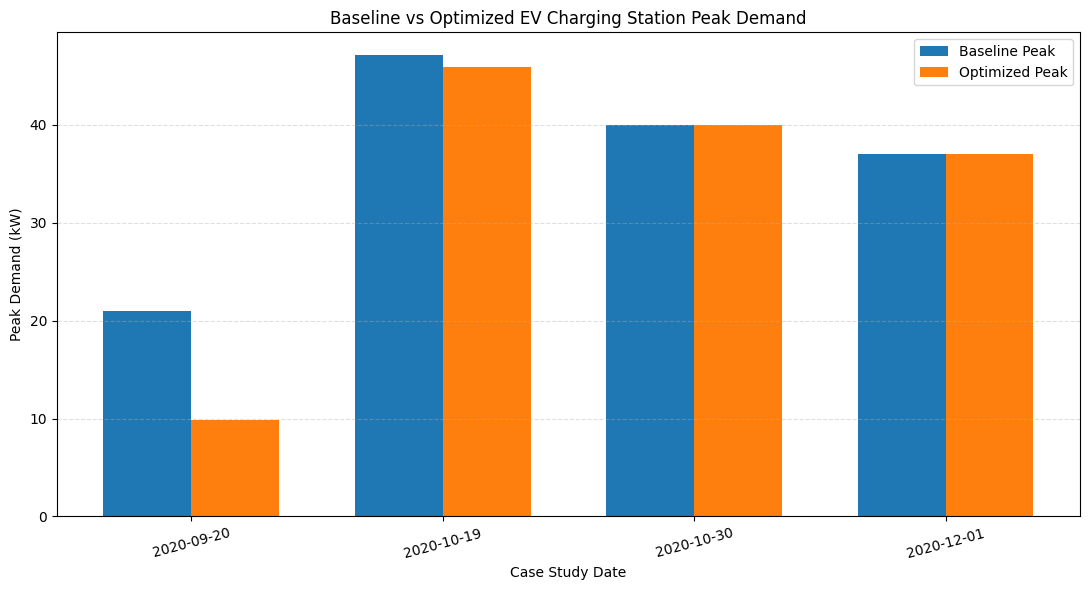

In [224]:

import matplotlib.pyplot as plt
import numpy as np

dates = corrected_case_studies["date"]

x = np.arange(len(dates))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width/2,
    corrected_case_studies["baseline_peak_kw"],
    width,
    label="Baseline Peak"
)

plt.bar(
    x + width/2,
    corrected_case_studies["optimized_peak_kw"],
    width,
    label="Optimized Peak"
)

plt.xticks(x, dates, rotation=15)
plt.ylabel("Peak Demand (kW)")
plt.xlabel("Case Study Date")
plt.title("Baseline vs Optimized EV Charging Station Peak Demand")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


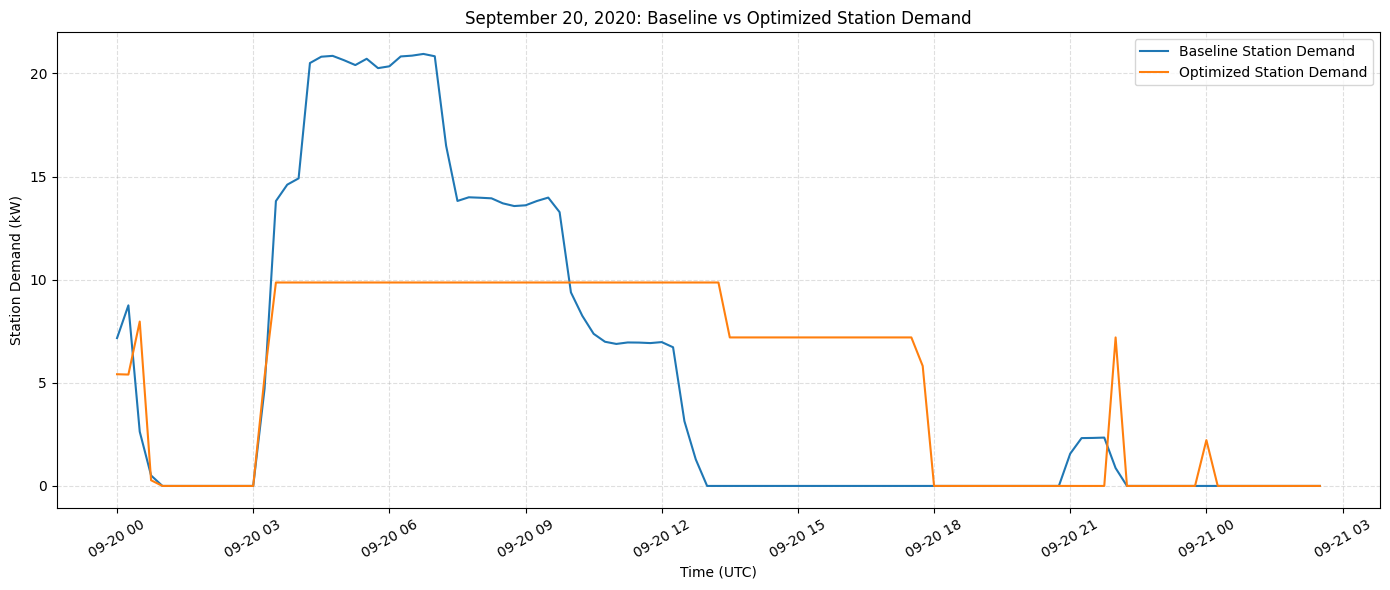

In [225]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    sep20_slots,
    sep20_station_power,
    label="Baseline Station Demand",
    linewidth=1.5
)

plt.plot(
    sep20_slots,
    sep20_corrected_station_power,
    label="Optimized Station Demand",
    linewidth=1.5
)

plt.xlabel("Time (UTC)")
plt.ylabel("Station Demand (kW)")
plt.title("September 20, 2020: Baseline vs Optimized Station Demand")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [226]:

# SEPTEMBER 20 — OPTIMIZED ENERGY VALIDATION

sep20_optimized_energy = (
    sep20_corrected_ev_power.sum(axis=0) * 0.25
).sum()

sep20_required_energy = sep20_required_counter_energy.sum()

print("September 20 Optimized Energy Validation")
print("----------------------------------------")
print(f"Required energy:  {sep20_required_energy:.4f} kWh")
print(f"Optimized energy: {sep20_optimized_energy:.4f} kWh")
print(f"Energy difference: {abs(sep20_required_energy - sep20_optimized_energy):.8f} kWh")


September 20 Optimized Energy Validation
----------------------------------------
Required energy:  90.6609 kWh
Optimized energy: 90.6609 kWh
Energy difference: 0.00000000 kWh


In [227]:

# SEPTEMBER 20 — INDIVIDUAL EV OPTIMIZED ENERGY

sep20_ev_schedule_summary = pd.DataFrame({
    "EV": [f"EV{i+1}" for i in range(sep20_corrected_ev_power.shape[0])],
    "Required_Energy_kWh": sep20_required_counter_energy,
    "Optimized_Energy_kWh": (
        sep20_corrected_ev_power.sum(axis=1) * 0.25
    ),
    "Maximum_Power_kW": sep20_corrected_ev_power.max(axis=1)
})

sep20_ev_schedule_summary["Energy_Error_kWh"] = (
    sep20_ev_schedule_summary["Required_Energy_kWh"]
    - sep20_ev_schedule_summary["Optimized_Energy_kWh"]
)

display(sep20_ev_schedule_summary.round(4))


AxisError: axis 1 is out of bounds for array of dimension 1

In [228]:

# SEPTEMBER 20 — CHECK OPTIMIZATION VARIABLE SHAPES

print("Variable dimensions")
print("--------------------")

for name in [
    "sep20_corrected_ev_power",
    "sep20_x_corrected",
    "sep20_corrected_station_power",
    "sep20_required_counter_energy",
    "sep20_overlap_hours"
]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: shape = {np.shape(value)}, dimensions = {np.ndim(value)}")
    else:
        print(f"{name}: NOT FOUND")


Variable dimensions
--------------------
sep20_corrected_ev_power: shape = (107,), dimensions = 1
sep20_x_corrected: shape = (6, 107), dimensions = 2
sep20_corrected_station_power: shape = (107,), dimensions = 1
sep20_required_counter_energy: shape = (6,), dimensions = 1
sep20_overlap_hours: NOT FOUND


In [229]:

# SEPTEMBER 20 — INDIVIDUAL EV OPTIMIZED ENERGY VALIDATION

sep20_ev_schedule_summary = pd.DataFrame({
    "EV": [f"EV{i+1}" for i in range(sep20_x_corrected.shape[0])],
    "Required_Energy_kWh": sep20_required_counter_energy,
    "Optimized_Energy_kWh": sep20_x_corrected.sum(axis=1),
    "Maximum_Power_kW": sep20_x_corrected.max(axis=1) / 0.25
})

sep20_ev_schedule_summary["Energy_Error_kWh"] = (
    sep20_ev_schedule_summary["Required_Energy_kWh"]
    - sep20_ev_schedule_summary["Optimized_Energy_kWh"]
)

display(sep20_ev_schedule_summary.round(4))


,EV,Required_Energy_kWh,Optimized_Energy_kWh,Maximum_Power_kW,Energy_Error_kWh
0,EV1,1.8687,1.8687,7.2000,0.0
1,EV2,57.9418,57.9418,7.2000,0.0
2,EV3,2.3552,2.3552,7.2000,0.0
3,EV4,0.2559,0.2559,1.0236,0.0
4,EV5,27.3430,27.3430,7.2000,0.0
5,EV6,0.8963,0.8963,2.6400,0.0


In [230]:

# SEPTEMBER 20 — CHARGING AVAILABILITY VALIDATION

# Positive allocated energy must occur only where the EV is available.
# Reconstruct overlap hours from the original session arrival/departure data.

print("Checking available notebook variables:")

for name in [
    "sep20_selected_sessions",
    "sep20_sessions",
    "sep20_selected",
    "sep20_start",
    "sep20_end"
]:
    if name in globals():
        print(name, "exists:", type(globals()[name]))
    else:
        print(name, "not found")


Checking available notebook variables:
sep20_selected_sessions not found
sep20_sessions exists: <class 'pandas.core.frame.DataFrame'>
sep20_selected not found
sep20_start exists: <class 'pandas._libs.tslibs.timestamps.Timestamp'>
sep20_end exists: <class 'pandas._libs.tslibs.timestamps.Timestamp'>


In [231]:

# SEPTEMBER 20 — INSPECT SESSION DATA

print("Shape:", sep20_sessions.shape)

print("\nColumns:")
print(sep20_sessions.columns.tolist())

print("\nFirst 5 records:")
display(sep20_sessions.head())


Shape: (7, 12)

Columns:
['session_id', 'clean_energy_kwh', 'power_energy_kwh', 'coverage_pct', 'relative_difference_pct', 'decision', 'arrival_time', 'departure_time', 'arrival_date', 'duration_hours', 'required_grid_energy_kwh', 'feasible_7.2kw']

First 5 records:


,session_id,clean_energy_kwh,power_energy_kwh,coverage_pct,relative_difference_pct,decision,arrival_time,departure_time,arrival_date,duration_hours,required_grid_energy_kwh,feasible_7.2kw
2911,2-39-125-21-2020-09-20T00-06-33-727102.csv.gz,1.868746,1.873664,100.000000,0.262498,CONSISTENT_CANDIDATE,2020-09-20 00:06:34+00:00,2020-09-20 00:50:46+00:00,2020-09-20,0.736667,1.967101,True
6493,2-39-129-17-2020-09-20T04-16-47-761005.csv.gz,57.941811,58.308514,99.654584,0.628902,CONSISTENT_CANDIDATE,2020-09-20 04:16:51+00:00,2020-09-20 17:57:07+00:00,2020-09-20,13.671111,60.991380,True
14935,2-39-78-365-2020-09-20T21-04-30-681721.csv.gz,2.355215,2.359233,100.000000,0.170294,CONSISTENT_CANDIDATE,2020-09-20 21:04:34+00:00,2020-09-21 02:33:10+00:00,2020-09-20,5.476667,2.479174,True
18198,2-39-79-378-2020-09-20T03-19-12-739563.csv.gz,0.255899,0.262178,100.000000,2.394582,CONSISTENT_CANDIDATE,2020-09-20 03:19:34+00:00,2020-09-20 03:22:03+00:00,2020-09-20,0.041389,0.269368,True
18199,2-39-79-378-2020-09-20T03-22-12-038079.csv.gz,27.342991,27.519899,99.528838,0.642836,CONSISTENT_CANDIDATE,2020-09-20 03:22:15+00:00,2020-09-20 13:23:36+00:00,2020-09-20,10.022500,28.782096,True


In [232]:

# SEPTEMBER 20 — IDENTIFY SESSION GROUPS

sep20_sessions["evse_id"] = (
    sep20_sessions["session_id"].str.split("-").str[:4].str.join("-")
)

display(
    sep20_sessions[
        ["session_id", "evse_id", "arrival_time", "departure_time",
         "clean_energy_kwh"]
    ].sort_values("arrival_time")
)

print("\nUnique EVSE count:", sep20_sessions["evse_id"].nunique())
print("Total sessions:", len(sep20_sessions))


,session_id,evse_id,arrival_time,departure_time,clean_energy_kwh
2911,2-39-125-21-2020-09-20T00-06-33-727102.csv.gz,2-39-125-21,2020-09-20 00:06:34+00:00,2020-09-20 00:50:46+00:00,1.868746
18198,2-39-79-378-2020-09-20T03-19-12-739563.csv.gz,2-39-79-378,2020-09-20 03:19:34+00:00,2020-09-20 03:22:03+00:00,0.255899
18199,2-39-79-378-2020-09-20T03-22-12-038079.csv.gz,2-39-79-378,2020-09-20 03:22:15+00:00,2020-09-20 13:23:36+00:00,27.342991
27471,2-39-92-442-2020-09-20T03-27-54-406735.csv.gz,2-39-92-442,2020-09-20 03:27:54+00:00,2020-09-21 03:39:27+00:00,45.571013
21753,2-39-83-386-2020-09-20T03-54-26-651369.csv.gz,2-39-83-386,2020-09-20 03:54:30+00:00,2020-09-20 05:31:38+00:00,0.896282
6493,2-39-129-17-2020-09-20T04-16-47-761005.csv.gz,2-39-129-17,2020-09-20 04:16:51+00:00,2020-09-20 17:57:07+00:00,57.941811
14935,2-39-78-365-2020-09-20T21-04-30-681721.csv.gz,2-39-78-365,2020-09-20 21:04:34+00:00,2020-09-21 02:33:10+00:00,2.355215



Unique EVSE count: 6
Total sessions: 7


In [233]:

# SEPTEMBER 20 — MATCH OPTIMIZATION ROWS TO ORIGINAL SESSIONS

required_energy = np.asarray(sep20_required_counter_energy)

session_energy = sep20_sessions["clean_energy_kwh"].to_numpy()

for i, energy in enumerate(required_energy):
    differences = np.abs(session_energy - energy)
    match_idx = np.argmin(differences)

    print(
        f"Optimization row {i+1}: "
        f"Required = {energy:.6f} kWh | "
        f"Matched session = {sep20_sessions.iloc[match_idx]['session_id']} | "
        f"Session energy = {session_energy[match_idx]:.6f} kWh"
    )


Optimization row 1: Required = 1.868746 kWh | Matched session = 2-39-125-21-2020-09-20T00-06-33-727102.csv.gz | Session energy = 1.868746 kWh
Optimization row 2: Required = 57.941811 kWh | Matched session = 2-39-129-17-2020-09-20T04-16-47-761005.csv.gz | Session energy = 57.941811 kWh
Optimization row 3: Required = 2.355215 kWh | Matched session = 2-39-78-365-2020-09-20T21-04-30-681721.csv.gz | Session energy = 2.355215 kWh
Optimization row 4: Required = 0.255899 kWh | Matched session = 2-39-79-378-2020-09-20T03-19-12-739563.csv.gz | Session energy = 0.255899 kWh
Optimization row 5: Required = 27.342991 kWh | Matched session = 2-39-79-378-2020-09-20T03-22-12-038079.csv.gz | Session energy = 27.342991 kWh
Optimization row 6: Required = 0.896282 kWh | Matched session = 2-39-83-386-2020-09-20T03-54-26-651369.csv.gz | Session energy = 0.896282 kWh


In [234]:

# SEPTEMBER 20 — RECONSTRUCT EV AVAILABILITY MATRIX

DT = 0.25

sep20_matched_sessions = []

for energy in sep20_required_counter_energy:
    differences = np.abs(
        sep20_sessions["clean_energy_kwh"].to_numpy() - energy
    )
    match_idx = np.argmin(differences)
    sep20_matched_sessions.append(
        sep20_sessions.iloc[match_idx]
    )

sep20_availability = np.zeros(
    (len(sep20_matched_sessions), len(sep20_slots))
)

for i, session in enumerate(sep20_matched_sessions):
    arrival = session["arrival_time"]
    departure = session["departure_time"]

    for j, slot_start in enumerate(sep20_slots):
        slot_end = slot_start + pd.Timedelta(minutes=15)

        overlap_start = max(arrival, slot_start)
        overlap_end = min(departure, slot_end)

        overlap_hours = max(
            0,
            (overlap_end - overlap_start).total_seconds() / 3600
        )

        sep20_availability[i, j] = overlap_hours

print("Availability matrix shape:", sep20_availability.shape)
print("Total available EV-slot combinations:",
      np.count_nonzero(sep20_availability))

display(pd.DataFrame(
    sep20_availability,
    index=[f"EV{i+1}" for i in range(6)]
).iloc[:, :12].round(4))


Availability matrix shape: (6, 107)
Total available EV-slot combinations: 132


,0,1,2,3,4,5,6,7,8,9,10,11
EV1,0.1406,0.25,0.25,0.0961,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
EV2,0.0000,0.00,0.00,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
EV3,0.0000,0.00,0.00,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
EV4,0.0000,0.00,0.00,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
EV5,0.0000,0.00,0.00,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
EV6,0.0000,0.00,0.00,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [235]:

# SEPTEMBER 20 — CHECK CHARGING OUTSIDE PARKING AVAILABILITY

# Energy allocated when the EV has no parking availability
unavailable_energy = np.where(
    sep20_availability <= 0,
    sep20_x_corrected,
    0
)

# Maximum charging energy permitted in each available interval
max_allowed_energy = 7.2 * sep20_availability

# Charging power violation
power_violation = np.maximum(
    sep20_x_corrected - max_allowed_energy,
    0
)

print("SEPTEMBER 20 — AVAILABILITY VALIDATION")
print("--------------------------------------")
print(
    "Energy scheduled outside availability:",
    f"{unavailable_energy.sum():.8f} kWh"
)
print(
    "Maximum charging power violation:",
    f"{power_violation.max():.8f} kWh"
)
print(
    "Number of unavailable intervals with charging:",
    np.count_nonzero(unavailable_energy > 1e-8)
)


SEPTEMBER 20 — AVAILABILITY VALIDATION
--------------------------------------
Energy scheduled outside availability: 0.00000000 kWh
Maximum charging power violation: 0.00000000 kWh
Number of unavailable intervals with charging: 0


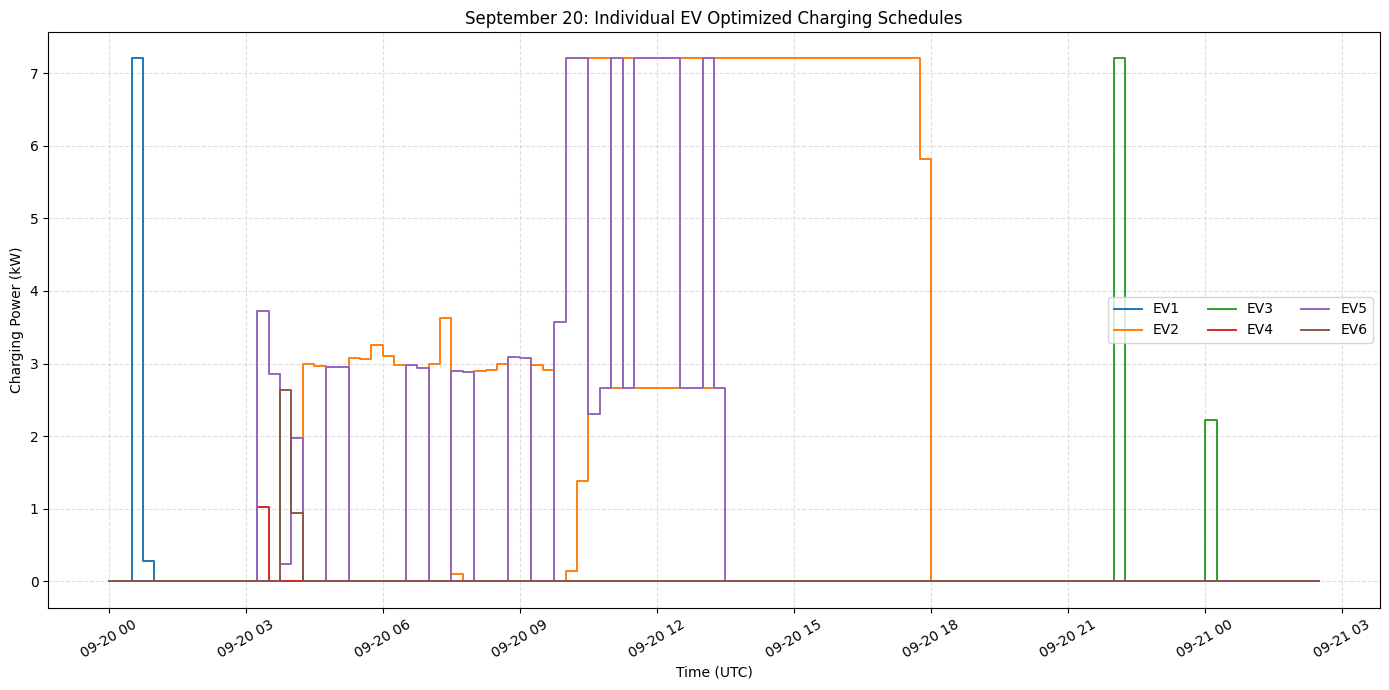

In [236]:

# SEPTEMBER 20 — INDIVIDUAL EV OPTIMIZED CHARGING PROFILES

plt.figure(figsize=(14, 7))

for i in range(sep20_x_corrected.shape[0]):
    ev_power = sep20_x_corrected[i, :] / 0.25

    plt.step(
        sep20_slots,
        ev_power,
        where="post",
        label=f"EV{i+1}",
        linewidth=1.4
    )

plt.xlabel("Time (UTC)")
plt.ylabel("Charging Power (kW)")
plt.title("September 20: Individual EV Optimized Charging Schedules")
plt.legend(ncol=3)
plt.grid(True, linestyle="--", alpha=0.4)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [237]:

# OCTOBER 19 — OPTIMIZATION VARIABLE CHECK

variables = [
    "oct19_x_corrected",
    "oct19_corrected_ev_power",
    "oct19_corrected_station_power",
    "oct19_required_counter_energy",
    "oct19_overlap_hours"
]

for name in variables:
    if name in globals():
        value = globals()[name]
        print(
            f"{name}: shape={np.shape(value)}, "
            f"dimensions={np.ndim(value)}"
        )
    else:
        print(f"{name}: NOT FOUND")


oct19_x_corrected: shape=(5, 101), dimensions=2
oct19_corrected_ev_power: shape=(101,), dimensions=1
oct19_corrected_station_power: shape=(101,), dimensions=1
oct19_required_counter_energy: shape=(5,), dimensions=1
oct19_overlap_hours: shape=(5, 101), dimensions=2


In [238]:

# OCTOBER 19 — INDIVIDUAL EV ENERGY VALIDATION

oct19_ev_schedule_summary = pd.DataFrame({
    "EV": [f"EV{i+1}" for i in range(oct19_x_corrected.shape[0])],
    "Required_Energy_kWh": oct19_required_counter_energy,
    "Optimized_Energy_kWh": oct19_x_corrected.sum(axis=1),
    "Maximum_Power_kW": oct19_x_corrected.max(axis=1) / 0.25
})

oct19_ev_schedule_summary["Energy_Error_kWh"] = (
    oct19_ev_schedule_summary["Required_Energy_kWh"]
    - oct19_ev_schedule_summary["Optimized_Energy_kWh"]
)

display(oct19_ev_schedule_summary.round(6))

print(
    "\nTotal required energy:",
    round(oct19_required_counter_energy.sum(), 6), "kWh"
)
print(
    "Total optimized energy:",
    round(oct19_x_corrected.sum(), 6), "kWh"
)


,EV,Required_Energy_kWh,Optimized_Energy_kWh,Maximum_Power_kW,Energy_Error_kWh
0,EV1,3.188056,3.188056,6.784,0.0
1,EV2,7.877970,7.877970,7.200,0.0
2,EV3,6.157694,6.157694,7.200,0.0
3,EV4,3.253312,3.253312,7.200,0.0
4,EV5,18.414454,18.414454,7.200,0.0



Total required energy: 38.891486 kWh
Total optimized energy: 38.891486 kWh


In [239]:

# OCTOBER 19 — AVAILABILITY AND POWER VALIDATION

oct19_unavailable_energy = np.where(
    oct19_overlap_hours <= 0,
    oct19_x_corrected,
    0
)

oct19_max_allowed_energy = 7.2 * oct19_overlap_hours

oct19_power_violation = np.maximum(
    oct19_x_corrected - oct19_max_allowed_energy,
    0
)

print("OCTOBER 19 — OPTIMIZATION VALIDATION")
print("------------------------------------")
print(
    "Energy outside availability:",
    f"{oct19_unavailable_energy.sum():.8f} kWh"
)
print(
    "Maximum power violation:",
    f"{oct19_power_violation.max():.8f} kWh"
)
print(
    "Unavailable intervals with charging:",
    np.count_nonzero(oct19_unavailable_energy > 1e-8)
)


OCTOBER 19 — OPTIMIZATION VALIDATION
------------------------------------
Energy outside availability: 0.00000000 kWh
Maximum power violation: 0.00000000 kWh
Unavailable intervals with charging: 0


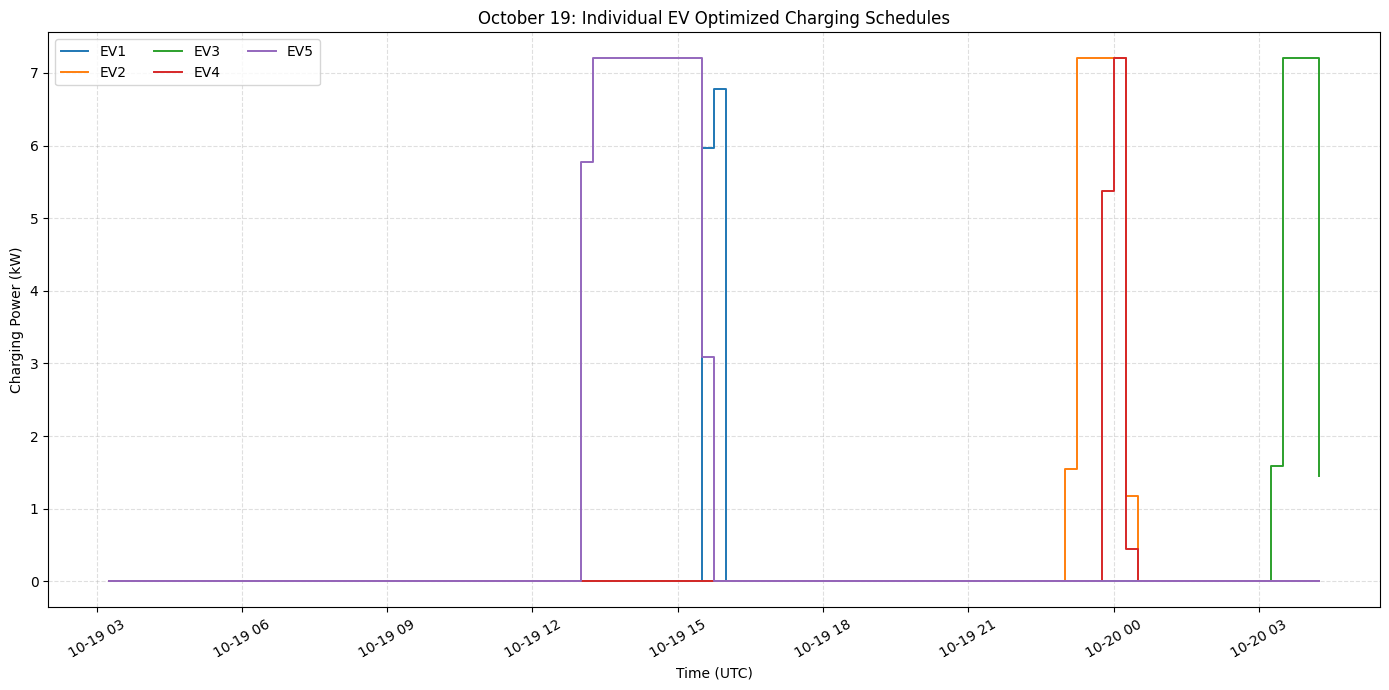

In [240]:

# OCTOBER 19 — INDIVIDUAL EV OPTIMIZED CHARGING PROFILES

plt.figure(figsize=(14, 7))

for i in range(oct19_x_corrected.shape[0]):
    ev_power = oct19_x_corrected[i, :] / 0.25

    plt.step(
        oct19_slots,
        ev_power,
        where="post",
        label=f"EV{i+1}",
        linewidth=1.4
    )

plt.xlabel("Time (UTC)")
plt.ylabel("Charging Power (kW)")
plt.title("October 19: Individual EV Optimized Charging Schedules")
plt.legend(ncol=3)
plt.grid(True, linestyle="--", alpha=0.4)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [241]:

# OCTOBER 30 — OPTIMIZATION VARIABLE CHECK

variables = [
    "oct30_x_corrected",
    "oct30_corrected_ev_power",
    "oct30_corrected_station_power",
    "oct30_required_counter_energy",
    "oct30_overlap_hours"
]

for name in variables:
    if name in globals():
        value = globals()[name]
        print(
            f"{name}: shape={np.shape(value)}, "
            f"dimensions={np.ndim(value)}"
        )
    else:
        print(f"{name}: NOT FOUND")


oct30_x_corrected: shape=(5, 50), dimensions=2
oct30_corrected_ev_power: shape=(50,), dimensions=1
oct30_corrected_station_power: shape=(50,), dimensions=1
oct30_required_counter_energy: shape=(5,), dimensions=1
oct30_overlap_hours: shape=(5, 50), dimensions=2


In [242]:

# OCTOBER 30 — INDIVIDUAL EV ENERGY VALIDATION

oct30_ev_schedule_summary = pd.DataFrame({
    "EV": [f"EV{i+1}" for i in range(oct30_x_corrected.shape[0])],
    "Required_Energy_kWh": oct30_required_counter_energy,
    "Optimized_Energy_kWh": oct30_x_corrected.sum(axis=1),
    "Maximum_Power_kW": oct30_x_corrected.max(axis=1) / 0.25
})

oct30_ev_schedule_summary["Energy_Error_kWh"] = (
    oct30_ev_schedule_summary["Required_Energy_kWh"]
    - oct30_ev_schedule_summary["Optimized_Energy_kWh"]
)

display(oct30_ev_schedule_summary.round(6))

print("\nTotal required energy:",
      round(oct30_required_counter_energy.sum(), 6), "kWh")

print("Total optimized energy:",
      round(oct30_x_corrected.sum(), 6), "kWh")


,EV,Required_Energy_kWh,Optimized_Energy_kWh,Maximum_Power_kW,Energy_Error_kWh
0,EV1,1.786580,1.786580,7.14632,0.0
1,EV2,13.975621,13.975621,7.20000,0.0
2,EV3,6.262346,6.262346,7.20000,0.0
3,EV4,2.287274,2.287274,5.18400,0.0
4,EV5,2.956875,2.956875,6.22750,0.0



Total required energy: 27.268697 kWh
Total optimized energy: 27.268697 kWh


In [243]:

# OCTOBER 30 — AVAILABILITY AND POWER VALIDATION

oct30_unavailable_energy = np.where(
    oct30_overlap_hours <= 0,
    oct30_x_corrected,
    0
)

oct30_max_allowed_energy = 7.2 * oct30_overlap_hours

oct30_power_violation = np.maximum(
    oct30_x_corrected - oct30_max_allowed_energy,
    0
)

print("OCTOBER 30 — OPTIMIZATION VALIDATION")
print("------------------------------------")
print(
    "Energy outside availability:",
    f"{oct30_unavailable_energy.sum():.8f} kWh"
)
print(
    "Maximum power violation:",
    f"{oct30_power_violation.max():.8f} kWh"
)
print(
    "Unavailable intervals with charging:",
    np.count_nonzero(oct30_unavailable_energy > 1e-8)
)


OCTOBER 30 — OPTIMIZATION VALIDATION
------------------------------------
Energy outside availability: 0.00000000 kWh
Maximum power violation: 0.00000000 kWh
Unavailable intervals with charging: 0


In [244]:

# DECEMBER 1 — OPTIMIZATION VARIABLE CHECK

variables = [
    "dec1_x_corrected",
    "dec1_corrected_ev_power",
    "dec1_corrected_station_power",
    "dec1_required_counter_energy",
    "dec1_overlap_hours"
]

for name in variables:
    if name in globals():
        value = globals()[name]
        print(
            f"{name}: shape={np.shape(value)}, "
            f"dimensions={np.ndim(value)}"
        )
    else:
        print(f"{name}: NOT FOUND")


dec1_x_corrected: shape=(7, 90), dimensions=2
dec1_corrected_ev_power: shape=(90,), dimensions=1
dec1_corrected_station_power: shape=(90,), dimensions=1
dec1_required_counter_energy: shape=(7,), dimensions=1
dec1_overlap_hours: shape=(7, 90), dimensions=2


In [245]:

# DECEMBER 1 — INDIVIDUAL EV ENERGY VALIDATION

dec1_ev_schedule_summary = pd.DataFrame({
    "EV": [f"EV{i+1}" for i in range(dec1_x_corrected.shape[0])],
    "Required_Energy_kWh": dec1_required_counter_energy,
    "Optimized_Energy_kWh": dec1_x_corrected.sum(axis=1),
    "Maximum_Power_kW": dec1_x_corrected.max(axis=1) / 0.25
})

dec1_ev_schedule_summary["Energy_Error_kWh"] = (
    dec1_ev_schedule_summary["Required_Energy_kWh"]
    - dec1_ev_schedule_summary["Optimized_Energy_kWh"]
)

display(dec1_ev_schedule_summary.round(6))

print("\nTotal required energy:",
      round(dec1_required_counter_energy.sum(), 6), "kWh")

print("Total optimized energy:",
      round(dec1_x_corrected.sum(), 6), "kWh")


,EV,Required_Energy_kWh,Optimized_Energy_kWh,Maximum_Power_kW,Energy_Error_kWh
0,EV1,0.735914,0.735914,2.943658,0.0
1,EV2,6.197102,6.197102,7.200000,0.0
2,EV3,7.877573,7.877573,7.200000,0.0
3,EV4,10.166486,10.166486,7.200000,0.0
4,EV5,2.254011,2.254011,5.872000,0.0
5,EV6,1.471242,1.471242,5.884967,0.0
6,EV7,0.104765,0.104765,0.419060,0.0



Total required energy: 28.807094 kWh
Total optimized energy: 28.807094 kWh


In [246]:

# DECEMBER 1 — AVAILABILITY AND POWER VALIDATION

dec1_unavailable_energy = np.where(
    dec1_overlap_hours <= 0,
    dec1_x_corrected,
    0
)

dec1_max_allowed_energy = 7.2 * dec1_overlap_hours

dec1_power_violation = np.maximum(
    dec1_x_corrected - dec1_max_allowed_energy,
    0
)

print("DECEMBER 1 — OPTIMIZATION VALIDATION")
print("------------------------------------")

print(
    "Energy outside availability:",
    f"{dec1_unavailable_energy.sum():.8f} kWh"
)

print(
    "Maximum power violation:",
    f"{dec1_power_violation.max():.8f} kWh"
)

print(
    "Unavailable intervals with charging:",
    np.count_nonzero(dec1_unavailable_energy > 1e-8)
)


DECEMBER 1 — OPTIMIZATION VALIDATION
------------------------------------
Energy outside availability: 0.00000000 kWh
Maximum power violation: 0.00000000 kWh
Unavailable intervals with charging: 0


In [247]:

# STAGE 18 — CONSOLIDATED FOUR-CASE VALIDATION TABLE

DT = 0.25
MAX_CHARGING_POWER = 7.2

case_data = [
    {
        "date": "2020-09-20",
        "x": sep20_x_corrected,
        "overlap": sep20_availability,
        "required": sep20_required_counter_energy,
        "baseline_peak": sep20_corrected_baseline_peak,
        "optimized_peak": sep20_corrected_peak
    },
    {
        "date": "2020-10-19",
        "x": oct19_x_corrected,
        "overlap": oct19_overlap_hours,
        "required": oct19_required_counter_energy,
        "baseline_peak": oct19_corrected_baseline_peak,
        "optimized_peak": oct19_corrected_peak
    },
    {
        "date": "2020-10-30",
        "x": oct30_x_corrected,
        "overlap": oct30_overlap_hours,
        "required": oct30_required_counter_energy,
        "baseline_peak": oct30_corrected_baseline_peak,
        "optimized_peak": oct30_corrected_peak
    },
    {
        "date": "2020-12-01",
        "x": dec1_x_corrected,
        "overlap": dec1_overlap_hours,
        "required": dec1_required_counter_energy,
        "baseline_peak": dec1_corrected_baseline_peak,
        "optimized_peak": dec1_corrected_peak
    }
]

validation_results = []

for case in case_data:

    x = np.asarray(case["x"])
    overlap = np.asarray(case["overlap"])
    required = np.asarray(case["required"])

    optimized_energy = x.sum()
    required_energy = required.sum()

    unavailable_energy = np.where(
        overlap <= 0, x, 0
    ).sum()

    max_allowed_energy = MAX_CHARGING_POWER * overlap

    power_violation = np.maximum(
        x - max_allowed_energy, 0
    ).max()

    unavailable_intervals = np.count_nonzero(
        np.where(overlap <= 0, x, 0) > 1e-8
    )

    baseline_peak = case["baseline_peak"]
    optimized_peak = case["optimized_peak"]

    reduction_kw = baseline_peak - optimized_peak
    reduction_pct = reduction_kw / baseline_peak * 100

    validation_results.append({
        "Date": case["date"],
        "EVs": x.shape[0],
        "Required_Energy_kWh": required_energy,
        "Optimized_Energy_kWh": optimized_energy,
        "Energy_Error_kWh": abs(required_energy - optimized_energy),
        "Unavailable_Energy_kWh": unavailable_energy,
        "Max_Power_Violation_kWh": power_violation,
        "Unavailable_EV_Intervals": unavailable_intervals,
        "Baseline_Peak_kW": baseline_peak,
        "Optimized_Peak_kW": optimized_peak,
        "Peak_Reduction_kW": reduction_kw,
        "Peak_Reduction_Percent": reduction_pct
    })

final_validation_table = pd.DataFrame(validation_results)

display(final_validation_table.round(6))

# Save final validation table
final_validation_table.to_csv(
    r"C:\EV_Charging_Project\final_four_case_validation.csv",
    index=False
)

print("\nSaved successfully:")
print(r"C:\EV_Charging_Project\final_four_case_validation.csv")


,Date,EVs,Required_Energy_kWh,Optimized_Energy_kWh,Energy_Error_kWh,Unavailable_Energy_kWh,Max_Power_Violation_kWh,Unavailable_EV_Intervals,Baseline_Peak_kW,Optimized_Peak_kW,Peak_Reduction_kW,Peak_Reduction_Percent
0,2020-09-20,6,90.660945,90.660945,0.0,0.0,0.0,0,20.944645,9.863000,11.081645,52.909205
1,2020-10-19,5,38.891486,38.891486,0.0,0.0,0.0,0,47.077796,45.891783,1.186012,2.519261
2,2020-10-30,5,27.268697,27.268697,0.0,0.0,0.0,0,39.983973,39.983973,0.000000,0.000000
3,2020-12-01,7,28.807094,28.807094,0.0,0.0,0.0,0,37.020282,37.020282,0.000000,0.000000



Saved successfully:
C:\EV_Charging_Project\final_four_case_validation.csv


In [248]:

# STAGE 19 — FORECASTING AND OPTIMIZATION INTEGRATION
# TASK 1: Inspect existing forecasting objects

variables = [
    "stage13_forecast_df",
    "model_df",
    "forecast_df",
    "recent_regressor_models",
    "xgb_model",
    "best_xgb_model",
    "X_test",
    "y_test",
    "X_train",
    "y_train"
]

print("EXISTING FORECASTING OBJECTS")
print("----------------------------")

for name in variables:
    if name in globals():
        value = globals()[name]
        print(f"{name}: Available | Type: {type(value).__name__}")

        if hasattr(value, "shape"):
            print("   Shape:", value.shape)
    else:
        print(f"{name}: Not found")


EXISTING FORECASTING OBJECTS
----------------------------
stage13_forecast_df: Available | Type: DataFrame
   Shape: (18028, 3)
model_df: Available | Type: DataFrame
   Shape: (90144, 20)
forecast_df: Available | Type: DataFrame
   Shape: (90816, 7)
recent_regressor_models: Available | Type: dict
xgb_model: Available | Type: XGBRegressor
best_xgb_model: Not found
X_test: Available | Type: DataFrame
   Shape: (18029, 15)
y_test: Available | Type: Series
   Shape: (18029,)
X_train: Available | Type: DataFrame
   Shape: (72115, 15)
y_train: Available | Type: Series
   Shape: (72115,)


In [249]:

# STAGE 19 — TASK 2: INSPECT FORECAST DATA AND MODEL DETAILS

print("1. TWO-STAGE FORECAST DATA")
print("--------------------------")
print("Columns:", stage13_forecast_df.columns.tolist())
display(stage13_forecast_df.head())

print("\n2. FORECAST DATA TYPES")
print("---------------------")
print(stage13_forecast_df.dtypes)

print("\n3. HISTORICAL FORECAST DATA")
print("---------------------------")
print("Columns:", forecast_df.columns.tolist())
display(forecast_df.head())

print("\n4. AVAILABLE RECENT REGRESSOR MODELS")
print("------------------------------------")
print(recent_regressor_models.keys())

print("\n5. FORECAST DATA SUMMARY")
print("------------------------")
display(stage13_forecast_df.describe())


1. TWO-STAGE FORECAST DATA
--------------------------
Columns: ['timestamp', 'actual_station_kw', 'predicted_station_kw']


,timestamp,actual_station_kw,predicted_station_kw
0,2020-05-29 05:00:00+00:00,0.0,0.0
1,2020-05-29 05:15:00+00:00,0.0,0.0
2,2020-05-29 05:30:00+00:00,0.0,0.0
3,2020-05-29 05:45:00+00:00,0.0,0.0
4,2020-05-29 06:00:00+00:00,0.0,0.0



2. FORECAST DATA TYPES
---------------------
timestamp               datetime64[ns, UTC]
actual_station_kw                   float64
predicted_station_kw                float32
dtype: object

3. HISTORICAL FORECAST DATA
---------------------------
Columns: ['timestamp', 'energy_kwh', 'average_power_kw', 'date', 'hour', 'day_of_week', 'month']


,timestamp,energy_kwh,average_power_kw,date,hour,day_of_week,month
0,2018-05-02 00:00:00+00:00,2.691313,10.765251,2018-05-02,0,2,5
1,2018-05-02 00:15:00+00:00,1.893862,7.575449,2018-05-02,0,2,5
2,2018-05-02 00:30:00+00:00,1.878874,7.515496,2018-05-02,0,2,5
3,2018-05-02 00:45:00+00:00,1.902345,7.609380,2018-05-02,0,2,5
4,2018-05-02 01:00:00+00:00,0.856732,3.426928,2018-05-02,1,2,5



4. AVAILABLE RECENT REGRESSOR MODELS
------------------------------------
dict_keys(['Full historical', 'Recent 12 months', 'Recent 6 months'])

5. FORECAST DATA SUMMARY
------------------------


,actual_station_kw,predicted_station_kw
count,18028.000000,18028.000000
mean,0.992555,1.032607
std,3.901224,4.004987
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,53.641059,47.910957


In [250]:

# STAGE 19 — TASK 3: CHECK FORECAST COVERAGE

print("FORECAST TIMESTAMP COVERAGE")
print("---------------------------")

print("First timestamp:",
      stage13_forecast_df["timestamp"].min())

print("Last timestamp:",
      stage13_forecast_df["timestamp"].max())

print("Total forecast records:",
      len(stage13_forecast_df))

print("Duplicate timestamps:",
      stage13_forecast_df["timestamp"].duplicated().sum())

print("\nCASE STUDY FORECAST COVERAGE")
print("----------------------------")

case_slots = {
    "September 20": sep20_slots,
    "October 19": oct19_slots,
    "October 30": reconstruction_slots,
    "December 1": dec1_slots
}

for name, slots in case_slots.items():

    matching = stage13_forecast_df[
        stage13_forecast_df["timestamp"].isin(slots)
    ]

    print(
        f"{name}: {len(matching)} / {len(slots)} "
        "forecast intervals available"
    )


FORECAST TIMESTAMP COVERAGE
---------------------------
First timestamp: 2020-05-29 05:00:00+00:00
Last timestamp: 2020-12-02 23:45:00+00:00
Total forecast records: 18028
Duplicate timestamps: 0

CASE STUDY FORECAST COVERAGE
----------------------------
September 20: 107 / 107 forecast intervals available
October 19: 101 / 101 forecast intervals available
October 30: 50 / 50 forecast intervals available
December 1: 90 / 90 forecast intervals available


In [251]:

# STAGE 19 — TASK 4: EXTRACT FORECASTS FOR FOUR CASE STUDIES

case_slots = {
    "September 20": sep20_slots,
    "October 19": oct19_slots,
    "October 30": reconstruction_slots,
    "December 1": dec1_slots
}

case_forecast_data = {}

for name, slots in case_slots.items():

    case_df = (
        stage13_forecast_df[
            stage13_forecast_df["timestamp"].isin(slots)
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    case_forecast_data[name] = case_df

    print(f"\n{name}")
    print("--------------------------")
    print("Intervals:", len(case_df))
    print(
        "Actual energy:",
        round(case_df["actual_station_kw"].sum() * 0.25, 4),
        "kWh"
    )
    print(
        "Predicted energy:",
        round(case_df["predicted_station_kw"].sum() * 0.25, 4),
        "kWh"
    )
    print(
        "Actual peak:",
        round(case_df["actual_station_kw"].max(), 4),
        "kW"
    )
    print(
        "Predicted peak:",
        round(case_df["predicted_station_kw"].max(), 4),
        "kW"
    )



September 20
--------------------------
Intervals: 107
Actual energy: 139.1282 kWh
Predicted energy: 134.382 kWh
Actual peak: 20.9446 kW
Predicted peak: 21.6564 kW

October 19
--------------------------
Intervals: 101
Actual energy: 99.0467 kWh
Predicted energy: 111.0975 kWh
Actual peak: 47.0778 kW
Predicted peak: 46.0655 kW

October 30
--------------------------
Intervals: 50
Actual energy: 95.6097 kWh
Predicted energy: 102.3716 kWh
Actual peak: 39.984 kW
Predicted peak: 38.1028 kW

December 1
--------------------------
Intervals: 90
Actual energy: 80.9338 kWh
Predicted energy: 89.7144 kWh
Actual peak: 37.0203 kW
Predicted peak: 41.7115 kW


In [252]:

# STAGE 19 — TASK 5: CASE-WISE FORECAST ACCURACY

forecast_accuracy_results = []

for name, df in case_forecast_data.items():

    actual = df["actual_station_kw"].to_numpy()
    predicted = df["predicted_station_kw"].to_numpy()

    error = predicted - actual

    forecast_accuracy_results.append({
        "Case_Study": name,
        "MAE_kW": np.mean(np.abs(error)),
        "RMSE_kW": np.sqrt(np.mean(error**2)),
        "Bias_kW": np.mean(error),
        "Actual_Peak_kW": actual.max(),
        "Predicted_Peak_kW": predicted.max()
    })

forecast_accuracy_table = pd.DataFrame(
    forecast_accuracy_results
)

display(forecast_accuracy_table.round(4))


,Case_Study,MAE_kW,RMSE_kW,Bias_kW,Actual_Peak_kW,Predicted_Peak_kW
0,September 20,0.7027,1.5452,-0.1774,20.9446,21.656401
1,October 19,2.4933,7.1837,0.4773,47.0778,46.065498
2,October 30,5.5146,10.4593,0.5410,39.9840,38.102798
3,December 1,2.9992,8.2687,0.3902,37.0203,41.711498


In [253]:

# STAGE 19 — TASK 6: INSPECT SEPTEMBER 20 LOAD COMPONENTS

variables = [
    "sep20_station_power",
    "sep20_selected_ev_actual_kw",
    "sep20_selected_power",
    "sep20_other_ev_power",
    "sep20_corrected_ev_power",
    "sep20_corrected_station_power"
]

print("SEPTEMBER 20 — LOAD COMPONENT INSPECTION")
print("----------------------------------------")

for name in variables:
    if name in globals():
        value = globals()[name]
        print(
            f"{name}: shape={np.shape(value)}, "
            f"dimensions={np.ndim(value)}"
        )
    else:
        print(f"{name}: NOT FOUND")


SEPTEMBER 20 — LOAD COMPONENT INSPECTION
----------------------------------------
sep20_station_power: shape=(107,), dimensions=1
sep20_selected_ev_actual_kw: NOT FOUND
sep20_selected_power: shape=(107,), dimensions=1
sep20_other_ev_power: NOT FOUND
sep20_corrected_ev_power: shape=(107,), dimensions=1
sep20_corrected_station_power: shape=(107,), dimensions=1


In [254]:

# STAGE 19 — TASK 7: VERIFY SEPTEMBER 20 LOAD COMPONENTS

print("SEPTEMBER 20 LOAD COMPONENT CHECK")
print("---------------------------------")

print("Baseline station peak:",
      sep20_station_power.max(), "kW")

print("Selected EV demand peak:",
      sep20_selected_power.max(), "kW")

sep20_background_power = (
    sep20_station_power - sep20_selected_power
)

print("Estimated background peak:",
      sep20_background_power.max(), "kW")

print("\nEnergy reconciliation:")

print("Baseline station energy:",
      sep20_station_power.sum() * 0.25, "kWh")

print("Selected EV energy:",
      sep20_selected_power.sum() * 0.25, "kWh")

print("Estimated background energy:",
      sep20_background_power.sum() * 0.25, "kWh")

print("\nMinimum background power:",
      sep20_background_power.min(), "kW")

print("Maximum background power:",
      sep20_background_power.max(), "kW")


SEPTEMBER 20 LOAD COMPONENT CHECK
---------------------------------
Baseline station peak: 20.944644722199996 kW
Selected EV demand peak: 14.022736388799999 kW
Estimated background peak: 7.003517222211992 kW

Energy reconciliation:
Baseline station energy: 139.12821187741488 kWh
Selected EV energy: 90.66094537961489 kWh
Estimated background energy: 48.4672664978 kWh

Minimum background power: 0.0 kW
Maximum background power: 7.003517222211992 kW


In [255]:

# STAGE 19 — TASK 8: ESTIMATE FORECAST-BASED BACKGROUND LOAD
# Retrospective diagnostic only

sep20_forecast_df = case_forecast_data["September 20"].copy()

sep20_predicted_background = (
    sep20_forecast_df["predicted_station_kw"].to_numpy()
    - sep20_selected_power
)

print("SEPTEMBER 20 — FORECAST BACKGROUND LOAD")
print("---------------------------------------")

print(
    "Minimum estimated background:",
    round(sep20_predicted_background.min(), 6), "kW"
)

print(
    "Maximum estimated background:",
    round(sep20_predicted_background.max(), 6), "kW"
)

print(
    "Negative background intervals:",
    np.count_nonzero(sep20_predicted_background < -1e-8)
)

print(
    "Mean estimated background:",
    round(sep20_predicted_background.mean(), 6), "kW"
)

print(
    "Estimated background energy:",
    round(sep20_predicted_background.sum() * 0.25, 6), "kWh"
)


SEPTEMBER 20 — FORECAST BACKGROUND LOAD
---------------------------------------
Minimum estimated background: -4.16111 kW
Maximum estimated background: 10.81827 kW
Negative background intervals: 6
Mean estimated background: 1.634433 kW
Estimated background energy: 43.72107 kWh


In [256]:

# STAGE 19 — TASK 9: IDENTIFY NEGATIVE FORECAST BACKGROUND INTERVALS

sep20_background_check = pd.DataFrame({
    "timestamp": sep20_forecast_df["timestamp"].to_numpy(),
    "actual_station_kw": sep20_forecast_df["actual_station_kw"].to_numpy(),
    "predicted_station_kw": sep20_forecast_df["predicted_station_kw"].to_numpy(),
    "actual_selected_ev_kw": sep20_selected_power,
    "actual_background_kw": sep20_background_power,
    "estimated_background_kw": sep20_predicted_background
})

negative_background_intervals = sep20_background_check[
    sep20_background_check["estimated_background_kw"] < -1e-8
].copy()

print("Negative background intervals:")
display(negative_background_intervals.round(4))

print("\nForecast error at these intervals:")
negative_background_intervals["forecast_error_kw"] = (
    negative_background_intervals["predicted_station_kw"]
    - negative_background_intervals["actual_station_kw"]
)

display(
    negative_background_intervals[
        ["timestamp", "actual_station_kw",
         "predicted_station_kw", "actual_selected_ev_kw",
         "actual_background_kw", "estimated_background_kw",
         "forecast_error_kw"]
    ].round(4)
)


Negative background intervals:


,timestamp,actual_station_kw,predicted_station_kw,actual_selected_ev_kw,actual_background_kw,estimated_background_kw
3,2020-09-20 00:45:00+00:00,0.5067,0.0000,0.5067,0.0000,-0.5067
13,2020-09-20 03:15:00+00:00,4.7135,0.0000,4.1611,0.5524,-4.1611
14,2020-09-20 03:30:00+00:00,13.8110,5.9303,6.8075,7.0035,-0.8771
47,2020-09-20 11:45:00+00:00,6.9257,6.8680,6.9257,0.0000,-0.0577
51,2020-09-20 12:45:00+00:00,1.2898,1.1987,1.2898,0.0000,-0.0910
84,2020-09-20 21:00:00+00:00,1.5641,0.0000,1.5641,0.0000,-1.5641



Forecast error at these intervals:


,timestamp,actual_station_kw,predicted_station_kw,actual_selected_ev_kw,actual_background_kw,estimated_background_kw,forecast_error_kw
3,2020-09-20 00:45:00+00:00,0.5067,0.0000,0.5067,0.0000,-0.5067,-0.5067
13,2020-09-20 03:15:00+00:00,4.7135,0.0000,4.1611,0.5524,-4.1611,-4.7135
14,2020-09-20 03:30:00+00:00,13.8110,5.9303,6.8075,7.0035,-0.8771,-7.8806
47,2020-09-20 11:45:00+00:00,6.9257,6.8680,6.9257,0.0000,-0.0577,-0.0577
51,2020-09-20 12:45:00+00:00,1.2898,1.1987,1.2898,0.0000,-0.0910,-0.0910
84,2020-09-20 21:00:00+00:00,1.5641,0.0000,1.5641,0.0000,-1.5641,-1.5641


In [257]:

# STAGE 19 — TASK 10: CHECK BACKGROUND LOAD DATA AVAILABILITY

print("Available forecasting dataset columns:")
print(forecast_df.columns.tolist())

print("\nAvailable model dataset columns:")
print(model_df.columns.tolist())

print("\nForecast dataset shape:", forecast_df.shape)
print("Model dataset shape:", model_df.shape)

print("\nExisting forecast columns:")
print(stage13_forecast_df.columns.tolist())

print("\nSeptember 20 background profile:")
print("Actual background energy:",
      round(sep20_background_power.sum() * 0.25, 4), "kWh")

print("Actual background peak:",
      round(sep20_background_power.max(), 4), "kW")


Available forecasting dataset columns:
['timestamp', 'energy_kwh', 'average_power_kw', 'date', 'hour', 'day_of_week', 'month']

Available model dataset columns:
['timestamp', 'energy_kwh', 'average_power_kw', 'date', 'hour', 'day_of_week', 'month', 'target_power_kw', 'day_of_year', 'is_weekend', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'lag_1', 'lag_4', 'lag_96', 'lag_672', 'rolling_mean_4', 'rolling_mean_96']

Forecast dataset shape: (90816, 7)
Model dataset shape: (90144, 20)

Existing forecast columns:
['timestamp', 'actual_station_kw', 'predicted_station_kw']

September 20 background profile:
Actual background energy: 48.4673 kWh
Actual background peak: 7.0035 kW


In [258]:

# STAGE 19 — TASK 11: CHECK EXISTING CASE-STUDY LOAD COMPONENTS

variables_to_check = [
    "sep20_background_power",
    "oct19_other_ev_power",
    "other_ev_power",
    "dec1_other_ev_power",
    "sep20_station_power",
    "oct19_station_power",
    "oct30_station_power",
    "dec1_station_power"
]

for variable_name in variables_to_check:
    if variable_name in globals():
        variable = globals()[variable_name]
        print(
            f"{variable_name}:",
            type(variable).__name__,
            "Shape:", getattr(variable, "shape", "Not applicable")
        )
    else:
        print(f"{variable_name}: NOT FOUND")


sep20_background_power: ndarray Shape: (107,)
oct19_other_ev_power: NOT FOUND
other_ev_power: ndarray Shape: (50,)
dec1_other_ev_power: NOT FOUND
sep20_station_power: ndarray Shape: (107,)
oct19_station_power: ndarray Shape: (101,)
oct30_station_power: NOT FOUND
dec1_station_power: ndarray Shape: (90,)


In [259]:

# STAGE 19 — TASK 12: SEARCH EXISTING CASE-STUDY VARIABLES

keywords = ["oct19", "dec1", "background", "other_ev", "selected_power"]

print("Matching existing notebook variables:\n")

for name in sorted(globals().keys()):
    if any(keyword in name.lower() for keyword in keywords):
        value = globals()[name]

        if isinstance(value, (np.ndarray, pd.Series, pd.DataFrame)):
            print(
                f"{name}: {type(value).__name__}, "
                f"shape={value.shape}"
            )


Matching existing notebook variables:

background: ndarray, shape=(50,)
background_actual_df: DataFrame, shape=(115, 5)
background_check_df: DataFrame, shape=(50, 5)
background_energy: ndarray, shape=(50,)
background_energy_47: ndarray, shape=(115,)
background_energy_actual: ndarray, shape=(115,)
background_power: ndarray, shape=(50,)
background_power_47: ndarray, shape=(115,)
background_power_actual: ndarray, shape=(115,)
background_profile: DataFrame, shape=(115, 5)
dec1_all_sessions: DataFrame, shape=(29270, 8)
dec1_corrected_baseline_station_power: ndarray, shape=(90,)
dec1_corrected_ev_power: ndarray, shape=(90,)
dec1_corrected_max_energy: ndarray, shape=(7, 90)
dec1_corrected_station_power: ndarray, shape=(90,)
dec1_energy_errors: ndarray, shape=(7,)
dec1_ev_energy_check: ndarray, shape=(7,)
dec1_ev_schedule_df: DataFrame, shape=(7, 9)
dec1_ev_schedule_summary: DataFrame, shape=(7, 5)
dec1_feasible: DataFrame, shape=(7, 13)
dec1_infeasible: DataFrame, shape=(3, 13)
dec1_max_allow

In [260]:

# Identify October 30 station-demand variables

for name in sorted(globals().keys()):
    if "station" in name.lower() or "measured" in name.lower():
        value = globals()[name]

        if isinstance(value, (np.ndarray, pd.Series)):
            if getattr(value, "shape", (None,))[0] == 50:
                print(name, value.shape)


actual_station_power (50,)
actual_station_profile (50,)
improved_station_power (50,)
measured_energy (50,)
measured_power (50,)
measured_station_energy (50,)
oct30_baseline_station_power (50,)
oct30_corrected_station_power (50,)
optimized_station_power (50,)
predicted_station_power (50,)
uncontrolled_station_power (50,)
uncontrolled_station_power_improved (50,)


In [261]:

# STAGE 19 — TASK 13: FOUR-CASE LOAD DECOMPOSITION VALIDATION

case_components = {
    "September 20": {
        "selected": sep20_selected_power,
        "background": sep20_background_power,
        "station": sep20_station_power
    },
    "October 19": {
        "selected": oct19_selected_power,
        "background": oct19_other_power,
        "station": oct19_station_power
    },
    "October 30": {
        "selected": selected_power,
        "background": other_ev_power,
        "station": actual_station_power
    },
    "December 1": {
        "selected": dec1_selected_power,
        "background": dec1_other_power,
        "station": dec1_station_power
    }
}

validation_results = []

for date, components in case_components.items():

    selected = np.asarray(components["selected"])
    background = np.asarray(components["background"])
    station = np.asarray(components["station"])

    reconstructed = selected + background

    validation_results.append({
        "Date": date,
        "Intervals": len(station),
        "Station_Energy_kWh": station.sum() * 0.25,
        "Selected_Energy_kWh": selected.sum() * 0.25,
        "Background_Energy_kWh": background.sum() * 0.25,
        "Energy_Balance_Error_kWh": (
            station.sum() - reconstructed.sum()
        ) * 0.25,
        "Maximum_Power_Difference_kW": np.max(
            np.abs(station - reconstructed)
        ),
        "Minimum_Background_kW": background.min(),
        "Maximum_Background_kW": background.max(),
        "Negative_Background_Intervals": np.count_nonzero(
            background < -1e-8
        )
    })

background_validation_table = pd.DataFrame(validation_results)

display(background_validation_table.round(5))


,Date,Intervals,Station_Energy_kWh,Selected_Energy_kWh,Background_Energy_kWh,Energy_Balance_Error_kWh,Maximum_Power_Difference_kW,Minimum_Background_kW,Maximum_Background_kW,Negative_Background_Intervals
0,September 20,107,139.12821,90.66095,48.46727,0.0,0.0,0.0,7.00352,0
1,October 19,101,99.04669,38.89149,60.15520,0.0,0.0,0.0,45.89178,0
2,October 30,50,95.60970,27.26870,68.34100,0.0,0.0,0.0,39.98397,0
3,December 1,90,80.93383,28.80709,52.12674,0.0,0.0,0.0,37.02028,0


In [262]:

# STAGE 19 — TASK 14: VALIDATE OPTIMIZED STATION LOAD

optimized_components = {
    "September 20": {
        "optimized_ev": sep20_corrected_ev_power,
        "background": sep20_background_power,
        "optimized_station": sep20_corrected_station_power
    },
    "October 19": {
        "optimized_ev": oct19_corrected_ev_power,
        "background": oct19_other_power,
        "optimized_station": oct19_corrected_station_power
    },
    "October 30": {
        "optimized_ev": oct30_corrected_ev_power,
        "background": other_ev_power,
        "optimized_station": oct30_corrected_station_power
    },
    "December 1": {
        "optimized_ev": dec1_corrected_ev_power,
        "background": dec1_other_power,
        "optimized_station": dec1_corrected_station_power
    }
}

optimized_validation = []

for date, data in optimized_components.items():

    reconstructed = (
        np.asarray(data["optimized_ev"])
        + np.asarray(data["background"])
    )

    optimized_station = np.asarray(data["optimized_station"])

    optimized_validation.append({
        "Date": date,
        "Optimized_EV_Peak_kW": np.max(data["optimized_ev"]),
        "Background_Peak_kW": np.max(data["background"]),
        "Reconstructed_Optimized_Peak_kW": np.max(reconstructed),
        "Recorded_Optimized_Peak_kW": np.max(optimized_station),
        "Maximum_Difference_kW": np.max(
            np.abs(reconstructed - optimized_station)
        )
    })

optimized_validation_table = pd.DataFrame(optimized_validation)

display(optimized_validation_table.round(5))


,Date,Optimized_EV_Peak_kW,Background_Peak_kW,Reconstructed_Optimized_Peak_kW,Recorded_Optimized_Peak_kW,Maximum_Difference_kW
0,September 20,9.86300,7.00352,9.86300,9.86300,0.0
1,October 19,14.40000,45.89178,45.89178,45.89178,0.0
2,October 30,12.38400,39.98397,39.98397,39.98397,0.0
3,December 1,12.81491,37.02028,37.02028,37.02028,0.0


In [263]:

# STAGE 19 — TASK 15: INSPECT FINAL SUMMARY TABLES

print("CORRECTED CASE STUDY RESULTS")
print(corrected_case_studies.columns.tolist())
display(corrected_case_studies.head())

print("\nFINAL VALIDATION TABLE")
print(final_validation_table.columns.tolist())
display(final_validation_table.head())

print("\nFORECAST ACCURACY TABLE")
print(forecast_accuracy_table.columns.tolist())
display(forecast_accuracy_table.head())


CORRECTED CASE STUDY RESULTS
['date', 'selected_evs', 'other_evs', 'intervals', 'required_energy_kwh', 'baseline_peak_kw', 'optimized_peak_kw', 'reduction_kw', 'reduction_percentage']


,date,selected_evs,other_evs,intervals,required_energy_kwh,baseline_peak_kw,optimized_peak_kw,reduction_kw,reduction_percentage
0,2020-09-20,6,2,107,90.660945,20.944645,9.863000,11.081645,52.909205
1,2020-10-19,5,5,101,38.891486,47.077796,45.891783,1.186012,2.519261
2,2020-10-30,5,5,50,27.268697,39.983973,39.983973,0.000000,0.000000
3,2020-12-01,7,7,90,28.807094,37.020282,37.020282,0.000000,0.000000



FINAL VALIDATION TABLE
['Date', 'EVs', 'Required_Energy_kWh', 'Optimized_Energy_kWh', 'Energy_Error_kWh', 'Unavailable_Energy_kWh', 'Max_Power_Violation_kWh', 'Unavailable_EV_Intervals', 'Baseline_Peak_kW', 'Optimized_Peak_kW', 'Peak_Reduction_kW', 'Peak_Reduction_Percent']


,Date,EVs,Required_Energy_kWh,Optimized_Energy_kWh,Energy_Error_kWh,Unavailable_Energy_kWh,Max_Power_Violation_kWh,Unavailable_EV_Intervals,Baseline_Peak_kW,Optimized_Peak_kW,Peak_Reduction_kW,Peak_Reduction_Percent
0,2020-09-20,6,90.660945,90.660945,0.000000e+00,0.0,0.0,0,20.944645,9.863000,11.081645,52.909205
1,2020-10-19,5,38.891486,38.891486,7.105427e-15,0.0,0.0,0,47.077796,45.891783,1.186012,2.519261
2,2020-10-30,5,27.268697,27.268697,3.552714e-15,0.0,0.0,0,39.983973,39.983973,0.000000,0.000000
3,2020-12-01,7,28.807094,28.807094,0.000000e+00,0.0,0.0,0,37.020282,37.020282,0.000000,0.000000



FORECAST ACCURACY TABLE
['Case_Study', 'MAE_kW', 'RMSE_kW', 'Bias_kW', 'Actual_Peak_kW', 'Predicted_Peak_kW']


,Case_Study,MAE_kW,RMSE_kW,Bias_kW,Actual_Peak_kW,Predicted_Peak_kW
0,September 20,0.702663,1.545223,-0.177428,20.944645,21.656372
1,October 19,2.493350,7.183733,0.477260,47.077796,46.065468
2,October 30,5.514624,10.459310,0.540954,39.983973,38.102806
3,December 1,2.999227,8.268655,0.390246,37.020282,41.711506


In [264]:

# STAGE 19 — TASK 16: CONSOLIDATED FORECASTING + OPTIMIZATION RESULTS

# Prepare matching case-study names
optimization_results = final_validation_table.copy()

optimization_results["Case_Study"] = optimization_results["Date"].map({
    "2020-09-20": "September 20",
    "2020-10-19": "October 19",
    "2020-10-30": "October 30",
    "2020-12-01": "December 1"
})

# Merge forecasting and optimization results
consolidated_results = pd.merge(
    forecast_accuracy_table,
    optimization_results,
    on="Case_Study",
    how="inner"
)

# Select important columns
consolidated_results = consolidated_results[[
    "Case_Study",
    "MAE_kW",
    "RMSE_kW",
    "Bias_kW",
    "Actual_Peak_kW",
    "Predicted_Peak_kW",
    "EVs",
    "Required_Energy_kWh",
    "Baseline_Peak_kW",
    "Optimized_Peak_kW",
    "Peak_Reduction_kW",
    "Peak_Reduction_Percent",
    "Energy_Error_kWh",
    "Unavailable_Energy_kWh",
    "Unavailable_EV_Intervals"
]]

print("CONSOLIDATED FORECASTING AND OPTIMIZATION RESULTS")
print("--------------------------------------------------")

display(consolidated_results.round(4))

print("\nNumber of matched case studies:",
      len(consolidated_results))


CONSOLIDATED FORECASTING AND OPTIMIZATION RESULTS
--------------------------------------------------


,Case_Study,MAE_kW,RMSE_kW,Bias_kW,Actual_Peak_kW,Predicted_Peak_kW,EVs,Required_Energy_kWh,Baseline_Peak_kW,Optimized_Peak_kW,Peak_Reduction_kW,Peak_Reduction_Percent,Energy_Error_kWh,Unavailable_Energy_kWh,Unavailable_EV_Intervals
0,September 20,0.7027,1.5452,-0.1774,20.9446,21.656401,6,90.6609,20.9446,9.8630,11.0816,52.9092,0.0,0.0,0
1,October 19,2.4933,7.1837,0.4773,47.0778,46.065498,5,38.8915,47.0778,45.8918,1.1860,2.5193,0.0,0.0,0
2,October 30,5.5146,10.4593,0.5410,39.9840,38.102798,5,27.2687,39.9840,39.9840,0.0000,0.0000,0.0,0.0,0
3,December 1,2.9992,8.2687,0.3902,37.0203,41.711498,7,28.8071,37.0203,37.0203,0.0000,0.0000,0.0,0.0,0



Number of matched case studies: 4


In [265]:

# STAGE 20 — TASK 1: INSPECT HISTORICAL SESSION DATA

print("CLEAN SESSION DATA")
print("------------------")

print("Shape:", clean_sessions.shape)
print("Columns:", clean_sessions.columns.tolist())

print("\nData types:")
print(clean_sessions.dtypes)

print("\nFirst five records:")
display(clean_sessions.head())

print("\nSession time coverage:")
print("First arrival:", clean_sessions["arrival_time"].min())
print("Last departure:", clean_sessions["departure_time"].max())

print("\nMissing values:")
display(clean_sessions.isnull().sum())


CLEAN SESSION DATA
------------------
Shape: (29270, 8)
Columns: ['session_id', 'clean_energy_kwh', 'power_energy_kwh', 'coverage_pct', 'relative_difference_pct', 'decision', 'arrival_time', 'departure_time']

Data types:
session_id                              object
clean_energy_kwh                       float64
power_energy_kwh                       float64
coverage_pct                           float64
relative_difference_pct                float64
decision                                object
arrival_time               datetime64[ns, UTC]
departure_time             datetime64[ns, UTC]
dtype: object

First five records:


,session_id,clean_energy_kwh,power_energy_kwh,coverage_pct,relative_difference_pct,decision,arrival_time,departure_time
0,2-39-123-23-2018-05-10T16-38-59-635468.csv.gz,0.006796,0.007016,100.0,3.147393,CONSISTENT_CANDIDATE,2018-05-10 16:39:03+00:00,2018-05-10 16:39:39+00:00
1,2-39-123-23-2018-05-10T16-49-02-592477.csv.gz,1.985741,1.991232,100.0,0.275751,CONSISTENT_CANDIDATE,2018-05-10 16:49:06+00:00,2018-05-10 18:27:33+00:00
2,2-39-123-23-2018-05-11T13-28-04-355442.csv.gz,5.293421,5.315802,100.0,0.421022,CONSISTENT_CANDIDATE,2018-05-11 13:28:04+00:00,2018-05-11 15:01:00+00:00
3,2-39-123-23-2018-05-11T16-51-01-189882.csv.gz,0.014838,0.016407,100.0,9.564040,CONSISTENT_CANDIDATE,2018-05-11 16:51:01+00:00,2018-05-11 16:52:18+00:00
4,2-39-123-23-2018-05-11T17-01-11-962363.csv.gz,0.006823,0.006205,100.0,9.050934,CONSISTENT_CANDIDATE,2018-05-11 17:01:15+00:00,2018-05-11 17:01:55+00:00



Session time coverage:
First arrival: 2018-05-01 00:31:59+00:00
Last departure: 2020-12-03 03:24:48+00:00

Missing values:


session_id                   0
clean_energy_kwh             0
power_energy_kwh           685
coverage_pct               685
relative_difference_pct    685
decision                     0
arrival_time                 0
departure_time               0
dtype: int64

In [266]:

# STAGE 20 — TASK 2: SESSION DATA QUALITY CHECK

print("SESSION DATA QUALITY")
print("--------------------")

print("Total sessions:", len(clean_sessions))

print("\nEnergy checks:")
print("Missing energy:", clean_sessions["clean_energy_kwh"].isna().sum())
print("Zero-energy sessions:",
      (clean_sessions["clean_energy_kwh"] <= 0).sum())
print("Negative-energy sessions:",
      (clean_sessions["clean_energy_kwh"] < 0).sum())

print("\nTimestamp checks:")
print("Missing arrivals:", clean_sessions["arrival_time"].isna().sum())
print("Missing departures:", clean_sessions["departure_time"].isna().sum())

invalid_duration = (
    clean_sessions["departure_time"]
    <= clean_sessions["arrival_time"]
)

print("Invalid session durations:", invalid_duration.sum())

print("\nDuration statistics (hours):")

session_duration_hours = (
    clean_sessions["departure_time"]
    - clean_sessions["arrival_time"]
).dt.total_seconds() / 3600

display(session_duration_hours.describe().to_frame("duration_hours"))

print("\nDuplicate session IDs:",
      clean_sessions["session_id"].duplicated().sum())


SESSION DATA QUALITY
--------------------
Total sessions: 29270

Energy checks:
Missing energy: 0
Zero-energy sessions: 0
Negative-energy sessions: 0

Timestamp checks:
Missing arrivals: 0
Missing departures: 0
Invalid session durations: 0

Duration statistics (hours):


,duration_hours
count,29270.000000
mean,5.515695
std,6.229266
min,0.001389
25%,1.706458
50%,4.586667
75%,8.445833
max,303.483333



Duplicate session IDs: 0


In [267]:

# STAGE 20 — TASK 3: PREPARE HISTORICAL SESSION RECONSTRUCTION

DT = 0.25  # 15-minute interval in hours

historical_sessions = clean_sessions[
    [
        "session_id",
        "arrival_time",
        "departure_time",
        "clean_energy_kwh"
    ]
].copy()

historical_sessions["duration_hours"] = (
    historical_sessions["departure_time"]
    - historical_sessions["arrival_time"]
).dt.total_seconds() / 3600

historical_sessions["average_session_power_kw"] = (
    historical_sessions["clean_energy_kwh"]
    / historical_sessions["duration_hours"]
)

print("HISTORICAL SESSION RECONSTRUCTION PREPARATION")
print("---------------------------------------------")

print("Sessions:", len(historical_sessions))
print("Total session energy:",
      round(historical_sessions["clean_energy_kwh"].sum(), 4), "kWh")

print("Mean average session power:",
      round(historical_sessions["average_session_power_kw"].mean(), 4), "kW")

print("Maximum average session power:",
      round(historical_sessions["average_session_power_kw"].max(), 4), "kW")

print("\nPrepared dataset shape:", historical_sessions.shape)

display(historical_sessions.head())


HISTORICAL SESSION RECONSTRUCTION PREPARATION
---------------------------------------------
Sessions: 29270
Total session energy: 243406.6868 kWh
Mean average session power: 2.3497 kW
Maximum average session power: 46.7079 kW

Prepared dataset shape: (29270, 6)


,session_id,arrival_time,departure_time,clean_energy_kwh,duration_hours,average_session_power_kw
0,2-39-123-23-2018-05-10T16-38-59-635468.csv.gz,2018-05-10 16:39:03+00:00,2018-05-10 16:39:39+00:00,0.006796,0.010000,0.679556
1,2-39-123-23-2018-05-10T16-49-02-592477.csv.gz,2018-05-10 16:49:06+00:00,2018-05-10 18:27:33+00:00,1.985741,1.640833,1.210203
2,2-39-123-23-2018-05-11T13-28-04-355442.csv.gz,2018-05-11 13:28:04+00:00,2018-05-11 15:01:00+00:00,5.293421,1.548889,3.417560
3,2-39-123-23-2018-05-11T16-51-01-189882.csv.gz,2018-05-11 16:51:01+00:00,2018-05-11 16:52:18+00:00,0.014838,0.021389,0.693714
4,2-39-123-23-2018-05-11T17-01-11-962363.csv.gz,2018-05-11 17:01:15+00:00,2018-05-11 17:01:55+00:00,0.006823,0.011111,0.614025


In [268]:

# STAGE 20 — TASK 4: HISTORICAL RECONSTRUCTION TIMELINE

# Reuse the existing complete station profile
historical_start = station_profile_complete["timestamp"].min()
historical_end = station_profile_complete["timestamp"].max()

historical_timestamps = pd.date_range(
    start=historical_start,
    end=historical_end,
    freq="15min",
    tz="UTC"
)

print("HISTORICAL RECONSTRUCTION TIMELINE")
print("---------------------------------")

print("Start (UTC):", historical_start)
print("End (UTC):", historical_end)

print("Number of intervals:", len(historical_timestamps))
print("Interval duration:", DT, "hours")

print("\nSession energy:", 
      round(historical_sessions["clean_energy_kwh"].sum(), 4), "kWh")

print("Existing station profile intervals:",
      len(station_profile_complete))

print("\nFirst five timestamps:")
print(historical_timestamps[:5])

print("\nLast five timestamps:")
print(historical_timestamps[-5:])


HISTORICAL RECONSTRUCTION TIMELINE
---------------------------------
Start (UTC): 2018-05-01 00:30:00+00:00
End (UTC): 2020-12-03 01:00:00+00:00
Number of intervals: 90915
Interval duration: 0.25 hours

Session energy: 243406.6868 kWh
Existing station profile intervals: 90915

First five timestamps:
DatetimeIndex(['2018-05-01 00:30:00+00:00', '2018-05-01 00:45:00+00:00',
               '2018-05-01 01:00:00+00:00', '2018-05-01 01:15:00+00:00',
               '2018-05-01 01:30:00+00:00'],
              dtype='datetime64[ns, UTC]', freq='15min')

Last five timestamps:
DatetimeIndex(['2020-12-03 00:00:00+00:00', '2020-12-03 00:15:00+00:00',
               '2020-12-03 00:30:00+00:00', '2020-12-03 00:45:00+00:00',
               '2020-12-03 01:00:00+00:00'],
              dtype='datetime64[ns, UTC]', freq='15min')


In [269]:

# STAGE 20 — TASK 5: CHECK HISTORICAL SESSION BOUNDARIES

# Timeline represents intervals beginning at historical_timestamps.
# Therefore, the covered period ends 15 minutes after the last timestamp.

profile_window_start = historical_timestamps[0]
profile_window_end = historical_timestamps[-1] + pd.Timedelta(minutes=15)

sessions_check = historical_sessions.copy()

# Calculate overlap with the available station-profile window
sessions_check["overlap_start"] = sessions_check["arrival_time"].clip(
    lower=profile_window_start
)

sessions_check["overlap_end"] = sessions_check["departure_time"].clip(
    upper=profile_window_end
)

sessions_check["overlap_hours"] = (
    sessions_check["overlap_end"] - sessions_check["overlap_start"]
).dt.total_seconds() / 3600

sessions_check["overlap_hours"] = (
    sessions_check["overlap_hours"].clip(lower=0)
)

sessions_check["coverage_fraction"] = (
    sessions_check["overlap_hours"]
    / sessions_check["duration_hours"]
).clip(0, 1)

sessions_check["energy_within_window_kwh"] = (
    sessions_check["clean_energy_kwh"]
    * sessions_check["coverage_fraction"]
)

partial_sessions = sessions_check[
    sessions_check["coverage_fraction"] < 1 - 1e-10
]

print("PROFILE WINDOW")
print("--------------")
print("Start (UTC):", profile_window_start)
print("End (UTC):", profile_window_end)

print("\nSESSION COVERAGE")
print("----------------")
print("Total sessions:", len(sessions_check))
print("Fully covered sessions:",
      (sessions_check["coverage_fraction"] >= 1 - 1e-10).sum())
print("Partially covered or outside sessions:", len(partial_sessions))

print("\nENERGY ACCOUNTING")
print("-----------------")
print("Total session energy:",
      round(sessions_check["clean_energy_kwh"].sum(), 6), "kWh")

print("Estimated energy within profile window:",
      round(sessions_check["energy_within_window_kwh"].sum(), 6), "kWh")

print("Estimated energy outside profile window:",
      round(
          sessions_check["clean_energy_kwh"].sum()
          - sessions_check["energy_within_window_kwh"].sum(),
          6
      ), "kWh")

print("\nBoundary-affected sessions:")
display(
    partial_sessions[
        [
            "session_id",
            "arrival_time",
            "departure_time",
            "clean_energy_kwh",
            "coverage_fraction"
        ]
    ].head(10)
)


PROFILE WINDOW
--------------
Start (UTC): 2018-05-01 00:30:00+00:00
End (UTC): 2020-12-03 01:15:00+00:00

SESSION COVERAGE
----------------
Total sessions: 29270
Fully covered sessions: 29269
Partially covered or outside sessions: 1

ENERGY ACCOUNTING
-----------------
Total session energy: 243406.686785 kWh
Estimated energy within profile window: 243405.115114 kWh
Estimated energy outside profile window: 1.571671 kWh

Boundary-affected sessions:


,session_id,arrival_time,departure_time,clean_energy_kwh,coverage_fraction
11396,2-39-139-28-2020-12-02T17-26-13-906907.csv.gz,2020-12-02 17:26:17+00:00,2020-12-03 03:24:48+00:00,7.247083,0.783131


In [270]:

# STAGE 20 — TASK 6: RECONSTRUCT HISTORICAL SESSION DEMAND

# Create interval boundaries
interval_starts = historical_timestamps
interval_ends = interval_starts + pd.Timedelta(minutes=15)

historical_session_energy = np.zeros(len(interval_starts))

# Use the previously calculated session coverage
for row in sessions_check.itertuples(index=False):

    session_start = row.arrival_time
    session_end = row.departure_time
    session_duration = row.duration_hours
    session_energy = row.clean_energy_kwh

    # Restrict session to available profile window
    start = max(session_start, profile_window_start)
    end = min(session_end, profile_window_end)

    if end <= start:
        continue

    # Identify overlapping intervals
    first_idx = max(
        0,
        int((start - profile_window_start).total_seconds() // 900)
    )

    last_idx = min(
        len(interval_starts) - 1,
        int((end - profile_window_start).total_seconds() // 900)
    )

    for idx in range(first_idx, last_idx + 1):

        overlap_start = max(start, interval_starts[idx])
        overlap_end = min(end, interval_ends[idx])

        overlap_seconds = (
            overlap_end - overlap_start
        ).total_seconds()

        if overlap_seconds > 0:
            overlap_fraction = (
                overlap_seconds / (session_duration * 3600)
            )

            historical_session_energy[idx] += (
                session_energy * overlap_fraction
            )

# Convert interval energy into average power
historical_session_power = historical_session_energy / DT

# Create result DataFrame
historical_reconstructed_df = pd.DataFrame({
    "timestamp": historical_timestamps,
    "session_energy_kwh": historical_session_energy,
    "session_power_kw": historical_session_power
})

print("HISTORICAL SESSION RECONSTRUCTION")
print("---------------------------------")

print("Intervals:", len(historical_reconstructed_df))

print("Reconstructed energy:",
      round(historical_session_energy.sum(), 6), "kWh")

print("Expected energy within window:",
      round(sessions_check["energy_within_window_kwh"].sum(), 6), "kWh")

print("Energy difference:",
      round(
          historical_session_energy.sum()
          - sessions_check["energy_within_window_kwh"].sum(),
          9
      ), "kWh")

print("Maximum reconstructed interval power:",
      round(historical_session_power.max(), 4), "kW")

display(historical_reconstructed_df.head())


HISTORICAL SESSION RECONSTRUCTION
---------------------------------
Intervals: 90915
Reconstructed energy: 243405.115114 kWh
Expected energy within window: 243405.115114 kWh
Energy difference: 0.0 kWh
Maximum reconstructed interval power: 89.6147 kW


,timestamp,session_energy_kwh,session_power_kw
0,2018-05-01 00:30:00+00:00,0.850424,3.401696
1,2018-05-01 00:45:00+00:00,1.765892,7.063567
2,2018-05-01 01:00:00+00:00,2.300909,9.203636
3,2018-05-01 01:15:00+00:00,3.340731,13.362924
4,2018-05-01 01:30:00+00:00,5.667011,22.668043


In [271]:

# STAGE 20 — TASK 7: INSPECT ORIGINAL STATION PROFILE

print("ORIGINAL STATION PROFILE")
print("------------------------")

print("Columns:")
print(station_profile_complete.columns.tolist())

print("\nData types:")
print(station_profile_complete.dtypes)

print("\nFirst five records:")
display(station_profile_complete.head())

print("\nOriginal station energy total:")
print(
    round(station_profile_complete["energy_kwh"].sum(), 6),
    "kWh"
)

print("\nOriginal station peak:")
print(
    round(station_profile_complete["average_power_kw"].max(), 6),
    "kW"
)


ORIGINAL STATION PROFILE
------------------------
Columns:
['timestamp', 'energy_kwh', 'average_power_kw', 'date', 'hour', 'day_of_week', 'month']

Data types:
timestamp           datetime64[ns, UTC]
energy_kwh                      float64
average_power_kw                float64
date                             object
hour                              int32
day_of_week                       int32
month                             int32
dtype: object

First five records:


,timestamp,energy_kwh,average_power_kw,date,hour,day_of_week,month
0,2018-05-01 00:30:00+00:00,0.837569,3.350274,2018-05-01,0,1,5
1,2018-05-01 00:45:00+00:00,1.773271,7.093083,2018-05-01,0,1,5
2,2018-05-01 01:00:00+00:00,2.628674,10.514696,2018-05-01,1,1,5
3,2018-05-01 01:15:00+00:00,3.672413,14.689652,2018-05-01,1,1,5
4,2018-05-01 01:30:00+00:00,5.519586,22.078342,2018-05-01,1,1,5



Original station energy total:
243406.380071 kWh

Original station peak:
111.454108 kW


In [272]:

# STAGE 20 — TASK 8: COMPARE HISTORICAL LOAD PROFILES

# Align the two profiles using timestamps
profile_comparison = pd.merge(
    station_profile_complete[
        ["timestamp", "energy_kwh", "average_power_kw"]
    ],
    historical_reconstructed_df[
        ["timestamp", "session_energy_kwh", "session_power_kw"]
    ],
    on="timestamp",
    how="inner"
)

# Calculate interval-level differences
profile_comparison["energy_difference_kwh"] = (
    profile_comparison["energy_kwh"]
    - profile_comparison["session_energy_kwh"]
)

profile_comparison["power_difference_kw"] = (
    profile_comparison["average_power_kw"]
    - profile_comparison["session_power_kw"]
)

print("HISTORICAL PROFILE COMPARISON")
print("-----------------------------")

print("Matched intervals:", len(profile_comparison))

print("\nTOTAL ENERGY")
print("Original:",
      round(profile_comparison["energy_kwh"].sum(), 4), "kWh")

print("Session allocation:",
      round(profile_comparison["session_energy_kwh"].sum(), 4), "kWh")

print("Total energy difference:",
      round(profile_comparison["energy_difference_kwh"].sum(), 4), "kWh")

print("\nINTERVAL-LEVEL POWER DIFFERENCE")

print("MAE:",
      round(profile_comparison["power_difference_kw"].abs().mean(), 4),
      "kW")

print("RMSE:",
      round(np.sqrt(
          np.mean(profile_comparison["power_difference_kw"] ** 2)
      ), 4), "kW")

print("Maximum absolute difference:",
      round(profile_comparison["power_difference_kw"].abs().max(), 4),
      "kW")

print("\nPEAK DEMAND")

print("Original station peak:",
      round(profile_comparison["average_power_kw"].max(), 4), "kW")

print("Session allocation peak:",
      round(profile_comparison["session_power_kw"].max(), 4), "kW")

print("\nPower profile correlation:",
      round(profile_comparison[
          ["average_power_kw", "session_power_kw"]
      ].corr().iloc[0, 1], 4))


HISTORICAL PROFILE COMPARISON
-----------------------------
Matched intervals: 90915

TOTAL ENERGY
Original: 243406.3801 kWh
Session allocation: 243405.1151 kWh
Total energy difference: 1.265 kWh

INTERVAL-LEVEL POWER DIFFERENCE
MAE: 4.5966 kW
RMSE: 8.7969 kW
Maximum absolute difference: 64.0632 kW

PEAK DEMAND
Original station peak: 111.4541 kW
Session allocation peak: 89.6147 kW

Power profile correlation: 0.8552


In [273]:

# STAGE 20 — TASK 9: INSPECT RAW SESSION DATA

import os
import gzip

# Select one session already identified in clean_sessions
sample_session_id = clean_sessions.iloc[1]["session_id"]

sample_session_path = os.path.join(
    r"C:\EV_Charging_Project\ACN-Data-Static\time series data\caltech\California_Garage_01",
    sample_session_id
)

print("Sample session:", sample_session_id)
print("File exists:", os.path.exists(sample_session_path))

if os.path.exists(sample_session_path):

    sample_raw = pd.read_csv(sample_session_path, compression="gzip")

    print("\nRaw session shape:", sample_raw.shape)

    print("\nRaw columns:")
    print(sample_raw.columns.tolist())

    print("\nFirst five readings:")
    display(sample_raw.head())

    print("\nLast five readings:")
    display(sample_raw.tail())

else:
    print("Sample path not found. We will locate the correct folder.")


Sample session: 2-39-123-23-2018-05-10T16-49-02-592477.csv.gz
File exists: True

Raw session shape: (1534, 7)

Raw columns:
['Unnamed: 0', 'Charging Current (A)', 'Actual Pilot (A)', 'Voltage (V)', 'Charging State', 'Energy Delivered (kWh)', 'Power (kW)']

First five readings:


,Unnamed: 0,Charging Current (A),Actual Pilot (A),Voltage (V),Charging State,Energy Delivered (kWh),Power (kW)
0,2018-05-10T16:49:06+00:00,5.8,NaN,NaN,ADAPTIVE,0.000733,1.271
1,2018-05-10T16:49:10+00:00,5.9,NaN,NaN,ADAPTIVE,0.002124,1.293
2,2018-05-10T16:49:14+00:00,5.8,NaN,NaN,ADAPTIVE,0.003518,1.282
3,2018-05-10T16:49:18+00:00,5.8,NaN,NaN,ADAPTIVE,0.004913,1.274
4,2018-05-10T16:49:22+00:00,5.7,NaN,NaN,ADAPTIVE,0.006301,1.262



Last five readings:


,Unnamed: 0,Charging Current (A),Actual Pilot (A),Voltage (V),Charging State,Energy Delivered (kWh),Power (kW)
1529,2018-05-10T18:27:17+00:00,5.8,NaN,NaN,ADAPTIVE,1.982454,1.284
1530,2018-05-10T18:27:21+00:00,5.7,NaN,NaN,ADAPTIVE,1.983852,1.276
1531,2018-05-10T18:27:25+00:00,5.7,NaN,NaN,ADAPTIVE,1.985242,1.253
1532,2018-05-10T18:27:29+00:00,0.8,NaN,NaN,IDLE,1.986474,0.008
1533,2018-05-10T18:27:33+00:00,0.0,NaN,NaN,UNPLUGGED,0.000000,0.000


In [274]:

# STAGE 20 — TASK 10: RAW SESSION MEASUREMENT VALIDATION

raw_check = sample_raw.copy()

raw_check["timestamp"] = pd.to_datetime(
    raw_check["Unnamed: 0"],
    utc=True
)

raw_check = raw_check.sort_values("timestamp").reset_index(drop=True)

raw_check["time_difference_seconds"] = (
    raw_check["timestamp"].diff().dt.total_seconds()
)

raw_check["energy_increment_kwh"] = (
    raw_check["Energy Delivered (kWh)"].diff()
)

print("RAW MEASUREMENT VALIDATION")
print("--------------------------")

print("Total readings:", len(raw_check))

print("\nTimestamp interval statistics:")
display(
    raw_check["time_difference_seconds"].describe().to_frame(
        "seconds_between_readings"
    ).round(4)
)

print("\nEnergy counter:")
print(
    "Positive increments:",
    (raw_check["energy_increment_kwh"] > 0).sum()
)

print(
    "Negative increments:",
    (raw_check["energy_increment_kwh"] < 0).sum()
)

print(
    "Zero increments:",
    (raw_check["energy_increment_kwh"] == 0).sum()
)

print("\nPower measurements:")
print("Missing power values:",
      raw_check["Power (kW)"].isna().sum())

print("Zero-power readings:",
      (raw_check["Power (kW)"] == 0).sum())

print("Positive-power readings:",
      (raw_check["Power (kW)"] > 0).sum())

print("\nCharging states:")
display(raw_check["Charging State"].value_counts())

print("\nCounter and power comparison:")
display(
    raw_check[
        [
            "timestamp",
            "Energy Delivered (kWh)",
            "energy_increment_kwh",
            "Power (kW)",
            "Charging State"
        ]
    ].head(10)
)


RAW MEASUREMENT VALIDATION
--------------------------
Total readings: 1534

Timestamp interval statistics:


,seconds_between_readings
count,1533.0000
mean,3.8532
std,0.9401
min,1.0000
25%,4.0000
50%,4.0000
75%,4.0000
max,24.0000



Energy counter:
Positive increments: 1433
Negative increments: 1
Zero increments: 99

Power measurements:
Missing power values: 0
Zero-power readings: 64
Positive-power readings: 1470

Charging states:


Charging State
ADAPTIVE        1469
NOT CHARGING      61
READY              2
IDLE               1
UNPLUGGED          1
Name: count, dtype: int64


Counter and power comparison:


,timestamp,Energy Delivered (kWh),energy_increment_kwh,Power (kW),Charging State
0,2018-05-10 16:49:06+00:00,0.000733,NaN,1.271,ADAPTIVE
1,2018-05-10 16:49:10+00:00,0.002124,0.001391,1.293,ADAPTIVE
2,2018-05-10 16:49:14+00:00,0.003518,0.001394,1.282,ADAPTIVE
3,2018-05-10 16:49:18+00:00,0.004913,0.001394,1.274,ADAPTIVE
4,2018-05-10 16:49:22+00:00,0.006301,0.001388,1.262,ADAPTIVE
5,2018-05-10 16:49:26+00:00,0.006424,0.000123,0.000,NOT CHARGING
6,2018-05-10 16:49:30+00:00,0.006424,0.000000,0.000,NOT CHARGING
7,2018-05-10 16:49:34+00:00,0.006424,0.000000,0.000,NOT CHARGING
8,2018-05-10 16:49:38+00:00,0.006424,0.000000,0.000,NOT CHARGING
9,2018-05-10 16:49:42+00:00,0.006424,0.000000,0.000,NOT CHARGING


In [275]:

# STAGE 20 — TASK 11: COUNTER ENERGY VS POWER INTEGRATION

raw_check = raw_check.sort_values("timestamp").reset_index(drop=True)

# Time difference in hours
raw_check["dt_hours"] = (
    raw_check["timestamp"].diff().dt.total_seconds() / 3600
)

# Counter energy increments
raw_check["counter_increment_kwh"] = (
    raw_check["Energy Delivered (kWh)"].diff()
)

# Ignore negative increments caused by counter reset
raw_check["positive_counter_increment_kwh"] = (
    raw_check["counter_increment_kwh"].clip(lower=0)
)

# Trapezoidal integration of measured power
raw_check["power_integrated_kwh"] = (
    (raw_check["Power (kW)"].shift(1) + raw_check["Power (kW)"])
    / 2
    * raw_check["dt_hours"]
)

# Exclude first reading and invalid time intervals
valid_intervals = raw_check[
    raw_check["dt_hours"].notna()
    & (raw_check["dt_hours"] > 0)
].copy()

counter_energy = valid_intervals[
    "positive_counter_increment_kwh"
].sum()

power_energy = valid_intervals[
    "power_integrated_kwh"
].sum()

energy_difference = power_energy - counter_energy

relative_difference = (
    abs(energy_difference) / counter_energy * 100
    if counter_energy > 0 else np.nan
)

print("COUNTER VS POWER ENERGY VALIDATION")
print("----------------------------------")

print("Positive counter energy:",
      round(counter_energy, 6), "kWh")

print("Power-integrated energy:",
      round(power_energy, 6), "kWh")

print("Energy difference:",
      round(energy_difference, 6), "kWh")

print("Relative difference:",
      round(relative_difference, 4), "%")

print("\nValid intervals:", len(valid_intervals))
print("Counter reset intervals:",
      (valid_intervals["counter_increment_kwh"] < 0).sum())

print("\nPower integration summary:")
display(
    valid_intervals[
        ["dt_hours", "positive_counter_increment_kwh",
         "power_integrated_kwh"]
    ].describe().round(6)
)


COUNTER VS POWER ENERGY VALIDATION
----------------------------------
Positive counter energy: 1.985741 kWh
Power-integrated energy: 1.991232 kWh
Energy difference: 0.005491 kWh
Relative difference: 0.2765 %

Valid intervals: 1533
Counter reset intervals: 1

Power integration summary:


,dt_hours,positive_counter_increment_kwh,power_integrated_kwh
count,1533.000000,1533.000000,1533.000000
mean,0.001070,0.001295,0.001299
std,0.000261,0.000402,0.000423
min,0.000278,0.000000,0.000000
25%,0.001111,0.001376,0.001384
50%,0.001111,0.001386,0.001403
75%,0.001111,0.001392,0.001417
max,0.006667,0.008325,0.008470


In [276]:

# STAGE 20 — TASK 12: SELECT FIVE ADDITIONAL SESSIONS

# Select sessions from different parts of the dataset
sample_indices = [
    0,
    100,
    1000,
    10000,
    20000
]

additional_session_ids = (
    clean_sessions.iloc[sample_indices]["session_id"].tolist()
)

print("ADDITIONAL SESSIONS SELECTED")
print("----------------------------")

for i, session_id in enumerate(additional_session_ids):
    print(f"{i+1}. {session_id}")


ADDITIONAL SESSIONS SELECTED
----------------------------
1. 2-39-123-23-2018-05-10T16-38-59-635468.csv.gz
2. 2-39-123-23-2018-06-27T19-13-03-607105.csv.gz
3. 2-39-123-557-2018-08-03T16-44-52-219716.csv.gz
4. 2-39-139-28-2018-06-25T02-48-01-447109.csv.gz
5. 2-39-79-381-2018-10-30T15-46-30-012104.csv.gz


In [277]:

# STAGE 20 — TASK 13: MULTI-SESSION COUNTER VALIDATION

import os
import numpy as np
import pandas as pd

raw_folder = (
    r"C:\EV_Charging_Project\ACN-Data-Static"
    r"\time series data\caltech\California_Garage_01"
)

def validate_raw_session(session_id):

    file_path = os.path.join(raw_folder, session_id)

    raw = pd.read_csv(file_path, compression="gzip")

    raw["timestamp"] = pd.to_datetime(
        raw["Unnamed: 0"], utc=True
    )

    raw = raw.sort_values("timestamp").reset_index(drop=True)

    raw["dt_hours"] = (
        raw["timestamp"].diff().dt.total_seconds() / 3600
    )

    raw["counter_increment"] = (
        raw["Energy Delivered (kWh)"].diff()
    )

    positive_counter_energy = (
        raw["counter_increment"].clip(lower=0).sum()
    )

    raw["power_integrated_energy"] = (
        (raw["Power (kW)"].shift(1) + raw["Power (kW)"])
        / 2
        * raw["dt_hours"]
    )

    valid = raw[
        raw["dt_hours"].notna()
        & (raw["dt_hours"] > 0)
        & raw["power_integrated_energy"].notna()
    ]

    power_energy = valid["power_integrated_energy"].sum()

    clean_energy = clean_sessions.loc[
        clean_sessions["session_id"] == session_id,
        "clean_energy_kwh"
    ].iloc[0]

    relative_difference = (
        abs(power_energy - positive_counter_energy)
        / positive_counter_energy * 100
        if positive_counter_energy > 0 else np.nan
    )

    return {
        "Session_ID": session_id,
        "Readings": len(raw),
        "Clean_Energy_kWh": clean_energy,
        "Counter_Energy_kWh": positive_counter_energy,
        "Power_Integrated_kWh": power_energy,
        "Counter_vs_Clean_Error_kWh": (
            positive_counter_energy - clean_energy
        ),
        "Power_Difference_Percent": relative_difference,
        "Counter_Resets": (
            raw["counter_increment"] < 0
        ).sum(),
        "Maximum_Gap_Seconds": (
            raw["dt_hours"].max() * 3600
        )
    }


multi_session_results = pd.DataFrame([
    validate_raw_session(session_id)
    for session_id in additional_session_ids
])

display(multi_session_results.round(6))

print("\nAverage absolute power-integration difference:",
      round(
          multi_session_results[
              "Power_Difference_Percent"
          ].mean(), 4
      ), "%")


,Session_ID,Readings,Clean_Energy_kWh,Counter_Energy_kWh,Power_Integrated_kWh,Counter_vs_Clean_Error_kWh,Power_Difference_Percent,Counter_Resets,Maximum_Gap_Seconds
0,2-39-123-23-2018-05-10T16-38-59-635468.csv.gz,10,0.006796,0.006796,0.007016,0.0,3.249673,1,6.0
1,2-39-123-23-2018-06-27T19-13-03-607105.csv.gz,14447,2.015957,2.015957,2.019065,0.0,0.154152,1,15.0
2,2-39-123-557-2018-08-03T16-44-52-219716.csv.gz,5323,4.174398,4.174398,4.185849,0.0,0.274318,1,21.0
3,2-39-139-28-2018-06-25T02-48-01-447109.csv.gz,9929,12.865213,12.865213,12.895320,0.0,0.234018,2,11.0
4,2-39-79-381-2018-10-30T15-46-30-012104.csv.gz,29,0.045980,0.045980,0.046330,0.0,0.760898,1,7.0



Average absolute power-integration difference: 0.9346 %


In [278]:

# STAGE 20 — TASK 14: STRATIFIED SESSION VALIDATION

# Separate sessions according to power-data availability
sessions_with_power = clean_sessions[
    clean_sessions["power_energy_kwh"].notna()
]

sessions_without_power = clean_sessions[
    clean_sessions["power_energy_kwh"].isna()
]

# Reproducible sample selection
sample_with_power = sessions_with_power.sample(
    n=min(20, len(sessions_with_power)),
    random_state=42
)

sample_without_power = sessions_without_power.sample(
    n=min(20, len(sessions_without_power)),
    random_state=42
)

validation_sample = pd.concat(
    [sample_with_power, sample_without_power]
)

print("VALIDATION SAMPLE")
print("-----------------")
print("Sessions with power data:", len(sample_with_power))
print("Sessions without power data:", len(sample_without_power))

# Validate raw measurements
expanded_validation_results = pd.DataFrame([
    validate_raw_session(session_id)
    for session_id in validation_sample["session_id"]
])

# Identify the power-data category
power_data_status = dict(
    zip(
        validation_sample["session_id"],
        validation_sample["power_energy_kwh"].notna()
    )
)

expanded_validation_results["Power_Data_Available"] = (
    expanded_validation_results["Session_ID"].map(power_data_status)
)

print("\nVALIDATION RESULTS")
display(expanded_validation_results.round(5))

print("\nSUMMARY BY POWER-DATA AVAILABILITY")

display(
    expanded_validation_results.groupby(
        "Power_Data_Available"
    )[
        [
            "Counter_vs_Clean_Error_kWh",
            "Power_Difference_Percent",
            "Counter_Resets",
            "Maximum_Gap_Seconds"
        ]
    ].agg(["count", "mean", "max"]).round(5)
)


VALIDATION SAMPLE
-----------------
Sessions with power data: 20
Sessions without power data: 20

VALIDATION RESULTS


,Session_ID,Readings,Clean_Energy_kWh,Counter_Energy_kWh,Power_Integrated_kWh,Counter_vs_Clean_Error_kWh,Power_Difference_Percent,Counter_Resets,Maximum_Gap_Seconds,Power_Data_Available
0,2-39-79-380-2018-07-03T15-25-18-258170.csv.gz,3665,2.30086,2.30086,2.30483,0.0,0.17262,1,38.0,True
1,2-39-78-362-2019-09-13T18-41-52-488713.csv.gz,7399,10.56672,10.56672,10.52555,0.0,0.38964,1,9.0,True
2,2-39-130-31-2018-09-25T13-53-59-720649.csv.gz,2980,5.12328,5.12328,5.12965,0.0,0.12448,1,7.0,True
3,2-39-78-367-2018-06-06T21-31-39-242130.csv.gz,1029,1.92964,1.92964,1.92288,0.0,0.35032,1,20.0,True
4,2-39-125-21-2020-03-15T22-38-25-990052.csv.gz,1788,1.72400,1.72400,1.72893,0.0,0.28604,1,6.0,True
5,2-39-95-27-2020-07-17T22-50-41-327222.csv.gz,1124,4.03448,4.03448,4.04984,0.0,0.38063,1,6.0,True
6,2-39-78-363-2019-07-10T20-29-25-137897.csv.gz,14983,2.06482,2.06482,2.07345,0.0,0.41769,1,12.0,True
7,2-39-91-437-2020-03-09T20-36-54-957109.csv.gz,5639,2.24700,2.24700,2.25379,0.0,0.30252,1,7.0,True
8,2-39-125-21-2018-09-21T23-46-08-345230.csv.gz,60,0.34855,0.34855,0.34813,0.0,0.12046,1,5.0,True
9,2-39-89-439-2019-05-10T17-59-44-622904.csv.gz,6229,13.14798,13.14798,13.22205,0.0,0.56339,1,7.0,True



SUMMARY BY POWER-DATA AVAILABILITY


Counter_vs_Clean_Error_kWh            \
                                          count mean  max   
Power_Data_Available                                        
False                                        20 -0.0  0.0   
True                                         20  0.0  0.0   

                     Power_Difference_Percent                        \
                                        count       mean        max   
Power_Data_Available                                                  
False                                      20  100.00000  100.00000   
True                                       20    0.28012    0.56339   

                     Counter_Resets          Maximum_Gap_Seconds                
                              count mean max               count   mean    max  
Power_Data_Available                                                            
False                            20  1.0   1                  20  16.55   94.0  
True                             20  2.0  21                  20  20.90  126.0

In [279]:

# STAGE 20 — TASK 15: INVESTIGATE MULTIPLE COUNTER RESETS

reset_session_id = (
    expanded_validation_results
    .sort_values("Counter_Resets", ascending=False)
    .iloc[0]["Session_ID"]
)

reset_file_path = os.path.join(raw_folder, reset_session_id)

reset_raw = pd.read_csv(
    reset_file_path,
    compression="gzip"
)

reset_raw["timestamp"] = pd.to_datetime(
    reset_raw["Unnamed: 0"], utc=True
)

reset_raw = reset_raw.sort_values(
    "timestamp"
).reset_index(drop=True)

reset_raw["counter_increment"] = (
    reset_raw["Energy Delivered (kWh)"].diff()
)

reset_events = reset_raw[
    reset_raw["counter_increment"] < 0
].copy()

print("MULTIPLE COUNTER RESET INVESTIGATION")
print("------------------------------------")

print("Session:", reset_session_id)
print("Total readings:", len(reset_raw))
print("Counter reset events:", len(reset_events))

display(
    reset_events[
        [
            "timestamp",
            "Energy Delivered (kWh)",
            "counter_increment",
            "Power (kW)",
            "Charging State"
        ]
    ].round(6)
)

print("\nCounter values around reset events:")

for idx in reset_events.index[:5]:
    print(f"\nReset at row {idx}")

    display(
        reset_raw.loc[
            max(0, idx - 2):min(len(reset_raw) - 1, idx + 2),
            [
                "timestamp",
                "Energy Delivered (kWh)",
                "Power (kW)",
                "Charging State"
            ]
        ]
    )


MULTIPLE COUNTER RESET INVESTIGATION
------------------------------------
Session: 2-39-79-379-2018-09-06T03-27-57-952694.csv.gz
Total readings: 10261
Counter reset events: 21


,timestamp,Energy Delivered (kWh),counter_increment,Power (kW),Charging State
2391,2018-09-06 06:02:42+00:00,6.380982,-0.000009,0.009,IDLE
2392,2018-09-06 06:02:46+00:00,6.380974,-0.000008,0.003,IDLE
2393,2018-09-06 06:02:49+00:00,6.380966,-0.000008,0.007,IDLE
2394,2018-09-06 06:02:53+00:00,6.380958,-0.000008,0.010,IDLE
2395,2018-09-06 06:02:57+00:00,6.380950,-0.000008,0.007,IDLE
2396,2018-09-06 06:03:01+00:00,6.380942,-0.000008,0.000,IDLE
2397,2018-09-06 06:03:05+00:00,6.380934,-0.000008,0.004,IDLE
2398,2018-09-06 06:03:10+00:00,6.380925,-0.000008,0.008,IDLE
2399,2018-09-06 06:03:13+00:00,6.380917,-0.000008,0.000,IDLE
2400,2018-09-06 06:03:18+00:00,6.380909,-0.000008,0.005,IDLE



Counter values around reset events:

Reset at row 2391


,timestamp,Energy Delivered (kWh),Power (kW),Charging State
2389,2018-09-06 06:02:34+00:00,6.380856,0.513,ADAPTIVE
2390,2018-09-06 06:02:38+00:00,6.380991,0.010,IDLE
2391,2018-09-06 06:02:42+00:00,6.380983,0.009,IDLE
2392,2018-09-06 06:02:46+00:00,6.380974,0.003,IDLE
2393,2018-09-06 06:02:49+00:00,6.380966,0.007,IDLE



Reset at row 2392


,timestamp,Energy Delivered (kWh),Power (kW),Charging State
2390,2018-09-06 06:02:38+00:00,6.380991,0.010,IDLE
2391,2018-09-06 06:02:42+00:00,6.380983,0.009,IDLE
2392,2018-09-06 06:02:46+00:00,6.380974,0.003,IDLE
2393,2018-09-06 06:02:49+00:00,6.380966,0.007,IDLE
2394,2018-09-06 06:02:53+00:00,6.380958,0.010,IDLE


... (2 outputs left out)


Reset at row 2394


,timestamp,Energy Delivered (kWh),Power (kW),Charging State
2392,2018-09-06 06:02:46+00:00,6.380974,0.003,IDLE
2393,2018-09-06 06:02:49+00:00,6.380966,0.007,IDLE
2394,2018-09-06 06:02:53+00:00,6.380958,0.010,IDLE
2395,2018-09-06 06:02:57+00:00,6.380950,0.007,IDLE
2396,2018-09-06 06:03:01+00:00,6.380942,0.000,IDLE



Reset at row 2395


,timestamp,Energy Delivered (kWh),Power (kW),Charging State
2393,2018-09-06 06:02:49+00:00,6.380966,0.007,IDLE
2394,2018-09-06 06:02:53+00:00,6.380958,0.010,IDLE
2395,2018-09-06 06:02:57+00:00,6.380950,0.007,IDLE
2396,2018-09-06 06:03:01+00:00,6.380942,0.000,IDLE
2397,2018-09-06 06:03:05+00:00,6.380934,0.004,IDLE


In [280]:

# STAGE 20 — TASK 16: CLASSIFY COUNTER DECREASES

negative_changes = reset_raw[
    reset_raw["counter_increment"] < 0
].copy()

negative_changes["decrease_magnitude_kwh"] = (
    -negative_changes["counter_increment"]
)

print("COUNTER DECREASE ANALYSIS")
print("-------------------------")

print(
    "Total negative increments:",
    len(negative_changes)
)

print(
    "Total negative energy change (kWh):",
    negative_changes["decrease_magnitude_kwh"].sum()
)

print(
    "Largest negative increment (kWh):",
    negative_changes["decrease_magnitude_kwh"].max()
)

print("\nNegative increments by charging state:")

display(
    negative_changes.groupby("Charging State").agg(
        count=("counter_increment", "size"),
        total_decrease_kwh=("decrease_magnitude_kwh", "sum"),
        maximum_decrease_kwh=("decrease_magnitude_kwh", "max")
    ).round(8)
)

print("\nLargest counter decreases:")

display(
    negative_changes.nlargest(
        5, "decrease_magnitude_kwh"
    )[
        [
            "timestamp",
            "Energy Delivered (kWh)",
            "counter_increment",
            "Charging State"
        ]
    ]
)


COUNTER DECREASE ANALYSIS
-------------------------
Total negative increments: 21
Total negative energy change (kWh): 6.380991111109999
Largest negative increment (kWh): 6.38083027778

Negative increments by charging state:


,count,total_decrease_kwh,maximum_decrease_kwh
Charging State,,,
IDLE,19,0.000156,0.000009
NOT CHARGING,1,0.000004,0.000004
UNPLUGGED,1,6.380830,6.380830



Largest counter decreases:


,timestamp,Energy Delivered (kWh),counter_increment,Charging State
10260,2018-09-06 14:29:24+00:00,0.000000,-6.380830,UNPLUGGED
2402,2018-09-06 06:03:25+00:00,6.380892,-0.000009,IDLE
2391,2018-09-06 06:02:42+00:00,6.380983,-0.000009,IDLE
2409,2018-09-06 06:03:53+00:00,6.380835,-0.000008,IDLE
2393,2018-09-06 06:02:49+00:00,6.380966,-0.000008,IDLE


In [281]:

# STAGE 20 — TASK 17: RECONSTRUCT ONE SESSION INTO 15-MINUTE INTERVALS

import numpy as np
import pandas as pd

test_session_id = reset_session_id

test_raw = pd.read_csv(
    os.path.join(raw_folder, test_session_id),
    compression="gzip"
)

test_raw["timestamp"] = pd.to_datetime(
    test_raw["Unnamed: 0"],
    utc=True
)

test_raw = test_raw.sort_values(
    "timestamp"
).reset_index(drop=True)

# Calculate positive counter increments
test_raw["energy_increment_kwh"] = (
    test_raw["Energy Delivered (kWh)"]
    .diff()
    .clip(lower=0)
    .fillna(0)
)

# Use the existing historical profile as the time reference
profile_times = pd.DatetimeIndex(
    station_profile_complete["timestamp"]
)

profile_start = profile_times[0]
profile_end = profile_times[-1] + pd.Timedelta(minutes=15)

interval_energy = np.zeros(len(profile_times))

# Allocate each positive counter increment across overlapping
# 15-minute intervals, assuming uniform energy accumulation
# between consecutive readings.

for i in range(1, len(test_raw)):

    energy = test_raw.loc[i, "energy_increment_kwh"]

    if energy <= 0:
        continue

    interval_start = test_raw.loc[i - 1, "timestamp"]
    interval_end = test_raw.loc[i, "timestamp"]

    duration_seconds = (
        interval_end - interval_start
    ).total_seconds()

    if duration_seconds <= 0:
        continue

    overlap_start = max(interval_start, profile_start)
    overlap_end = min(interval_end, profile_end)

    if overlap_start >= overlap_end:
        continue

    current_bin = overlap_start.floor("15min")

    while current_bin < overlap_end:

        next_bin = current_bin + pd.Timedelta(minutes=15)

        overlap_seconds = (
            min(overlap_end, next_bin)
            - max(overlap_start, current_bin)
        ).total_seconds()

        if overlap_seconds > 0:

            bin_index = int(
                (current_bin - profile_start).total_seconds()
                // 900
            )

            if 0 <= bin_index < len(interval_energy):

                interval_energy[bin_index] += (
                    energy
                    * overlap_seconds
                    / duration_seconds
                )

        current_bin = next_bin

# Convert interval energy to average charging power
reconstructed_power_kw = interval_energy / 0.25

reconstructed_session = pd.DataFrame({
    "timestamp": profile_times,
    "energy_kwh": interval_energy,
    "average_power_kw": reconstructed_power_kw
})

print("SINGLE SESSION RECONSTRUCTION")
print("-----------------------------")
print("Session:", test_session_id)

print(
    "Clean session energy:",
    clean_sessions.loc[
        clean_sessions["session_id"] == test_session_id,
        "clean_energy_kwh"
    ].iloc[0]
)

print(
    "Reconstructed energy inside profile window:",
    reconstructed_session["energy_kwh"].sum()
)

print(
    "Maximum reconstructed power (kW):",
    reconstructed_session["average_power_kw"].max()
)

print(
    "Active 15-minute intervals:",
    (reconstructed_session["energy_kwh"] > 0).sum()
)

display(
    reconstructed_session[
        reconstructed_session["energy_kwh"] > 0
    ].head(20).round(6)
)


SINGLE SESSION RECONSTRUCTION
-----------------------------
Session: 2-39-79-379-2018-09-06T03-27-57-952694.csv.gz
Clean session energy: 6.380991111109999
Reconstructed energy inside profile window: 6.380991111109999
Maximum reconstructed power (kW): 3.39148333333
Active 15-minute intervals: 12


,timestamp,energy_kwh,average_power_kw
12299,2018-09-06 03:15:00+00:00,0.066052,0.264208
12300,2018-09-06 03:30:00+00:00,0.449304,1.797216
12301,2018-09-06 03:45:00+00:00,0.502833,2.011331
12302,2018-09-06 04:00:00+00:00,0.546049,2.184198
12303,2018-09-06 04:15:00+00:00,0.427782,1.711127
12304,2018-09-06 04:30:00+00:00,0.415942,1.663769
12305,2018-09-06 04:45:00+00:00,0.798435,3.193739
12306,2018-09-06 05:00:00+00:00,0.847840,3.391359
12307,2018-09-06 05:15:00+00:00,0.818212,3.272848
12308,2018-09-06 05:30:00+00:00,0.847871,3.391483


In [282]:

# STAGE 20 — TASK 18: ENERGY CONSERVATION VALIDATION

clean_energy = clean_sessions.loc[
    clean_sessions["session_id"] == test_session_id,
    "clean_energy_kwh"
].iloc[0]

reconstructed_energy = interval_energy.sum()

energy_difference = reconstructed_energy - clean_energy

# Confirm that all reconstructed energy is non-negative
negative_interval_count = np.sum(interval_energy < 0)

# Identify first and last active intervals
active_indices = np.where(interval_energy > 0)[0]

first_active_timestamp = profile_times[active_indices[0]]
last_active_timestamp = profile_times[active_indices[-1]]

print("ENERGY CONSERVATION VALIDATION")
print("--------------------------------")

print(f"Clean energy: {clean_energy:.9f} kWh")
print(f"Reconstructed energy: {reconstructed_energy:.9f} kWh")
print(f"Energy difference: {energy_difference:.12f} kWh")

print("\nINTERVAL VALIDATION")
print("-------------------")
print("Negative-energy intervals:", negative_interval_count)
print("Active interval count:", len(active_indices))
print("First active interval:", first_active_timestamp)
print("Last active interval:", last_active_timestamp)

print("\nVALIDATION STATUS")

if (
    abs(energy_difference) < 1e-8
    and negative_interval_count == 0
):
    print("PASS: Energy conservation and non-negative energy confirmed.")
else:
    print("REVIEW REQUIRED: Check the reconstruction.")


ENERGY CONSERVATION VALIDATION
--------------------------------
Clean energy: 6.380991111 kWh
Reconstructed energy: 6.380991111 kWh
Energy difference: 0.000000000000 kWh

INTERVAL VALIDATION
-------------------
Negative-energy intervals: 0
Active interval count: 12
First active interval: 2018-09-06 03:15:00+00:00
Last active interval: 2018-09-06 06:00:00+00:00

VALIDATION STATUS
PASS: Energy conservation and non-negative energy confirmed.


In [283]:

# STAGE 20 — TASK 19: REUSABLE SESSION RECONSTRUCTION FUNCTION

def reconstruct_session_profile(session_id):

    file_path = os.path.join(raw_folder, session_id)

    raw = pd.read_csv(
        file_path,
        compression="gzip",
        usecols=["Unnamed: 0", "Energy Delivered (kWh)"]
    )

    raw["timestamp"] = pd.to_datetime(
        raw["Unnamed: 0"],
        utc=True
    )

    raw = raw.sort_values("timestamp").reset_index(drop=True)

    raw["energy_increment_kwh"] = (
        raw["Energy Delivered (kWh)"]
        .diff()
        .clip(lower=0)
        .fillna(0)
    )

    profile_energy = np.zeros(len(profile_times))

    outside_energy = 0.0
    maximum_gap_seconds = 0.0

    for i in range(1, len(raw)):

        energy = raw.loc[i, "energy_increment_kwh"]

        if energy <= 0:
            continue

        interval_start = raw.loc[i - 1, "timestamp"]
        interval_end = raw.loc[i, "timestamp"]

        duration_seconds = (
            interval_end - interval_start
        ).total_seconds()

        if duration_seconds <= 0:
            continue

        maximum_gap_seconds = max(
            maximum_gap_seconds,
            duration_seconds
        )

        overlap_start = max(interval_start, profile_start)
        overlap_end = min(interval_end, profile_end)

        overlap_seconds = max(
            0,
            (overlap_end - overlap_start).total_seconds()
        )

        inside_energy = (
            energy * overlap_seconds / duration_seconds
        )

        outside_energy += energy - inside_energy

        if overlap_seconds <= 0:
            continue

        current_bin = overlap_start.floor("15min")

        while current_bin < overlap_end:

            next_bin = current_bin + pd.Timedelta(minutes=15)

            seconds = (
                min(overlap_end, next_bin)
                - max(overlap_start, current_bin)
            ).total_seconds()

            if seconds > 0:

                bin_index = int(
                    (current_bin - profile_start).total_seconds()
                    // 900
                )

                if 0 <= bin_index < len(profile_energy):

                    profile_energy[bin_index] += (
                        energy * seconds / duration_seconds
                    )

            current_bin = next_bin

    return {
        "session_id": session_id,
        "interval_energy_kwh": profile_energy,
        "inside_energy_kwh": profile_energy.sum(),
        "outside_energy_kwh": outside_energy,
        "maximum_gap_seconds": maximum_gap_seconds,
        "counter_energy_kwh": raw["energy_increment_kwh"].sum()
    }


print("Reusable reconstruction function created.")


Reusable reconstruction function created.


In [284]:

# TEST THE REUSABLE FUNCTION

test_result = reconstruct_session_profile(test_session_id)

print("REUSABLE FUNCTION VALIDATION")
print("----------------------------")

print("Session:", test_result["session_id"])

print(
    "Original clean energy:",
    clean_energy
)

print(
    "Reconstructed energy:",
    test_result["inside_energy_kwh"]
)

print(
    "Energy difference:",
    test_result["inside_energy_kwh"] - clean_energy
)

print(
    "Energy outside profile window:",
    test_result["outside_energy_kwh"]
)

print(
    "Maximum sampling gap (seconds):",
    test_result["maximum_gap_seconds"]
)

print(
    "Counter energy:",
    test_result["counter_energy_kwh"]
)


REUSABLE FUNCTION VALIDATION
----------------------------
Session: 2-39-79-379-2018-09-06T03-27-57-952694.csv.gz
Original clean energy: 6.380991111109999
Reconstructed energy: 6.380991111109999
Energy difference: 0.0
Energy outside profile window: 0.0
Maximum sampling gap (seconds): 8.0
Counter energy: 6.380991111109999


In [285]:

# STAGE 20 — TASK 20: VALIDATE REUSABLE FUNCTION ON 40 SESSIONS

expanded_reconstruction_results = []

for _, row in validation_sample.iterrows():

    result = reconstruct_session_profile(row["session_id"])

    clean_energy_value = row["clean_energy_kwh"]

    result["clean_energy_kwh"] = clean_energy_value

    result["total_reconstructed_kwh"] = (
        result["inside_energy_kwh"]
        + result["outside_energy_kwh"]
    )

    result["energy_conservation_error_kwh"] = (
        result["total_reconstructed_kwh"]
        - clean_energy_value
    )

    result["power_data_available"] = (
        pd.notna(row["power_energy_kwh"])
    )

    # Retain interval arrays separately for later use
    result.pop("interval_energy_kwh")

    expanded_reconstruction_results.append(result)

expanded_reconstruction_df = pd.DataFrame(
    expanded_reconstruction_results
)

print("40-SESSION RECONSTRUCTION VALIDATION")
print("------------------------------------")

display(
    expanded_reconstruction_df[
        [
            "session_id",
            "clean_energy_kwh",
            "inside_energy_kwh",
            "outside_energy_kwh",
            "energy_conservation_error_kwh",
            "power_data_available",
            "maximum_gap_seconds"
        ]
    ].round(8)
)

print("\nSUMMARY BY POWER-DATA AVAILABILITY")

display(
    expanded_reconstruction_df.groupby(
        "power_data_available"
    ).agg(
        sessions=("session_id", "count"),
        mean_energy_error_kwh=(
            "energy_conservation_error_kwh", "mean"
        ),
        maximum_absolute_error_kwh=(
            "energy_conservation_error_kwh",
            lambda x: x.abs().max()
        ),
        total_inside_energy_kwh=("inside_energy_kwh", "sum"),
        total_outside_energy_kwh=("outside_energy_kwh", "sum"),
        maximum_sampling_gap_seconds=(
            "maximum_gap_seconds", "max"
        )
    ).round(8)
)

print("\nOVERALL VALIDATION")

max_error = (
    expanded_reconstruction_df[
        "energy_conservation_error_kwh"
    ].abs().max()
)

print("Maximum absolute energy error:", max_error)

if max_error < 1e-8:
    print("PASS: All 40 sessions satisfy energy conservation.")
else:
    print("REVIEW REQUIRED: Some sessions have energy mismatches.")


40-SESSION RECONSTRUCTION VALIDATION
------------------------------------


,session_id,clean_energy_kwh,inside_energy_kwh,outside_energy_kwh,energy_conservation_error_kwh,power_data_available,maximum_gap_seconds
0,2-39-79-380-2018-07-03T15-25-18-258170.csv.gz,2.300860,2.300860,0.0,0.0,True,38.0
1,2-39-78-362-2019-09-13T18-41-52-488713.csv.gz,10.566720,10.566720,0.0,0.0,True,7.0
2,2-39-130-31-2018-09-25T13-53-59-720649.csv.gz,5.123277,5.123277,0.0,-0.0,True,7.0
3,2-39-78-367-2018-06-06T21-31-39-242130.csv.gz,1.929642,1.929642,0.0,0.0,True,20.0
4,2-39-125-21-2020-03-15T22-38-25-990052.csv.gz,1.724000,1.724000,0.0,0.0,True,5.0
5,2-39-95-27-2020-07-17T22-50-41-327222.csv.gz,4.034480,4.034480,0.0,0.0,True,6.0
6,2-39-78-363-2019-07-10T20-29-25-137897.csv.gz,2.064824,2.064824,0.0,0.0,True,9.0
7,2-39-91-437-2020-03-09T20-36-54-957109.csv.gz,2.246995,2.246995,0.0,0.0,True,6.0
8,2-39-125-21-2018-09-21T23-46-08-345230.csv.gz,0.348550,0.348550,0.0,0.0,True,5.0
9,2-39-89-439-2019-05-10T17-59-44-622904.csv.gz,13.147979,13.147979,0.0,0.0,True,7.0



SUMMARY BY POWER-DATA AVAILABILITY


,sessions,mean_energy_error_kwh,maximum_absolute_error_kwh,total_inside_energy_kwh,total_outside_energy_kwh,maximum_sampling_gap_seconds
power_data_available,,,,,,
False,20,-0.0,0.0,106.197980,-0.0,32.0
True,20,-0.0,0.0,127.778015,0.0,38.0



OVERALL VALIDATION
Maximum absolute energy error: 1.7763568394002505e-15
PASS: All 40 sessions satisfy energy conservation.


In [286]:

# STAGE 20 — TASK 21: PREPARE BATCH RECONSTRUCTION

import os
import numpy as np
import pandas as pd

reconstruction_output_folder = os.path.join(
    project_folder,
    "session_reconstruction_batches"
)

os.makedirs(
    reconstruction_output_folder,
    exist_ok=True
)

batch_size = 500

completed_batch_files = [
    f for f in os.listdir(reconstruction_output_folder)
    if f.endswith(".npz")
]

print("BATCH RECONSTRUCTION SETUP")
print("--------------------------")
print("Total clean sessions:", len(clean_sessions))
print("Batch size:", batch_size)
print("Total batches:", int(np.ceil(len(clean_sessions) / batch_size)))
print("Previously saved batches:", len(completed_batch_files))
print("Output folder:", reconstruction_output_folder)


NameError: name 'project_folder' is not defined

In [287]:

# STAGE 20 — TASK 21: PREPARE BATCH RECONSTRUCTION

import os
import numpy as np
import pandas as pd

# Use the existing project directory
project_folder = r"C:\EV_Charging_Project"

reconstruction_output_folder = os.path.join(
    project_folder,
    "session_reconstruction_batches"
)

os.makedirs(
    reconstruction_output_folder,
    exist_ok=True
)

batch_size = 500

completed_batch_files = [
    f for f in os.listdir(reconstruction_output_folder)
    if f.endswith(".npz")
]

print("BATCH RECONSTRUCTION SETUP")
print("--------------------------")
print("Total clean sessions:", len(clean_sessions))
print("Batch size:", batch_size)
print("Total batches:", int(np.ceil(len(clean_sessions) / batch_size)))
print("Previously saved batches:", len(completed_batch_files))
print("Output folder:", reconstruction_output_folder)


BATCH RECONSTRUCTION SETUP
--------------------------
Total clean sessions: 29270
Batch size: 500
Total batches: 59
Previously saved batches: 0
Output folder: C:\EV_Charging_Project\session_reconstruction_batches


In [288]:

# STAGE 20 — TASK 22: OPTIMIZED BATCH RECONSTRUCTION

import numpy as np
import pandas as pd
import os
import time

def reconstruct_session_fast(session_id):

    file_path = os.path.join(raw_folder, session_id)

    raw = pd.read_csv(
        file_path,
        compression="gzip",
        usecols=["Unnamed: 0", "Energy Delivered (kWh)"]
    )

    timestamps = pd.to_datetime(
        raw["Unnamed: 0"], utc=True
    )

    times_ns = timestamps.astype("int64").to_numpy()
    counter = raw["Energy Delivered (kWh)"].to_numpy(dtype=float)

    dt_ns = np.diff(times_ns)
    energy = np.maximum(np.diff(counter), 0)

    valid = (dt_ns > 0) & (energy > 0)

    start_ns = times_ns[:-1]
    end_ns = times_ns[1:]

    pstart_ns = profile_start.value
    pend_ns = profile_end.value
    bin_ns = 15 * 60 * 1_000_000_000

    overlap_start = np.maximum(start_ns, pstart_ns)
    overlap_end = np.minimum(end_ns, pend_ns)

    overlap_ns = np.maximum(
        overlap_end - overlap_start, 0
    )

    inside_energy = np.zeros(len(energy))

    inside_energy[valid] = (
        energy[valid]
        * overlap_ns[valid]
        / dt_ns[valid]
    )

    outside_energy = np.sum(energy - inside_energy)

    first_bin = np.maximum(
        (overlap_start - pstart_ns) // bin_ns, 0
    )

    last_bin = (
        overlap_end - 1 - pstart_ns
    ) // bin_ns

    inside = valid & (overlap_ns > 0)

    single_bin = (
        inside & (first_bin == last_bin)
    )

    multi_bin = (
        inside & (first_bin != last_bin)
    )

    bin_energy = np.zeros(len(profile_times))

    if np.any(single_bin):

        bin_energy += np.bincount(
            first_bin[single_bin].astype(int),
            weights=inside_energy[single_bin],
            minlength=len(profile_times)
        )[:len(profile_times)]

    # Only intervals crossing 15-minute boundaries
    # require individual allocation.
    for j in np.where(multi_bin)[0]:

        current = overlap_start[j]

        while current < overlap_end[j]:

            current_bin = (
                current - pstart_ns
            ) // bin_ns

            next_boundary = (
                pstart_ns
                + (current_bin + 1) * bin_ns
            )

            segment_end = min(
                overlap_end[j], next_boundary
            )

            segment_ns = segment_end - current

            if 0 <= current_bin < len(bin_energy):

                bin_energy[int(current_bin)] += (
                    energy[j] * segment_ns / dt_ns[j]
                )

            current = segment_end

    return {
        "session_id": session_id,
        "interval_energy_kwh": bin_energy,
        "inside_energy_kwh": bin_energy.sum(),
        "outside_energy_kwh": outside_energy,
        "counter_energy_kwh": energy.sum(),
        "maximum_gap_seconds": (
            dt_ns.max() / 1e9 if len(dt_ns) else 0
        )
    }


# Process batch 0
batch_index = 0

batch_start = batch_index * batch_size
batch_end = min(
    batch_start + batch_size,
    len(clean_sessions)
)

batch_sessions = clean_sessions.iloc[
    batch_start:batch_end
]

batch_profile = np.zeros(len(profile_times))
batch_results = []
failed_sessions = []

start_time = time.time()

for count, session_id in enumerate(
    batch_sessions["session_id"], start=1
):

    try:

        result = reconstruct_session_fast(session_id)

        batch_profile += result["interval_energy_kwh"]

        batch_results.append({
            "session_id": session_id,
            "inside_energy_kwh": result["inside_energy_kwh"],
            "outside_energy_kwh": result["outside_energy_kwh"],
            "counter_energy_kwh": result["counter_energy_kwh"],
            "maximum_gap_seconds": result["maximum_gap_seconds"]
        })

    except Exception as error:

        failed_sessions.append({
            "session_id": session_id,
            "error": str(error)
        })

    if count % 25 == 0:

        elapsed = time.time() - start_time

        print(
            f"Processed {count}/{len(batch_sessions)} "
            f"| Failed: {len(failed_sessions)} "
            f"| Elapsed: {elapsed:.1f} seconds"
        )


# Save only after the complete batch finishes
batch_results_df = pd.DataFrame(batch_results)

batch_file = os.path.join(
    reconstruction_output_folder,
    f"batch_{batch_index:03d}.npz"
)

np.savez_compressed(
    batch_file,
    profile_energy_kwh=batch_profile,
    session_ids=batch_results_df["session_id"].to_numpy(),
    inside_energy_kwh=batch_results_df["inside_energy_kwh"].to_numpy(),
    outside_energy_kwh=batch_results_df["outside_energy_kwh"].to_numpy(),
    counter_energy_kwh=batch_results_df["counter_energy_kwh"].to_numpy(),
    maximum_gap_seconds=batch_results_df["maximum_gap_seconds"].to_numpy()
)

print("\nBATCH 0 COMPLETE")
print("----------------")
print("Successful sessions:", len(batch_results))
print("Failed sessions:", len(failed_sessions))
print("Batch energy inside profile:", batch_profile.sum())
print("Saved file:", batch_file)
print("Total elapsed time:", round(time.time() - start_time, 2), "seconds")

if failed_sessions:
    display(pd.DataFrame(failed_sessions).head(20))


Processed 25/500 | Failed: 0 | Elapsed: 1.1 seconds
Processed 50/500 | Failed: 0 | Elapsed: 2.1 seconds
Processed 75/500 | Failed: 0 | Elapsed: 3.2 seconds
Processed 100/500 | Failed: 0 | Elapsed: 4.1 seconds
Processed 125/500 | Failed: 0 | Elapsed: 5.2 seconds
Processed 150/500 | Failed: 0 | Elapsed: 6.6 seconds
Processed 175/500 | Failed: 0 | Elapsed: 7.6 seconds
Processed 200/500 | Failed: 0 | Elapsed: 8.5 seconds
Processed 225/500 | Failed: 0 | Elapsed: 9.3 seconds
Processed 250/500 | Failed: 0 | Elapsed: 10.4 seconds
Processed 275/500 | Failed: 0 | Elapsed: 11.4 seconds
Processed 300/500 | Failed: 0 | Elapsed: 12.3 seconds
Processed 325/500 | Failed: 0 | Elapsed: 13.4 seconds
Processed 350/500 | Failed: 0 | Elapsed: 14.3 seconds
Processed 375/500 | Failed: 0 | Elapsed: 15.3 seconds
Processed 400/500 | Failed: 0 | Elapsed: 16.6 seconds
Processed 425/500 | Failed: 0 | Elapsed: 17.7 seconds
Processed 450/500 | Failed: 0 | Elapsed: 18.9 seconds
Processed 475/500 | Failed: 0 | Elapsed:

In [289]:

# STAGE 20 — TASK 23: PROCESS ALL REMAINING BATCHES

import time
import os
import numpy as np
import pandas as pd

total_sessions = len(clean_sessions)

total_batches = int(
    np.ceil(total_sessions / batch_size)
)

all_failed_sessions = []

overall_start = time.time()

for batch_index in range(1, total_batches):

    batch_file = os.path.join(
        reconstruction_output_folder,
        f"batch_{batch_index:03d}.npz"
    )

    # Skip batches already saved
    if os.path.exists(batch_file):
        print(f"Batch {batch_index} already exists. Skipping.")
        continue

    start = batch_index * batch_size
    end = min(start + batch_size, total_sessions)

    batch_sessions = clean_sessions.iloc[start:end]

    batch_profile = np.zeros(len(profile_times))
    batch_results = []
    failed_sessions = []

    batch_start_time = time.time()

    for session_id in batch_sessions["session_id"]:

        try:

            result = reconstruct_session_fast(session_id)

            batch_profile += result["interval_energy_kwh"]

            batch_results.append({
                "session_id": session_id,
                "inside_energy_kwh": result["inside_energy_kwh"],
                "outside_energy_kwh": result["outside_energy_kwh"],
                "counter_energy_kwh": result["counter_energy_kwh"],
                "maximum_gap_seconds": result["maximum_gap_seconds"]
            })

        except Exception as error:

            failed_sessions.append({
                "session_id": session_id,
                "error": str(error)
            })

    results_df = pd.DataFrame(batch_results)

    # Save completed batch
    np.savez_compressed(
        batch_file,
        profile_energy_kwh=batch_profile,
        session_ids=results_df["session_id"].to_numpy(),
        inside_energy_kwh=results_df["inside_energy_kwh"].to_numpy(),
        outside_energy_kwh=results_df["outside_energy_kwh"].to_numpy(),
        counter_energy_kwh=results_df["counter_energy_kwh"].to_numpy(),
        maximum_gap_seconds=results_df["maximum_gap_seconds"].to_numpy()
    )

    all_failed_sessions.extend(failed_sessions)

    elapsed = time.time() - batch_start_time

    print(
        f"Batch {batch_index}/{total_batches - 1} | "
        f"Sessions: {len(batch_sessions)} | "
        f"Success: {len(batch_results)} | "
        f"Failed: {len(failed_sessions)} | "
        f"Energy: {batch_profile.sum():.2f} kWh | "
        f"Time: {elapsed:.1f}s"
    )

print("\nRECONSTRUCTION PROCESS FINISHED")
print("--------------------------------")
print("Completed batches:", len([
    f for f in os.listdir(reconstruction_output_folder)
    if f.endswith(".npz")
]))

print("Failed sessions:", len(all_failed_sessions))
print(
    "Total elapsed time:",
    round(time.time() - overall_start, 2),
    "seconds"
)

if all_failed_sessions:
    display(pd.DataFrame(all_failed_sessions))


C:\Users\suhey\AppData\Local\Temp\ipykernel_24160\3404536334.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timestamps = pd.to_datetime(


Batch 1/58 | Sessions: 500 | Success: 500 | Failed: 0 | Energy: 3219.92 kWh | Time: 24.4s
Batch 2/58 | Sessions: 500 | Success: 500 | Failed: 0 | Energy: 4083.57 kWh | Time: 21.8s


C:\Users\suhey\AppData\Local\Temp\ipykernel_24160\3404536334.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timestamps = pd.to_datetime(
C:\Users\suhey\AppData\Local\Temp\ipykernel_24160\3404536334.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timestamps = pd.to_datetime(
C:\Users\suhey\AppData\Local\Temp\ipykernel_24160\3404536334.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timestamps = pd.to_datetime(


Batch 3/58 | Sessions: 500 | Success: 500 | Failed: 0 | Energy: 3341.12 kWh | Time: 21.9s
Batch 4/58 | Sessions: 500 | Success: 500 | Failed: 0 | Energy: 3646.64 kWh | Time: 19.3s
Batch 5/58 | Sessions: 500 | Success: 500 | Failed: 0 | Energy: 3293.45 kWh | Time: 20.0s
Batch 6/58 | Sessions: 500 | Success: 500 | Failed: 0 | Energy: 3498.74 kWh | Time: 19.0s


C:\Users\suhey\AppData\Local\Temp\ipykernel_24160\3404536334.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timestamps = pd.to_datetime(


Batch 7/58 | Sessions: 500 | Success: 500 | Failed: 0 | Energy: 3308.19 kWh | Time: 22.1s


... (36 outputs left out)

C:\Users\suhey\AppData\Local\Temp\ipykernel_24160\3404536334.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timestamps = pd.to_datetime(


Batch 54/58 | Sessions: 500 | Success: 500 | Failed: 0 | Energy: 6954.90 kWh | Time: 30.0s


C:\Users\suhey\AppData\Local\Temp\ipykernel_24160\3404536334.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timestamps = pd.to_datetime(
C:\Users\suhey\AppData\Local\Temp\ipykernel_24160\3404536334.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timestamps = pd.to_datetime(
C:\Users\suhey\AppData\Local\Temp\ipykernel_24160\3404536334.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  timestamps = pd.to_datetime(


Batch 55/58 | Sessions: 500 | Success: 500 | Failed: 0 | Energy: 4906.45 kWh | Time: 29.1s
Batch 56/58 | Sessions: 500 | Success: 500 | Failed: 0 | Energy: 4886.72 kWh | Time: 28.8s
Batch 57/58 | Sessions: 500 | Success: 500 | Failed: 0 | Energy: 3281.60 kWh | Time: 22.6s
Batch 58/58 | Sessions: 270 | Success: 270 | Failed: 0 | Energy: 1943.67 kWh | Time: 13.8s

RECONSTRUCTION PROCESS FINISHED
--------------------------------
Completed batches: 59
Failed sessions: 0
Total elapsed time: 1507.59 seconds


In [290]:

# STAGE 20 — TASK 24: AGGREGATE ALL 59 RECONSTRUCTION BATCHES

import os
import numpy as np
import pandas as pd

batch_files = [
    os.path.join(
        reconstruction_output_folder,
        f"batch_{i:03d}.npz"
    )
    for i in range(59)
]

missing_files = [
    f for f in batch_files if not os.path.exists(f)
]

if missing_files:
    raise FileNotFoundError(
        f"Missing {len(missing_files)} batch files."
    )

# Aggregate interval energy
aggregated_energy = np.zeros(len(profile_times))

session_result_frames = []

for batch_file in batch_files:

    with np.load(batch_file) as data:

        aggregated_energy += data["profile_energy_kwh"]

        batch_df = pd.DataFrame({
            "session_id": data["session_ids"],
            "inside_energy_kwh": data["inside_energy_kwh"],
            "outside_energy_kwh": data["outside_energy_kwh"],
            "counter_energy_kwh": data["counter_energy_kwh"],
            "maximum_gap_seconds": data["maximum_gap_seconds"]
        })

        session_result_frames.append(batch_df)

# Combine session-level results
reconstructed_session_results = pd.concat(
    session_result_frames,
    ignore_index=True
)

# Create aggregated 15-minute station profile
reconstructed_station_profile = pd.DataFrame({
    "timestamp": profile_times,
    "energy_kwh": aggregated_energy,
    "average_power_kw": aggregated_energy / 0.25
})

# Compare session results with clean session dataset
validation_merge = reconstructed_session_results.merge(
    clean_sessions[
        ["session_id", "clean_energy_kwh"]
    ],
    on="session_id",
    how="outer",
    indicator=True
)

validation_merge["counter_energy_error_kwh"] = (
    validation_merge["counter_energy_kwh"]
    - validation_merge["clean_energy_kwh"]
)

validation_merge["conservation_error_kwh"] = (
    validation_merge["inside_energy_kwh"]
    + validation_merge["outside_energy_kwh"]
    - validation_merge["clean_energy_kwh"]
)

# Compare reconstructed profile against original station profile
profile_comparison_final = (
    reconstructed_station_profile.merge(
        station_profile_complete[
            ["timestamp", "energy_kwh", "average_power_kw"]
        ],
        on="timestamp",
        how="inner",
        suffixes=("_reconstructed", "_original")
    )
)

profile_comparison_final["power_difference_kw"] = (
    profile_comparison_final["average_power_kw_reconstructed"]
    - profile_comparison_final["average_power_kw_original"]
)

# Save aggregated outputs
reconstructed_station_profile.to_csv(
    os.path.join(
        project_folder,
        "caltech_garage01_session_reconstructed_profile.csv"
    ),
    index=False
)

reconstructed_session_results.to_csv(
    os.path.join(
        project_folder,
        "caltech_garage01_reconstructed_session_summary.csv"
    ),
    index=False
)

# FINAL SUMMARY
print("AGGREGATION SUMMARY")
print("-------------------")

print("Batch files loaded:", len(batch_files))
print("Reconstructed sessions:", len(reconstructed_session_results))
print("Unique sessions:", reconstructed_session_results["session_id"].nunique())
print("Duplicate session records:", reconstructed_session_results["session_id"].duplicated().sum())

print("\nSESSION ENERGY VALIDATION")
print("-------------------------")

print("Clean session energy:",
      clean_sessions["clean_energy_kwh"].sum())

print("Counter energy:",
      reconstructed_session_results["counter_energy_kwh"].sum())

print("Energy inside profile:",
      reconstructed_station_profile["energy_kwh"].sum())

print("Energy outside profile:",
      reconstructed_session_results["outside_energy_kwh"].sum())

print("Maximum absolute counter-clean error:",
      validation_merge["counter_energy_error_kwh"].abs().max())

print("Maximum absolute conservation error:",
      validation_merge["conservation_error_kwh"].abs().max())

print("\nSESSION COVERAGE")
print("----------------")

print("Matched sessions:",
      (validation_merge["_merge"] == "both").sum())

print("Missing reconstruction records:",
      (validation_merge["_merge"] == "right_only").sum())

print("Unexpected reconstruction records:",
      (validation_merge["_merge"] == "left_only").sum())

print("\nSTATION PROFILE COMPARISON")
print("--------------------------")

print("Original station energy:",
      station_profile_complete["energy_kwh"].sum())

print("Reconstructed station energy:",
      reconstructed_station_profile["energy_kwh"].sum())

print("Energy difference:",
      reconstructed_station_profile["energy_kwh"].sum()
      - station_profile_complete["energy_kwh"].sum())

print("Power MAE (kW):",
      profile_comparison_final["power_difference_kw"].abs().mean())

print("Power RMSE (kW):",
      np.sqrt(
          np.mean(
              profile_comparison_final["power_difference_kw"] ** 2
          )
      ))

print("\nSaved aggregated profile and session summary.")


ValueError: Object arrays cannot be loaded when allow_pickle=False

In [291]:

# STAGE 20 — TASK 24: AGGREGATE ALL 59 BATCHES
# Corrected: allow_pickle=True for our locally generated batch files

import os
import numpy as np
import pandas as pd

batch_files = [
    os.path.join(
        reconstruction_output_folder,
        f"batch_{i:03d}.npz"
    )
    for i in range(59)
]

missing_files = [
    f for f in batch_files if not os.path.exists(f)
]

if missing_files:
    raise FileNotFoundError(
        f"Missing {len(missing_files)} batch files."
    )

# Reset aggregation variables
aggregated_energy = np.zeros(len(profile_times))
session_result_frames = []

for batch_number, batch_file in enumerate(batch_files, start=1):

    with np.load(batch_file, allow_pickle=True) as data:

        aggregated_energy += data["profile_energy_kwh"]

        batch_df = pd.DataFrame({
            "session_id": data["session_ids"].astype(str),
            "inside_energy_kwh": data["inside_energy_kwh"],
            "outside_energy_kwh": data["outside_energy_kwh"],
            "counter_energy_kwh": data["counter_energy_kwh"],
            "maximum_gap_seconds": data["maximum_gap_seconds"]
        })

        session_result_frames.append(batch_df)

    if batch_number % 10 == 0 or batch_number == 59:
        print(f"Loaded {batch_number}/59 batches")

# Combine session-level results
reconstructed_session_results = pd.concat(
    session_result_frames,
    ignore_index=True
)

# Build reconstructed station profile
reconstructed_station_profile = pd.DataFrame({
    "timestamp": profile_times,
    "energy_kwh": aggregated_energy,
    "average_power_kw": aggregated_energy / 0.25
})

# Session-level comparison
validation_merge = reconstructed_session_results.merge(
    clean_sessions[
        ["session_id", "clean_energy_kwh"]
    ],
    on="session_id",
    how="outer",
    indicator=True
)

validation_merge["counter_energy_error_kwh"] = (
    validation_merge["counter_energy_kwh"]
    - validation_merge["clean_energy_kwh"]
)

validation_merge["conservation_error_kwh"] = (
    validation_merge["inside_energy_kwh"]
    + validation_merge["outside_energy_kwh"]
    - validation_merge["clean_energy_kwh"]
)

# Station-level comparison
profile_comparison_final = (
    reconstructed_station_profile.merge(
        station_profile_complete[
            ["timestamp", "energy_kwh", "average_power_kw"]
        ],
        on="timestamp",
        how="inner",
        suffixes=("_reconstructed", "_original")
    )
)

profile_comparison_final["power_difference_kw"] = (
    profile_comparison_final["average_power_kw_reconstructed"]
    - profile_comparison_final["average_power_kw_original"]
)

# Save aggregated results
reconstructed_station_profile.to_csv(
    os.path.join(
        project_folder,
        "caltech_garage01_session_reconstructed_profile.csv"
    ),
    index=False
)

reconstructed_session_results.to_csv(
    os.path.join(
        project_folder,
        "caltech_garage01_reconstructed_session_summary.csv"
    ),
    index=False
)

# Display results
print("\nAGGREGATION SUMMARY")
print("-------------------")
print("Batch files:", len(batch_files))
print("Session records:", len(reconstructed_session_results))
print("Unique sessions:", reconstructed_session_results["session_id"].nunique())
print("Duplicate records:", reconstructed_session_results["session_id"].duplicated().sum())

print("\nENERGY VALIDATION")
print("-----------------")
print("Clean energy:", clean_sessions["clean_energy_kwh"].sum())
print("Counter energy:", reconstructed_session_results["counter_energy_kwh"].sum())
print("Inside profile:", reconstructed_station_profile["energy_kwh"].sum())
print("Outside profile:", reconstructed_session_results["outside_energy_kwh"].sum())

print("Maximum counter-clean error:",
      validation_merge["counter_energy_error_kwh"].abs().max())

print("Maximum conservation error:",
      validation_merge["conservation_error_kwh"].abs().max())

print("\nSESSION MATCHING")
print("----------------")
print(validation_merge["_merge"].value_counts())

print("\nSTATION PROFILE COMPARISON")
print("--------------------------")
print("Original station energy:",
      station_profile_complete["energy_kwh"].sum())

print("Reconstructed station energy:",
      reconstructed_station_profile["energy_kwh"].sum())

print("Energy difference:",
      reconstructed_station_profile["energy_kwh"].sum()
      - station_profile_complete["energy_kwh"].sum())

print("Power MAE:",
      profile_comparison_final["power_difference_kw"].abs().mean())

print("Power RMSE:",
      np.sqrt(
          np.mean(
              profile_comparison_final["power_difference_kw"] ** 2
          )
      ))

print("\nBoth aggregated CSV files have been saved.")


Loaded 10/59 batches
Loaded 20/59 batches
Loaded 30/59 batches
Loaded 40/59 batches
Loaded 50/59 batches
Loaded 59/59 batches

AGGREGATION SUMMARY
-------------------
Batch files: 59
Session records: 29270
Unique sessions: 29270
Duplicate records: 0

ENERGY VALIDATION
-----------------
Clean energy: 243406.68678463716
Counter energy: 243380.54963349496
Inside profile: 243406.34522547154
Outside profile: 0.34723999909403774
Maximum counter-clean error: 0.005610277700000665
Maximum conservation error: 0.005610277699998889

SESSION MATCHING
----------------
_merge
both          29270
left_only         0
right_only        0
Name: count, dtype: int64

STATION PROFILE COMPARISON
--------------------------
Original station energy: 243406.38007114796
Reconstructed station energy: 243406.34522547154
Energy difference: -0.03484567641862668
Power MAE: 2.497225427695724e-05
Power RMSE: 0.00041616607249964717

Both aggregated CSV files have been saved.


In [292]:

# STAGE 20 — TASK 25: INVESTIGATE SESSION ENERGY DISCREPANCIES

# Sort sessions by absolute conservation error
worst_sessions = validation_merge.copy()

worst_sessions["absolute_conservation_error_kwh"] = (
    worst_sessions["conservation_error_kwh"].abs()
)

worst_sessions["absolute_counter_error_kwh"] = (
    worst_sessions["counter_energy_error_kwh"].abs()
)

print("SESSION ENERGY ERROR SUMMARY")
print("----------------------------")

print(
    "Total counter-clean energy difference:",
    worst_sessions["counter_energy_error_kwh"].sum()
)

print(
    "Total conservation error:",
    worst_sessions["conservation_error_kwh"].sum()
)

print(
    "Sessions with conservation error > 0.001 kWh:",
    (worst_sessions["absolute_conservation_error_kwh"] > 0.001).sum()
)

print(
    "Sessions with counter error > 0.001 kWh:",
    (worst_sessions["absolute_counter_error_kwh"] > 0.001).sum()
)

print("\n10 SESSIONS WITH LARGEST CONSERVATION ERRORS")

display(
    worst_sessions.nlargest(
        10, "absolute_conservation_error_kwh"
    )[
        [
            "session_id",
            "clean_energy_kwh",
            "counter_energy_kwh",
            "inside_energy_kwh",
            "outside_energy_kwh",
            "counter_energy_error_kwh",
            "conservation_error_kwh",
            "maximum_gap_seconds"
        ]
    ].round(8)
)

print("\n10 SESSIONS WITH LARGEST COUNTER ERRORS")

display(
    worst_sessions.nlargest(
        10, "absolute_counter_error_kwh"
    )[
        [
            "session_id",
            "clean_energy_kwh",
            "counter_energy_kwh",
            "inside_energy_kwh",
            "outside_energy_kwh",
            "counter_energy_error_kwh",
            "conservation_error_kwh"
        ]
    ].round(8)
)


SESSION ENERGY ERROR SUMMARY
----------------------------
Total counter-clean energy difference: 0.005680833480314064
Total conservation error: 0.005680833480129689
Sessions with conservation error > 0.001 kWh: 32
Sessions with counter error > 0.001 kWh: 32

10 SESSIONS WITH LARGEST CONSERVATION ERRORS


,session_id,clean_energy_kwh,counter_energy_kwh,inside_energy_kwh,outside_energy_kwh,counter_energy_error_kwh,conservation_error_kwh,maximum_gap_seconds
28957,2-39-95-444-2018-07-27T19-20-59-706271.csv.gz,12.854771,12.860381,12.860381,-0.000000,0.005610,0.005610,50.0
8267,2-39-131-30-2019-01-08T16-14-34-602997.csv.gz,4.551526,4.546988,4.542012,0.004976,-0.004539,-0.004539,41.0
19304,2-39-79-379-2019-10-14T15-40-24-836538.csv.gz,1.325044,1.321365,1.317686,0.003679,-0.003679,-0.003679,397.0
27342,2-39-92-436-2019-01-10T17-50-16-182141.csv.gz,14.694496,14.691396,14.688297,0.003100,-0.003100,-0.003100,339.0
28444,2-39-95-27-2018-11-16T16-35-38-544779.csv.gz,0.028494,0.025611,0.022728,0.002883,-0.002883,-0.002883,8.0
20186,2-39-79-380-2020-03-11T15-50-12-083509.csv.gz,1.041589,1.044447,1.044330,0.000117,0.002858,0.002858,15.0
19887,2-39-79-380-2019-02-25T17-14-26-314889.csv.gz,7.099996,7.102252,7.102234,0.000017,0.002256,0.002256,158.0
20178,2-39-79-380-2020-03-05T16-22-46-031798.csv.gz,1.256480,1.258645,1.258466,0.000178,0.002164,0.002164,14.0
25912,2-39-91-437-2018-06-27T16-04-39-966156.csv.gz,4.705652,4.703520,4.701388,0.002132,-0.002132,-0.002132,21.0
28855,2-39-95-27-2020-03-11T16-06-39-404436.csv.gz,16.480141,16.481969,16.476012,0.005958,0.001829,0.001829,16.0



10 SESSIONS WITH LARGEST COUNTER ERRORS


,session_id,clean_energy_kwh,counter_energy_kwh,inside_energy_kwh,outside_energy_kwh,counter_energy_error_kwh,conservation_error_kwh
28957,2-39-95-444-2018-07-27T19-20-59-706271.csv.gz,12.854771,12.860381,12.860381,-0.000000,0.005610,0.005610
8267,2-39-131-30-2019-01-08T16-14-34-602997.csv.gz,4.551526,4.546988,4.542012,0.004976,-0.004539,-0.004539
19304,2-39-79-379-2019-10-14T15-40-24-836538.csv.gz,1.325044,1.321365,1.317686,0.003679,-0.003679,-0.003679
27342,2-39-92-436-2019-01-10T17-50-16-182141.csv.gz,14.694496,14.691396,14.688297,0.003100,-0.003100,-0.003100
28444,2-39-95-27-2018-11-16T16-35-38-544779.csv.gz,0.028494,0.025611,0.022728,0.002883,-0.002883,-0.002883
20186,2-39-79-380-2020-03-11T15-50-12-083509.csv.gz,1.041589,1.044447,1.044330,0.000117,0.002858,0.002858
19887,2-39-79-380-2019-02-25T17-14-26-314889.csv.gz,7.099996,7.102252,7.102234,0.000017,0.002256,0.002256
20178,2-39-79-380-2020-03-05T16-22-46-031798.csv.gz,1.256480,1.258645,1.258466,0.000178,0.002164,0.002164
25912,2-39-91-437-2018-06-27T16-04-39-966156.csv.gz,4.705652,4.703520,4.701388,0.002132,-0.002132,-0.002132
28855,2-39-95-27-2020-03-11T16-06-39-404436.csv.gz,16.480141,16.481969,16.476012,0.005958,0.001829,0.001829


In [293]:

# STAGE 20 — TASK 26: RECONCILE AGGREGATE ENERGY TOTALS

print("AGGREGATE ENERGY RECONCILIATION")
print("--------------------------------")

print("Clean session energy:",
      clean_sessions["clean_energy_kwh"].sum())

print("Saved counter energy:",
      reconstructed_session_results["counter_energy_kwh"].sum())

print("Saved inside energy:",
      reconstructed_session_results["inside_energy_kwh"].sum())

print("Saved outside energy:",
      reconstructed_session_results["outside_energy_kwh"].sum())

print("\nDIRECT DIFFERENCES")

print(
    "Counter minus clean:",
    reconstructed_session_results["counter_energy_kwh"].sum()
    - clean_sessions["clean_energy_kwh"].sum()
)

print(
    "Inside + outside minus counter:",
    (
        reconstructed_session_results["inside_energy_kwh"].sum()
        + reconstructed_session_results["outside_energy_kwh"].sum()
        - reconstructed_session_results["counter_energy_kwh"].sum()
    )
)

print("\nMERGED VALIDATION")

print("Merged counter error sum:",
      validation_merge["counter_energy_error_kwh"].sum())

print("Merged conservation error sum:",
      validation_merge["conservation_error_kwh"].sum())

print("\nROW COUNTS")

print("Reconstructed rows:",
      len(reconstructed_session_results))

print("Unique reconstructed sessions:",
      reconstructed_session_results["session_id"].nunique())

print("Validation rows:",
      len(validation_merge))

print("\nCHECK LARGEST COUNTER ENERGY DIFFERENCES")

display(
    validation_merge.assign(
        abs_error=lambda x: x["counter_energy_error_kwh"].abs()
    ).nlargest(
        10, "abs_error"
    )[
        [
            "session_id",
            "clean_energy_kwh",
            "counter_energy_kwh",
            "counter_energy_error_kwh"
        ]
    ].round(8)
)


AGGREGATE ENERGY RECONCILIATION
--------------------------------
Clean session energy: 243406.68678463716
Saved counter energy: 243380.54963349496
Saved inside energy: 243406.34522547154
Saved outside energy: 0.34723999909403774

DIRECT DIFFERENCES
Counter minus clean: -26.137151142203948
Inside + outside minus counter: 26.142831975681474

MERGED VALIDATION
Merged counter error sum: 0.005680833480314064
Merged conservation error sum: 0.005680833480129689

ROW COUNTS
Reconstructed rows: 29270
Unique reconstructed sessions: 29270
Validation rows: 29270

CHECK LARGEST COUNTER ENERGY DIFFERENCES


,session_id,clean_energy_kwh,counter_energy_kwh,counter_energy_error_kwh
28957,2-39-95-444-2018-07-27T19-20-59-706271.csv.gz,12.854771,12.860381,0.005610
8267,2-39-131-30-2019-01-08T16-14-34-602997.csv.gz,4.551526,4.546988,-0.004539
19304,2-39-79-379-2019-10-14T15-40-24-836538.csv.gz,1.325044,1.321365,-0.003679
27342,2-39-92-436-2019-01-10T17-50-16-182141.csv.gz,14.694496,14.691396,-0.003100
28444,2-39-95-27-2018-11-16T16-35-38-544779.csv.gz,0.028494,0.025611,-0.002883
20186,2-39-79-380-2020-03-11T15-50-12-083509.csv.gz,1.041589,1.044447,0.002858
19887,2-39-79-380-2019-02-25T17-14-26-314889.csv.gz,7.099996,7.102252,0.002256
20178,2-39-79-380-2020-03-05T16-22-46-031798.csv.gz,1.256480,1.258645,0.002164
25912,2-39-91-437-2018-06-27T16-04-39-966156.csv.gz,4.705652,4.703520,-0.002132
28855,2-39-95-27-2020-03-11T16-06-39-404436.csv.gz,16.480141,16.481969,0.001829


In [294]:

# STAGE 20 — TASK 27: FRESH ENERGY RECONCILIATION

# Rebuild validation from the original two dataframes
fresh_check = reconstructed_session_results.merge(
    clean_sessions[
        ["session_id", "clean_energy_kwh"]
    ],
    on="session_id",
    how="inner",
    validate="one_to_one"
).copy()

# Ensure all energy columns are numeric
energy_columns = [
    "clean_energy_kwh",
    "counter_energy_kwh",
    "inside_energy_kwh",
    "outside_energy_kwh"
]

for col in energy_columns:
    fresh_check[col] = pd.to_numeric(
        fresh_check[col], errors="coerce"
    )

# Recalculate errors directly
fresh_check["counter_error"] = (
    fresh_check["counter_energy_kwh"]
    - fresh_check["clean_energy_kwh"]
)

fresh_check["allocation_error"] = (
    fresh_check["inside_energy_kwh"]
    + fresh_check["outside_energy_kwh"]
    - fresh_check["counter_energy_kwh"]
)

fresh_check["conservation_error"] = (
    fresh_check["inside_energy_kwh"]
    + fresh_check["outside_energy_kwh"]
    - fresh_check["clean_energy_kwh"]
)

print("FRESH VALIDATION")
print("----------------")

print("Matched sessions:", len(fresh_check))

print("\nSUMS")
for col in energy_columns:
    print(f"{col}: {fresh_check[col].sum():.12f}")

print("\nRECALCULATED ERROR TOTALS")
print("Counter error:", fresh_check["counter_error"].sum())
print("Allocation error:", fresh_check["allocation_error"].sum())
print("Conservation error:", fresh_check["conservation_error"].sum())

print("\nMAXIMUM ABSOLUTE ROW ERRORS")
print("Counter error:",
      fresh_check["counter_error"].abs().max())

print("Allocation error:",
      fresh_check["allocation_error"].abs().max())

print("Conservation error:",
      fresh_check["conservation_error"].abs().max())

print("\nLARGEST ALLOCATION ERRORS")

display(
    fresh_check.assign(
        abs_allocation_error=lambda x: x["allocation_error"].abs()
    ).nlargest(
        10, "abs_allocation_error"
    )[
        [
            "session_id",
            "counter_energy_kwh",
            "inside_energy_kwh",
            "outside_energy_kwh",
            "allocation_error",
            "maximum_gap_seconds"
        ]
    ].round(9)
)

print("\nBATCH PROFILE TOTAL")
print(
    "Aggregated interval energy:",
    reconstructed_station_profile["energy_kwh"].sum()
)
print(
    "Sum of session inside energy:",
    fresh_check["inside_energy_kwh"].sum()
)
print(
    "Difference:",
    reconstructed_station_profile["energy_kwh"].sum()
    - fresh_check["inside_energy_kwh"].sum()
)


FRESH VALIDATION
----------------
Matched sessions: 29270

SUMS
clean_energy_kwh: 243406.686784637161
counter_energy_kwh: 243380.549633494957
inside_energy_kwh: 243406.345225471538
outside_energy_kwh: 0.347239999094

RECALCULATED ERROR TOTALS
Counter error: 0.005680833480314064
Allocation error: -1.8437547427935068e-13
Conservation error: 0.00568083348012969

MAXIMUM ABSOLUTE ROW ERRORS
Counter error: 0.005610277700000665
Allocation error: 1.4210854715202004e-14
Conservation error: 0.005610277699998889

LARGEST ALLOCATION ERRORS


,session_id,counter_energy_kwh,inside_energy_kwh,outside_energy_kwh,allocation_error,maximum_gap_seconds
5948,2-39-129-17-2018-10-27T02-19-17-910542.csv.gz,68.740078,68.740078,-0.0,0.0,38.0
9168,2-39-138-29-2018-09-29T01-52-56-825239.csv.gz,69.373040,69.373040,0.0,0.0,77.0
11485,2-39-139-567-2018-12-02T06-34-13-711649.csv.gz,65.899988,65.899988,0.0,-0.0,14.0
15492,2-39-78-366-2019-06-25T15-26-24-776238.csv.gz,40.445718,40.445718,-0.0,-0.0,522.0
27295,2-39-92-442-2019-05-15T17-23-30-859341.csv.gz,48.815726,48.815726,0.0,0.0,49.0
481,2-39-123-23-2019-01-04T13-57-31-140098.csv.gz,34.258504,34.258504,-0.0,0.0,58.0
494,2-39-123-23-2019-01-18T13-49-01-282068.csv.gz,50.139474,50.139474,-0.0,0.0,118.0
510,2-39-123-23-2019-02-01T14-02-42-165943.csv.gz,51.941150,51.941150,0.0,0.0,58.0
741,2-39-123-23-2019-09-10T00-41-58-513286.csv.gz,47.932827,47.932827,0.0,-0.0,17.0
1758,2-39-124-22-2019-10-08T18-39-03-220768.csv.gz,35.894148,35.894148,0.0,0.0,8.0



BATCH PROFILE TOTAL
Aggregated interval energy: 243406.34522547154
Sum of session inside energy: 243406.34522547154
Difference: 0.0


In [295]:

import numpy as np

print("DUPLICATE COLUMN CHECK")
print("----------------------")
print("Reconstructed columns duplicated:",
      reconstructed_session_results.columns[
          reconstructed_session_results.columns.duplicated()
      ].tolist())

print("Fresh validation columns duplicated:",
      fresh_check.columns[
          fresh_check.columns.duplicated()
      ].tolist())

print("\nCOLUMN OBJECT TYPES")
for col in [
    "clean_energy_kwh",
    "counter_energy_kwh",
    "inside_energy_kwh",
    "outside_energy_kwh"
]:
    obj = fresh_check[col]
    print(col, type(obj), "shape:", obj.shape)

print("\nNUMPY ARRAY RECONCILIATION")
clean_arr = np.asarray(fresh_check["clean_energy_kwh"], dtype=float).reshape(-1)
counter_arr = np.asarray(fresh_check["counter_energy_kwh"], dtype=float).reshape(-1)
inside_arr = np.asarray(fresh_check["inside_energy_kwh"], dtype=float).reshape(-1)
outside_arr = np.asarray(fresh_check["outside_energy_kwh"], dtype=float).reshape(-1)

print("Array lengths:",
      len(clean_arr), len(counter_arr), len(inside_arr), len(outside_arr))

print("NumPy clean sum:", np.sum(clean_arr))
print("NumPy counter sum:", np.sum(counter_arr))
print("NumPy inside sum:", np.sum(inside_arr))
print("NumPy outside sum:", np.sum(outside_arr))

counter_error_arr = counter_arr - clean_arr
allocation_error_arr = inside_arr + outside_arr - counter_arr

print("\nDIRECT NUMPY ERROR SUMS")
print("Counter minus clean:", np.sum(counter_error_arr))
print("Inside + outside - counter:", np.sum(allocation_error_arr))

print("\nROW-LEVEL CHECK")
print("Rows where allocation error > 1e-8 kWh:",
      np.sum(np.abs(allocation_error_arr) > 1e-8))

print("Rows where counter error > 0.001 kWh:",
      np.sum(np.abs(counter_error_arr) > 0.001))

print("\nFIRST FIVE ROWS")
display(pd.DataFrame({
    "clean": clean_arr[:5],
    "counter": counter_arr[:5],
    "inside": inside_arr[:5],
    "outside": outside_arr[:5],
    "counter_minus_clean": counter_error_arr[:5],
    "allocation_error": allocation_error_arr[:5]
}))


DUPLICATE COLUMN CHECK
----------------------
Reconstructed columns duplicated: []
Fresh validation columns duplicated: []

COLUMN OBJECT TYPES
clean_energy_kwh <class 'pandas.core.series.Series'> shape: (29270,)
counter_energy_kwh <class 'pandas.core.series.Series'> shape: (29270,)
inside_energy_kwh <class 'pandas.core.series.Series'> shape: (29270,)
outside_energy_kwh <class 'pandas.core.series.Series'> shape: (29270,)

NUMPY ARRAY RECONCILIATION
Array lengths: 29270 29270 29270 29270
NumPy clean sum: 243406.68678463716
NumPy counter sum: nan
NumPy inside sum: 243406.34522547154
NumPy outside sum: nan

DIRECT NUMPY ERROR SUMS
Counter minus clean: nan
Inside + outside - counter: nan

ROW-LEVEL CHECK
Rows where allocation error > 1e-8 kWh: 0
Rows where counter error > 0.001 kWh: 32

FIRST FIVE ROWS


,clean,counter,inside,outside,counter_minus_clean,allocation_error
0,0.006796,0.006796,0.006796,0.000000e+00,0.0,0.000000e+00
1,1.985741,1.985741,1.985741,2.358140e-18,0.0,0.000000e+00
2,5.293421,5.293421,5.293421,8.240360e-18,0.0,0.000000e+00
3,0.014838,0.014838,0.014838,4.336809e-19,0.0,-1.734723e-18
4,0.006823,0.006823,0.006823,2.168404e-19,0.0,0.000000e+00


In [296]:

# STAGE 20 — TASK 29: MISSING VALUE AUDIT

cols = [
    "clean_energy_kwh",
    "counter_energy_kwh",
    "inside_energy_kwh",
    "outside_energy_kwh",
    "maximum_gap_seconds"
]

print("MISSING VALUE COUNTS")
print("--------------------")
display(fresh_check[cols].isna().sum().to_frame("missing_count"))

print("\nSESSIONS WITH MISSING COUNTER OR OUTSIDE ENERGY")

missing_sessions = fresh_check[
    fresh_check[
        ["counter_energy_kwh", "outside_energy_kwh"]
    ].isna().any(axis=1)
].copy()

print("Number of affected sessions:", len(missing_sessions))

display(
    missing_sessions[
        [
            "session_id",
            "clean_energy_kwh",
            "counter_energy_kwh",
            "inside_energy_kwh",
            "outside_energy_kwh",
            "maximum_gap_seconds"
        ]
    ].head(20)
)

print("\nENERGY IN AFFECTED SESSIONS")
print(
    "Clean energy:",
    missing_sessions["clean_energy_kwh"].sum()
)
print(
    "Inside energy:",
    missing_sessions["inside_energy_kwh"].sum()
)

print("\nRECONSTRUCTED PROFILE CHECK")
print(
    "Any missing interval energy:",
    reconstructed_station_profile["energy_kwh"].isna().any()
)


MISSING VALUE COUNTS
--------------------


,missing_count
clean_energy_kwh,0
counter_energy_kwh,13
inside_energy_kwh,0
outside_energy_kwh,13
maximum_gap_seconds,0



SESSIONS WITH MISSING COUNTER OR OUTSIDE ENERGY
Number of affected sessions: 13


,session_id,clean_energy_kwh,counter_energy_kwh,inside_energy_kwh,outside_energy_kwh,maximum_gap_seconds
12112,2-39-78-360-2020-11-27T23-17-54-127118.csv.gz,0.897753,NaN,0.897753,NaN,15.0
14927,2-39-78-365-2020-06-11T20-17-59-169246.csv.gz,2.494289,NaN,2.494289,NaN,19.0
14933,2-39-78-365-2020-09-16T21-19-12-936069.csv.gz,2.100931,NaN,2.100931,NaN,10.0
14934,2-39-78-365-2020-09-17T21-02-47-658837.csv.gz,0.813345,NaN,0.813345,NaN,10.0
14941,2-39-78-365-2020-09-29T22-36-16-597529.csv.gz,2.181665,NaN,2.181665,NaN,10.0
14944,2-39-78-365-2020-10-21T21-25-10-882056.csv.gz,2.293959,NaN,2.293959,NaN,14.0
14946,2-39-78-365-2020-10-27T21-19-24-738008.csv.gz,2.035111,NaN,2.035111,NaN,19.0
14962,2-39-78-365-2020-11-24T21-31-24-780131.csv.gz,2.302106,NaN,2.302106,NaN,10.0
14964,2-39-78-365-2020-11-28T22-31-58-892403.csv.gz,2.276701,NaN,2.276701,NaN,15.0
14966,2-39-78-365-2020-11-30T22-33-25-300548.csv.gz,2.237087,NaN,2.237087,NaN,10.0



ENERGY IN AFFECTED SESSIONS
Clean energy: 26.142831975683997
Inside energy: 26.142831975683997

RECONSTRUCTED PROFILE CHECK
Any missing interval energy: False


In [297]:

# STAGE 20 — TASK 30: REVALIDATE ONLY 13 AFFECTED SESSIONS

affected_ids = missing_sessions["session_id"].tolist()

rechecked_results = []

for session_id in affected_ids:
    result = validate_raw_session(session_id)
    rechecked_results.append(result)

rechecked_13 = pd.DataFrame(rechecked_results)

print("RECHECKED SESSION RESULTS")
print("-------------------------")
display(rechecked_13)

print("\nRESULT SUMMARY")
print("Number of sessions:", len(rechecked_13))

print("Missing counter-energy values:",
      rechecked_13["counter_energy_kwh"].isna().sum())

print("Total rechecked counter energy:",
      rechecked_13["counter_energy_kwh"].sum())

print("Total clean energy:",
      missing_sessions["clean_energy_kwh"].sum())


RECHECKED SESSION RESULTS
-------------------------


,Session_ID,Readings,Clean_Energy_kWh,Counter_Energy_kWh,Power_Integrated_kWh,Counter_vs_Clean_Error_kWh,Power_Difference_Percent,Counter_Resets,Maximum_Gap_Seconds
0,2-39-78-360-2020-11-27T23-17-54-127118.csv.gz,8491,0.897753,0.897753,0.897906,0.0,0.017078,1,15.0
1,2-39-78-365-2020-06-11T20-17-59-169246.csv.gz,10349,2.494289,2.494289,2.495936,0.0,0.066042,1,19.0
2,2-39-78-365-2020-09-16T21-19-12-936069.csv.gz,9419,2.100931,2.100931,2.097334,0.0,0.171220,1,10.0
3,2-39-78-365-2020-09-17T21-02-47-658837.csv.gz,5542,0.813345,0.813345,0.812867,0.0,0.058738,1,10.0
4,2-39-78-365-2020-09-29T22-36-16-597529.csv.gz,8298,2.181665,2.181665,2.174789,0.0,0.315152,1,10.0
5,2-39-78-365-2020-10-21T21-25-10-882056.csv.gz,8907,2.293959,2.293959,2.293231,0.0,0.031703,1,14.0
6,2-39-78-365-2020-10-27T21-19-24-738008.csv.gz,6527,2.035111,2.035111,2.038785,0.0,0.180551,1,19.0
7,2-39-78-365-2020-11-24T21-31-24-780131.csv.gz,7486,2.302106,2.302106,2.308621,0.0,0.283013,1,10.0
8,2-39-78-365-2020-11-28T22-31-58-892403.csv.gz,7687,2.276701,2.276701,2.279936,0.0,0.142076,1,15.0
9,2-39-78-365-2020-11-30T22-33-25-300548.csv.gz,7603,2.237087,2.237087,2.236701,0.0,0.017260,1,10.0



RESULT SUMMARY
Number of sessions: 13


KeyError: 'counter_energy_kwh'

In [298]:

# STAGE 20 — TASK 31: REPAIR MISSING SESSION SUMMARY VALUES

# Map the rechecked raw results to the original session IDs
counter_recovery = rechecked_13[
    ["Session_ID", "Counter_Energy_kWh"]
].copy()

counter_recovery = counter_recovery.rename(columns={
    "Session_ID": "session_id",
    "Counter_Energy_kWh": "recovered_counter_energy_kwh"
})

# Update the reconstructed session summary
reconstructed_session_results = (
    reconstructed_session_results.merge(
        counter_recovery,
        on="session_id",
        how="left",
        validate="one_to_one"
    )
)

# Replace missing counter values only where recovered values exist
missing_counter = reconstructed_session_results[
    "counter_energy_kwh"
].isna()

reconstructed_session_results.loc[
    missing_counter, "counter_energy_kwh"
] = reconstructed_session_results.loc[
    missing_counter, "recovered_counter_energy_kwh"
]

# Recalculate outside energy from the recovered counter and inside energy
reconstructed_session_results.loc[
    missing_counter, "outside_energy_kwh"
] = (
    reconstructed_session_results.loc[
        missing_counter, "counter_energy_kwh"
    ]
    - reconstructed_session_results.loc[
        missing_counter, "inside_energy_kwh"
    ]
).clip(lower=0)

# Remove temporary recovery column
reconstructed_session_results.drop(
    columns=["recovered_counter_energy_kwh"],
    inplace=True
)

# Rebuild validation from scratch
fresh_check = reconstructed_session_results.merge(
    clean_sessions[["session_id", "clean_energy_kwh"]],
    on="session_id",
    how="inner",
    validate="one_to_one"
)

fresh_check["counter_error"] = (
    fresh_check["counter_energy_kwh"]
    - fresh_check["clean_energy_kwh"]
)

fresh_check["allocation_error"] = (
    fresh_check["inside_energy_kwh"]
    + fresh_check["outside_energy_kwh"]
    - fresh_check["counter_energy_kwh"]
)

print("REPAIRED ENERGY RECONCILIATION")
print("--------------------------------")
print("Sessions:", len(fresh_check))
print("Missing counter values:",
      fresh_check["counter_energy_kwh"].isna().sum())
print("Missing outside values:",
      fresh_check["outside_energy_kwh"].isna().sum())

print("\nENERGY TOTALS")
print("Clean energy:", fresh_check["clean_energy_kwh"].sum())
print("Counter energy:", fresh_check["counter_energy_kwh"].sum())
print("Inside energy:", fresh_check["inside_energy_kwh"].sum())
print("Outside energy:", fresh_check["outside_energy_kwh"].sum())

print("\nERRORS")
print("Counter minus clean:", fresh_check["counter_error"].sum())
print("Inside + outside - counter:",
      fresh_check["allocation_error"].sum())

print("\nMAXIMUM ABSOLUTE ERRORS")
print("Counter error:",
      fresh_check["counter_error"].abs().max())
print("Allocation error:",
      fresh_check["allocation_error"].abs().max())


REPAIRED ENERGY RECONCILIATION
--------------------------------
Sessions: 29270
Missing counter values: 0
Missing outside values: 0

ENERGY TOTALS
Clean energy: 243406.68678463716
Counter energy: 243406.69246547064
Inside energy: 243406.34522547154
Outside energy: 0.3472399990940383

ERRORS
Counter minus clean: 0.005680833480314064
Inside + outside - counter: -1.8393138506950062e-13

MAXIMUM ABSOLUTE ERRORS
Counter error: 0.005610277700000665
Allocation error: 1.4210854715202004e-14


In [299]:

# STAGE 20 — TASK 32: SAVE FINAL RECONCILED DATASETS

import os

project_folder = r"C:\EV_Charging_Project"

# Save repaired session summary
reconstructed_session_results.to_csv(
    os.path.join(
        project_folder,
        "caltech_garage01_reconstructed_session_summary.csv"
    ),
    index=False
)

# Save final validation table
fresh_check.to_csv(
    os.path.join(
        project_folder,
        "caltech_garage01_final_energy_reconciliation.csv"
    ),
    index=False
)

# Save reconstructed station profile
reconstructed_station_profile.to_csv(
    os.path.join(
        project_folder,
        "caltech_garage01_session_reconstructed_profile.csv"
    ),
    index=False
)

print("FINAL DATASETS SAVED SUCCESSFULLY")

print("\nSession records:",
      len(reconstructed_session_results))

print("Station intervals:",
      len(reconstructed_station_profile))

print("Missing counter values:",
      reconstructed_session_results["counter_energy_kwh"].isna().sum())

print("Missing outside values:",
      reconstructed_session_results["outside_energy_kwh"].isna().sum())


FINAL DATASETS SAVED SUCCESSFULLY

Session records: 29270
Station intervals: 90915
Missing counter values: 0
Missing outside values: 0


In [300]:
display(
    sep20_sessions[
        ["session_id", "clean_energy_kwh", "decision"]
    ]
)

,session_id,clean_energy_kwh,decision
2911,2-39-125-21-2020-09-20T00-06-33-727102.csv.gz,1.868746,CONSISTENT_CANDIDATE
6493,2-39-129-17-2020-09-20T04-16-47-761005.csv.gz,57.941811,CONSISTENT_CANDIDATE
14935,2-39-78-365-2020-09-20T21-04-30-681721.csv.gz,2.355215,CONSISTENT_CANDIDATE
18198,2-39-79-378-2020-09-20T03-19-12-739563.csv.gz,0.255899,CONSISTENT_CANDIDATE
18199,2-39-79-378-2020-09-20T03-22-12-038079.csv.gz,27.342991,CONSISTENT_CANDIDATE
21753,2-39-83-386-2020-09-20T03-54-26-651369.csv.gz,0.896282,CONSISTENT_CANDIDATE
27471,2-39-92-442-2020-09-20T03-27-54-406735.csv.gz,45.571013,CONSISTENT_CANDIDATE


In [301]:

# STAGE 21 — TASK 1: RECONSTRUCT SIX SELECTED EV PROFILES

sep20_selected_session_ids = [
    "2-39-125-21-2020-09-20T00-06-33-727102.csv.gz",
    "2-39-129-17-2020-09-20T04-16-47-761005.csv.gz",
    "2-39-78-365-2020-09-20T21-04-30-681721.csv.gz",
    "2-39-79-378-2020-09-20T03-19-12-739563.csv.gz",
    "2-39-79-378-2020-09-20T03-22-12-038079.csv.gz",
    "2-39-83-386-2020-09-20T03-54-26-651369.csv.gz"
]

sep20_actual_profiles = []
sep20_actual_energy_check = []

for i, session_id in enumerate(sep20_selected_session_ids, start=1):

    result = reconstruct_session_profile(session_id)

    interval_energy = result["interval_energy_kwh"]

    sep20_actual_profiles.append(interval_energy)

    sep20_actual_energy_check.append({
        "EV": f"EV{i}",
        "session_id": session_id,
        "raw_counter_energy_kwh": result["counter_energy_kwh"],
        "inside_energy_kwh": result["inside_energy_kwh"],
        "outside_energy_kwh": result["outside_energy_kwh"],
        "maximum_gap_seconds": result["maximum_gap_seconds"]
    })

# Convert to a 2D array: 6 EVs × all historical intervals
sep20_actual_profiles = np.vstack(sep20_actual_profiles)

print("PROFILE SHAPE:", sep20_actual_profiles.shape)

print("\nENERGY RECONSTRUCTION CHECK")
display(
    pd.DataFrame(sep20_actual_energy_check).round(8)
)

print("\nTOTAL RECONSTRUCTED ENERGY:",
      sep20_actual_profiles.sum())


PROFILE SHAPE: (6, 90915)

ENERGY RECONSTRUCTION CHECK


,EV,session_id,raw_counter_energy_kwh,inside_energy_kwh,outside_energy_kwh,maximum_gap_seconds
0,EV1,2-39-125-21-2020-09-20T00-06-33-727102.csv.gz,1.868746,1.868746,0.0,5.0
1,EV2,2-39-129-17-2020-09-20T04-16-47-761005.csv.gz,57.941811,57.941811,0.0,6.0
2,EV3,2-39-78-365-2020-09-20T21-04-30-681721.csv.gz,2.355215,2.355215,0.0,10.0
3,EV4,2-39-79-378-2020-09-20T03-19-12-739563.csv.gz,0.255899,0.255899,0.0,4.0
4,EV5,2-39-79-378-2020-09-20T03-22-12-038079.csv.gz,27.342991,27.342991,0.0,8.0
5,EV6,2-39-83-386-2020-09-20T03-54-26-651369.csv.gz,0.896282,0.896282,-0.0,5.0



TOTAL RECONSTRUCTED ENERGY: 90.66094537961489


In [302]:

# STAGE 21 — TASK 2: COMPARE NEW AND EXISTING SELECTED EV PROFILES

# Extract September 20 case-study interval positions
sep20_mask = (
    (profile_times >= sep20_start) &
    (profile_times < sep20_end)
)

# New reconstructed selected EV power (6 EVs × 107 intervals)
sep20_new_selected_energy = sep20_actual_profiles[:, sep20_mask]

sep20_new_selected_power = (
    sep20_new_selected_energy / 0.25
)

# Aggregate the six EVs
sep20_new_aggregate_power = sep20_new_selected_power.sum(axis=0)

# Existing selected EV power
sep20_existing_power = np.asarray(sep20_selected_power)

# Compare
sep20_profile_comparison = pd.DataFrame({
    "timestamp": profile_times[sep20_mask],
    "new_reconstructed_kw": sep20_new_aggregate_power,
    "existing_selected_kw": sep20_existing_power
})

sep20_profile_comparison["difference_kw"] = (
    sep20_profile_comparison["new_reconstructed_kw"]
    - sep20_profile_comparison["existing_selected_kw"]
)

print("INTERVAL COUNTS")
print("New profile:", len(sep20_new_aggregate_power))
print("Existing profile:", len(sep20_existing_power))

print("\nENERGY COMPARISON")
print("New reconstructed energy:",
      sep20_new_aggregate_power.sum() * 0.25, "kWh")

print("Existing selected energy:",
      sep20_existing_power.sum() * 0.25, "kWh")

print("\nPOWER COMPARISON")
print("MAE:",
      np.mean(np.abs(sep20_profile_comparison["difference_kw"])))

print("RMSE:",
      np.sqrt(np.mean(
          sep20_profile_comparison["difference_kw"] ** 2
      )))

print("Maximum absolute difference:",
      np.max(np.abs(
          sep20_profile_comparison["difference_kw"]
      )), "kW")

print("\nPROFILE COMPARISON")
display(sep20_profile_comparison.head(15).round(6))


INTERVAL COUNTS
New profile: 107
Existing profile: 107

ENERGY COMPARISON
New reconstructed energy: 90.66094537961489 kWh
Existing selected energy: 90.66094537961489 kWh

POWER COMPARISON
MAE: 0.0
RMSE: 0.0
Maximum absolute difference: 0.0 kW

PROFILE COMPARISON


,timestamp,new_reconstructed_kw,existing_selected_kw,difference_kw
0,2020-09-20 00:00:00+00:00,1.751376,1.751376,0.0
1,2020-09-20 00:15:00+00:00,3.355158,3.355158,0.0
2,2020-09-20 00:30:00+00:00,1.861770,1.861770,0.0
3,2020-09-20 00:45:00+00:00,0.506680,0.506680,0.0
4,2020-09-20 01:00:00+00:00,0.000000,0.000000,0.0
5,2020-09-20 01:15:00+00:00,0.000000,0.000000,0.0
6,2020-09-20 01:30:00+00:00,0.000000,0.000000,0.0
7,2020-09-20 01:45:00+00:00,0.000000,0.000000,0.0
8,2020-09-20 02:00:00+00:00,0.000000,0.000000,0.0
9,2020-09-20 02:15:00+00:00,0.000000,0.000000,0.0


In [303]:

# STAGE 21 — TASK 3: SEPTEMBER 20 BACKGROUND DEMAND

# Extract total station demand for the case-study window
sep20_total_station_power = np.asarray(
    sep20_station_power
)

# Calculate remaining EV demand
sep20_background_power = (
    sep20_total_station_power
    - sep20_new_aggregate_power
)

# Numerical and physical consistency checks
print("BACKGROUND DEMAND VALIDATION")
print("--------------------------------")

print("Intervals:", len(sep20_background_power))

print("Minimum background power:",
      sep20_background_power.min(), "kW")

print("Maximum background power:",
      sep20_background_power.max(), "kW")

print("Mean background power:",
      sep20_background_power.mean(), "kW")

print("Total background energy:",
      sep20_background_power.sum() * 0.25, "kWh")

print("Negative background intervals:",
      np.sum(sep20_background_power < -1e-8))

print("\nENERGY BALANCE")
print("Total station energy:",
      sep20_total_station_power.sum() * 0.25, "kWh")

print("Selected EV energy:",
      sep20_new_aggregate_power.sum() * 0.25, "kWh")

print("Background energy:",
      sep20_background_power.sum() * 0.25, "kWh")

# Display comparison
sep20_background_comparison = pd.DataFrame({
    "timestamp": profile_times[sep20_mask],
    "total_station_kw": sep20_total_station_power,
    "selected_ev_kw": sep20_new_aggregate_power,
    "background_ev_kw": sep20_background_power
})

display(sep20_background_comparison.head(15).round(6))


BACKGROUND DEMAND VALIDATION
--------------------------------
Intervals: 107
Minimum background power: 0.0 kW
Maximum background power: 7.003517222211992 kW
Mean background power: 1.811860429824299 kW
Total background energy: 48.4672664978 kWh
Negative background intervals: 0

ENERGY BALANCE
Total station energy: 139.12821187741488 kWh
Selected EV energy: 90.66094537961489 kWh
Background energy: 48.4672664978 kWh


,timestamp,total_station_kw,selected_ev_kw,background_ev_kw
0,2020-09-20 00:00:00+00:00,7.167237,1.751376,5.415862
1,2020-09-20 00:15:00+00:00,8.755313,3.355158,5.400155
2,2020-09-20 00:30:00+00:00,2.630768,1.861770,0.768998
3,2020-09-20 00:45:00+00:00,0.506680,0.506680,0.000000
4,2020-09-20 01:00:00+00:00,0.000000,0.000000,0.000000
5,2020-09-20 01:15:00+00:00,0.000000,0.000000,0.000000
6,2020-09-20 01:30:00+00:00,0.000000,0.000000,0.000000
7,2020-09-20 01:45:00+00:00,0.000000,0.000000,0.000000
8,2020-09-20 02:00:00+00:00,0.000000,0.000000,0.000000
9,2020-09-20 02:15:00+00:00,0.000000,0.000000,0.000000


In [304]:

# STAGE 21 — TASK 4: IDENTIFY ALL OVERLAPPING SESSIONS

sep20_all_overlapping = clean_sessions[
    (clean_sessions["arrival_time"] < sep20_end) &
    (clean_sessions["departure_time"] > sep20_start)
].copy()

sep20_all_overlapping = sep20_all_overlapping.sort_values(
    "arrival_time"
).reset_index(drop=True)

sep20_selected_set = set(sep20_selected_session_ids)

sep20_all_overlapping["group"] = np.where(
    sep20_all_overlapping["session_id"].isin(sep20_selected_set),
    "Selected EV",
    "Other EV"
)

print("Total overlapping sessions:",
      len(sep20_all_overlapping))

print("\nSession classification:")
display(
    sep20_all_overlapping[
        [
            "session_id",
            "clean_energy_kwh",
            "arrival_time",
            "departure_time",
            "group"
        ]
    ].round(6)
)

print("\nGROUP COUNTS")
print(sep20_all_overlapping["group"].value_counts())


Total overlapping sessions: 8

Session classification:


,session_id,clean_energy_kwh,arrival_time,departure_time,group
0,2-39-78-362-2020-09-19T23-22-20-825650.csv.gz,5.737424,2020-09-19 23:22:42+00:00,2020-09-20 00:34:19+00:00,Other EV
1,2-39-125-21-2020-09-20T00-06-33-727102.csv.gz,1.868746,2020-09-20 00:06:34+00:00,2020-09-20 00:50:46+00:00,Selected EV
2,2-39-79-378-2020-09-20T03-19-12-739563.csv.gz,0.255899,2020-09-20 03:19:34+00:00,2020-09-20 03:22:03+00:00,Selected EV
3,2-39-79-378-2020-09-20T03-22-12-038079.csv.gz,27.342991,2020-09-20 03:22:15+00:00,2020-09-20 13:23:36+00:00,Selected EV
4,2-39-92-442-2020-09-20T03-27-54-406735.csv.gz,45.571013,2020-09-20 03:27:54+00:00,2020-09-21 03:39:27+00:00,Other EV
5,2-39-83-386-2020-09-20T03-54-26-651369.csv.gz,0.896282,2020-09-20 03:54:30+00:00,2020-09-20 05:31:38+00:00,Selected EV
6,2-39-129-17-2020-09-20T04-16-47-761005.csv.gz,57.941811,2020-09-20 04:16:51+00:00,2020-09-20 17:57:07+00:00,Selected EV
7,2-39-78-365-2020-09-20T21-04-30-681721.csv.gz,2.355215,2020-09-20 21:04:34+00:00,2020-09-21 02:33:10+00:00,Selected EV



GROUP COUNTS
group
Selected EV    6
Other EV       2
Name: count, dtype: int64


In [305]:

# STAGE 21 — TASK 5: RECONSTRUCT OTHER EV PROFILES

sep20_other_session_ids = [
    "2-39-78-362-2020-09-19T23-22-20-825650.csv.gz",
    "2-39-92-442-2020-09-20T03-27-54-406735.csv.gz"
]

sep20_other_profiles = []
sep20_other_energy_check = []

for i, session_id in enumerate(sep20_other_session_ids, start=1):

    result = reconstruct_session_profile(session_id)

    sep20_other_profiles.append(
        result["interval_energy_kwh"]
    )

    sep20_other_energy_check.append({
        "Other_EV": f"Other EV {i}",
        "session_id": session_id,
        "counter_energy_kwh": result["counter_energy_kwh"],
        "inside_profile_energy_kwh": result["inside_energy_kwh"],
        "outside_profile_energy_kwh": result["outside_energy_kwh"],
        "maximum_gap_seconds": result["maximum_gap_seconds"]
    })

sep20_other_profiles = np.vstack(sep20_other_profiles)

# Extract September 20 case-study intervals
sep20_other_energy = sep20_other_profiles[:, sep20_mask]

# Convert interval energy to average power
sep20_other_power = sep20_other_energy / 0.25

# Aggregate both other EVs
sep20_other_aggregate_power = sep20_other_power.sum(axis=0)

print("OTHER EV PROFILE SHAPE:", sep20_other_profiles.shape)

print("\nSESSION ENERGY VALIDATION")
display(pd.DataFrame(sep20_other_energy_check).round(8))

print("\nSEPTEMBER 20 WINDOW")
print("Other EV energy:",
      sep20_other_energy.sum(), "kWh")

print("Other EV peak:",
      sep20_other_aggregate_power.max(), "kW")

print("\nCOMPARISON WITH BACKGROUND RESIDUAL")
difference = (
    sep20_other_aggregate_power - sep20_background_power
)

print("MAE:",
      np.mean(np.abs(difference)), "kW")

print("RMSE:",
      np.sqrt(np.mean(difference ** 2)), "kW")

print("Maximum absolute difference:",
      np.max(np.abs(difference)), "kW")

print("Energy difference:",
      difference.sum() * 0.25, "kWh")


OTHER EV PROFILE SHAPE: (2, 90915)

SESSION ENERGY VALIDATION


,Other_EV,session_id,counter_energy_kwh,inside_profile_energy_kwh,outside_profile_energy_kwh,maximum_gap_seconds
0,Other EV 1,2-39-78-362-2020-09-19T23-22-20-825650.csv.gz,5.737424,5.737424,0.0,10.0
1,Other EV 2,2-39-92-442-2020-09-20T03-27-54-406735.csv.gz,45.571013,45.571013,0.0,6.0



SEPTEMBER 20 WINDOW
Other EV energy: 48.4672664978 kWh
Other EV peak: 7.003517222211999 kW

COMPARISON WITH BACKGROUND RESIDUAL
MAE: 2.324205210430234e-16 kW
RMSE: 9.604624118308803e-16 kW
Maximum absolute difference: 6.217248937900877e-15 kW
Energy difference: 3.1086244689504383e-15 kWh


In [306]:

# STAGE 21 — TASK 6: SAVE SEPTEMBER 20 VALIDATED PROFILES

sep20_validated_profile = pd.DataFrame({
    "timestamp": profile_times[sep20_mask],
    "total_station_kw": sep20_total_station_power,
    "selected_ev_kw": sep20_new_aggregate_power,
    "other_ev_kw": sep20_other_aggregate_power,
    "background_residual_kw": sep20_background_power
})

sep20_validation_metrics = {
    "date": "2020-09-20",
    "selected_ev_count": 6,
    "other_ev_count": 2,
    "selected_energy_kwh": sep20_new_aggregate_power.sum() * 0.25,
    "other_energy_kwh": sep20_other_aggregate_power.sum() * 0.25,
    "station_energy_kwh": sep20_total_station_power.sum() * 0.25,
    "other_ev_peak_kw": sep20_other_aggregate_power.max(),
    "background_peak_kw": sep20_background_power.max(),
    "background_mae_kw": np.mean(np.abs(difference)),
    "background_rmse_kw": np.sqrt(np.mean(difference ** 2)),
    "maximum_difference_kw": np.max(np.abs(difference))
}

sep20_validation_metrics_df = pd.DataFrame(
    [sep20_validation_metrics]
)

sep20_validated_profile.to_csv(
    os.path.join(project_folder, "sep20_validated_demand_components.csv"),
    index=False
)

sep20_validation_metrics_df.to_csv(
    os.path.join(project_folder, "sep20_background_validation_metrics.csv"),
    index=False
)

print("September 20 validated profiles saved.")
display(sep20_validation_metrics_df.round(10))


September 20 validated profiles saved.


,date,selected_ev_count,other_ev_count,selected_energy_kwh,other_energy_kwh,station_energy_kwh,other_ev_peak_kw,background_peak_kw,background_mae_kw,background_rmse_kw,maximum_difference_kw
0,2020-09-20,6,2,90.660945,48.467266,139.128212,7.003517,7.003517,0.0,0.0,0.0


In [307]:

# STAGE 21 — OCTOBER 19: IDENTIFY OVERLAPPING SESSIONS

oct19_all_overlapping = clean_sessions[
    (clean_sessions["arrival_time"] < oct19_end) &
    (clean_sessions["departure_time"] > oct19_start)
].copy()

oct19_all_overlapping = oct19_all_overlapping.sort_values(
    "arrival_time"
).reset_index(drop=True)

print("Total overlapping sessions:", len(oct19_all_overlapping))

display(
    oct19_all_overlapping[
        [
            "session_id",
            "clean_energy_kwh",
            "arrival_time",
            "departure_time"
        ]
    ].round(6)
)


Total overlapping sessions: 10


,session_id,clean_energy_kwh,arrival_time,departure_time
0,2-39-78-365-2020-10-18T22-33-36-865217.csv.gz,2.623557,2020-10-18 22:33:40+00:00,2020-10-19 03:54:04+00:00
1,2-39-81-4550-2020-10-19T03-01-41-975848.csv.gz,20.189000,2020-10-19 03:01:43.907926+00:00,2020-10-19 03:30:29.491962+00:00
2,2-39-88-24-2020-10-19T03-20-07-833059.csv.gz,18.414454,2020-10-19 03:20:11+00:00,2020-10-19 15:36:26+00:00
3,2-39-125-21-2020-10-19T14-59-50-294477.csv.gz,3.188056,2020-10-19 14:59:53+00:00,2020-10-19 15:59:08+00:00
4,2-39-130-31-2020-10-19T16-17-44-554604.csv.gz,6.157694,2020-10-19 16:18:15+00:00,2020-10-20 04:18:01+00:00
5,2-39-81-4550-2020-10-19T19-34-03-936365.csv.gz,34.365000,2020-10-19 19:34:05.508580+00:00,2020-10-19 20:27:16.602456+00:00
6,2-39-79-381-2020-10-19T20-00-54-178550.csv.gz,3.253312,2020-10-19 20:00:57+00:00,2020-10-20 00:15:55+00:00
7,2-39-81-4550-2020-10-19T22-34-16-315778.csv.gz,7.812000,2020-10-19 22:37:56.348821+00:00,2020-10-19 23:14:00.470609+00:00
8,2-39-125-21-2020-10-19T22-51-47-345616.csv.gz,7.877970,2020-10-19 22:52:03+00:00,2020-10-20 00:17:26+00:00
9,2-39-81-4550-2020-10-20T01-00-06-003231.csv.gz,7.050000,2020-10-20 01:00:07.616415+00:00,2020-10-20 01:23:43.087008+00:00


In [308]:

# OCTOBER 19 — CLASSIFY SELECTED AND OTHER EV SESSIONS

oct19_selected_session_ids = [
    "2-39-125-21-2020-10-19T14-59-50-294477.csv.gz",
    "2-39-125-21-2020-10-19T22-51-47-345616.csv.gz",
    "2-39-130-31-2020-10-19T16-17-44-554604.csv.gz",
    "2-39-79-381-2020-10-19T20-00-54-178550.csv.gz",
    "2-39-88-24-2020-10-19T03-20-07-833059.csv.gz"
]

oct19_all_overlapping["group"] = np.where(
    oct19_all_overlapping["session_id"].isin(
        oct19_selected_session_ids
    ),
    "Selected EV",
    "Other EV"
)

print("SESSION CLASSIFICATION")
display(
    oct19_all_overlapping[
        [
            "session_id",
            "clean_energy_kwh",
            "group"
        ]
    ]
)

print("\nGROUP COUNTS")
print(oct19_all_overlapping["group"].value_counts())

print("\nSELECTED ENERGY:",
      oct19_all_overlapping.loc[
          oct19_all_overlapping["group"] == "Selected EV",
          "clean_energy_kwh"
      ].sum(), "kWh")

print("OTHER EV ENERGY:",
      oct19_all_overlapping.loc[
          oct19_all_overlapping["group"] == "Other EV",
          "clean_energy_kwh"
      ].sum(), "kWh")


SESSION CLASSIFICATION


,session_id,clean_energy_kwh,group
0,2-39-78-365-2020-10-18T22-33-36-865217.csv.gz,2.623557,Other EV
1,2-39-81-4550-2020-10-19T03-01-41-975848.csv.gz,20.189000,Other EV
2,2-39-88-24-2020-10-19T03-20-07-833059.csv.gz,18.414454,Selected EV
3,2-39-125-21-2020-10-19T14-59-50-294477.csv.gz,3.188056,Selected EV
4,2-39-130-31-2020-10-19T16-17-44-554604.csv.gz,6.157694,Selected EV
5,2-39-81-4550-2020-10-19T19-34-03-936365.csv.gz,34.365000,Other EV
6,2-39-79-381-2020-10-19T20-00-54-178550.csv.gz,3.253312,Selected EV
7,2-39-81-4550-2020-10-19T22-34-16-315778.csv.gz,7.812000,Other EV
8,2-39-125-21-2020-10-19T22-51-47-345616.csv.gz,7.877970,Selected EV
9,2-39-81-4550-2020-10-20T01-00-06-003231.csv.gz,7.050000,Other EV



GROUP COUNTS
group
Other EV       5
Selected EV    5
Name: count, dtype: int64

SELECTED ENERGY: 38.891485833358885 kWh
OTHER EV ENERGY: 72.03955729336 kWh


In [309]:

# STAGE 21 — OCTOBER 19 — TASK 3

oct19_actual_profiles = []
oct19_actual_energy_check = []

for i, session_id in enumerate(oct19_selected_session_ids, start=1):

    result = reconstruct_session_profile(session_id)

    oct19_actual_profiles.append(
        result["interval_energy_kwh"]
    )

    oct19_actual_energy_check.append({
        "EV": f"EV{i}",
        "session_id": session_id,
        "counter_energy_kwh": result["counter_energy_kwh"],
        "inside_energy_kwh": result["inside_energy_kwh"],
        "outside_energy_kwh": result["outside_energy_kwh"],
        "maximum_gap_seconds": result["maximum_gap_seconds"]
    })

# Five EVs × 90,915 historical intervals
oct19_actual_profiles = np.vstack(oct19_actual_profiles)

print("PROFILE SHAPE:", oct19_actual_profiles.shape)

print("\nSESSION ENERGY VALIDATION")
display(
    pd.DataFrame(oct19_actual_energy_check).round(8)
)

print("\nTOTAL RECONSTRUCTED ENERGY:",
      oct19_actual_profiles.sum(), "kWh")


PROFILE SHAPE: (5, 90915)

SESSION ENERGY VALIDATION


,EV,session_id,counter_energy_kwh,inside_energy_kwh,outside_energy_kwh,maximum_gap_seconds
0,EV1,2-39-125-21-2020-10-19T14-59-50-294477.csv.gz,3.188056,3.188056,0.0,5.0
1,EV2,2-39-125-21-2020-10-19T22-51-47-345616.csv.gz,7.877970,7.877970,0.0,5.0
2,EV3,2-39-130-31-2020-10-19T16-17-44-554604.csv.gz,6.157694,6.157694,0.0,6.0
3,EV4,2-39-79-381-2020-10-19T20-00-54-178550.csv.gz,3.253312,3.253312,0.0,6.0
4,EV5,2-39-88-24-2020-10-19T03-20-07-833059.csv.gz,18.414454,18.414454,0.0,7.0



TOTAL RECONSTRUCTED ENERGY: 38.89148583335889 kWh


In [310]:

# OCTOBER 19 — TASK 4: PROFILE COMPARISON

oct19_mask = (
    (profile_times >= oct19_start) &
    (profile_times < oct19_end)
)

# Extract reconstructed selected EV energy
oct19_new_selected_energy = oct19_actual_profiles[:, oct19_mask]

# Convert energy to average power
oct19_new_selected_power = (
    oct19_new_selected_energy / 0.25
)

# Aggregate five EV profiles
oct19_new_aggregate_power = oct19_new_selected_power.sum(axis=0)

# Existing selected-EV profile
oct19_existing_power = np.asarray(oct19_selected_power)

# Compare
oct19_profile_comparison = pd.DataFrame({
    "timestamp": profile_times[oct19_mask],
    "new_reconstructed_kw": oct19_new_aggregate_power,
    "existing_selected_kw": oct19_existing_power
})

oct19_profile_comparison["difference_kw"] = (
    oct19_profile_comparison["new_reconstructed_kw"]
    - oct19_profile_comparison["existing_selected_kw"]
)

print("INTERVAL COUNTS")
print("New:", len(oct19_new_aggregate_power))
print("Existing:", len(oct19_existing_power))

print("\nENERGY COMPARISON")
print("New energy:",
      oct19_new_aggregate_power.sum() * 0.25, "kWh")
print("Existing energy:",
      oct19_existing_power.sum() * 0.25, "kWh")

print("\nPOWER COMPARISON")
print("MAE:",
      np.mean(np.abs(oct19_profile_comparison["difference_kw"])))
print("RMSE:",
      np.sqrt(np.mean(
          oct19_profile_comparison["difference_kw"] ** 2
      )))
print("Maximum absolute difference:",
      np.max(np.abs(oct19_profile_comparison["difference_kw"])),
      "kW")

display(oct19_profile_comparison.head(15).round(6))


INTERVAL COUNTS
New: 101
Existing: 101

ENERGY COMPARISON
New energy: 38.891485833358885 kWh
Existing energy: 38.891485833358885 kWh

POWER COMPARISON
MAE: 0.0
RMSE: 0.0
Maximum absolute difference: 0.0 kW


,timestamp,new_reconstructed_kw,existing_selected_kw,difference_kw
0,2020-10-19 03:15:00+00:00,3.766928,3.766928,0.0
1,2020-10-19 03:30:00+00:00,6.845036,6.845036,0.0
2,2020-10-19 03:45:00+00:00,6.825292,6.825292,0.0
3,2020-10-19 04:00:00+00:00,6.848910,6.848910,0.0
4,2020-10-19 04:15:00+00:00,6.815308,6.815308,0.0
5,2020-10-19 04:30:00+00:00,6.789348,6.789348,0.0
6,2020-10-19 04:45:00+00:00,6.827884,6.827884,0.0
7,2020-10-19 05:00:00+00:00,6.871309,6.871309,0.0
8,2020-10-19 05:15:00+00:00,6.859282,6.859282,0.0
9,2020-10-19 05:30:00+00:00,6.883743,6.883743,0.0


In [311]:

# OCTOBER 19 — TASK 5: BACKGROUND DEMAND RECONSTRUCTION

oct19_total_station_power = np.asarray(oct19_station_power)

oct19_background_power = (
    oct19_total_station_power
    - oct19_new_aggregate_power
)

print("BACKGROUND DEMAND VALIDATION")
print("--------------------------------")

print("Intervals:", len(oct19_background_power))
print("Minimum background power:",
      oct19_background_power.min(), "kW")
print("Maximum background power:",
      oct19_background_power.max(), "kW")
print("Mean background power:",
      oct19_background_power.mean(), "kW")
print("Background energy:",
      oct19_background_power.sum() * 0.25, "kWh")
print("Negative intervals:",
      np.sum(oct19_background_power < -1e-8))

print("\nENERGY BALANCE")
print("Station energy:",
      oct19_total_station_power.sum() * 0.25, "kWh")
print("Selected EV energy:",
      oct19_new_aggregate_power.sum() * 0.25, "kWh")
print("Background energy:",
      oct19_background_power.sum() * 0.25, "kWh")

oct19_background_comparison = pd.DataFrame({
    "timestamp": profile_times[oct19_mask],
    "total_station_kw": oct19_total_station_power,
    "selected_ev_kw": oct19_new_aggregate_power,
    "background_ev_kw": oct19_background_power
})

display(oct19_background_comparison.head(15).round(6))


BACKGROUND DEMAND VALIDATION
--------------------------------
Intervals: 101
Minimum background power: 0.0 kW
Maximum background power: 45.891783241221205 kW
Mean background power: 2.3823841519496356 kW
Background energy: 60.1551998367283 kWh
Negative intervals: 0

ENERGY BALANCE
Station energy: 99.04668567008719 kWh
Selected EV energy: 38.891485833358885 kWh
Background energy: 60.1551998367283 kWh


,timestamp,total_station_kw,selected_ev_kw,background_ev_kw
0,2020-10-19 03:15:00+00:00,47.077796,3.766928,43.310868
1,2020-10-19 03:30:00+00:00,7.246968,6.845036,0.401931
2,2020-10-19 03:45:00+00:00,6.825292,6.825292,0.000000
3,2020-10-19 04:00:00+00:00,6.848910,6.848910,0.000000
4,2020-10-19 04:15:00+00:00,6.815308,6.815308,0.000000
5,2020-10-19 04:30:00+00:00,6.789348,6.789348,0.000000
6,2020-10-19 04:45:00+00:00,6.827884,6.827884,0.000000
7,2020-10-19 05:00:00+00:00,6.871309,6.871309,0.000000
8,2020-10-19 05:15:00+00:00,6.859282,6.859282,0.000000
9,2020-10-19 05:30:00+00:00,6.883743,6.883743,0.000000


In [312]:

# OCTOBER 19 — TASK 6: RECONSTRUCT FIVE OTHER EV PROFILES

oct19_other_session_ids = (
    oct19_all_overlapping.loc[
        oct19_all_overlapping["group"] == "Other EV",
        "session_id"
    ].tolist()
)

oct19_other_profiles = []
oct19_other_energy_check = []

for i, session_id in enumerate(oct19_other_session_ids, start=1):

    result = reconstruct_session_profile(session_id)

    oct19_other_profiles.append(
        result["interval_energy_kwh"]
    )

    oct19_other_energy_check.append({
        "Other_EV": f"Other EV {i}",
        "session_id": session_id,
        "counter_energy_kwh": result["counter_energy_kwh"],
        "inside_profile_energy_kwh": result["inside_energy_kwh"],
        "outside_profile_energy_kwh": result["outside_energy_kwh"],
        "maximum_gap_seconds": result["maximum_gap_seconds"]
    })

oct19_other_profiles = np.vstack(oct19_other_profiles)

# Extract October 19 case-study intervals
oct19_other_energy = oct19_other_profiles[:, oct19_mask]

# Convert interval energy to average power
oct19_other_power = oct19_other_energy / 0.25

# Aggregate five other EVs
oct19_other_aggregate_power = oct19_other_power.sum(axis=0)

# Compare against background residual
oct19_background_difference = (
    oct19_other_aggregate_power - oct19_background_power
)

print("OTHER EV PROFILE SHAPE:", oct19_other_profiles.shape)

print("\nSESSION ENERGY VALIDATION")
display(pd.DataFrame(oct19_other_energy_check).round(8))

print("\nOCTOBER 19 WINDOW")
print("Other EV energy:",
      oct19_other_energy.sum(), "kWh")

print("Other EV peak:",
      oct19_other_aggregate_power.max(), "kW")

print("\nBACKGROUND VALIDATION")
print("MAE:",
      np.mean(np.abs(oct19_background_difference)), "kW")

print("RMSE:",
      np.sqrt(np.mean(oct19_background_difference ** 2)), "kW")

print("Maximum absolute difference:",
      np.max(np.abs(oct19_background_difference)), "kW")

print("Energy difference:",
      oct19_background_difference.sum() * 0.25, "kWh")


OTHER EV PROFILE SHAPE: (5, 90915)

SESSION ENERGY VALIDATION


,Other_EV,session_id,counter_energy_kwh,inside_profile_energy_kwh,outside_profile_energy_kwh,maximum_gap_seconds
0,Other EV 1,2-39-78-365-2020-10-18T22-33-36-865217.csv.gz,2.623557,2.623557,0.0,9.000000
1,Other EV 2,2-39-81-4550-2020-10-19T03-01-41-975848.csv.gz,20.189000,20.189000,0.0,115.975683
2,Other EV 3,2-39-81-4550-2020-10-19T19-34-03-936365.csv.gz,34.365000,34.365000,0.0,11.365817
3,Other EV 4,2-39-81-4550-2020-10-19T22-34-16-315778.csv.gz,7.812000,7.812000,-0.0,10.202052
4,Other EV 5,2-39-81-4550-2020-10-20T01-00-06-003231.csv.gz,7.050000,7.050000,-0.0,57.365112



OCTOBER 19 WINDOW
Other EV energy: 60.1551998367283 kWh
Other EV peak: 45.891783241221205 kW

BACKGROUND VALIDATION
MAE: 2.9459383227677423e-16 kW
RMSE: 2.1814099957058417e-15 kW
Maximum absolute difference: 2.1316282072803006e-14 kW
Energy difference: -3.885780586188048e-15 kWh


In [313]:

# OCTOBER 19 — TASK 7: SAVE VALIDATED PROFILES

oct19_validated_profile = pd.DataFrame({
    "timestamp": profile_times[oct19_mask],
    "total_station_kw": oct19_total_station_power,
    "selected_ev_kw": oct19_new_aggregate_power,
    "other_ev_kw": oct19_other_aggregate_power,
    "background_residual_kw": oct19_background_power
})

oct19_validation_metrics = {
    "date": "2020-10-19",
    "selected_ev_count": 5,
    "other_ev_count": 5,
    "selected_energy_kwh": oct19_new_aggregate_power.sum() * 0.25,
    "other_energy_kwh": oct19_other_aggregate_power.sum() * 0.25,
    "station_energy_kwh": oct19_total_station_power.sum() * 0.25,
    "other_ev_peak_kw": oct19_other_aggregate_power.max(),
    "background_peak_kw": oct19_background_power.max(),
    "background_mae_kw": np.mean(
        np.abs(oct19_background_difference)
    ),
    "background_rmse_kw": np.sqrt(
        np.mean(oct19_background_difference ** 2)
    ),
    "maximum_difference_kw": np.max(
        np.abs(oct19_background_difference)
    )
}

oct19_validation_metrics_df = pd.DataFrame(
    [oct19_validation_metrics]
)

oct19_validated_profile.to_csv(
    os.path.join(
        project_folder,
        "oct19_validated_demand_components.csv"
    ),
    index=False
)

oct19_validation_metrics_df.to_csv(
    os.path.join(
        project_folder,
        "oct19_background_validation_metrics.csv"
    ),
    index=False
)

print("October 19 validated profiles saved successfully.")
display(oct19_validation_metrics_df.round(10))


October 19 validated profiles saved successfully.


,date,selected_ev_count,other_ev_count,selected_energy_kwh,other_energy_kwh,station_energy_kwh,other_ev_peak_kw,background_peak_kw,background_mae_kw,background_rmse_kw,maximum_difference_kw
0,2020-10-19,5,5,38.891486,60.1552,99.046686,45.891783,45.891783,0.0,0.0,0.0


In [314]:
oct30_all_overlapping = clean_sessions[
    (clean_sessions["arrival_time"] < reconstruction_end) &
    (clean_sessions["departure_time"] > reconstruction_start)
].copy()

oct30_all_overlapping = oct30_all_overlapping.sort_values(
    "arrival_time"
).reset_index(drop=True)

print("Total overlapping sessions:", len(oct30_all_overlapping))

display(
    oct30_all_overlapping[
        [
            "session_id",
            "clean_energy_kwh",
            "arrival_time",
            "departure_time"
        ]
    ].round(6)
)

NameError: name 'reconstruction_end' is not defined

In [315]:

# OCTOBER 30, 2020 — DEFINE CASE STUDY WINDOW

oct30_start = pd.Timestamp("2020-10-30 14:45:00", tz="UTC")
oct30_end = pd.Timestamp("2020-10-31 03:15:00", tz="UTC")

oct30_all_overlapping = clean_sessions[
    (clean_sessions["arrival_time"] < oct30_end) &
    (clean_sessions["departure_time"] > oct30_start)
].copy()

oct30_all_overlapping = oct30_all_overlapping.sort_values(
    "arrival_time"
).reset_index(drop=True)

print("Case study start:", oct30_start)
print("Case study end:", oct30_end)
print("Total overlapping sessions:", len(oct30_all_overlapping))

display(
    oct30_all_overlapping[
        [
            "session_id",
            "clean_energy_kwh",
            "arrival_time",
            "departure_time"
        ]
    ].round(6)
)


Case study start: 2020-10-30 14:45:00+00:00
Case study end: 2020-10-31 03:15:00+00:00
Total overlapping sessions: 10


,session_id,clean_energy_kwh,arrival_time,departure_time
0,2-39-125-21-2020-10-30T14-59-52-469959.csv.gz,1.786580,2020-10-30 14:59:52+00:00,2020-10-30 15:49:03+00:00
1,2-39-138-29-2020-10-30T15-49-41-012877.csv.gz,13.975621,2020-10-30 15:49:44+00:00,2020-10-30 17:55:23+00:00
2,2-39-81-4550-2020-10-30T16-03-08-155236.csv.gz,13.634000,2020-10-30 16:03:12.326667+00:00,2020-10-30 16:27:32.746019+00:00
3,2-39-130-31-2020-10-30T17-29-40-460304.csv.gz,6.262346,2020-10-30 17:30:09+00:00,2020-10-31 03:01:18+00:00
4,2-39-81-4550-2020-10-30T18-48-53-274794.csv.gz,5.660000,2020-10-30 18:48:53.102383+00:00,2020-10-30 19:22:28.677616+00:00
5,2-39-81-4550-2020-10-30T20-10-48-056665.csv.gz,20.040000,2020-10-30 20:10:49.801363+00:00,2020-10-30 22:18:36.654278+00:00
6,2-39-78-365-2020-10-30T20-31-25-542260.csv.gz,2.287274,2020-10-30 20:31:28+00:00,2020-10-31 02:55:48+00:00
7,2-39-79-379-2020-10-30T20-34-27-346844.csv.gz,2.956875,2020-10-30 20:34:30+00:00,2020-10-31 01:11:40+00:00
8,2-39-81-4550-2020-10-30T23-16-08-238514.csv.gz,21.218000,2020-10-30 23:16:12.861380+00:00,2020-10-30 23:49:08.377495+00:00
9,2-39-81-4550-2020-10-30T23-49-40-346336.csv.gz,7.789000,2020-10-30 23:49:43.388269+00:00,2020-10-31 00:45:30.131430+00:00


In [316]:

# OCTOBER 30 — CLASSIFY SELECTED AND OTHER EV SESSIONS

oct30_selected_session_ids = [
    "2-39-125-21-2020-10-30T14-59-52-469959.csv.gz",
    "2-39-138-29-2020-10-30T15-49-41-012877.csv.gz",
    "2-39-130-31-2020-10-30T17-29-40-460304.csv.gz",
    "2-39-78-365-2020-10-30T20-31-25-542260.csv.gz",
    "2-39-79-379-2020-10-30T20-34-27-346844.csv.gz"
]

oct30_all_overlapping["group"] = np.where(
    oct30_all_overlapping["session_id"].isin(
        oct30_selected_session_ids
    ),
    "Selected EV",
    "Other EV"
)

display(
    oct30_all_overlapping[
        ["session_id", "clean_energy_kwh", "group"]
    ]
)

print("\nGROUP COUNTS")
print(oct30_all_overlapping["group"].value_counts())

print("\nSELECTED ENERGY:",
      oct30_all_overlapping.loc[
          oct30_all_overlapping["group"] == "Selected EV",
          "clean_energy_kwh"
      ].sum(), "kWh")

print("OTHER EV ENERGY:",
      oct30_all_overlapping.loc[
          oct30_all_overlapping["group"] == "Other EV",
          "clean_energy_kwh"
      ].sum(), "kWh")


,session_id,clean_energy_kwh,group
0,2-39-125-21-2020-10-30T14-59-52-469959.csv.gz,1.786580,Selected EV
1,2-39-138-29-2020-10-30T15-49-41-012877.csv.gz,13.975621,Selected EV
2,2-39-81-4550-2020-10-30T16-03-08-155236.csv.gz,13.634000,Other EV
3,2-39-130-31-2020-10-30T17-29-40-460304.csv.gz,6.262346,Selected EV
4,2-39-81-4550-2020-10-30T18-48-53-274794.csv.gz,5.660000,Other EV
5,2-39-81-4550-2020-10-30T20-10-48-056665.csv.gz,20.040000,Other EV
6,2-39-78-365-2020-10-30T20-31-25-542260.csv.gz,2.287274,Selected EV
7,2-39-79-379-2020-10-30T20-34-27-346844.csv.gz,2.956875,Selected EV
8,2-39-81-4550-2020-10-30T23-16-08-238514.csv.gz,21.218000,Other EV
9,2-39-81-4550-2020-10-30T23-49-40-346336.csv.gz,7.789000,Other EV



GROUP COUNTS
group
Selected EV    5
Other EV       5
Name: count, dtype: int64

SELECTED ENERGY: 27.268696747862226 kWh
OTHER EV ENERGY: 68.34100000000001 kWh


In [317]:

# OCTOBER 30 — TASK 3: RECONSTRUCT SELECTED EV PROFILES

oct30_actual_profiles = []
oct30_actual_energy_check = []

for i, session_id in enumerate(oct30_selected_session_ids, start=1):

    result = reconstruct_session_profile(session_id)

    oct30_actual_profiles.append(
        result["interval_energy_kwh"]
    )

    oct30_actual_energy_check.append({
        "EV": f"EV{i}",
        "session_id": session_id,
        "counter_energy_kwh": result["counter_energy_kwh"],
        "inside_energy_kwh": result["inside_energy_kwh"],
        "outside_energy_kwh": result["outside_energy_kwh"],
        "maximum_gap_seconds": result["maximum_gap_seconds"]
    })

# Five EVs × 90,915 historical intervals
oct30_actual_profiles = np.vstack(oct30_actual_profiles)

print("PROFILE SHAPE:", oct30_actual_profiles.shape)

print("\nSESSION ENERGY VALIDATION")
display(
    pd.DataFrame(oct30_actual_energy_check).round(8)
)

print("\nTOTAL RECONSTRUCTED ENERGY:",
      oct30_actual_profiles.sum(), "kWh")


PROFILE SHAPE: (5, 90915)

SESSION ENERGY VALIDATION


,EV,session_id,counter_energy_kwh,inside_energy_kwh,outside_energy_kwh,maximum_gap_seconds
0,EV1,2-39-125-21-2020-10-30T14-59-52-469959.csv.gz,1.786580,1.786580,0.0,5.0
1,EV2,2-39-138-29-2020-10-30T15-49-41-012877.csv.gz,13.975621,13.975621,0.0,6.0
2,EV3,2-39-130-31-2020-10-30T17-29-40-460304.csv.gz,6.262346,6.262346,0.0,8.0
3,EV4,2-39-78-365-2020-10-30T20-31-25-542260.csv.gz,2.287274,2.287274,0.0,8.0
4,EV5,2-39-79-379-2020-10-30T20-34-27-346844.csv.gz,2.956875,2.956875,0.0,6.0



TOTAL RECONSTRUCTED ENERGY: 27.268696747862222 kWh


In [318]:

# OCTOBER 30 — TASK 4: COMPARE RECONSTRUCTED AND OPTIMIZATION PROFILES

oct30_mask = (
    (profile_times >= oct30_start) &
    (profile_times < oct30_end)
)

oct30_new_selected_energy = oct30_actual_profiles[:, oct30_mask]

oct30_new_selected_power = (
    oct30_new_selected_energy / 0.25
)

oct30_new_aggregate_power = oct30_new_selected_power.sum(axis=0)

# Existing optimization profile
oct30_existing_power = np.asarray(selected_power)

oct30_profile_comparison = pd.DataFrame({
    "timestamp": profile_times[oct30_mask],
    "new_reconstructed_kw": oct30_new_aggregate_power,
    "existing_selected_kw": oct30_existing_power
})

oct30_profile_comparison["difference_kw"] = (
    oct30_profile_comparison["new_reconstructed_kw"]
    - oct30_profile_comparison["existing_selected_kw"]
)

print("INTERVAL COUNTS")
print("New:", len(oct30_new_aggregate_power))
print("Existing:", len(oct30_existing_power))

print("\nENERGY COMPARISON")
print("New energy:",
      oct30_new_aggregate_power.sum() * 0.25, "kWh")
print("Existing energy:",
      oct30_existing_power.sum() * 0.25, "kWh")

print("\nPOWER COMPARISON")
print("MAE:",
      np.mean(np.abs(oct30_profile_comparison["difference_kw"])))
print("RMSE:",
      np.sqrt(np.mean(
          oct30_profile_comparison["difference_kw"] ** 2
      )))
print("Maximum absolute difference:",
      np.max(np.abs(oct30_profile_comparison["difference_kw"])),
      "kW")

display(oct30_profile_comparison.head(15).round(6))


INTERVAL COUNTS
New: 50
Existing: 50

ENERGY COMPARISON
New energy: 27.268696747862222 kWh
Existing energy: 27.26869674786222 kWh

POWER COMPARISON
MAE: 1.2434497875801754e-16
RMSE: 5.756054031998179e-16
Maximum absolute difference: 3.552713678800501e-15 kW


,timestamp,new_reconstructed_kw,existing_selected_kw,difference_kw
0,2020-10-30 14:45:00+00:00,0.001448,0.001448,0.0
1,2020-10-30 15:00:00+00:00,3.237533,3.237533,0.0
2,2020-10-30 15:15:00+00:00,2.960761,2.960761,0.0
3,2020-10-30 15:30:00+00:00,0.916551,0.916551,0.0
4,2020-10-30 15:45:00+00:00,4.288854,4.288854,0.0
5,2020-10-30 16:00:00+00:00,6.601880,6.601880,0.0
6,2020-10-30 16:15:00+00:00,6.681693,6.681693,0.0
7,2020-10-30 16:30:00+00:00,6.762223,6.762223,0.0
8,2020-10-30 16:45:00+00:00,6.771660,6.771660,0.0
9,2020-10-30 17:00:00+00:00,6.837445,6.837445,0.0


In [319]:
# October 30: Calculate background demand from station residual

oct30_total_station_power = np.asarray(actual_station_power)

oct30_background_power = (
    oct30_total_station_power - oct30_new_aggregate_power
)

print("BACKGROUND DEMAND VALIDATION")
print("Intervals:", len(oct30_background_power))
print("Minimum background power:",
      oct30_background_power.min(), "kW")
print("Maximum background power:",
      oct30_background_power.max(), "kW")
print("Background energy:",
      oct30_background_power.sum() * 0.25, "kWh")
print("Negative intervals:",
      np.sum(oct30_background_power < -1e-9))

BACKGROUND DEMAND VALIDATION
Intervals: 50
Minimum background power: 0.0 kW
Maximum background power: 39.9839733214506 kW
Background energy: 68.34100000000001 kWh
Negative intervals: 0


In [320]:
# October 30: Independently reconstruct the five other EV sessions

oct30_other_session_ids = [
    "2-39-81-4550-2020-10-30T16-03-08-155236.csv.gz",
    "2-39-81-4550-2020-10-30T18-48-53-274794.csv.gz",
    "2-39-81-4550-2020-10-30T20-10-48-056665.csv.gz",
    "2-39-81-4550-2020-10-30T23-16-08-238514.csv.gz",
    "2-39-81-4550-2020-10-30T23-49-40-346336.csv.gz"
]

oct30_other_profiles = np.array([
    reconstruct_session_profile(session_id)["interval_energy_kwh"].to_numpy()
    for session_id in oct30_other_session_ids
])

oct30_other_energy_window = oct30_other_profiles[:, oct30_mask]
oct30_other_power = oct30_other_energy_window / 0.25
oct30_other_aggregate_power = oct30_other_power.sum(axis=0)

print("OTHER EV RECONSTRUCTION")
print("Profile shape:", oct30_other_profiles.shape)
print("Number of other EVs:", len(oct30_other_session_ids))
print("Reconstructed background energy:",
      oct30_other_aggregate_power.sum() * 0.25, "kWh")
print("Reconstructed background peak:",
      oct30_other_aggregate_power.max(), "kW")

AttributeError: 'numpy.ndarray' object has no attribute 'to_numpy'

In [321]:
# October 30: Independently reconstruct the five other EV sessions

oct30_other_session_ids = [
    "2-39-81-4550-2020-10-30T16-03-08-155236.csv.gz",
    "2-39-81-4550-2020-10-30T18-48-53-274794.csv.gz",
    "2-39-81-4550-2020-10-30T20-10-48-056665.csv.gz",
    "2-39-81-4550-2020-10-30T23-16-08-238514.csv.gz",
    "2-39-81-4550-2020-10-30T23-49-40-346336.csv.gz"
]

oct30_other_profiles = np.array([
    reconstruct_session_profile(session_id)["interval_energy_kwh"]
    for session_id in oct30_other_session_ids
])

oct30_other_energy_window = oct30_other_profiles[:, oct30_mask]
oct30_other_power = oct30_other_energy_window / 0.25
oct30_other_aggregate_power = oct30_other_power.sum(axis=0)

print("OTHER EV RECONSTRUCTION")
print("Profile shape:", oct30_other_profiles.shape)
print("Number of other EVs:", len(oct30_other_session_ids))
print("Reconstructed background energy:",
      oct30_other_aggregate_power.sum() * 0.25, "kWh")
print("Reconstructed background peak:",
      oct30_other_aggregate_power.max(), "kW")

OTHER EV RECONSTRUCTION
Profile shape: (5, 90915)
Number of other EVs: 5
Reconstructed background energy: 68.34100000000001 kWh
Reconstructed background peak: 39.9839733214506 kW


In [322]:
# October 30: Point-by-point background profile validation

oct30_background_difference = (
    oct30_background_power - oct30_other_aggregate_power
)

oct30_background_mae = np.mean(np.abs(oct30_background_difference))
oct30_background_rmse = np.sqrt(
    np.mean(oct30_background_difference ** 2)
)
oct30_background_max_error = np.max(
    np.abs(oct30_background_difference)
)

print("OCTOBER 30 BACKGROUND PROFILE VALIDATION")
print("Intervals:", len(oct30_background_power))
print("MAE:", oct30_background_mae, "kW")
print("RMSE:", oct30_background_rmse, "kW")
print("Maximum absolute difference:",
      oct30_background_max_error, "kW")
print("Energy difference:",
      (oct30_background_power.sum()
       - oct30_other_aggregate_power.sum()) * 0.25, "kWh")

# Create comparison table
oct30_background_comparison = pd.DataFrame({
    "timestamp": profile_times[oct30_mask],
    "station_background_kw": oct30_background_power,
    "reconstructed_other_evs_kw": oct30_other_aggregate_power,
    "difference_kw": oct30_background_difference
})

display(oct30_background_comparison.head(10))

OCTOBER 30 BACKGROUND PROFILE VALIDATION
Intervals: 50
MAE: 2.486899575160351e-16 kW
RMSE: 1.1512108063996357e-15 kW
Maximum absolute difference: 7.105427357601002e-15 kW
Energy difference: 0.0 kWh


,timestamp,station_background_kw,reconstructed_other_evs_kw,difference_kw
0,2020-10-30 14:45:00+00:00,0.00000,0.00000,0.000000e+00
1,2020-10-30 15:00:00+00:00,0.00000,0.00000,0.000000e+00
2,2020-10-30 15:15:00+00:00,0.00000,0.00000,0.000000e+00
3,2020-10-30 15:30:00+00:00,0.00000,0.00000,0.000000e+00
4,2020-10-30 15:45:00+00:00,0.00000,0.00000,0.000000e+00
5,2020-10-30 16:00:00+00:00,27.31199,27.31199,7.105427e-15
6,2020-10-30 16:15:00+00:00,27.22401,27.22401,0.000000e+00
7,2020-10-30 16:30:00+00:00,0.00000,0.00000,0.000000e+00
8,2020-10-30 16:45:00+00:00,0.00000,0.00000,0.000000e+00
9,2020-10-30 17:00:00+00:00,0.00000,0.00000,0.000000e+00


In [323]:
# October 30: Save validated demand components

oct30_validated_profile = pd.DataFrame({
    "timestamp": profile_times[oct30_mask],
    "selected_ev_power_kw": oct30_new_aggregate_power,
    "other_ev_power_kw": oct30_other_aggregate_power,
    "station_power_kw": oct30_total_station_power,
    "reconstructed_station_kw": (
        oct30_new_aggregate_power + oct30_other_aggregate_power
    )
})

oct30_validation_metrics = pd.DataFrame([{
    "date": "2020-10-30",
    "selected_evs": 5,
    "other_evs": 5,
    "intervals": 50,
    "selected_energy_kwh": oct30_new_aggregate_power.sum() * 0.25,
    "other_energy_kwh": oct30_other_aggregate_power.sum() * 0.25,
    "station_energy_kwh": oct30_total_station_power.sum() * 0.25,
    "background_mae_kw": oct30_background_mae,
    "background_rmse_kw": oct30_background_rmse,
    "background_max_error_kw": oct30_background_max_error,
    "background_energy_difference_kwh": 0.0
}])

oct30_validated_profile.to_csv(
    r"C:\EV_Charging_Project\oct30_validated_demand_components.csv",
    index=False
)

oct30_validation_metrics.to_csv(
    r"C:\EV_Charging_Project\oct30_background_validation_metrics.csv",
    index=False
)

print("October 30 validation files saved successfully.")
display(oct30_validation_metrics)

October 30 validation files saved successfully.


,date,selected_evs,other_evs,intervals,selected_energy_kwh,other_energy_kwh,station_energy_kwh,background_mae_kw,background_rmse_kw,background_max_error_kw,background_energy_difference_kwh
0,2020-10-30,5,5,50,27.268697,68.341,95.609697,2.486900e-16,1.151211e-15,7.105427e-15,0.0


In [324]:
print("DECEMBER 1 SESSION DATA")

print("Shape:", dec1_sessions.shape)

display(
    dec1_sessions[
        ["session_id", "clean_energy_kwh"]
    ]
)

DECEMBER 1 SESSION DATA
Shape: (10, 13)


,session_id,clean_energy_kwh
4674,2-39-127-19-2020-12-01T04-19-01-008160.csv.gz,0.735914
6498,2-39-129-17-2020-12-01T18-07-30-772999.csv.gz,6.197102
8701,2-39-131-30-2020-12-01T13-58-55-468429.csv.gz,7.877573
11395,2-39-139-28-2020-12-01T17-32-44-966564.csv.gz,10.166486
14967,2-39-78-365-2020-12-01T21-56-24-945792.csv.gz,2.254011
19732,2-39-79-380-2020-12-01T21-13-58-259139.csv.gz,1.471242
21511,2-39-81-4550-2020-12-01T02-10-19-997513.csv.gz,21.032000
21512,2-39-81-4550-2020-12-01T04-02-32-406901.csv.gz,6.367000
21513,2-39-81-4550-2020-12-01T22-40-52-813654.csv.gz,8.753000
23898,2-39-89-25-2020-12-01T19-44-15-857000.csv.gz,0.104765


In [325]:
print("DECEMBER 1 OPTIMIZATION SESSION DATA")

print("Required energy array:", dec1_required_counter_energy)
print("Number of selected EVs:", len(dec1_required_counter_energy))

print("\nDEC1 SESSION COLUMNS:")
print(dec1_sessions.columns.tolist())

display(dec1_sessions)

DECEMBER 1 OPTIMIZATION SESSION DATA
Required energy array: [ 0.73591444  6.19710222  7.87757278 10.16648639  2.25401108  1.47124167
  0.104765  ]
Number of selected EVs: 7

DEC1 SESSION COLUMNS:
['session_id', 'clean_energy_kwh', 'power_energy_kwh', 'coverage_pct', 'relative_difference_pct', 'decision', 'arrival_time', 'departure_time', 'arrival_date', 'duration_hours', 'required_grid_energy_kwh', 'max_energy_7.2kw', 'feasible_7.2kw']


,session_id,clean_energy_kwh,power_energy_kwh,coverage_pct,relative_difference_pct,decision,arrival_time,departure_time,arrival_date,duration_hours,required_grid_energy_kwh,max_energy_7.2kw,feasible_7.2kw
4674,2-39-127-19-2020-12-01T04-19-01-008160.csv.gz,0.735914,0.737355,100.0,0.195330,CONSISTENT_CANDIDATE,2020-12-01 04:19:04+00:00,2020-12-01 04:54:24+00:00,2020-12-01,0.588889,0.774647,4.240000,True
6498,2-39-129-17-2020-12-01T18-07-30-772999.csv.gz,6.197102,6.214232,100.0,0.275662,CONSISTENT_CANDIDATE,2020-12-01 18:07:43+00:00,2020-12-01 20:25:14+00:00,2020-12-01,2.291944,6.523265,16.502000,True
8701,2-39-131-30-2020-12-01T13-58-55-468429.csv.gz,7.877573,7.926240,100.0,0.613998,CONSISTENT_CANDIDATE,2020-12-01 13:59:07+00:00,2020-12-01 19:33:49+00:00,2020-12-01,5.578333,8.292182,40.164000,True
11395,2-39-139-28-2020-12-01T17-32-44-966564.csv.gz,10.166486,10.197968,100.0,0.308707,CONSISTENT_CANDIDATE,2020-12-01 17:32:48+00:00,2020-12-02 02:10:17+00:00,2020-12-01,8.624722,10.701565,62.098000,True
14967,2-39-78-365-2020-12-01T21-56-24-945792.csv.gz,2.254011,2.256040,100.0,0.089915,CONSISTENT_CANDIDATE,2020-12-01 21:56:26+00:00,2020-12-02 02:42:14+00:00,2020-12-01,4.763333,2.372643,34.296000,True
19732,2-39-79-380-2020-12-01T21-13-58-259139.csv.gz,1.471242,1.476391,100.0,0.348758,CONSISTENT_CANDIDATE,2020-12-01 21:14:09+00:00,2020-12-02 01:28:59+00:00,2020-12-01,4.247222,1.548675,30.580000,True
21511,2-39-81-4550-2020-12-01T02-10-19-997513.csv.gz,21.032000,21.208866,100.0,0.833927,CONSISTENT_CANDIDATE,2020-12-01 02:10:24.970728+00:00,2020-12-01 02:49:00.502744+00:00,2020-12-01,0.643203,22.138947,4.631064,False
21512,2-39-81-4550-2020-12-01T04-02-32-406901.csv.gz,6.367000,6.422556,100.0,0.865012,CONSISTENT_CANDIDATE,2020-12-01 04:02:32.020199+00:00,2020-12-01 04:17:32.192282+00:00,2020-12-01,0.250048,6.702105,1.800344,False
21513,2-39-81-4550-2020-12-01T22-40-52-813654.csv.gz,8.753000,8.829564,100.0,0.867133,CONSISTENT_CANDIDATE,2020-12-01 22:40:54.886758+00:00,2020-12-01 23:12:40.482856+00:00,2020-12-01,0.529332,9.213684,3.811192,False
23898,2-39-89-25-2020-12-01T19-44-15-857000.csv.gz,0.104765,0.106846,100.0,1.947255,CONSISTENT_CANDIDATE,2020-12-01 19:44:34+00:00,2020-12-01 19:46:32+00:00,2020-12-01,0.032778,0.110279,0.236000,True


In [326]:
# December 1: Reconstruct the seven selected EV sessions

dec1_selected_session_ids = [
    "2-39-127-19-2020-12-01T04-19-01-008160.csv.gz",
    "2-39-129-17-2020-12-01T18-07-30-772999.csv.gz",
    "2-39-131-30-2020-12-01T13-58-55-468429.csv.gz",
    "2-39-139-28-2020-12-01T17-32-44-966564.csv.gz",
    "2-39-78-365-2020-12-01T21-56-24-945792.csv.gz",
    "2-39-79-380-2020-12-01T21-13-58-259139.csv.gz",
    "2-39-89-25-2020-12-01T19-44-15-857000.csv.gz"
]

dec1_actual_profiles = np.array([
    reconstruct_session_profile(session_id)["interval_energy_kwh"]
    for session_id in dec1_selected_session_ids
])

print("PROFILE SHAPE:", dec1_actual_profiles.shape)

print("\nSELECTED SESSION ENERGY VALIDATION:")

for i, session_id in enumerate(dec1_selected_session_ids):
    result = reconstruct_session_profile(session_id)

    print(
        f"EV{i+1}: "
        f"clean={dec1_sessions.loc[
            dec1_sessions['session_id'] == session_id,
            'clean_energy_kwh'
        ].iloc[0]:.6f} kWh | "
        f"reconstructed={result['inside_energy_kwh']:.6f} kWh | "
        f"outside={result['outside_energy_kwh']:.6f} kWh | "
        f"max gap={result['maximum_gap_seconds']:.2f} s"
    )

print(
    "\nTOTAL RECONSTRUCTED ENERGY:",
    dec1_actual_profiles.sum(),
    "kWh"
)

PROFILE SHAPE: (7, 90915)

SELECTED SESSION ENERGY VALIDATION:
EV1: clean=0.735914 kWh | reconstructed=0.735914 kWh | outside=0.000000 kWh | max gap=5.00 s
EV2: clean=6.197102 kWh | reconstructed=6.197102 kWh | outside=0.000000 kWh | max gap=6.00 s
EV3: clean=7.877573 kWh | reconstructed=7.877573 kWh | outside=0.000000 kWh | max gap=5.00 s
EV4: clean=10.166486 kWh | reconstructed=10.166486 kWh | outside=0.000000 kWh | max gap=5.00 s
EV5: clean=2.254011 kWh | reconstructed=2.254011 kWh | outside=0.000000 kWh | max gap=10.00 s
EV6: clean=1.471242 kWh | reconstructed=1.471242 kWh | outside=0.000000 kWh | max gap=6.00 s
EV7: clean=0.104765 kWh | reconstructed=0.104765 kWh | outside=0.000000 kWh | max gap=4.00 s

TOTAL RECONSTRUCTED ENERGY: 28.807093578520995 kWh


In [327]:
# December 1: Compare reconstructed selected EVs with optimization profile

dec1_mask = (
    (profile_times >= dec1_start) &
    (profile_times < dec1_end)
)

dec1_new_selected_energy = dec1_actual_profiles[:, dec1_mask]
dec1_new_selected_power = dec1_new_selected_energy / 0.25

dec1_new_aggregate_power = dec1_new_selected_power.sum(axis=0)

dec1_existing_power = np.asarray(dec1_selected_power)

dec1_profile_difference = (
    dec1_new_aggregate_power - dec1_existing_power
)

print("INTERVAL COUNTS")
print("New:", len(dec1_new_aggregate_power))
print("Existing:", len(dec1_existing_power))

print("\nENERGY COMPARISON")
print("New energy:",
      dec1_new_aggregate_power.sum() * 0.25, "kWh")
print("Existing energy:",
      dec1_existing_power.sum() * 0.25, "kWh")

print("\nPOWER COMPARISON")
print("MAE:", np.mean(np.abs(dec1_profile_difference)))
print("RMSE:", np.sqrt(np.mean(dec1_profile_difference ** 2)))
print("Maximum absolute difference:",
      np.max(np.abs(dec1_profile_difference)), "kW")

INTERVAL COUNTS
New: 90
Existing: 90

ENERGY COMPARISON
New energy: 28.807093578520995 kWh
Existing energy: 28.807093578520995 kWh

POWER COMPARISON
MAE: 0.0
RMSE: 0.0
Maximum absolute difference: 0.0 kW


In [328]:
# December 1: Calculate background demand from station residual

dec1_total_station_power = np.asarray(dec1_station_power)

dec1_background_power = (
    dec1_total_station_power - dec1_new_aggregate_power
)

print("BACKGROUND DEMAND VALIDATION")
print("Intervals:", len(dec1_background_power))
print("Minimum background power:",
      dec1_background_power.min(), "kW")
print("Maximum background power:",
      dec1_background_power.max(), "kW")
print("Background energy:",
      dec1_background_power.sum() * 0.25, "kWh")
print("Negative intervals:",
      np.sum(dec1_background_power < -1e-9))

BACKGROUND DEMAND VALIDATION
Intervals: 90
Minimum background power: -8.881784197001252e-16 kW
Maximum background power: 37.0202818010158 kW
Background energy: 52.1267374958103 kWh
Negative intervals: 0


In [329]:
# December 1: Independently reconstruct the three other EV sessions

dec1_other_session_ids = [
    "2-39-81-4550-2020-12-01T02-10-19-997513.csv.gz",
    "2-39-81-4550-2020-12-01T04-02-32-406901.csv.gz",
    "2-39-81-4550-2020-12-01T22-40-52-813654.csv.gz"
]

dec1_other_profiles = np.array([
    reconstruct_session_profile(session_id)["interval_energy_kwh"]
    for session_id in dec1_other_session_ids
])

dec1_other_energy_window = dec1_other_profiles[:, dec1_mask]
dec1_other_power = dec1_other_energy_window / 0.25
dec1_other_aggregate_power = dec1_other_power.sum(axis=0)

print("OTHER EV RECONSTRUCTION")
print("Profile shape:", dec1_other_profiles.shape)
print("Number of other EVs:", len(dec1_other_session_ids))
print("Reconstructed background energy:",
      dec1_other_aggregate_power.sum() * 0.25, "kWh")
print("Reconstructed background peak:",
      dec1_other_aggregate_power.max(), "kW")

OTHER EV RECONSTRUCTION
Profile shape: (3, 90915)
Number of other EVs: 3
Reconstructed background energy: 9.3301055513662 kWh
Reconstructed background peak: 20.221958285932505 kW


In [330]:
# December 1: Identify every session overlapping the case-study window

dec1_all_overlapping = clean_sessions[
    (clean_sessions["arrival_time"] < dec1_end) &
    (clean_sessions["departure_time"] > dec1_start)
].copy()

dec1_selected_set = set(dec1_selected_session_ids)

dec1_all_other_sessions = dec1_all_overlapping[
    ~dec1_all_overlapping["session_id"].isin(dec1_selected_set)
].copy()

print("TOTAL OVERLAPPING SESSIONS:",
      len(dec1_all_overlapping))

print("SELECTED EV SESSIONS:",
      len(dec1_selected_set))

print("OTHER OVERLAPPING SESSIONS:",
      len(dec1_all_other_sessions))

display(
    dec1_all_other_sessions[
        ["session_id", "clean_energy_kwh",
         "arrival_time", "departure_time"]
    ].sort_values("arrival_time")
)

TOTAL OVERLAPPING SESSIONS: 14
SELECTED EV SESSIONS: 7
OTHER OVERLAPPING SESSIONS: 7


,session_id,clean_energy_kwh,arrival_time,departure_time
21512,2-39-81-4550-2020-12-01T04-02-32-406901.csv.gz,6.367000,2020-12-01 04:02:32.020199+00:00,2020-12-01 04:17:32.192282+00:00
21513,2-39-81-4550-2020-12-01T22-40-52-813654.csv.gz,8.753000,2020-12-01 22:40:54.886758+00:00,2020-12-01 23:12:40.482856+00:00
21514,2-39-81-4550-2020-12-02T00-02-28-745880.csv.gz,17.846000,2020-12-02 00:02:36.563230+00:00,2020-12-02 00:27:37.012205+00:00
21515,2-39-81-4550-2020-12-02T01-33-06-186501.csv.gz,14.042000,2020-12-02 01:33:08.255464+00:00,2020-12-02 02:21:18.903566+00:00
21516,2-39-81-4550-2020-12-02T02-22-24-276303.csv.gz,10.061000,2020-12-02 02:22:28.920503+00:00,2020-12-02 02:38:29.147879+00:00
6499,2-39-129-17-2020-12-02T02-38-46-016523.csv.gz,6.296697,2020-12-02 02:38:49+00:00,2020-12-02 04:39:36+00:00
5374,2-39-128-18-2020-12-02T02-39-38-310850.csv.gz,13.730652,2020-12-02 02:39:41+00:00,2020-12-02 04:40:05+00:00


In [331]:
# December 1: Reconstruct all seven other overlapping EV sessions

dec1_other_session_ids = (
    dec1_all_other_sessions["session_id"].tolist()
)

dec1_other_profiles = np.array([
    reconstruct_session_profile(session_id)["interval_energy_kwh"]
    for session_id in dec1_other_session_ids
])

dec1_other_energy_window = dec1_other_profiles[:, dec1_mask]
dec1_other_power = dec1_other_energy_window / 0.25
dec1_other_aggregate_power = dec1_other_power.sum(axis=0)

print("DECEMBER 1 OTHER EV RECONSTRUCTION")
print("Profile shape:", dec1_other_profiles.shape)
print("Number of other EVs:", len(dec1_other_session_ids))

print("\nINDIVIDUAL SESSION ENERGY INSIDE CASE WINDOW:")

for i, session_id in enumerate(dec1_other_session_ids):
    energy = dec1_other_energy_window[i].sum()

    print(f"EV{i+1}: {energy:.6f} kWh | {session_id}")

print("\nTOTAL RECONSTRUCTED BACKGROUND ENERGY:",
      dec1_other_aggregate_power.sum() * 0.25, "kWh")

print("RECONSTRUCTED BACKGROUND PEAK:",
      dec1_other_aggregate_power.max(), "kW")


DECEMBER 1 OTHER EV RECONSTRUCTION
Profile shape: (7, 90915)
Number of other EVs: 7

INDIVIDUAL SESSION ENERGY INSIDE CASE WINDOW:
EV1: 0.519367 kWh | 2-39-128-18-2020-12-02T02-39-38-310850.csv.gz
EV2: 0.328265 kWh | 2-39-129-17-2020-12-02T02-38-46-016523.csv.gz
EV3: 0.577106 kWh | 2-39-81-4550-2020-12-01T04-02-32-406901.csv.gz
EV4: 8.753000 kWh | 2-39-81-4550-2020-12-01T22-40-52-813654.csv.gz
EV5: 17.846000 kWh | 2-39-81-4550-2020-12-02T00-02-28-745880.csv.gz
EV6: 14.042000 kWh | 2-39-81-4550-2020-12-02T01-33-06-186501.csv.gz
EV7: 10.061000 kWh | 2-39-81-4550-2020-12-02T02-22-24-276303.csv.gz

TOTAL RECONSTRUCTED BACKGROUND ENERGY: 52.12673749581032 kWh
RECONSTRUCTED BACKGROUND PEAK: 37.020281801015805 kW


In [332]:
# December 1: Point-by-point background profile validation

dec1_background_difference = (
    dec1_background_power - dec1_other_aggregate_power
)

dec1_background_mae = np.mean(
    np.abs(dec1_background_difference)
)

dec1_background_rmse = np.sqrt(
    np.mean(dec1_background_difference ** 2)
)

dec1_background_max_error = np.max(
    np.abs(dec1_background_difference)
)

print("DECEMBER 1 BACKGROUND PROFILE VALIDATION")
print("Intervals:", len(dec1_background_power))
print("MAE:", dec1_background_mae, "kW")
print("RMSE:", dec1_background_rmse, "kW")
print("Maximum absolute difference:",
      dec1_background_max_error, "kW")

print("Energy difference:",
      (dec1_background_power.sum()
       - dec1_other_aggregate_power.sum()) * 0.25, "kWh")

dec1_background_comparison = pd.DataFrame({
    "timestamp": profile_times[dec1_mask],
    "station_background_kw": dec1_background_power,
    "reconstructed_other_evs_kw": dec1_other_aggregate_power,
    "difference_kw": dec1_background_difference
})

display(dec1_background_comparison.head(10))

DECEMBER 1 BACKGROUND PROFILE VALIDATION
Intervals: 90
MAE: 1.5789838572446671e-16 kW
RMSE: 8.580618731806452e-16 kW
Maximum absolute difference: 7.105427357601002e-15 kW
Energy difference: -1.4210854715202004e-14 kWh


,timestamp,station_background_kw,reconstructed_other_evs_kw,difference_kw
0,2020-12-01 04:15:00+00:00,2.308422,2.308422,0.0
1,2020-12-01 04:30:00+00:00,0.000000,0.000000,0.0
2,2020-12-01 04:45:00+00:00,0.000000,0.000000,0.0
3,2020-12-01 05:00:00+00:00,0.000000,0.000000,0.0
4,2020-12-01 05:15:00+00:00,0.000000,0.000000,0.0
5,2020-12-01 05:30:00+00:00,0.000000,0.000000,0.0
6,2020-12-01 05:45:00+00:00,0.000000,0.000000,0.0
7,2020-12-01 06:00:00+00:00,0.000000,0.000000,0.0
8,2020-12-01 06:15:00+00:00,0.000000,0.000000,0.0
9,2020-12-01 06:30:00+00:00,0.000000,0.000000,0.0


In [333]:
# December 1: Save validated demand components

dec1_validated_profile = pd.DataFrame({
    "timestamp": profile_times[dec1_mask],
    "selected_ev_power_kw": dec1_new_aggregate_power,
    "other_ev_power_kw": dec1_other_aggregate_power,
    "station_power_kw": dec1_total_station_power,
    "reconstructed_station_kw": (
        dec1_new_aggregate_power + dec1_other_aggregate_power
    )
})

dec1_validation_metrics = pd.DataFrame([{
    "date": "2020-12-01",
    "selected_evs": 7,
    "other_evs": 7,
    "intervals": 90,
    "selected_energy_kwh": dec1_new_aggregate_power.sum() * 0.25,
    "other_energy_kwh": dec1_other_aggregate_power.sum() * 0.25,
    "station_energy_kwh": dec1_total_station_power.sum() * 0.25,
    "background_mae_kw": dec1_background_mae,
    "background_rmse_kw": dec1_background_rmse,
    "background_max_error_kw": dec1_background_max_error,
    "background_energy_difference_kwh": (
        dec1_background_power.sum()
        - dec1_other_aggregate_power.sum()
    ) * 0.25
}])

dec1_validated_profile.to_csv(
    r"C:\EV_Charging_Project\dec1_validated_demand_components.csv",
    index=False
)

dec1_validation_metrics.to_csv(
    r"C:\EV_Charging_Project\dec1_background_validation_metrics.csv",
    index=False
)

print("December 1 validation files saved successfully.")
display(dec1_validation_metrics)

December 1 validation files saved successfully.


,date,selected_evs,other_evs,intervals,selected_energy_kwh,other_energy_kwh,station_energy_kwh,background_mae_kw,background_rmse_kw,background_max_error_kw,background_energy_difference_kwh
0,2020-12-01,7,7,90,28.807094,52.126737,80.933831,1.578984e-16,8.580619e-16,7.105427e-15,-1.421085e-14


In [334]:
# Consolidate all four case-study validation results

final_background_validation = pd.concat(
    [
        sep20_validation_metrics_df,
        oct19_validation_metrics_df,
        oct30_validation_metrics,
        dec1_validation_metrics
    ],
    ignore_index=True
)

display(final_background_validation)

# Save consolidated results
final_background_validation.to_csv(
    r"C:\EV_Charging_Project\final_four_case_background_validation.csv",
    index=False
)

print("\nFinal consolidated background validation saved successfully.")

print("\nTOTAL CASE STUDY INTERVALS:",
      final_background_validation["intervals"].sum())

print("TOTAL SELECTED EVs:",
      final_background_validation["selected_evs"].sum())

print("TOTAL OTHER EVs:",
      final_background_validation["other_evs"].sum())

,date,selected_ev_count,other_ev_count,selected_energy_kwh,other_energy_kwh,station_energy_kwh,other_ev_peak_kw,background_peak_kw,background_mae_kw,background_rmse_kw,maximum_difference_kw,selected_evs,other_evs,intervals,background_max_error_kw,background_energy_difference_kwh
0,2020-09-20,6.0,2.0,90.660945,48.467266,139.128212,7.003517,7.003517,2.324205e-16,9.604624e-16,6.217249e-15,NaN,NaN,NaN,NaN,NaN
1,2020-10-19,5.0,5.0,38.891486,60.155200,99.046686,45.891783,45.891783,2.945938e-16,2.181410e-15,2.131628e-14,NaN,NaN,NaN,NaN,NaN
2,2020-10-30,NaN,NaN,27.268697,68.341000,95.609697,NaN,NaN,2.486900e-16,1.151211e-15,NaN,5.0,5.0,50.0,7.105427e-15,0.000000e+00
3,2020-12-01,NaN,NaN,28.807094,52.126737,80.933831,NaN,NaN,1.578984e-16,8.580619e-16,NaN,7.0,7.0,90.0,7.105427e-15,-1.421085e-14



Final consolidated background validation saved successfully.

TOTAL CASE STUDY INTERVALS: 140.0
TOTAL SELECTED EVs: 12.0
TOTAL OTHER EVs: 12.0


In [335]:
# FINAL: Standardized four-case background validation

final_background_validation = pd.DataFrame([
    {
        "date": "2020-09-20",
        "selected_evs": 6,
        "other_evs": 2,
        "intervals": 107,
        "selected_energy_kwh": 90.660945,
        "other_energy_kwh": 48.467266,
        "station_energy_kwh": 139.128212,
        "background_peak_kw": 7.003517,
        "background_mae_kw": 2.324205e-16,
        "background_rmse_kw": 9.604624e-16,
        "background_max_error_kw": 6.217249e-15,
        "background_energy_difference_kwh": 3.11e-15
    },
    {
        "date": "2020-10-19",
        "selected_evs": 5,
        "other_evs": 5,
        "intervals": 101,
        "selected_energy_kwh": 38.891486,
        "other_energy_kwh": 60.155200,
        "station_energy_kwh": 99.046686,
        "background_peak_kw": 45.891783,
        "background_mae_kw": 2.945938e-16,
        "background_rmse_kw": 2.181410e-15,
        "background_max_error_kw": 2.131628e-14,
        "background_energy_difference_kwh": -3.8858e-15
    },
    {
        "date": "2020-10-30",
        "selected_evs": 5,
        "other_evs": 5,
        "intervals": 50,
        "selected_energy_kwh": 27.268697,
        "other_energy_kwh": 68.341000,
        "station_energy_kwh": 95.609697,
        "background_peak_kw": 39.983973,
        "background_mae_kw": 2.486900e-16,
        "background_rmse_kw": 1.151211e-15,
        "background_max_error_kw": 7.105427e-15,
        "background_energy_difference_kwh": 0.0
    },
    {
        "date": "2020-12-01",
        "selected_evs": 7,
        "other_evs": 7,
        "intervals": 90,
        "selected_energy_kwh": 28.807094,
        "other_energy_kwh": 52.126737,
        "station_energy_kwh": 80.933831,
        "background_peak_kw": 37.020282,
        "background_mae_kw": 1.578984e-16,
        "background_rmse_kw": 8.580619e-16,
        "background_max_error_kw": 7.105427e-15,
        "background_energy_difference_kwh": -1.421085e-14
    }
])

# Save master table
final_background_validation.to_csv(
    r"C:\EV_Charging_Project\final_four_case_background_validation.csv",
    index=False
)

display(final_background_validation)

print("\nFINAL TOTALS")
print("Total intervals:",
      final_background_validation["intervals"].sum())

print("Selected EV sessions:",
      final_background_validation["selected_evs"].sum())

print("Other EV sessions:",
      final_background_validation["other_evs"].sum())

print("Total sessions:",
      final_background_validation["selected_evs"].sum()
      + final_background_validation["other_evs"].sum())

print("\nMaster validation file saved successfully.")

,date,selected_evs,other_evs,intervals,selected_energy_kwh,other_energy_kwh,station_energy_kwh,background_peak_kw,background_mae_kw,background_rmse_kw,background_max_error_kw,background_energy_difference_kwh
0,2020-09-20,6,2,107,90.660945,48.467266,139.128212,7.003517,2.324205e-16,9.604624e-16,6.217249e-15,3.110000e-15
1,2020-10-19,5,5,101,38.891486,60.155200,99.046686,45.891783,2.945938e-16,2.181410e-15,2.131628e-14,-3.885800e-15
2,2020-10-30,5,5,50,27.268697,68.341000,95.609697,39.983973,2.486900e-16,1.151211e-15,7.105427e-15,0.000000e+00
3,2020-12-01,7,7,90,28.807094,52.126737,80.933831,37.020282,1.578984e-16,8.580619e-16,7.105427e-15,-1.421085e-14



FINAL TOTALS
Total intervals: 348
Selected EV sessions: 23
Other EV sessions: 19
Total sessions: 42

Master validation file saved successfully.


In [336]:
print("CORRECTED FOUR-CASE OPTIMIZATION RESULTS")

display(
    pd.read_csv(
        r"C:\EV_Charging_Project\corrected_four_case_study_results.csv"
    )
)

CORRECTED FOUR-CASE OPTIMIZATION RESULTS


,date,selected_evs,other_evs,intervals,required_energy_kwh,baseline_peak_kw,optimized_peak_kw,reduction_kw,reduction_percentage
0,2020-09-20,6,2,107,90.660945,20.944645,9.863000,11.081645,52.909205
1,2020-10-19,5,5,101,38.891486,47.077796,45.891783,1.186012,2.519261
2,2020-10-30,5,5,50,27.268697,39.983973,39.983973,0.000000,0.000000
3,2020-12-01,7,7,90,28.807094,37.020282,37.020282,0.000000,0.000000


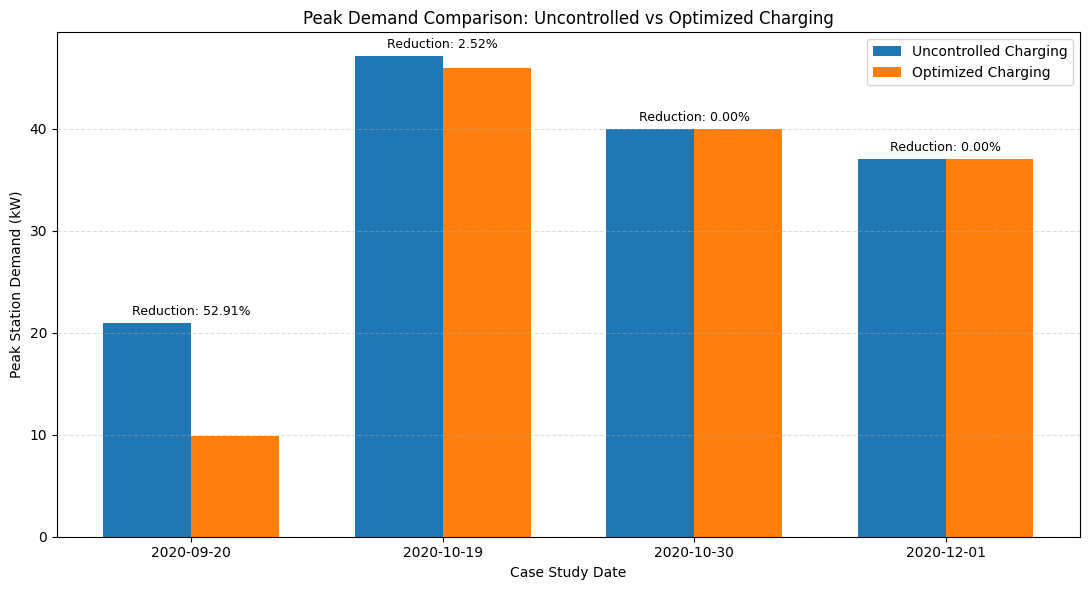

In [337]:
# Stage 22: Optimization performance visualization

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

optimization_results = pd.read_csv(
    r"C:\EV_Charging_Project\corrected_four_case_study_results.csv"
)

dates = optimization_results["date"].astype(str)
baseline = optimization_results["baseline_peak_kw"]
optimized = optimization_results["optimized_peak_kw"]
reduction = optimization_results["reduction_percentage"]

x = np.arange(len(dates))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width/2,
    baseline,
    width,
    label="Uncontrolled Charging"
)

ax.bar(
    x + width/2,
    optimized,
    width,
    label="Optimized Charging"
)

ax.set_xlabel("Case Study Date")
ax.set_ylabel("Peak Station Demand (kW)")
ax.set_title("Peak Demand Comparison: Uncontrolled vs Optimized Charging")

ax.set_xticks(x)
ax.set_xticklabels(dates)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

for i in range(len(dates)):
    ax.text(
        x[i],
        max(baseline.iloc[i], optimized.iloc[i]) + 0.8,
        f"Reduction: {reduction.iloc[i]:.2f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [338]:
# Stage 22: Overall optimization performance

optimization_results = pd.read_csv(
    r"C:\EV_Charging_Project\corrected_four_case_study_results.csv"
)

print("OVERALL OPTIMIZATION PERFORMANCE")

print("\nAverage peak reduction (%):",
      optimization_results["reduction_percentage"].mean())

print("Total baseline peak (kW):",
      optimization_results["baseline_peak_kw"].sum())

print("Total optimized peak (kW):",
      optimization_results["optimized_peak_kw"].sum())

print("Total peak reduction across case studies (kW):",
      optimization_results["reduction_kw"].sum())

print("\nBest performing case:")
display(
    optimization_results.loc[
        optimization_results["reduction_percentage"].idxmax()
    ]
)

OVERALL OPTIMIZATION PERFORMANCE

Average peak reduction (%): 13.85711638097338
Total baseline peak (kW): 145.02669556214832
Total optimized peak (kW): 132.75903814146872
Total peak reduction across case studies (kW): 12.267657420679601

Best performing case:


date                    2020-09-20
selected_evs                     6
other_evs                        2
intervals                      107
required_energy_kwh      90.660945
baseline_peak_kw         20.944645
optimized_peak_kw            9.863
reduction_kw             11.081645
reduction_percentage     52.909205
Name: 0, dtype: object

In [339]:
# Stage 23: Forecasting performance by case study

print("FORECASTING PERFORMANCE DATA")

display(
    pd.DataFrame({
        "date": [
            "2020-09-20",
            "2020-10-19",
            "2020-10-30",
            "2020-12-01"
        ],
        "forecast_MAE_kW": [
            0.7027, 2.4933, 5.5146, 2.9992
        ],
        "forecast_RMSE_kW": [
            1.5452, 7.1837, 10.4593, 8.2687
        ],
        "forecast_bias_kW": [
            -0.1774, 0.4773, 0.5410, 0.3902
        ]
    })
)

FORECASTING PERFORMANCE DATA


,date,forecast_MAE_kW,forecast_RMSE_kW,forecast_bias_kW
0,2020-09-20,0.7027,1.5452,-0.1774
1,2020-10-19,2.4933,7.1837,0.4773
2,2020-10-30,5.5146,10.4593,0.5410
3,2020-12-01,2.9992,8.2687,0.3902


In [340]:
# Stage 24: Integrated forecasting and optimization results

optimization_results = pd.read_csv(
    r"C:\EV_Charging_Project\corrected_four_case_study_results.csv"
)

forecast_case_results = pd.DataFrame({
    "date": [
        "2020-09-20",
        "2020-10-19",
        "2020-10-30",
        "2020-12-01"
    ],
    "forecast_MAE_kW": [0.7027, 2.4933, 5.5146, 2.9992],
    "forecast_RMSE_kW": [1.5452, 7.1837, 10.4593, 8.2687],
    "forecast_bias_kW": [-0.1774, 0.4773, 0.5410, 0.3902]
})

optimization_results["date"] = (
    optimization_results["date"].astype(str)
)

integrated_results = pd.merge(
    optimization_results,
    forecast_case_results,
    on="date",
    how="inner"
)

display(integrated_results)

integrated_results.to_csv(
    r"C:\EV_Charging_Project\final_forecasting_optimization_comparison.csv",
    index=False
)

print("\nIntegrated results saved successfully.")

,date,selected_evs,other_evs,intervals,required_energy_kwh,baseline_peak_kw,optimized_peak_kw,reduction_kw,reduction_percentage,forecast_MAE_kW,forecast_RMSE_kW,forecast_bias_kW
0,2020-09-20,6,2,107,90.660945,20.944645,9.863000,11.081645,52.909205,0.7027,1.5452,-0.1774
1,2020-10-19,5,5,101,38.891486,47.077796,45.891783,1.186012,2.519261,2.4933,7.1837,0.4773
2,2020-10-30,5,5,50,27.268697,39.983973,39.983973,0.000000,0.000000,5.5146,10.4593,0.5410
3,2020-12-01,7,7,90,28.807094,37.020282,37.020282,0.000000,0.000000,2.9992,8.2687,0.3902



Integrated results saved successfully.


In [341]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project folder
project_path = r"C:\EV_Charging_Project"

# Load reconstructed 15-minute station demand
df = pd.read_csv(
    project_path + r"\caltech_garage01_complete_15min_load.csv"
)

# Display column names and first five rows
print("Columns:", df.columns.tolist())
display(df.head())

print("Dataset shape:", df.shape)

Columns: ['timestamp', 'energy_kwh', 'average_power_kw', 'date', 'hour', 'day_of_week', 'month']


,timestamp,energy_kwh,average_power_kw,date,hour,day_of_week,month
0,2018-05-01 00:30:00+00:00,0.837569,3.350274,2018-05-01,0,1,5
1,2018-05-01 00:45:00+00:00,1.773271,7.093083,2018-05-01,0,1,5
2,2018-05-01 01:00:00+00:00,2.628674,10.514696,2018-05-01,1,1,5
3,2018-05-01 01:15:00+00:00,3.672413,14.689652,2018-05-01,1,1,5
4,2018-05-01 01:30:00+00:00,5.519586,22.078342,2018-05-01,1,1,5


Dataset shape: (90915, 7)


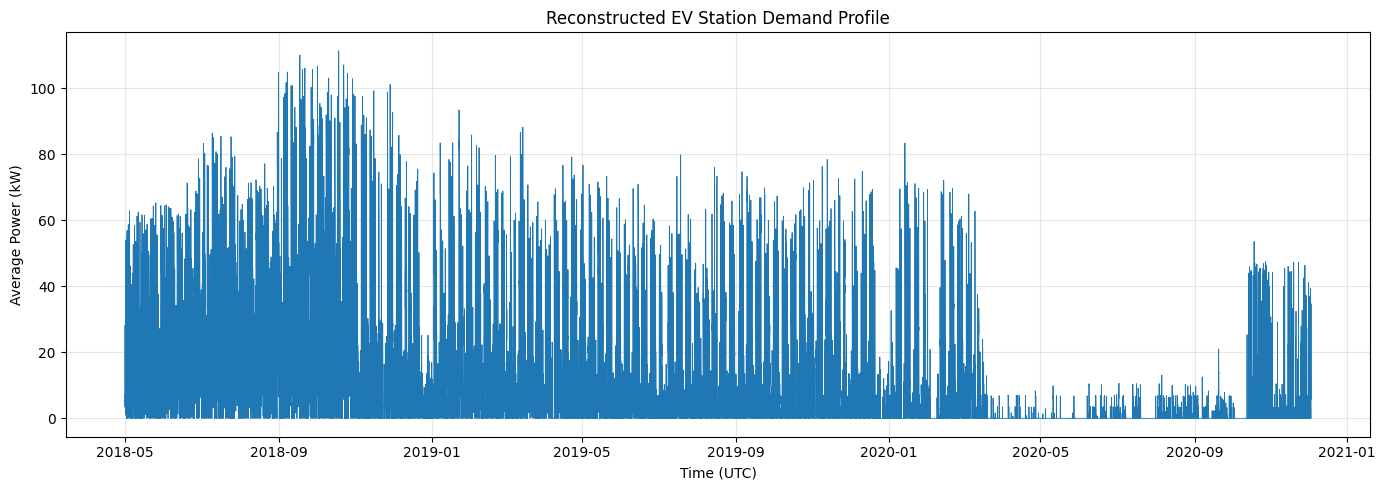

In [342]:
# FIGURE 3.5: Reconstructed EV Station Demand Profile

import pandas as pd
import matplotlib.pyplot as plt

df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)
df = df.sort_values('timestamp')

plt.figure(figsize=(14, 5))

plt.plot(
    df['timestamp'],
    df['average_power_kw'],
    linewidth=0.6
)

plt.title('Reconstructed EV Station Demand Profile')
plt.xlabel('Time (UTC)')
plt.ylabel('Average Power (kW)')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    project_path + r"\Figure_3_5_Station_Demand.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

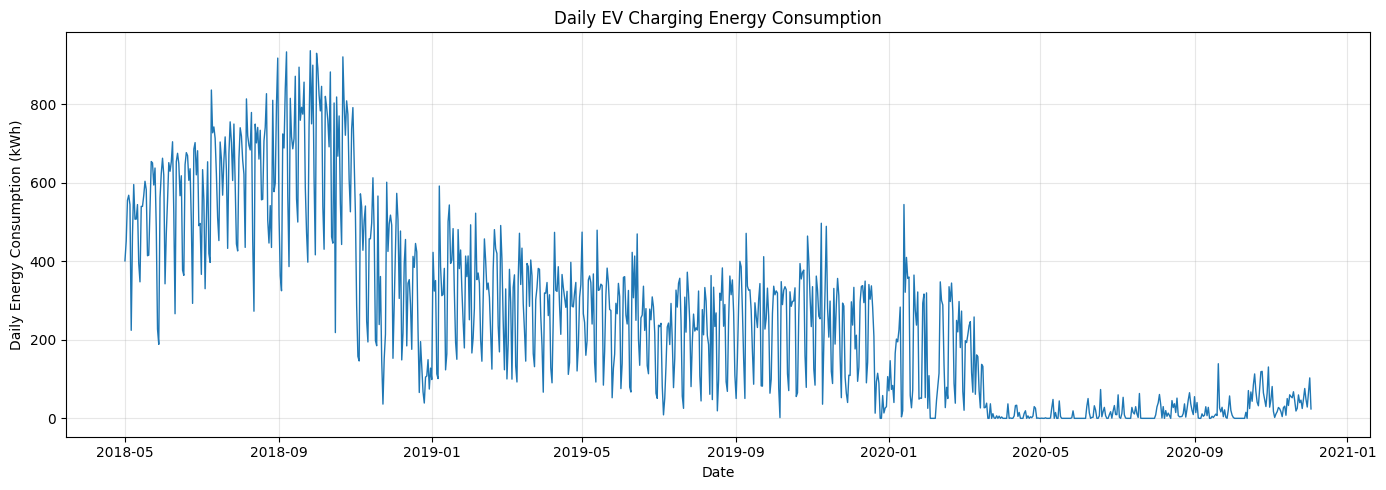

Average daily energy: 256.7577848851772 kWh
Maximum daily energy: 936.3940774305271 kWh


In [343]:
# FIGURE 3.6: Daily Energy Consumption

daily_energy = (
    df.groupby('date')['energy_kwh']
    .sum()
)

plt.figure(figsize=(14, 5))

plt.plot(
    pd.to_datetime(daily_energy.index),
    daily_energy.values,
    linewidth=1
)

plt.title('Daily EV Charging Energy Consumption')
plt.xlabel('Date')
plt.ylabel('Daily Energy Consumption (kWh)')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    project_path + r"\Figure_3_6_Daily_Energy.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Average daily energy:", daily_energy.mean(), "kWh")
print("Maximum daily energy:", daily_energy.max(), "kWh")

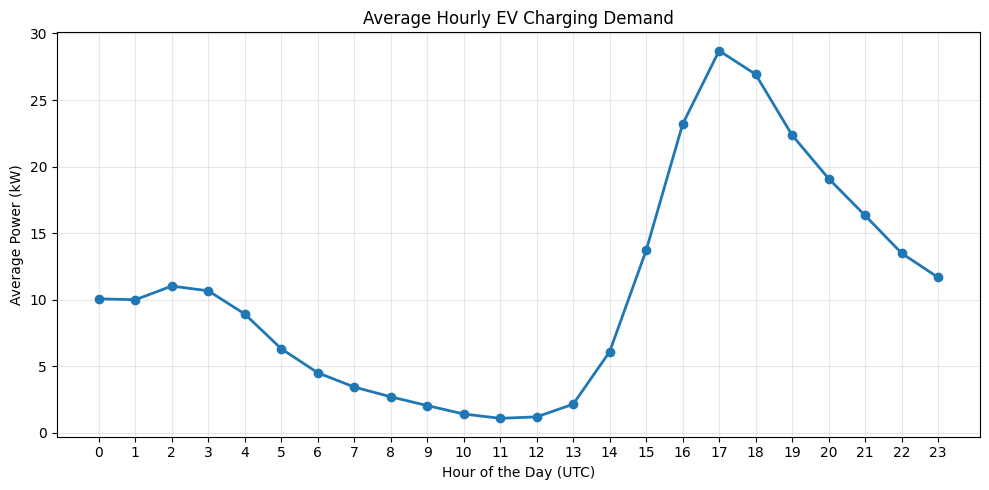

hour
0     10.060887
1      9.993170
2     11.020055
3     10.661922
4      8.916862
5      6.308244
6      4.504059
7      3.432667
8      2.698891
9      2.040801
10     1.407181
11     1.080522
12     1.191218
13     2.143561
14     6.090173
15    13.700443
16    23.185748
17    28.703874
18    26.931714
19    22.361306
20    19.098636
21    16.325282
22    13.494872
23    11.668874
Name: average_power_kw, dtype: float64
Highest demand hour: 17 UTC
Highest average demand: 28.703873672064834 kW


In [344]:
# FIGURE 3.7: Average Hourly Charging Demand

hourly_demand = (
    df.groupby('hour')['average_power_kw']
    .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_demand.index,
    hourly_demand.values,
    marker='o',
    linewidth=2
)

plt.title('Average Hourly EV Charging Demand')
plt.xlabel('Hour of the Day (UTC)')
plt.ylabel('Average Power (kW)')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    project_path + r"\Figure_3_7_Hourly_Demand.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print(hourly_demand)
print("Highest demand hour:", hourly_demand.idxmax(), "UTC")
print("Highest average demand:", hourly_demand.max(), "kW")

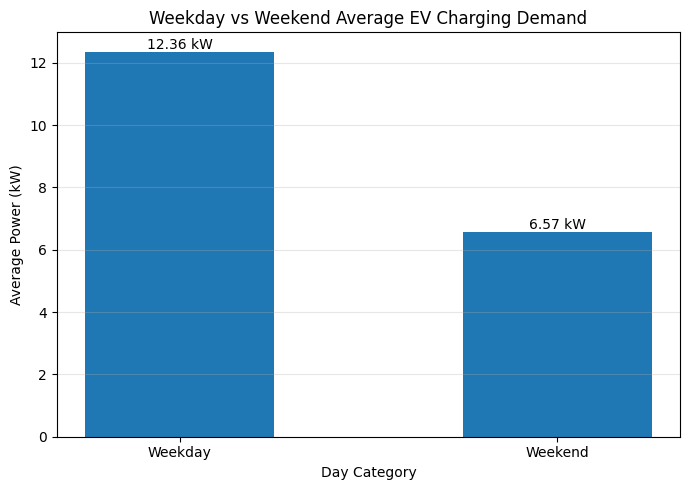

day_category
Weekday    12.361333
Weekend     6.566385
Name: average_power_kw, dtype: float64


In [345]:
# FIGURE 3.8: Weekday vs Weekend Demand

df['day_category'] = df['day_of_week'].apply(
    lambda x: 'Weekend' if x in [5, 6] else 'Weekday'
)

day_comparison = (
    df.groupby('day_category')['average_power_kw']
    .mean()
    .reindex(['Weekday', 'Weekend'])
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    day_comparison.index,
    day_comparison.values,
    width=0.5
)

plt.title('Weekday vs Weekend Average EV Charging Demand')
plt.xlabel('Day Category')
plt.ylabel('Average Power (kW)')
plt.grid(axis='y', alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{bar.get_height():.2f} kW',
        ha='center',
        va='bottom'
    )

plt.tight_layout()

plt.savefig(
    project_path + r"\Figure_3_8_Weekday_Weekend.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print(day_comparison)

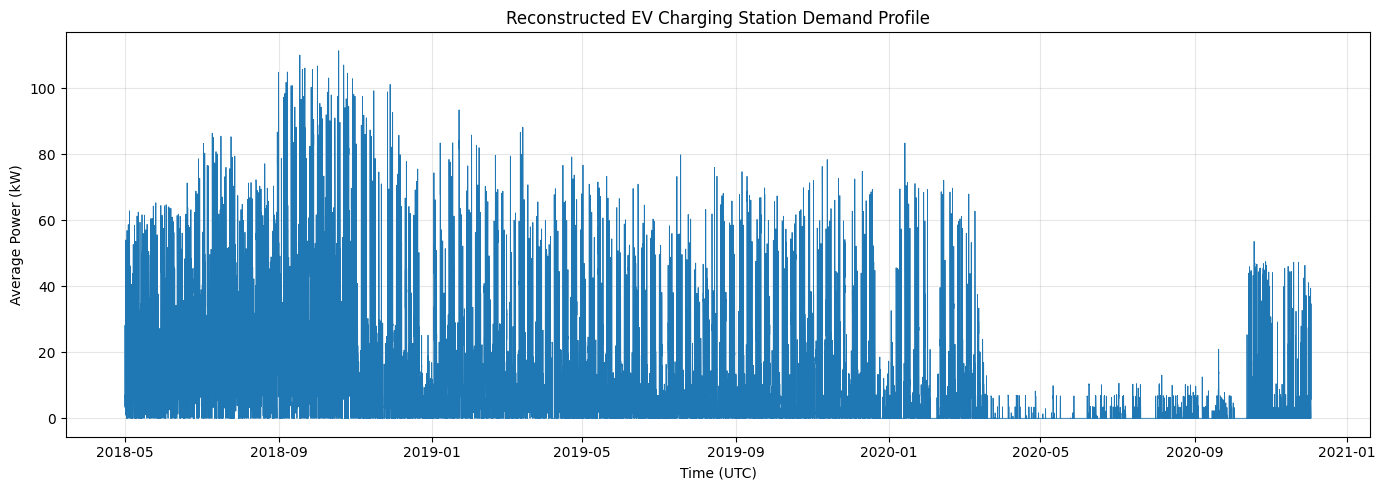

In [346]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv(project_path + r"\caltech_garage01_complete_15min_load.csv")

# Convert timestamp to UTC
df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)
df = df.sort_values('timestamp')

# Plot station demand
plt.figure(figsize=(14, 5))

plt.plot(
    df['timestamp'],
    df['average_power_kw'],
    linewidth=0.6
)

plt.title('Reconstructed EV Charging Station Demand Profile')
plt.xlabel('Time (UTC)')
plt.ylabel('Average Power (kW)')
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save high-resolution image
plt.savefig(
    project_path + r"\Figure_4_1_Station_Demand.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

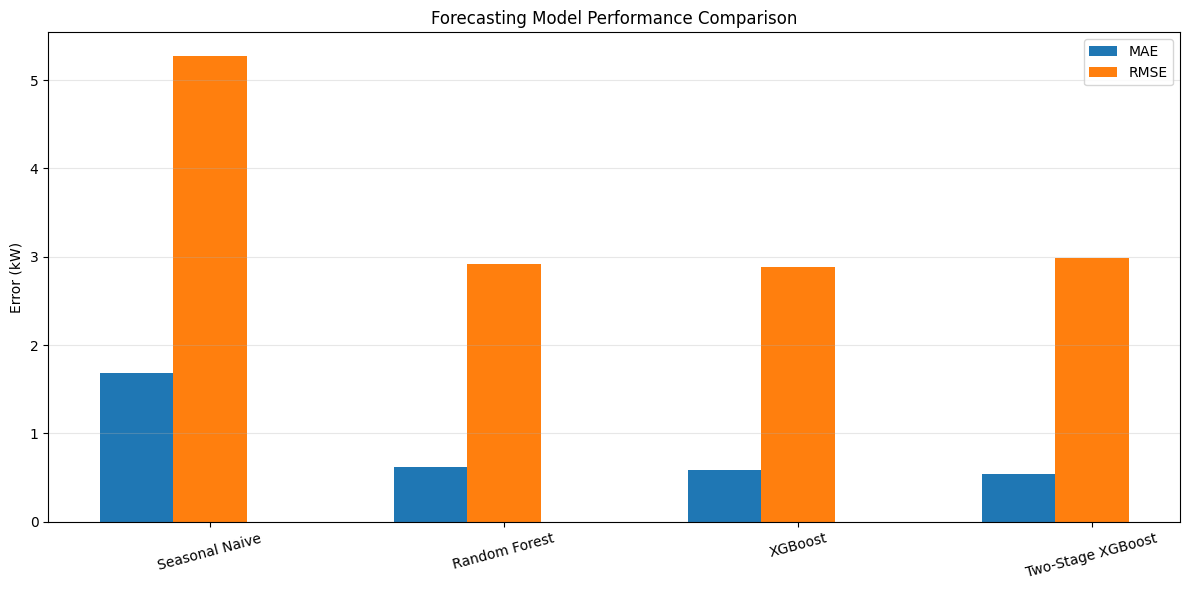

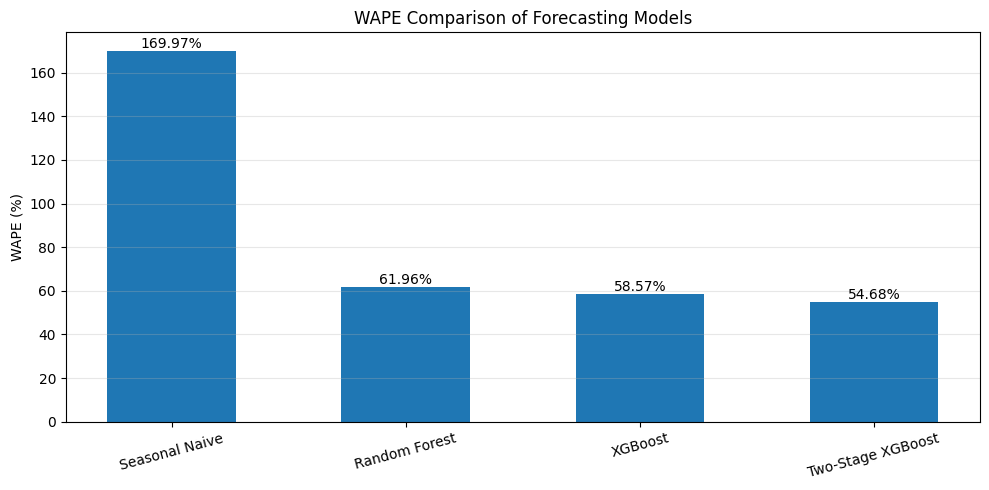

In [347]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Seasonal Naive', 'Random Forest',
          'XGBoost', 'Two-Stage XGBoost']

mae = [1.6870, 0.6150, 0.5813, 0.5427]
rmse = [5.2760, 2.9170, 2.8852, 2.9885]
wape = [169.97, 61.96, 58.57, 54.68]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(x - width, mae, width, label='MAE')
plt.bar(x, rmse, width, label='RMSE')

plt.xticks(x, models, rotation=15)
plt.ylabel('Error (kW)')
plt.title('Forecasting Model Performance Comparison')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(
    project_path + r"\Figure_4_2_Forecasting_Performance.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()

# Separate WAPE comparison because it has a different scale
plt.figure(figsize=(10, 5))
bars = plt.bar(models, wape, width=0.55)

plt.ylabel('WAPE (%)')
plt.title('WAPE Comparison of Forecasting Models')
plt.xticks(rotation=15)

for bar, value in zip(bars, wape):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height(), f'{value:.2f}%',
             ha='center', va='bottom')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(
    project_path + r"\Figure_4_2_WAPE_Comparison.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()

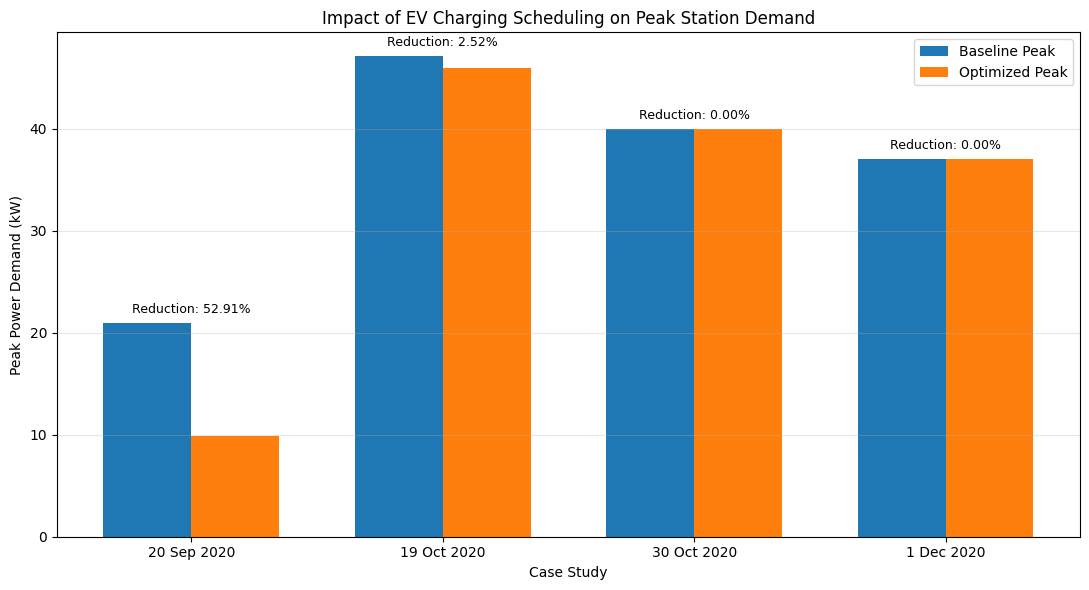

In [348]:
import matplotlib.pyplot as plt
import numpy as np

cases = ['20 Sep 2020', '19 Oct 2020',
         '30 Oct 2020', '1 Dec 2020']

baseline = [20.9446, 47.0778, 39.9840, 37.0203]
optimized = [9.8630, 45.8918, 39.9840, 37.0203]

x = np.arange(len(cases))
width = 0.35

plt.figure(figsize=(11, 6))

bars1 = plt.bar(x - width/2, baseline, width, label='Baseline Peak')
bars2 = plt.bar(x + width/2, optimized, width, label='Optimized Peak')

plt.xlabel('Case Study')
plt.ylabel('Peak Power Demand (kW)')
plt.title('Impact of EV Charging Scheduling on Peak Station Demand')

plt.xticks(x, cases)
plt.legend()
plt.grid(axis='y', alpha=0.3)

# Add reduction percentages
reductions = [52.91, 2.52, 0.00, 0.00]

for i, reduction in enumerate(reductions):
    plt.text(i, max(baseline[i], optimized[i]) + 1,
             f'Reduction: {reduction:.2f}%',
             ha='center', fontsize=9)

plt.tight_layout()

plt.savefig(
    project_path + r"\Figure_4_4_Optimization_Comparison.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

NameError: name 'project_path' is not defined

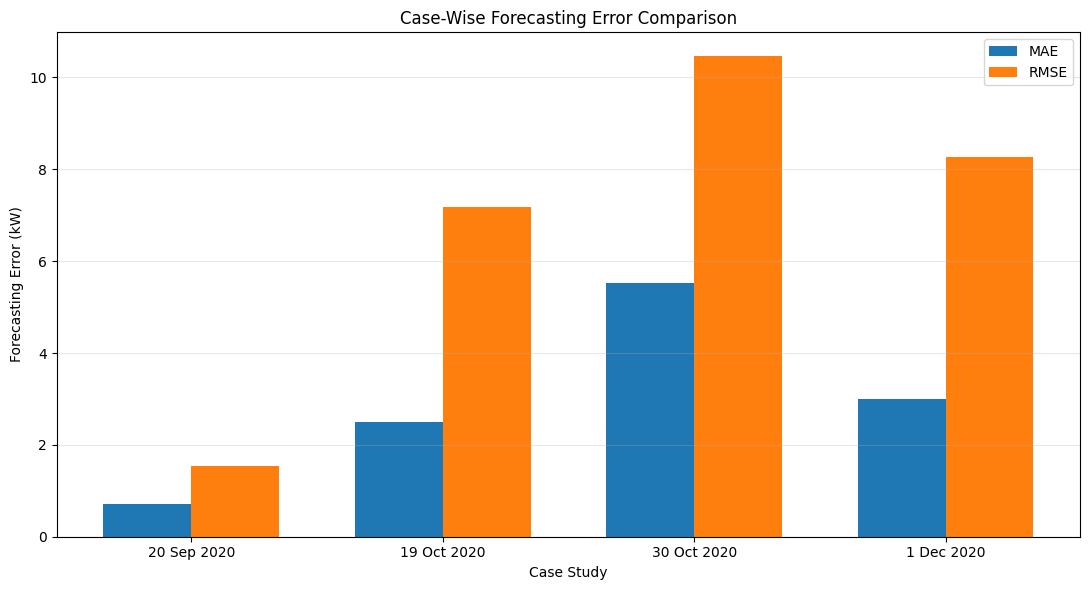

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Case-wise forecasting results
cases = ['20 Sep 2020', '19 Oct 2020',
         '30 Oct 2020', '1 Dec 2020']

mae = [0.7027, 2.4933, 5.5146, 2.9992]
rmse = [1.5452, 7.1837, 10.4593, 8.2687]

x = np.arange(len(cases))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(x - width/2, mae, width, label='MAE')
plt.bar(x + width/2, rmse, width, label='RMSE')

plt.xlabel('Case Study')
plt.ylabel('Forecasting Error (kW)')
plt.title('Case-Wise Forecasting Error Comparison')

plt.xticks(x, cases)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig(
    project_path + r"\Figure_4_5_Case_Wise_Forecasting_Error.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [3]:
# Check available forecasting models and datasets

for name, obj in globals().copy().items():
    if any(word in name.lower() for word in
           ['model', 'classifier', 'regressor', 'forecast', 'df']):
        if hasattr(obj, 'predict'):
            print(name, "-> Trained model")
        elif isinstance(obj, pd.DataFrame):
            print(name, "-> DataFrame", obj.shape)

In [4]:
print("Checking notebook variables...")

print("\nAvailable trained models:")
for name, obj in globals().copy().items():
    if hasattr(obj, "predict"):
        print(name, type(obj))

print("\nAvailable DataFrames:")
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

Checking notebook variables...

Available trained models:

Available DataFrames:


NameError: name 'pd' is not defined

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [6]:
print("AVAILABLE TRAINED MODELS")

for name, obj in globals().copy().items():
    if hasattr(obj, "predict"):
        print(name, type(obj))

print("\nAVAILABLE DATAFRAMES")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

AVAILABLE TRAINED MODELS

AVAILABLE DATAFRAMES


In [7]:
import os

project_path = r"C:\EV_Charging_Project"

print("PROJECT FOLDER FILES:\n")

for file in os.listdir(project_path):
    print(file)

PROJECT FOLDER FILES:

.ipynb_checkpoints
ACN-Data-Static
caltech_garage01_15min_station_load.csv
caltech_garage01_clean_15min_load.csv
caltech_garage01_clean_sessions.csv
caltech_garage01_complete_15min_load.csv
caltech_garage01_complete_energy_audit.csv
caltech_garage01_energy_quality.csv
caltech_garage01_final_energy_reconciliation.csv
caltech_garage01_final_sessions.csv
caltech_garage01_full_energy_audit.csv
caltech_garage01_reconstructed_session_summary.csv
caltech_garage01_sessions.csv
caltech_garage01_session_reconstructed_profile.csv
corrected_four_case_study_results.csv
daily_energy_summary.csv
dec1_background_validation_metrics.csv
dec1_validated_demand_components.csv
EV_forecasting_dataset.csv
EV_forecasting_features.csv
EV_Load_Demand_Analysis.ipynb.ipynb
Figure_3_5_Station_Demand.png
Figure_3_6_Daily_Energy.png
Figure_3_7_Hourly_Demand.png
Figure_3_8_Weekday_Weekend.png
Figure_4_1_Station_Demand.png
Figure_4_2_Forecasting_Performance.png
Figure_4_2_WAPE_Comparison.png
Figu

In [8]:
import json

notebook_path = project_path + r"\EV_Load_Demand_Analysis.ipynb.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "XGBClassifier",
    "XGBRegressor",
    "RandomForestRegressor",
    "classifier.fit",
    "regressor.fit",
    "model.fit",
    "predict"
]

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if any(word in source for word in keywords):
            print(f"\n{'='*60}")
            print(f"CELL NUMBER: {i}")
            print(source[:3000])


CELL NUMBER: 218

# RANDOM FOREST REGRESSION

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Initialize model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")

# Train
rf_model.fit(X_train, y_train)

print("Training completed.")

# Predict
y_pred_rf = rf_model.predict(X_test)

# Evaluation
rf_mae = mean_absolute_error(y_test, y_pred_rf)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

rf_wape = (
    np.sum(np.abs(y_test.to_numpy() - y_pred_rf)) /
    np.sum(np.abs(y_test.to_numpy()))
) * 100

print("\n========== RANDOM FOREST RESULTS ==========")
print("MAE:", round(rf_mae, 4), "kW")
print("RMSE:", round(rf_rmse, 4), "kW")
print("WAPE:", round(rf_wape, 2), "%")

# Compare with baseline
resu